# Task 4 – Erneuerbare Energien im CIGRE-Mittelspannungsnetz und im unterlagerten Ortsnetz

Gesamtnotebook der Abgabe zu Arbeitsauftrag W4. Es enthält alle Teil-Notebooks aus dem Ordner `notebooks/` in der Reihenfolge der Bearbeitung und ist vom Anfang bis zum Ende ausführbar. Die Module liegen in `src/`, die Daten in `data/`. Zeitreihen werden in `simulations/` gespeichert und bei einem erneuten Durchlauf geladen, solange sich Netz, Einstellungen und Daten nicht ändern. Die Teil-Notebooks lassen sich auch einzeln in derselben Reihenfolge ausführen.

Die Quellenangaben in eckigen Klammern beziehen sich auf das zentrale Quellenverzeichnis am Ende.

## Inhalt

0. [Task 4 – Datengrundlage](#teil-0) – `Task4-Datengrundlage.ipynb`
1. [Task 4 – Teil 1: Baseline und Modellverständnis](#teil-1) – `Task4-1_Baseline.ipynb`
2. [Task 4 – Teil 2: Unterlagertes Niederspannungs-Ortsnetz](#teil-2) – `Task4-2_Ortsnetz.ipynb`
3. [Task 4 – Teil 3: Spannungsband, Auslegung des Ortsnetzes und Schalterstellungen](#teil-3) – `Task4-3_Ortsnetz_Auslegung.ipynb`
4. [Task 4 – Teil 3b: Spannungsregelung](#teil-4) – `Task4-3b_Regelung.ipynb`
5. [Task 4 – Teil 4a: Erneuerbare Energien – Anschluss von Windpark und PV-Anlage](#teil-5) – `Task4-4a_Erzeugung_Anschluss.ipynb`
6. [Task 4 – Teil 4b: Erneuerbare-Energien-Szenarien einzeln und kombiniert](#teil-6) – `Task4-4b_Szenarien.ipynb`
7. [Task 4 – Teil 5: Lastflussumkehr](#teil-7) – `Task4-5_Lastflussumkehr.ipynb`
8. [Task 4 – Teil 6: Line 3-8 – Engpass und Kapazitätserhöhung](#teil-8) – `Task4-6_Leitung_3-8.ipynb`
9. [Task 4 – Teil 7: Methodik, Darstellung und Interpretation](#teil-9) – `Task4-7_Methodik.ipynb`
10. [Task 4 – Teil 8 und 9: Leitfragen, Ausblick und Fazit](#teil-10) – `Task4-8_Leitfragen_Ausblick_Fazit.ipynb`
11. [Quellenverzeichnis](#quellen)

<a id="teil-0"></a>

---

# Task 4 – Datengrundlage

**Ziel:** Beschreibung aller Eingangsdaten für Task 4: BDEW-Standardlastprofile (Haushalt, Gewerbe, Landwirtschaft), Windenergieanlage, PV-Modul, Wetterdaten, die Erzeugungsanlagen der Szenarien (Windpark, PV-Freiflächenanlage) und die Haushalte mit PV-Anlage und Batteriespeicher im Ortsnetz. Am Ende steht das **zentrale Quellenverzeichnis**, auf das sich alle Notebooks von Task 4 beziehen.

**Aufbau des Notebooks:**

1. Daten laden: Lastprofile, Windenergieanlage, PV-Anlage, Wetterdaten, Erzeugungsanlagen, Haushalte mit PV und Speicher
2. Netzdaten (Verweis auf Teil 1 und Teil 2)
3. Quellenverzeichnis

## Importe

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

TASK4 = Path("..")                     # Ordner task4
import profiles as pr
import weather as wt
from profiles import Lastprofil, Month, DayType, Season

import plots as plots

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 20 unterscheidbare Farben, damit alle 15 Busse in einem Diagramm unterscheidbar bleiben
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

Module im Ordner `task4` (Beschreibung siehe `README.md`):

- `profiles.py`: Einlesen und Aufbereiten der BDEW-Standardlastprofile 2025 (Wochen bilden, Dynamisierung, Skalierung), übernommen aus Task 2 und erweitert
- `weather.py`: Wetterdaten (Open-Meteo) und Umrechnung in PV- und Windleistung über die Kennlinien, übernommen aus Task 2
- `plots.py`: Diagramme mit einheitlicher Zeitachse (Uhrzeit im 6-Stunden-Takt, Tageswechsel als senkrechte Linie, Datum über jedem Tag) Komponentenübersicht des Netzes und `table()` für formatierte Tabellen (farbig, wenn `jinja2` installiert ist)
- `simulation.py`, `elements.py`, `timeseries.py`, `diagrams.py`: Simulationssoftware für die saisonale Lastflussrechnung (Abschnitt 3.2)

## 1 Daten laden

Alle Eingangsdaten werden einmal zu Beginn geladen und stehen danach in Variablen zur Verfügung:

| Variable | Datei | Inhalt |
|---|---|---|
| `PROFILES` | `data/BDEW_H25_Haushalte.csv`, `data/BDEW_G25_Gewerbe.csv`, `data/BDEW_L25_Landwirtschaft.csv` | BDEW-Standardlastprofile 2025: H25 (Haushalt), G25 (Gewerbe), L25 (Landwirtschaft), je 12 Monate × 3 Tagtypen × 96 Viertelstunden |
| `WEATHER` | `data/weather_weeks_2025.csv` | je Monat eine typische Woche (stündlich) mit Wetter und berechneter PV- und Windleistung |

Die Wetterdaten wurden in Task 2 einmalig über die Open-Meteo-API abgerufen und als CSV gespeichert; das Notebook benötigt deshalb keinen Internetzugang.

In [2]:
DATA = TASK4 / "data"
WEATHER_FILE = DATA / "weather_weeks_2025.csv"

PROFILES = pr.load_profiles(DATA)
WEATHER = wt.load_weather_weeks(WEATHER_FILE)                  # {Month: DataFrame mit 168 Stunden}
WEEK_STARTS = {m: df.index[0] for m, df in WEATHER.items()}     # Montag jeder Wetterwoche


for profil, df in PROFILES.items():
    print(f"{profil.label}: {df.shape[0]} Viertelstunden × {df.shape[1]} Spalten (Monat, Tagtyp)")
print(f"Wetter:     {len(WEATHER)} Wochen × {len(next(iter(WEATHER.values())))} Stunden")

H25 – Haushalt: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
G25 – Gewerbe allgemein: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
L25 – Landwirtschaft: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
Wetter:     12 Wochen × 168 Stunden


### 1.1 Lastprofile (BDEW H25, G25, L25)

#### Haushalte (H25)

**Herkunft:** Das Standardlastprofil H25 ist der Nachfolger des Haushaltsprofils H0 aus dem Jahr 1999. Es wurde im Auftrag des BDEW von der BTU EVU Beratung GmbH aus Abrechnungsdaten von 62 Verteilnetzbetreibern der Jahre 2018 und 2019 erstellt [1, S. 3]. Weil zu dieser Zeit bereits PV-Anlagen in Betrieb waren, enthält das Profil einen moderaten PV-Eigenverbrauch [1, S. 3]. Die Daten stammen aus der BDEW-Veröffentlichung der repräsentativen Profile 2025 [2].

**Aufbau der Datei:** 12 Monate × 3 Tagtypen (WT = Werktag, SA = Samstag, FT = Sonn- und Feiertag) mit je 96 Viertelstundenwerten. Die Werte sind Energiemengen in kWh je Viertelstunde, normiert auf einen Jahresverbrauch von 1 Mio. kWh [1, S. 3].

**Aufbereitung:**

1. *Woche bilden:* Montag bis Freitag erhalten den Tagtyp WT, Samstag SA, Sonntag FT. Wochen mit gesetzlichem Feiertag (NRW) werden bei der Auswahl der Wochen ausgeschlossen, damit die Annahme „fünf Werktage“ gilt.
2. *Leistung:* Die Energie einer Viertelstunde wird in die mittlere Leistung umgerechnet: P = E / 0,25 h = 4 · E.
3. *Dynamisierung:* H25 ist „entdynamisiert“; beim Ausrollen ist die Dynamisierungsfunktion anzuwenden [1, S. 3–4]. Sie bildet den Jahresgang des Verbrauchs ab (im Winter höher, im Sommer niedriger):

   F(t) = −3,92·10⁻¹⁰·t⁴ + 3,2·10⁻⁷·t³ − 7,02·10⁻⁵·t² + 2,1·10⁻³·t + 1,24 &nbsp;&nbsp; (t = Tag des Jahres) [3]

   Der Faktor wird auf vier Nachkommastellen gerundet [1, S. 4] und liegt zwischen etwa 0,79 (Juli/August) und 1,26 (Ende Dezember).
4. *Skalierung:* P_Haushalt = P_norm · F(t) · W_a / 1 000 000 kWh mit dem Jahresverbrauch W_a des Haushalts.
5. *Stundenwerte:* Mittelwert der vier Viertelstundenleistungen einer Stunde.

**Vorzeichen und Einheiten:** Die Last wird im Verbraucherzählpfeilsystem angegeben (Bezug positiv), in pandapower in MW (`unit="MW"`). Die Blindleistung ist im Profil nicht enthalten und wird bei der Einbindung ins Netz über einen Leistungsfaktor festgelegt.

#### Gewerbe (G25)

**Herkunft:** G25 („Gewerbe allgemein“) ist das Standardlastprofil für Gewerbekunden aus derselben BDEW-Veröffentlichung 2025 wie H25 [2]. Es ersetzt das frühere Profil G0 und beschreibt einen durchschnittlichen Gewerbebetrieb ohne ausgeprägte Branchencharakteristik.

**Aufbau:** wie H25 – 12 Monate × 3 Tagtypen (WT, SA, FT) mit je 96 Viertelstundenwerten in kWh, normiert auf 1 Mio. kWh Jahresverbrauch.

**Unterschied zu H25:** Für G25 ist die Dynamisierungsfunktion **nicht** anzuwenden (Hinweis im Dateikopf und [1]). Die Aufbereitung beschränkt sich daher auf Wochenbildung, Umrechnung in Leistung (P = 4 · E), Skalierung auf den Jahresverbrauch und Mittelung auf Stundenwerte.

**Verwendung:** Im CIGRE-Netz gibt es Wohngebietslasten (R, *residential*) und Gewerbe-/Industrielasten (CI, *commercial/industrial*). Für die zeitliche Variation der R-Lasten wird H25, für die CI-Lasten G25 verwendet.

#### Landwirtschaft (L25)

**Herkunft:** L25 ist das Standardlastprofil für landwirtschaftliche Betriebe aus der BDEW-Veröffentlichung 2025 [1], [2]. Weil keine spezifischen Messzeitreihen vorlagen, beruht es auf dem bisherigen VDEW-Profil L0 und wurde auf die neue Form mit 12 Monaten gebracht. Es wird ein einziges Profil für alle Landwirtschaftsbetriebe bereitgestellt [1, S. 4].

**Aufbau und Aufbereitung:** wie G25 – 12 Monate × 3 Tagtypen mit je 96 Viertelstundenwerten, normiert auf 1 Mio. kWh Jahresverbrauch [1, S. 3]. L25 enthält **keine** Dynamisierung [1, S. 4]; die Aufbereitung entspricht daher G25.

**Hinweis zur Datei:** Die CSV-Datei enthält am Zeilenende leere Spalten; beim Einlesen werden nur die Spalten der zwölf Monate und drei Tagtypen übernommen.

**Verwendung:** In den CIGRE-Netzen gibt es keine Landwirtschaftslasten. Das Profil steht in der Simulationssoftware als `Profile.LANDWIRTSCHAFT` zur Verfügung, wird in Task 4 aber nicht verwendet.

**Darstellung:** Für jeden Monat werden die Profile für eine Woche in Stundenwerten gezeigt, alle bezogen auf denselben Jahresverbrauch von 1 Mio. kWh (H25 dynamisiert, G25 und L25 ohne Dynamisierung). Die Woche liegt auf denselben Kalendertagen wie die typische Wetterwoche des Monats (Abschnitt 1.4), sodass Last und Erzeugung später direkt kombiniert werden können.

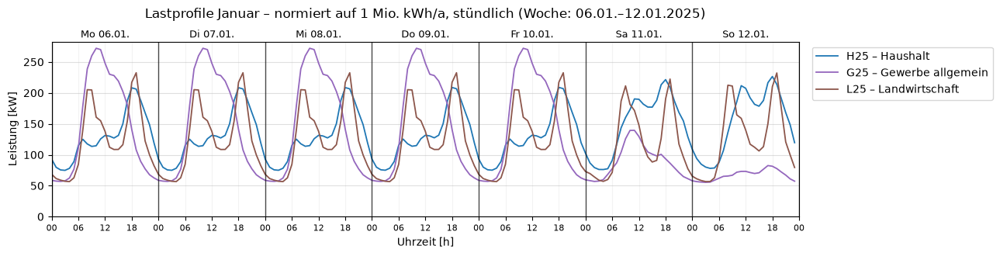

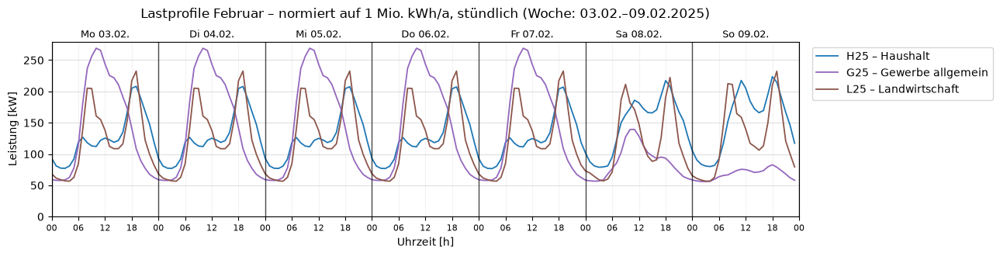

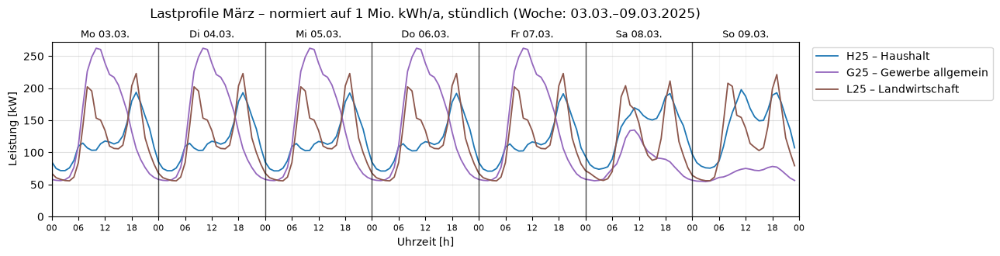

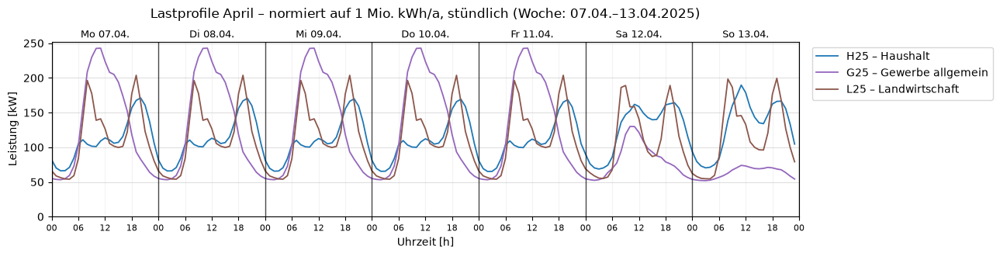

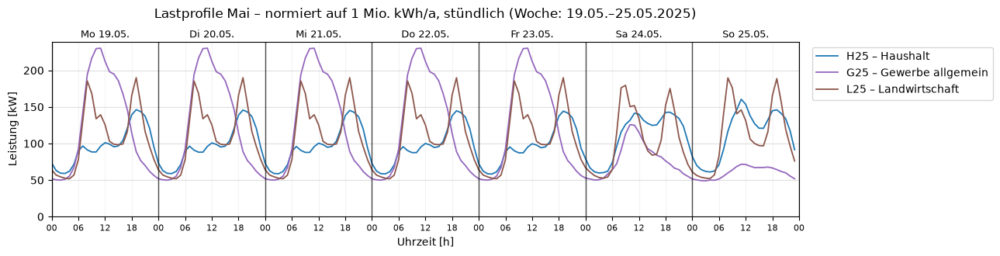

...

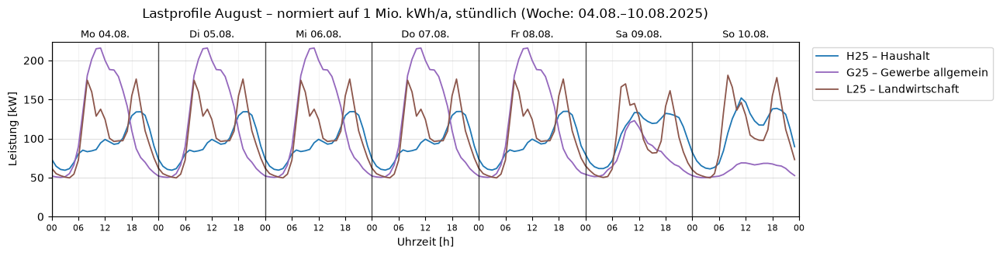

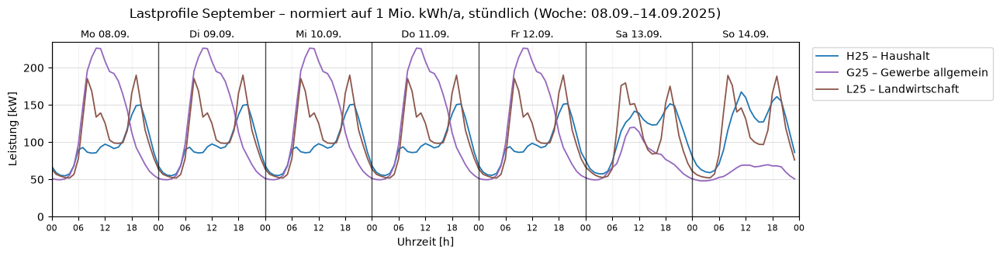

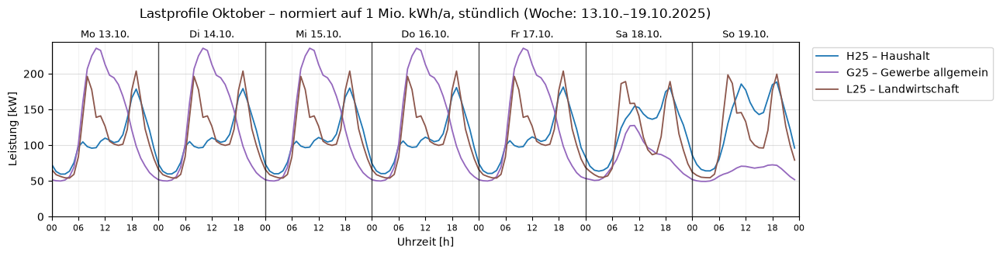

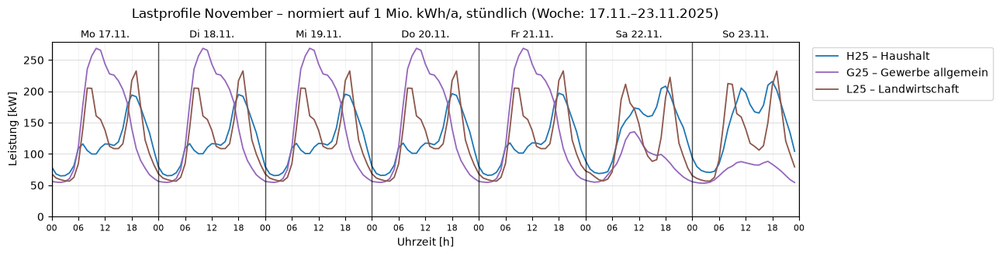

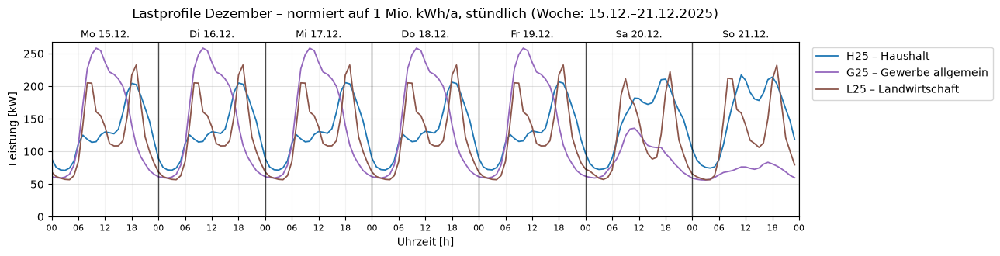

In [3]:
LOAD_PROFILES = [Lastprofil.HAUSHALT, Lastprofil.GEWERBE, Lastprofil.LANDWIRTSCHAFT]

for month in Month:
    weeks = {p.label: pr.build_week(PROFILES, p, month, annual_kwh=pr.NORM_KWH, unit="kW",
                                    start=WEEK_STARTS[month], resolution="1h")
             for p in LOAD_PROFILES}
    first = next(iter(weeks.values()))
    plots.plot_load_week(weeks, f"Lastprofile {month.label} – normiert auf 1 Mio. kWh/a, stündlich "
                                f"(Woche: {first.index[0]:%d.%m.}–{first.index[-1]:%d.%m.%Y})")
    plt.show()

**Wochenenergie je Monat** (alle Profile normiert auf 1 Mio. kWh/a; ein Jahr hat 52,1 Wochen, im Mittel also etwa 19 200 kWh je Woche):

In [4]:
ALLE = [Lastprofil.HAUSHALT, Lastprofil.GEWERBE, Lastprofil.LANDWIRTSCHAFT]
energy = pd.DataFrame({
    p.label: [pr.build_week(PROFILES, p, m, start=WEEK_STARTS[m], resolution="1h").sum() for m in Month]
    for p in ALLE
}, index=[m.label for m in Month])
energy["G25/H25"] = energy.iloc[:, 1] / energy.iloc[:, 0]
energy["L25/H25"] = energy.iloc[:, 2] / energy.iloc[:, 0]
energy.round(2)

,H25 – Haushalt,G25 – Gewerbe allgemein,L25 – Landwirtschaft,G25/H25,L25/H25
Januar,22719.75,21518.05,20782.75,0.95,0.91
Februar,22299.51,21289.32,20782.75,0.95,0.93
März,20474.20,20684.52,20215.44,1.01,0.99
April,19315.88,19364.30,19080.82,1.00,0.99
Mai,16945.86,18328.34,18253.72,1.08,1.08
Juni,16707.49,18356.55,17426.28,1.10,1.04
Juli,16655.36,17388.90,17426.28,1.04,1.05
August,16270.44,17708.41,17426.28,1.09,1.07
September,16721.62,18225.32,18253.72,1.09,1.09
Oktober,18761.87,18857.81,19080.82,1.01,1.02


**Vergleich der Profile:**

- **H25 (Haushalt):** Morgen- und ausgeprägte Abendspitze (ca. 18–20 Uhr), am Wochenende höherer Verbrauch über den Tag. Durch die Dynamisierung ist der Verbrauch im Winter deutlich höher als im Sommer.
- **G25 (Gewerbe):** hohe Leistung an Werktagen während der Betriebszeiten (etwa 7–17 Uhr, Maximum vormittags), deutlich niedrigere Leistung nachts, samstags und vor allem sonntags. Der Jahresgang ist schwächer, weil keine Dynamisierung angewendet wird.
- **L25 (Landwirtschaft):** Tagesgang mit Morgenspitze gegen 8–9 Uhr und Abendspitze gegen 19 Uhr, kaum Unterschied zwischen Werktag, Samstag und Sonntag; der Jahresgang ist ähnlich schwach wie bei G25 (Wochenenergie 0,91 bis 1,09 × H25).
- Die Lastspitzen fallen zeitlich auseinander: Gewerbe tagsüber, Haushalte abends. Gewerbelasten fallen damit zeitlich besser mit der PV-Erzeugung zusammen als Haushaltslasten.

**Skalierung über die Jahreshöchstleistung:** In der Simulationssoftware wird jede Last über ihre höchste Stundenleistung im Jahr skaliert (Task 3). Die Tabelle zeigt die Jahreshöchstleistung je 1 Mio. kWh und den Jahresverbrauch, der sich bei gleicher Höchstleistung ergibt (bezogen auf H25).

In [5]:
import timeseries as tsm
from elements import Profile

spitzen = pd.DataFrame({"Jahreshöchstleistung [kW je 1 Mio. kWh]": {
    p.value: tsm.annual_peak_mw_per_kwh(p) * 1e9 for p in
    [Profile.HAUSHALT, Profile.GEWERBE, Profile.LANDWIRTSCHAFT]}})
spitzen["Jahresverbrauch bei gleicher Höchstleistung (H25 = 1)"] = (
    spitzen.iloc[0, 0] / spitzen.iloc[:, 0])
spitzen.round(2)

,Jahreshöchstleistung [kW je 1 Mio. kWh],Jahresverbrauch bei gleicher Höchstleistung (H25 = 1)
Haushalt (BDEW H25),226.64,1.00
Gewerbe (BDEW G25),272.12,0.83
Landwirtschaft (BDEW L25),232.52,0.97


### 1.2 Windenergieanlage (Vestas V90-2.0 MW)

**Anlagendaten** [7]: Nennleistung 2,0 MW, Rotordurchmesser 90 m (überstrichene Fläche A ≈ 6 362 m²), Nabenhöhen 80 / 95 / 105 m, Einschaltgeschwindigkeit 4 m/s, Nenngeschwindigkeit 13 m/s, Abschaltgeschwindigkeit 25 m/s. Verwendet wird eine Nabenhöhe von 105 m.

**Physikalischer Hintergrund:** Die im Wind enthaltene Leistung, die durch die Rotorfläche strömt, ist

P_Wind = ½ · ρ · A · v³

mit der Luftdichte ρ ≈ 1,225 kg/m³. Eine Windenergieanlage kann davon nur den Anteil c_p (Leistungsbeiwert) entnehmen; theoretisch höchstens c_p,Betz = 16/27 ≈ 0,59 [9]. Real erreichte Werte und die Regelung der Anlage sind in der **Leistungskennlinie** P(v) zusammengefasst, die der Hersteller für eine Standard-Luftdichte angibt. Sie hat vier Bereiche [9]:

| Bereich | Windgeschwindigkeit | Leistung |
|---|---|---|
| Stillstand | v < v_ein | 0 |
| Teillast | v_ein ≤ v < v_Nenn | steigt etwa mit v³ |
| Volllast | v_Nenn ≤ v < v_ab | Nennleistung (Pitch-Regelung begrenzt die Leistung) |
| Sturmabschaltung | v ≥ v_ab = 25 m/s | 0 |

**Kennlinie:** Die Stützstellen (Schrittweite 0,5 m/s) stammen aus der Turbinendatenbank der Open Energy Database (OEDB), die mit der Python-Bibliothek *windpowerlib* ausgeliefert wird; als Quelle ist dort die oben genannte Herstellerangabe auf wind-turbine-models.com eingetragen [8]. Zwischen den Stützstellen wird linear interpoliert. Die Tabelle beginnt bereits bei 3,5 m/s mit 42 kW, während [7] eine Einschaltgeschwindigkeit von 4 m/s nennt. Oberhalb von 12,5 m/s wird die Nennleistung von 2 000 kW angesetzt.

**Höhenumrechnung:** Die Windgeschwindigkeit nimmt mit der Höhe zu. Die API liefert sie in 100 m Höhe; auf die Nabenhöhe h wird mit dem Potenzgesetz umgerechnet [9]:

v_Nabe = v_100 · (h / 100 m)^α, &nbsp; α = 1/7

Bei h = 105 m ergibt sich ein Faktor von 1,007. Der Einfluss ist also gering.

**Vereinfachungen:** keine Korrektur der Luftdichte (Temperatur, Höhe), keine Verfügbarkeitsverluste, keine Abschattung durch andere Anlagen, Stundenwerte statt Böen.

**Normierung:** Neben der Leistung in kW wird die Leistung bezogen auf die Nennleistung gespeichert (`wind_pu`). Damit lässt sich die Zeitreihe auch auf andere Anlagengrößen übertragen. Bei der Einbindung ins Netz kann die Zeitreihe so auf die jeweilige Anlagengröße skaliert werden.

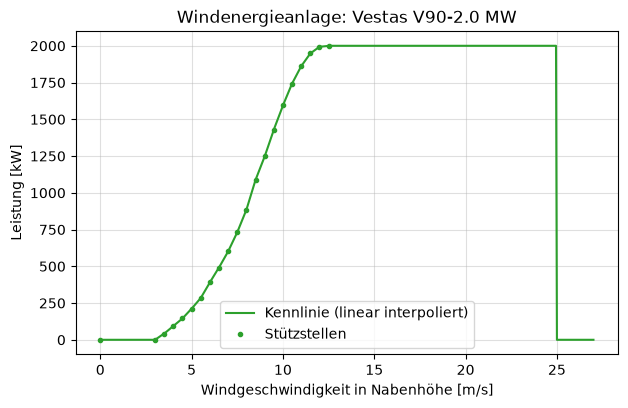

In [6]:
wt.plot_wind_curve()
plt.show()

### 1.3 PV-Anlage (Trina Solar Vertex S+ 460 W)

**Moduldaten:** Trina Solar Vertex S+ TSM-NEG9RC.27, bifaziales Glas-Glas-Modul (n-Typ, i-TOPCon), 144 Halbzellen, 1762 × 1134 mm (2,0 m²).

| Kenngröße | Wert | Quelle |
|---|---|---|
| Nennleistung P_STC (1000 W/m², 25 °C Zelltemperatur) | 460 W | [10] |
| Modulwirkungsgrad | 23,0 % | [10] |
| Temperaturkoeffizient von P_max (γ) | −0,29 %/K | [11] |
| NOCT (800 W/m², 20 °C Luft, 1 m/s Wind) | 43 °C | [11] |

Das Datenblatt [11] listet die Leistungsklassen 425–450 W; die Temperaturkennwerte gelten für die gesamte Modellfamilie und werden für die 460-W-Klasse übernommen.

**Umrechnung Einstrahlung → Leistung:**

1. *Einstrahlung auf die Modulebene:* Die API liefert direkt die Globalstrahlung auf die geneigte Fläche G (35°, Süd), sodass keine eigene Umrechnung von horizontaler auf geneigte Fläche nötig ist [6].
2. *Zelltemperatur* nach dem NOCT-Modell [12]:

   T_Zelle = T_Luft + (NOCT − 20 °C) / (800 W/m²) · G

3. *Leistung:* Die Modulleistung ist näherungsweise proportional zur Einstrahlung und nimmt mit steigender Zelltemperatur linear ab [12]:

   P_AC = P_STC · (G / 1000 W/m²) · [1 + γ · (T_Zelle − 25 °C)] · η_System

   mit η_System = 0,86 für Verluste in Wechselrichter, Leitungen, durch Verschmutzung und Fehlanpassung (Annahme; die Temperaturverluste sind bereits im Term mit γ enthalten).

**Beispiel:** Bei G = 1000 W/m² und 25 °C Lufttemperatur ist T_Zelle ≈ 53,8 °C und P_AC ≈ 363 W je Modul (0,79 kW/kWp).

**Vereinfachungen:** kein bifazialer Mehrertrag von der Rückseite, keine Verschattung, kein verändertes Verhalten bei schwacher Einstrahlung, keine Leistungsbegrenzung durch den Wechselrichter.

**Normierung:** Die Leistung wird je Modul (`pv_module_w`) und je kWp installierter Leistung (`pv_kw_per_kwp`) gespeichert. Eine Anlage mit z. B. 22 Modulen hat 22 × 0,46 kW = 10,12 kWp; ihre Leistung ist `pv_kw_per_kwp` × 10,12 kW.

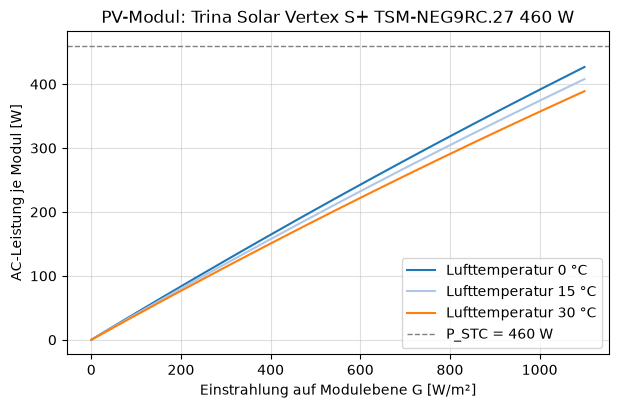

In [7]:
wt.plot_pv_curve()
plt.show()

### 1.4 Wetterdaten (Open-Meteo)

**Herkunft:** Die Wetterdaten stammen aus der *Historical Weather API* von Open-Meteo [4], [6]. Sie beruht auf Reanalyse-Datensätzen, in denen Messungen von Wetterstationen, Satelliten, Flugzeugen und Bojen mit einem numerischen Wettermodell zu einem lückenlosen Gitterdatensatz verbunden werden, unter anderem ERA5 des europäischen Wetterdienstes ECMWF [5].

**Abruf:** Standort 51,2° N, 7,34° E (Bergisches Land, NRW), Jahr 2025, stündliche Werte:

| Variable | Einheit | Bedeutung | Verwendung |
|---|---|---|---|
| `global_tilted_irradiance` | W/m² | Globalstrahlung auf eine geneigte Fläche (35° Neigung, Ausrichtung Süd), Mittel der vorangegangenen Stunde | PV |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe, Momentanwert | PV (Zelltemperatur) |
| `wind_speed_100m` | m/s | Windgeschwindigkeit in 100 m Höhe, Momentanwert | Wind |
| `shortwave_radiation` | W/m² | Globalstrahlung auf die horizontale Fläche | nur zur Information |

**Aufbereitung:**

1. Die API liefert Zeitstempel in UTC. Sie werden in lokale Zeit (Europe/Berlin) umgerechnet. Die Einstrahlung bezieht sich auf die vorangegangene Stunde und wird um eine Stunde verschoben, sodass alle Zeitstempel den Beginn der Stunde bezeichnen [6].
2. Aus den Wetterdaten wird über die Kennlinien die Leistung von PV und Wind berechnet (siehe unten).
3. **Typische Woche:** Für jeden Monat werden alle Wochen (Mo–So) betrachtet, die vollständig im Monat liegen, keine Zeitumstellung und keinen Feiertag enthalten. Gewählt wird die Woche, deren mittlere PV-Leistung und mittlere Windleistung zusammen am wenigsten vom Monatsmittel abweichen (Summe der relativen Abweichungen). So wird weder eine außergewöhnlich sonnige noch eine windstille Woche ausgewählt.
4. Ergebnis und Rohdaten werden als CSV gespeichert (`data/weather_weeks_2025.csv`, `data/weather_raw_2025.csv`).

**Tabelle der typischen Wochen** (erste Zeilen der Datei `weather_weeks_2025.csv`):

In [8]:
weather_table = pd.read_csv(WEATHER_FILE, index_col="time", parse_dates=True)
print(f"{len(weather_table)} Zeilen (12 Wochen × 168 Stunden), {weather_table.shape[1]} Spalten")
weather_table.head(10)

2016 Zeilen (12 Wochen × 168 Stunden), 10 Spalten


,month,hour_of_week,temperature_2m,global_tilted_irradiance,wind_speed_100m,wind_speed_hub,pv_module_w,pv_kw_per_kwp,wind_kw,wind_pu
time,,,,,,,,,,
2025-01-06 00:00:00,JANUARY,0,7.05,0.0000,11.7466,11.8288,0.0000,0.0000,1977.8195,0.9889
2025-01-06 01:00:00,JANUARY,1,7.15,0.0000,12.0354,12.1195,0.0000,0.0000,1994.9019,0.9975
2025-01-06 02:00:00,JANUARY,2,8.70,0.0000,11.6010,11.6821,0.0000,0.0000,1964.5629,0.9823
2025-01-06 03:00:00,JANUARY,3,8.55,0.0000,11.2695,11.3484,0.0000,0.0000,1921.7454,0.9609
2025-01-06 04:00:00,JANUARY,4,8.40,0.0000,11.6813,11.7630,0.0000,0.0000,1971.8745,0.9859
2025-01-06 05:00:00,JANUARY,5,8.20,0.0000,11.5412,11.6220,0.0000,0.0000,1959.1246,0.9796
2025-01-06 06:00:00,JANUARY,6,8.10,0.0000,12.6646,12.7532,0.0000,0.0000,2000.0000,1.0000
2025-01-06 07:00:00,JANUARY,7,8.15,0.0000,13.1477,13.2397,0.0000,0.0000,2000.0000,1.0000
2025-01-06 08:00:00,JANUARY,8,8.30,0.0000,13.6401,13.7355,0.0000,0.0000,2000.0000,1.0000


| Spalte | Einheit | Bedeutung |
|---|---|---|
| `time` | – | Beginn der Stunde, lokale Zeit (MEZ/MESZ) |
| `month`, `hour_of_week` | – | Monat (Enum `Month`), Stunde der Woche 0 … 167 (Mo 00:00 = 0) |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe |
| `global_tilted_irradiance` | W/m² | Einstrahlung auf die Modulebene (35°, Süd) |
| `wind_speed_100m`, `wind_speed_hub` | m/s | Windgeschwindigkeit in 100 m bzw. Nabenhöhe (105 m) |
| `pv_module_w` | W | AC-Leistung eines PV-Moduls (460 W) |
| `pv_kw_per_kwp` | kW/kWp | AC-Leistung je kWp |
| `wind_kw` | kW | Leistung der V90-2.0 MW |
| `wind_pu` | – | Leistung bezogen auf die Nennleistung |

In [9]:
def stats(series, *which):
    funcs = {"min": series.min, "Mittel": series.mean, "max": series.max}
    return [funcs[k]() for k in which]

rows = {}
for month, df in WEATHER.items():
    g_day_max = df["global_tilted_irradiance"].resample("D").max()      # Tageshöchstwert der Einstrahlung
    rows[month.label] = {
        ("Woche", "ab"): df.index[0].strftime("%a %d.%m.%Y"),
        **dict(zip([("T_Luft [°C]", k) for k in ("min", "Mittel", "max")],
                   stats(df["temperature_2m"], "min", "Mittel", "max"))),
        ("G_Modul [W/m²]", "Mittel"): df["global_tilted_irradiance"].mean(),
        ("G_Modul [W/m²]", "Tagesmax. min"): g_day_max.min(),
        ("G_Modul [W/m²]", "max"): g_day_max.max(),
        **dict(zip([("Wind Nabe [m/s]", k) for k in ("min", "Mittel", "max")],
                   stats(df["wind_speed_hub"], "min", "Mittel", "max"))),
        ("PV-Modul [W]", "Mittel"): df["pv_module_w"].mean(),
        ("PV-Modul [W]", "max"): df["pv_module_w"].max(),
        ("PV-Modul [W]", "Energie [kWh/Woche]"): df["pv_module_w"].sum() / 1000,
        **dict(zip([("WEA [MW]", k) for k in ("min", "Mittel", "max")],
                   [v / 1000 for v in stats(df["wind_kw"], "min", "Mittel", "max")])),
        ("WEA [MW]", "Energie [MWh/Woche]"): df["wind_kw"].sum() / 1000,
        ("WEA [MW]", "Stunden Stillstand"): int((df["wind_kw"] <= 0).sum()),
    }
overview = pd.DataFrame(rows).T
overview.columns = pd.MultiIndex.from_tuples(overview.columns)
num = overview.columns.drop(("Woche", "ab"))
overview[num] = overview[num].astype(float)
plots.table(overview, decimals=1, int_cols=[("WEA [MW]", "Stunden Stillstand")])

Zur Tabelle: Die Einstrahlung ist nachts immer 0 W/m², ein Minimum über die Woche sagt deshalb nichts aus. Stattdessen steht unter **Tagesmax. min** der höchste Wert des trübsten Tages und unter **max** der höchste Wert des sonnigsten Tages. Bei der WEA zählt **Stunden Stillstand** die Stunden mit einer Windgeschwindigkeit unter der Einschaltgeschwindigkeit (4 m/s), in denen die Anlage keine Leistung abgibt. Die Leistungswerte gelten für ein PV-Modul (460 W) bzw. eine WEA (2,0 MW). Im CIGRE-Netz werden sie mit der installierten Leistung skaliert (siehe 3.2).

**Wetterdiagramme:** Für jeden Monat zeigt ein zweiteiliges Diagramm die typische Woche:

- **oben:** Windgeschwindigkeit in Nabenhöhe [m/s], Lufttemperatur [°C] und Einstrahlung auf die Modulebene [100 W/m²]
- **unten:** Leistung der Windenergieanlage [MW] und eines PV-Moduls [100 W]

Die Einstrahlung und die PV-Leistung sind so skaliert, dass alle Größen im selben Zahlenbereich liegen: Ein Wert von 2 im unteren Diagramm entspricht 2 MW der Windenergieanlage bzw. 200 W des PV-Moduls, ein Wert von 8 im oberen Diagramm entspricht 800 W/m² Einstrahlung.

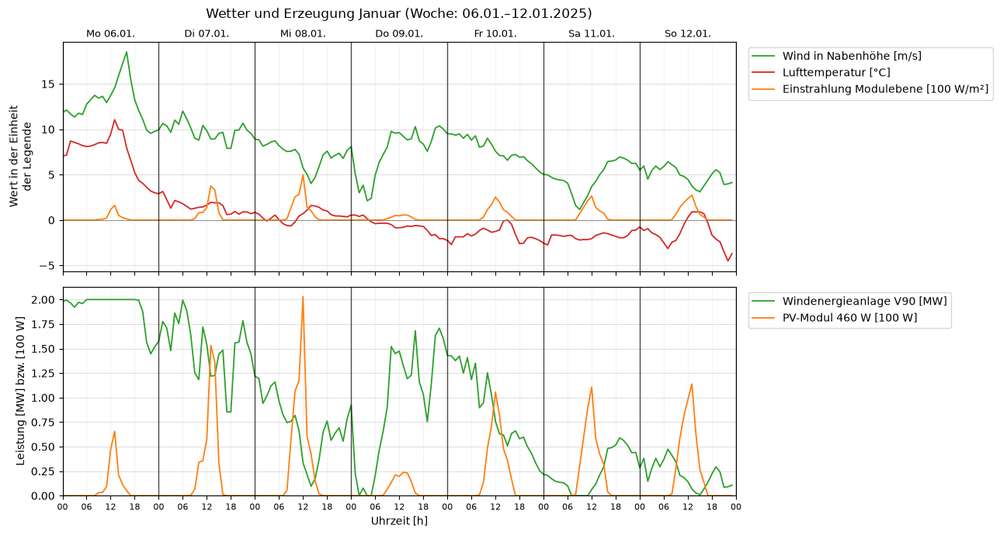

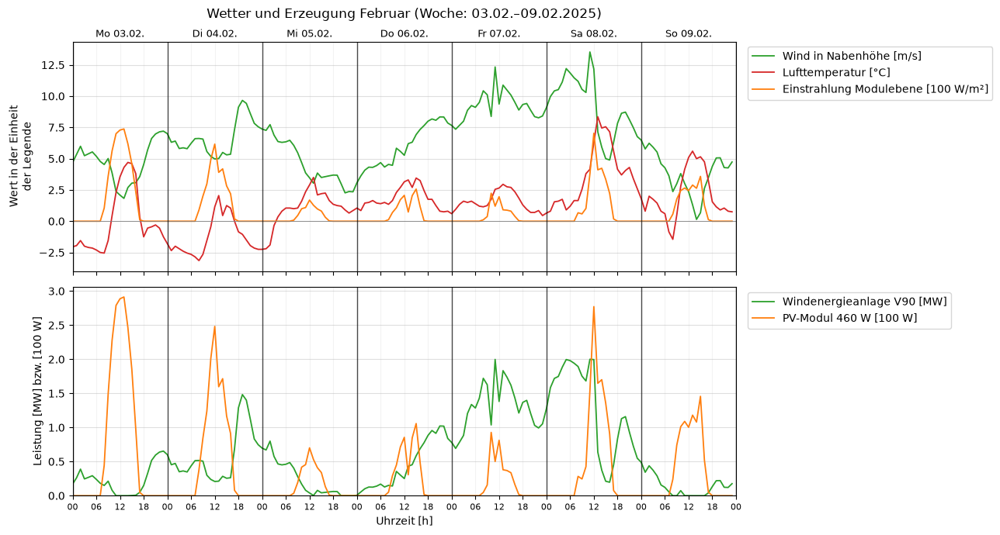

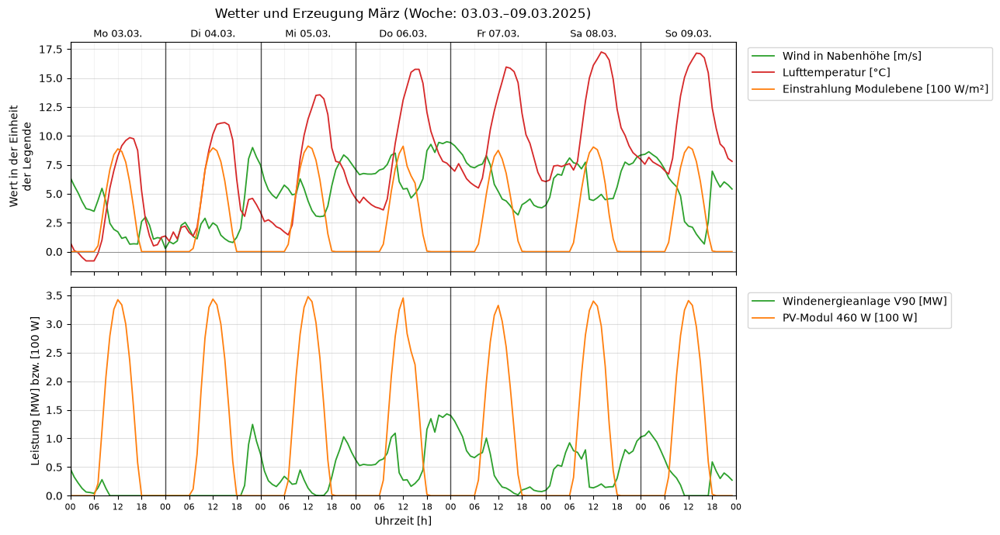

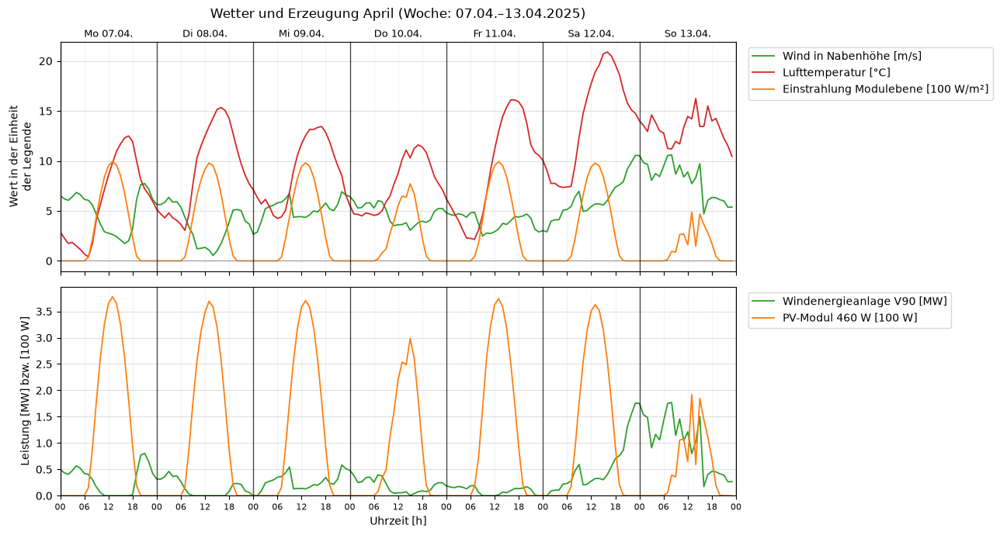

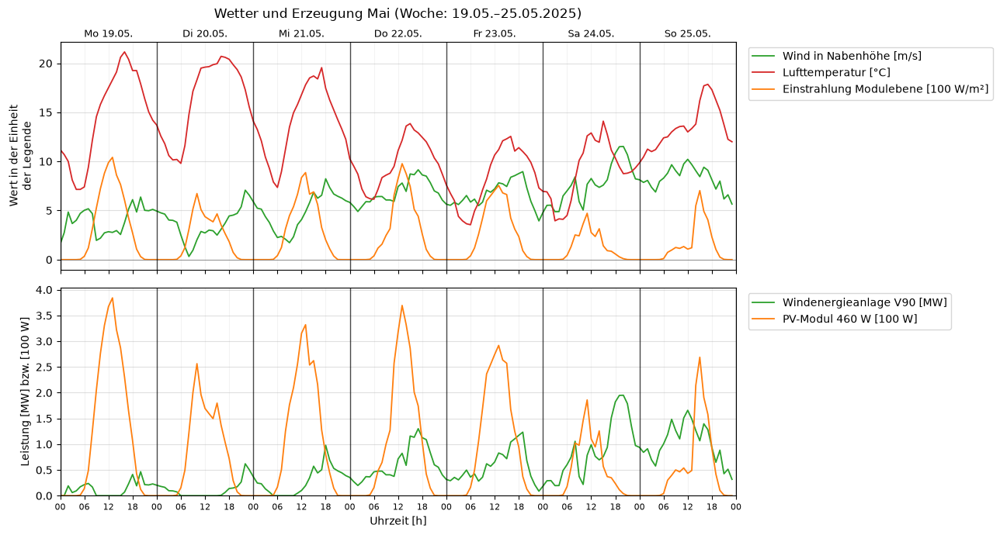

...

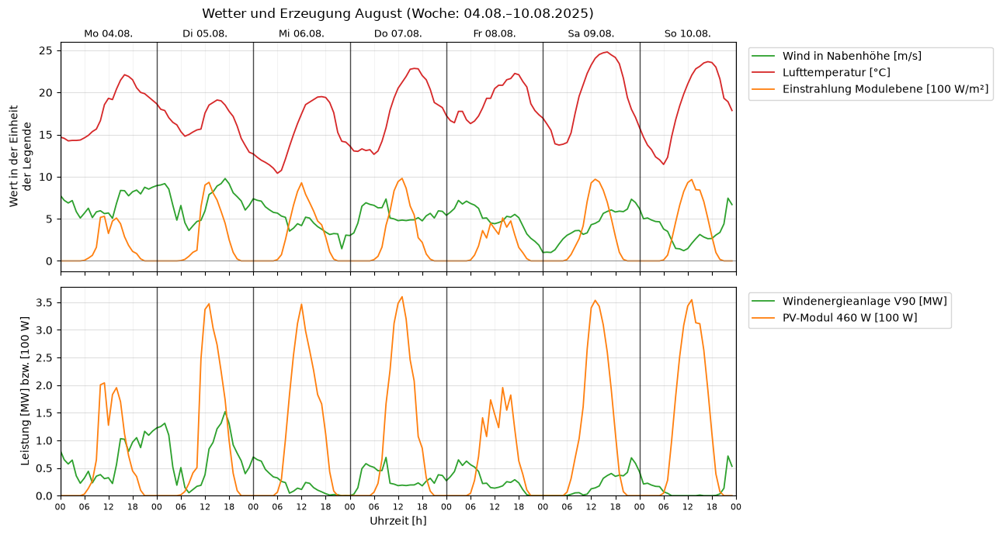

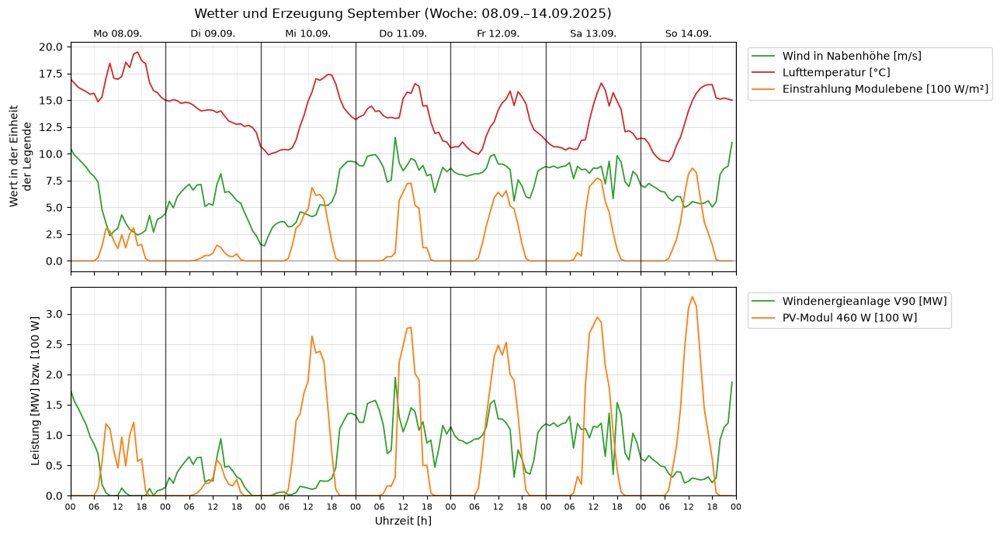

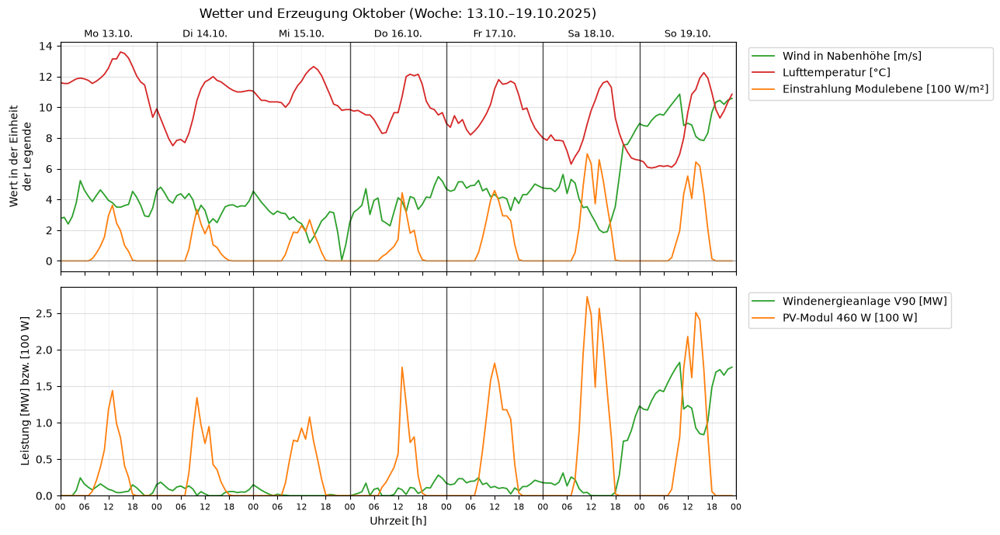

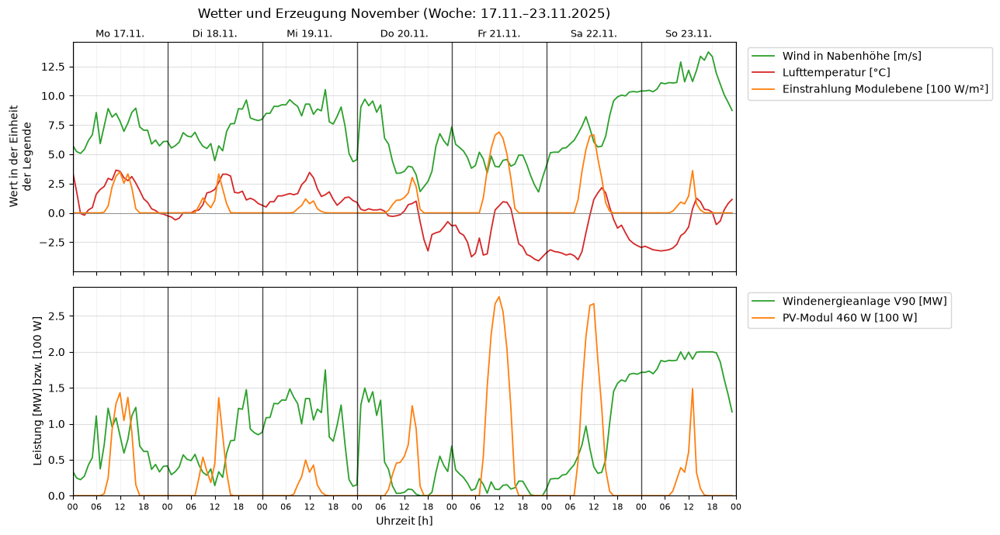

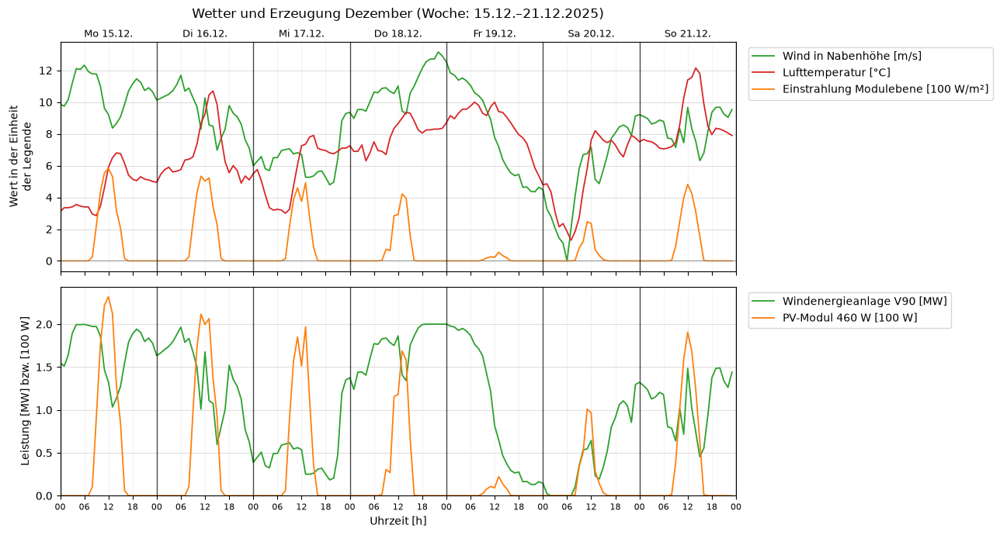

In [10]:
for month, w in WEATHER.items():
    plots.plot_weather_week(w, f"Wetter und Erzeugung {month.label} "
                               f"(Woche: {w.index[0]:%d.%m.}–{w.index[-1]:%d.%m.%Y})")
    plt.show()

### 1.5 Erzeugungsanlagen für die Szenarien in Task 4

| Anlage | Größe | Grundlage | Begründung |
|---|---|---|---|
| Windpark | 15 × Vestas V90-2.0 MW = 30 MW | Kennlinie und Wind auf Nabenhöhe aus 1.2 und 1.4 | Der Arbeitsauftrag gibt 15 WEA vor. Alle Anlagen erhalten dieselbe Windgeschwindigkeit (gleichzeitige Einspeisung). |
| PV-Freiflächenanlage | 10 MWp | PV-Leistung je kWp aus 1.3 und 1.4 | PV-Freiflächenanlagen sind Anlagen ab 1 MWp; die 18 Zuschläge der Innovationsausschreibung im April 2021 hatten zusammen 258 MW PV-Leistung, also im Mittel rund 14 MWp [22]. |

**Plausibilitätsprüfung der Erträge:** Aus den 12 typischen Wochen wird der Jahresertrag hochgerechnet (mittlere Wochenenergie × 52,14) und mit Literaturwerten verglichen. Für PV nennt [22] einen spezifischen Jahresertrag von 935 (Norden), 1105 (Mitte) und 1280 kWh/kWp (Süden) bei optimaler Neigung und Südausrichtung.

In [11]:
wochen = len(WEATHER)
pv_ertrag = sum(df["pv_kw_per_kwp"].sum() for df in WEATHER.values()) / wochen * 52.14        # kWh/kWp/a
wind_vlh = sum(df["wind_pu"].sum() for df in WEATHER.values()) / wochen * 52.14                # Volllaststunden
ertrag = pd.DataFrame({
    "Kennwert": ["spezifischer Ertrag [kWh/kWp/a]", "Volllaststunden [h/a]"],
    "Simulation": [pv_ertrag, wind_vlh],
    "Jahresenergie Anlage [GWh/a]": [pv_ertrag * 10_000 / 1e6, wind_vlh * 30 / 1000],
}, index=["PV-Freiflächenanlage 10 MWp", "Windpark 30 MW"])
ertrag.round(1)

,Kennwert,Simulation,Jahresenergie Anlage [GWh/a]
PV-Freiflächenanlage 10 MWp,spezifischer Ertrag [kWh/kWp/a],1222.6,12.2
Windpark 30 MW,Volllaststunden [h/a],2515.9,75.5


**Einordnung:** Der hochgerechnete PV-Ertrag liegt mit rund 1220 kWh/kWp zwischen den Werten für Mittel- und Süddeutschland in [22] und damit etwas über dem Wert für die Mitte. Gründe: optimale Ausrichtung im Modell, keine Verschmutzungs- und Verfügbarkeitsverluste und die Hochrechnung aus nur 12 typischen Wochen. Der Windpark erreicht rund 2500 Volllaststunden; das ist für einen Binnenlandstandort eher hoch, weil die Wetterwochen nach mittlerer Erzeugung ausgewählt wurden und weder Abschattung im Park noch Verfügbarkeitsverluste berücksichtigt sind. Beide Werte sind für die Netzuntersuchung ausreichend genau; entscheidend sind die Leistungsspitzen und ihre Gleichzeitigkeit mit der Last.

### 1.6 Haushalte mit PV-Anlage und Batteriespeicher (Ortsnetz)

Für das Ortsnetz-Szenario werden Haushalte mit PV-Anlage und teilweise mit Batteriespeicher abgebildet. Die Haushalte behalten ihren Verbrauch (Profil H25); PV-Anlage und Speicher kommen als eigene Elemente hinzu. So entsteht echte Einspeisung ins Ortsnetz, und die Vorzeichen sind eindeutig: Last `p_mw > 0` = Bezug, Erzeuger `p_mw > 0` = Einspeisung, Speicher `p_mw > 0` = Laden, `p_mw < 0` = Entladen (pandapower-Konvention [17]).

| Kenngröße | Wert | Grundlage |
|---|---|---|
| Jahresverbrauch je Haushalt | 3000 kWh/a | durchschnittlicher Drei-Personen-Haushalt in einer Wohnung bis 3000 kWh/a [32]; daraus die Zahl der Haushalte je Last |
| PV-Leistung je Haushalt mit PV | 9 kWp | Median der HTW-Feldmessung 8,4 kWp (4,8 bis 13 kWp) [34]; geförderte private Anlagen mit Speicher in Baden-Württemberg im Mittel 10,7 kWp [37]; Anlagen von 10 bis 20 kWp machen seit 2023 einen ebenso großen Teil des Zubaus aus wie 2 bis 10 kWp [36] |
| Speicherkapazität je Heimspeicher | 8,3 kWh | durchschnittliche Größe neu installierter Heimspeicher Q1 2026 [33]; HTW-Feldmessung: Median 7,3 kWh [34] |
| Lade-/Entladeleistung | 0,59 kW je kWh, also 4,9 kW | mittleres Verhältnis von Nennleistung zu nutzbarer Kapazität [34], [38] |
| Wirkungsgrad je Richtung | 0,95 (Zyklus ≈ 0,90) | Umwandlungswirkungsgrade beim Laden und Entladen 92 bis 98 % [35] |
| Ladezustand zu Beginn jeder Woche | 0 % | Annahme; die typischen Wochen hängen zeitlich nicht zusammen |
| Anteil der Haushalte (heute) | 15 % mit PV, davon 6,7 % aller Haushalte mit Speicher | KfW-Energiewendebarometer [23] |
| Anteil der Haushalte (Zukunft) | 50 % mit PV, davon 40 % aller Haushalte mit Speicher | Annahme: hoher Ausbau; fast 80 % der neuen privaten Aufdachanlagen werden mit Speicher gebaut [24] |
| Leistungsfaktor PV | cos φ = 1 | vereinfachend; VDE-AR-N 4105 erlaubt dem Netzbetreiber Vorgaben zur Blindleistung [30] |

**Regelung des Speichers (Eigenverbrauch):** Je Stunde wird die PV-Leistung der Haushalte mit Speicher mit deren Verbrauch verglichen. Ein Überschuss wird geladen, höchstens mit der Speicherleistung und bis der Speicher voll ist; ein Defizit wird aus dem Speicher gedeckt, bis er leer ist. Erst was der Speicher nicht aufnehmen oder liefern kann, fließt ins Netz bzw. kommt aus dem Netz. Die Regelung misst nur am Hausanschluss und kennt das Netz nicht (`timeseries.eigenverbrauch`, verwendet in der Simulation über das Element `Storage`).

**Beispiel:** ein Haushalt mit 3000 kWh/a, 9 kWp und 8,3 kWh Speicher in der typischen Januar- und Juliwoche.

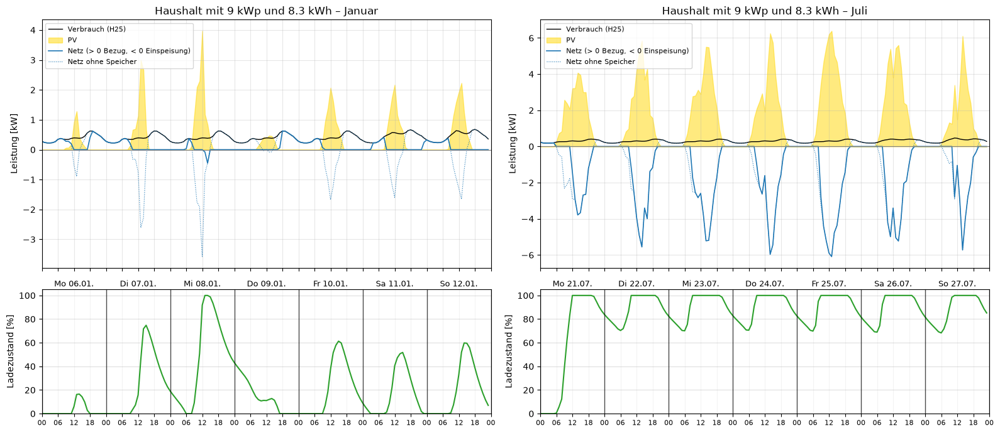

In [12]:
import timeseries as tsm
import lvnetz

hh_kwh, kwp, e_kwh = lvnetz.KWH_JE_HAUSHALT, lvnetz.KWP_JE_HAUSHALT, lvnetz.SPEICHER_KWH
p_kw, eta = e_kwh * lvnetz.SPEICHER_KW_JE_KWH, lvnetz.SPEICHER_ETA

def haushalt_woche(month):
    last = pr.build_week(PROFILES, Lastprofil.HAUSHALT, month, annual_kwh=hh_kwh, unit="kW",
                         start=WEEK_STARTS[month], resolution="1h")
    pv = pd.Series(WEATHER[month]["pv_kw_per_kwp"].to_numpy() * kwp, index=last.index)
    p, soc = tsm.eigenverbrauch(pv.to_numpy(), last.to_numpy(), e_kwh, p_kw, eta)
    netz = last - pv + p                                   # > 0 Bezug, < 0 Einspeisung (alle Werte in kW)
    return pd.DataFrame({"Verbrauch [kW]": last, "PV [kW]": pv, "Speicher [kW]": p, "Ladezustand [%]": soc,
                         "Netz [kW]": netz, "Netz ohne Speicher [kW]": last - pv})

fig, axes = plt.subplots(2, 2, figsize=(16, 7), sharex="col", gridspec_kw={"height_ratios": [2, 1]})
for j, month in enumerate((Month.JANUARY, Month.JULY)):
    w = haushalt_woche(month)
    ax = axes[0, j]
    ax.plot(w.index, w["Verbrauch [kW]"], color="black", lw=1, label="Verbrauch (H25)")
    ax.fill_between(w.index, w["PV [kW]"], color="gold", alpha=0.5, label="PV")
    ax.plot(w.index, w["Netz [kW]"], color="tab:blue", lw=1.2, label="Netz (> 0 Bezug, < 0 Einspeisung)")
    ax.plot(w.index, w["Netz ohne Speicher [kW]"], color="tab:blue", lw=0.8, ls=":", label="Netz ohne Speicher")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_ylabel("Leistung [kW]")
    ax.set_title(f"Haushalt mit {kwp:.0f} kWp und {e_kwh} kWh – {month.label}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
    axes[1, j].plot(w.index, w["Ladezustand [%]"], color="tab:green")
    axes[1, j].set_ylabel("Ladezustand [%]")
    axes[1, j].set_ylim(0, 105)
    axes[1, j].grid(alpha=0.3)
    plots.week_axis(axes[1, j], w.index)
plt.tight_layout()
plt.show()

In [13]:
zeilen = {}
for month in Month:
    w = haushalt_woche(month)
    pv, last = w["PV [kW]"].sum(), w["Verbrauch [kW]"].sum()
    bezug, einsp = w["Netz [kW]"].clip(lower=0).sum(), (-w["Netz [kW]"]).clip(lower=0).sum()
    bezug0, einsp0 = w["Netz ohne Speicher [kW]"].clip(lower=0).sum(), (-w["Netz ohne Speicher [kW]"]).clip(lower=0).sum()
    zeilen[month.label] = {"Verbrauch [kWh]": last, "PV [kWh]": pv, "Bezug ohne Speicher [kWh]": bezug0,
                           "Bezug mit Speicher [kWh]": bezug, "Einspeisung ohne Speicher [kWh]": einsp0,
                           "Einspeisung mit Speicher [kWh]": einsp}
bilanz = pd.DataFrame(zeilen).T
bilanz.loc["Summe 12 Wochen"] = bilanz.sum()
s = bilanz.loc["Summe 12 Wochen"]
bilanz["Autarkie mit Speicher [%]"] = 100 * (1 - bilanz["Bezug mit Speicher [kWh]"] / bilanz["Verbrauch [kWh]"])
bilanz["Autarkie ohne Speicher [%]"] = 100 * (1 - bilanz["Bezug ohne Speicher [kWh]"] / bilanz["Verbrauch [kWh]"])
plots.table(bilanz, decimals=1)

,Verbrauch [kWh],PV [kWh],Bezug ohne Speicher [kWh],Bezug mit Speicher [kWh],Einspeisung ohne Speicher [kWh],Einspeisung mit Speicher [kWh],Autarkie mit Speicher [%],Autarkie ohne Speicher [%]
Januar,68.2,52.7,48.0,19.7,32.5,0.5,71.2,29.6
Februar,66.9,121.1,41.6,5.2,95.8,50.8,92.2,37.8
März,61.4,317.8,32.0,1.7,288.3,249.2,97.2,48.0
April,57.9,335.1,24.5,1.7,301.6,269.6,97.1,57.7
Mai,50.8,283.0,17.1,1.1,249.2,224.2,97.8,66.3
Juni,50.1,313.7,15.3,1.1,278.8,255.5,97.7,69.5
Juli,50.0,265.3,16.7,1.2,232.0,207.4,97.6,66.6
August,48.8,306.2,18.0,1.4,275.4,249.6,97.2,63.1
September,50.2,205.8,23.2,1.4,178.8,148.0,97.2,53.8
Oktober,56.3,131.5,31.4,2.0,106.7,68.2,96.5,44.2


**Einordnung:** Ohne Speicher deckt die PV-Anlage den Verbrauch nur tagsüber; der Überschuss mittags fließt ins Netz, abends und nachts wird bezogen. Der Speicher verschiebt einen Teil des Mittagsüberschusses in den Abend. Im Sommer ist er fast jeden Tag voll, sodass mittags trotzdem eingespeist wird; im Winter reicht die PV-Erzeugung oft nicht, um ihn zu füllen. Für das Netz heißt das: Der Speicher senkt den Bezug am Abend, die Einspeisespitze am Mittag senkt er an sonnigen Tagen kaum, weil er dann schon vormittags voll ist.

## 2 Netzdaten

Die Netzmodelle werden in den Teil-Notebooks beschrieben, dort, wo sie verwendet werden:

- **CIGRE-Mittelspannungsnetz** (`pn.create_cigre_network_mv(with_der=False)`, Baseline ohne dezentrale Erzeuger) [13], [14]: Topologie, Betriebsmittel, Nennspannungen und Betriebspunkte in `Task4-1_Baseline.ipynb`.
- **CIGRE-Niederspannungsnetz** (`pn.create_cigre_network_lv()`) [13], Leitungstypen und Stromgrenzen [18]: `Task4-2_Ortsnetz.ipynb`; Auslegung der Ortsnetztrafos und Leitungen: `Task4-3_Ortsnetz_Auslegung.ipynb`.

Die Datenquellen der Netze stehen im Quellenverzeichnis (Abschnitt 3).

<a id="teil-1"></a>

---

# Task 4 – Teil 1: Baseline und Modellverständnis

**Ziel:** Das unveränderte CIGRE-Mittelspannungsnetz ohne dezentrale Erzeuger (`with_der=False`) wird als Referenz beschrieben, mit einem AC-Lastfluss berechnet und für alle Stellungen der Trennschalter S1 bis S3 ausgewertet. Am Ende steht ein reproduzierbares Referenzszenario, von dem alle weiteren Teilaufgaben ausgehen.

**Aufbau:**

1. Das unveränderte CIGRE-MV-Netz: Topologie, Betriebsmittel, Nennspannungen, Betriebspunkt
2. Statischer AC-Lastfluss der Baseline mit Konvergenzprüfung und Vorzeichenkonventionen
3. Alle Schalterstellungen S1–S3 im statischen Lastfluss
4. Alle Schalterstellungen S1–S3 als Zeitreihe über 12 typische Wochen
5. Festlegung des Referenzszenarios
6. Zusammenfassung und Literaturabgleich

Die Eingangsdaten (BDEW-Lastprofile, Wetterdaten, Anlagenkennlinien) und das zentrale Quellenverzeichnis stehen im Notebook `Task4-Datengrundlage.ipynb`.

## Aufgabenstellung

> *Beschreiben Sie Topologie, Betriebsmittel, Nennspannungen und Betriebspunkte des unveränderten CIGRE-MV-Netzes. Führen Sie einen AC-Lastfluss mit `pp.runpp(...)` durch und prüfen Sie die Konvergenz. Führen Sie die Simulationen mit allen möglichen Schalterstellungen und Kombinationen der Schalter S1-S3 durch. Dokumentieren Sie an allen Bussen mindestens Spannungsbetrag in p.u. und Spannungswinkel. Erfassen Sie außerdem Wirkleistungsflüsse, Leitungsströme und -auslastungen, Transformatorauslastungen sowie Netzverluste. […] Legen Sie für die weiteren Untersuchungen ein reproduzierbares Referenzszenario / eine Baseline fest. […] Stützen Sie Ihre Beobachtungen mit geeigneter Literatur.*

| Anforderung | Umsetzung |
|---|---|
| Topologie, Betriebsmittel, Nennspannungen, Betriebspunkt | Abschnitt 1 |
| AC-Lastfluss mit `pp.runpp`, Konvergenz, Vorzeichenkonventionen | Abschnitt 2 |
| alle Schalterstellungen S1–S3 | Abschnitt 3 (statisch), Abschnitt 4 (Zeitreihe) |
| Spannung und Winkel an allen Bussen, Flüsse, Ströme, Auslastungen, Verluste | Abschnitte 2 bis 4 |
| reproduzierbares Referenzszenario, veränderte und konstante Größen | Abschnitt 5 |
| Literaturabgleich | Abschnitt 6 |

## Importe

In [14]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

import simulation as sim
import szenarien as sz
import netplan
import plots
from elements import Diagram, Profile
from profiles import Month
from auswertung import baseline_net

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

# Zeitreihen nur neu rechnen, wenn sich Netz, Einstellungen oder Daten geändert haben.
# False: jede Simulation wird bei jedem Durchlauf neu gerechnet.
sim.ONLY_RUN_IF_CHANGED = True

Module im Ordner `task4` (Beschreibung siehe `README.md`):

- `simulation.py`, `elements.py`, `timeseries.py`, `diagrams.py`: Simulationssoftware für Zeitreihen-Lastflüsse aus Task 3. Mit `sim.ONLY_RUN_IF_CHANGED = True` lädt `runSimulation()` die gespeicherten Ergebnisse, solange sich Netz, Einstellungen und Eingangsdaten nicht geändert haben.
- `netplan.py`: Netzplan mit Spannungen, Auslastungen und Pfeilen für die Richtung des Wirkleistungsflusses
- `szenarien.py` (neu): Schalterstellungen S1–S3, statische Lastflüsse aller Schaltzustände, Vergleichstabellen und Heatmaps
- `profiles.py`, `weather.py`, `plots.py`: Lastprofile, Wetter und Diagrammhilfen (siehe `Task4-Datengrundlage.ipynb`)

## 1 Das unveränderte CIGRE-MV-Netz

Als Referenz dient das CIGRE-MV-Benchmarknetz [13] in der pandapower-Umsetzung [14] **ohne** dezentrale Erzeuger:

```python
net = pn.create_cigre_network_mv(with_der=False)
```

Jede Untersuchung erzeugt das Netz mit dieser Funktion neu. Damit startet jeder Vergleich vom selben, unveränderten Stand.

In [15]:
net = baseline_net()          # auswertung.baseline_net: create_cigre_network_mv(with_der=False)
net

This pandapower network includes the following parameter tables:
   - bus (15 elements)
   - load (18 elements)
   - switch (8 elements)
   - ext_grid (1 element)
   - line (15 elements)
   - trafo (2 elements)

### 1.1 Netzplan und Topologie

![Netzplan des CIGRE-MV-Netzes ohne dezentrale Erzeuger](../bilder/cigre_network_mv_der.png)

*Bild: Netzplan des CIGRE-MV-Netzes ohne dezentrale Erzeuger (`with_der=False`) aus der pandapower-Dokumentation [14], nach [13]. Quelle der Bilddatei: pandapower-Repository, `doc/pics/networks/cigre/cigre_network_mv.png` (BSD-3-Clause-Lizenz).*

**Topologie:**

- **Einspeisung:** Das externe Netz (Slack) liegt an Bus 0 (110 kV) mit fester Spannung 1,03 pu und Winkel 0°. Zwei Transformatoren 110/20 kV (Trafo 0-1, Trafo 0-12) speisen zwei getrennte 20-kV-Abgänge.
- **Abgang 1 (Bus 1 bis Bus 11, Kabel):** Der Strang Bus 1 – 2 – 3 verzweigt an Bus 3 in die Äste Bus 4 – 5 – 6 und Bus 8 – 9 – 10 – 11 (über Line 3-8) sowie Bus 7 (über Line 7-8). Zwei Maschen sind durch offene Trennschalter aufgetrennt: **S2** (Line 6-7) schließt die Masche 3 – 4 – 5 – 6 – 7 – 8 – 3, **S3** (Line 11-4) die Masche 3 – 4 – 11 – 10 – 9 – 8 – 3.
- **Abgang 2 (Bus 12 bis Bus 14, Freileitung):** Strahlennetz Bus 12 – 13 – 14.
- **Kupplung:** **S1** (Line 14-8) verbindet das Ende von Abgang 2 mit Bus 8 in Abgang 1. Mit geschlossenem S1 entsteht eine Masche über beide Transformatoren und die 110-kV-Sammelschiene.
- **Normalbetrieb:** S1, S2 und S3 sind offen. Das Netz wird **strahlenförmig** betrieben, jeder Bus wird über genau einen Weg versorgt. Die offenen Ringe dienen der Wiederversorgung bei Störungen. Das ist die übliche Betriebsweise von Mittelspannungsnetzen [16].

In [16]:
bus = net.bus[["name", "vn_kv", "type", "zone", "in_service"]].copy()
bus["Anschluss"] = ["externes Netz (Slack)" if b in set(net.ext_grid.bus) else "" for b in net.bus.index]
bus["Lasten"] = [", ".join(net.load.name[net.load.bus == b]) for b in net.bus.index]
bus.set_index("name")

,vn_kv,type,zone,in_service,Anschluss,Lasten
name,,,,,,
Bus 0,110.0,b,CIGRE_MV,True,externes Netz (Slack),
Bus 1,20.0,b,CIGRE_MV,True,,"Load R1, Load CI1"
Bus 2,20.0,b,CIGRE_MV,True,,
Bus 3,20.0,b,CIGRE_MV,True,,"Load R3, Load CI3"
Bus 4,20.0,b,CIGRE_MV,True,,Load R4
Bus 5,20.0,b,CIGRE_MV,True,,Load R5
Bus 6,20.0,b,CIGRE_MV,True,,Load R6
Bus 7,20.0,b,CIGRE_MV,True,,Load CI7
Bus 8,20.0,b,CIGRE_MV,True,,Load R8


### 1.2 Betriebsmittel

**Leitungen.** Die Kabel des Abgangs 1 haben den Typ `CABLE_CIGRE_MV`, die Freileitungen des Abgangs 2 und die Kupplung S1 den Typ `OHL_CIGRE_MV`. Die Werte stammen aus [13] in der Umsetzung von [14]. Die thermische Grenzleistung ist $S_\mathrm{th} = \sqrt{3} \cdot U_n \cdot I_\mathrm{max}$ mit $U_n$ = 20 kV.

In [17]:
line = net.line.copy()
line_tab = pd.DataFrame({
    "von": net.bus.name.loc[line.from_bus].values,
    "nach": net.bus.name.loc[line.to_bus].values,
    "Typ": line.std_type.values,
    "Art": line.type.map({"cs": "Kabel", "ol": "Freileitung"}).values,
    "Länge [km]": line.length_km.values,
    "R' [Ω/km]": line.r_ohm_per_km.values,
    "X' [Ω/km]": line.x_ohm_per_km.values,
    "C' [nF/km]": line.c_nf_per_km.values,
    "R [Ω]": (line.r_ohm_per_km * line.length_km).values,
    "X [Ω]": (line.x_ohm_per_km * line.length_km).values,
    "I_max [A]": (line.max_i_ka * 1000).values,
    "S_th [MVA]": (np.sqrt(3) * 20 * line.max_i_ka).values,
}, index=line.name.values)
sw_line = {r.element: r["name"] for _, r in net.switch[net.switch.et == "l"].iterrows() if r["name"]}
line_tab["Trennschalter"] = [sw_line.get(i, "") for i in line.index]
plots.table(line_tab, decimals=3)

,von,nach,Typ,Art,Länge [km],R' [Ω/km],X' [Ω/km],C' [nF/km],R [Ω],X [Ω],I_max [A],S_th [MVA],Trennschalter
Line 1-2,Bus 1,Bus 2,CABLE_CIGRE_MV,Kabel,2.820,0.501,0.716,151.175,1.413,2.019,145.000,5.023,
Line 2-3,Bus 2,Bus 3,CABLE_CIGRE_MV,Kabel,4.420,0.501,0.716,151.175,2.214,3.165,145.000,5.023,
Line 3-4,Bus 3,Bus 4,CABLE_CIGRE_MV,Kabel,0.610,0.501,0.716,151.175,0.306,0.437,145.000,5.023,
Line 4-5,Bus 4,Bus 5,CABLE_CIGRE_MV,Kabel,0.560,0.501,0.716,151.175,0.281,0.401,145.000,5.023,
Line 5-6,Bus 5,Bus 6,CABLE_CIGRE_MV,Kabel,1.540,0.501,0.716,151.175,0.772,1.103,145.000,5.023,
Line 7-8,Bus 7,Bus 8,CABLE_CIGRE_MV,Kabel,1.670,0.501,0.716,151.175,0.837,1.196,145.000,5.023,
Line 8-9,Bus 8,Bus 9,CABLE_CIGRE_MV,Kabel,0.320,0.501,0.716,151.175,0.160,0.229,145.000,5.023,
Line 9-10,Bus 9,Bus 10,CABLE_CIGRE_MV,Kabel,0.770,0.501,0.716,151.175,0.386,0.551,145.000,5.023,
Line 10-11,Bus 10,Bus 11,CABLE_CIGRE_MV,Kabel,0.330,0.501,0.716,151.175,0.165,0.236,145.000,5.023,
Line 3-8,Bus 3,Bus 8,CABLE_CIGRE_MV,Kabel,1.300,0.501,0.716,151.175,0.651,0.931,145.000,5.023,


**Transformatoren.** Beide Transformatoren sind gleich aufgebaut. Sie haben **keinen Stufenschalter** (`tap_pos` = NaN), die 20-kV-Spannung folgt also direkt der Belastung. Die Phasenverschiebung von 30° (`shift_degree`) entspricht der Schaltgruppe und verschiebt alle Winkel auf der 20-kV-Seite um −30°.

In [18]:
trafo_tab = net.trafo[["name", "sn_mva", "vn_hv_kv", "vn_lv_kv", "vk_percent", "vkr_percent",
                       "pfe_kw", "i0_percent", "shift_degree", "tap_pos"]].set_index("name")
trafo_tab["OS-Bus"] = net.bus.name.loc[net.trafo.hv_bus].values
trafo_tab["US-Bus"] = net.bus.name.loc[net.trafo.lv_bus].values
trafo_tab["I_n US [A]"] = net.trafo.sn_mva.values / (np.sqrt(3) * net.trafo.vn_lv_kv.values) * 1000
trafo_tab

,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,i0_percent,shift_degree,tap_pos,OS-Bus,US-Bus,I_n US [A]
name,,,,,,,,,,,,
Trafo 0-1,25.0,110.0,20.0,12.00107,0.16,0.0,0.0,30.0,NaN,Bus 0,Bus 1,721.687836
Trafo 0-12,25.0,110.0,20.0,12.00107,0.16,0.0,0.0,30.0,NaN,Bus 0,Bus 12,721.687836


**Schalter und externes Netz.** Die drei Trennschalter (LBS) sitzen jeweils an einem Ende einer Leitung. Die Leistungsschalter (CB) an der 110-kV-Seite der Trafos sind geschlossen.

In [19]:
sw = net.switch.copy()
sw["Bus"] = net.bus.name.loc[sw.bus].values
sw["Element"] = [net.line.name.at[e] if t == "l" else net.trafo.name.at[e] for e, t in zip(sw.element, sw.et)]
sw["Art"] = sw.et.map({"l": "an Leitung", "t": "an Trafo", "b": "Bus–Bus"})
display(sw[["name", "Bus", "Element", "Art", "type", "closed"]])
net.ext_grid[["bus", "vm_pu", "va_degree", "s_sc_max_mva", "rx_max"]]

,name,Bus,Element,Art,type,closed
0,None,Bus 6,Line 6-7,an Leitung,LBS,True
1,S2,Bus 7,Line 6-7,an Leitung,LBS,False
2,S3,Bus 4,Line 11-4,an Leitung,LBS,False
3,None,Bus 11,Line 11-4,an Leitung,LBS,True
4,S1,Bus 8,Line 14-8,an Leitung,LBS,False
5,None,Bus 14,Line 14-8,an Leitung,LBS,True
6,None,Bus 0,Trafo 0-1,an Trafo,CB,True
7,None,Bus 0,Trafo 0-12,an Trafo,CB,True


,bus,vm_pu,va_degree,s_sc_max_mva,rx_max
0,0,1.03,0.0,5000.0,0.1


**Lasten (Betriebspunkt).** Die 18 Lasten sind nach [13] Wohngebiete (*residential*, `Load R…`) und Gewerbe/Industrie (*commercial/industrial*, `Load CI…`). Die angegebenen Werte sind Bemessungs- bzw. Höchstleistungen. Im statischen Lastfluss arbeiten alle Lasten gleichzeitig mit diesen Werten. Die großen Lasten an Bus 1 und Bus 12 (je 15 MW Haushalt und 5 MW Gewerbe) bilden weitere, nicht einzeln modellierte Abgänge an den 20-kV-Sammelschienen nach. Vorzeichen: `p_mw` > 0 bedeutet Bezug (Verbraucherzählpfeilsystem).

In [20]:
load_tab = net.load[["name", "bus", "p_mw", "q_mvar"]].copy()
load_tab["Bus"] = net.bus.name.loc[load_tab.bus].values
load_tab["S [MVA]"] = np.hypot(load_tab.p_mw, load_tab.q_mvar)
load_tab["cos φ"] = load_tab.p_mw / load_tab["S [MVA]"]
load_tab["Art"] = ["Wohngebiet (R)" if n.startswith("Load R") else "Gewerbe/Industrie (CI)" for n in load_tab.name]
load_tab = load_tab.drop(columns="bus").set_index("name")
display(plots.table(load_tab, decimals=3))
print(f"Summe: P = {net.load.p_mw.sum():.2f} MW, Q = {net.load.q_mvar.sum():.2f} Mvar, "
      f"cos φ = {net.load.p_mw.sum() / np.hypot(net.load.p_mw.sum(), net.load.q_mvar.sum()):.3f}")
print(f"davon Bus 1 und Bus 12: {net.load.p_mw[net.load.bus.isin([1, 12])].sum():.2f} MW")

,p_mw,q_mvar,Bus,S [MVA],cos φ,Art
name,,,,,,
Load R1,14.994,3.045,Bus 1,15.300,0.980,Wohngebiet (R)
Load R3,0.276,0.069,Bus 3,0.285,0.970,Wohngebiet (R)
Load R4,0.432,0.108,Bus 4,0.445,0.970,Wohngebiet (R)
Load R5,0.728,0.182,Bus 5,0.750,0.970,Wohngebiet (R)
Load R6,0.548,0.137,Bus 6,0.565,0.970,Wohngebiet (R)
Load R8,0.587,0.147,Bus 8,0.605,0.970,Wohngebiet (R)
Load R10,0.475,0.119,Bus 10,0.490,0.970,Wohngebiet (R)
Load R11,0.330,0.083,Bus 11,0.340,0.970,Wohngebiet (R)
Load R12,14.994,3.045,Bus 12,15.300,0.980,Wohngebiet (R)


Summe: P = 44.74 MW, Q = 11.04 Mvar, cos φ = 0.971
davon Bus 1 und Bus 12: 39.85 MW


## 2 Statischer AC-Lastfluss der Baseline

Der Lastfluss wird mit dem Newton-Raphson-Verfahren von pandapower gerechnet (`pp.runpp`). Die Funktion `sz.lastfluss()` fängt `LoadflowNotConverged` ab und prüft zusätzlich `net.converged`. Nur konvergierte Ergebnisse werden ausgewertet.

**Vorzeichenkonventionen und Bezugsgrößen** (pandapower [14], [17]):

| Ergebnisgröße | Einheit | Bezug / Vorzeichen |
|---|---|---|
| `res_bus.vm_pu` | pu | Spannungsbetrag bezogen auf die Nennspannung des Busses (`vn_kv`: 110 kV bzw. 20 kV) |
| `res_bus.va_degree` | ° | Spannungswinkel bezogen auf den Slack (Bus 0 = 0°); die 20-kV-Seite enthält die Trafo-Phasenverschiebung von −30° |
| `res_bus.p_mw` | MW | Verbraucherzählpfeil: > 0 Bezug am Bus; in den Tabellen hier als Einspeisung = −`p_mw` |
| `res_line.p_from_mw`, `p_to_mw` | MW | Leistung, die am jeweiligen Ende **in** die Leitung fließt; `p_from_mw` > 0: Fluss von `from_bus` nach `to_bus` |
| `res_line.i_ka` | kA | größerer der beiden Endströme |
| `res_line.loading_percent` | % | `i_ka` bezogen auf `max_i_ka · df · parallel` |
| `res_line.pl_mw` | MW | Wirkverluste der Leitung = `p_from_mw + p_to_mw` |
| `res_trafo.p_hv_mw` | MW | Leistung, die auf der OS-Seite in den Trafo fließt; > 0: Fluss 110 kV → 20 kV |
| `res_trafo.loading_percent` | % | Scheinleistung bezogen auf `sn_mva` |
| `res_ext_grid.p_mw` | MW | > 0: Bezug aus dem vorgelagerten Netz, < 0: Rückspeisung |
| `res_load.p_mw` / `res_sgen.p_mw` | MW | Last: > 0 Bezug; Erzeuger: > 0 Einspeisung |

In [21]:
base = sz.lastfluss(baseline_net())
assert base["converged"], "Baseline-Lastfluss nicht konvergiert"
print(f"Konvergiert: ja, {base['iterations']} Newton-Raphson-Iterationen")
base["bilanz"].round(4).to_frame("Wert")

Konvergiert: ja, 4 Newton-Raphson-Iterationen


,Wert
Last P [MW],44.7421
Erzeugung P [MW],0.0000
Bezug ext. Netz P [MW],45.0457
Bezug ext. Netz Q [Mvar],16.3414
Verluste Leitungen [MW],0.2337
Verluste Trafos [MW],0.0698
Verluste gesamt [MW],0.3036
Verluste [% der Last],0.6785


**Busse:** Spannungsbetrag, Spannung in kV, Winkel und eingespeiste Wirkleistung je Bus.

In [22]:
bus_res = base["bus"].copy()
bus_res["Abweichung [%]"] = (bus_res.vm_pu - 1) * 100
bus_res["Winkel ohne Trafo-Verschiebung [°]"] = np.where(bus_res["U_n [kV]"] < 100, bus_res.va_degree + 30, bus_res.va_degree)
plots.table(bus_res, decimals=4)

,U_n [kV],vm_pu,U [kV],va_degree,P_einspeisung [MW],Abweichung [%],Winkel ohne Trafo-Verschiebung [°]
Bus 0,110.0000,1.0300,113.3000,0.0000,45.0457,3.0000,0.0000
Bus 1,20.0000,0.9920,19.8394,-36.5568,-19.8390,-0.8028,-6.5568
Bus 2,20.0000,0.9681,19.3629,-37.6042,-0.0000,-3.1853,-7.6042
Bus 3,20.0000,0.9310,18.6192,-39.3310,-0.5017,-6.9039,-9.3310
Bus 4,20.0000,0.9291,18.5820,-39.4350,-0.4317,-7.0902,-9.4350
Bus 5,20.0000,0.9278,18.5565,-39.5066,-0.7275,-7.2177,-9.5066
Bus 6,20.0000,0.9263,18.5264,-39.5918,-0.5480,-7.3679,-9.5918
Bus 7,20.0000,0.9251,18.5024,-39.5896,-0.0765,-7.4878,-9.5896
Bus 8,20.0000,0.9254,18.5081,-39.5790,-0.5868,-7.4596,-9.5790
Bus 9,20.0000,0.9244,18.4884,-39.6192,-0.5738,-7.5578,-9.6192


**Leitungen:** Wirkleistungsfluss am Anfang und Ende, Blindleistung, Strom, Auslastung und Verluste.

In [23]:
line_res = base["line"].copy()
line_res["i [A]"] = line_res.i_ka * 1000
line_res["Verluste [kW]"] = line_res.pl_mw * 1000
plots.table(line_res.drop(columns=["i_ka", "pl_mw"]), decimals=3)

,von,nach,p_from_mw,q_from_mvar,p_to_mw,max_i_ka,loading_percent,i [A],Verluste [kW]
Line 1-2,Bus 1,Bus 2,4.549,1.504,-4.466,0.145,96.483,139.900,82.686
Line 2-3,Bus 2,Bus 3,4.466,1.438,-4.336,0.145,96.959,140.590,130.700
Line 3-4,Bus 3,Bus 4,1.712,0.387,-1.709,0.145,37.581,54.492,2.719
Line 4-5,Bus 4,Bus 5,1.278,0.284,-1.276,0.145,28.091,40.732,1.394
Line 5-6,Bus 5,Bus 6,0.549,0.109,-0.548,0.145,12.123,17.578,0.708
Line 7-8,Bus 7,Bus 8,-0.076,-0.047,0.077,0.145,1.937,2.808,0.017
Line 8-9,Bus 8,Bus 9,1.449,0.572,-1.448,0.145,33.551,48.649,1.137
Line 9-10,Bus 9,Bus 10,0.874,0.220,-0.873,0.145,19.476,28.241,0.920
Line 10-11,Bus 10,Bus 11,0.330,0.069,-0.330,0.145,7.294,10.576,0.055
Line 3-8,Bus 3,Bus 8,2.122,0.731,-2.112,0.145,48.144,69.808,9.492


In [24]:
base["trafo"].round(3)

,p_hv_mw,q_hv_mvar,p_lv_mw,loading_percent,pl_mw
Trafo 0-1,24.429,9.227,-24.388,101.411,0.041
Trafo 0-12,20.617,7.115,-20.588,84.698,0.029


**Diagramme:** Spannungsbetrag und Spannungswinkel aller Busse, Auslastung aller Leitungen mit Grenze 100 % und Wirkleistungsfluss mit Vorzeichen.

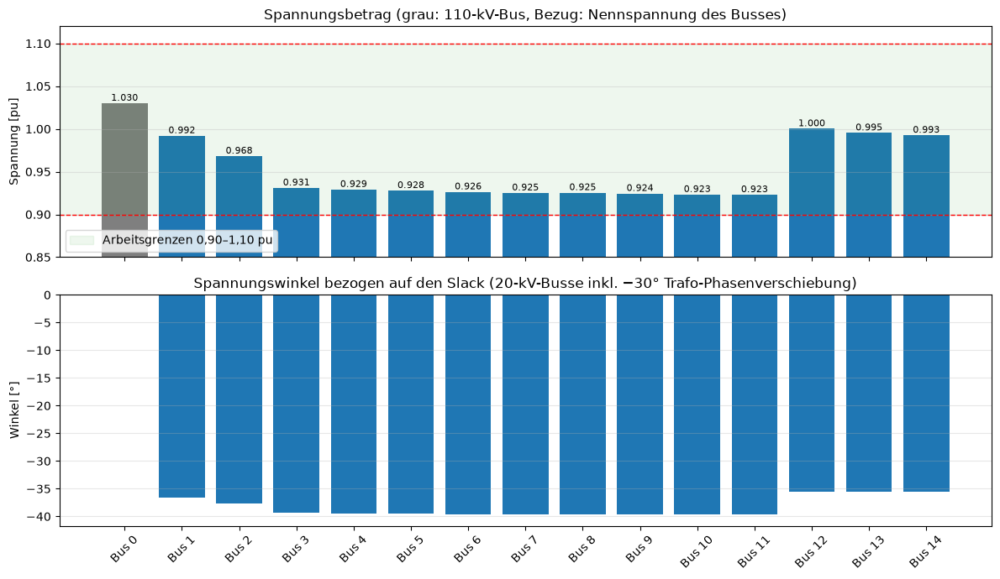

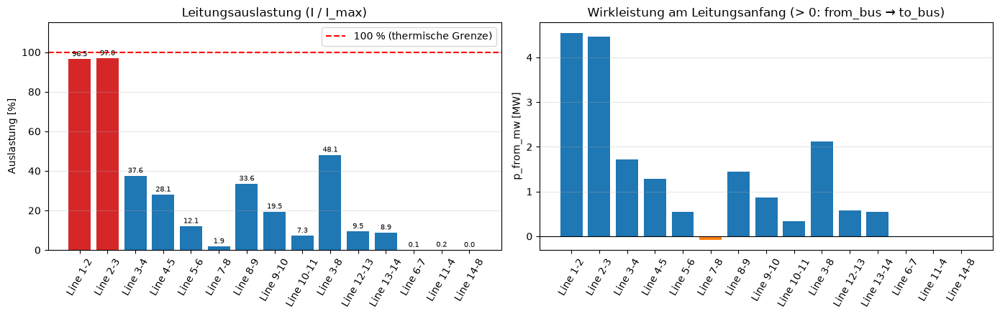

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
names = bus_res.index
c = ["tab:gray" if u > 100 else "tab:blue" for u in bus_res["U_n [kV]"]]
axes[0].bar(names, bus_res.vm_pu, color=c)
axes[0].axhspan(0.9, 1.1, color="tab:green", alpha=0.08, label="Arbeitsgrenzen 0,90–1,10 pu")
for v in (0.9, 1.1):
    axes[0].axhline(v, color="red", ls="--", lw=1)
for x, v in enumerate(bus_res.vm_pu):
    axes[0].text(x, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)
axes[0].set_ylim(0.85, 1.12)
axes[0].set_ylabel("Spannung [pu]")
axes[0].set_title("Spannungsbetrag (grau: 110-kV-Bus, Bezug: Nennspannung des Busses)")
axes[0].legend(loc="lower left")
axes[1].bar(names, bus_res.va_degree, color=c)
axes[1].set_ylabel("Winkel [°]")
axes[1].set_title("Spannungswinkel bezogen auf den Slack (20-kV-Busse inkl. −30° Trafo-Phasenverschiebung)")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
lr = base["line"]
col = ["black" if v > 100 else "tab:red" if v > 80 else "tab:blue" for v in lr.loading_percent]
axes[0].bar(lr.index, lr.loading_percent, color=col)
axes[0].axhline(100, color="red", ls="--", lw=1.5, label="100 % (thermische Grenze)")
for x, v in enumerate(lr.loading_percent):
    axes[0].text(x, v + 1.5, f"{v:.1f}", ha="center", fontsize=7)
axes[0].set_ylim(0, 115)
axes[0].set_ylabel("Auslastung [%]")
axes[0].set_title("Leitungsauslastung (I / I_max)")
axes[0].legend(loc="upper right")
axes[1].bar(lr.index, lr.p_from_mw, color=["tab:orange" if v < 0 else "tab:blue" for v in lr.p_from_mw])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("p_from_mw [MW]")
axes[1].set_title("Wirkleistung am Leitungsanfang (> 0: from_bus → to_bus)")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Netzplan** mit Spannungen, Auslastungen und Richtung des Wirkleistungsflusses (schwarze Pfeile auf Leitungen und Trafos):

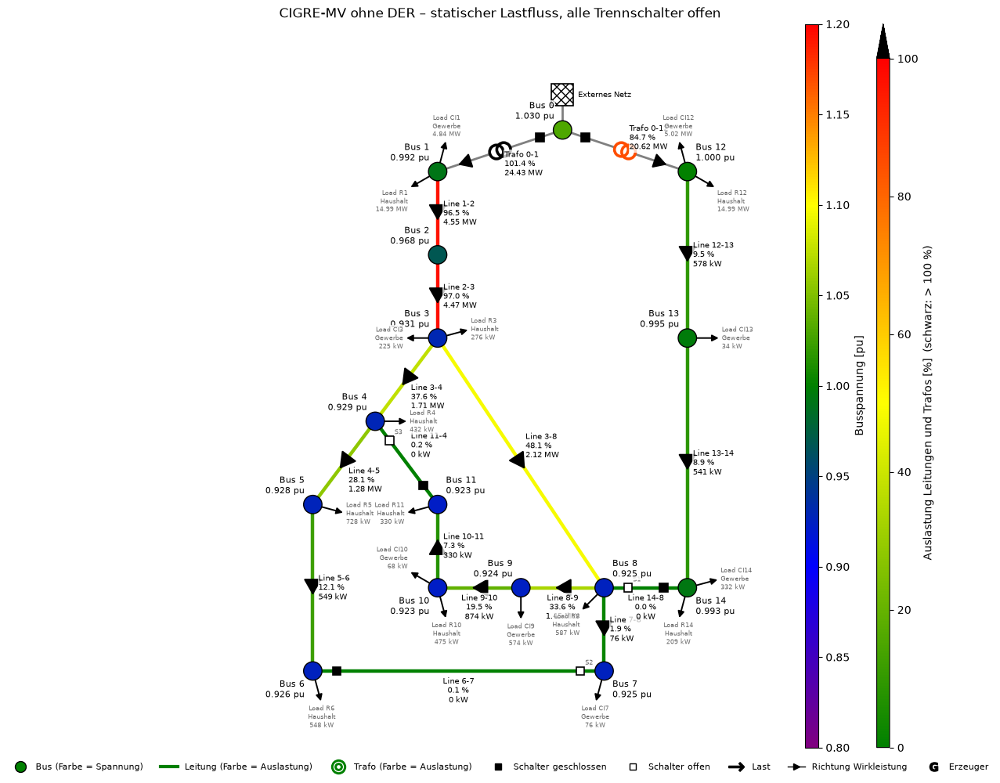

In [26]:
netplan.plot_static(base["net"], title="CIGRE-MV ohne DER – statischer Lastfluss, alle Trennschalter offen");

**Kennzahlen und Interpretation (statisch, Baseline):**

| Größe | Wert |
|---|---|
| Konvergenz | ja, 4 Iterationen |
| Last / Bezug aus 110 kV | 44,74 MW / 45,05 MW (Q: 16,3 Mvar) |
| Verluste | 0,30 MW = 0,68 % der Last (Leitungen 0,23 MW, Trafos 0,07 MW) |
| niedrigste Spannung | 0,923 pu an Bus 11 (−7,7 %) |
| höchste Leitungsauslastung | 97,0 % Line 2-3, 96,5 % Line 1-2 |
| Trafoauslastung | **101,4 %** Trafo 0-1, 84,7 % Trafo 0-12 |

- **Spannungen:** Alle Busse liegen in den Arbeitsgrenzen 0,90 bis 1,10 pu. In Abgang 1 fällt die Spannung aber um gut 7 % ab, vor allem auf den langen Kabeln Line 1-2 und Line 2-3 (zusammen 7,2 km), über die fast die gesamte Last hinter Bus 2 fließt. Abgang 2 ist schwach belastet und bleibt nahe 1,0 pu.
- **Winkel:** Ohne die −30° der Trafo-Schaltgruppe liegen die 20-kV-Busse 6,6° (Bus 1) bis 9,7° (Bus 11) hinter dem Slack. Der Winkel wächst mit der übertragenen Wirkleistung und der Reaktanz bis zum Bus. Den größten Anteil liefert die Trafo-Reaktanz (vk = 12 %).
- **Auslastung:** Line 1-2 und Line 2-3 sind fast voll ausgelastet. **Trafo 0-1 ist mit 101,4 % leicht überlastet**, weil er neben Abgang 1 die großen Ersatzlasten an Bus 1 trägt (24,4 MW, 9,2 Mvar).
- **Flussrichtung:** Alle Wirkleistung fließt von der 110-kV-Seite zu den Lasten. Line 7-8 hat ein negatives `p_from_mw`, weil die Leitung von Bus 7 nach Bus 8 definiert ist, die Last an Bus 7 aber von Bus 8 aus versorgt wird.
- **Einordnung:** Der statische Fall setzt alle 18 Lasten gleichzeitig auf ihre Höchstleistung (Gleichzeitigkeitsgrad 1). Das ist ein bewusst ungünstiger Grenzfall. Wie oft er im Jahresverlauf annähernd erreicht wird, zeigt die Zeitreihe in Abschnitt 4.

## 3 Alle Schalterstellungen S1–S3 (statisch)

Jeder der drei Trennschalter kann offen oder geschlossen sein, das ergibt 2³ = 8 Schaltzustände. Bezeichnung: Schlüssel aus drei Ziffern in der Reihenfolge S1, S2, S3 mit 1 = geschlossen. In Tabellen und Diagrammen steht die Kurzform (z. B. „S1+S3 zu“).

| Schlüssel | Kurzform | Wirkung |
|---|---|---|
| 000 | alle offen | Normalbetrieb, strahlenförmig (Baseline) |
| 001 | S3 zu | Masche 3 – 4 – 11 – 10 – 9 – 8 – 3 in Abgang 1 geschlossen |
| 010 | S2 zu | Masche 3 – 4 – 5 – 6 – 7 – 8 – 3 in Abgang 1 geschlossen |
| 011 | S2+S3 zu | beide Maschen in Abgang 1 geschlossen |
| 100 | S1 zu | Abgang 1 und 2 über Line 14-8 gekuppelt; Masche über beide Trafos und die 110-kV-Sammelschiene |
| 101, 110, 111 | Kombinationen | Kupplung und Maschen gleichzeitig |

**Was verändert wird und was konstant bleibt:** Für jeden Zustand wird das Netz mit `baseline_net()` neu erzeugt und nur die Schalterstellung geändert. Konstant bleiben alle Lasten (Bemessungswerte), die Slack-Spannung (1,03 pu), die Leitungs- und Trafoparameter und das Lastflussverfahren.

In [27]:
static = sz.statisch_alle(baseline_net)
sz.konvergenz(static)

,Schaltzustand,konvergiert,Iterationen,Hinweis
Schlüssel,,,,
000,S1 offen · S2 offen · S3 offen,ja,4,
001,S1 offen · S2 offen · S3 zu,ja,4,
010,S1 offen · S2 zu · S3 offen,ja,4,
011,S1 offen · S2 zu · S3 zu,ja,4,
100,S1 zu · S2 offen · S3 offen,ja,3,
101,S1 zu · S2 offen · S3 zu,ja,3,
110,S1 zu · S2 zu · S3 offen,ja,3,
111,S1 zu · S2 zu · S3 zu,ja,3,


Alle acht Zustände konvergieren. Damit sind alle folgenden Werte gültige Lastflussergebnisse.

**Leistungsbilanz und Kennzahlen je Schaltzustand:**

In [28]:
bil = sz.bilanzen(static)
bil_num = bil.drop(columns=["Bus U min", "Leitung mit max"]).astype(float)
display(plots.table(bil_num.T, decimals=3))
bil[["Bus U min", "Leitung mit max"]].T

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Last P [MW],44.742,44.742,44.742,44.742,44.742,44.742,44.742,44.742
Erzeugung P [MW],0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Bezug ext. Netz P [MW],45.046,45.041,45.046,45.041,44.968,44.967,44.967,44.966
Bezug ext. Netz Q [Mvar],16.341,16.333,16.341,16.332,16.080,16.080,16.077,16.076
Verluste Leitungen [MW],0.234,0.229,0.234,0.229,0.157,0.157,0.156,0.155
Verluste Trafos [MW],0.070,0.070,0.070,0.070,0.069,0.069,0.069,0.069
Verluste gesamt [MW],0.304,0.299,0.304,0.299,0.226,0.225,0.225,0.224
Verluste [% der Last],0.679,0.669,0.678,0.667,0.504,0.504,0.502,0.500
U min [pu],0.923,0.926,0.923,0.926,0.957,0.956,0.957,0.958
Leitung max [%],96.959,96.827,96.956,96.812,51.528,51.730,50.993,51.354


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus U min,Bus 11,Bus 6,Bus 11,Bus 6,Bus 6,Bus 6,Bus 11,Bus 6
Leitung mit max,Line 2-3,Line 2-3,Line 2-3,Line 2-3,Line 2-3,Line 2-3,Line 2-3,Line 2-3


**Spannungsbetrag und Spannungswinkel an allen Bussen** (Zeilen = Busse, Spalten = Schaltzustände):

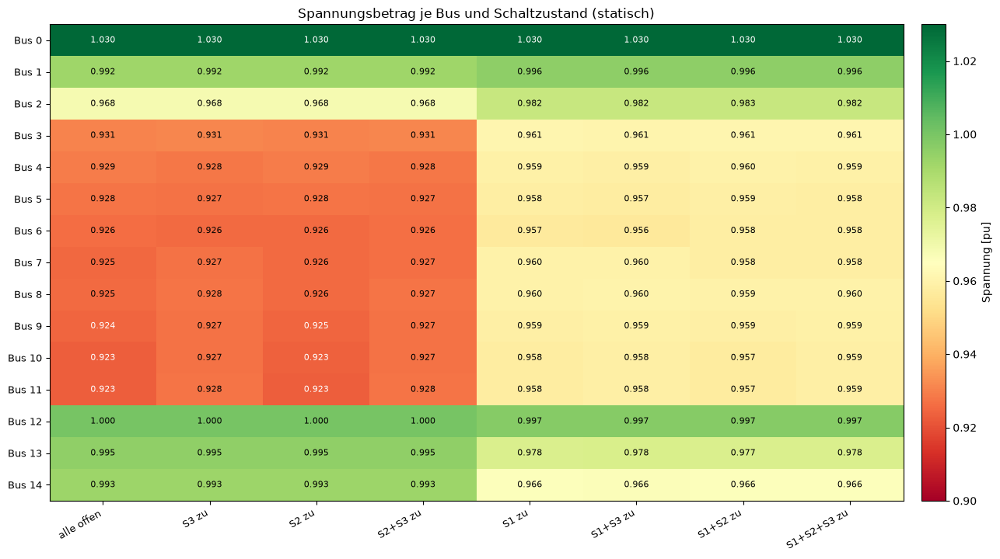

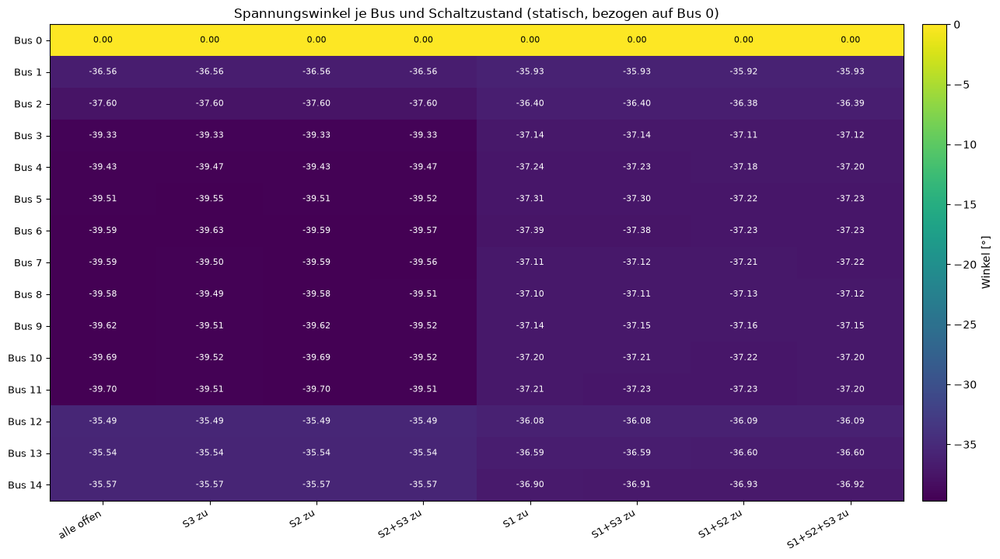

In [29]:
vm_all = sz.vergleich(static, "vm_pu")
va_all = sz.vergleich(static, "va_degree")
sz.heatmap(vm_all, "Spannungsbetrag je Bus und Schaltzustand (statisch)", "Spannung [pu]",
           cmap="RdYlGn", vmin=0.90, vmax=1.03, fmt="{:.3f}")
plt.show()
sz.heatmap(va_all, "Spannungswinkel je Bus und Schaltzustand (statisch, bezogen auf Bus 0)", "Winkel [°]",
           cmap="viridis", fmt="{:.2f}")
plt.show()

**Leitungen:** Auslastung (fett umrandet: über 100 %), Wirkleistung am Leitungsanfang (Vorzeichen = Richtung) und Strom:

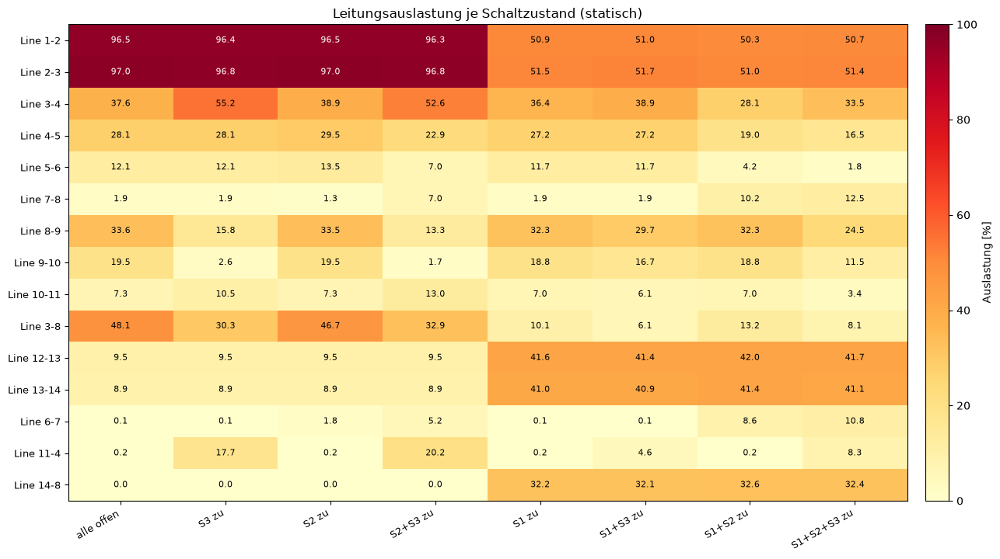

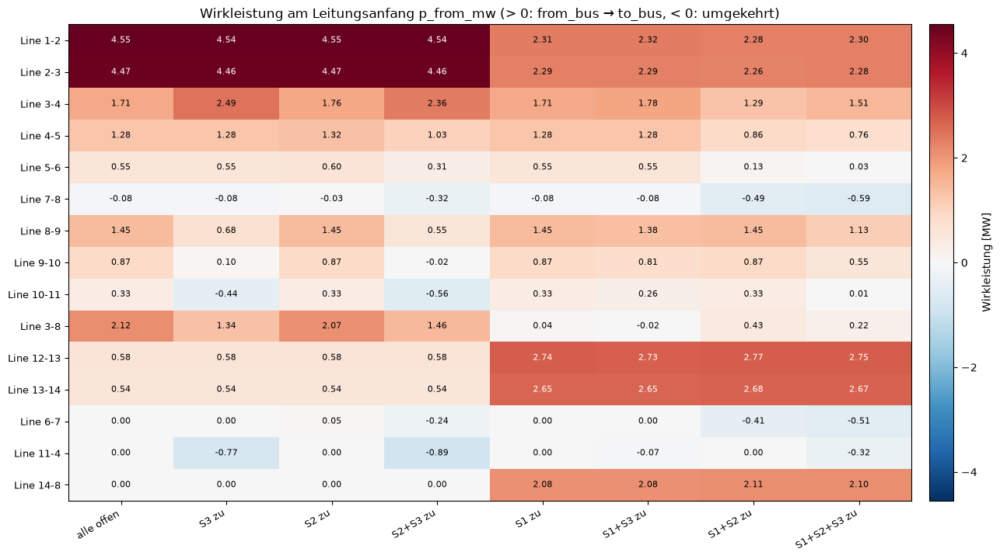

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,139.9,139.7,139.9,139.7,73.7,74.0,72.9,73.5
Line 2-3,140.6,140.4,140.6,140.4,74.7,75.0,73.9,74.5
Line 3-4,54.5,80.0,56.5,76.2,52.8,56.4,40.8,48.6
Line 4-5,40.7,40.8,42.7,33.2,39.4,39.5,27.5,24.0
Line 5-6,17.6,17.6,19.6,10.1,17.0,17.0,6.0,2.5
Line 7-8,2.8,2.8,1.9,10.2,2.7,2.7,14.8,18.1
Line 8-9,48.6,22.9,48.6,19.3,46.9,43.0,46.9,35.5
Line 9-10,28.2,3.8,28.2,2.5,27.2,24.3,27.2,16.7
Line 10-11,10.6,15.3,10.6,18.9,10.2,8.9,10.2,4.9
Line 3-8,69.8,44.0,67.7,47.7,14.6,8.9,19.2,11.8


In [30]:
ll_all = sz.vergleich(static, "loading_percent")
p_all = sz.vergleich(static, "p_from_mw")
i_all = sz.vergleich(static, "i_ka") * 1000
sz.heatmap(ll_all, "Leitungsauslastung je Schaltzustand (statisch)", "Auslastung [%]",
           cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
lim = np.nanmax(np.abs(p_all.to_numpy()))
sz.heatmap(p_all, "Wirkleistung am Leitungsanfang p_from_mw (> 0: from_bus → to_bus, < 0: umgekehrt)",
           "Wirkleistung [MW]", cmap="RdBu_r", vmin=-lim, vmax=lim, fmt="{:.2f}")
plt.show()
plots.table(i_all, decimals=1)

**Transformatoren und Verluste:**

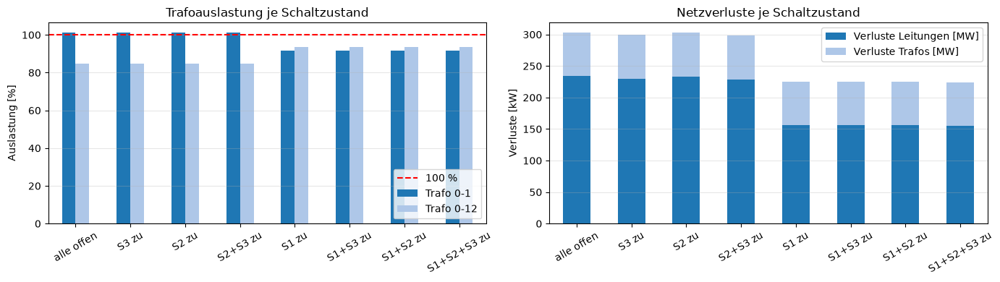

In [31]:
tr_all = pd.concat({"Auslastung [%]": sz.vergleich(static, "trafo_loading"),
                    "P OS [MW]": sz.vergleich(static, "p_hv_mw")})
display(plots.table(tr_all, decimals=2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sz.vergleich(static, "trafo_loading").T.plot.bar(ax=axes[0])
axes[0].axhline(100, color="red", ls="--", lw=1.5, label="100 %")
axes[0].set_ylabel("Auslastung [%]")
axes[0].set_title("Trafoauslastung je Schaltzustand")
axes[0].legend(loc="lower right")
(bil_num[["Verluste Leitungen [MW]", "Verluste Trafos [MW]"]] * 1000).plot.bar(stacked=True, ax=axes[1])
axes[1].set_ylabel("Verluste [kW]")
axes[1].set_title("Netzverluste je Schaltzustand")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Netzpläne aller Schaltzustände.** Die Pfeile zeigen die Richtung des Wirkleistungsflusses. Lasten und Erzeuger sind zur besseren Übersicht ausgeblendet.

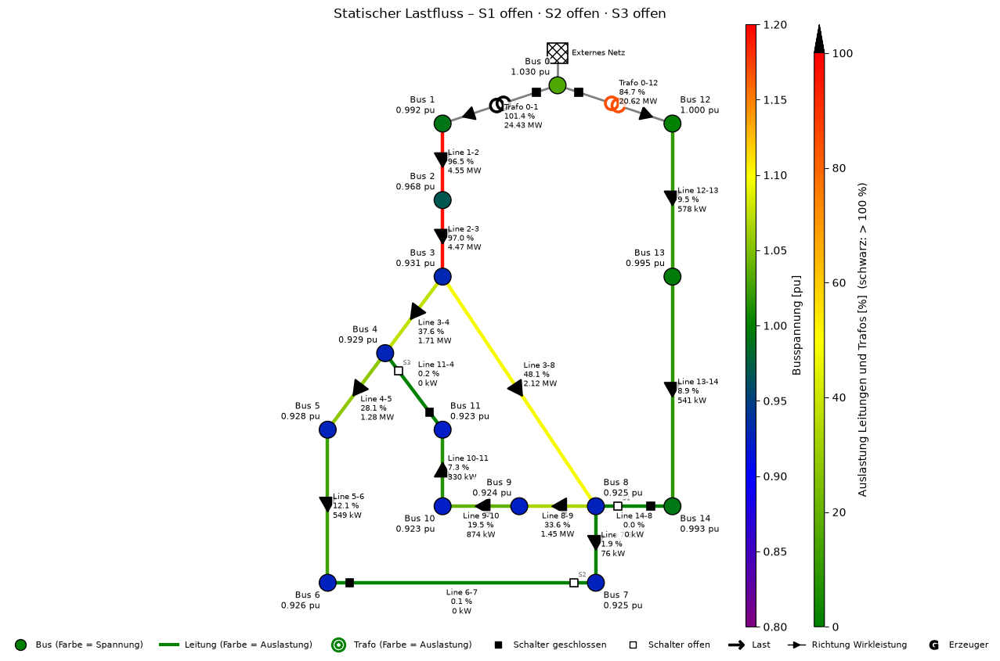

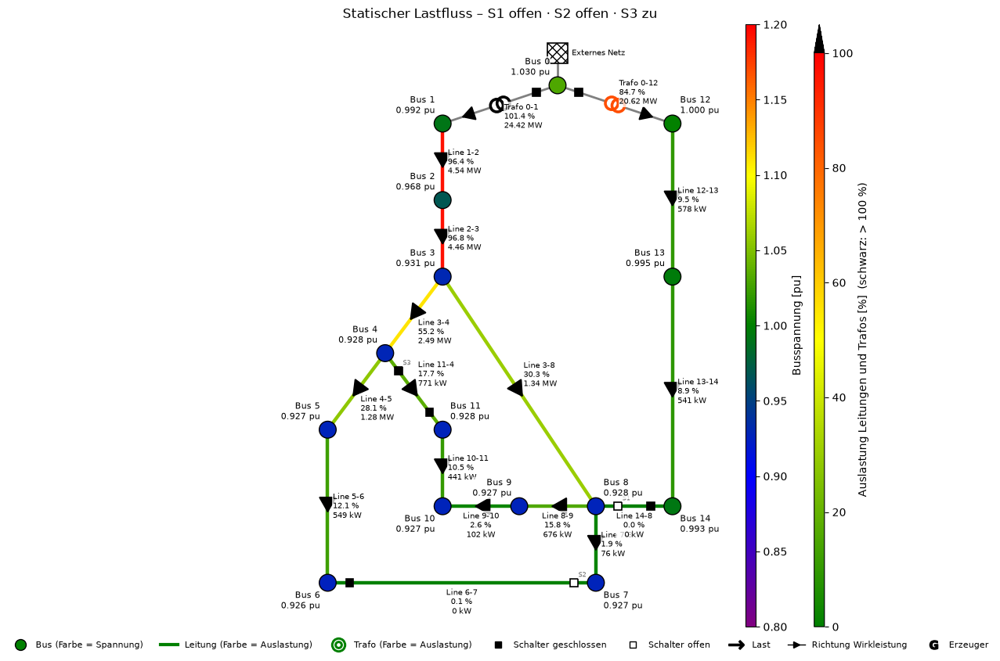

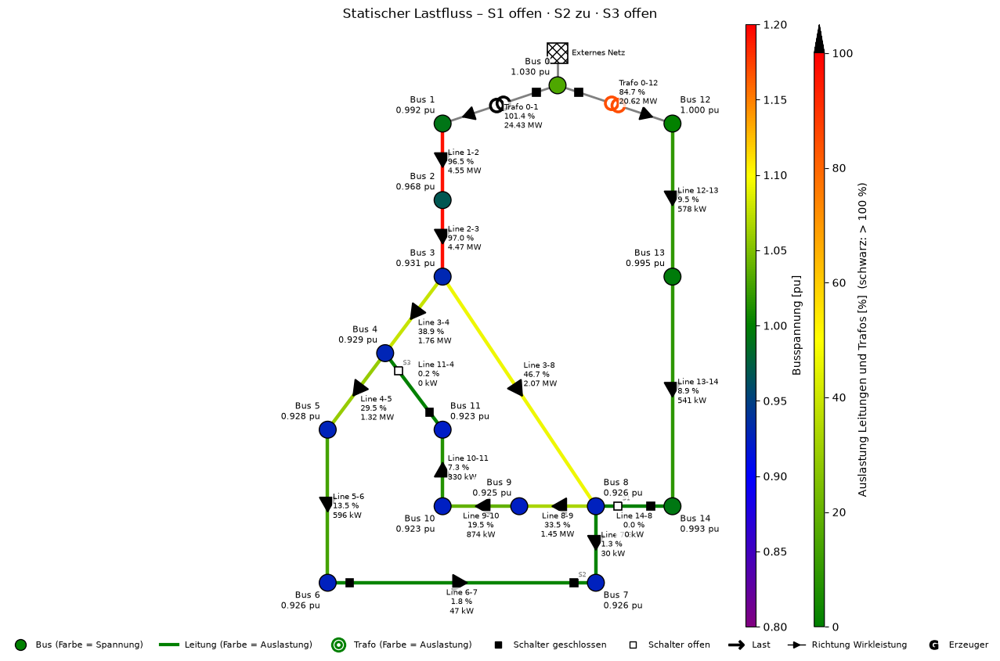

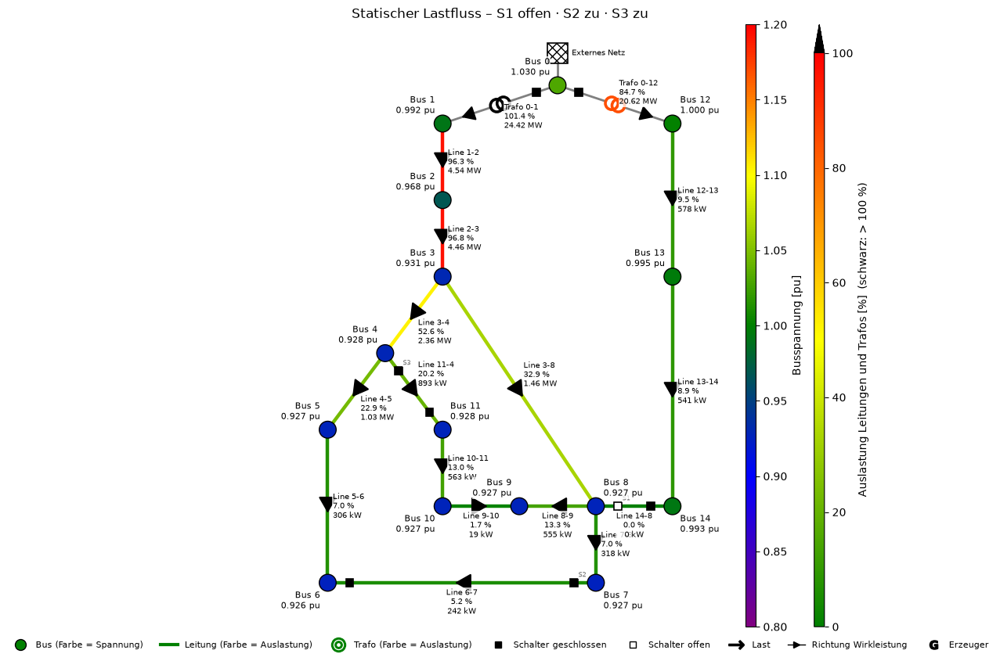

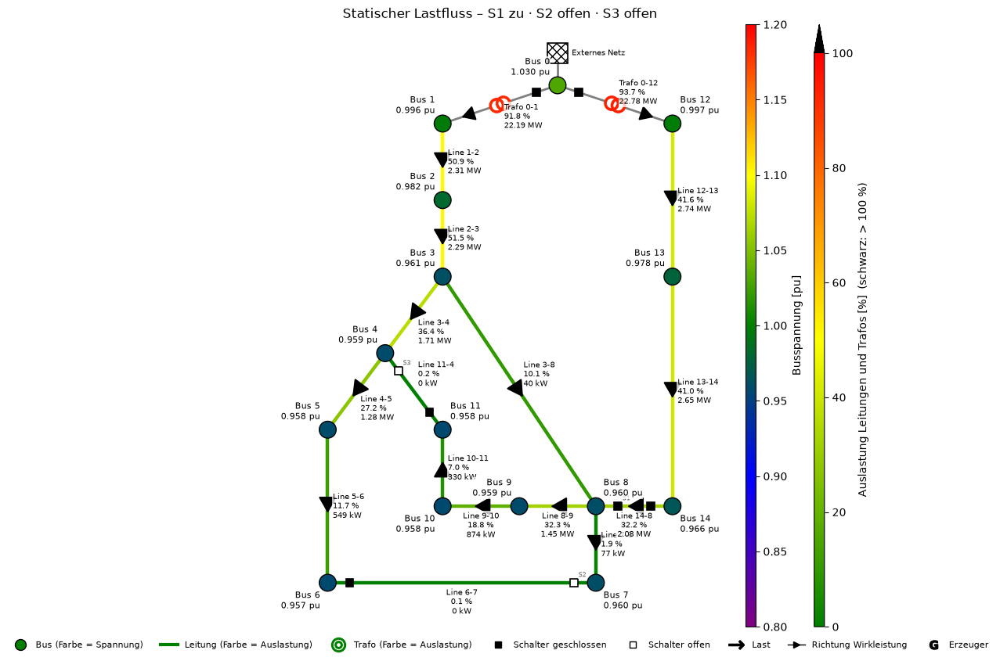

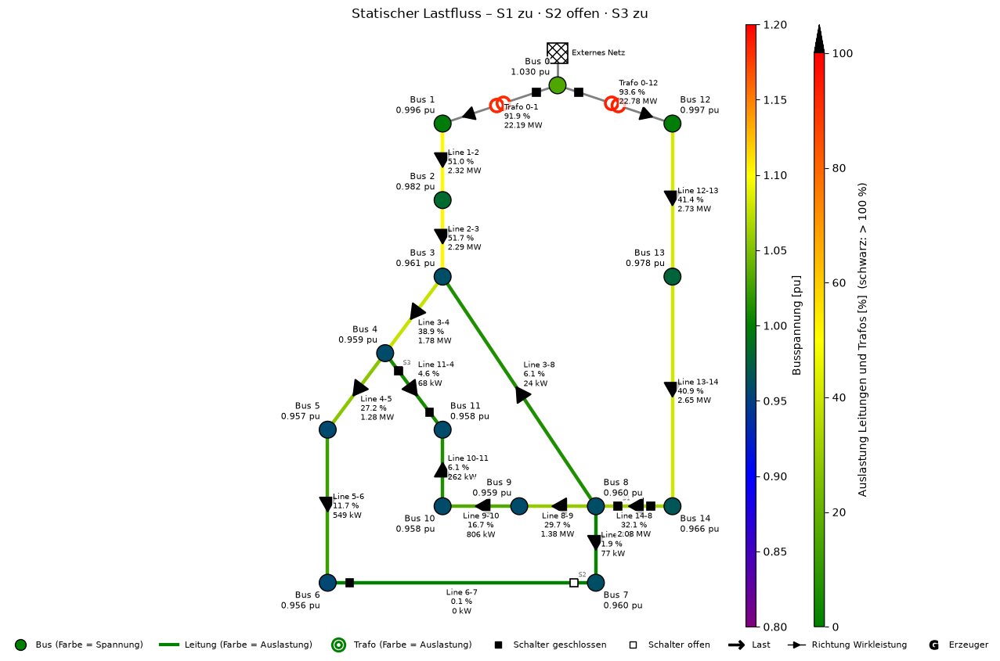

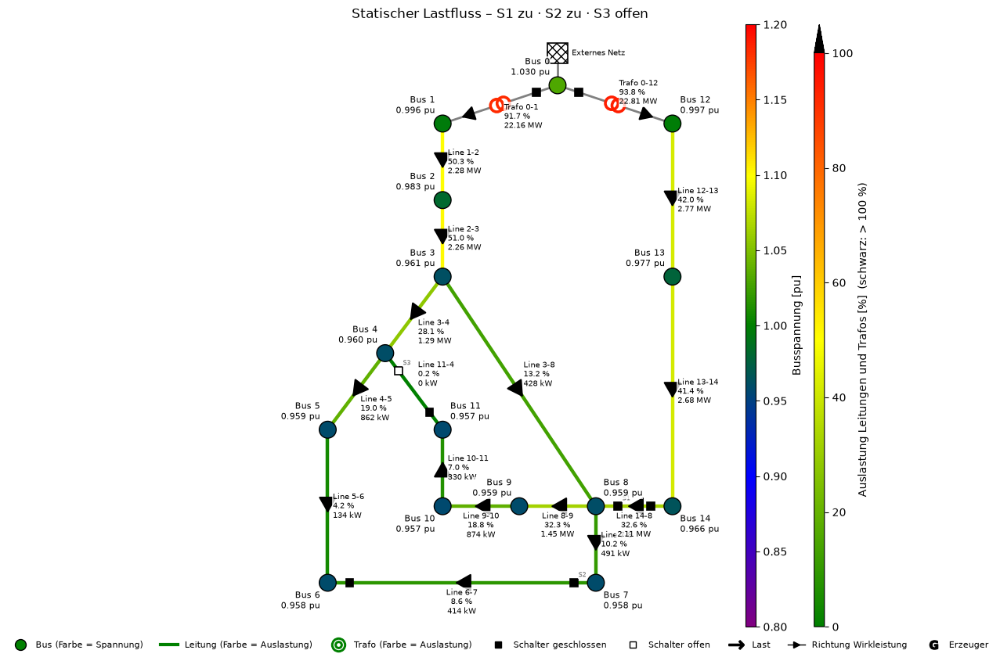

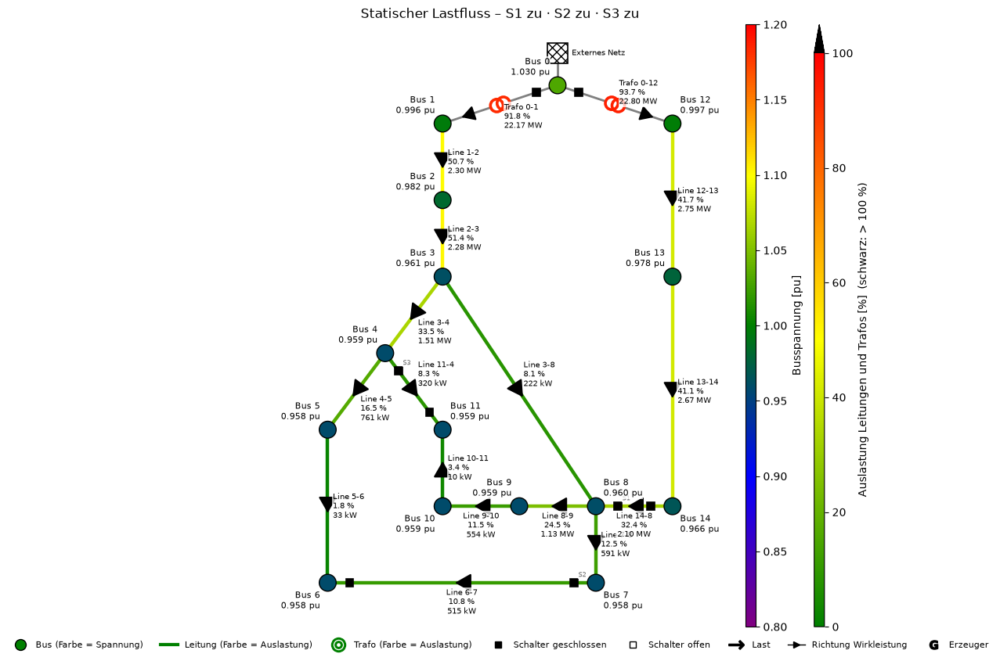

In [32]:
for key, r in static.items():
    netplan.plot_static(r["net"], title=f"Statischer Lastfluss – {sz.label(key)}", elements=False, figsize=(12, 10))

**Interpretation (statisch):**

- **S1 hat den größten Einfluss.** Mit geschlossenem S1 übernimmt Trafo 0-12 über die Freileitungen und Line 14-8 rund 2,1 MW von Abgang 1. Line 1-2 und Line 2-3 sinken von 97 % auf etwa 51 %, die niedrigste Spannung steigt von 0,923 auf 0,957 pu und die Verluste sinken um rund 26 % (0,30 → 0,23 MW). Trafo 0-1 wird von 101,4 % auf 91,8 % entlastet, Trafo 0-12 steigt von 84,7 % auf 93,7 %. Die Last verteilt sich also gleichmäßiger auf beide Transformatoren.
- **Preis der Kupplung:** In Abgang 2 sinkt die Spannung (Bus 14: 0,993 → 0,966 pu) und die Freileitungen werden mit gut 40 % statt 9 % belastet. Mit S1 entsteht außerdem eine Masche über beide Transformatoren und die 110-kV-Sammelschiene. Über sie fließt die Leistung nach den Impedanzen und nicht mehr nach einem festen Versorgungsweg. Bei einem Fehler wären beide Abgänge betroffen und die Kurzschlussleistung an den 20-kV-Sammelschienen steigt. Deshalb werden solche Kupplungen im Normalbetrieb offen gehalten [16].
- **S2 und S3 wirken nur innerhalb von Abgang 1.** Sie verändern die Aufteilung zwischen den Ästen über Bus 4 und Bus 8, aber nicht die Leistung durch Line 1-2 und Line 2-3. Deshalb bleibt deren Auslastung ohne S1 bei rund 97 %. Am stärksten verschiebt S3: Line 3-8 sinkt von 48 % auf 30 %, Line 3-4 steigt von 38 % auf 55 %. Die niedrigste Spannung verbessert sich nur um bis zu 0,003 pu.
- **Flussumkehr durch Schalten:** Mit geschlossenen Maschen ändern einige Leitungen ihre Flussrichtung, z. B. Line 10-11 mit S3 (Bus 11 wird dann von Bus 4 aus versorgt) und Line 9-10 mit S2+S3. Das zeigt sich in der Heatmap von `p_from_mw` als Vorzeichenwechsel.
- **Winkel:** Mit S1 nähern sich die Winkel beider Abgänge an (rund −37°). Weil beide Abgänge dann über die Masche gekoppelt sind, gleichen sich die Winkeldifferenzen aus.
- **Grenzen:** In keinem Zustand wird das Band 0,90 bis 1,10 pu verletzt. Eine thermische Überlastung tritt nur bei Trafo 0-1 ohne S1 auf (101,4 %).

## 4 Alle Schalterstellungen als Zeitreihe

Der statische Fall ist nur ein Betriebspunkt. Für den Jahresverlauf wird jeder Schaltzustand mit der Simulationssoftware über 12 typische Wochen stündlich gerechnet (12 × 168 = 2016 Lastflüsse je Zustand).

**Modellannahmen der Zeitreihe:**

- **Lasten und Erzeuger:** Es werden nur die 18 Lasten verwendet, die im CIGRE-Netz bereits enthalten sind. Es werden keine Lasten oder Erzeuger hinzugefügt. In `with_der=False` gibt es keine Erzeuger.
- **Profilzuordnung:** Die Zuordnung folgt den Namen aus [13] und ist nicht zufällig. `Load R…` (*residential*) erhält das BDEW-Haushaltsprofil H25 mit Dynamisierung, `Load CI…` (*commercial/industrial*) das Gewerbeprofil G25. Das übernimmt `assignProfilesByName()`.
- **Skalierung:** Der Wert `p_mw` aus [13] wird als **höchste Stundenleistung des Jahres** interpretiert. Der Jahresverbrauch jeder Last wird so berechnet, dass das Profil im Jahr 2025 genau einmal diesen Wert erreicht. Beispiel: `Load R1` (14,994 MW) entspricht rund 66 GWh/a. Die Blindleistung folgt aus dem Leistungsfaktor der Last in [13] (Wohngebiete 0,97 bzw. 0,98, Gewerbe 0,85 bzw. 0,95).
- **Gleichzeitigkeit:** Haushalte haben ihre Spitze am Winterabend, Gewerbe an Werktagen tagsüber. Die Summe aller Lasten erreicht deshalb nie die 44,7 MW des statischen Falls.

Mit `sim.ONLY_RUN_IF_CHANGED = True` (siehe Importe) werden die acht Zeitreihen nur beim ersten Durchlauf gerechnet (je etwa 40 s). Danach werden die gespeicherten Ergebnisse geladen.

In [33]:
baseline = sim.init("w4_baseline", baseline_net(), overwrite=True, assignProfiles=True)
baseline.elements("load")

18 Profile zugeordnet: HAUSHALT: 10, GEWERBE: 8


,Typ,Tabelle,Index,Bus,Profil,Skalierung
Name,,,,,,
Load R1,Last,load,0,Bus 1,HAUSHALT,66.157.911 kWh/a
Load R3,Last,load,1,Bus 3,HAUSHALT,1.219.778 kWh/a
Load R4,Last,load,2,Bus 4,HAUSHALT,1.904.566 kWh/a
Load R5,Last,load,3,Bus 5,HAUSHALT,3.209.943 kWh/a
Load R6,Last,load,4,Bus 6,HAUSHALT,2.418.157 kWh/a
Load R8,Last,load,5,Bus 8,HAUSHALT,2.589.354 kWh/a
Load R10,Last,load,6,Bus 10,HAUSHALT,2.097.163 kWh/a
Load R11,Last,load,7,Bus 11,HAUSHALT,1.455.174 kWh/a
Load R12,Last,load,8,Bus 12,HAUSHALT,66.157.911 kWh/a


In [34]:
ts = sz.zeitreihe_alle(baseline, prefix="w4_baseline")

Simulation 'w4_baseline_000': unverändert seit dem Lauf vom 2026-11-08T20:21:27 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_001': unverändert seit dem Lauf vom 2026-11-08T20:22:54 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_010': unverändert seit dem Lauf vom 2026-11-08T20:24:27 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_011': unverändert seit dem Lauf vom 2026-11-08T20:25:58 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_100': unverändert seit dem Lauf vom 2026-11-08T20:27:01 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_101': unverändert seit dem Lauf vom 2026-11-08T20:27:57 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_baseline_110': unverändert seit dem Lauf vom 2026-11-08

**Konvergenz und Kennzahlen je Schaltzustand:**

In [35]:
kz = sz.kennzahlen(ts)
text_cols = ["konvergiert", "Bus U min", "Zeitpunkt U min", "Leitung", "Zeitpunkt Leitung max"]
display(kz[text_cols])
plots.table(kz.drop(columns=text_cols).astype(float).T, decimals=3)

,konvergiert,Bus U min,Zeitpunkt U min,Leitung,Zeitpunkt Leitung max
alle offen,2016/2016,Bus 11,Fri 10.01. 18:00,Line 2-3,Sun 12.01. 18:00
S3 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Sun 12.01. 18:00
S2 zu,2016/2016,Bus 11,Fri 10.01. 18:00,Line 2-3,Sun 12.01. 18:00
S2+S3 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Sun 12.01. 18:00
S1 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Fri 10.01. 18:00
S1+S3 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Fri 10.01. 18:00
S1+S2 zu,2016/2016,Bus 11,Fri 10.01. 18:00,Line 2-3,Fri 10.01. 18:00
S1+S2+S3 zu,2016/2016,Bus 6,Fri 10.01. 18:00,Line 2-3,Fri 10.01. 18:00


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
U min [pu],0.949,0.950,0.949,0.951,0.973,0.973,0.975,0.975
U max 20 kV [pu],1.024,1.024,1.024,1.024,1.024,1.025,1.024,1.025
Stunden U < 0.9,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden U > 1.1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Leitung max [%],78.638,78.584,78.637,78.563,41.096,41.152,40.536,40.792
Trafo max [%],82.694,82.682,82.693,82.678,75.685,75.678,75.798,75.745
Stunden Trafo > 100 %,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Verluste [MWh],140.880,139.118,140.818,138.825,107.526,107.425,107.044,106.603
Verluste [% der Last],0.322,0.318,0.322,0.318,0.246,0.246,0.245,0.244


Alle 8 × 2016 Lastflüsse sind konvergiert. Es gibt also keine Zeitpunkte, die gesondert interpretiert werden müssen.

**Niedrigste Spannung und höchste Winkelabweichung je Bus über das Jahr:**

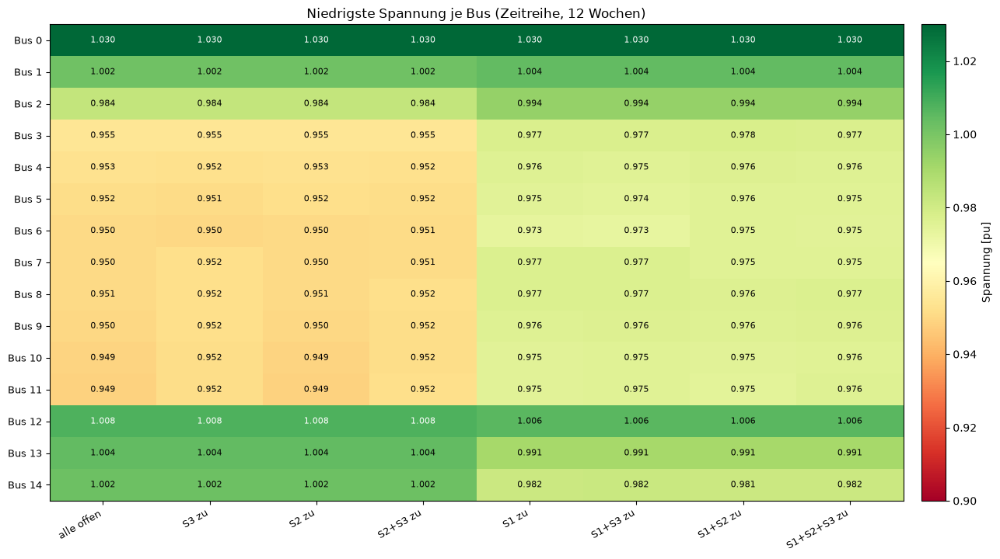

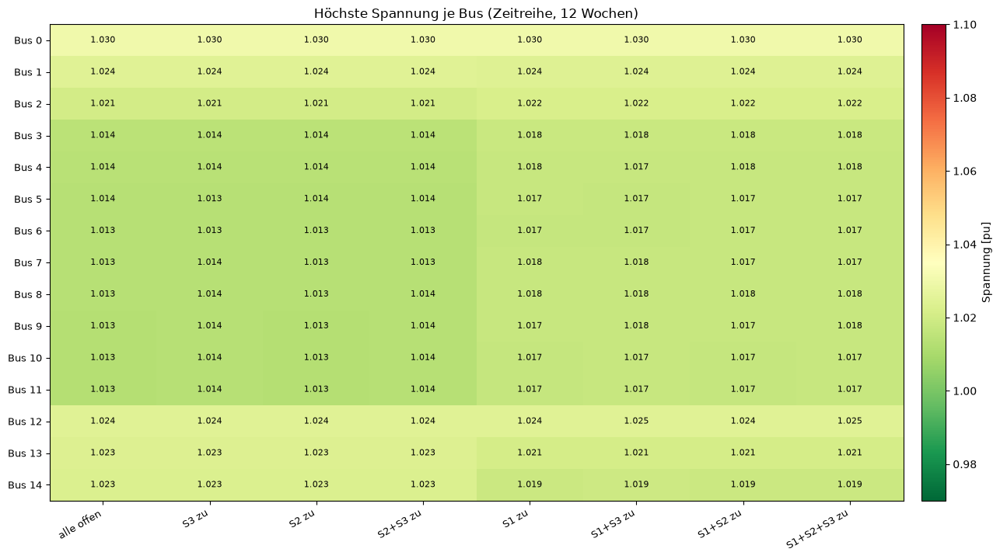

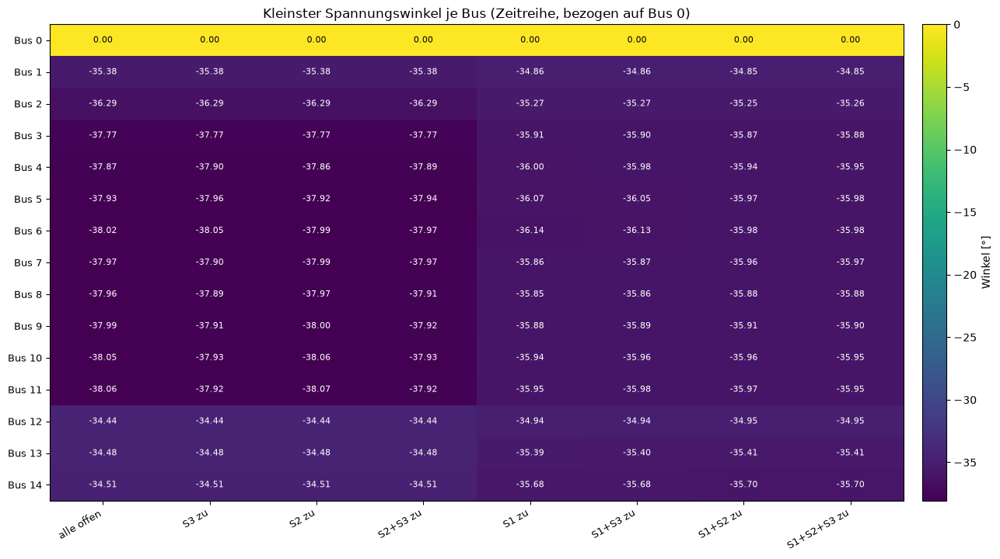

In [36]:
sz.heatmap(sz.je_element(ts, "vm_pu", "min"), "Niedrigste Spannung je Bus (Zeitreihe, 12 Wochen)",
           "Spannung [pu]", cmap="RdYlGn", vmin=0.90, vmax=1.03, fmt="{:.3f}")
plt.show()
sz.heatmap(sz.je_element(ts, "vm_pu", "max"), "Höchste Spannung je Bus (Zeitreihe, 12 Wochen)",
           "Spannung [pu]", cmap="RdYlGn_r", vmin=0.97, vmax=1.10, fmt="{:.3f}")
plt.show()
sz.heatmap(sz.je_element(ts, "va_degree", "min"), "Kleinster Spannungswinkel je Bus (Zeitreihe, bezogen auf Bus 0)",
           "Winkel [°]", cmap="viridis", fmt="{:.2f}")
plt.show()

**Höchste Auslastung je Leitung und Trafo über das Jahr:**

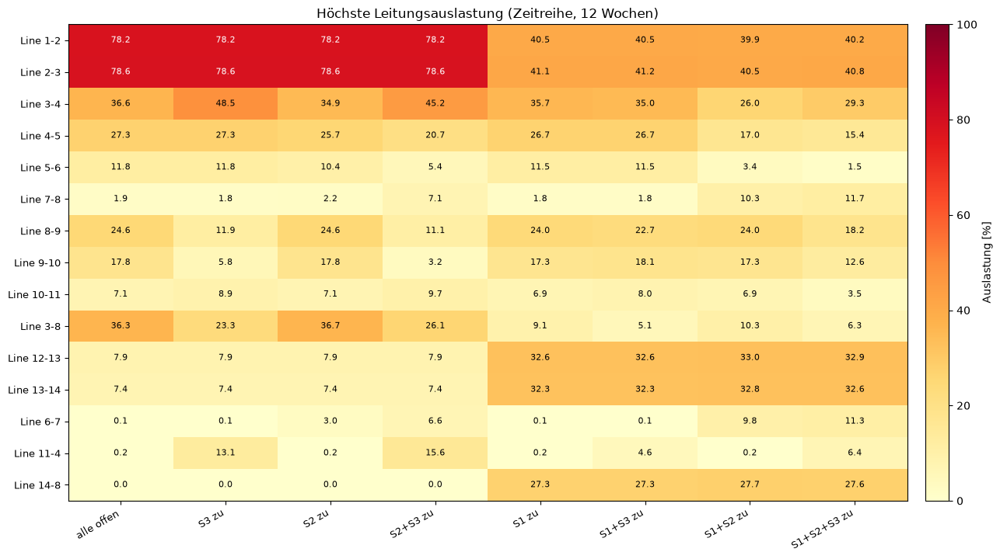

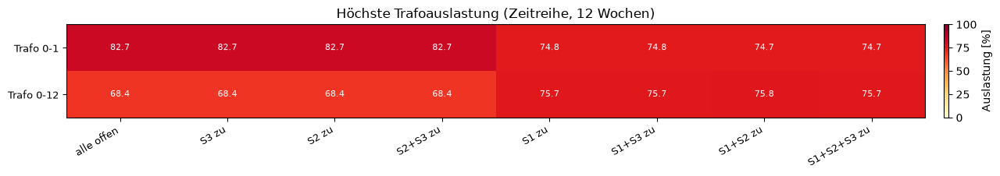

In [37]:
sz.heatmap(sz.je_element(ts, "line_loading", "max"), "Höchste Leitungsauslastung (Zeitreihe, 12 Wochen)",
           "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
sz.heatmap(sz.je_element(ts, "trafo_loading", "max"), "Höchste Trafoauslastung (Zeitreihe, 12 Wochen)",
           "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()

**Zeitverlauf in der Januarwoche** (höchste Last) für den schwächsten Bus und die beiden Transformatoren, Normalbetrieb im Vergleich zu geschlossenem S1:

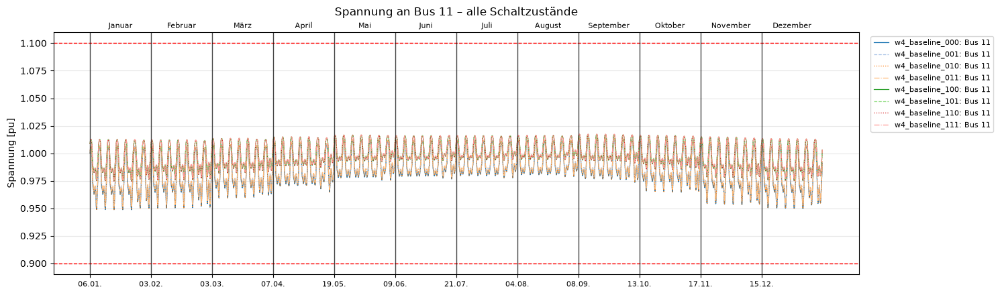

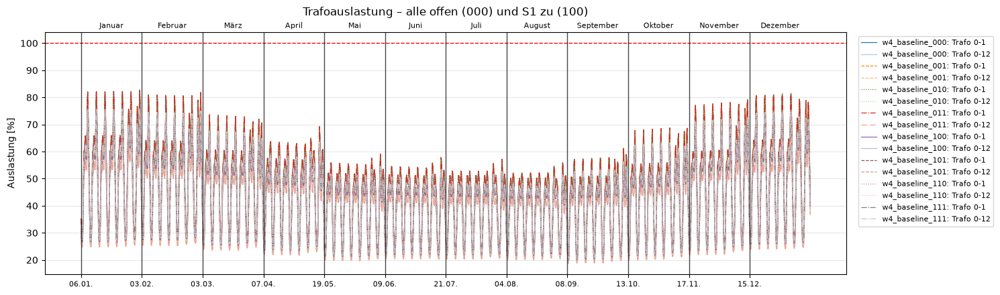

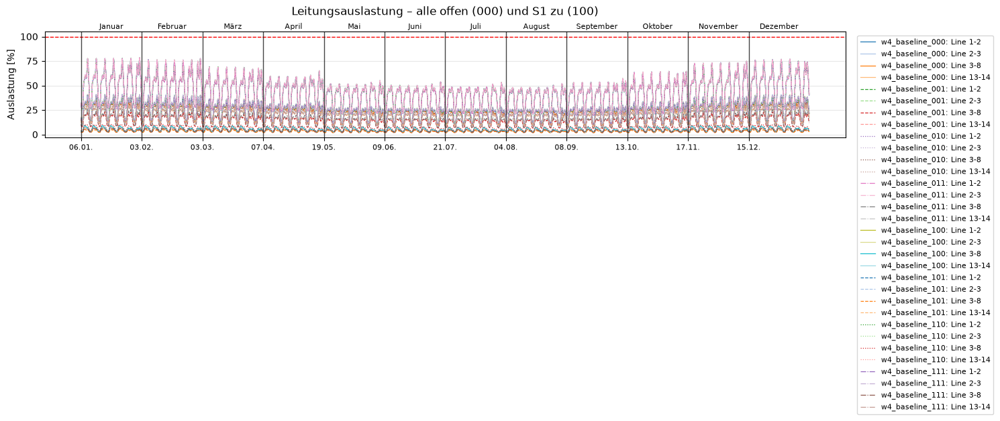

In [38]:
sim.compare([ts[k] for k in sz.KEYS], Diagram.VOLTAGE, ["Bus 11"], layout="overview",
            title="Spannung an Bus 11 – alle Schaltzustände")
sim.compare([ts[k] for k in sz.KEYS], Diagram.TRAFO_LOADING, None, layout="overview",
            title="Trafoauslastung – alle offen (000) und S1 zu (100)")
sim.compare([ts[k] for k in sz.KEYS], Diagram.LINE_LOADING, ["Line 1-2", "Line 2-3", "Line 3-8", "Line 13-14"],
            layout="overview", title="Leitungsauslastung – alle offen (000) und S1 zu (100)")

**Netzplan zum Zeitpunkt der höchsten Leitungsauslastung** im Normalbetrieb und mit geschlossenem S1:

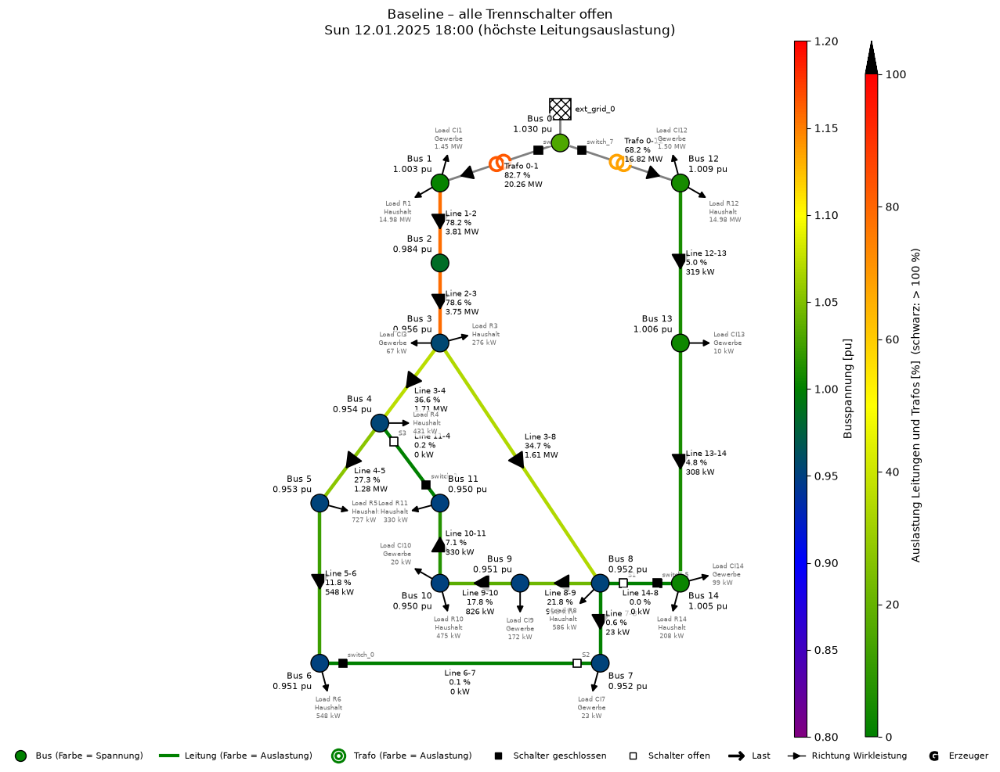

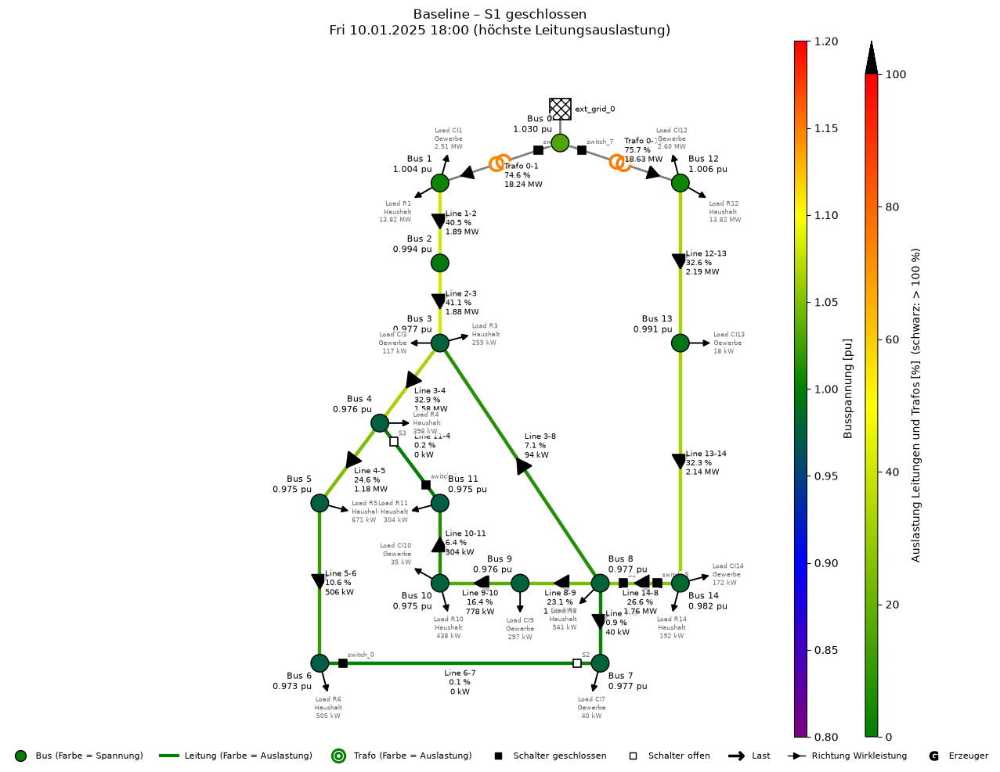

In [39]:
ts["000"].createDiagram(Diagram.NETWORK, time="max_loading", title="Baseline – alle Trennschalter offen")
ts["100"].createDiagram(Diagram.NETWORK, time="max_loading", title="Baseline – S1 geschlossen")

**Interpretation (Zeitreihe):**

- **Keine Grenzverletzung:** In keinem Schaltzustand und keiner Stunde wird das Band 0,90 bis 1,10 pu verletzt oder ein Betriebsmittel über 100 % belastet. Die niedrigste Spannung liegt im Normalbetrieb bei 0,949 pu (Bus 11, Freitag 10.01. 18:00), die höchste Leitungsauslastung bei 78,6 % (Line 2-3) und die höchste Trafoauslastung bei 82,7 % (Trafo 0-1).
- **Unterschied zum statischen Fall:** Die Zeitreihe erreicht nicht die 97 % bzw. 101 % des statischen Falls. Ursache ist die Gleichzeitigkeit: Haushalts- und Gewerbelasten haben ihre Spitzen zu unterschiedlichen Zeiten, und die Haushaltsspitze tritt nur an wenigen Winterabenden auf.
- **Wirkung der Schalter:** Das Muster des statischen Falls bestätigt sich über das ganze Jahr. S1 halbiert die Auslastung von Line 1-2 und Line 2-3 (78,6 % → 41 %), hebt die niedrigste Spannung auf 0,973 bis 0,975 pu und senkt die Verluste über die 12 Wochen von 141 MWh auf 107 MWh (−24 %). Dafür steigt die Belastung der Freileitungen in Abgang 2 auf etwa 33 % und ihre Spannung sinkt. S2 und S3 verschieben nur die Aufteilung innerhalb von Abgang 1.
- **Höchste Spannung:** Ohne Erzeuger liegt die höchste 20-kV-Spannung bei 1,024 pu in Schwachlaststunden (Nacht, Sommer) knapp unter der Slack-Spannung von 1,03 pu. Rückspeisung tritt ohne Erzeuger nicht auf.

## 5 Referenzszenario

Für alle weiteren Teilaufgaben wird folgendes Referenzszenario festgelegt:

| Größe | Festlegung | in späteren Szenarien |
|---|---|---|
| Netz | `pn.create_cigre_network_mv(with_der=False)`, Funktion `baseline_net()` | Grundlage, wird je Szenario gezielt ergänzt |
| Schalter | S1, S2, S3 offen (Schlüssel `000`); alle Kombinationen über `szenarien.py` | wird je Untersuchung über alle 8 Zustände variiert |
| externes Netz | Bus 0, 1,03 pu, 0° | konstant |
| Transformatoren | 2 × 25 MVA, 110/20 kV, vk = 12 %, ohne Stufenschalter | konstant (Stufenschalter nur am Ortsnetztrafo, Teil 3) |
| Leitungen | Parameter nach [13] | konstant, außer bei der Kapazitätserhöhung in Teil 6 |
| Lasten | 18 CIGRE-Lasten, H25 (R) bzw. G25 (CI), Jahreshöchstleistung = `p_mw` aus [13] | konstant |
| Erzeuger | keine | Windpark, Großflächen-PV, Ortsnetz (Teile 2 und 4) |
| Zeitbasis | 12 typische Wochen 2025, stündlich, 2016 Zeitpunkte | konstant |
| Grenzen | 0,90 / 1,10 pu, 100 % thermisch | Planungsband wird in Teil 3 ergänzt |
| Lastfluss | Newton-Raphson, nicht konvergierte Zeitpunkte als NaN gekennzeichnet | konstant |

Die Referenz-Zeitreihen sind als Simulationen `w4_baseline_000` bis `w4_baseline_111` gespeichert. Ein neues Szenario startet immer von einer Kopie:

```python
ref = sim.loadSimulation("w4_baseline_000")        # oder baseline aus diesem Notebook
windpark = ref.copy("w4_windpark", overwrite=True)  # Baseline der Kopie = Referenz
windpark.createElement(...)                         # nur die Änderung des Szenarios
windpark.changedElements()                          # dokumentiert, was verändert wurde
```

`changedElements()` und `changedParameters()` zeigen jederzeit, was gegenüber der Referenz verändert wurde.

In [40]:
ref = sim.loadSimulation("w4_baseline_000")
print(ref)
print("Änderungen gegenüber der Baseline:", len(ref.changedParameters()), "Parameter,", len(ref.changedElements()), "Elemente")

Simulation 'w4_baseline_000' (15 bus, 15 line, 2 trafo, 1 ext_grid, 8 switch, 18 load)
  Herkunft: w4_baseline | Änderungen: 0 | Ergebnisse: aktuell | letzter Lauf: 2026-11-08T20:21:27
Änderungen gegenüber der Baseline: 0 Parameter, 0 Elemente


## 6 Zusammenfassung und Literaturabgleich

- **Spannungsband:** Das unveränderte CIGRE-MV-Netz hält in allen 8 Schaltzuständen, statisch wie in der Zeitreihe, die Arbeitsgrenzen 0,90 bis 1,10 pu ein. DIN EN 50160 fordert für Mittelspannungsnetze, dass 99 % der 10-Minuten-Mittelwerte einer Woche innerhalb von ±10 % der vereinbarten Versorgungsspannung liegen [15]. Der Spannungsfall bis zum Ende von Abgang 1 beträgt im Normalbetrieb aber bis zu 7,7 % (statisch) bzw. 5,1 % (Zeitreihe). Für nachgelagerte Ortsnetze bleibt damit wenig Reserve. Das ist für Teil 2 und 3 (Ortsnetz, regelbarer Ortsnetztrafo) wichtig.
- **Thermische Grenzen:** Engpässe sind der Trafo 0-1 und die Kabel Line 1-2 und Line 2-3. Im statischen Grenzfall ist Trafo 0-1 leicht überlastet. In der Zeitreihe bleiben alle Betriebsmittel wegen der geringeren Gleichzeitigkeit unter 83 %.
- **Schalterstellungen:** Die Kupplung S1 entlastet Abgang 1 und senkt die Verluste deutlich, vermascht aber beide Abgänge über die 110-kV-Ebene. S2 und S3 verschieben die Last nur innerhalb von Abgang 1. Der strahlenförmige Normalbetrieb mit offenen Trennstellen entspricht der üblichen Betriebsweise von Mittelspannungsnetzen [16]. Die offenen Ringe dienen der Wiederversorgung, nicht der dauerhaften Lastaufteilung.
- **Verluste:** 0,68 % der Last im statischen Fall, 0,32 % über die Zeitreihe. Die Verluste steigen quadratisch mit dem Strom. Deshalb liegen sie im Spitzenlastfall relativ höher.
- **Baseline:** Das Referenzszenario in Abschnitt 5 legt fest, was in den späteren Teilaufgaben verändert wird und was konstant bleibt.

<a id="teil-2"></a>

---

# Task 4 – Teil 2: Unterlagertes Niederspannungs-Ortsnetz

**Ziel:** Als Ortsnetz wird das Niederspannungs-Benchmarknetz von CIGRE (`create_cigre_network_lv`) verwendet. Es wird zunächst allein berechnet (Basisdaten). Anschließend wird über eine Sensitivitätsanalyse der 20-kV-Bus des CIGRE-MV-Netzes bestimmt, an den das Ortsnetz angeschlossen wird.

## Vorgehen zur Wahl des Anschlussbusses

**Schritt 1 – Vorbelastung des MV-Netzes ohne Ortsnetz.** Zuerst wird untersucht, welche Teile des CIGRE-MV-Netzes schon ohne das Ortsnetz belastet sind (niedrige Spannungen, hohe Leitungs- und Trafoauslastungen). Die beiden Transformatoren 110/20 kV haben keinen Stufenschalter und werden auch in den folgenden Aufgaben nicht zu regelbaren Transformatoren. Es wäre deshalb unklug, einen ohnehin belasteten Netzteil weiter zu belasten.

**Schritt 2 – Ausschluss.** Das Ortsnetz wird nacheinander an jeden 20-kV-Bus (Bus 1 bis Bus 14) angeschlossen und über 12 typische Wochen simuliert. Ausgeschlossen wird jeder Anschlussbus, bei dem in mindestens einer Stunde

- ein Bus (MV oder LV) unter 0,90 pu fällt oder
- eine Leitung oder ein Transformator über 100 % ausgelastet ist.

*Begründung:* Man könnte argumentieren, dass sich ein solcher Engpass durch Schalthandlungen beheben lässt, z. B. durch Schließen von S1, das das Netz deutlich entlastet (Teil 1). Simuliert wird hier aber der **Normalbetrieb**. Die Simulation enthält keine unvorhersehbaren Situationen, in denen plötzlich deutlich mehr Leistung verbraucht wird und deshalb eingegriffen werden muss. Es wäre unklug, eine so starke Maßnahme, die zugleich die einzige verfügbare ist, schon fest in den Normalbetrieb einzuplanen. Außerdem wäre das Netz dann darauf angewiesen, dass beide Transformatoren ständig in Betrieb sind: Mit geschlossenem S1 würde der Ausfall eines Transformators sofort zu einer Versorgungsunterbrechung führen, weil der verbleibende Transformator das gesamte Netz nicht tragen kann (siehe Trafo-Ausfall in Task 3).

**Schritt 3 – Auswahl.** Unter den verbleibenden Anschlussbussen wird die Simulation mit der **höchsten niedrigsten Spannung** und der **niedrigsten höchsten Auslastung** von Leitungen und Transformatoren gewählt.

*Begründung:* Simuliert wird der Normalbetrieb ohne unvorhersehbare Situationen. Deshalb soll ein Anschlusspunkt gewählt werden, an dem im Normalbetrieb möglichst wenig geregelt werden muss und die meiste Reserve für unvorhergesehene Situationen bleibt.

**Aufbau des Notebooks:**

1. Das CIGRE-LV-Netz: Topologie, Betriebsmittel, thermische Grenzen, Lasten und statischer Lastfluss (Basisdaten)
2. Schritt 1: Vorbelastung des MV-Netzes ohne Ortsnetz
3. Zusammenführen von MV- und LV-Netz
4. Zeitreihe für jeden Anschlussbus
5. Schritt 2: Ausschluss
6. Schritt 3: Auswahl des Anschlussbusses
7. Ergebnis
8. Anhang: Netzpläne aller Anschlussvarianten

Das MV-Netz ist das Referenzszenario aus `Task4-1_Baseline.ipynb` (CIGRE-MV ohne DER, alle Trennschalter offen).

## Aufgabenstellung

> *Entwerfen Sie ein plausibles kleines 0,4-kV-Netz, angeschlossen über einen entsprechenden Ortsnetztransformator als begründete Ausgangsbasis. Erläutern Sie Ihre Wahl und dokumentieren Sie Topologie, Lastaufteilung, Leitungstypen, Längen und elektrische Parameter. Belegen Sie insbesondere Widerstand, Reaktanz und thermische Stromgrenzen mit geeigneten Fachquellen oder technischen Datenblättern. […] Koppeln Sie das Ortsnetz an einen begründet ausgewählten 20-kV-Bus des CIGRE-MV-Netzes […]. Führen Sie dazu eine vorgelagerte Sensitivitätsanalyse durch […]. Dokumentieren Sie, wie beide Netze zusammengeführt und die Bus- und Elementindizes eindeutig gehalten werden. […] Prüfen Sie die Konvergenz und untersuchen Sie erneut die Spannungen an allen MV- und LV-Bussen sowie die Betriebsmittelauslastungen.*

| Anforderung | Umsetzung |
|---|---|
| Topologie, Lastaufteilung, Leitungstypen, Längen, elektrische Parameter | Abschnitt 1 |
| R, X und thermische Stromgrenzen mit Quellen | Abschnitt 1.1 |
| Sensitivitätsanalyse zur Wahl des 20-kV-Busses | Abschnitte 2, 4 bis 6 |
| Zusammenführen, eindeutige Bus- und Elementindizes | Abschnitt 3 |
| Konvergenz, Spannungen an allen MV- und LV-Bussen, Auslastungen | Abschnitte 4 bis 7, Anhang |
| Ortsnetzprofil aus W2 | nicht umgesetzt: In W2 wurde kein Ortsnetzprofil erstellt. Stattdessen BDEW-Standardlastprofile (Datengrundlage) |

## Importe

In [41]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

import simulation as sim
import szenarien as sz
import lvnetz
import netplan
import plots
from elements import Diagram, Profile
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

# Zeitreihen nur neu rechnen, wenn sich Netz, Einstellungen oder Daten geändert haben
sim.ONLY_RUN_IF_CHANGED = True

def baseline_net():
    """Unverändertes CIGRE-MV-Netz ohne dezentrale Erzeuger (Referenz aus Teil 1)."""
    return pn.create_cigre_network_mv(with_der=False)

MV_BUSES = [f"Bus {i}" for i in range(1, 15)]       # mögliche Anschlussbusse (20 kV, ohne Bus 0 = 110 kV)
V_MIN, V_MAX = 0.90, 1.10                           # Arbeitsgrenzen

Neues Modul `lvnetz.py`: erzeugt das CIGRE-LV-Netz mit den thermischen Grenzströmen und Koordinaten für den gemeinsamen Netzplan, hängt es an einen MV-Bus an, ordnet den LV-Lasten Profile zu und berechnet die Kennwerte getrennt nach MV und LV.

## 1 Das CIGRE-LV-Netz (Basisdaten)

![Netzplan des CIGRE-LV-Benchmarknetzes](../bilder/cigre_network_lv.png)

*Bild: Netzplan des CIGRE-Niederspannungs-Benchmarknetzes mit den Teilnetzen Wohngebiet (R), Industrie (I) und Gewerbe (C) aus der pandapower-Dokumentation [14], nach [13]. Quelle der Bilddatei: pandapower-Repository, `doc/pics/networks/cigre/` (BSD-3-Clause-Lizenz).*

Das CIGRE-LV-Benchmarknetz [13] besteht aus drei Teilnetzen, die je über einen eigenen Ortsnetztransformator 20/0,4 kV an der 20-kV-Sammelschiene `Bus 0` hängen:

| Teilnetz | Bezeichnung | Ausführung | Ortsnetztrafo |
|---|---|---|---|
| R | Wohngebiet (*residential*) | Kabel (UG1, UG3) | Trafo R0-R1, 0,50 MVA |
| I | Industrie (*industrial*) | Kabel (UG2) | Trafo I0-I1, 0,15 MVA |
| C | Gewerbe (*commercial*) | Freileitung (OH1–OH3) | Trafo C0-C1, 0,30 MVA |

Die drei Teilnetze sind über die Leistungsschalter S1–S3 (Bus–Bus) mit `Bus 0` verbunden. Als Slack dient ein externes Netz an `Bus 0` mit 1,0 pu. Alle Teilnetze werden strahlenförmig betrieben.

In [42]:
lv = lvnetz.lv_net_alone()
lv

This pandapower network includes the following parameter tables:
   - bus (44 elements)
   - load (15 elements)
   - switch (3 elements)
   - ext_grid (1 element)
   - line (37 elements)
   - trafo (3 elements)

In [43]:
lv_bus = lv.bus[["name", "vn_kv"]].copy()
lv_bus["Teilnetz"] = lv_bus.name.str.extract(r"Bus ([RIC])")[0].fillna("Sammelschiene")
print(lv_bus.groupby(["Teilnetz", "vn_kv"]).size().rename("Anzahl Busse").to_string())

Teilnetz       vn_kv
C              0.4      20
               20.0      1
I              0.4       2
               20.0      1
R              0.4      18
               20.0      1
Sammelschiene  20.0      1


**Ortsnetztransformatoren.** Die Transformatoren haben eine Stufenstellung `tap_pos = 0`, aber keinen Stellbereich. Ein regelbarer Stufenschalter wird erst in Teil 3 ergänzt.

In [44]:
tr = lv.trafo[["name", "sn_mva", "vn_hv_kv", "vn_lv_kv", "vk_percent", "vkr_percent", "pfe_kw",
               "i0_percent", "shift_degree", "tap_pos", "tap_min", "tap_max", "tap_step_percent"]].set_index("name")
tr["I_n US [A]"] = lv.trafo.sn_mva.values / (np.sqrt(3) * lv.trafo.vn_lv_kv.values) * 1000
tr

,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,i0_percent,shift_degree,tap_pos,tap_min,tap_max,tap_step_percent,I_n US [A]
name,,,,,,,,,,,,,
Trafo R0-R1,0.50,20.0,0.4,4.123106,1.000000,0.0,0.0,30.0,0.0,NaN,NaN,NaN,721.687836
Trafo I0-I1,0.15,20.0,0.4,4.126896,1.003125,0.0,0.0,30.0,0.0,NaN,NaN,NaN,216.506351
Trafo C0-C1,0.30,20.0,0.4,4.115529,0.993750,0.0,0.0,30.0,0.0,NaN,NaN,NaN,433.012702


### 1.1 Leitungstypen und thermische Grenzen

In pandapower ist für alle LV-Leitungen `max_i_ka = 1,0 kA` eingetragen. Das ist ein Platzhalter und keine thermische Grenze. Die Grenzströme werden deshalb aus der Tabelle der CIGRE-LV-Leitungstypen in [18] übernommen (Spalte *Rated Current*) und mit `lvnetz.apply_line_limits()` gesetzt:

In [45]:
lvnetz.LINE_TYPE_DATA

,Querschnitt [mm²],R Phase [Ω/km],L Phase [mH/km],R Neutral [Ω/km],L Neutral [mH/km],I_r [A]
Typ,,,,,,
UG1,240,0.163,0.433,0.490,1.50,430
UG2,150,0.266,0.481,0.733,1.81,325
UG3,120,0.326,0.503,0.860,2.01,290
UG4,25,1.540,0.656,2.330,4.63,120
UG5,35,1.110,0.621,1.930,4.03,145
UG6,70,0.569,0.554,1.290,2.75,215
OH1,50,0.387,0.939,0.689,1.50,172
OH2,35,0.524,0.977,0.838,1.56,145
OH3,16,1.150,1.050,1.840,1.69,93


**Vergleich der Leitungsparameter.** Die Reaktanz des Phasenleiters folgt aus der Induktivität mit $X' = 2 \pi f L'$ ($f$ = 50 Hz). Die Widerstände und Reaktanzen der pandapower-Typen weichen für einige Typen deutlich von den Phasenleiterwerten in [18] ab (z. B. UG3, OH2, OH3). pandapower verwendet für den symmetrischen Lastfluss Mitsystemwerte aus der Umsetzung von [13]; die Tabelle in [18] nennt die Werte von Phasen- und Neutralleiter einzeln. Für die Lastflüsse werden die **pandapower-Impedanzen beibehalten**; aus [18] werden nur die Grenzströme übernommen.

In [46]:
used = sorted(lv.line.std_type.unique())
vgl = pd.DataFrame({
    "R' pandapower [Ω/km]": [lv.std_types["line"][t]["r_ohm_per_km"] for t in used],
    "R' Phase [18] [Ω/km]": lvnetz.LINE_TYPE_DATA.loc[used, "R Phase [Ω/km]"].values,
    "X' pandapower [Ω/km]": [lv.std_types["line"][t]["x_ohm_per_km"] for t in used],
    "X' Phase [18] [Ω/km]": (2 * np.pi * 50 * lvnetz.LINE_TYPE_DATA.loc[used, "L Phase [mH/km]"] / 1000).values,
    "I_max pandapower [A]": [lv.std_types["line"][t]["max_i_ka"] * 1000 for t in used],
    "I_max verwendet [A]": lvnetz.LINE_TYPE_DATA.loc[used, "I_r [A]"].values,
    "Anzahl Leitungen": [int((lv.line.std_type == t).sum()) for t in used],
}, index=used)
plots.table(vgl, decimals=3)

,R' pandapower [Ω/km],R' Phase [18] [Ω/km],X' pandapower [Ω/km],X' Phase [18] [Ω/km],I_max pandapower [A],I_max verwendet [A],Anzahl Leitungen
OH1,0.492,0.387,0.285,0.295,1000.000,172.000,8.000
OH2,1.321,0.524,0.321,0.307,1000.000,145.000,4.000
OH3,2.017,1.150,0.334,0.330,1000.000,93.000,7.000
UG1,0.162,0.163,0.083,0.136,1000.000,430.000,9.000
UG2,0.265,0.266,0.082,0.151,1000.000,325.000,1.000
UG3,0.822,0.326,0.085,0.158,1000.000,290.000,8.000


**Lasten.** 15 Lasten mit zusammen 0,69 MW. Die Werte aus [13] werden wie im MV-Netz als Höchstleistung interpretiert.

In [47]:
ld = lv.load[["name", "bus", "p_mw", "q_mvar"]].copy()
ld["Bus"] = lv.bus.name.loc[ld.bus].values
ld["cos φ"] = ld.p_mw / np.hypot(ld.p_mw, ld.q_mvar)
ld["Teilnetz"] = ld.name.str.extract(r"Load ([RIC])")[0]
display(plots.table(ld.drop(columns="bus").set_index("name"), decimals=4))
ld.groupby("Teilnetz")[["p_mw", "q_mvar"]].sum().assign(Anzahl=ld.groupby("Teilnetz").size())

,p_mw,q_mvar,Bus,cos φ,Teilnetz
name,,,,,
Load R1,0.1900,0.0624,Bus R1,0.9500,R
Load R11,0.0143,0.0047,Bus R11,0.9500,R
Load R15,0.0494,0.0162,Bus R15,0.9500,R
Load R16,0.0522,0.0172,Bus R16,0.9500,R
Load R17,0.0333,0.0109,Bus R17,0.9500,R
Load R18,0.0447,0.0147,Bus R18,0.9500,R
Load I2,0.0850,0.0527,Bus I2,0.8500,I
Load C1,0.1080,0.0523,Bus C1,0.9000,C
Load C12,0.0180,0.0087,Bus C12,0.9000,C


,p_mw,q_mvar,Anzahl
Teilnetz,,,
C,0.2178,0.105485,8
I,0.0850,0.052678,1
R,0.3838,0.126149,6


### 1.2 Statischer Lastfluss des LV-Netzes allein

In [48]:
base_lv = sz.lastfluss(lv)
assert base_lv["converged"], "LV-Lastfluss nicht konvergiert"
print(f"Konvergiert: ja, {base_lv['iterations']} Iterationen")
base_lv["bilanz"].round(4).to_frame("Wert")

Konvergiert: ja, 3 Iterationen


,Wert
Last P [MW],0.6866
Erzeugung P [MW],0.0000
Bezug ext. Netz P [MW],0.7149
Bezug ext. Netz Q [Mvar],0.3188
Verluste Leitungen [MW],0.0218
Verluste Trafos [MW],0.0065
Verluste gesamt [MW],0.0283
Verluste [% der Last],4.1260


In [49]:
plots.table(base_lv["bus"], decimals=4)

,U_n [kV],vm_pu,U [kV],va_degree,P_einspeisung [MW]
Bus 0,20.0000,1.0000,20.0000,0.0000,0.7149
Bus R0,20.0000,1.0000,20.0000,0.0000,-0.0000
Bus R1,0.4000,0.9809,0.3924,-31.6919,-0.1900
Bus R2,0.4000,0.9722,0.3889,-31.7712,-0.0000
Bus R3,0.4000,0.9636,0.3854,-31.8519,-0.0000
Bus R4,0.4000,0.9556,0.3822,-31.9282,-0.0000
Bus R5,0.4000,0.9498,0.3799,-31.9831,-0.0000
Bus R6,0.4000,0.9440,0.3776,-32.0386,-0.0000
Bus R7,0.4000,0.9405,0.3762,-32.0722,-0.0000
Bus R8,0.4000,0.9370,0.3748,-32.1059,-0.0000


In [50]:
display(plots.table(base_lv["line"], decimals=4))
base_lv["trafo"].round(3)

,von,nach,p_from_mw,q_from_mvar,p_to_mw,i_ka,max_i_ka,loading_percent,pl_mw
Line R1-R2,Bus R1,Bus R2,0.2046,0.0678,-0.2029,0.3172,0.4300,73.7586,0.0017
Line R2-R3,Bus R2,Bus R3,0.2029,0.0670,-0.2012,0.3172,0.4300,73.7586,0.0017
Line R3-R4,Bus R3,Bus R4,0.1869,0.0614,-0.1854,0.2946,0.4300,68.5206,0.0015
Line R4-R5,Bus R4,Bus R5,0.1338,0.0442,-0.1330,0.2128,0.4300,49.4844,0.0008
Line R5-R6,Bus R5,Bus R6,0.1330,0.0438,-0.1322,0.2128,0.4300,49.4844,0.0008
Line R6-R7,Bus R6,Bus R7,0.0794,0.0261,-0.0792,0.1279,0.4300,29.7405,0.0003
Line R7-R8,Bus R7,Bus R8,0.0792,0.0260,-0.0789,0.1279,0.4300,29.7405,0.0003
Line R8-R9,Bus R8,Bus R9,0.0789,0.0259,-0.0786,0.1279,0.4300,29.7405,0.0003
Line R9-R10,Bus R9,Bus R10,0.0451,0.0148,-0.0450,0.0734,0.4300,17.0777,0.0001
Line R3-R11,Bus R3,Bus R11,0.0143,0.0047,-0.0142,0.0225,0.2900,7.7668,0.0000


,p_hv_mw,q_hv_mvar,p_lv_mw,loading_percent,pl_mw
Trafo R0-R1,0.398,0.145,-0.395,84.726,0.004
Trafo I0-I1,0.089,0.057,-0.089,70.662,0.001
Trafo C0-C1,0.227,0.117,-0.225,85.255,0.002


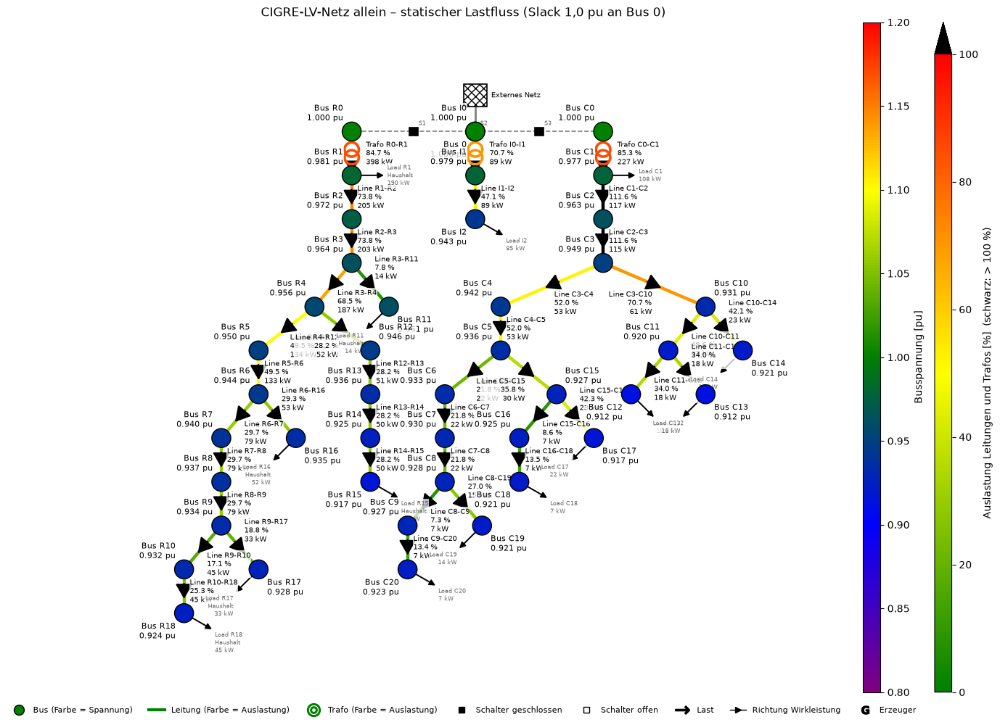

In [51]:
netplan.plot_static(lv, title="CIGRE-LV-Netz allein – statischer Lastfluss (Slack 1,0 pu an Bus 0)");

In [52]:
w, o = lvnetz.kennwerte_static(lv)
pd.DataFrame({"Wert": w.round(3), "Ort": o}).dropna()

,Wert,Ort
U min MS [pu],1.000,Bus 0
U max MS [pu],1.000,Bus 0
U min NS [pu],0.912,Bus C12
U max NS [pu],0.981,Bus R1
Winkel min MS [°],0.000,Bus 0
Winkel max MS [°],0.000,Bus 0
Winkel min NS [°],-32.160,Bus R10
Winkel max NS [°],-30.636,Bus I2
Leitung min NS [%],7.270,Line C8-C9
Leitung max NS [%],111.581,Line C2-C3


**Basisdaten LV-Netz (statisch, alle Lasten mit Bemessungsleistung, Slack 1,0 pu):**

- Der Lastfluss konvergiert in 3 Iterationen. Bei 0,687 MW Last bezieht das LV-Netz 0,715 MW. Die Verluste betragen 28 kW, das sind 4,1 % der Last und damit deutlich mehr als im MV-Netz (0,7 %), weil bei 0,4 kV für dieselbe Leistung ein 50-mal so großer Strom fließt.
- Die niedrigste Spannung liegt bei 0,912 pu am Ende des Gewerbe-Freileitungsnetzes (Bus C12).
- Mit den Grenzströmen aus [18] sind die ersten Abschnitte der Gewerbe-Freileitung (Line C1-C2 und Line C2-C3, Typ OH1, 172 A) mit 112 % **überlastet**. Über sie fließt die gesamte Last des Gewerbenetzes außer Load C1. Alle anderen Leitungen liegen darunter.
- Die Ortsnetztrafos sind zu 71 % (I), 85 % (R) und 85 % (C) ausgelastet.

## 2 Schritt 1: Vorbelastung des MV-Netzes ohne Ortsnetz

Grundlage ist die Referenz-Zeitreihe aus Teil 1 (`w4_baseline_000`: CIGRE-MV ohne DER, alle Trennschalter offen, 12 typische Wochen). Mit `sim.ONLY_RUN_IF_CHANGED = True` werden die gespeicherten Ergebnisse geladen.

In [53]:
ref = sim.init("w4_baseline", baseline_net(), overwrite=True, assignProfiles=True)
ref_ts = sz.zeitreihe_alle(ref, prefix="w4_baseline", keys=["000"])["000"]
ref_ts.summary()

18 Profile zugeordnet: HAUSHALT: 10, GEWERBE: 8
Simulation 'w4_baseline_000': unverändert seit dem Lauf vom 2026-11-08T20:21:27 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


Zeitschritte                                                         2016
konvergiert                                                          2016
U min [pu]                                                         0.9487
U max [pu]                                                           1.03
Stunden U < 0.9                                                         0
Stunden U > 1.1                                                         0
Leitung max [%]                                                      78.6
Stunden Leitung > 100 %                                                 0
Trafo max [%]                                                        82.7
Stunden Trafo > 100 %                                                   0
Stunden Rückspeisung ins vorgelagerte Netz                              0
max. Rückspeisung [MW]                                                0.0
Energie Lasten [MWh]                                              43722.0
Energie Erzeuger [MWh]                

### 2.1 Niedrigste Spannung je Bus und Monat

In [54]:
plots.table(sz.monatstabelle(ref_ts, "Spannung", "min"), decimals=3, cmap="RdYlGn", vmin=0.92, vmax=1.03)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Spannung min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.002,1.002,1.006,1.008,1.011,1.012,1.012,1.013,1.011,1.008,1.004,1.002
Bus 2,0.984,0.984,0.990,0.993,0.999,1.000,1.000,1.001,0.998,0.993,0.986,0.984
Bus 3,0.955,0.956,0.964,0.970,0.980,0.981,0.981,0.983,0.978,0.969,0.959,0.956
Bus 4,0.953,0.954,0.963,0.968,0.978,0.979,0.980,0.981,0.976,0.968,0.957,0.954
Bus 5,0.952,0.953,0.962,0.967,0.978,0.979,0.979,0.981,0.975,0.967,0.956,0.953
Bus 6,0.950,0.952,0.961,0.966,0.977,0.978,0.978,0.980,0.974,0.966,0.955,0.951
Bus 7,0.950,0.952,0.961,0.966,0.977,0.978,0.979,0.980,0.975,0.966,0.955,0.951
Bus 8,0.951,0.952,0.961,0.966,0.977,0.978,0.979,0.980,0.975,0.966,0.955,0.952


### 2.2 Höchste Leitungsauslastung je Leitung und Monat

In [55]:
plots.table(sz.monatstabelle(ref_ts, "Leitung", "max"), decimals=1, cmap="YlOrRd", vmin=0, vmax=100)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Leitung max [%],,,,,,,,,,,,
Line 1-2,78.2,77.4,69.0,64.8,54.8,53.5,53.0,51.8,56.9,64.2,74.7,76.6
Line 2-3,78.6,77.7,69.4,65.2,55.2,53.9,53.4,52.1,57.3,64.6,75.1,77.1
Line 3-4,36.6,36.1,31.5,30.1,25.2,24.2,24.4,23.8,26.4,29.9,34.7,34.9
Line 4-5,27.3,26.9,23.6,22.5,18.8,18.1,18.2,17.8,19.7,22.4,25.9,26.1
Line 5-6,11.8,11.6,10.2,9.7,8.1,7.8,7.9,7.7,8.5,9.7,11.2,11.3
Line 7-8,1.9,1.8,1.8,1.6,1.5,1.5,1.4,1.4,1.5,1.6,1.8,1.8
Line 8-9,24.5,23.9,22.9,21.5,19.7,19.3,18.8,18.8,19.3,20.7,23.8,24.6
Line 9-10,17.8,17.6,15.3,14.7,12.3,11.9,11.9,11.6,12.9,14.6,16.9,17.0
Line 10-11,7.1,7.0,6.1,5.8,4.9,4.7,4.7,4.6,5.1,5.8,6.7,6.8


### 2.3 Höchste Trafoauslastung je Trafo und Monat

In [56]:
plots.table(sz.monatstabelle(ref_ts, "Trafo", "max"), decimals=1, cmap="YlOrRd", vmin=0, vmax=100)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,82.7,81.8,73.6,69.2,59.1,57.8,57.2,56.0,61.2,68.7,79.2,81.4
Trafo 0-12,68.4,67.5,61.1,57.3,49.1,48.2,47.6,46.6,50.8,57.2,65.4,67.7


### 2.4 Stunden mit niedriger Spannung, Bus für Bus

Anzahl der Stunden (von 2016) unter 0,90 pu (Arbeitsgrenze) und unter 0,95 pu sowie die niedrigste Spannung mit Zeitpunkt. Ohne Ortsnetz gibt es nur MS-Busse.

In [57]:
plots.table(sz.stunden_je_bus(ref_ts), decimals=3, int_cols=["Stunden U < 0,90", "Stunden U < 0,95"])

,"Stunden U < 0,90","Stunden U < 0,95",U min [pu],Zeitpunkt U min
Bus 0,0,0,1.030,Mon 06.01. 00:00
Bus 1,0,0,1.002,Fri 10.01. 18:00
Bus 2,0,0,0.984,Fri 10.01. 18:00
Bus 3,0,0,0.955,Fri 10.01. 18:00
Bus 4,0,0,0.953,Fri 10.01. 18:00
Bus 5,0,0,0.952,Fri 10.01. 18:00
Bus 6,0,0,0.950,Fri 10.01. 18:00
Bus 7,0,0,0.950,Fri 10.01. 18:00
Bus 8,0,0,0.951,Fri 10.01. 18:00
Bus 9,0,2,0.950,Fri 10.01. 18:00


### 2.5 Netzpläne: niedrigste Spannung und höchste Auslastung

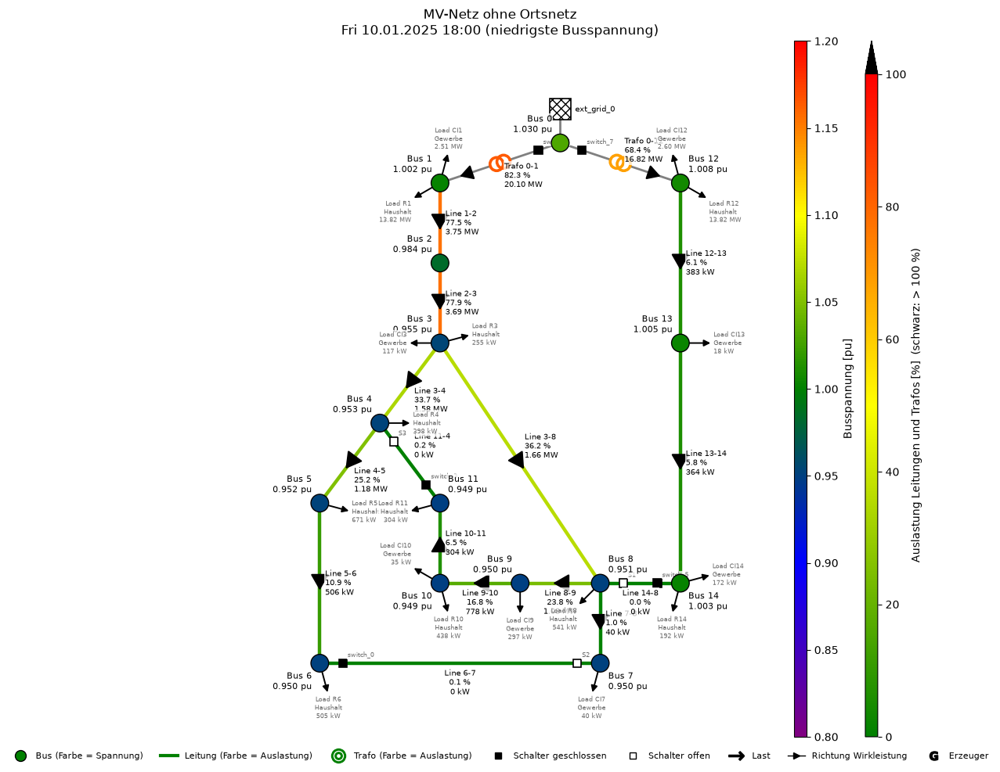

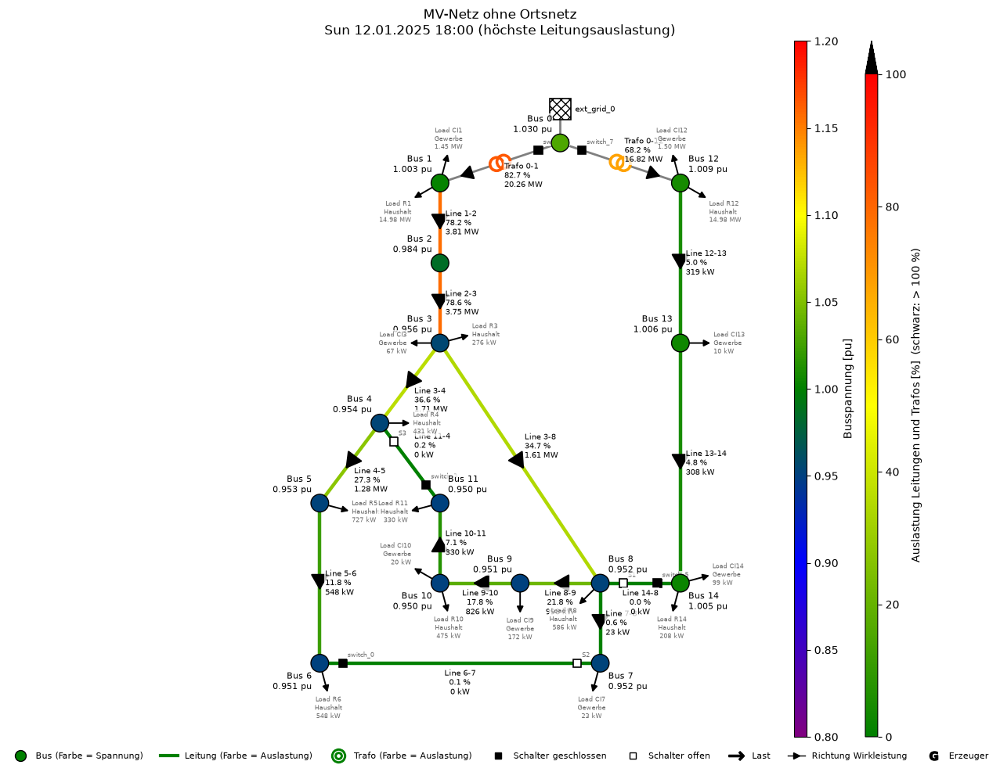

In [58]:
ref_ts.createDiagram(Diagram.NETWORK, time=["min", "max_loading"], title="MV-Netz ohne Ortsnetz")

**Befund Schritt 1 (MV-Netz ohne Ortsnetz):**

- **Spannung:** In keiner Stunde fällt ein Bus unter 0,90 pu. Abgang 1 ist aber deutlich vorbelastet: Ab Bus 3 sinkt die Spannung zur Abendspitze im Januar (Fr 10.01. 18:00) auf 0,949 bis 0,955 pu, Bus 9 bis Bus 11 liegen 2 bis 8 Stunden unter 0,95 pu. Abgang 2 (Bus 12 bis Bus 14) bleibt das ganze Jahr über 1,00 pu, ebenso Bus 1 an der Trafo-Sammelschiene.
- **Leitungen:** Line 1-2 und Line 2-3 sind im Winter bis 78,6 % ausgelastet, im Sommer etwa 52 %. Alle übrigen Kabel in Abgang 1 bleiben unter 37 %, die Freileitungen in Abgang 2 unter 8 %.
- **Transformatoren:** Trafo 0-1 (Abgang 1) erreicht im Januar 82,7 %, Trafo 0-12 (Abgang 2) 68,4 %.
- **Folgerung:** Der belastete Teil des Netzes ist Abgang 1 mit Trafo 0-1, Line 1-2, Line 2-3 und den Bussen ab Bus 3. Abgang 2 und Trafo 0-12 haben die größte Reserve bei Spannung und Auslastung.

## 3 Zusammenführen von MV- und LV-Netz

Das LV-Netz wird mit `Simulation.attachNetwork()` angeschlossen:

1. **Nennspannung prüfen:** Der Slack-Bus des LV-Netzes (`Bus 0`, 20 kV) und der MV-Anschlussbus müssen dieselbe Nennspannung haben, sonst bricht die Funktion ab.
2. **Externes Netz entfernen:** Das LV-Netz wird künftig aus dem MV-Netz versorgt, sein externes Netz entfällt.
3. **Namen eindeutig machen:** Alle Elemente des LV-Netzes erhalten das Präfix `LV` (z. B. `LV Bus R1`, `LV S1`, `LV Load R1`). Damit gibt es keine Namensgleichheit mit dem MV-Netz, z. B. bei `Load R1` oder den Schaltern `S1`–`S3`.
4. **Indizes eindeutig machen:** `pandapower.toolbox.merge_nets` hängt die Tabellen aneinander und nummeriert die Indizes des LV-Netzes neu.
5. **Busse vereinigen:** `fuse_buses` vereinigt `LV Bus 0` mit dem MV-Anschlussbus. Alle Elemente an `LV Bus 0` hängen danach am MV-Bus.
6. **Profile zuordnen:** `LV Load R…` erhält H25 (Wohngebiet), `LV Load I…` und `LV Load C…` erhalten G25 (Industrie und Gewerbe; ein eigenes Industrieprofil gibt es bei den BDEW-Standardlastprofilen nicht). Die Skalierung erfolgt wie im MV-Netz über die Jahreshöchstleistung (`p_mw` aus [13]).

Beispiel: Anschluss an Bus 5, mit Prüfung der Indizes, Namen und der Leistungsbilanz.

In [59]:
net_mv = baseline_net()
sim._ensure_names(net_mv)
sim._ensure_profile_columns(net_mv)
demo = sim.Simulation("demo", net_mv)
demo.attachNetwork(lvnetz.lv_net(), "Bus 5", prefix=lvnetz.PREFIX)
n = demo.net

pruefung = pd.DataFrame({
    "MV allein": [len(net_mv[t]) for t in ["bus", "line", "trafo", "switch", "load", "ext_grid"]],
    "LV allein": [len(lv[t]) for t in ["bus", "line", "trafo", "switch", "load", "ext_grid"]],
    "zusammen": [len(n[t]) for t in ["bus", "line", "trafo", "switch", "load", "ext_grid"]],
}, index=["bus", "line", "trafo", "switch", "load", "ext_grid"])
pruefung["Erwartung"] = pruefung["MV allein"] + pruefung["LV allein"] - pd.Series({"bus": 1, "ext_grid": 1}).reindex(pruefung.index).fillna(0).astype(int)
display(pruefung)
print("Indizes eindeutig:", all(n[t].index.is_unique for t in ["bus", "line", "trafo", "switch", "load"]))
print("Namen eindeutig:  ", pd.concat([n[t]["name"] for t in ["bus", "line", "trafo", "switch", "load"]]).is_unique)
print("Nennspannungen:   ", dict(n.bus.vn_kv.value_counts().sort_index()))
print(f"Last gesamt: {n.load.p_mw.sum():.4f} MW = MV {net_mv.load.p_mw.sum():.4f} MW + LV {lv.load.p_mw.sum():.4f} MW")
ok = sz.lastfluss(n)
b = ok["bilanz"]
print(f"Konvergiert: {ok['converged']} | Bezug ext. Netz {b['Bezug ext. Netz P [MW]']:.4f} MW = "
      f"Last {b['Last P [MW]']:.4f} MW + Verluste {b['Verluste gesamt [MW]']:.4f} MW")

101 Elemente angehängt an 'Bus 5' (Bus 'LV Bus 0' mit 'Bus 5' vereinigt).


,MV allein,LV allein,zusammen,Erwartung
bus,15,44,58,58
line,15,37,52,52
trafo,2,3,5,5
switch,8,3,11,11
load,18,15,33,33
ext_grid,1,1,1,1


Indizes eindeutig: True
Namen eindeutig:   True
Nennspannungen:    {0.4: np.int64(40), 20.0: np.int64(17), 110.0: np.int64(1)}
Last gesamt: 45.4287 MW = MV 44.7421 MW + LV 0.6866 MW
Konvergiert: True | Bezug ext. Netz 45.8697 MW = Last 45.4287 MW + Verluste 0.4410 MW


## 4 Zeitreihe für jeden Anschlussbus

Für jeden Anschlussbus wird eine Kopie des Referenzszenarios angelegt, das LV-Netz angehängt und über 12 typische Wochen gerechnet.

| verändert | konstant |
|---|---|
| Anschlussbus des LV-Netzes (Bus 1 bis Bus 14) | MV-Netz, Schalterstellung `000`, MV-Lasten und Profile |
| zusätzlich: 43 Busse, 37 Leitungen, 3 Ortsnetztrafos, 3 Schalter, 15 Lasten des LV-Netzes | Slack 1,03 pu, Zeitbasis, Lastflussverfahren |

Die erste Rechnung dauert je Anschlussbus etwa eine Minute. Danach lädt `sim.ONLY_RUN_IF_CHANGED = True` die gespeicherten Ergebnisse.

In [60]:
lv_sims = {}
for at_bus in MV_BUSES:
    s = ref.copy(f"w4_lv_{at_bus.replace(' ', '')}", overwrite=True)
    lvnetz.attach(s, at_bus)
    s.runSimulation()
    lv_sims[at_bus] = s

ts_werte, ts_orte = {}, {}
ts_werte["ohne LV"], ts_orte["ohne LV"] = lvnetz.kennwerte_sim(ref_ts)
for at_bus, s in lv_sims.items():
    ts_werte[at_bus], ts_orte[at_bus] = lvnetz.kennwerte_sim(s)
ts_werte = pd.DataFrame(ts_werte).T
ts_orte = pd.DataFrame(ts_orte).T
ts_werte[["konvergiert", "Zeitpunkte"]].T

101 Elemente angehängt an 'Bus 1' (Bus 'LV Bus 0' mit 'Bus 1' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus1': unverändert seit dem Lauf vom 2026-11-08T20:22:35 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
101 Elemente angehängt an 'Bus 2' (Bus 'LV Bus 0' mit 'Bus 2' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus2': unverändert seit dem Lauf vom 2026-11-08T20:24:15 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
101 Elemente angehängt an 'Bus 3' (Bus 'LV Bus 0' mit 'Bus 3' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus3': unverändert seit dem Lauf vom 2026-11-08T20:25:53 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
101 Elemente angehängt an 'Bus 4' (Bus 'LV Bus 0' mit 'Bus 4' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus4': unverändert seit dem Lauf vom 2026-11-08T

,ohne LV,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5,Bus 6,Bus 7,Bus 8,Bus 9,Bus 10,Bus 11,Bus 12,Bus 13,Bus 14
konvergiert,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0
Zeitpunkte,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0


**Höchste und niedrigste Spannung** (MS: 20-kV-Busse des CIGRE-MV-Netzes, NS: 0,4-kV-Busse):

In [61]:
cols_u = ["U min gesamt [pu]", "U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]"]
cols_l = ["Leitung max MS [%]", "Leitung min MS [%]", "Leitung max NS [%]", "Leitung min NS [%]",
          "Trafo max HS/MS [%]", "Trafo min HS/MS [%]", "Ortsnetztrafo max [%]", "Ortsnetztrafo min [%]"]
cols_w = ["Winkel min MS [°]", "Winkel max MS [°]", "Winkel min NS [°]", "Winkel max NS [°]"]
display(plots.table(ts_werte[cols_u].astype(float), decimals=3, cmap="RdYlGn", vmin=0.85, vmax=1.03))
ts_orte[cols_u]

,U min gesamt [pu],U min MS [pu],U max MS [pu],U min NS [pu],U max NS [pu]
ohne LV,0.949,0.949,1.024,nan,nan
Bus 1,0.918,0.947,1.024,0.918,1.020
Bus 2,0.895,0.944,1.024,0.895,1.016
Bus 3,0.857,0.938,1.024,0.857,1.008
Bus 4,0.854,0.938,1.024,0.854,1.007
Bus 5,0.852,0.938,1.024,0.852,1.007
Bus 6,0.849,0.936,1.024,0.849,1.006
Bus 7,0.849,0.936,1.024,0.849,1.006
Bus 8,0.851,0.936,1.024,0.851,1.007
Bus 9,0.850,0.936,1.024,0.850,1.006


,U min gesamt [pu],U min MS [pu],U max MS [pu],U min NS [pu],U max NS [pu]
ohne LV,Bus 11,Bus 11,Bus 12,–,–
Bus 1,LV Bus C13,Bus 11,Bus 12,LV Bus C13,LV Bus I1
Bus 2,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 3,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 4,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 5,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 6,LV Bus R15,Bus 6,Bus 12,LV Bus R15,LV Bus I1
Bus 7,LV Bus R15,Bus 7,Bus 12,LV Bus R15,LV Bus I1
Bus 8,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1
Bus 9,LV Bus R15,Bus 11,Bus 12,LV Bus R15,LV Bus I1


**Höchste und niedrigste Auslastung** (Leitungen NS mit den Grenzströmen aus [18]):

In [62]:
display(plots.table(ts_werte[cols_l].astype(float), decimals=1, cmap="YlOrRd", vmin=0, vmax=100))
ts_orte[["Leitung max MS [%]", "Leitung max NS [%]", "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]"]]

,Leitung max MS [%],Leitung min MS [%],Leitung max NS [%],Leitung min NS [%],Trafo max HS/MS [%],Trafo min HS/MS [%],Ortsnetztrafo max [%],Ortsnetztrafo min [%]
ohne LV,78.6,0.0,nan,nan,82.7,18.8,nan,nan
Bus 1,78.7,0.0,110.8,1.2,84.9,18.8,84.7,11.6
Bus 2,89.4,0.0,113.1,1.2,85.0,18.8,86.6,11.7
Bus 3,90.8,0.0,117.1,1.2,85.2,18.8,90.1,11.8
Bus 4,90.9,0.0,117.3,1.2,85.2,18.8,90.3,11.8
Bus 5,90.9,0.0,117.5,1.2,85.2,18.8,90.5,11.8
Bus 6,91.0,0.0,117.9,1.2,85.2,18.8,90.9,11.8
Bus 7,91.0,0.0,118.2,1.2,85.2,18.8,90.8,11.8
Bus 8,91.0,0.0,117.9,1.2,85.2,18.8,90.6,11.8
Bus 9,91.0,0.0,118.1,1.2,85.2,18.8,90.7,11.8


,Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%]
ohne LV,Line 2-3,–,Trafo 0-1,–
Bus 1,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo C0-C1
Bus 2,Line 1-2,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 3,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 4,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 5,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 6,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 7,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 8,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1
Bus 9,Line 2-3,LV Line C1-C2,Trafo 0-1,LV Trafo R0-R1


**Höchster und niedrigster Winkel** (bezogen auf Bus 0; MS-Busse enthalten −30°, NS-Busse −60° durch die Trafo-Schaltgruppen):

In [63]:
display(plots.table(ts_werte[cols_w].astype(float), decimals=2))
ts_orte[cols_w]

,Winkel min MS [°],Winkel max MS [°],Winkel min NS [°],Winkel max NS [°]
ohne LV,-38.06,-31.22,nan,nan
Bus 1,-38.20,-31.22,-67.67,-61.58
Bus 2,-38.33,-31.22,-68.80,-61.88
Bus 3,-38.52,-31.22,-70.66,-62.33
Bus 4,-38.52,-31.22,-70.80,-62.36
Bus 5,-38.53,-31.22,-70.90,-62.38
Bus 6,-38.59,-31.22,-71.07,-62.42
Bus 7,-38.58,-31.22,-71.02,-62.42
Bus 8,-38.58,-31.22,-70.94,-62.40
Bus 9,-38.59,-31.22,-70.99,-62.41


,Winkel min MS [°],Winkel max MS [°],Winkel min NS [°],Winkel max NS [°]
ohne LV,Bus 11,Bus 12,–,–
Bus 1,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 2,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 3,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 4,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 5,Bus 6,Bus 12,LV Bus R10,LV Bus I2
Bus 6,Bus 6,Bus 12,LV Bus R10,LV Bus I2
Bus 7,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 8,Bus 11,Bus 12,LV Bus R10,LV Bus I2
Bus 9,Bus 11,Bus 12,LV Bus R10,LV Bus I2


**Anzahl Stunden mit Spannung unter 0,90 bzw. 0,95 pu und mit Überlastung:**

In [64]:
cols_h = ["Stunden U < 0,90 MS", "Stunden U < 0,95 MS", "Stunden U < 0,90 NS", "Stunden U < 0,95 NS",
          "Stunden Leitung MS > 100 %", "Stunden Leitung NS > 100 %", "Stunden Trafo HS/MS > 100 %",
          "Stunden Ortsnetztrafo > 100 %"]
ts_werte.reindex(columns=cols_h).fillna(0).astype(int).T

,ohne LV,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5,Bus 6,Bus 7,Bus 8,Bus 9,Bus 10,Bus 11,Bus 12,Bus 13,Bus 14
"Stunden U < 0,90 MS",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"Stunden U < 0,95 MS",8,27,52,84,84,85,102,107,106,111,126,127,8,8,8
"Stunden U < 0,90 NS",0,0,12,434,456,479,509,527,499,509,535,545,0,0,0
"Stunden U < 0,95 NS",0,588,995,1352,1361,1369,1375,1375,1373,1374,1379,1382,535,698,798
Stunden Leitung MS > 100 %,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Stunden Leitung NS > 100 %,0,78,85,115,120,120,120,120,120,120,120,120,65,80,80
Stunden Trafo HS/MS > 100 %,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Stunden Ortsnetztrafo > 100 %,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 5 Schritt 2: Ausschluss

Ausgeschlossen wird jeder Anschlussbus, bei dem in mindestens einer Stunde eine Spannung unter 0,90 pu oder eine Auslastung über 100 % auftritt.

**Kriterien, die bei jedem Anschlussbus verletzt sind,** unterscheiden die Anschlussbusse nicht. Sie entstehen im LV-Netz selbst, unabhängig davon, wo es angeschlossen wird, und lassen sich durch die Wahl des Anschlussbusses nicht beheben. Sie werden deshalb für die Auswahl ausgeklammert, aber als Befund festgehalten.

In [65]:
KRITERIEN = {
    "U < 0,90 pu (MS)": "Stunden U < 0,90 MS",
    "U < 0,90 pu (NS)": "Stunden U < 0,90 NS",
    "Leitung MS > 100 %": "Stunden Leitung MS > 100 %",
    "Leitung NS > 100 %": "Stunden Leitung NS > 100 %",
    "Trafo HS/MS > 100 %": "Stunden Trafo HS/MS > 100 %",
    "Ortsnetztrafo > 100 %": "Stunden Ortsnetztrafo > 100 %",
}
var = ts_werte.drop(index="ohne LV")
stunden = pd.DataFrame({k: var.get(c, pd.Series(0, index=var.index)).fillna(0).astype(int) for k, c in KRITERIEN.items()})
verletzt = stunden > 0
immer = [k for k in verletzt if verletzt[k].all()]
wirksam = [k for k in verletzt if k not in immer]

auswahl = stunden.copy()
auswahl["ausgeschlossen wegen"] = [", ".join(k for k in wirksam if verletzt.at[b, k]) or "–" for b in auswahl.index]
auswahl["Ergebnis"] = np.where(verletzt[wirksam].any(axis=1), "ausgeschlossen", "bleibt")
kandidaten = list(auswahl.index[auswahl["Ergebnis"] == "bleibt"])

print("Kriterien, die bei jedem Anschlussbus verletzt sind (ausgeklammert):", immer or "keine")
for k in immer:
    print(f"  {k}: {stunden[k].min()} bis {stunden[k].max()} Stunden, Ort: "
          f"{', '.join(sorted(set(ts_orte.loc[var.index, 'Leitung max NS [%]' if 'Leitung NS' in k else 'Ortsnetztrafo max [%]' if 'Ortsnetz' in k else 'U min NS [pu]'])))}")
print("Verbleibende Anschlussbusse:", kandidaten or "keine")
auswahl

Kriterien, die bei jedem Anschlussbus verletzt sind (ausgeklammert): ['Leitung NS > 100 %']
  Leitung NS > 100 %: 65 bis 120 Stunden, Ort: LV Line C1-C2
Verbleibende Anschlussbusse: ['Bus 1', 'Bus 12', 'Bus 13', 'Bus 14']


,"U < 0,90 pu (MS)","U < 0,90 pu (NS)",Leitung MS > 100 %,Leitung NS > 100 %,Trafo HS/MS > 100 %,Ortsnetztrafo > 100 %,ausgeschlossen wegen,Ergebnis
Bus 1,0,0,0,78,0,0,–,bleibt
Bus 2,0,12,0,85,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 3,0,434,0,115,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 4,0,456,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 5,0,479,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 6,0,509,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 7,0,527,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 8,0,499,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 9,0,509,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen
Bus 10,0,535,0,120,0,0,"U < 0,90 pu (NS)",ausgeschlossen


**Befund Schritt 2:**

- **Ausgeschlossen: Bus 2 bis Bus 11.** Bei Anschluss in Abgang 1 hinter Line 1-2 fällt die Spannung im Ortsnetz unter 0,90 pu: bei Bus 2 in 12 Stunden, bei Bus 3 bis Bus 11 in 434 bis 545 der 2016 Stunden. Der niedrigste Wert liegt immer am Ende des Wohngebietsnetzes (LV Bus R15) zur Abendspitze. Ursache ist die schon vorbelastete MV-Spannung in Abgang 1 (Schritt 1) zusammen mit dem Spannungsfall im Ortsnetztrafo und in den LV-Leitungen.
- **Ausgeklammert: Überlastung der LV-Leitungen.** Line C1-C2 (OH1, 172 A) ist bei **jedem** Anschlussbus überlastet, in 65 bis 120 Stunden. Die Überlastung tritt schon im LV-Netz allein auf (Abschnitt 1.2) und ist eine Eigenschaft des Gewerbe-Freileitungsnetzes mit den CIGRE-Lasten. Durch die Wahl des Anschlussbusses lässt sie sich nicht vermeiden; die Zahl der Stunden hängt nur über die Spannung leicht vom Anschlussbus ab (niedrigere Spannung, höherer Strom). Sie bleibt als Befund für die weiteren Teilaufgaben bestehen.
- **Verbleibend: Bus 1, Bus 12, Bus 13 und Bus 14.** Hier liegen alle Spannungen über 0,90 pu, und kein MV-Betriebsmittel und kein Ortsnetztrafo wird über 100 % ausgelastet.

## 6 Schritt 3: Auswahl des Anschlussbusses

Für die verbleibenden Anschlussbusse werden die Kennwerte verglichen:

- **höchste niedrigste Spannung** über alle MV- und LV-Busse (größer ist besser)
- **niedrigste höchste Auslastung** der MV-Leitungen, der LV-Leitungen, der Trafos 110/20 kV und der Ortsnetztrafos (kleiner ist besser)

Für jedes Kriterium wird ein Rang vergeben (1 = bester Wert). Gewählt wird der Anschlussbus mit der kleinsten Rangsumme.

In [66]:
ZIELE = {"U min gesamt [pu]": False,          # False: absteigend sortieren (größer ist besser)
         "Leitung max MS [%]": True, "Leitung max NS [%]": True,
         "Trafo max HS/MS [%]": True, "Ortsnetztrafo max [%]": True}
if kandidaten:
    vergleich = var.loc[kandidaten, list(ZIELE)].astype(float)
    raenge = pd.DataFrame({f"Rang {k.split(' [')[0]}": vergleich[k].rank(ascending=asc, method="min").astype(int)
                           for k, asc in ZIELE.items()})
    raenge["Rangsumme"] = raenge.sum(axis=1)
    tabelle = pd.concat([vergleich.round(3), raenge], axis=1).sort_values("Rangsumme")
    gewaehlt = tabelle.index[0]
    display(tabelle)
    beste = {k: (vergleich[k].idxmax() if not asc else vergleich[k].idxmin()) for k, asc in ZIELE.items()}
    display(pd.Series(beste, name="bester Anschlussbus").to_frame())
    print(f"Gewählter Anschlussbus: {gewaehlt}")
else:
    gewaehlt = None
    print("Kein Anschlussbus erfüllt die Kriterien aus Schritt 2.")

,U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Rang U min gesamt,Rang Leitung max MS,Rang Leitung max NS,Rang Trafo max HS/MS,Rang Ortsnetztrafo max,Rangsumme
Bus 12,0.923,78.638,110.311,82.694,84.340,1,1,1,1,1,5
Bus 13,0.913,78.638,111.409,82.694,85.131,3,1,3,1,3,11
Bus 1,0.918,78.748,110.775,84.874,84.674,2,4,2,4,2,14
Bus 14,0.908,78.638,112.077,82.694,85.611,4,1,4,1,4,14


,bester Anschlussbus
U min gesamt [pu],Bus 12
Leitung max MS [%],Bus 12
Leitung max NS [%],Bus 12
Trafo max HS/MS [%],Bus 12
Ortsnetztrafo max [%],Bus 12


Gewählter Anschlussbus: Bus 12


**Netzpläne des gewählten Anschlussbusses** zum Zeitpunkt der niedrigsten Spannung und der höchsten Auslastung:

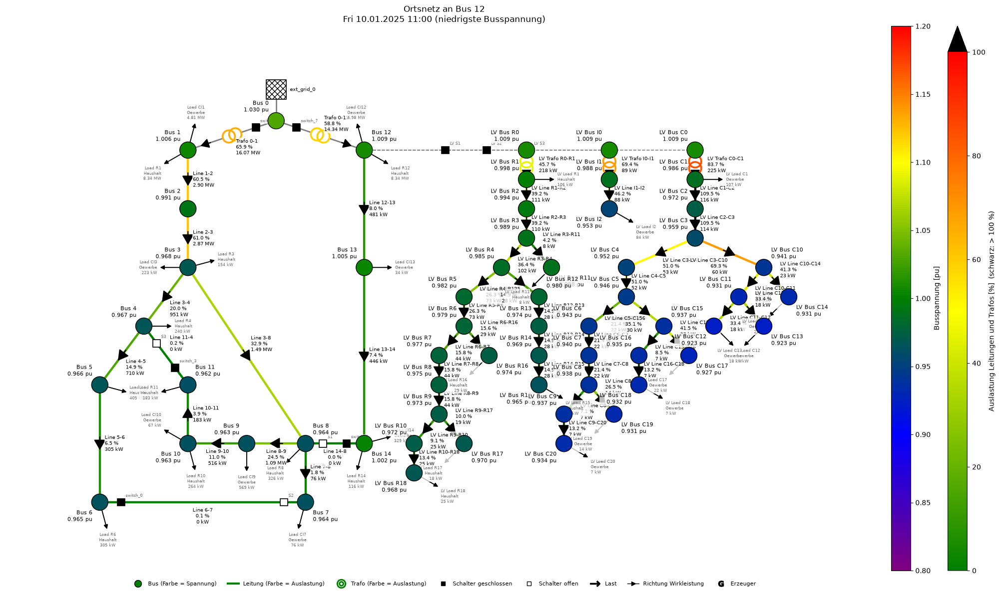

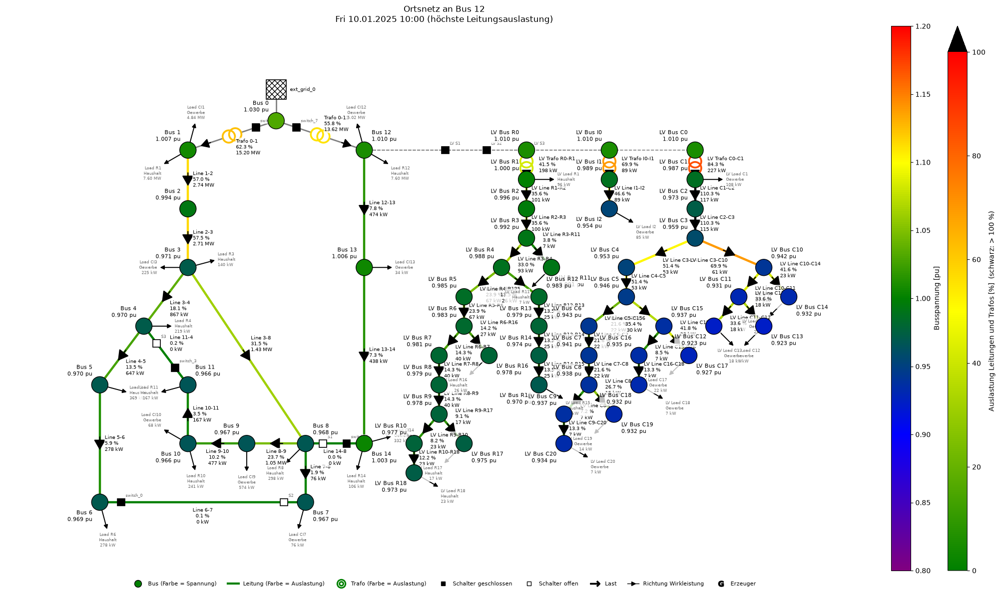

In [67]:
if gewaehlt:
    lv_sims[gewaehlt].createDiagram(Diagram.NETWORK, time=["min", "max_loading"], title=f"Ortsnetz an {gewaehlt}")

**Monatstabellen des gewählten Anschlussbusses** (niedrigste Spannung an allen Bussen, höchste Auslastung der Trafos):

In [68]:
if gewaehlt:
    display(plots.table(sz.monatstabelle(lv_sims[gewaehlt], "Spannung", "min"), decimals=3, cmap="RdYlGn", vmin=0.85, vmax=1.03))
    display(plots.table(sz.monatstabelle(lv_sims[gewaehlt], "Trafo", "max"), decimals=1, cmap="YlOrRd", vmin=0, vmax=100))

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Spannung min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.002,1.002,1.006,1.008,1.011,1.012,1.012,1.013,1.011,1.008,1.004,1.002
Bus 2,0.984,0.984,0.990,0.993,0.999,1.000,1.000,1.001,0.998,0.993,0.986,0.984
Bus 3,0.955,0.956,0.964,0.970,0.980,0.981,0.981,0.983,0.978,0.969,0.959,0.956
Bus 4,0.953,0.954,0.963,0.968,0.978,0.979,0.980,0.981,0.976,0.968,0.957,0.954
Bus 5,0.952,0.953,0.962,0.967,0.978,0.979,0.979,0.981,0.975,0.967,0.956,0.953
Bus 6,0.950,0.952,0.961,0.966,0.977,0.978,0.978,0.980,0.974,0.966,0.955,0.951
Bus 7,0.950,0.952,0.961,0.966,0.977,0.978,0.979,0.980,0.975,0.966,0.955,0.951
Bus 8,0.951,0.952,0.961,0.966,0.977,0.978,0.979,0.980,0.975,0.966,0.955,0.952


month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Trafo max [%],,,,,,,,,,,,
Trafo 0-1,82.7,81.8,73.6,69.2,59.1,57.8,57.2,56.0,61.2,68.7,79.2,81.4
Trafo 0-12,70.7,69.6,63.1,59.1,50.7,49.8,49.1,48.1,52.4,59.0,67.4,70.0
LV Trafo R0-R1,84.0,82.8,72.6,69.4,58.2,55.8,56.4,55.0,60.9,69.0,79.7,80.2
LV Trafo I0-I1,69.9,69.0,67.1,61.8,58.4,57.2,53.0,54.5,57.2,59.8,68.8,66.1
LV Trafo C0-C1,84.3,83.3,81.0,74.6,70.4,69.0,64.0,65.8,69.1,72.2,83.1,79.8


## 7 Ergebnis

**Gewählt wird Bus 12** als Anschlussbus des Ortsnetzes.

| Kennwert | Bus 12 | Bus 1 | Bus 13 | Bus 14 |
|---|---|---|---|---|
| niedrigste Spannung (MV und LV) | **0,923 pu** | 0,918 pu | 0,913 pu | 0,908 pu |
| höchste Auslastung MV-Leitungen | **78,6 %** | 78,7 % | 78,6 % | 78,6 % |
| höchste Auslastung LV-Leitungen | **110,3 %** | 110,8 % | 111,4 % | 112,1 % |
| höchste Auslastung Trafos 110/20 kV | **82,7 %** | 84,9 % | 82,7 % | 82,7 % |
| höchste Auslastung Ortsnetztrafos | **84,3 %** | 84,7 % | 85,1 % | 85,6 % |

Bus 12 ist bei allen fünf Kriterien der beste (oder gleich gute) Anschlussbus:

- **Spannung:** Bus 12 ist die 20-kV-Sammelschiene von Trafo 0-12. Sie wird ohne Leitung direkt vom Trafo versorgt, und Abgang 2 ist nur schwach belastet. Die MV-Spannung bleibt dort das ganze Jahr über 1,00 pu, deshalb bleibt für das Ortsnetz die größte Reserve bis 0,90 pu. Bus 13 und Bus 14 liegen hinter den Freileitungen und haben einen zusätzlichen Spannungsfall.
- **MV-Auslastung:** Das Ortsnetz belastet nur Trafo 0-12 (68,4 % → 70,7 %), der die größte Reserve hat. Line 1-2, Line 2-3 und Trafo 0-1 in Abgang 1 bleiben unverändert. Bei Bus 1 würde dagegen der ohnehin höher belastete Trafo 0-1 von 82,7 % auf 84,9 % steigen.
- **LV-Auslastung:** Durch die höhere Spannung fließt für dieselbe Leistung weniger Strom. Deshalb ist auch die Überlastung von Line C1-C2 bei Bus 12 am geringsten (110,3 %, 65 Stunden).

Mit Bus 12 muss im Normalbetrieb am wenigsten geregelt werden, und der vorbelastete Abgang 1 wird nicht zusätzlich belastet. Die Überlastung von Line C1-C2 im Ortsnetz selbst bleibt als offener Befund für die weiteren Teilaufgaben bestehen.

## 8 Anhang: Netzpläne aller Anschlussvarianten

Für jeden Anschlussbus der Netzplan zum Zeitpunkt der höchsten Leitungsauslastung über alle 12 Wochen. Das LV-Netz ist rechts neben dem MV-Netz dargestellt; die gestrichelten grauen Linien verbinden den Anschlussbus mit den 20-kV-Seiten der drei Ortsnetztrafos (Schalter LV S1–S3).

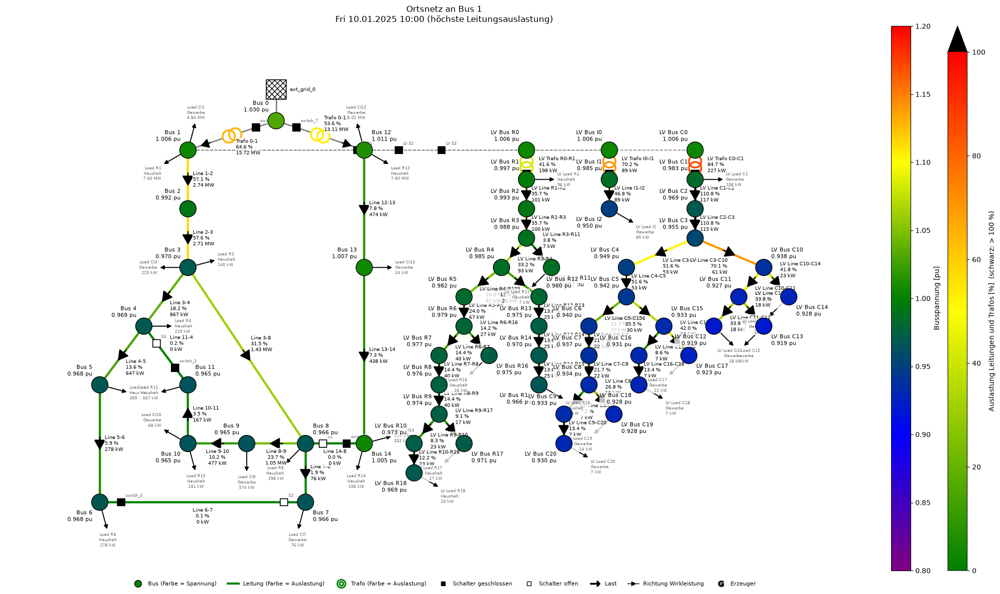

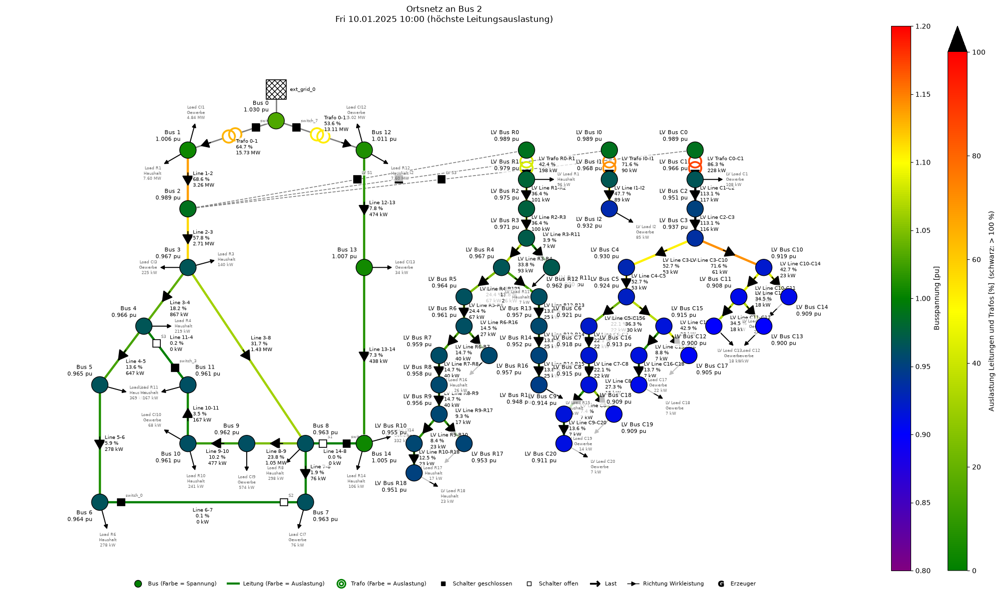

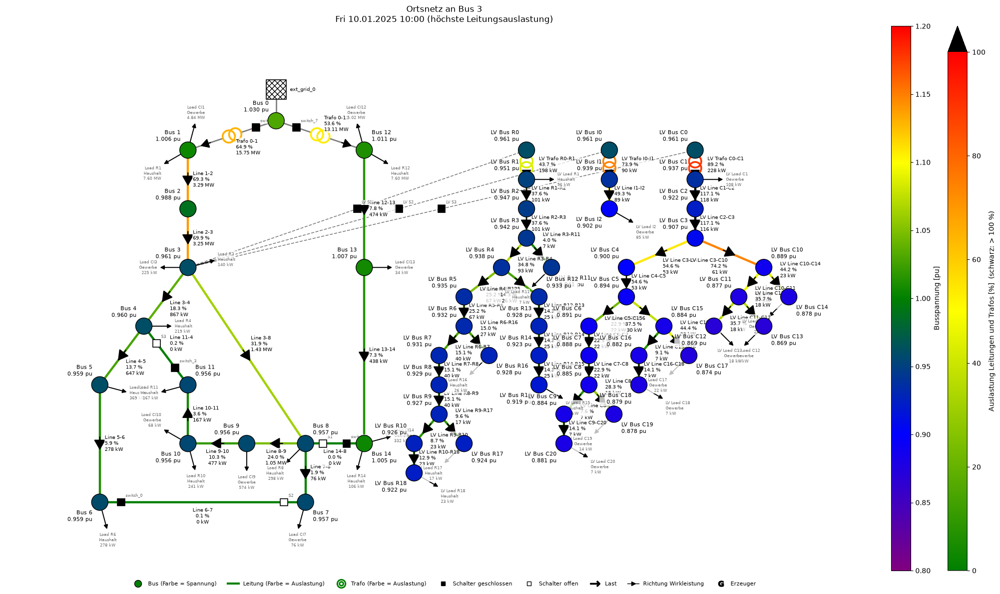

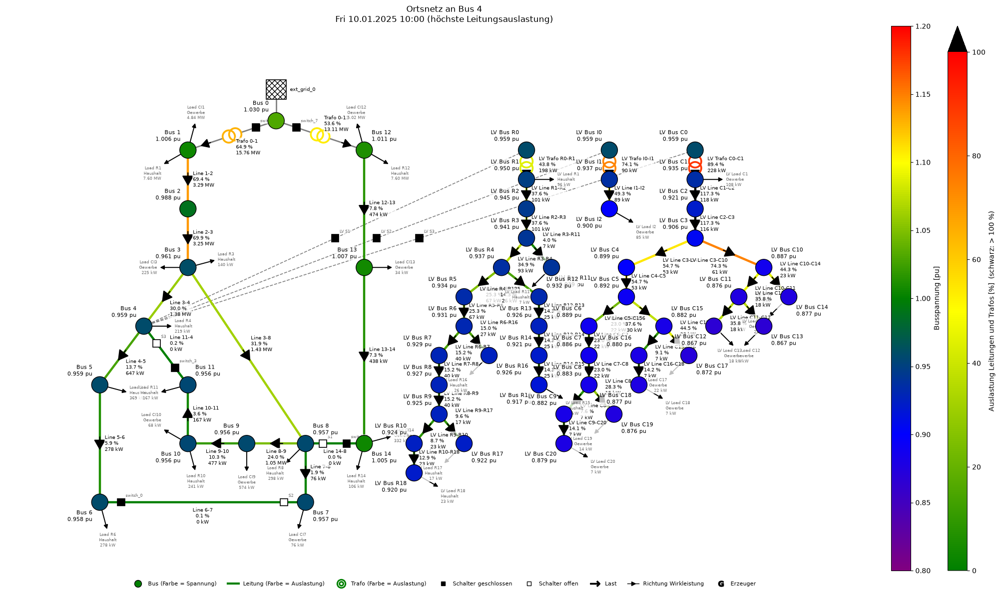

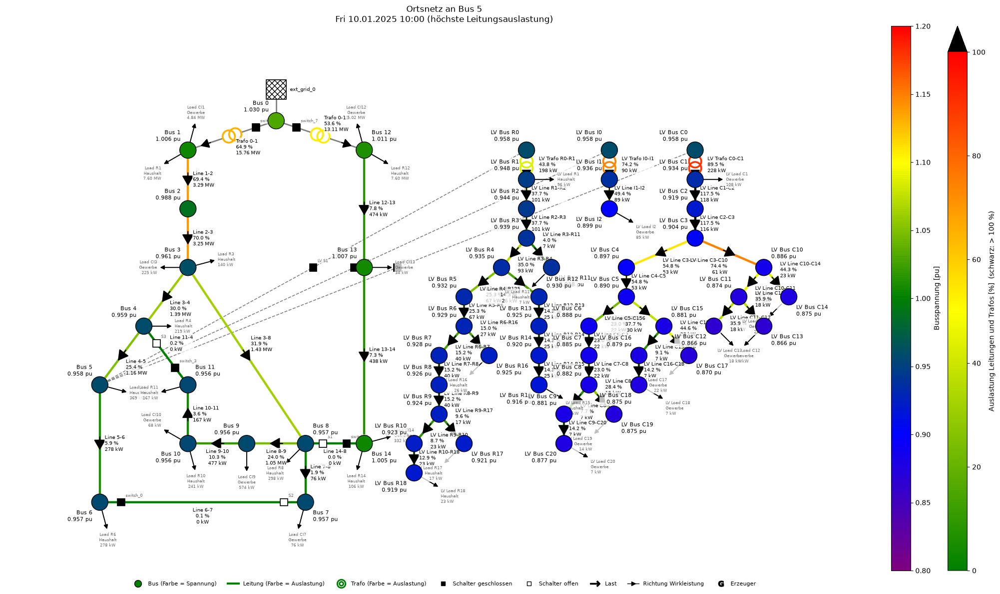

...

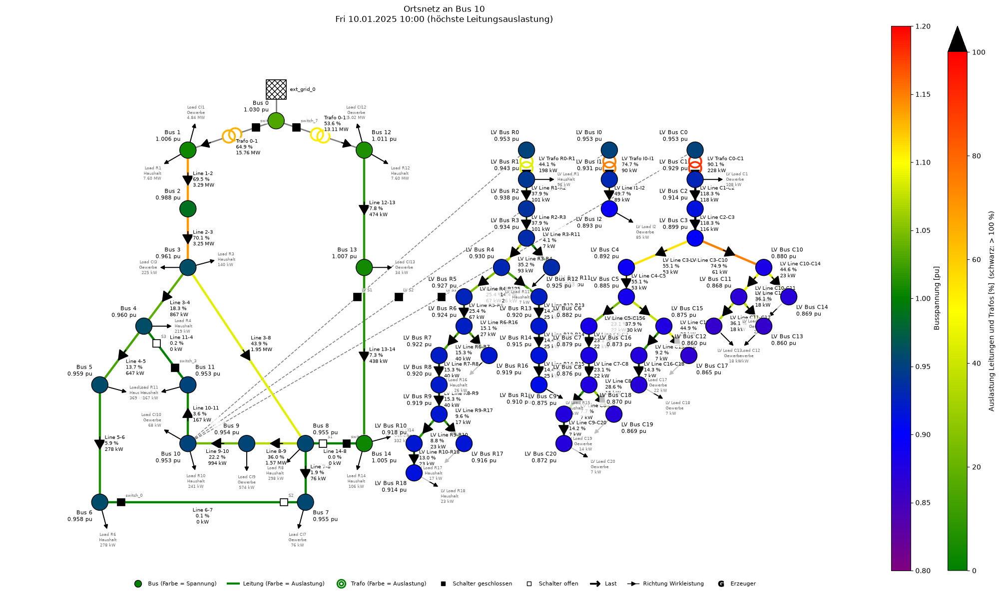

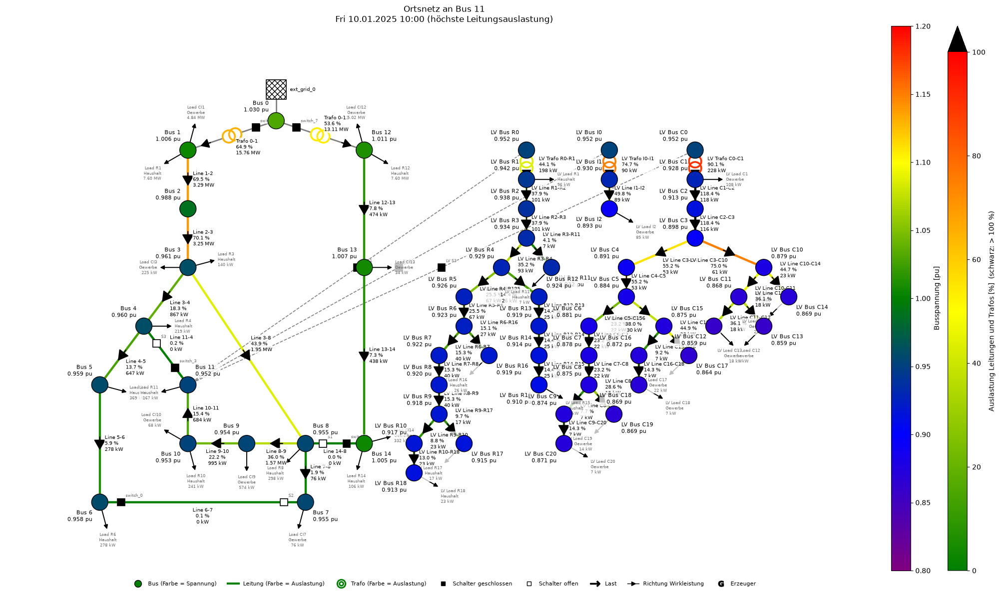

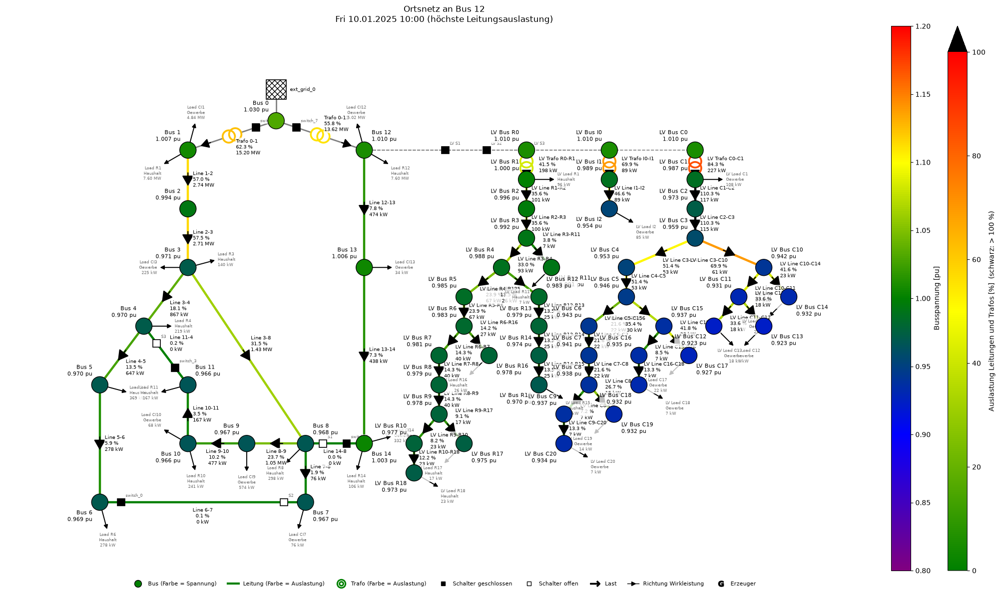

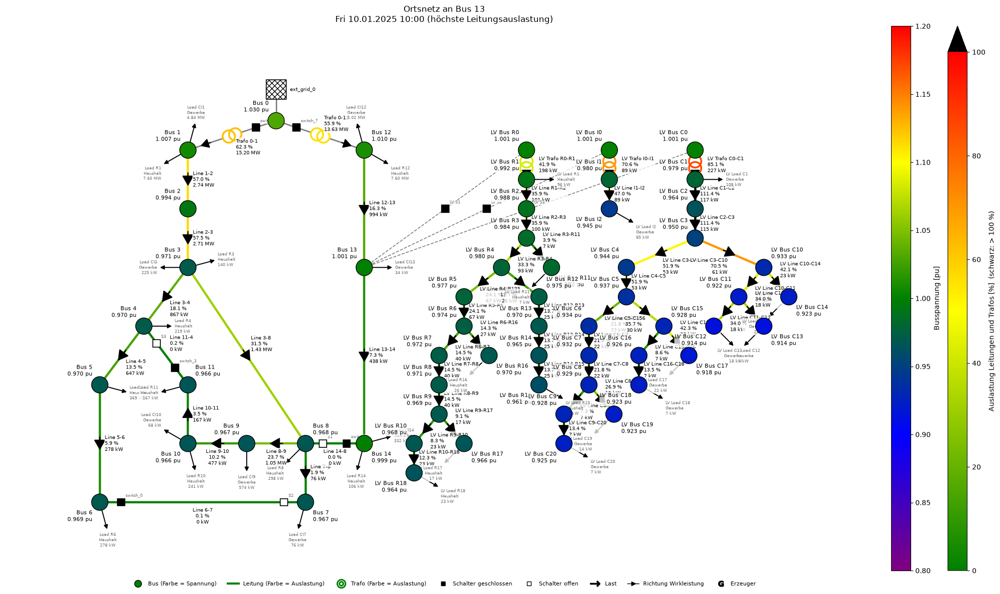

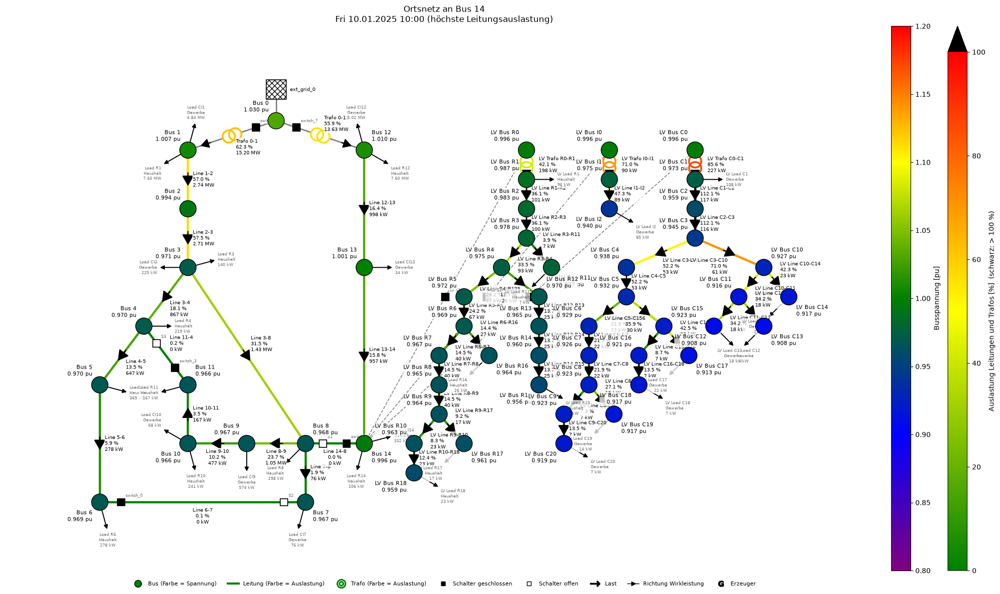

In [69]:
for at_bus, s in lv_sims.items():
    s.createDiagram(Diagram.NETWORK, time="max_loading", title=f"Ortsnetz an {at_bus}")

<a id="teil-3"></a>

---

# Task 4 – Teil 3: Spannungsband, Auslegung des Ortsnetzes und Schalterstellungen

**Ausgangspunkt:** CIGRE-MV-Netz ohne DER mit dem CIGRE-LV-Ortsnetz an Bus 12 (Ergebnis von Teil 2).

**Vorgehen:**

1. **Spannungsband festlegen:** Arbeitsgrenzen 0,90 bis 1,10 pu und ein engeres planerisches Spannungsband mit Marge.
2. **Leistungsspitzen der Ortsnetztrafos ermitteln:** Die Scheinleistung jedes Ortsnetztrafos wird Stunde für Stunde dargestellt. Daraus wird der passende pandapower-Standardtrafo gewählt.
3. **Stromspitzen der überlasteten Leitungen ermitteln:** Line C1-C2 und Line C2-C3 im Gewerbenetz sind in Teil 2 über 100 % ausgelastet. Eine Auslastung über 100 % ist im Dauerbetrieb nicht zulässig. Aus der Stromspitze wird eine passende pandapower-Standardleitung gewählt.
4. **Trafos und Leitungen ersetzen:** Bei der Auswahl bleibt genug Reserve für Leistungs- und Stromspitzen, denn die Simulation bildet nur den Normalbetrieb ab (Standardlastprofile ohne Spitzen einzelner Kunden, Stundenwerte, keine unvorhersehbaren Situationen).
5. **Schalterstellungen:** Das ausgelegte Netz wird wie in Teil 1 für alle 8 Stellungen der Trennschalter S1–S3 untersucht, statisch und als Zeitreihe.

Die automatische Regelung des Ortsnetztransformators folgt im nächsten Schritt.

## Aufgabenstellung

> *Legen Sie ein nachvollziehbares Spannungsband fest. Verwenden Sie für die Untersuchungen als maximal zulässige Abweichungen 0,90 bis 1,10 p.u. als Arbeitsgrenzen - ergänzen Sie zudem ein sinnvolles planerisches Spannungsband für Ihre Simulation mit ausreichender Marge zu diesen Grenzwerten.*

| Anforderung | Umsetzung |
|---|---|
| Arbeitsgrenzen 0,90 … 1,10 pu und planerisches Spannungsband | Abschnitt 1 |
| alle Schalterstellungen S1–S3 | Abschnitt 6 |
| Stufenschalter, Regelung, ungeregelt/geregelt, Lastflussumkehr | Teil 3b (`Task4-3b_Regelung.ipynb`) |

Zusätzlich wird hier das Ortsnetz ausgelegt (Abschnitte 2 bis 5), weil es in Teil 2 überlastete Betriebsmittel hatte.

## Importe

In [70]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

import simulation as sim
import szenarien as sz
import lvnetz
import auslegung as al
import netplan
import plots
from elements import Diagram, Profile
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

# Zeitreihen nur neu rechnen, wenn sich Netz, Einstellungen oder Daten geändert haben
sim.ONLY_RUN_IF_CHANGED = True

def baseline_net():
    """Unverändertes CIGRE-MV-Netz ohne dezentrale Erzeuger (Referenz aus Teil 1)."""
    return pn.create_cigre_network_mv(with_der=False)

ANSCHLUSSBUS = "Bus 12"                              # Ergebnis von Teil 2

Neues Modul `auslegung.py`: Spitzenwerte je Element (`spitzen`) und passende pandapower-Standardtrafos und -leitungen (`trafo_kandidaten`, `leitung_kandidaten`). Neue Diagrammarten: `Diagram.ACTIVE_POWER` (Wirkleistung), `Diagram.APPARENT_POWER` (Scheinleistung) und `Diagram.CURRENT` (Strom) für beliebige Elemente (Trafos, Leitungen, Busse, Lasten, Erzeuger, externes Netz), mit gestrichelter Linie beim Bemessungswert.

## 1 Spannungsband

**Arbeitsgrenzen 0,90 bis 1,10 pu:** Vorgabe des Arbeitsauftrags. In Verteilnetzen dürfen die Knotenspannungen betriebsbedingt bis zu 10 % nach oben oder unten abweichen [19, S. 712]; DIN EN 50160 legt für Nieder- und Mittelspannung ±10 % fest [15]. Eine Verletzung bedeutet unzulässigen Betrieb.

**Planerisches Spannungsband 0,95 bis 1,05 pu:** Zielband für die Auslegung und die spätere Regelung. Die Marge von 5 % zu den Arbeitsgrenzen deckt ab, was die Simulation nicht abbildet:

- Die BDEW-Profile beschreiben den Durchschnitt vieler Kunden; Spitzen einzelner Kunden (Durchlauferhitzer, Wallbox, Wärmepumpe) fehlen.
- Die Simulation rechnet mit Stundenwerten, DIN EN 50160 bewertet 10-Minuten-Mittelwerte; kurze Spitzen werden geglättet.
- Der Lastfluss ist symmetrisch; im Niederspannungsnetz sind die Phasen in der Realität ungleich belastet.
- Je Monat wird nur eine typische Woche betrachtet; Extremwetter und künftige Lasten (E-Mobilität, Wärmepumpen, weitere PV) fehlen.
- Ein Stufenschalter stellt die Spannung nur in Stufen von 2,5 % und mit Verzögerung.

Damit folgt das Planungsband dem Grundsatz, Sollwerte so zu setzen, dass die Werte „möglichst wieder mittig in den Toleranzbändern liegen“ [19, S. 716]. Die Bandbreite von ±5 % ist zudem deutlich größer als eine Stufe des Stufenschalters (2,5 %); ein Regler kann die Spannung damit ins Band bringen, ohne ständig hin- und herzuschalten.

| Band | untere Grenze | obere Grenze | Bedeutung |
|---|---|---|---|
| Arbeitsgrenzen | 0,90 pu | 1,10 pu | unzulässiger Betrieb bei Verletzung |
| Planungsband | 0,95 pu | 1,05 pu | Ziel für Auslegung und Regelung; Verletzung = Reserve aufgebraucht |

In [71]:
from auswertung import V_MIN, V_MAX, V_PLAN_MIN, V_PLAN_MAX, PLAN_MARKER, band_stunden

# Arbeitsgrenzen 0,90 … 1,10 pu, Planungsband 0,95 … 1,05 pu (Begründung in Abschnitt 1).
# PLAN_MARKER: orange Linien für das Planungsband (die Arbeitsgrenzen zeichnet die Software selbst rot).
# band_stunden(s): Stunden außerhalb von Planungsband und Arbeitsgrenzen sowie U min/max, getrennt nach MS und NS.

## 2 Ausgangslage: Ortsnetz an Bus 12

In [72]:
ref = sim.init("w4_baseline", baseline_net(), overwrite=True, assignProfiles=True)
vorher = ref.copy("w4_lv_Bus12", overwrite=True)
lvnetz.attach(vorher, ANSCHLUSSBUS)
vorher.runSimulation()
w, o = lvnetz.kennwerte_sim(vorher)
display(pd.DataFrame({"Wert": w, "Ort": o}).dropna(subset=["Wert"]))
band_stunden(vorher).to_frame("Ortsnetz an Bus 12 (CIGRE-Betriebsmittel)")

18 Profile zugeordnet: HAUSHALT: 10, GEWERBE: 8
101 Elemente angehängt an 'Bus 12' (Bus 'LV Bus 0' mit 'Bus 12' vereinigt).
15 Profile zugeordnet: GEWERBE: 9, HAUSHALT: 6
Simulation 'w4_lv_Bus12': unverändert seit dem Lauf vom 2026-11-08T20:34:36 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


,Wert,Ort
Leitung max MS [%],78.638368,Line 2-3
Leitung max NS [%],110.310837,LV Line C1-C2
Leitung min MS [%],0.037600,Line 14-8
Leitung min NS [%],1.171122,LV Line C8-C9
Ortsnetztrafo max [%],84.339955,LV Trafo C0-C1
Ortsnetztrafo min [%],11.594538,LV Trafo I0-I1
Stunden Leitung MS > 100 %,0.000000,NaN
Stunden Leitung NS > 100 %,65.000000,NaN
Stunden Ortsnetztrafo > 100 %,0.000000,NaN
Stunden Rückspeisung 110 kV,0.000000,NaN


,Ortsnetz an Bus 12 (CIGRE-Betriebsmittel)
Stunden < 0.95 MS,8.000000
Stunden > 1.05 MS,0.000000
Stunden < 0.9 MS,0.000000
Stunden > 1.1 MS,0.000000
U min MS [pu],0.948673
U max MS [pu],1.024344
Stunden < 0.95 NS,535.000000
Stunden > 1.05 NS,0.000000
Stunden < 0.9 NS,0.000000
Stunden > 1.1 NS,0.000000


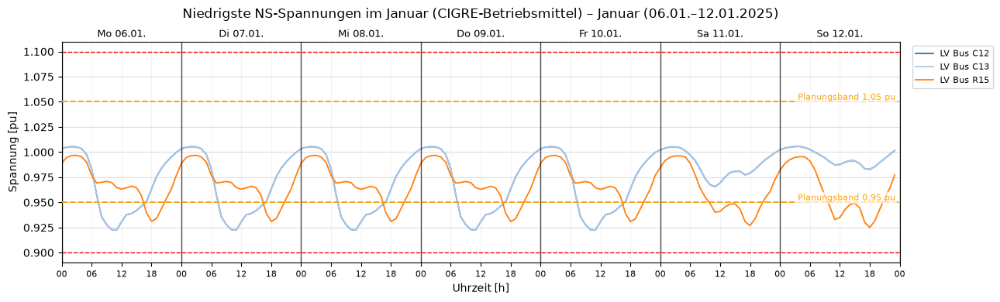

In [73]:
ns_busse = lvnetz.bus_groups(vorher.net)["NS"]
schwach = vorher.results.vm_pu[ns_busse].min().nsmallest(3).index.tolist()
vorher.createDiagram(Diagram.VOLTAGE, schwach, months=Month.JANUARY, markers=PLAN_MARKER,
                     title="Niedrigste NS-Spannungen im Januar (CIGRE-Betriebsmittel)")

## 3 Leistungsspitzen der Ortsnetztrafos

Die Trafos werden nach der **Scheinleistung** ausgelegt, weil Wicklungen und Kühlung durch den Strom belastet werden und dieser von der Scheinleistung abhängt. Die gestrichelten Linien zeigen die Bemessungsleistung $S_r$ der aktuell verbauten CIGRE-Trafos.

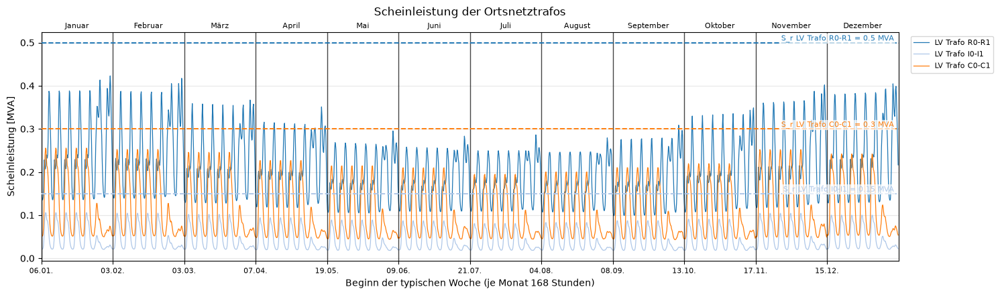

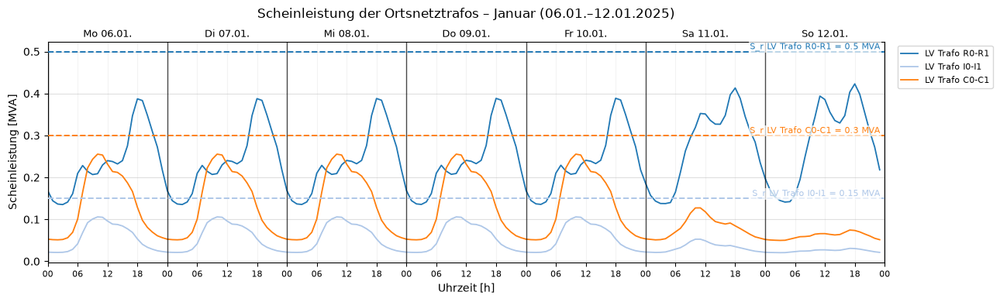

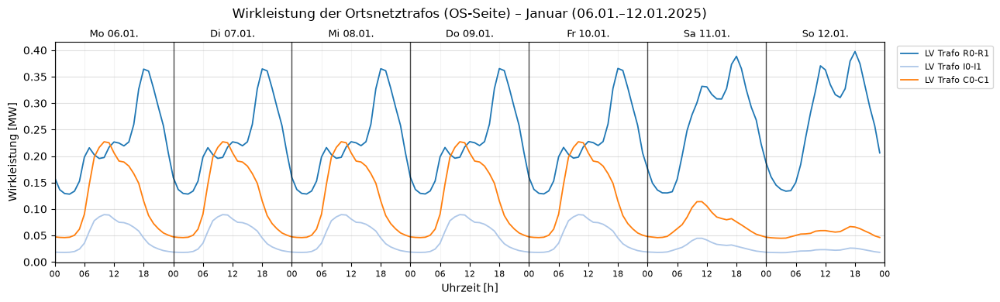

In [74]:
TRAFOS = ["LV Trafo R0-R1", "LV Trafo I0-I1", "LV Trafo C0-C1"]
vorher.createDiagram(Diagram.APPARENT_POWER, TRAFOS, layout="overview", title="Scheinleistung der Ortsnetztrafos")
vorher.createDiagram(Diagram.APPARENT_POWER, TRAFOS, months=Month.JANUARY, title="Scheinleistung der Ortsnetztrafos")
vorher.createDiagram(Diagram.ACTIVE_POWER, TRAFOS, months=Month.JANUARY, title="Wirkleistung der Ortsnetztrafos (OS-Seite)")

In [75]:
spitzen_trafo = al.spitzen(vorher, TRAFOS)
spitzen_trafo

,P max [MW],S max [MVA],Zeitpunkt S max,I max [A],Zeitpunkt I max,S_r [MVA],I_r [A],Auslastung max [%],Typ
LV Trafo R0-R1,0.397571,0.422913,Sun 12.01. 18:00,605.974252,Sun 12.01. 18:00,0.5,721.687836,83.966255,CIGRE (ohne Standardtyp)
LV Trafo I0-I1,0.089373,0.105865,Fri 10.01. 10:00,151.344269,Fri 10.01. 10:00,0.15,216.506351,69.902923,CIGRE (ohne Standardtyp)
LV Trafo C0-C1,0.227074,0.255458,Fri 10.01. 10:00,365.202719,Fri 10.01. 10:00,0.3,433.012702,84.339955,CIGRE (ohne Standardtyp)


**Auswahlregel:** Gewählt wird der kleinste pandapower-Standardtrafo 20/0,4 kV, bei dem die Spitzenlast höchstens **70 %** der Bemessungsleistung erreicht (`MAX_AUSLASTUNG`). Die Reserve von 30 % deckt Leistungsspitzen, die im Normalbetrieb mit Standardlastprofilen nicht enthalten sind, und künftigen Lastzuwachs ab. Verfügbare Standardtypen: 0,25 MVA, 0,4 MVA und 0,63 MVA.

In [76]:
MAX_AUSLASTUNG = 0.70

trafo_wahl = {}
for t in TRAFOS:
    k = al.trafo_kandidaten(vorher.net, spitzen_trafo.at[t, "S max [MVA]"], MAX_AUSLASTUNG)
    trafo_wahl[t] = al.kleinster_geeigneter(k)
    print(f"{t}: S max = {spitzen_trafo.at[t, 'S max [MVA]']:.3f} MVA → {trafo_wahl[t]}")
    display(k)

LV Trafo R0-R1: S max = 0.423 MVA → 0.63 MVA 20/0.4 kV


,sn_mva,vk_percent,vkr_percent,pfe_kw,i0_percent,vector_group,shift_degree,tap_side,tap_min,tap_max,tap_step_percent,Auslastung bei Spitze [%],geeignet
0.25 MVA 20/0.4 kV,0.25,6.0,1.440,0.80,0.3200,Yzn5,150,hv,-2,2,2.5,169.165123,False
0.4 MVA 20/0.4 kV,0.40,6.0,1.425,1.35,0.3375,Dyn5,150,hv,-2,2,2.5,105.728202,False
0.63 MVA 20/0.4 kV,0.63,6.0,1.206,1.65,0.2619,Dyn5,150,hv,-2,2,2.5,67.129017,True


LV Trafo I0-I1: S max = 0.106 MVA → 0.25 MVA 20/0.4 kV


,sn_mva,vk_percent,vkr_percent,pfe_kw,i0_percent,vector_group,shift_degree,tap_side,tap_min,tap_max,tap_step_percent,Auslastung bei Spitze [%],geeignet
0.25 MVA 20/0.4 kV,0.25,6.0,1.440,0.80,0.3200,Yzn5,150,hv,-2,2,2.5,42.345929,True
0.4 MVA 20/0.4 kV,0.40,6.0,1.425,1.35,0.3375,Dyn5,150,hv,-2,2,2.5,26.466206,True
0.63 MVA 20/0.4 kV,0.63,6.0,1.206,1.65,0.2619,Dyn5,150,hv,-2,2,2.5,16.803940,True


LV Trafo C0-C1: S max = 0.255 MVA → 0.4 MVA 20/0.4 kV


,sn_mva,vk_percent,vkr_percent,pfe_kw,i0_percent,vector_group,shift_degree,tap_side,tap_min,tap_max,tap_step_percent,Auslastung bei Spitze [%],geeignet
0.25 MVA 20/0.4 kV,0.25,6.0,1.440,0.80,0.3200,Yzn5,150,hv,-2,2,2.5,102.183245,False
0.4 MVA 20/0.4 kV,0.40,6.0,1.425,1.35,0.3375,Dyn5,150,hv,-2,2,2.5,63.864528,True
0.63 MVA 20/0.4 kV,0.63,6.0,1.206,1.65,0.2619,Dyn5,150,hv,-2,2,2.5,40.548907,True


## 4 Stromspitzen der Leitungen

Strom auf Line C1-C2 und Line C2-C3 (Freileitung OH1, Bemessungsstrom 172 A nach [18]) über alle 12 Wochen und in der Januarwoche:

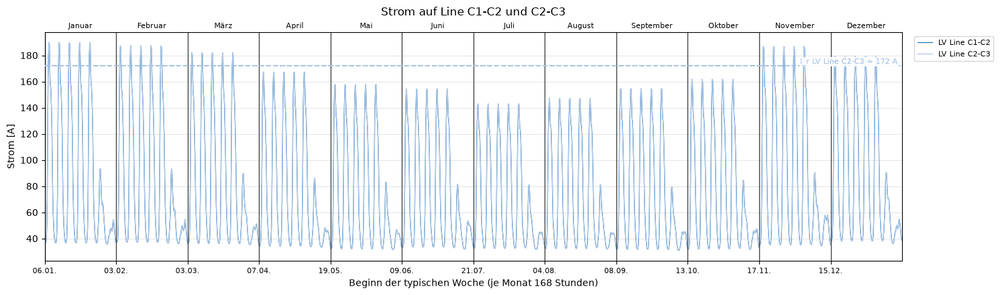

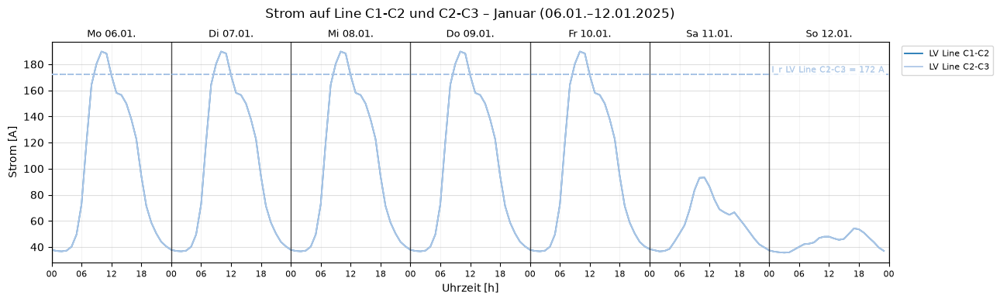

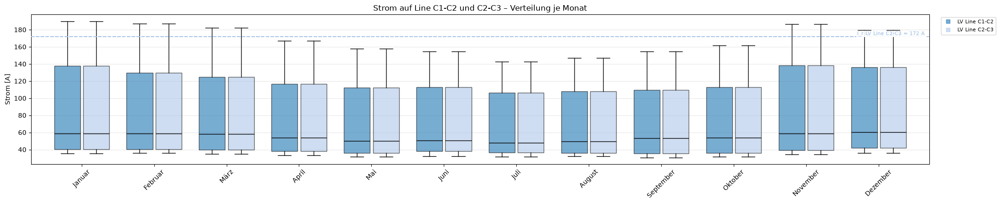

In [77]:
LEITUNGEN = ["LV Line C1-C2", "LV Line C2-C3"]
vorher.createDiagram(Diagram.CURRENT, LEITUNGEN, layout="overview", title="Strom auf Line C1-C2 und C2-C3")
vorher.createDiagram(Diagram.CURRENT, LEITUNGEN, months=Month.JANUARY, title="Strom auf Line C1-C2 und C2-C3")
vorher.createDiagram(Diagram.CURRENT, LEITUNGEN, layout="boxplot", title="Strom auf Line C1-C2 und C2-C3")

Zur Einordnung die Spitzenwerte **aller** LV-Leitungen, sortiert nach der höchsten Auslastung:

In [78]:
lv_leitungen = lvnetz.element_groups(vorher.net)["line_NS"]
spitzen_ltg = al.spitzen(vorher, lv_leitungen).sort_values("Auslastung max [%]", ascending=False)
plots.table(spitzen_ltg.drop(columns=["S_r [MVA]"]), decimals=1)

,P max [MW],S max [MVA],Zeitpunkt S max,I max [A],Zeitpunkt I max,I_r [A],Auslastung max [%],Typ
LV Line C1-C2,0.116953,0.129756,Fri 10.01. 10:00,189.734640,Fri 10.01. 10:00,172.000000,110.310837,OH1
LV Line C2-C3,0.115360,0.127921,Fri 10.01. 10:00,189.734640,Fri 10.01. 10:00,172.000000,110.310837,OH1
LV Line R2-R3,0.202533,0.213277,Sun 12.01. 18:00,314.170828,Sun 12.01. 18:00,430.000000,73.062983,UG1
LV Line R1-R2,0.204212,0.215142,Sun 12.01. 18:00,314.170828,Sun 12.01. 18:00,430.000000,73.062983,UG1
LV Line C3-C10,0.060812,0.067307,Fri 10.01. 10:00,101.283425,Fri 10.01. 10:00,145.000000,69.850638,OH2
LV Line R3-R4,0.186580,0.196389,Sun 12.01. 18:00,291.845672,Sun 12.01. 18:00,430.000000,67.871086,UG1
LV Line C3-C4,0.052955,0.058780,Fri 10.01. 10:00,88.452067,Fri 10.01. 10:00,172.000000,51.425620,OH1
LV Line C4-C5,0.052609,0.058381,Fri 10.01. 10:00,88.452067,Fri 10.01. 10:00,172.000000,51.425620,OH1
LV Line R4-R5,0.133586,0.140677,Sun 12.01. 18:00,210.780941,Sun 12.01. 18:00,430.000000,49.018823,UG1
LV Line R5-R6,0.132831,0.139838,Sun 12.01. 18:00,210.780941,Sun 12.01. 18:00,430.000000,49.018823,UG1


**Auswahlregel:** Die Leitungen sind Freileitungen; ersetzt wird deshalb durch eine pandapower-Standard-Freileitung der Niederspannung (`voltage_rating = "LV"`, `type = "ol"`). Gewählt wird die kleinste, bei der der Spitzenstrom höchstens 70 % des Bemessungsstroms erreicht.

In [79]:
leitung_wahl = {}
for l in LEITUNGEN:
    k = al.leitung_kandidaten(vorher.net, spitzen_ltg.at[l, "I max [A]"], art="ol", max_auslastung=MAX_AUSLASTUNG)
    leitung_wahl[l] = al.kleinster_geeigneter(k)
    print(f"{l}: I max = {spitzen_ltg.at[l, 'I max [A]']:.0f} A → {leitung_wahl[l]}")
display(k)

LV Line C1-C2: I max = 190 A → 94-AL1/15-ST1A 0.4
LV Line C2-C3: I max = 190 A → 94-AL1/15-ST1A 0.4


,type,q_mm2,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,I_r [A],Auslastung bei Spitze [%],geeignet
15-AL1/3-ST1A 0.4,ol,16.0,1.8769,0.350,11.00,105.0,180.699657,False
24-AL1/4-ST1A 0.4,ol,24.0,1.2012,0.335,11.25,140.0,135.524743,False
48-AL1/8-ST1A 0.4,ol,48.0,0.5939,0.300,12.20,210.0,90.349829,False
94-AL1/15-ST1A 0.4,ol,94.0,0.3060,0.290,13.20,350.0,54.209897,True


## 5 Trafos und Leitungen ersetzen

Das ausgelegte Netz ist eine Kopie der Ausgangslage, in der nur die Typen der drei Ortsnetztrafos und der beiden Leitungen geändert werden (`changeParameter(..., "std_type", ...)` übernimmt alle Typparameter). Alles andere bleibt gleich.

**Folgen der Standardtrafos:** $u_k$ = 6 % statt 4,1 %, Eisen- und Leerlaufverluste, Schaltgruppe mit 150° Phasenverschiebung (die NS-Winkel verschieben sich deshalb gegenüber Teil 2) und ein Stufenschalter auf der OS-Seite mit ±2 × 2,5 %, Stellung 0. Bei Verteiltransformatoren ist dieser Stellbereich üblicherweise ein Umsteller, der nur stromlos verstellt wird [19, S. 424]; für die Regelung im nächsten Schritt wird derselbe Stellbereich als Laststufenschalter (regelbarer Ortsnetztrafo) genutzt.

In [80]:
ausgelegt = vorher.copy("w4_t3_ausgelegt", overwrite=True)
for name, typ in {**trafo_wahl, **leitung_wahl}.items():
    ausgelegt.changeParameter(name, "std_type", typ)
display(ausgelegt.changedParameters())
ausgelegt.runSimulation()

,Element,Typ,Parameter,alt,neu
0,LV Line C1-C2,Leitung,std_type,OH1,94-AL1/15-ST1A 0.4
1,LV Line C1-C2,Leitung,r_ohm_per_km,0.4917,0.306
2,LV Line C1-C2,Leitung,x_ohm_per_km,0.2847,0.29
3,LV Line C1-C2,Leitung,c_nf_per_km,0.0,13.2
4,LV Line C1-C2,Leitung,max_i_ka,0.172,0.35
5,LV Line C2-C3,Leitung,std_type,OH1,94-AL1/15-ST1A 0.4
6,LV Line C2-C3,Leitung,r_ohm_per_km,0.4917,0.306
7,LV Line C2-C3,Leitung,x_ohm_per_km,0.2847,0.29
8,LV Line C2-C3,Leitung,c_nf_per_km,0.0,13.2
9,LV Line C2-C3,Leitung,max_i_ka,0.172,0.35


Simulation 'w4_t3_ausgelegt': unverändert seit dem Lauf vom 2026-11-08T20:39:43 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, line_p_mw, line_pl_mw, trafo_loading, trafo_p_mw, trafo_pl_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, line_q_mvar, trafo_q_mvar, trafo_i_hv_ka, trafo_i_lv_ka, bus_p_mw, bus_q_mvar, ext_grid_q_mvar, load_q_mvar, sgen_q_mvar, tap_pos, switch_closed, storage_p_mw, storage_soc_percent, element_p_mw, info

**Vergleich vorher/nachher** (gleiche Randbedingungen, nur die Betriebsmitteltypen geändert):

In [81]:
vergl = pd.DataFrame({
    "vorher (CIGRE)": pd.concat([lvnetz.kennwerte_sim(vorher)[0], band_stunden(vorher)]),
    "nachher (Standardtypen)": pd.concat([lvnetz.kennwerte_sim(ausgelegt)[0], band_stunden(ausgelegt)]),
})
vergl.index.name = "Kennwert"
plots.table(vergl.astype(float), decimals=3)

,vorher (CIGRE),nachher (Standardtypen)
Kennwert,,
U min MS [pu],0.949,0.949
U max MS [pu],1.024,1.024
U min NS [pu],0.923,0.923
U max NS [pu],1.021,1.021
Winkel min MS [°],-38.061,-38.061
Winkel max MS [°],-31.255,-31.256
Winkel min NS [°],-66.698,172.983
Winkel max NS [°],-61.363,178.655
Leitung min MS [%],0.038,0.038


vorher                                                              nachher                                                   
               S max [MVA]   I max [A] Auslastung max [%]                       Typ S max [MVA]   I max [A] Auslastung max [%]                 Typ
LV Trafo R0-R1    0.422913  605.974252          83.966255  CIGRE (ohne Standardtyp)    0.425221  607.048979          66.758075  0.63 MVA 20/0.4 kV
LV Trafo I0-I1    0.105865  151.344269          69.902923  CIGRE (ohne Standardtyp)    0.106237  150.893085          41.816718  0.25 MVA 20/0.4 kV
LV Trafo C0-C1    0.255458  365.202719          84.339955  CIGRE (ohne Standardtyp)    0.256016  364.264979          63.092545   0.4 MVA 20/0.4 kV
LV Line C1-C2     0.129756   189.73464         110.310837                       OH1    0.128596  188.430449          53.837271  94-AL1/15-ST1A 0.4
LV Line C2-C3     0.127921   189.73464         110.310837                       OH1    0.127312  188.430461          53.837275  94-AL1/15-ST1A 0.4

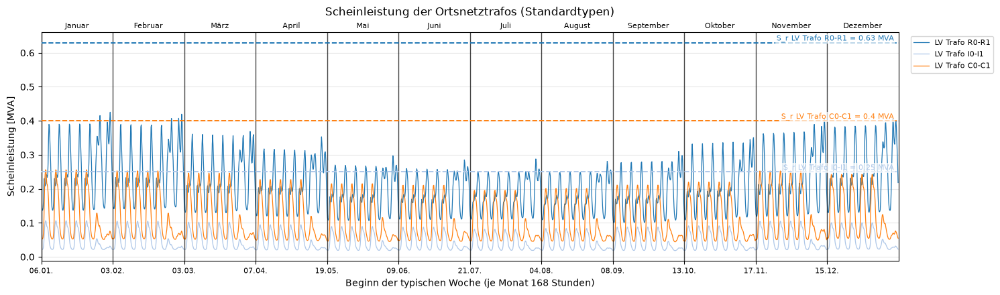

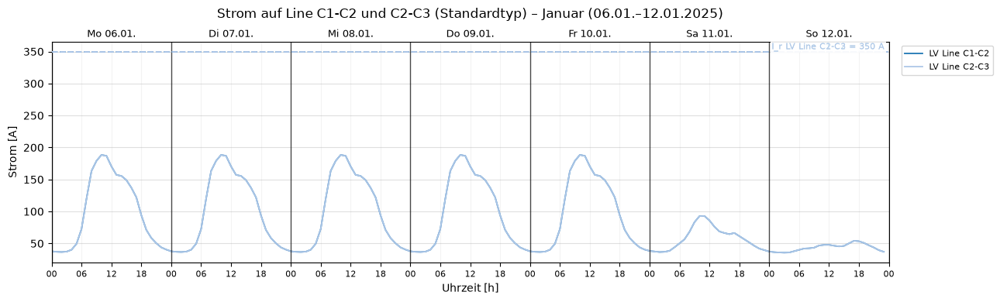

In [82]:
display(pd.concat({"vorher": al.spitzen(vorher, TRAFOS + LEITUNGEN)[["S max [MVA]", "I max [A]", "Auslastung max [%]", "Typ"]],
                   "nachher": al.spitzen(ausgelegt, TRAFOS + LEITUNGEN)[["S max [MVA]", "I max [A]", "Auslastung max [%]", "Typ"]]}, axis=1))
ausgelegt.createDiagram(Diagram.APPARENT_POWER, TRAFOS, layout="overview", title="Scheinleistung der Ortsnetztrafos (Standardtypen)")
ausgelegt.createDiagram(Diagram.CURRENT, LEITUNGEN, months=Month.JANUARY, title="Strom auf Line C1-C2 und C2-C3 (Standardtyp)")

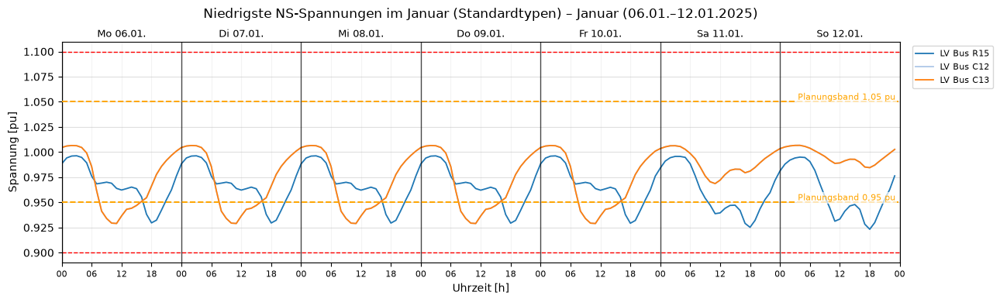

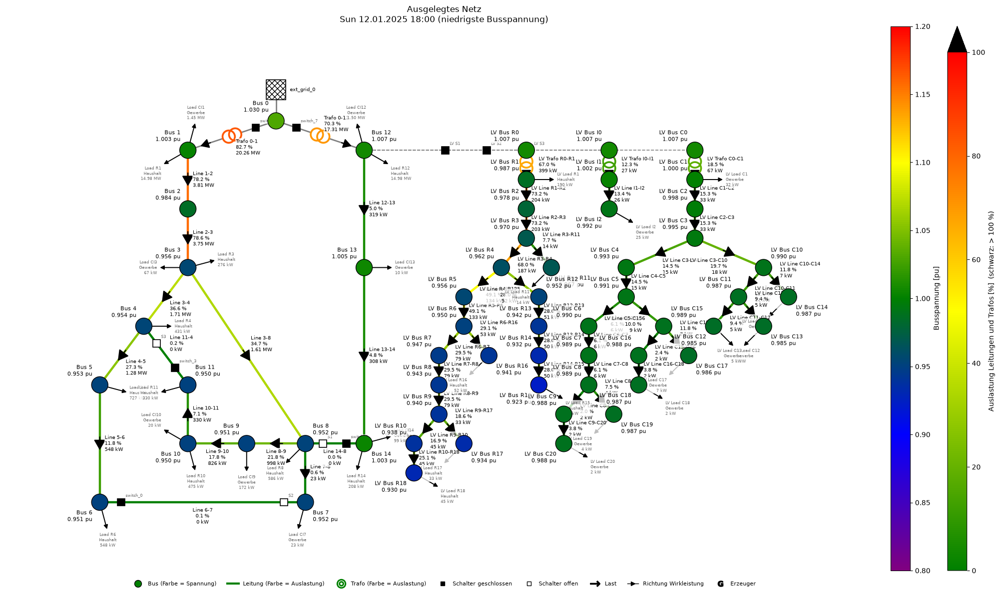

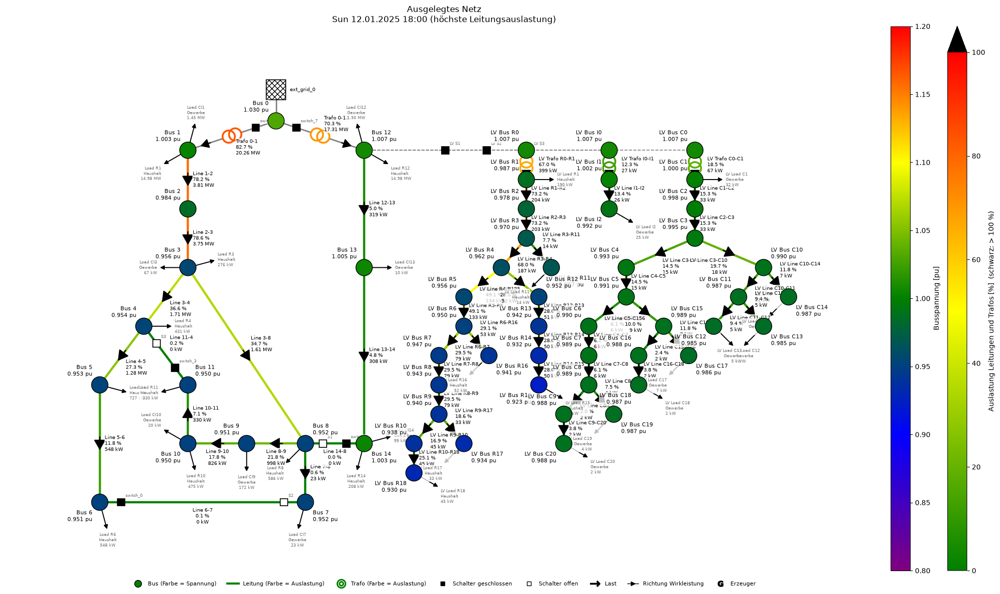

In [83]:
schwach = ausgelegt.results.vm_pu[ns_busse].min().nsmallest(3).index.tolist()
ausgelegt.createDiagram(Diagram.VOLTAGE, schwach, months=Month.JANUARY, markers=PLAN_MARKER,
                        title="Niedrigste NS-Spannungen im Januar (Standardtypen)")
ausgelegt.createDiagram(Diagram.NETWORK, time=["min", "max_loading"], title="Ausgelegtes Netz")

**Ergebnis der Auslegung (Zeitreihe, alle Trennschalter offen):**

| Betriebsmittel | vorher (CIGRE) | Spitze | nachher (pandapower-Standardtyp) | höchste Auslastung nachher |
|---|---|---|---|---|
| LV Trafo R0-R1 | 0,50 MVA, 84,0 % | 0,423 MVA (So 12.01. 18:00) | 0,63 MVA 20/0.4 kV | 66,8 % |
| LV Trafo I0-I1 | 0,15 MVA, 69,9 % | 0,106 MVA (Fr 10.01. 10:00) | 0,25 MVA 20/0.4 kV | 41,8 % |
| LV Trafo C0-C1 | 0,30 MVA, 84,3 % | 0,255 MVA (Fr 10.01. 10:00) | 0,4 MVA 20/0.4 kV | 63,1 % |
| LV Line C1-C2, C2-C3 | OH1, 172 A, 110,3 % | 190 A (Fr 10.01. 10:00) | 94-AL1/15-ST1A 0.4, 350 A | 53,8 % |

- Das Wohngebiet hat seine Spitze am Winterabend (Haushaltsprofil H25), Industrie und Gewerbe am Werktagvormittag (G25).
- Beim Wohngebiet reicht der 0,4-MVA-Trafo nicht (Spitze 106 %), beim Gewerbe nicht der 0,25-MVA-Trafo (102 %). Für die Industrie ist schon der kleinste Standardtyp mit 42 % reichlich bemessen.
- Bei der Leitung wäre 48-AL1/8-ST1A (210 A) mit 90 % zu knapp; gewählt wird 94-AL1/15-ST1A mit 54 %.
- Nach dem Tausch ist kein Betriebsmittel mehr über 100 % ausgelastet. Die höchste Auslastung im Ortsnetz haben jetzt die Kabel LV Line R1-R2 und R2-R3 (UG1, 430 A) mit 73 %; sie liegen knapp über der Auslegungsreserve von 70 %, aber deutlich unter 100 %, und wurden deshalb nicht getauscht.
- **Spannung:** Die niedrigste NS-Spannung bleibt bei 0,923 pu (LV Bus C12), die Stunden unter 0,95 pu sinken von 535 auf 450. Der größere Leiterquerschnitt im Gewerbenetz verringert den Spannungsfall, der höhere $u_k$ der Standardtrafos (6 % statt 4,1 %) wird durch ihre geringere Auslastung weitgehend ausgeglichen. Die Arbeitsgrenzen werden nicht verletzt, das Planungsband aber in 450 Stunden unterschritten; das ist die Aufgabe für die Regelung.
- **Winkel:** Durch die Schaltgruppe Dyn5/Yzn5 (150°) liegen die NS-Winkel jetzt bei etwa +173° bis +179° statt −61° bis −67° (−30° − 150° = −180°, als Winkel zwischen −180° und +180° dargestellt). Das ist eine reine Bezugsverschiebung und keine physikalische Änderung des Leistungsflusses.

## 6 Alle Schalterstellungen S1–S3

Aufbau wie in Teil 1: Jeder Schaltzustand startet von einer Kopie des ausgelegten Netzes; geändert wird nur die Stellung der Trennschalter S1–S3 im MV-Netz (Schlüssel S1 S2 S3, 1 = geschlossen). Die Schalter LV S1–S3 im Ortsnetz bleiben geschlossen.

### 6.1 Statischer Lastfluss

In [84]:
static = sz.statisch_alle(lambda: copy.deepcopy(ausgelegt.net))
sz.konvergenz(static)

,Schaltzustand,konvergiert,Iterationen,Hinweis
Schlüssel,,,,
000,S1 offen · S2 offen · S3 offen,ja,4,
001,S1 offen · S2 offen · S3 zu,ja,4,
010,S1 offen · S2 zu · S3 offen,ja,4,
011,S1 offen · S2 zu · S3 zu,ja,4,
100,S1 zu · S2 offen · S3 offen,ja,4,
101,S1 zu · S2 offen · S3 zu,ja,4,
110,S1 zu · S2 zu · S3 offen,ja,4,
111,S1 zu · S2 zu · S3 zu,ja,4,


In [85]:
bil = sz.bilanzen(static)
display(plots.table(bil.drop(columns=["Bus U min", "Leitung mit max"]).astype(float).T, decimals=3))
bil[["Bus U min", "Leitung mit max"]].T

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Last P [MW],45.429,45.429,45.429,45.429,45.429,45.429,45.429,45.429
Erzeugung P [MW],0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Bezug ext. Netz P [MW],45.765,45.761,45.765,45.760,45.686,45.686,45.685,45.684
Bezug ext. Netz Q [Mvar],16.833,16.824,16.832,16.823,16.591,16.591,16.588,16.587
Verluste Leitungen [MW],0.254,0.250,0.254,0.249,0.176,0.175,0.175,0.174
Verluste Trafos [MW],0.082,0.082,0.082,0.082,0.081,0.081,0.081,0.081
Verluste gesamt [MW],0.337,0.332,0.337,0.332,0.257,0.257,0.256,0.255
Verluste [% der Last],0.741,0.731,0.741,0.730,0.566,0.565,0.564,0.562
U min [pu],0.913,0.913,0.913,0.913,0.910,0.910,0.910,0.910
Leitung max [%],96.959,96.827,96.956,96.812,74.306,74.300,74.307,74.301


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus U min,LV Bus R15,LV Bus R15,LV Bus R15,LV Bus R15,LV Bus R15,LV Bus R15,LV Bus R15,LV Bus R15
Leitung mit max,Line 2-3,Line 2-3,Line 2-3,Line 2-3,LV Line R1-R2,LV Line R1-R2,LV Line R2-R3,LV Line R1-R2


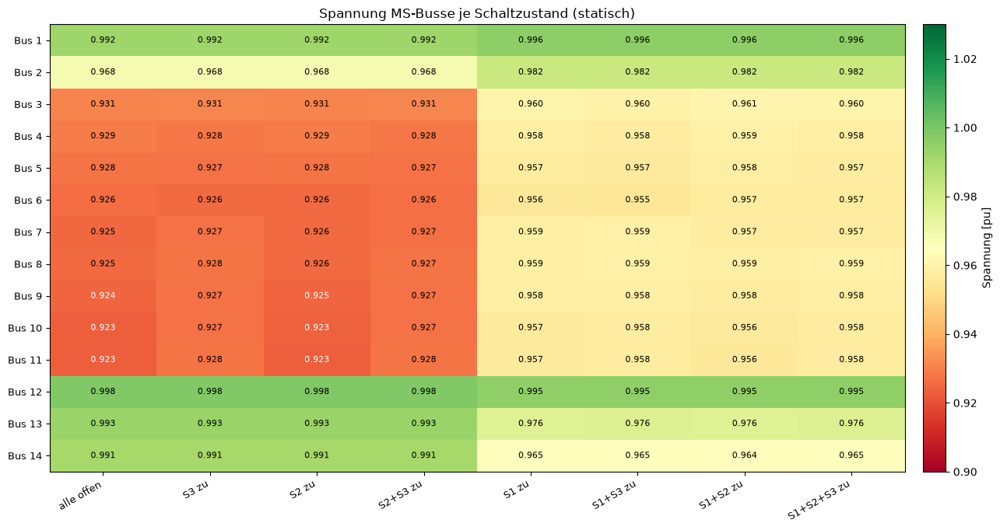

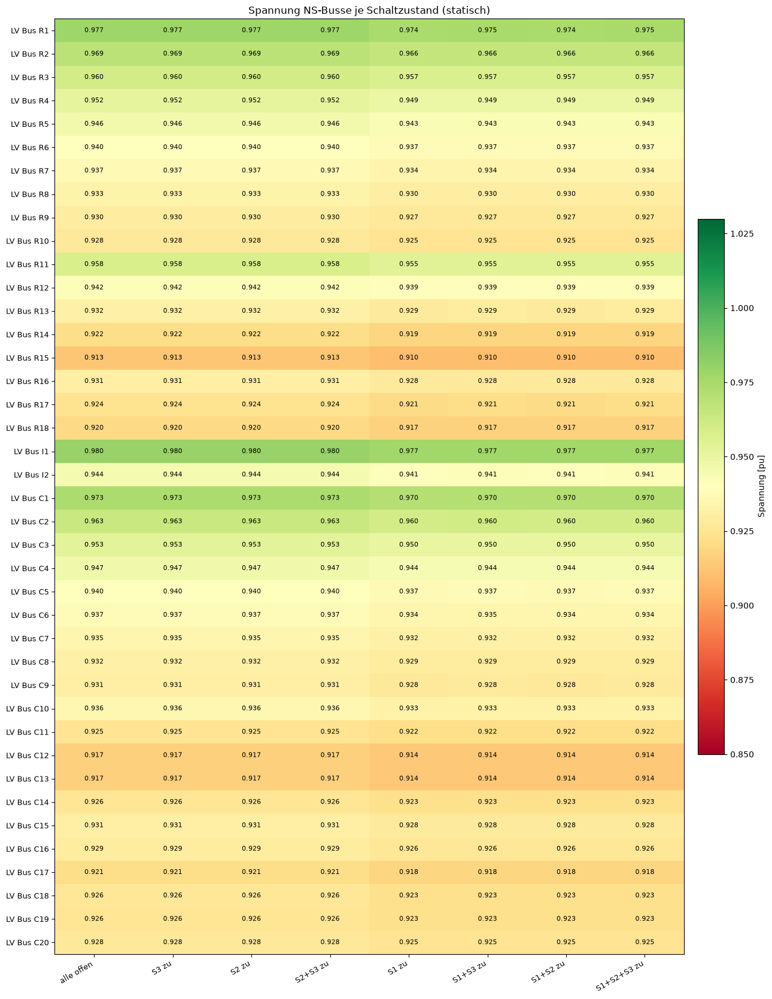

In [86]:
g = lvnetz.bus_groups(ausgelegt.net)
e = lvnetz.element_groups(ausgelegt.net)
vm_all = sz.vergleich(static, "vm_pu")
sz.heatmap(vm_all.loc[g["MS"]], "Spannung MS-Busse je Schaltzustand (statisch)", "Spannung [pu]", cmap="RdYlGn", vmin=0.90, vmax=1.03)
plt.show()
sz.heatmap(vm_all.loc[g["NS"]], "Spannung NS-Busse je Schaltzustand (statisch)", "Spannung [pu]", cmap="RdYlGn", vmin=0.85, vmax=1.03)
plt.show()

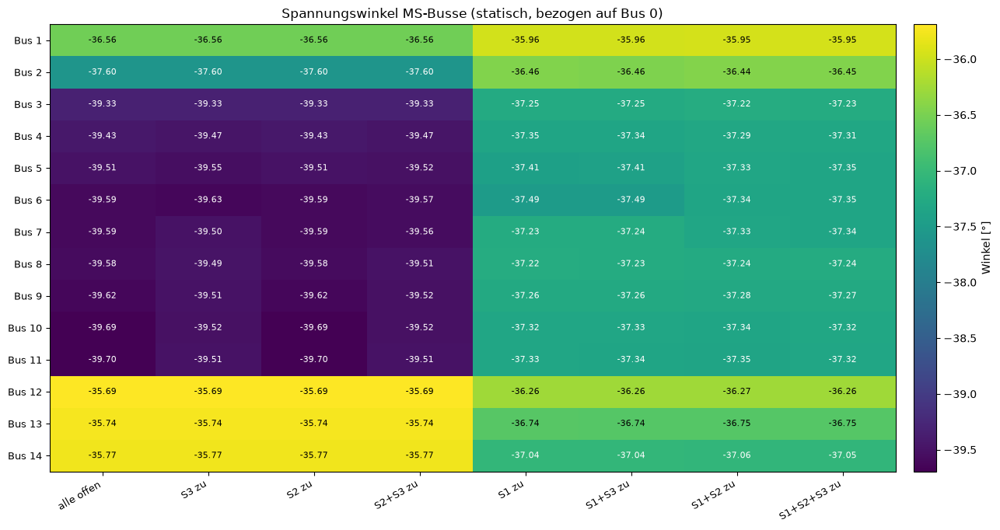

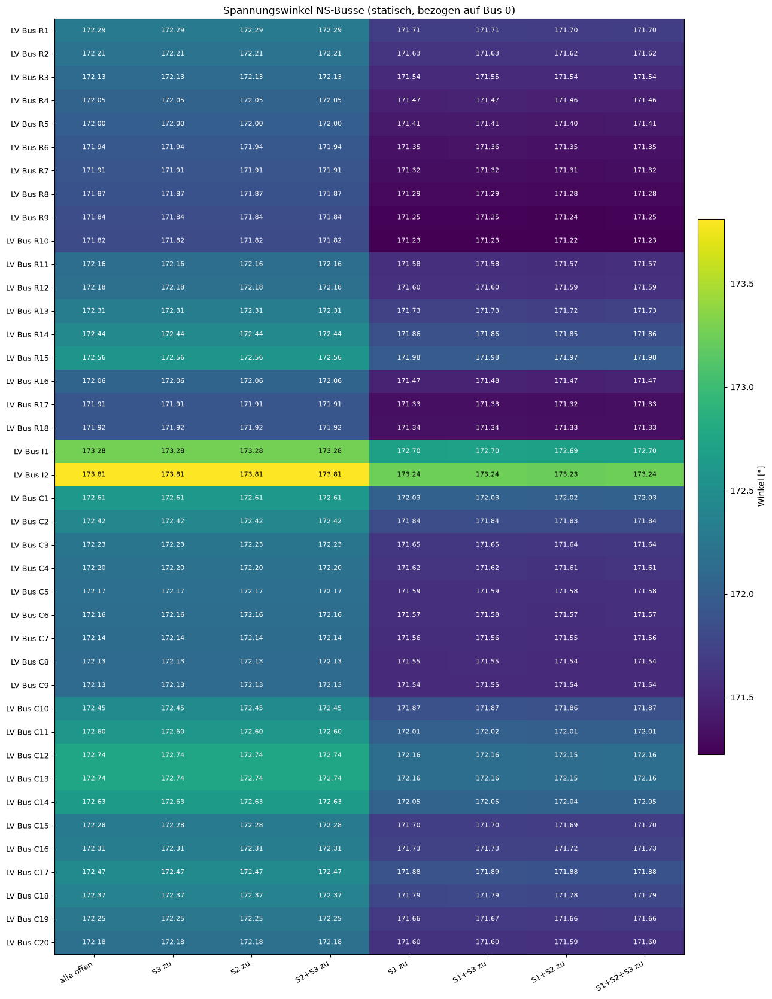

In [87]:
va_all = sz.vergleich(static, "va_degree")
sz.heatmap(va_all.loc[g["MS"]], "Spannungswinkel MS-Busse (statisch, bezogen auf Bus 0)", "Winkel [°]", fmt="{:.2f}")
plt.show()
sz.heatmap(va_all.loc[g["NS"]], "Spannungswinkel NS-Busse (statisch, bezogen auf Bus 0)", "Winkel [°]", fmt="{:.2f}")
plt.show()

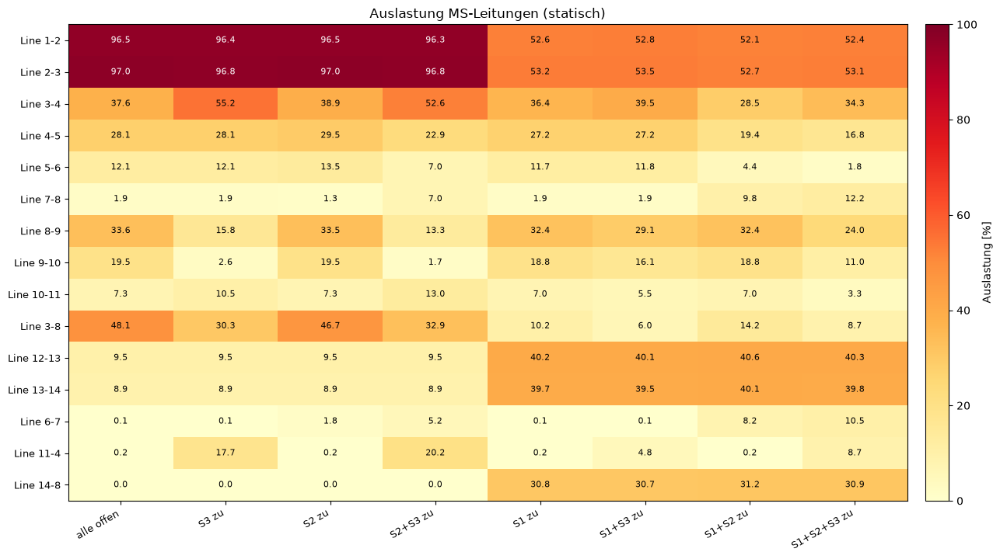

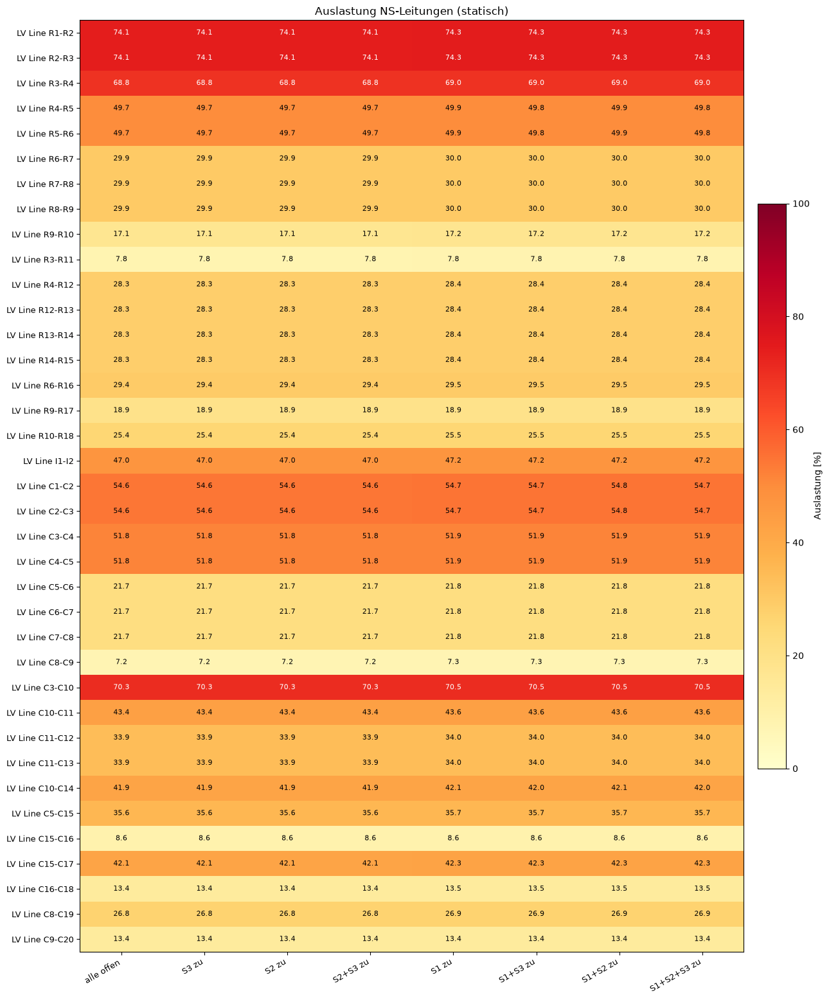

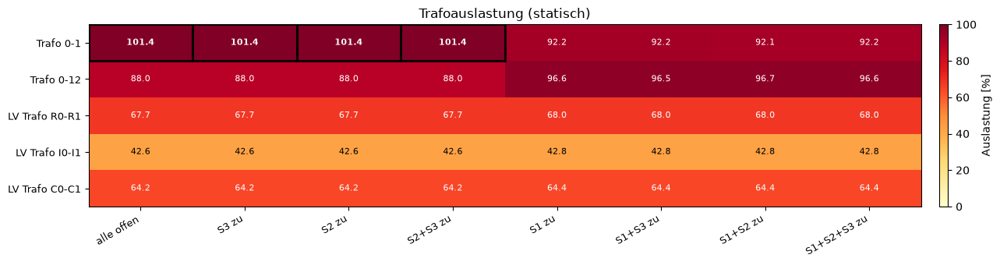

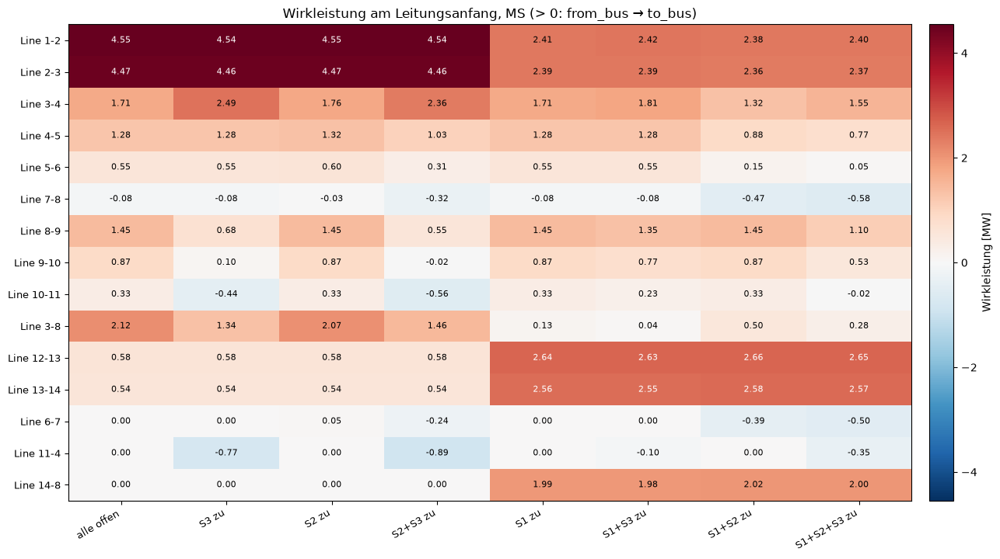

In [88]:
ll_all = sz.vergleich(static, "loading_percent")
sz.heatmap(ll_all.loc[e["line_MS"]], "Auslastung MS-Leitungen (statisch)", "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
sz.heatmap(ll_all.loc[e["line_NS"]], "Auslastung NS-Leitungen (statisch)", "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
sz.heatmap(sz.vergleich(static, "trafo_loading"), "Trafoauslastung (statisch)", "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
p_all = sz.vergleich(static, "p_from_mw")
lim = np.nanmax(np.abs(p_all.loc[e["line_MS"]].to_numpy()))
sz.heatmap(p_all.loc[e["line_MS"]], "Wirkleistung am Leitungsanfang, MS (> 0: from_bus → to_bus)", "Wirkleistung [MW]",
           cmap="RdBu_r", vmin=-lim, vmax=lim, fmt="{:.2f}")
plt.show()

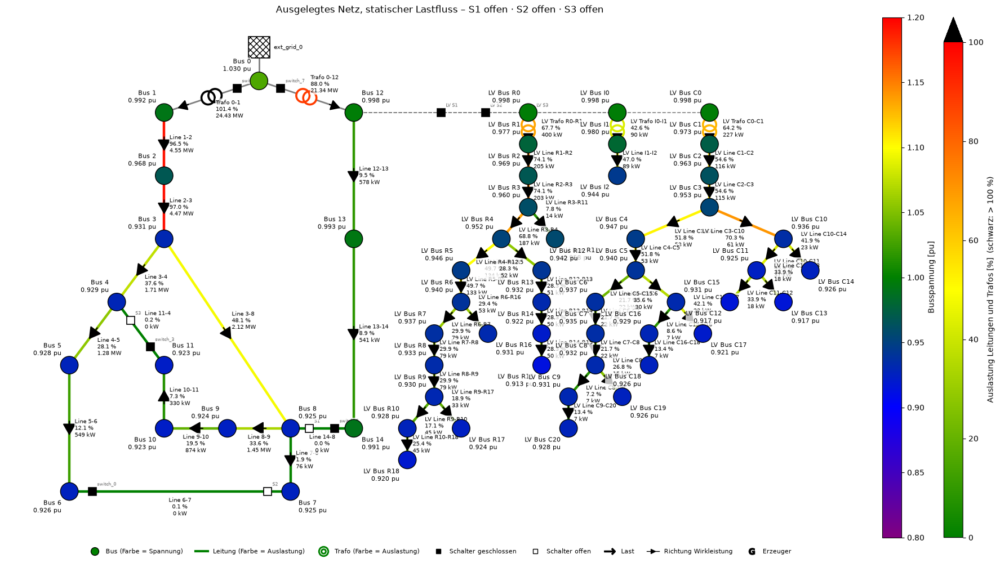

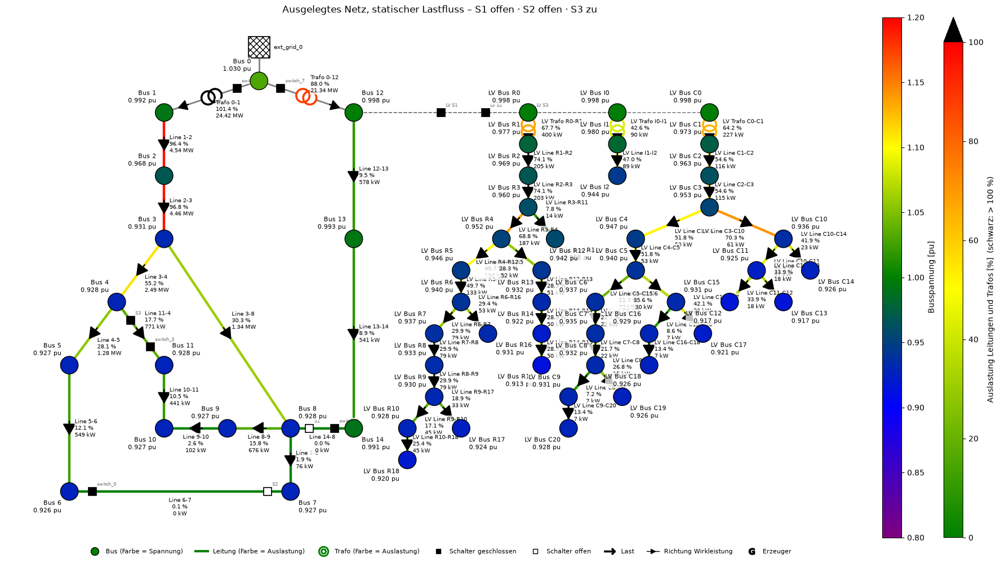

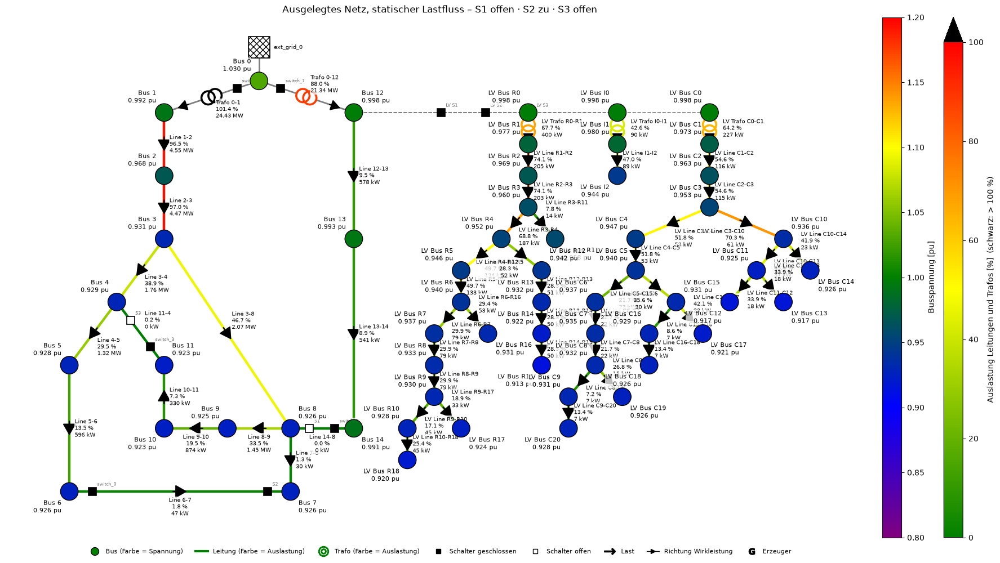

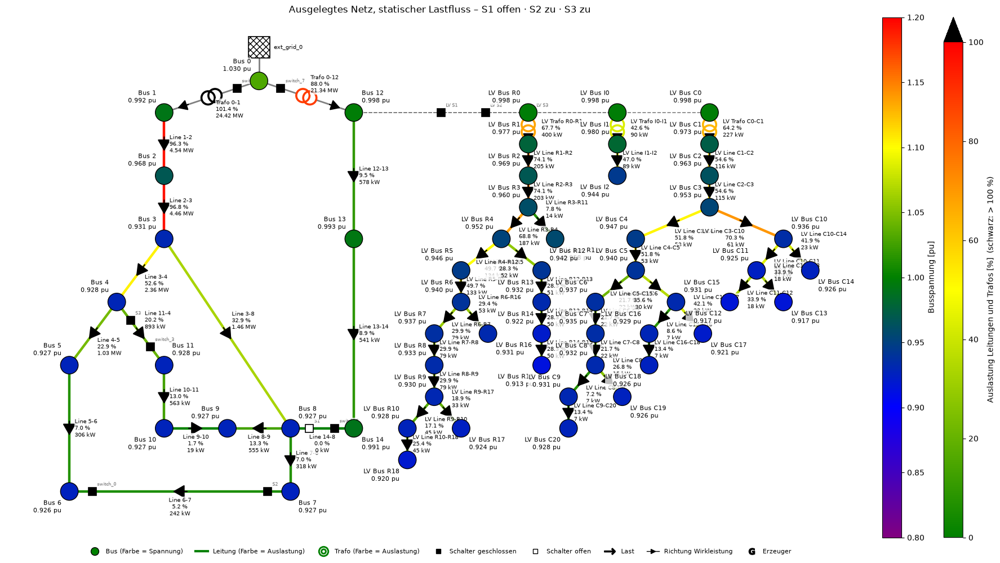

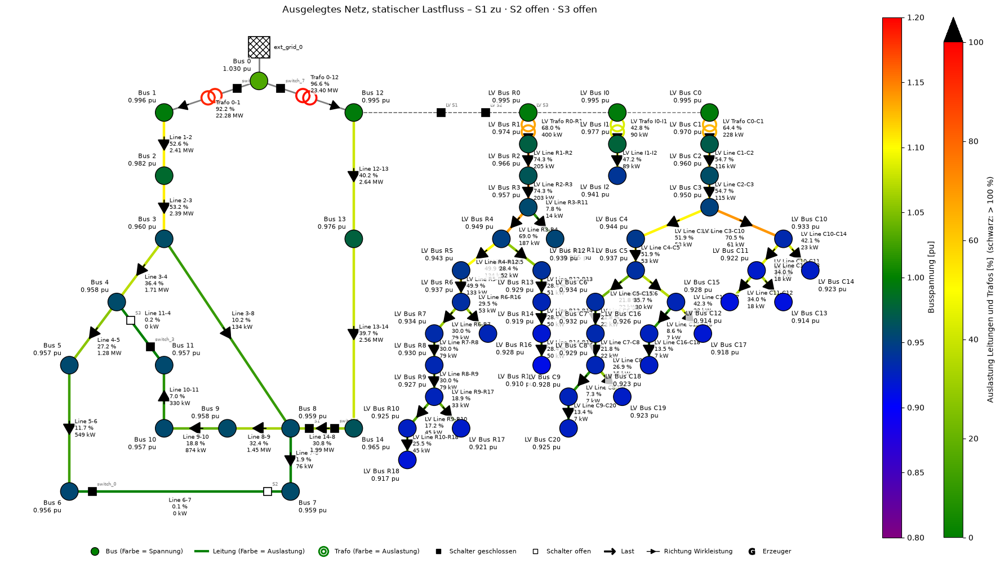

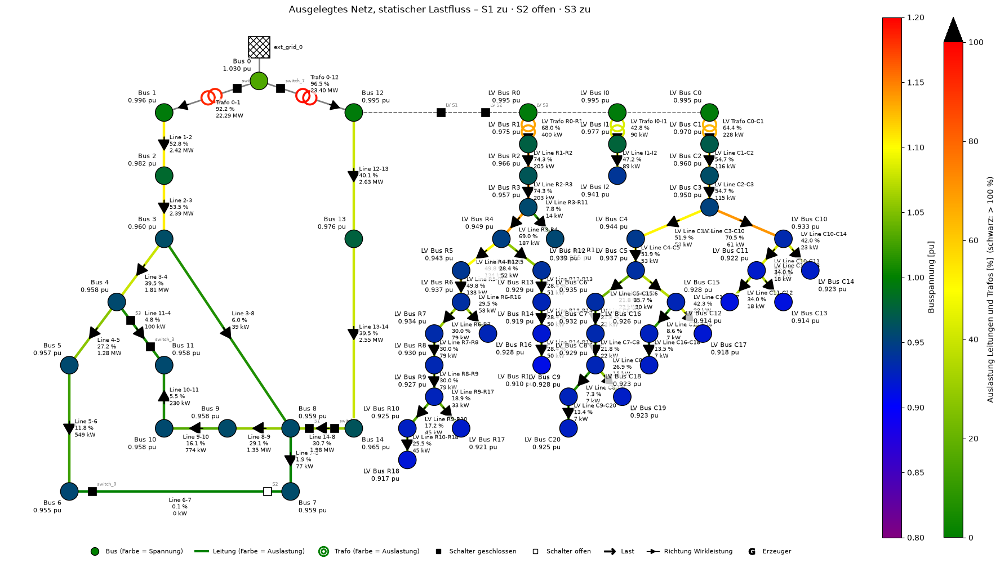

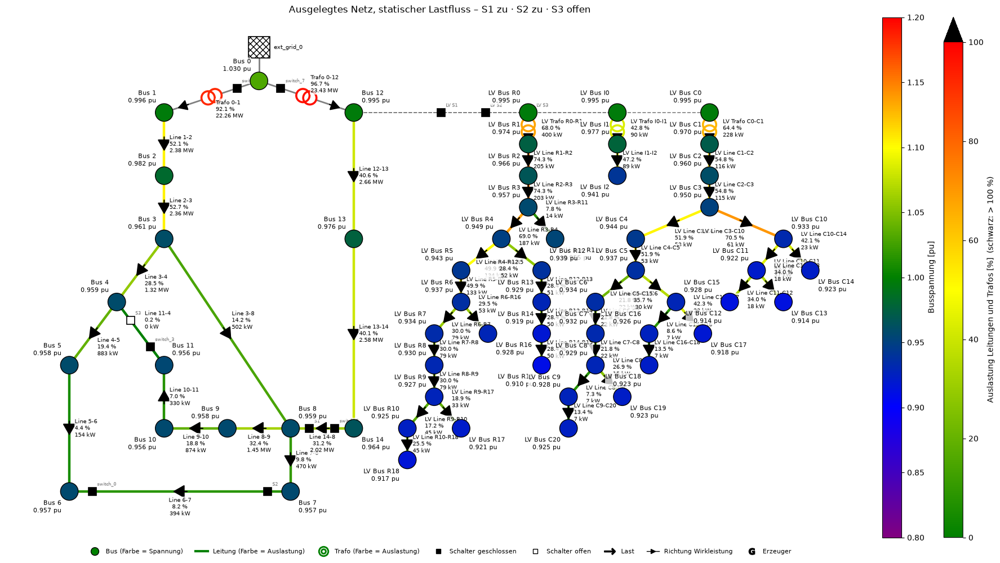

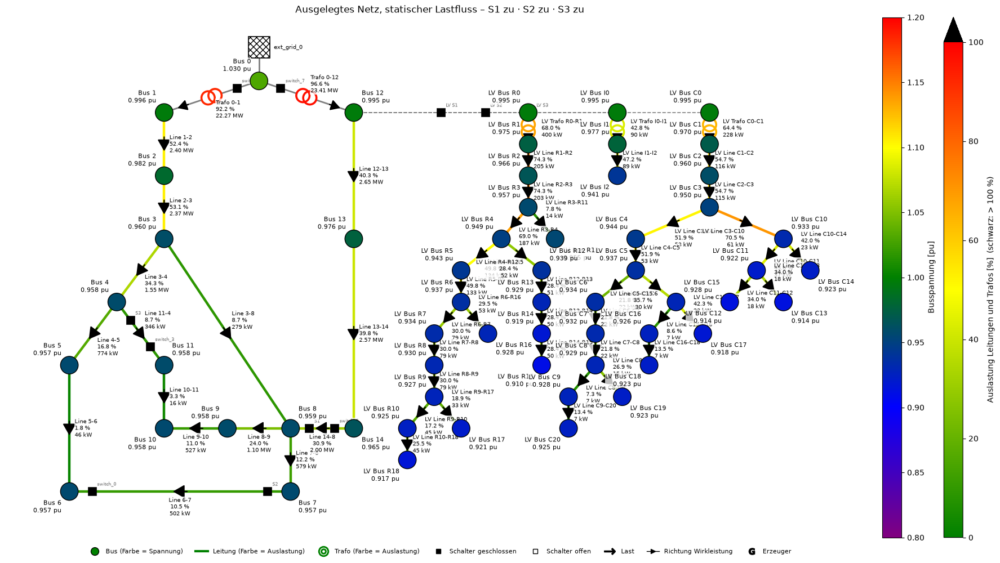

In [89]:
for key, r in static.items():
    netplan.plot_static(r["net"], title=f"Ausgelegtes Netz, statischer Lastfluss – {sz.label(key)}", elements=False)

### 6.2 Zeitreihe

In [90]:
ts = sz.zeitreihe_alle(ausgelegt, prefix="w4_t3")

Simulation 'w4_t3_000': unverändert seit dem Lauf vom 2026-11-08T20:41:29 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3_001': unverändert seit dem Lauf vom 2026-11-08T20:42:19 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3_010': unverändert seit dem Lauf vom 2026-11-08T20:43:08 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3_011': unverändert seit dem Lauf vom 2026-11-08T20:44:01 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3_100': unverändert seit dem Lauf vom 2026-11-08T20:44:56 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3_101': unverändert seit dem Lauf vom 2026-11-08T20:45:51 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3_110': unverändert seit dem Lauf vom 2026-11-08T20:46:39 – gespeicherte Ergebnisse gelade

In [91]:
kz = sz.kennzahlen(ts)
text_cols = ["konvergiert", "Bus U min", "Zeitpunkt U min", "Leitung", "Zeitpunkt Leitung max"]
display(kz[text_cols])
display(plots.table(kz.drop(columns=text_cols).astype(float).T, decimals=3))
pd.DataFrame({sz.label(k, kurz=True): band_stunden(s) for k, s in ts.items()})

,konvergiert,Bus U min,Zeitpunkt U min,Leitung,Zeitpunkt Leitung max
alle offen,2016/2016,LV Bus R15,Sun 12.01. 18:00,Line 2-3,Sun 12.01. 18:00
S3 zu,2016/2016,LV Bus R15,Sun 12.01. 18:00,Line 2-3,Sun 12.01. 18:00
S2 zu,2016/2016,LV Bus R15,Sun 12.01. 18:00,Line 2-3,Sun 12.01. 18:00
S2+S3 zu,2016/2016,LV Bus R15,Sun 12.01. 18:00,Line 2-3,Sun 12.01. 18:00
S1 zu,2016/2016,LV Bus R15,Sun 12.01. 18:00,LV Line R2-R3,Sun 12.01. 18:00
S1+S3 zu,2016/2016,LV Bus R15,Sun 12.01. 18:00,LV Line R2-R3,Sun 12.01. 18:00
S1+S2 zu,2016/2016,LV Bus R15,Sun 12.01. 18:00,LV Line R1-R2,Sun 12.01. 18:00
S1+S2+S3 zu,2016/2016,LV Bus R15,Sun 12.01. 18:00,LV Line R2-R3,Sun 12.01. 18:00


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
U min [pu],0.923,0.923,0.923,0.923,0.921,0.921,0.921,0.921
U max 20 kV [pu],1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Stunden U < 0.9,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden U > 1.1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Leitung max [%],78.638,78.584,78.637,78.563,73.349,73.346,73.351,73.347
Trafo max [%],82.694,82.682,82.693,82.678,77.765,77.752,77.875,77.818
Stunden Trafo > 100 %,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Verluste [MWh],162.980,161.218,162.919,160.925,128.838,128.711,128.344,127.886
Verluste [% der Last],0.367,0.363,0.367,0.363,0.290,0.290,0.289,0.288


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Stunden < 0.95 MS,8.000000,3.000000,9.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Stunden > 1.05 MS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Stunden < 0.9 MS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Stunden > 1.1 MS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
U min MS [pu],0.948673,0.949856,0.948672,0.950917,0.972855,0.972536,0.973987,0.974573
U max MS [pu],1.024344,1.024345,1.024344,1.024345,1.024303,1.024287,1.024300,1.024289
Stunden < 0.95 NS,450.000000,450.000000,450.000000,450.000000,473.000000,472.000000,473.000000,472.000000
Stunden > 1.05 NS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Stunden < 0.9 NS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Stunden > 1.1 NS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


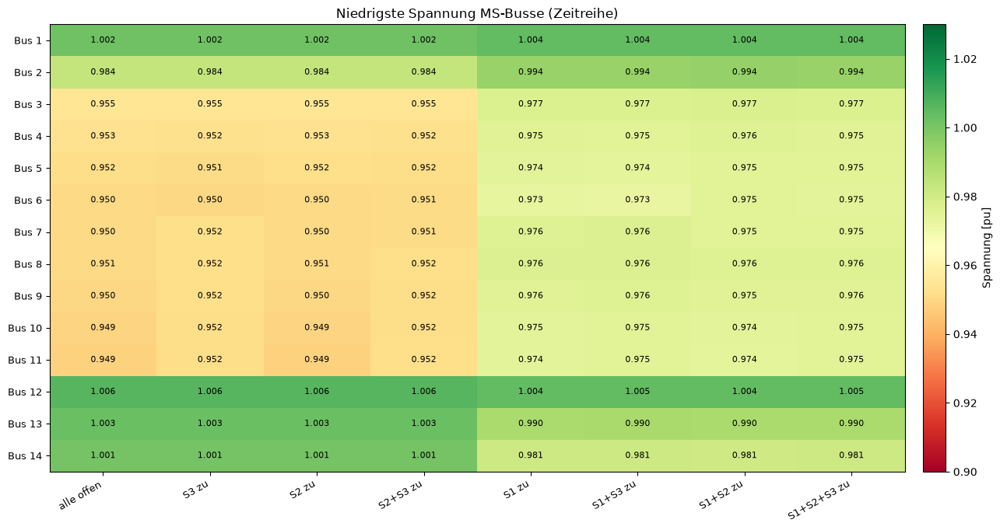

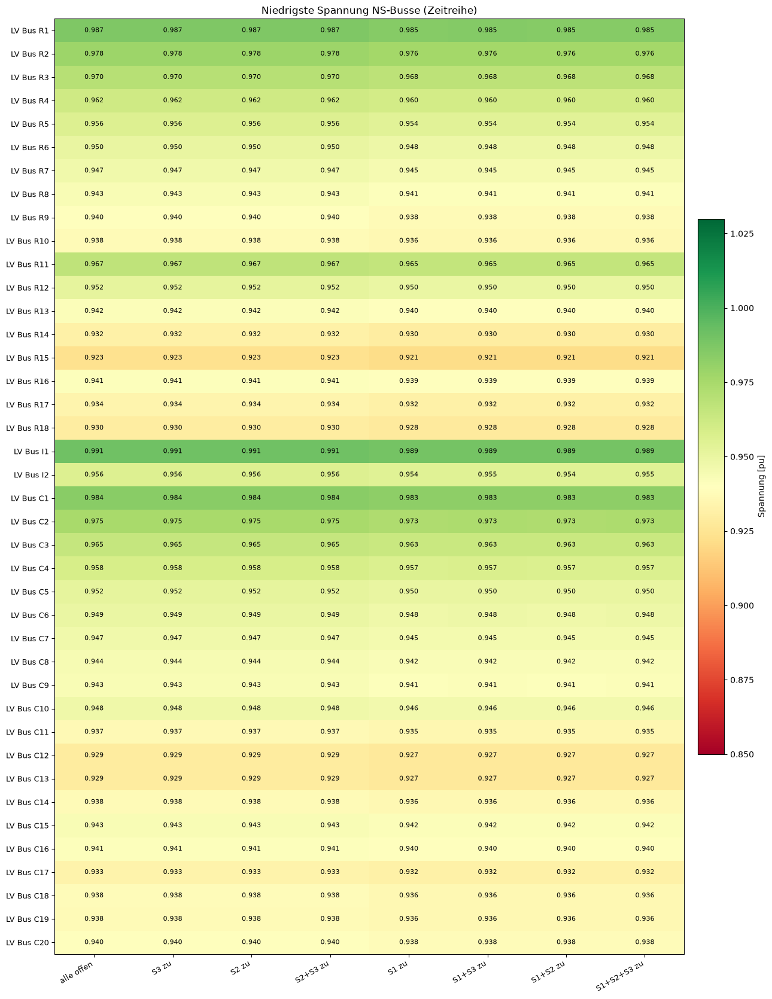

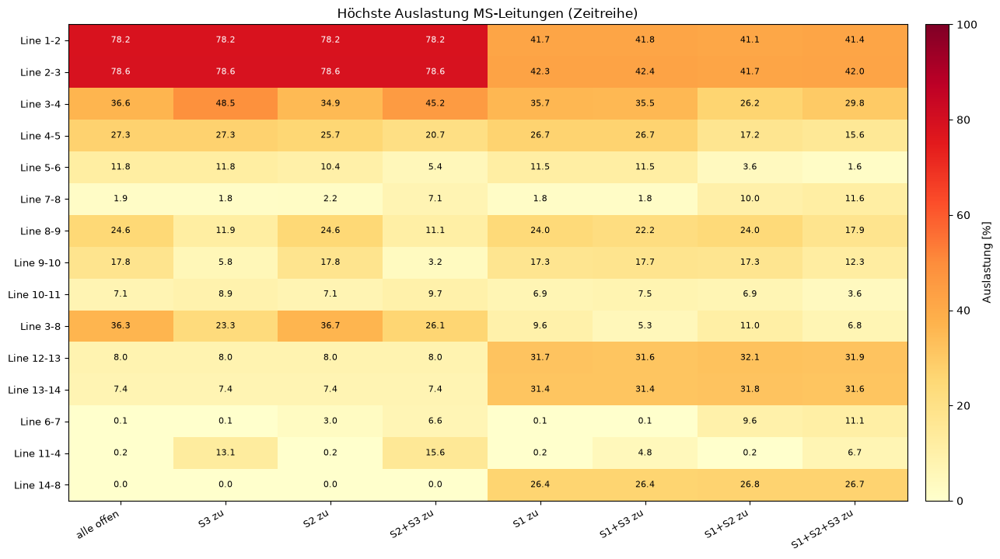

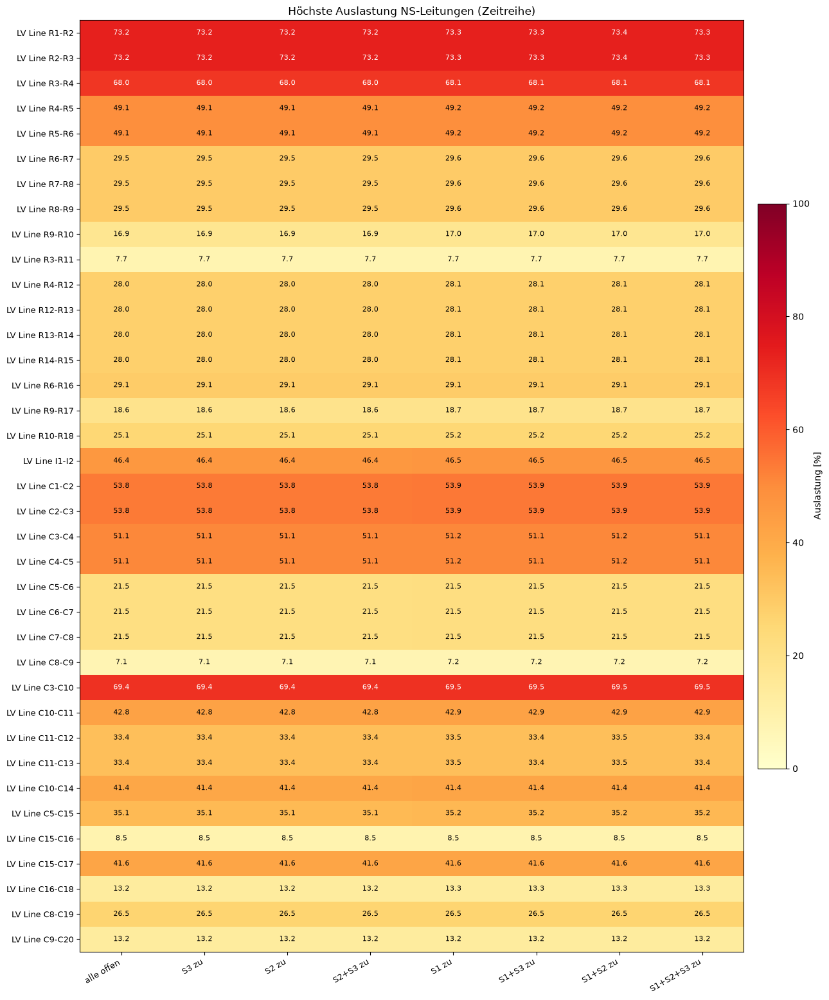

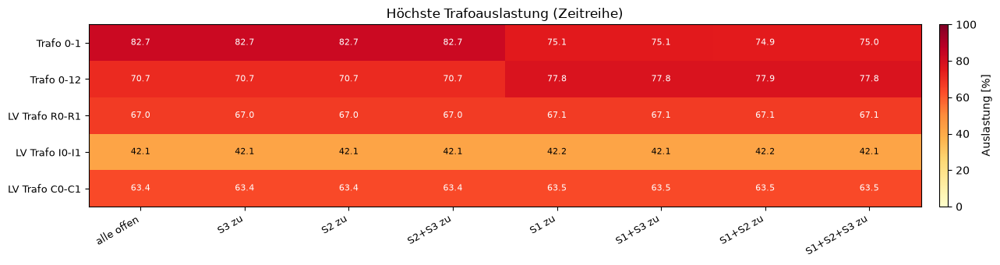

In [92]:
vmin_ts = sz.je_element(ts, "vm_pu", "min")
sz.heatmap(vmin_ts.loc[g["MS"]], "Niedrigste Spannung MS-Busse (Zeitreihe)", "Spannung [pu]", cmap="RdYlGn", vmin=0.90, vmax=1.03)
plt.show()
sz.heatmap(vmin_ts.loc[g["NS"]], "Niedrigste Spannung NS-Busse (Zeitreihe)", "Spannung [pu]", cmap="RdYlGn", vmin=0.85, vmax=1.03)
plt.show()
llmax_ts = sz.je_element(ts, "line_loading", "max")
sz.heatmap(llmax_ts.loc[e["line_MS"]], "Höchste Auslastung MS-Leitungen (Zeitreihe)", "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
sz.heatmap(llmax_ts.loc[e["line_NS"]], "Höchste Auslastung NS-Leitungen (Zeitreihe)", "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()
sz.heatmap(sz.je_element(ts, "trafo_loading", "max"), "Höchste Trafoauslastung (Zeitreihe)", "Auslastung [%]", cmap="YlOrRd", vmin=0, vmax=100, fmt="{:.1f}", grenze=100)
plt.show()

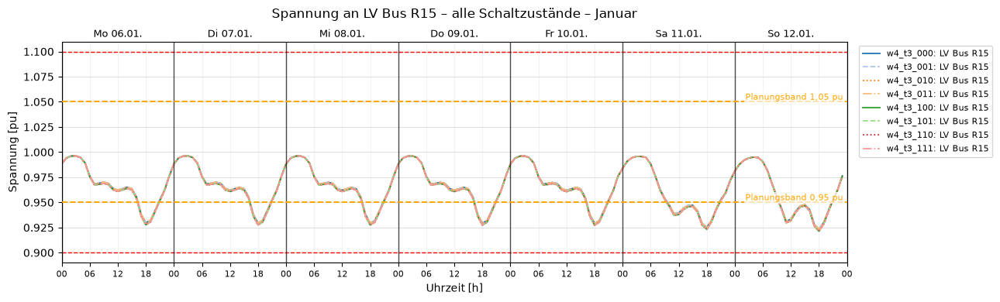

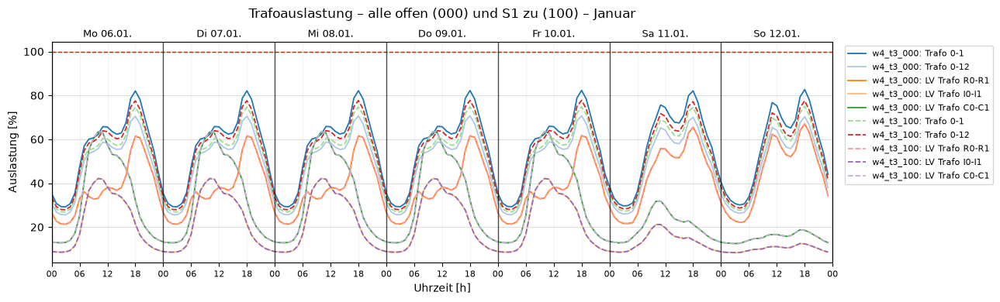

In [93]:
schwach = vmin_ts.loc[g["NS"]].min(axis=1).idxmin()
sim.compare([ts[k] for k in sz.KEYS], Diagram.VOLTAGE, [schwach], months=Month.JANUARY, markers=PLAN_MARKER,
            title=f"Spannung an {schwach} – alle Schaltzustände")
sim.compare([ts["000"], ts["100"]], Diagram.TRAFO_LOADING, None, months=Month.JANUARY,
            title="Trafoauslastung – alle offen (000) und S1 zu (100)")

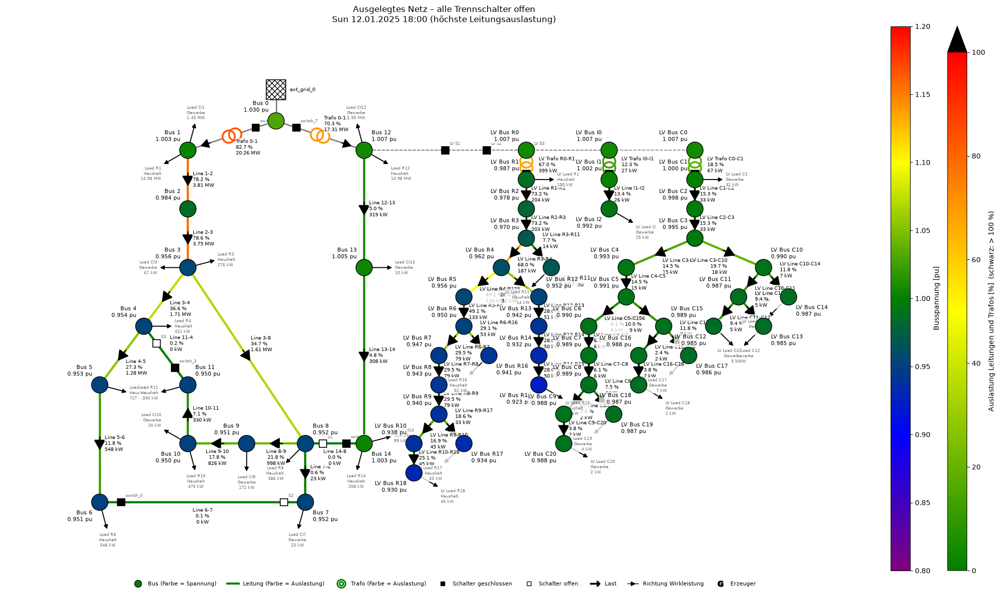

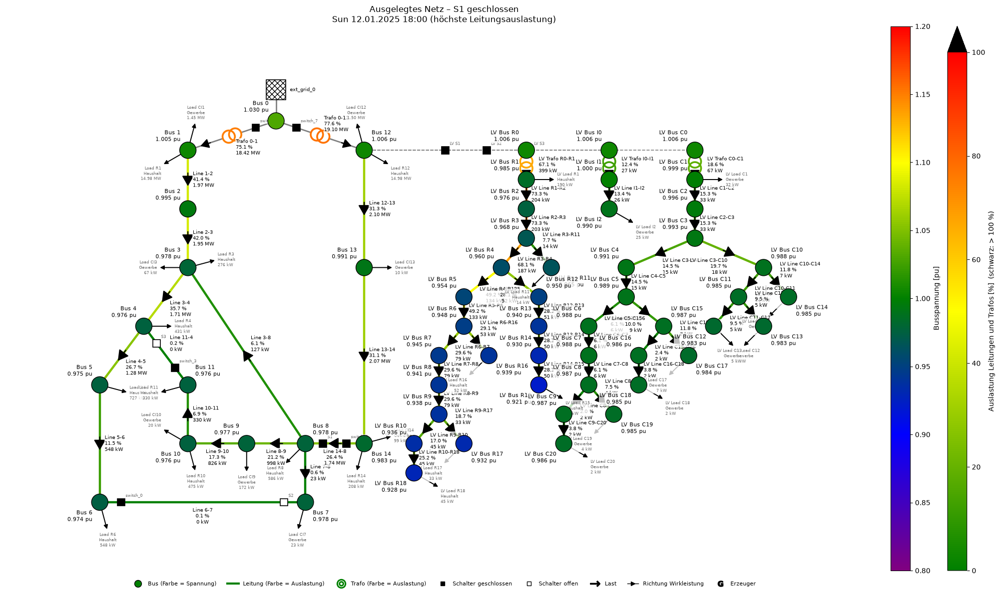

In [94]:
ts["000"].createDiagram(Diagram.NETWORK, time="max_loading", title="Ausgelegtes Netz – alle Trennschalter offen")
ts["100"].createDiagram(Diagram.NETWORK, time="max_loading", title="Ausgelegtes Netz – S1 geschlossen")

**Ergebnis Schalterstellungen (ausgelegtes Netz, Ortsnetz an Bus 12):**

- **Konvergenz:** Alle 8 Zustände konvergieren statisch und in allen 8 × 2016 Zeitpunkten.
- **Statisch (alle Lasten mit Bemessungsleistung):** Wie in Teil 1 ist Trafo 0-1 ohne S1 mit 101,4 % leicht überlastet und Line 2-3 mit 97 % hoch belastet; mit S1 sinken beide auf 96,6 % bzw. 74 %. Die niedrigste Spannung liegt im Ortsnetz (LV Bus R15) bei 0,913 pu, mit S1 bei 0,910 pu.
- **Zeitreihe:** In keinem Zustand werden die Arbeitsgrenzen verletzt oder ein Betriebsmittel über 100 % belastet. Die Ortsnetztrafos bleiben bei höchstens 67 %, die LV-Leitungen bei 73 %.
- **Wirkung von S1:** S1 entlastet Abgang 1 (Line 1-2/2-3: 78,6 % → 42 %, Trafo 0-1: 82,7 % → 75 %) und senkt die Verluste um rund 21 % (163 → 129 MWh). Gleichzeitig übernimmt Trafo 0-12 einen Teil der Last von Abgang 1 (70,7 % → 77,8 %). Weil das Ortsnetz an Bus 12 hängt, wird es dadurch geringfügig schlechter versorgt: Die niedrigste NS-Spannung sinkt von 0,923 auf 0,921 pu, die Stunden unter 0,95 pu steigen von 450 auf 473.
- **S2 und S3** verschieben wie in Teil 1 nur die Aufteilung innerhalb von Abgang 1 und haben auf das Ortsnetz keinen Einfluss.
- **Folgerung:** Für das Ortsnetz ist der Normalbetrieb mit offenen Trennschaltern sogar etwas günstiger als der gekuppelte Betrieb. Die Unterschreitungen des Planungsbands im Ortsnetz (450 bis 473 Stunden) lassen sich durch Schalthandlungen im MV-Netz nicht beheben; sie entstehen im Ortsnetz selbst und sind die Aufgabe des regelbaren Ortsnetztransformators.

<a id="teil-4"></a>

---

# Task 4 – Teil 3b: Spannungsregelung

**Ausgangspunkt:** das ausgelegte Netz aus `Task4-3_Ortsnetz_Auslegung.ipynb` (CIGRE-MV ohne DER, CIGRE-LV-Ortsnetz an Bus 12 mit pandapower-Standardtrafos und verstärkter Freileitung im Gewerbenetz). Dieses Notebook setzt voraus, dass Teil 3 einmal ausgeführt wurde (Simulationen `w4_t3_ausgelegt` und `w4_t3_000` … `w4_t3_111`).

**Aufbau:**

*Teil A – Regelung des Ortsnetzes mit regelbaren Ortsnetztransformatoren (rONT)*

1. Bewertung möglicher Regelungsmethoden
2. Regelbedarf im Ortsnetz
3. Regelkonzept rONT
4. Kontrollierte Untersuchung ausgewählter Stufenstellungen
5. Zeitreihe ungeregelt und geregelt

*Teil B – Backup-Plan für das MS-Netz*

6. Backup-Plan mit den Trennschaltern S1–S3: Literatur, Wiederversorgung nach Ausfall ((n-1)-Prüfung), Spannungsstützung

*Teil C – Zusammenspiel*

7. Simulation mit rONT-Regelung und Backup-Plan gleichzeitig
8. Fazit

## Importe

In [95]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp

import simulation as sim
import szenarien as sz
import lvnetz
import regelung as rg
import netplan
import plots
from elements import Diagram
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

sim.ONLY_RUN_IF_CHANGED = True

from auswertung import V_MIN, V_MAX, V_PLAN_MIN, V_PLAN_MAX, PLAN_MARKER, band_stunden, ausfall_status as status

ausgelegt = sim.loadSimulation("w4_t3_ausgelegt")        # aus Task4-3 (ausgelegtes Netz, alle Trennschalter offen)
ungeregelt = {k: sim.loadSimulation(f"w4_t3_{k}") for k in sz.KEYS}   # Zeitreihen aller Schalterstellungen ohne Regelung
g = lvnetz.bus_groups(ausgelegt.net)
TEILNETZE = {x: [b for b in g["NS"] if b.startswith(f"LV Bus {x}")] for x in "RIC"}
TRAFO = {x: f"LV Trafo {x}0-{x}1" for x in "RIC"}

## 1 Bewertung möglicher Regelungsmethoden

Betrachtet wurden drei Ansätze für die Regelung:

| | 1. Schwellwertregelung | 2. Fahrplan aus historischen Werten | 3. Prognose mit neuronalem Netz |
|---|---|---|---|
| Prinzip | reagiert auf den Messwert, wenn eine Grenze überschritten wird | Stufenstellung nach Zeitplan, abgeleitet z. B. aus dem Vorjahr | Stufenstellung nach Vorhersage des Verbrauchs der nächsten Stunde |
| Aufwand in der Simulation | gering bis mittel | gering (Stufen je Monat sind in `runSimulation(tap=...)` schon möglich) | hoch (Trainingsdaten, Merkmale, Validierung) |
| Stand der Technik | ja, so arbeiten Spannungsregler von Stufenschaltern [19, S. 714], [20], [21] | als Ergänzung | Forschung, Smart Grid |
| Schwäche | – (siehe unten) | reagiert nicht auf Abweichungen; nach dem Arbeitsauftrag keine automatische Regelung | nur ein synthetisches Jahr als Datenbasis |

**Zu 1:** Der befürchtete Nachteil, dass mindestens eine Stunde über dem Schwellwert liegt, entsteht nur durch die Stundenauflösung der Simulation. Ein realer Stufenschalter reagiert nach einer Verzögerungszeit im Bereich von Sekunden bis Minuten; der ECOTAP VPD schafft bis zu 20 Stufenschaltungen pro Minute [21]. In der Simulation wird das abgebildet, indem nach einem Eingriff **dieselbe Stunde** erneut gerechnet wird (wie bei den Controllern von pandapower). Damit bleibt keine Stunde verletzt, solange der Stellbereich reicht.

**Zu 2:** Die BDEW-Standardlastprofile sind in jedem Jahr gleich. Ein Fahrplan aus dem „Vorjahr“ wäre deshalb automatisch perfekt und damit nicht aussagekräftig. Außerdem verlangt der Arbeitsauftrag ausdrücklich eine automatische Regelung; eine fest vorgegebene Stufenstellung genügt nicht.

**Zu 3:** Mit nur einem synthetischen Jahr ist eine Verbrauchsprognose nahezu trivial und kaum belastbar. Der Nutzen gegenüber 1 ist gering, weil der Stufenschalter ohnehin innerhalb der Stunde reagiert. Die Idee passt aber in den Ausblick (Teil 9), z. B. als Prognose für Speicher und steuerbare Lasten.

**Entscheidung:** Methode 1 mit Totband, Hysterese, Stellgrenzen und Zählung der Schaltvorgänge. Methoden 2 und 3 werden nicht umgesetzt; 3 wird im Ausblick aufgegriffen.

---
# Teil A – Regelung des Ortsnetzes (rONT)

## 2 Regelbedarf im Ortsnetz

Je Teilnetz: niedrigste Spannung an der NS-Sammelschiene (Trafo-Unterspannungsseite) und am schwächsten Bus, Stunden unter 0,95 pu und die Zahl der Stunden, in denen eine bzw. zwei Stufen (je 2,5 %) nötig wären (Zeitreihe aus Teil 3, ohne Regelung):

In [96]:
vm0 = ungeregelt["000"].results.vm_pu
bedarf = {}
for x, busse in TEILNETZE.items():
    lo, hi = vm0[busse].min(axis=1), vm0[busse].max(axis=1)
    bedarf[f"Teilnetz {x}"] = {
        "Sammelschiene min [pu]": vm0[f"LV Bus {x}1"].min(),
        "schwächster Bus": vm0[busse].min().idxmin(),
        "schwächster Bus min [pu]": lo.min(),
        "Stunden < 0,95": int((lo < 0.95).sum()),
        "1 Stufe nötig": int(((lo < 0.95) & (lo >= 0.925)).sum()),
        "2 Stufen nötig": int((lo < 0.925).sum()),
        "U max [pu]": hi.max(),
    }
pd.DataFrame(bedarf).T

,Sammelschiene min [pu],schwächster Bus,schwächster Bus min [pu],"Stunden < 0,95",1 Stufe nötig,2 Stufen nötig,U max [pu]
Teilnetz R,0.986763,LV Bus R15,0.923259,195,193,2,1.019464
Teilnetz I,0.990831,LV Bus I2,0.955984,0,0,0,1.020964
Teilnetz C,0.984265,LV Bus C12,0.929006,255,255,0,1.019883


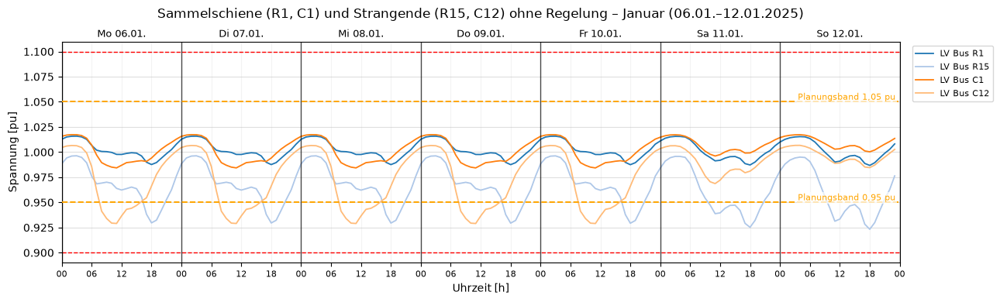

In [97]:
vergleich_messpunkt = ["LV Bus R1", "LV Bus R15", "LV Bus C1", "LV Bus C12"]
ungeregelt["000"].createDiagram(Diagram.VOLTAGE, vergleich_messpunkt, months=Month.JANUARY, markers=PLAN_MARKER,
                                title="Sammelschiene (R1, C1) und Strangende (R15, C12) ohne Regelung")

**Folgerungen aus der Analyse:**

- **Messort:** An den NS-Sammelschienen fällt die Spannung nie unter 0,984 pu. Die Verletzungen des Planungsbands treten nur an den Strangenden auf (LV Bus R15 im Wohngebiet, LV Bus C12 im Gewerbe): abends (und am Wochenende mittags) im Wohngebiet, werktags tagsüber im Gewerbe. Ein Regler, der nur die Sammelschiene misst, würde nie eingreifen. Deshalb misst der Regler die niedrigste und höchste Spannung im ganzen Teilnetz.
- **Regelbedarf:** Im Wohngebiet 195 Stunden, im Gewerbe 255 Stunden unter 0,95 pu; fast immer reicht eine Stufe (2,5 %), nur in 2 Stunden wären zwei Stufen nötig. Das Industrienetz liegt immer im Band.

## 3 Regelkonzept rONT

| Merkmal | Festlegung | Begründung |
|---|---|---|
| geregelte Trafos | alle drei Ortsnetztrafos, jeder mit eigenem Regler | jeder Trafo wirkt nur auf sein eigenes Teilnetz; die Teilnetze haben unterschiedliche Lastgänge (Haushalt abends, Gewerbe vormittags) |
| wirksam für | nur die NS-Busse des eigenen Teilnetzes | die US-Spannung eines Trafos ändert die Spannungen im MV-Netz und in den anderen Teilnetzen praktisch nicht |
| Stufenseite | Oberspannung (`tap_side = "hv"`) | Regelwicklung üblicherweise auf der OS-Seite [19, S. 421]; Standardtyp |
| Stellbereich | −2 … +2 Stufen zu je 2,5 % | Standardtyp; entspricht dem rONT-Beispiel ±2 × 2,5 % [20] |
| Messgröße | niedrigste und höchste Spannung aller NS-Busse des Teilnetzes | entspricht Sensoren an den Strangenden; an der Sammelschiene allein wäre keine Verletzung zu sehen (Abschnitt 2) |
| Sollband | 0,95 … 1,05 pu (Planungsband) | Teil 3 |
| Regelgesetz | Abweichung bis 2,5 % unter bzw. über dem Band → 1 Stufe; bis 5 % → 2 Stufen | Stufen entsprechen der Abweichung |
| Stellgrenze | Anheben nur, wenn U_max danach ≤ 1,05 pu bleibt; Absenken nur, wenn U_min ≥ 0,95 pu bleibt | Behebung einer Verletzung darf keine neue erzeugen |
| Rückstellung / Hysterese | eine Stufe zurück Richtung Neutralstellung nur, wenn danach beide Grenzen mit 0,5 % Abstand im Band liegen; Wirkung je Stufe vorsichtig mit 1,2 × 2,5 % geschätzt | verhindert Hin- und Herschalten |
| Verzögerung | in der Simulation: Eingriff innerhalb derselben Stunde (Stunde wird neu gerechnet); real: Verzögerungszeit im Bereich von Sekunden bis Minuten [21] | Stundenauflösung |
| Vorzeichen | `tap_pos = −1` hebt die US-Spannung um eine Stufe an | geprüft mit pandapower |

Der Regler berücksichtigt Unter- und Überspannung. Ohne Erzeuger tritt Überspannung bisher nicht auf; mit den Erzeugungsszenarien in Teil 4 und bei Leistungsflussumkehr wirkt dieselbe Logik nach unten.

**Umsetzung:** `regelung.py` enthält die Klasse `TapRegler`. Die Regler werden an `runSimulation(controllers=[...])` übergeben. Nach jedem Lastfluss prüft jeder Regler das Ergebnis; greift einer ein, wird dieselbe Stunde neu gerechnet, bis keiner mehr eingreift (höchstens 10-mal). Die Stufenstellungen werden in die nächste Stunde übernommen und je Stunde gespeichert (`results.tap_pos`).

In [98]:
def lv_regler():
    return [rg.TapRegler(TRAFO[x], TEILNETZE[x], u_min=V_PLAN_MIN, u_max=V_PLAN_MAX) for x in "RIC"]

for r in lv_regler():
    print(r.trafo, "→", len(r.busse), "überwachte NS-Busse")

LV Trafo R0-R1 → 18 überwachte NS-Busse
LV Trafo I0-I1 → 2 überwachte NS-Busse
LV Trafo C0-C1 → 20 überwachte NS-Busse


## 4 Kontrollierte Untersuchung ausgewählter Stufenstellungen

Bevor automatisch geregelt wird, wird kontrolliert untersucht, wie feste Stufenstellungen (−2 … +2, an allen drei Ortsnetztrafos gleich) die Spannungen verändern. Zwei statische Betriebspunkte:

- **Spitzenlast:** alle Lasten mit Bemessungsleistung
- **Schwachlast:** alle Lasten mit 25 % der Bemessungsleistung (etwa die Nachtlast)

In [99]:
def stufen_test(faktor):
    rows = {}
    for tap in range(-2, 3):
        net = copy.deepcopy(ausgelegt.net)
        net.load[["p_mw", "q_mvar"]] *= faktor
        for x in "RIC":
            net.trafo.loc[net.trafo.name == TRAFO[x], "tap_pos"] = tap
        pp.runpp(net)
        vm = pd.Series(net.res_bus.vm_pu.to_numpy(), index=net.bus.name)
        row = {"U min MS [pu]": vm[g["MS"]].min(), "U max MS [pu]": vm[g["MS"]].max()}
        for x, busse in TEILNETZE.items():
            row[f"U min {x} [pu]"] = vm[busse].min()
            row[f"U max {x} [pu]"] = vm[busse].max()
        rows[tap] = row
    out = pd.DataFrame(rows).T
    out.index.name = "Stufe (tap_pos)"
    return out

spitze = stufen_test(1.0)
schwach = stufen_test(0.25)
display(plots.table(spitze, decimals=3, cmap="RdYlGn", vmin=0.90, vmax=1.03))
plots.table(schwach, decimals=3, cmap="RdYlGn_r", vmin=0.97, vmax=1.10)

,U min MS [pu],U max MS [pu],U min R [pu],U max R [pu],U min I [pu],U max I [pu],U min C [pu],U max C [pu]
Stufe (tap_pos),,,,,,,,
-2,0.923,0.998,0.971,1.031,1.000,1.034,0.974,1.027
-1,0.923,0.998,0.941,1.004,0.971,1.006,0.945,1.000
0,0.923,0.998,0.913,0.977,0.944,0.980,0.917,0.973
1,0.923,0.998,0.886,0.952,0.919,0.955,0.890,0.948
2,0.923,0.998,0.860,0.929,0.894,0.931,0.864,0.924


,U min MS [pu],U max MS [pu],U min R [pu],U max R [pu],U min I [pu],U max I [pu],U min C [pu],U max C [pu]
Stufe (tap_pos),,,,,,,,
-2,1.010,1.023,1.059,1.073,1.065,1.073,1.059,1.072
-1,1.010,1.023,1.031,1.045,1.037,1.045,1.031,1.044
0,1.010,1.023,1.004,1.018,1.011,1.019,1.005,1.017
1,1.010,1.023,0.978,0.993,0.985,0.994,0.979,0.992
2,1.010,1.023,0.954,0.970,0.961,0.970,0.955,0.968


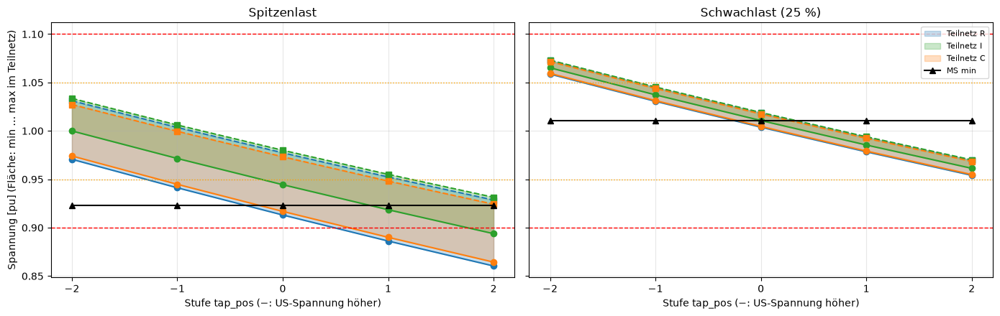

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (titel, df) in zip(axes, (("Spitzenlast", spitze), ("Schwachlast (25 %)", schwach))):
    for x, farbe in zip("RIC", ("tab:blue", "tab:green", "tab:orange")):
        ax.fill_between(df.index, df[f"U min {x} [pu]"], df[f"U max {x} [pu]"], alpha=0.25, color=farbe, label=f"Teilnetz {x}")
        ax.plot(df.index, df[f"U min {x} [pu]"], "o-", color=farbe)
        ax.plot(df.index, df[f"U max {x} [pu]"], "s--", color=farbe)
    ax.plot(df.index, df["U min MS [pu]"], "k^-", label="MS min")
    for v, c, ls in ((V_MIN, "red", "--"), (V_MAX, "red", "--"), (V_PLAN_MIN, "orange", ":"), (V_PLAN_MAX, "orange", ":")):
        ax.axhline(v, color=c, ls=ls, lw=1)
    ax.set_xticks(range(-2, 3))
    ax.set_xlabel("Stufe tap_pos (−: US-Spannung höher)")
    ax.set_title(titel)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Spannung [pu] (Fläche: min … max im Teilnetz)")
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**Ergebnis der kontrollierten Untersuchung:**

- Eine Stufe verändert die NS-Spannungen im ganzen Teilnetz um etwa 2,7 bis 2,8 Prozentpunkte (etwas mehr als die nominellen 2,5 %, weil auch der Spannungsfall im Trafo und in den Leitungen mit der höheren Spannung sinkt). Die MS-Spannungen ändern sich nicht.
- **Spitzenlast:** Ohne Stufe liegen Wohngebiet und Gewerbe bei 0,913 bzw. 0,917 pu. Eine Stufe (−1) reicht mit 0,941 bzw. 0,945 pu noch nicht ganz, zwei Stufen (−2) heben sie auf 0,971 bzw. 0,974 pu.
- **Schwachlast:** Mit zwei Stufen (−2) würden die NS-Spannungen auf bis zu 1,073 pu steigen und das Planungsband überschreiten; mit einer Stufe (−1) bleiben sie bei 1,045 pu im Band.
- **Folgerung:** Keine feste Stufenstellung passt für beide Betriebspunkte. Eine Stellung, die die Spitzenlast abdeckt, erzeugt bei Schwachlast Überspannung. Deshalb ist eine automatische Regelung nötig, die die Stufe mit der Last nachführt.

## 5 Zeitreihe ungeregelt und geregelt

### 5.1 Normalschaltzustand

Gleiche Randbedingungen wie die ungeregelte Zeitreihe `w4_t3_000` (S1–S3 offen, Normalschaltzustand); zusätzlich die drei rONT-Regler.

In [101]:
geregelt = ausgelegt.copy("w4_t3_geregelt", overwrite=True)
geregelt.runSimulation(controllers=lv_regler())

Simulation 'w4_t3_geregelt': unverändert seit dem Lauf vom 2026-11-08T20:49:40 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, line_p_mw, line_pl_mw, trafo_loading, trafo_p_mw, trafo_pl_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, line_q_mvar, trafo_q_mvar, trafo_i_hv_ka, trafo_i_lv_ka, bus_p_mw, bus_q_mvar, ext_grid_q_mvar, load_q_mvar, sgen_q_mvar, tap_pos, switch_closed, storage_p_mw, storage_soc_percent, element_p_mw, info

In [102]:
vgl = pd.DataFrame({"ungeregelt": band_stunden(ungeregelt["000"]), "geregelt (rONT)": band_stunden(geregelt)})
display(plots.table(vgl.astype(float), decimals=3))
display(rg.schaltvorgaenge(geregelt).filter(like="Stufen").to_frame("Anzahl in 12 Wochen"))
print("Stunden mit Reglereingriff:", int((geregelt.results.info.regler_iterationen > 0).sum()), "von", len(geregelt.results.info))

,ungeregelt,geregelt (rONT)
Stunden < 0.95 MS,8.000,8.000
Stunden > 1.05 MS,0.000,0.000
Stunden < 0.9 MS,0.000,0.000
Stunden > 1.1 MS,0.000,0.000
U min MS [pu],0.949,0.949
U max MS [pu],1.024,1.024
Stunden < 0.95 NS,450.000,0.000
Stunden > 1.05 NS,0.000,0.000
Stunden < 0.9 NS,0.000,0.000
Stunden > 1.1 NS,0.000,0.000


,Anzahl in 12 Wochen
Stufenschritte LV Trafo R0-R1,92
Stufenschritte LV Trafo I0-I1,0
Stufenschritte LV Trafo C0-C1,100


Stunden mit Reglereingriff: 187 von 2016


,LV Trafo R0-R1,LV Trafo I0-I1,LV Trafo C0-C1
Stufe (Stunden),,,
-1.0,238,0,335
0.0,1778,2016,1681


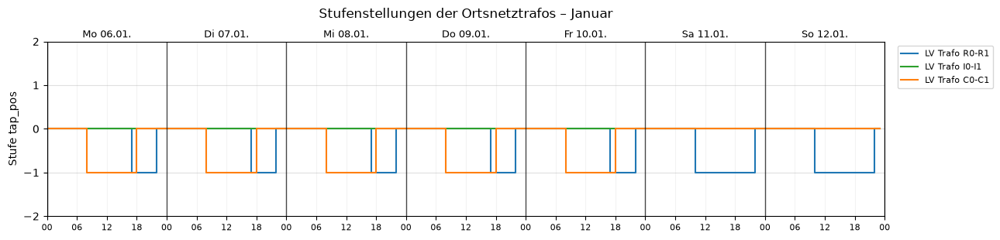

In [103]:
taps = geregelt.results.tap_pos[[TRAFO[x] for x in "RIC"]]
haeufigkeit = taps.apply(pd.Series.value_counts).fillna(0).astype(int)
haeufigkeit.index.name = "Stufe (Stunden)"
display(haeufigkeit)

fig, ax = plt.subplots(figsize=(13, 3.2))
idx = geregelt.results.info.index[geregelt.results.info.month == "JANUARY"]
for x, farbe in zip("RIC", ("tab:blue", "tab:green", "tab:orange")):
    ax.step(idx, taps.loc[idx, TRAFO[x]], where="post", color=farbe, label=TRAFO[x])
plots.week_axis(ax, idx)
ax.set_ylabel("Stufe tap_pos")
ax.set_yticks(range(-2, 3))
ax.set_title("Stufenstellungen der Ortsnetztrafos – Januar", pad=22)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()

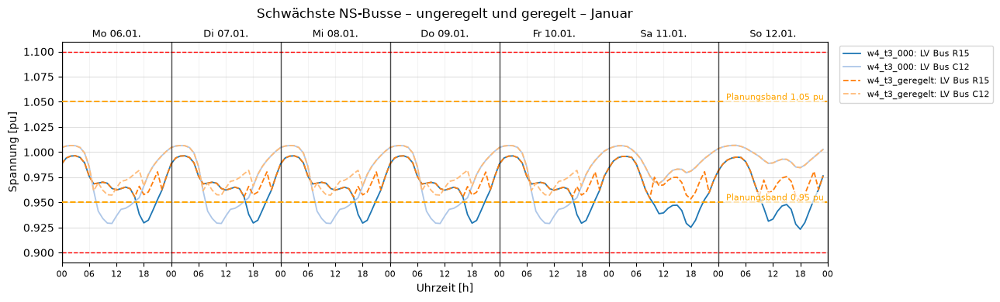




In [104]:
schwaechste = [vm0[TEILNETZE[x]].min().idxmin() for x in "RC"]
sim.compare([ungeregelt["000"], geregelt], Diagram.VOLTAGE, schwaechste, months=Month.JANUARY, markers=PLAN_MARKER,
            title="Schwächste NS-Busse – ungeregelt und geregelt")
geregelt.createDiagram(Diagram.VOLTAGE, g["NS"], layout="boxplot", markers=PLAN_MARKER, title="NS-Spannungen geregelt")

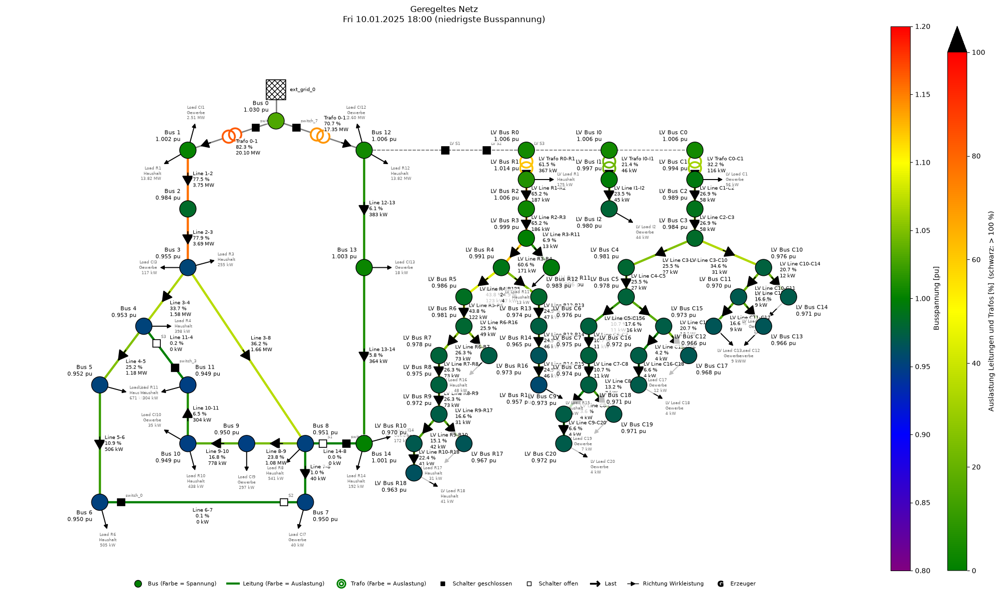

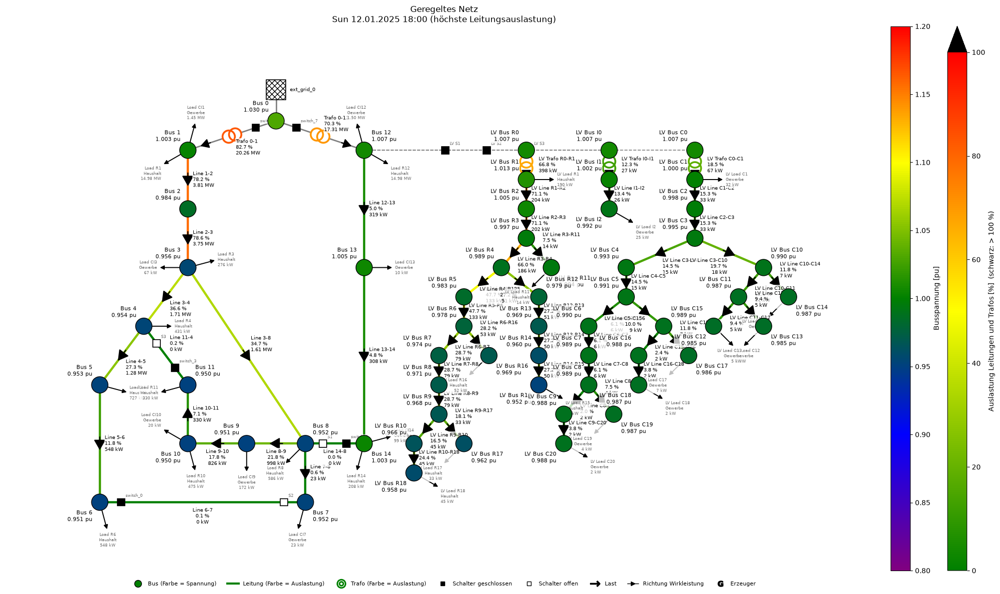

In [105]:
geregelt.createDiagram(Diagram.NETWORK, time=["min", "max_loading"], title="Geregeltes Netz")

**Ergebnis ungeregelt gegenüber geregelt:**

| Kennwert | ungeregelt | geregelt |
|---|---|---|
| Stunden NS < 0,95 pu | 450 | **0** |
| niedrigste NS-Spannung | 0,923 pu | **0,950 pu** |
| höchste NS-Spannung | 1,021 pu | 1,027 pu |
| Verletzungen der Arbeitsgrenzen | 0 | 0 |
| Stufenschritte in 12 Wochen | – | R: 92, I: 0, C: 100 |

- Die Regler beseitigen alle 450 Stunden unter dem Planungsband im Ortsnetz. Sie greifen in 187 der 2016 Stunden ein und nutzen nur die Stufe −1 (Wohngebiet 238 Stunden, Gewerbe 335 Stunden); den Rest der Zeit steht der Stufenschalter in Neutralstellung. Eine neue Überspannung entsteht nicht (höchstens 1,027 pu).
- Die Stufen folgen dem Tagesgang der Lasten: Im Wohngebiet wird vor allem abends (17 bis 21 Uhr) und am Wochenende auch mittags hochgeschaltet, im Gewerbe an Werktagen tagsüber (8 bis 17 Uhr), nie am Wochenende. Nachts kehren beide Regler in die Neutralstellung zurück. Hochgerechnet auf ein Jahr sind das etwa 400 bis 430 Stufenschritte je Trafo; ein ECOTAP VPD ist für 500 000 Schaltspiele ausgelegt [21].
- **Grenze der rONT-Regelung:** Im MS-Netz bleiben 8 Stunden knapp unter 0,95 pu an Bus 9 bis Bus 11 (niedrigster Wert 0,949 pu). Der rONT kann sie nicht beheben, weil er nur auf sein Ortsnetz wirkt. Was im MS-Netz möglich ist, wird in Teil B untersucht.

### 5.2 Test der Regelrichtung nach unten (Überspannung)

Ohne Erzeuger tritt in der Zeitreihe keine Überspannung auf. Um die Regelrichtung nach unten zu prüfen, wird ein statischer Betriebspunkt gerechnet: Schwachlast (25 %) und Slack-Spannung 1,08 pu statt 1,03 pu, z. B. nach einer Spannungsanhebung im vorgelagerten Netz. Die Tabelle zeigt in jeder Zeile einen Lastfluss: Zeile 0 ohne Eingriff, jede weitere Zeile nach einem Eingriff der Regler.

In [106]:
net = copy.deepcopy(ausgelegt.net)
net.load[["p_mw", "q_mvar"]] *= 0.25
net.ext_grid["vm_pu"] = 1.08
rg.regle_statisch(net, lv_regler())[["Eingriff", "Stufen", "U min NS [pu]", "U max NS [pu]", "U max MS/NS [pu]"]]

,Eingriff,Stufen,U min NS [pu],U max NS [pu],U max MS/NS [pu]
Iteration,,,,,
0,Start,"LV Trafo R0-R1: 0, LV Trafo I0-I1: 0, LV Trafo...",1.055111,1.069534,1.07391
1,"TapRegler LV Trafo R0-R1, TapRegler LV Trafo I...","LV Trafo R0-R1: 1, LV Trafo I0-I1: 1, LV Trafo...",1.028447,1.043246,1.07391


**Ergebnis:** Ohne Eingriff steigen die NS-Spannungen auf bis zu 1,070 pu. Alle drei Regler schalten in einem Schritt eine Stufe nach unten (+1) und bringen das Ortsnetz auf 1,028 bis 1,043 pu zurück ins Band. Die MS-Spannung von 1,074 pu kann der rONT nicht senken, weil er nur auf das Ortsnetz wirkt; dafür wären ein Stufenschalter am 110/20-kV-Trafo oder Blindleistung nötig.

### 5.3 rONT-Regelung in allen Schaltzuständen S1–S3

Wie in Teil 1 wird jeder der acht Schaltzustände (S1, S2, S3 jeweils offen oder geschlossen) als fester Betriebszustand über 12 Wochen gerechnet, jetzt mit den drei rONT-Reglern. So wird geprüft, ob die Regelung auch bei geänderter Topologie des MS-Netzes funktioniert. Oben: ohne Regelung, unten: mit Regelung.

In [107]:
geregelt_alle = sz.zeitreihe_alle(ausgelegt, prefix="w4_t3r", controllers=lv_regler())

Simulation 'w4_t3r_000': unverändert seit dem Lauf vom 2026-11-08T20:51:52 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3r_001': unverändert seit dem Lauf vom 2026-11-08T20:53:32 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3r_010': unverändert seit dem Lauf vom 2026-11-08T20:55:17 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3r_011': unverändert seit dem Lauf vom 2026-11-08T20:57:01 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3r_100': unverändert seit dem Lauf vom 2026-11-08T20:58:37 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3r_101': unverändert seit dem Lauf vom 2026-11-08T20:59:47 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3r_110': unverändert seit dem Lauf vom 2026-11-08T21:00:53 – gespeicherte Ergebnisse

In [108]:
tab = pd.DataFrame({sz.label(k, kurz=True): pd.concat([band_stunden(s), rg.schaltvorgaenge(s).filter(like="Stufen")])
                    for k, s in geregelt_alle.items()})
tab_u = pd.DataFrame({sz.label(k, kurz=True): band_stunden(s) for k, s in ungeregelt.items()})
display(plots.table(tab_u.astype(float), decimals=3))   # ungeregelt
plots.table(tab.astype(float), decimals=3)              # geregelt

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Stunden < 0.95 MS,8.000,3.000,9.000,0.000,0.000,0.000,0.000,0.000
Stunden > 1.05 MS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden < 0.9 MS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden > 1.1 MS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
U min MS [pu],0.949,0.950,0.949,0.951,0.973,0.973,0.974,0.975
U max MS [pu],1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Stunden < 0.95 NS,450.000,450.000,450.000,450.000,473.000,472.000,473.000,472.000
Stunden > 1.05 NS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden < 0.9 NS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden > 1.1 NS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Stunden < 0.95 MS,8.000,3.000,9.000,0.000,0.000,0.000,0.000,0.000
Stunden > 1.05 MS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden < 0.9 MS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden > 1.1 MS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
U min MS [pu],0.949,0.950,0.949,0.951,0.973,0.973,0.974,0.975
U max MS [pu],1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Stunden < 0.95 NS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden > 1.05 NS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden < 0.9 NS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Stunden > 1.1 NS,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


**Ergebnis aller Schaltzustände:**

- In allen acht Schaltzuständen liegt das Ortsnetz mit Regelung immer im Planungsband (niedrigste NS-Spannung 0,950 pu; ohne Regelung 450 bis 473 Stunden darunter).
- Mit geschlossenem S1 sinkt die Spannung an Bus 12 (Anschluss des Ortsnetzes) leicht. Die Regler gleichen das mit etwas mehr Stufenschritten aus (Wohngebiet 96 statt 92); die höchste NS-Spannung steigt auf 1,039 pu, bleibt aber im Band.
- Die verbleibenden Unterschreitungen im MS-Netz (8, 3 bzw. 9 Stunden bei „alle offen“, „S3 zu“ und „S2 zu“) hängen nur vom Schaltzustand ab, nicht von der rONT-Regelung.

---
# Teil B – Backup-Plan für das MS-Netz

## 6 Backup-Plan mit den Trennschaltern S1–S3

Der rONT wirkt nur auf sein Ortsnetz. Für das MS-Netz bleiben als Stellglieder die drei Trennschalter S1–S3, die im Normalbetrieb offen sind. Abschnitt 6 klärt zuerst, wofür solche Trennstellen in der Praxis vorgesehen sind (6.1), ordnet S1–S3 im CIGRE-MV-Netz ein (6.2) und leitet daraus zwei Fälle für den Backup-Plan ab:

- **Fall A – Ausfall eines Betriebsmittels (6.3, 6.4):** Eine Leitung oder ein Trafo fällt aus. Der Backup-Plan legt fest, welche Trennstelle geschlossen wird, damit alle ungestörten Busse weiter versorgt werden. Das ist die Aufgabe, für die Trennstellen nach der Literatur vorgesehen sind.
- **Fall B – Spannungsstützung (6.5):** Die MS-Spannung fällt ohne Ausfall unter eine Schwelle (z. B. bei einer unvorhergesehenen Lastspitze). Der Backup-Plan schließt die Trennstellen stufenweise.

Für beide Fälle gilt: Das Netz ist so ausgelegt (Teil 2 und Teil 3), dass der Backup-Plan im Normalbetrieb **nie** ausgelöst wird.

### 6.1 Was die Literatur zu Trennstellen, Ringen und Kupplungen sagt

Alle Angaben aus Schwab, *Elektroenergiesysteme* [19]:

| Thema | Aussage | Quelle |
|---|---|---|
| Betriebliche Trennstellen | Alle Netze besitzen definierte betriebliche Trennstellen, mit denen einzelne Netzteile für die Beseitigung von Störungen, Wartung und Instandhaltung spannungsfrei geschaltet werden können; jede Schalthandlung ändert die Topologie. | [19, S. 512] |
| Offene Ringe im MS-Netz | Zur Erhöhung der Versorgungssicherheit werden **offene Ringnetze** bevorzugt: Die Enden zweier Strahlen („Halbringe“) können verbunden werden. **Im Normalbetrieb ist die Verbindung geöffnet**, die Ringnetze werden wie Strahlennetze betrieben, was den Netzschutz wesentlich vereinfacht. | [19, S. 521 f., Bild 11.6b] |
| Wiederversorgung nach einer Störung | Bei einer Störung wird das betroffene Betriebsmittel **herausgetrennt** und die betrieblich vorgesehene **Trennstelle geschlossen**. Alle ungestörten Ortsnetzstationen lassen sich dann weiter versorgen. | [19, S. 522] |
| Ablauf im Ringnetz | Im Kurzschlussfall schaltet der Netzschutz den betroffenen Halbring ab; nach manuellem Heraustrennen des fehlerhaften Leitungsstücks und Zuschalten der vorgesehenen Querverbindungen werden die restlichen Verbraucher vom ungestörten Strahl weiterversorgt. | [19, S. 513 f.] |
| Geschlossene Ringe | Permanent geschlossene Ringe verbessern die Spannungshaltung und verringern die Verluste, stellen aber höhere Anforderungen (Schutz, Personal). | [19, S. 514] |
| Ringnetz mit Gegenstation | Kabelstränge aus zwei Umspannwerken münden in einer gemeinsamen Schaltanlage (Gegenstation) mit Sammelschienen-Längstrennung (LT). | [19, S. 522 f., Bild 11.8] |
| Industrienetz | Die Längskupplungen zwischen den Sammelschienenabschnitten sind im Normalbetrieb geöffnet („offen betriebenes Ringnetz“). | [19, S. 526, Bild 11.13] |
| (n-1)-Prinzip | Beim Ausfall eines Betriebsmittels bleibt die Versorgung erhalten, ohne dass ein Betriebsmittel überlastet wird. Das (n-1)-Prinzip muss für die **Jahreshöchstlast** erfüllt sein. Wird es verletzt, muss der (n-1)-Zustand in kürzester Zeit durch geeignete Schalthandlungen wiederhergestellt werden. | [19, S. 6 f.] |
| Parallelbetrieb von Trafos | Voraussetzungen: gleiche Übersetzung und gleiche Phasenlage (sonst dauernder Ausgleichsstrom), etwa gleiche Kurzschlussimpedanzen (Lastaufteilung nach Bemessungsleistung). | [19, S. 396 f.] |
| Maschen | In vermaschten Netzen teilen sich die Ströme nach den Leitungsimpedanzen auf; Leitungen niedriger Impedanz können überlastet werden, Kreisströme erhöhen die Verluste. Der Netzbetrieb steuert u. a. über die **Netztopologie** und die Stufenschalter. | [19, S. 437 f.] |
| Kuppelleitungen | Kuppelleitungen (Verbundnetz) dürfen stationär nur mit einem Teil ihrer Kapazität belastet werden, damit im Störfall Reserve bleibt. | [19, S. 36] |

**Folgerungen für den Backup-Plan:**

1. Die Trennstellen sind in erster Linie für die **Wiederversorgung nach einem Ausfall** vorgesehen (Fall A). Daraus ergibt sich ein fester Schaltplan: Für jedes Betriebsmittel wird vorab festgelegt, welche Trennstelle nach dem Heraustrennen geschlossen wird.
2. Ob das Netz (n-1)-sicher ist, wird bei **Jahreshöchstlast** geprüft.
3. Topologieänderungen sind auch ein Mittel der Spannungshaltung (geschlossener Ring verbessert die Spannung). Im MS-Netz wird der Ring aber wegen des Schutzes offen betrieben; ein Schließen zur Spannungsstützung (Fall B) ist deshalb nur eine vorübergehende Notmaßnahme.
4. Wird über S1 gekuppelt, laufen die beiden 110/20-kV-Trafos parallel. Das ist zulässig, weil sie baugleich sind (25 MVA, gleiche Schaltgruppe und Kurzschlussspannung, keine Stufenschalter).

### 6.2 Die Trennschalter im CIGRE-MV-Netz

| Schalter | Leitung | verbindet | Rolle nach [19] |
|---|---|---|---|
| S2 | Line 6-7 | Ende von Strang 1-2-3-4-5-6 mit Strang 3-8-7 (beide aus Trafo 0-1) | Ringtrennstelle innerhalb von Abgang 1 (Bild 11.6b) |
| S3 | Line 11-4 | Ende von Strang 3-8-9-10-11 mit Strang 3-4 (beide aus Trafo 0-1) | Ringtrennstelle innerhalb von Abgang 1 (Bild 11.6b) |
| S1 | Line 14-8 | Ende von Abgang 2 (Trafo 0-12, Bus 12-13-14) mit Abgang 1 (Bus 8) | Kupplung zweier Abgänge mit eigenem Trafo, vergleichbar einer Gegenstation bzw. Längskupplung (Bild 11.8, 11.13); geschlossen laufen beide Trafos parallel |

Netzplan im Normalschaltzustand (Jahreshöchstlast, alle Trennschalter offen):

Jahreshöchstlast: 12.01. 18:00 Uhr, 37.6 MW aus dem 110-kV-Netz


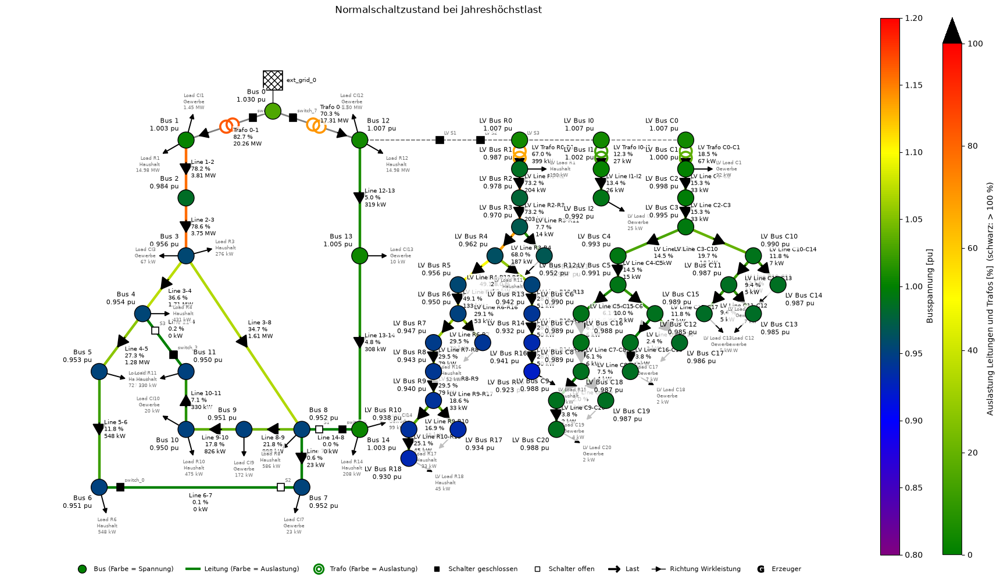

In [109]:
P_netz = ungeregelt["000"].results.ext_grid_p_mw.squeeze()
H_MAX = P_netz.idxmax()                       # Stunde der Jahreshöchstlast (höchste Leistung aus dem 110-kV-Netz)
print(f"Jahreshöchstlast: {H_MAX:%d.%m. %H:%M} Uhr, {P_netz.max():.1f} MW aus dem 110-kV-Netz")

def netz_zur_stunde(h):
    """Ausgelegtes Netz mit den Lasten einer Stunde der Zeitreihe (statischer Lastfluss)."""
    r = ungeregelt["000"].results
    net = copy.deepcopy(ausgelegt.net)
    net.load["p_mw"] = net.load["name"].map(r.load_p_mw.loc[h]).to_numpy()
    net.load["q_mvar"] = net.load["name"].map(r.load_q_mvar.loc[h]).to_numpy()
    return net

spitzennetz = netz_zur_stunde(H_MAX)
n = copy.deepcopy(spitzennetz)
pp.runpp(n)
_ = netplan.plot_static(n, title="Normalschaltzustand bei Jahreshöchstlast")

### 6.3 Fall A: Wiederversorgung nach dem Ausfall einer Leitung ((n-1)-Prüfung)

**Was hier passiert, Schritt für Schritt:**

1. **Betriebspunkt:** Lasten der Stunde mit der Jahreshöchstlast (siehe oben), denn dort muss das (n-1)-Prinzip erfüllt sein [19, S. 6 f.]. Alle Trennschalter sind offen, die Stufenschalter stehen in Neutralstellung (die rONT-Regelung kommt erst in Teil C dazu).
2. **Ausfall:** Eine MS-Leitung wird außer Betrieb genommen (`in_service = False`). Das entspricht dem Zustand, nachdem der Schutz ausgelöst und das fehlerhafte Leitungsstück herausgetrennt wurde. Untersucht werden alle 12 MS-Leitungen, die im Normalbetrieb Leistung führen (die drei Leitungen mit S1–S3 sind ohnehin offen).
3. **Maßnahmen:** Für jeden Ausfall werden alle acht Schaltoptionen gerechnet: keine Maßnahme, ein Schalter, zwei Schalter, alle drei.
4. **Bewertung:** Eine Maßnahme ist **zulässig**, wenn danach alle Busse wieder versorgt sind, keine MS-Spannung unter 0,90 pu liegt und keine MS-Leitung und kein 110/20-kV-Trafo über 100 % ausgelastet ist.
5. **Schaltplan:** Je Ausfall wird die erste zulässige Maßnahme in dieser Reihenfolge gewählt: S2, S3, S1, dann Kombinationen. S2 und S3 haben Vorrang, weil sie nur innerhalb von Abgang 1 schalten; S1 kommt erst danach, weil es beide Trafos parallel schaltet.

In der Übersicht steht je Ausfall und Maßnahme, ob die Maßnahme zulässig ist (✔), wie viele Busse (MS und NS) ohne Versorgung bleiben oder ob eine Grenze verletzt ist:

In [110]:
AUSFAELLE_LEITUNG = [n for n in ausgelegt.net.line["name"] if n.startswith("Line") and n not in ("Line 6-7", "Line 11-4", "Line 14-8")]
OPTIONEN = [(), ("S2",), ("S3",), ("S1",), ("S2", "S3"), ("S2", "S1"), ("S3", "S1"), ("S2", "S3", "S1")]

analyse = rg.ausfall_analyse(spitzennetz, AUSFAELLE_LEITUNG, OPTIONEN, g["MS"])

uebersicht = analyse.assign(Status=analyse.apply(status, axis=1)).pivot(index="Ausfall", columns="Maßnahme", values="Status")
uebersicht.loc[AUSFAELLE_LEITUNG, [m for m in analyse["Maßnahme"].unique()]]

Maßnahme,keine,S2 schließen,S3 schließen,S1 schließen,S2 schließen + S3 schließen,S2 schließen + S1 schließen,S3 schließen + S1 schließen,S2 schließen + S3 schließen + S1 schließen
Ausfall,,,,,,,,
Line 1-2,10 Busse unversorgt,10 Busse unversorgt,10 Busse unversorgt,✔,10 Busse unversorgt,✔,✔,✔
Line 2-3,9 Busse unversorgt,9 Busse unversorgt,9 Busse unversorgt,✔,9 Busse unversorgt,✔,✔,✔
Line 3-4,3 Busse unversorgt,✔,✔,3 Busse unversorgt,✔,✔,✔,✔
Line 4-5,2 Busse unversorgt,✔,2 Busse unversorgt,2 Busse unversorgt,✔,✔,2 Busse unversorgt,✔
Line 5-6,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 7-8,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 8-9,3 Busse unversorgt,3 Busse unversorgt,✔,3 Busse unversorgt,✔,3 Busse unversorgt,✔,✔
Line 9-10,2 Busse unversorgt,2 Busse unversorgt,✔,2 Busse unversorgt,✔,2 Busse unversorgt,✔,✔
Line 10-11,1 Bus unversorgt,1 Bus unversorgt,✔,1 Bus unversorgt,✔,1 Bus unversorgt,✔,✔


**Wiederversorgungsplan:** je Ausfall die gewählte Maßnahme und der Netzzustand danach:

In [111]:
plan_tab = rg.wiederversorgungsplan(analyse)
display(plots.table(plan_tab, decimals=3, int_cols=["ohne Maßnahme nicht versorgt"]))
WIEDERVERSORGUNG = {a: [s.split()[0] for s in m.split(" + ")] for a, m in plan_tab["Maßnahme"].items() if "schließen" in m}
WIEDERVERSORGUNG

,ohne Maßnahme nicht versorgt,Maßnahme,U min MS [pu],U max MS [pu],U min NS [pu],Leitung max MS [%],am stärksten belastet,Trafo max HS/MS [%]
Ausfall,,,,,,,,
Line 1-2,10,S1 schließen,0.929,1.009,0.916,64.586,Line 12-13,86.927
Line 2-3,9,S1 schließen,0.928,1.010,0.915,64.946,Line 12-13,87.039
Line 3-4,3,S2 schließen,0.937,1.007,0.923,79.447,Line 2-3,82.862
Line 4-5,2,S2 schließen,0.942,1.007,0.923,79.098,Line 2-3,82.790
Line 5-6,1,S2 schließen,0.948,1.007,0.923,78.877,Line 2-3,82.744
Line 7-8,1,S2 schließen,0.949,1.007,0.923,78.833,Line 2-3,82.735
Line 8-9,3,S3 schließen,0.950,1.007,0.923,78.656,Line 2-3,82.698
Line 9-10,2,S3 schließen,0.950,1.007,0.923,78.685,Line 2-3,82.704
Line 10-11,1,S3 schließen,0.951,1.007,0.923,78.631,Line 2-3,82.692


{'Line 1-2': ['S1'],
 'Line 2-3': ['S1'],
 'Line 3-4': ['S2'],
 'Line 4-5': ['S2'],
 'Line 5-6': ['S2'],
 'Line 7-8': ['S2'],
 'Line 8-9': ['S3'],
 'Line 9-10': ['S3'],
 'Line 10-11': ['S3'],
 'Line 3-8': ['S2'],
 'Line 12-13': ['S1'],
 'Line 13-14': ['S1']}

**Beispiel Ausfall Line 2-3:** oben nach dem Heraustrennen (Bus 3 bis Bus 11 ohne Versorgung, grau), unten nach dem Schließen von S1. Abgang 1 wird jetzt rückwärts über Bus 12-13-14 und S1 aus Trafo 0-12 versorgt.

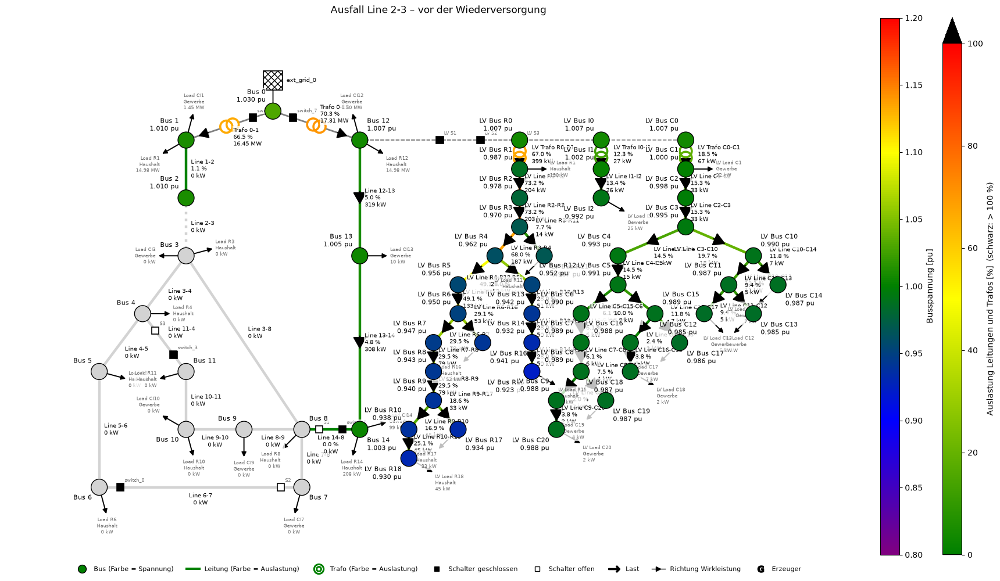

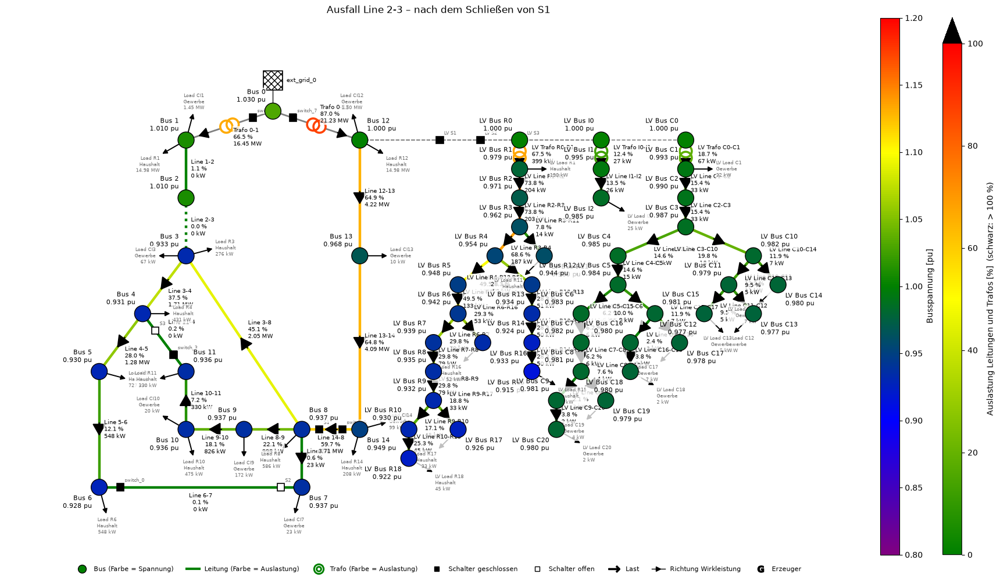

In [112]:
for schalter, titel in (([], "Ausfall Line 2-3 – vor der Wiederversorgung"),
                       (["S1"], "Ausfall Line 2-3 – nach dem Schließen von S1")):
    n = copy.deepcopy(spitzennetz)
    n.line.loc[n.line["name"] == "Line 2-3", "in_service"] = False
    n.switch.loc[n.switch["name"].isin(schalter), "closed"] = True
    pp.runpp(n)
    _ = netplan.plot_static(n, title=titel)

**Ergebnis der (n-1)-Prüfung für die Leitungen:**

- **Ohne Maßnahme** sind nach jedem Leitungsausfall 1 bis 10 Busse ohne Versorgung (bei Line 1-2 der ganze Abgang hinter Bus 1).
- **Mit Maßnahme** lässt sich jeder der 12 Leitungsausfälle bei Jahreshöchstlast vollständig wiederversorgen, ohne eine Grenze zu verletzen. Das Netz ist für Leitungsausfälle also (n-1)-sicher, wenn die Trennstellen nach Plan geschlossen werden.
- **Wiederversorgungsplan:**
  - S2 schließen bei Ausfall von Line 3-4, 4-5, 5-6, 7-8 und 3-8,
  - S3 schließen bei Ausfall von Line 8-9, 9-10 und 10-11,
  - S1 schließen bei Ausfall von Line 1-2, 2-3, 12-13 und 13-14.
- Welche Trennstelle passt, ergibt sich aus der Topologie: Fällt eine Leitung in einem Strang von Abgang 1 aus, wird der abgetrennte Teil über die Trennstelle am Strangende vom anderen Strang desselben Abgangs versorgt (S2 oder S3). Fällt eine Leitung am Anfang von Abgang 1 (Line 1-2, 2-3) oder in Abgang 2 aus, hilft nur die Kupplung über S1 aus dem anderen Trafo.
- **Netzzustand danach:** Die niedrigste MS-Spannung liegt zwischen 0,928 und 0,951 pu (über der Arbeitsgrenze 0,90 pu, teils unter dem Planungsband). Die höchste Leitungsauslastung steigt auf höchstens 86 %, der stärker belastete 110/20-kV-Trafo auf höchstens 87 %. In den S1-Fällen sinkt die NS-Spannung im Ortsnetz auf 0,915 pu; das gleicht die rONT-Regelung aus (Teil C).
- **Beispiel Line 2-3:** Nach dem Schließen von S1 fließt die Leistung für Bus 3 bis Bus 11 aus Trafo 0-12 über Bus 12, 13, 14 und S1 zu Bus 8 und von dort weiter durch Abgang 1; die Flussrichtung auf Line 3-8 kehrt sich um. Trafo 0-12 übernimmt die zusätzliche Last (87 %), Trafo 0-1 versorgt nur noch Bus 1 und Bus 2.

### 6.4 Fall A: Ausfall eines 110/20-kV-Transformators

Fällt Trafo 0-1 oder Trafo 0-12 aus, ist der ganze Abgang ohne Versorgung. Die einzige Verbindung zum anderen Trafo ist S1 am Ende der Abgänge (Bus 8 – Bus 14). Die (n-1)-Prüfung bei Jahreshöchstlast:

In [113]:
analyse_trafo = rg.ausfall_analyse(spitzennetz, ["Trafo 0-1", "Trafo 0-12"], [(), ("S1",), ("S2", "S3", "S1")], g["MS"])
analyse_trafo.round(3)

,Ausfall,Maßnahme,nicht versorgte Busse,getrennte Erzeugung [MW],U min MS [pu],U max MS [pu],U min NS [pu],Leitung max MS [%],am stärksten belastet,Trafo max HS/MS [%],zulässig,Bemerkung
0,Trafo 0-1,keine,11.0,0.0,1.003,1.007,0.923,4.979,Line 12-13,70.344,False,
1,Trafo 0-1,S1 schließen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Lastfluss konvergiert nicht
2,Trafo 0-1,S2 schließen + S3 schließen + S1 schließen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Lastfluss konvergiert nicht
3,Trafo 0-12,keine,46.0,0.0,0.950,1.003,NaN,78.638,Line 2-3,82.694,False,
4,Trafo 0-12,S1 schließen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Lastfluss konvergiert nicht
5,Trafo 0-12,S2 schließen + S3 schließen + S1 schließen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Lastfluss konvergiert nicht


Bei Jahreshöchstlast konvergiert der Lastfluss nicht, das Netz kann die Leistung über S1 nicht übertragen. Bis zu welcher Last wäre eine Wiederversorgung über S1 möglich? Dazu werden alle Lasten der Spitzenstunde schrittweise verkleinert:

In [114]:
zeilen = []
for trafo in ("Trafo 0-1", "Trafo 0-12"):
    for f in np.arange(0.15, 0.55, 0.05):
        n = copy.deepcopy(spitzennetz)
        n.load[["p_mw", "q_mvar"]] *= f
        n.trafo.loc[n.trafo["name"] == trafo, "in_service"] = False
        n.switch.loc[n.switch["name"] == "S1", "closed"] = True
        z = {"Ausfall": trafo, "Last [% der Spitzenstunde]": round(f * 100), "Last [MW]": n.load.p_mw.sum()}
        try:
            pp.runpp(n)
            mv = n.bus.index[n.bus["name"].isin(g["MS"])]
            ll = n.res_line.loading_percent[n.line.from_bus.isin(mv) & n.line.in_service]
            z.update({"Trafo max [%]": n.res_trafo.loading_percent[n.trafo.lv_bus.isin(mv)].max(),
                      "U min MS [pu]": n.res_bus.vm_pu[mv].min(), "Leitung max MS [%]": ll.max(),
                      "am stärksten belastet": n.line.at[ll.idxmax(), "name"]})
        except pp.LoadflowNotConverged:
            z["am stärksten belastet"] = "Lastfluss konvergiert nicht"
        zeilen.append(z)
trafo_scan = pd.DataFrame(zeilen)
display(plots.table(trafo_scan, decimals=2))
print(f"Kleinste Last der Zeitreihe: {P_netz.min():.1f} MW ({P_netz.min() / P_netz.max():.0%} der Jahreshöchstlast)")

,Ausfall,Last [% der Spitzenstunde],Last [MW],Trafo max [%],U min MS [pu],Leitung max MS [%],am stärksten belastet
0,Trafo 0-1,15.00,5.60,23.20,0.94,59.05,Line 3-8
1,Trafo 0-1,20.00,7.47,31.72,0.90,82.12,Line 3-8
2,Trafo 0-1,25.00,9.34,40.78,0.86,107.69,Line 3-8
3,Trafo 0-1,30.00,11.21,50.64,0.81,136.90,Line 3-8
4,Trafo 0-1,35.00,13.08,61.81,0.75,172.21,Line 3-8
5,Trafo 0-1,40.00,14.94,75.97,0.67,221.64,Line 3-8
6,Trafo 0-1,45.00,16.81,nan,nan,nan,Lastfluss konvergiert nicht
7,Trafo 0-1,50.00,18.68,nan,nan,nan,Lastfluss konvergiert nicht
8,Trafo 0-12,15.00,5.60,23.23,0.94,67.17,Line 2-3
9,Trafo 0-12,20.00,7.47,31.79,0.90,93.28,Line 2-3


Kleinste Last der Zeitreihe: 10.4 MW (28% der Jahreshöchstlast)


**Vergleich: Kupplung direkt im Umspannwerk.** In einem realen Umspannwerk mit zwei Trafos würde man die beiden 20-kV-Sammelschienen über eine Sammelschienen-Längskupplung verbinden [19, S. 522 f., Bild 11.8]. Im CIGRE-Modell gibt es diese Kupplung nicht. Hypothetisch wird sie als Schalter zwischen Bus 1 und Bus 12 eingefügt; damit wird geprüft, ob der verbleibende Trafo die Last allein tragen könnte. Zusätzlich die Zahl der Stunden der Zeitreihe, in denen die Scheinleistung aus dem 110-kV-Netz unter der Bemessungsleistung eines Trafos (25 MVA) liegt:

In [115]:
zeilen = []
for trafo in ("Trafo 0-1", "Trafo 0-12"):
    n = copy.deepcopy(spitzennetz)
    b1, b12 = (int(n.bus.index[n.bus["name"] == b][0]) for b in ("Bus 1", "Bus 12"))
    pp.create_switch(n, b1, b12, et="b", closed=True, name="LT (hypothetisch)")
    n.trafo.loc[n.trafo["name"] == trafo, "in_service"] = False
    pp.runpp(n)
    mv = n.bus.index[n.bus["name"].isin(g["MS"])]
    zeilen.append({"Ausfall": trafo, "verbleibender Trafo [%]": n.res_trafo.loading_percent[n.trafo.lv_bus.isin(mv)].max(),
                   "U min MS [pu]": n.res_bus.vm_pu[mv].min(),
                   "Leitung max MS [%]": n.res_line.loading_percent[n.line.from_bus.isin(mv)].max()})
display(plots.table(pd.DataFrame(zeilen).set_index("Ausfall"), decimals=3))

r0 = ungeregelt["000"].results
S_netz = np.hypot(r0.ext_grid_p_mw.squeeze(), r0.ext_grid_q_mvar.squeeze())
sn = float(ausgelegt.net.trafo.loc[ausgelegt.net.trafo["name"] == "Trafo 0-1", "sn_mva"].iloc[0])
print(f"Scheinleistung aus dem 110-kV-Netz: max {S_netz.max():.1f} MVA; "
      f"Stunden ≤ {sn:.0f} MVA: {int((S_netz <= sn).sum())} von {len(S_netz)} ({(S_netz <= sn).mean():.0%})")

,verbleibender Trafo [%],U min MS [pu],Leitung max MS [%]
Ausfall,,,
Trafo 0-1,158.741,0.914,81.750
Trafo 0-12,158.741,0.914,81.750


Scheinleistung aus dem 110-kV-Netz: max 39.4 MVA; Stunden ≤ 25 MVA: 1181 von 2016 (59%)


**Ergebnis Trafoausfall:**

- **Über S1 nicht wiederversorgbar:** Bei Jahreshöchstlast konvergiert der Lastfluss nicht. Ursache ist nicht der verbleibende Trafo, sondern der lange Weg über die Leitungen: Die ganze Leistung des ausgefallenen Abgangs müsste über S1 am Ende der Abgänge und dann durch die schwach ausgelegten Leitungen von Abgang 1 (zuerst Line 3-8 bzw. Line 2-3) fließen. Schon bei 25 % der Spitzenlast sind diese Leitungen überlastet und die MS-Spannung fällt unter 0,90 pu. Zulässig wäre die Wiederversorgung nur bis etwa 20 % der Spitzenlast (rund 7,5 MW); die kleinste Last der ganzen Zeitreihe liegt mit 10,4 MW (28 %) darüber.
- Das bestätigt die Literatur: Eine Kupplung am Strangende ist für die Wiederversorgung einzelner Leitungsabschnitte gedacht, nicht als Reserve für einen ganzen Trafo; Kuppelleitungen tragen nur einen Teil der Übertragungsfähigkeit [19, S. 36].
- **Mit Längskupplung im Umspannwerk (hypothetisch):** Die Leitungen wären nicht mehr der Engpass (höchstens 82 %), aber der verbleibende Trafo wäre bei Jahreshöchstlast mit 159 % überlastet. Ein Trafo allein reicht in 59 % der Stunden (Scheinleistung bis 25 MVA). Für die übrigen Stunden wäre eine zeitlich begrenzte Notüberlastung nach DIN IEC 60076-7 [29] zu prüfen, oder die Trafos müssten so ausgelegt werden, dass einer die Höchstlast allein tragen kann (vgl. [19, S. 515]).
- **Folgerung für den Backup-Plan:** Der Plan deckt Leitungsausfälle ab, aber keinen Ausfall eines 110/20-kV-Trafos. Für den Trafoausfall bräuchte das Netz eine Sammelschienen-Längskupplung im Umspannwerk und größere Trafos. Das ist eine Netzausbaumaßnahme und gehört zum Ausblick.

### 6.5 Fall B: Spannungsstützung ohne Ausfall

**Idee:** Fällt die MS-Spannung ohne Ausfall eines Betriebsmittels unter eine Schwelle, werden die Ringe vorübergehend geschlossen. Ein geschlossener Ring verbessert die Spannungshaltung [19, S. 514]; da die Ringe im MS-Netz wegen des Schutzes offen betrieben werden [19, S. 521 f.], ist das nur eine Notmaßnahme.

**Wirkung der einzelnen Schalter:** Mittlere Änderung der Spannung je MS-Bus gegenüber „alle offen“ in den 20 Stunden mit der niedrigsten MS-Spannung (Zeitreihen aus Teil 3, ohne Regelung), in Prozentpunkten:

In [116]:
base = ungeregelt["000"].results.vm_pu[g["MS"]]
schwach_h = base.min(axis=1).nsmallest(20).index
wirkung = pd.DataFrame({sz.label(k, kurz=True): ((s.results.vm_pu[g["MS"]] - base).loc[schwach_h].mean() * 100)
                        for k, s in ungeregelt.items()})
plots.table(wirkung, decimals=2, cmap="RdYlGn", vmin=-2.5, vmax=2.5)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus 1,0.00,0.00,0.00,0.00,0.24,0.24,0.25,0.24
Bus 2,0.00,0.00,0.00,0.01,1.02,1.01,1.03,1.02
Bus 3,0.00,0.01,0.00,0.01,2.19,2.17,2.22,2.20
Bus 4,0.00,-0.06,-0.00,-0.04,2.20,2.16,2.26,2.21
Bus 5,0.00,-0.06,-0.00,-0.02,2.20,2.17,2.29,2.25
Bus 6,0.00,-0.06,-0.00,0.04,2.20,2.17,2.38,2.37
Bus 7,0.00,0.15,0.00,0.06,2.52,2.53,2.39,2.39
Bus 8,0.00,0.15,0.00,0.13,2.52,2.53,2.48,2.51
Bus 9,0.00,0.19,0.00,0.17,2.52,2.54,2.49,2.53
Bus 10,0.00,0.27,0.00,0.27,2.52,2.56,2.49,2.58


**Was die Tabelle zeigt:**

- **S2 allein wirkt praktisch nicht.** Bus 6 und Bus 7 haben fast dieselbe Spannung, über die geschlossene Masche fließt kaum Leistung.
- **S3 hebt Bus 7 bis Bus 11 um 0,15 bis 0,3 Prozentpunkte** an, senkt aber Bus 4 bis Bus 6 leicht. **S2 und S3 zusammen** heben Bus 7 bis Bus 11 an und beseitigen die 8 Stunden unter dem Planungsband in Abgang 1.
- **S1 hebt Abgang 1 um gut 2 Prozentpunkte**, senkt aber Abgang 2: Bus 13 um 1,3 und Bus 14 um 2,0 Prozentpunkte, Bus 12 (Anschluss des Ortsnetzes) um 0,2 Prozentpunkte. Über S1 übernimmt Trafo 0-12 einen Teil der Last von Abgang 1.
- **Größenordnung:** S2 und S3 wirken mit weniger als 0,5 Prozentpunkten und können nur kleine Unterschreitungen ausgleichen. S1 wirkt stärker, koppelt aber beide Trafos. Daraus ergibt sich der Stufenplan unten: zuerst S2 und S3, S1 erst im Notfall.

**Stufenplan:**

| Stufe | Maßnahme | Auslösung (niedrigste MS-Spannung) | Rücknahme | Begründung |
|---|---|---|---|---|
| 1 | S2 und S3 schließen | < 0,94 pu | ≥ 0,95 pu | schließt nur die Ringe innerhalb von Abgang 1, beide Trafos bleiben getrennt |
| 2 | S1 schließen | < 0,92 pu | ≥ 0,96 pu | kuppelt beide Abgänge (Parallelbetrieb der Trafos), hebt Abgang 1 deutlich an, senkt aber Abgang 2; nur als Notfallmaßnahme |

- Die Auslöseschwellen liegen bewusst **unter** dem Planungsband: Stufe 1 bei mehr als 1 Prozentpunkt Unterschreitung, Stufe 2, wenn nur noch 2 Prozentpunkte Abstand zur Arbeitsgrenze 0,90 pu bleiben.
- Die Rücknahmeschwellen liegen um die Wirkung der Stufe plus Reserve höher, damit nach dem Öffnen nicht sofort wieder geschlossen wird (Hysterese).
- Je Prüfung wird höchstens eine Stufe zu- oder abgeschaltet; Rücknahme in umgekehrter Reihenfolge.
- Umsetzung: Klasse `SchaltPlan` in `regelung.py`.

In [117]:
def backup_plan(wiederversorgung=None):
    return rg.SchaltPlan(g["MS"], [(["S2", "S3"], 0.94, 0.95), (["S1"], 0.92, 0.96)], wiederversorgung=wiederversorgung)

**Test:** In der Zeitreihe fällt die MS-Spannung nie unter 0,94 pu (niedrigster Wert 0,949 pu), der Plan würde also nie auslösen. Damit trotzdem sichtbar wird, was er tut, wird er an drei statischen Lastspitzen getestet: alle Lasten gleichzeitig mit 100 %, 110 % und 120 % ihrer Bemessungsleistung. Hier ist **nur** der Backup-Plan aktiv (keine rONT-Regelung), damit seine Wirkung allein zu sehen ist.

So ist die Tabelle zu lesen: Für jede Lastspitze wird zuerst ein Lastfluss ohne Eingriff gerechnet (Zeile „Start“). Liegt die niedrigste MS-Spannung unter der Auslöseschwelle der nächsten Stufe, schließt der Backup-Plan die Schalter dieser Stufe, und der Lastfluss wird neu gerechnet (nächste Zeile). Das wiederholt sich, bis keine Schwelle mehr unterschritten ist.

In [118]:
zeilen = []
for faktor in (1.0, 1.1, 1.2):
    net = copy.deepcopy(ausgelegt.net)
    net.load[["p_mw", "q_mvar"]] *= faktor
    prot = rg.regle_statisch(net, [backup_plan()])       # Protokoll: Start und je Eingriff eine Zeile
    for it, z in prot.iterrows():
        # Lastfluss des Schritts nachrechnen, um MS-Werte getrennt auszuweisen
        n = copy.deepcopy(ausgelegt.net)
        n.load[["p_mw", "q_mvar"]] *= faktor
        zu = [] if z["geschlossene Trennschalter"] == "keine" else z["geschlossene Trennschalter"].split(", ")
        n.switch.loc[n.switch["name"].isin(zu), "closed"] = True
        pp.runpp(n)
        mv = n.bus.index[n.bus["name"].isin(g["MS"])]
        zeilen.append({"Lastspitze": f"{faktor:.0%}", "Schritt": "Start" if it == 0 else f"Eingriff {it}",
                       "geschlossene Trennschalter": z["geschlossene Trennschalter"],
                       "U min MS [pu]": n.res_bus.vm_pu[mv].min(),
                       "schwächster MS-Bus": n.bus.at[n.res_bus.vm_pu[mv].idxmin(), "name"],
                       "U Bus 12 [pu]": n.res_bus.vm_pu[n.bus.index[n.bus["name"] == "Bus 12"][0]],
                       "Leitung max MS [%]": n.res_line.loading_percent[n.line.from_bus.isin(mv)].max(),
                       "Trafo max HS/MS [%]": n.res_trafo.loading_percent[n.trafo.lv_bus.isin(mv)].max()})
stuetzung = pd.DataFrame(zeilen).set_index(["Lastspitze", "Schritt"])
plots.table(stuetzung, decimals=3)

**So läuft der Backup-Plan bei den drei Lastspitzen ab:**

| Lastspitze | Start: U min MS | Stufe 1 (S2 + S3) | Stufe 2 (S1) | Ergebnis |
|---|---|---|---|---|
| 100 % | 0,923 pu (Bus 11) | ausgelöst (< 0,94 pu) → 0,926 pu | nicht nötig (≥ 0,92 pu) | über der Arbeitsgrenze, unter dem Planungsband |
| 110 % | 0,909 pu (Bus 11) | ausgelöst → 0,913 pu | ausgelöst (< 0,92 pu) → **0,948 pu** | knapp unter dem Planungsband |
| 120 % | 0,895 pu (Bus 11, **unter 0,90 pu**) | ausgelöst → 0,899 pu | ausgelöst → **0,939 pu** | Arbeitsgrenze wieder eingehalten |

- **Stufe 1** hebt die Spannung nur um 0,3 bis 0,4 Prozentpunkte. Der schwächste Bus wandert dabei von Bus 11 zu Bus 6, weil S3 Bus 4 bis Bus 6 leicht absenkt (siehe Tabelle oben).
- **Stufe 2** wirkt stark: Über S1 übernimmt Trafo 0-12 einen Teil der Last von Abgang 1. Die MS-Spannung steigt um 3,5 bis 4 Prozentpunkte, und zusätzlich sinkt die höchste Leitungsauslastung von 108 % auf 59 % (110 %) bzw. von 120 % auf 65 % (120 %).
- **Grenzen:** Trafo 0-1 bleibt bei 110 % und 120 % Last über 100 % ausgelastet (107 % bzw. 117 %), weil er Abgang 1 weiterhin zum großen Teil versorgt. Bus 12 sinkt durch S1 nur geringfügig (um 0,3 bis 0,4 Prozentpunkte).
- Der Test zeigt, dass der Backup-Plan im Notfall eine Verletzung der Arbeitsgrenze 0,90 pu verhindern kann. Er ersetzt aber keinen Netzausbau: Die Überlastung des Trafos bleibt bestehen.

---
# Teil C – Zusammenspiel

## 7 Simulation mit rONT-Regelung und Backup-Plan gleichzeitig

Jetzt arbeiten alle Regler gemeinsam in der Zeitreihe (12 Wochen, stündlich):

| Regler | wirkt auf | greift ein, wenn … |
|---|---|---|
| 3 × `TapRegler` (rONT) | Stufenschalter der Ortsnetztrafos | eine NS-Spannung des eigenen Teilnetzes das Band 0,95 … 1,05 pu verlässt (Teil A) |
| `Wiederversorgung` | S1–S3 nach dem Wiederversorgungsplan aus 6.3 | ein Betriebsmittel ausgefallen ist (Fall A) |
| `SchaltPlan` | S2+S3, dann S1 | die niedrigste MS-Spannung unter 0,94 bzw. 0,92 pu fällt (Fall B) |

Nach jedem Lastfluss prüfen alle Regler das Ergebnis; greift einer ein, wird dieselbe Stunde neu gerechnet. Schalter, die die Wiederversorgung geschlossen hat, öffnet der `SchaltPlan` nicht wieder, solange das Betriebsmittel ausgefallen ist.

Drei Fälle:

1. **Normalbetrieb:** gleiche Randbedingungen wie in Abschnitt 5.1. Erwartung: Der Backup-Plan greift nie ein, das Ergebnis ist identisch mit der reinen rONT-Regelung.
2. **Störfall:** Line 2-3 fällt aus und bleibt für die ganzen 12 Wochen außer Betrieb (ungünstigster Fall: die Leitung, nach deren Ausfall die meisten Busse über S1 versorgt werden müssen).
3. **Laststeigerung:** alle Lasten 20 % bzw. 30 % höher als geplant, z. B. durch Wärmepumpen und Elektromobilität ohne Netzausbau.

### 7.1 Normalbetrieb

In [119]:
def alle_regler():
    wv = rg.Wiederversorgung(WIEDERVERSORGUNG)
    return lv_regler() + [wv, backup_plan(wiederversorgung=wv)]

kombi = {}
kombi["Normalbetrieb"] = ausgelegt.copy("w4_t3c_normal", overwrite=True)
kombi["Normalbetrieb"].runSimulation(controllers=alle_regler())

Simulation 'w4_t3c_normal': unverändert seit dem Lauf vom 2026-11-08T21:03:35 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, line_p_mw, line_pl_mw, trafo_loading, trafo_p_mw, trafo_pl_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, line_q_mvar, trafo_q_mvar, trafo_i_hv_ka, trafo_i_lv_ka, bus_p_mw, bus_q_mvar, ext_grid_q_mvar, load_q_mvar, sgen_q_mvar, tap_pos, switch_closed, storage_p_mw, storage_soc_percent, element_p_mw, info

In [120]:
def kombi_tabelle(sims):
    rows = {}
    for name, s in sims.items():
        sw = s.results.switch_closed[["S1", "S2", "S3"]]
        rows[name] = pd.concat([band_stunden(s),
                                pd.Series({"Leitung max MS [%]": s.results.line_loading[[c for c in s.results.line_loading if c.startswith("Line")]].max().max(),
                                           "Trafo max HS/MS [%]": s.results.trafo_loading[["Trafo 0-1", "Trafo 0-12"]].max().max()}),
                                rg.schaltvorgaenge(s),
                                sw.sum().rename(lambda c: f"Stunden {c} geschlossen")])
    return pd.DataFrame(rows)

plots.table(kombi_tabelle({"nur rONT (5.1)": geregelt, **kombi}).astype(float), decimals=3)

,nur rONT (5.1),Normalbetrieb
Stunden < 0.95 MS,8.000,8.000
Stunden > 1.05 MS,0.000,0.000
Stunden < 0.9 MS,0.000,0.000
Stunden > 1.1 MS,0.000,0.000
U min MS [pu],0.949,0.949
U max MS [pu],1.024,1.024
Stunden < 0.95 NS,0.000,0.000
Stunden > 1.05 NS,0.000,0.000
Stunden < 0.9 NS,0.000,0.000
Stunden > 1.1 NS,0.000,0.000


**Ergebnis Normalbetrieb:** Die Ergebnisse sind in allen Kennwerten identisch mit der reinen rONT-Regelung aus Abschnitt 5.1. Die niedrigste MS-Spannung (0,949 pu) liegt über der Auslöseschwelle 0,94 pu, es fällt kein Betriebsmittel aus; der Backup-Plan wird in keiner Stunde ausgelöst (0 Schaltungen). Damit ist die Forderung erfüllt, dass das Netz im Normalbetrieb ohne den Backup-Plan auskommt.

### 7.2 Störfall: Ausfall von Line 2-3

Vor dem ersten Lastfluss meldet die Simulation die nicht versorgten Busse; das ist der Zustand direkt nach dem Ausfall, bevor die Wiederversorgung S1 schließt.

In [121]:
kombi["Ausfall Line 2-3"] = ausgelegt.copy("w4_t3c_ausfall_2_3", overwrite=True)
kombi["Ausfall Line 2-3"].changeParameter("Line 2-3", "in_service", False)
kombi["Ausfall Line 2-3"].runSimulation(controllers=alle_regler())

Hinweis: 9 Busse sind nicht versorgt (z. B. ['Bus 3', 'Bus 4', 'Bus 5', 'Bus 6', 'Bus 7']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Simulation 'w4_t3c_ausfall_2_3': unverändert seit dem Lauf vom 2026-11-08T21:04:50 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, line_p_mw, line_pl_mw, trafo_loading, trafo_p_mw, trafo_pl_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, line_q_mvar, trafo_q_mvar, trafo_i_hv_ka, trafo_i_lv_ka, bus_p_mw, bus_q_mvar, ext_grid_q_mvar, load_q_mvar, sgen_q_mvar, tap_pos, switch_closed, storage_p_mw, storage_soc_percent, element_p_mw, info

In [122]:
plots.table(kombi_tabelle({"Normalbetrieb": kombi["Normalbetrieb"], "Ausfall Line 2-3": kombi["Ausfall Line 2-3"]}).astype(float), decimals=3)

,Normalbetrieb,Ausfall Line 2-3
Stunden < 0.95 MS,8.000,257.000
Stunden > 1.05 MS,0.000,0.000
Stunden < 0.9 MS,0.000,0.000
Stunden > 1.1 MS,0.000,0.000
U min MS [pu],0.949,0.932
U max MS [pu],1.024,1.025
Stunden < 0.95 NS,0.000,0.000
Stunden > 1.05 NS,0.000,0.000
Stunden < 0.9 NS,0.000,0.000
Stunden > 1.1 NS,0.000,0.000


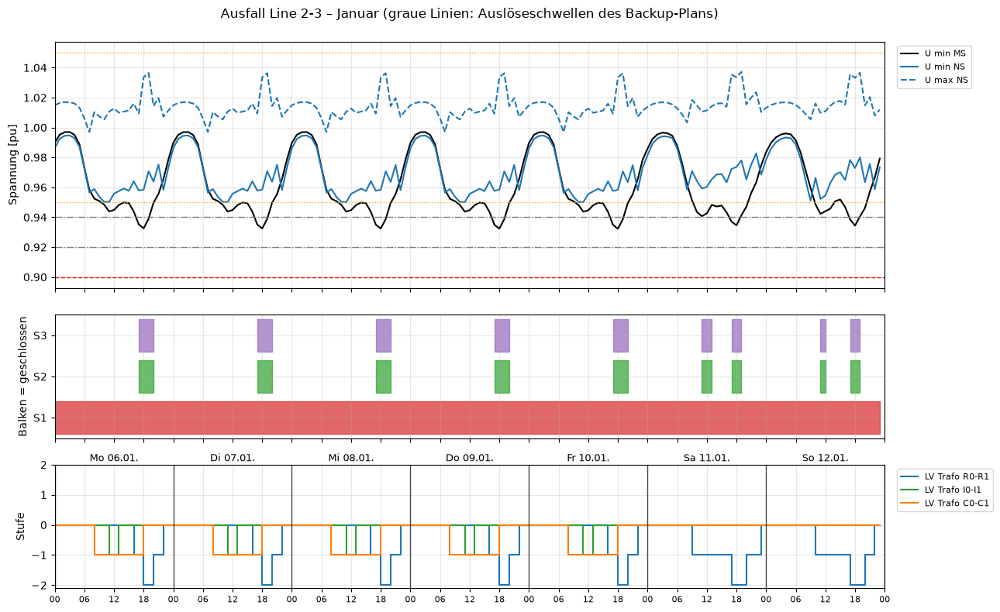

In [123]:
s = kombi["Ausfall Line 2-3"]
idx = s.results.info.index[s.results.info.month == "JANUARY"]
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
vm = s.results.vm_pu.loc[idx]
axes[0].plot(idx, vm[g["MS"]].min(axis=1), color="black", label="U min MS")
axes[0].plot(idx, vm[g["NS"]].min(axis=1), color="tab:blue", label="U min NS")
axes[0].plot(idx, vm[g["NS"]].max(axis=1), color="tab:blue", ls="--", label="U max NS")
for v, c, ls in ((V_MIN, "red", "--"), (V_PLAN_MIN, "orange", ":"), (V_PLAN_MAX, "orange", ":"), (0.94, "grey", "-."), (0.92, "grey", "-.")):
    axes[0].axhline(v, color=c, ls=ls, lw=1)
axes[0].set_ylabel("Spannung [pu]")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[0].set_title("Ausfall Line 2-3 – Januar (graue Linien: Auslöseschwellen des Backup-Plans)", pad=22)
sw = s.results.switch_closed.loc[idx, ["S1", "S2", "S3"]].astype(bool)
for i, (c, farbe) in enumerate(zip(sw.columns, ("tab:red", "tab:green", "tab:purple"))):
    axes[1].fill_between(idx, i + 0.1, i + 0.9, where=sw[c].to_numpy(), step="post", color=farbe, alpha=0.7)
axes[1].set_ylim(0, 3)
axes[1].set_yticks([0.5, 1.5, 2.5], ["S1", "S2", "S3"])
axes[1].set_ylabel("Balken = geschlossen")
taps = s.results.tap_pos.loc[idx, [TRAFO[x] for x in "RIC"]]
for x, farbe in zip("RIC", ("tab:blue", "tab:green", "tab:orange")):
    axes[2].step(idx, taps[TRAFO[x]], where="post", color=farbe, label=TRAFO[x])
axes[2].set_ylabel("Stufe")
axes[2].set_yticks(range(-2, 3))
axes[2].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plots.week_axis(axes[2], idx)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

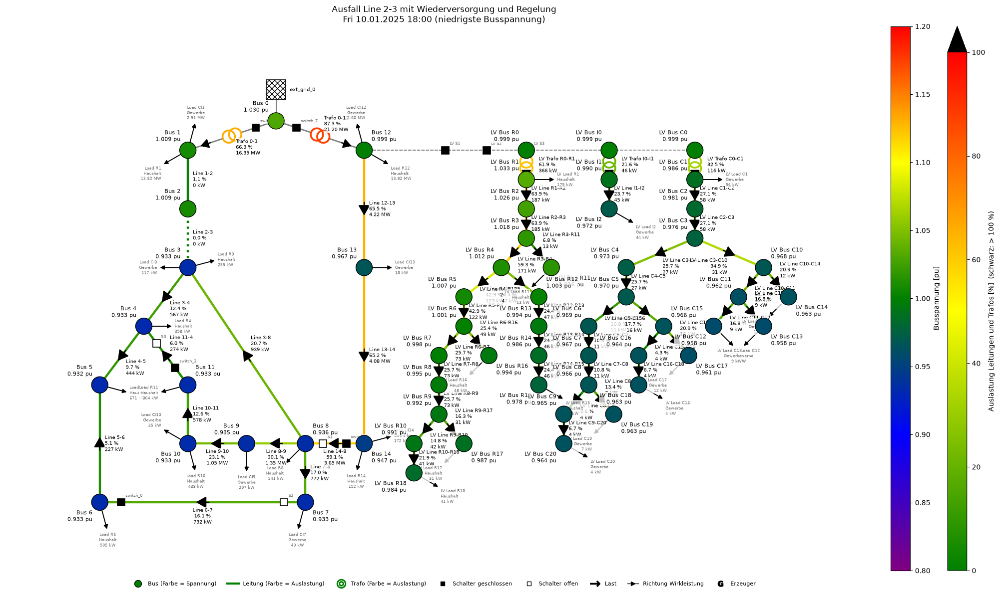

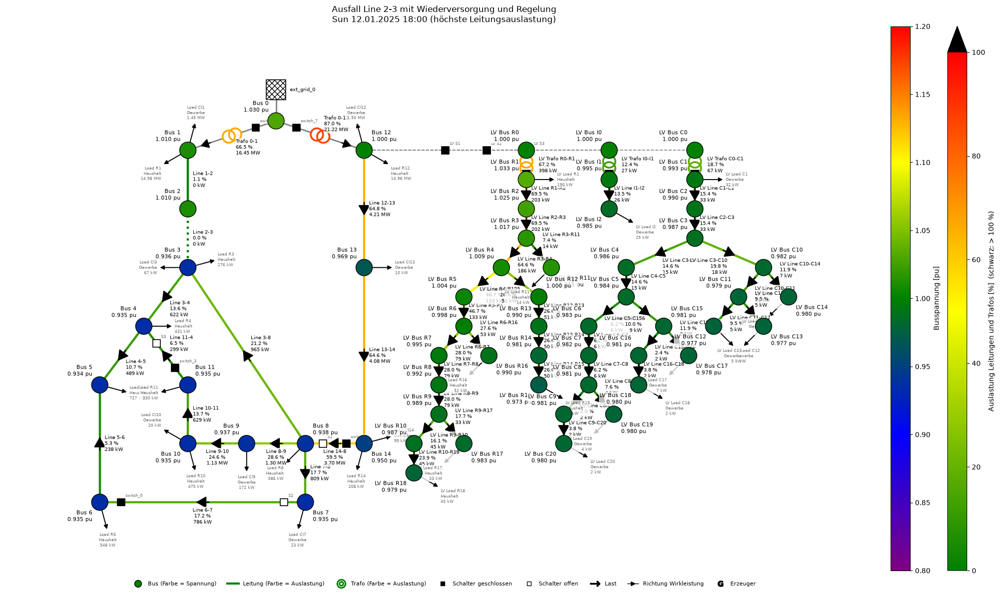

In [124]:
s.createDiagram(Diagram.NETWORK, time=["min", "max_loading"], title="Ausfall Line 2-3 mit Wiederversorgung und Regelung")

**Ergebnis Störfall Line 2-3:**

- **Wiederversorgung:** In der ersten Stunde sind Bus 3 bis Bus 11 ohne Versorgung. Die `Wiederversorgung` schließt S1 sofort (eine Schaltung), danach sind in allen 2016 Stunden alle Busse versorgt. Keine Leitung und kein Trafo ist überlastet (höchstens 65 % bzw. 87 %).
- **MS-Spannung:** Weil Abgang 1 jetzt über den langen Weg Bus 12–13–14–8 versorgt wird, fällt die MS-Spannung öfter unter das Planungsband (257 statt 8 Stunden, niedrigster Wert 0,932 pu an Bus 5). Die Arbeitsgrenze 0,90 pu wird nie verletzt.
- **Spannungsstützung:** In 114 Stunden (abends 17 bis 20 Uhr und mittags, nur in den Wintermonaten) fällt die MS-Spannung unter 0,94 pu, und der `SchaltPlan` schließt zusätzlich S2 und S3 (76 Schaltungen je Schalter). Die Wirkung ist klein, weil S1 schon geschlossen ist und S3 den schwächsten Bereich (Bus 4 bis Bus 6) eher absenkt; in 62 Stunden bleibt die Spannung unter 0,94 pu. S1 bleibt die ganze Zeit zu, weil die Wiederversorgung es gesperrt hat.
- **Ortsnetz:** Die rONT-Regler halten das Ortsnetz trotz des Störfalls in jeder Stunde im Planungsband (0,950 bis 1,039 pu). Sie brauchen dafür mehr Stufenschritte (Wohngebiet 132 statt 92, Gewerbe 120 statt 100, Industrie 10 statt 0), weil Bus 12 durch die zusätzliche Last über Trafo 0-12 etwas tiefer liegt. Im Wohngebiet wird abends erstmals auch die zweite Stufe (−2) genutzt; der Stellbereich ist damit zum Teil ausgeschöpft.
- **Zusammenspiel:** Die drei Regler stören sich nicht: Je Stunde reicht eine Nachrechnung, und der `SchaltPlan` öffnet den von der Wiederversorgung geschlossenen Schalter S1 nicht.

### 7.3 Laststeigerung um 20 % und 30 %

Alle Lasten (Jahresenergie und Höchstleistung) werden um 20 % bzw. 30 % erhöht; das Netz bleibt unverändert, kein Ausfall.

In [125]:
for faktor in (1.2, 1.3):
    name = f"Last +{faktor - 1:.0%}"
    s = ausgelegt.copy(f"w4_t3c_last{round(faktor * 100)}", overwrite=True)
    s.net.load[["annual_kwh", "p_mw", "q_mvar"]] *= faktor
    s.save(results=False)
    s.runSimulation(controllers=alle_regler())
    kombi[name] = s
plots.table(kombi_tabelle({k: kombi[k] for k in ("Normalbetrieb", "Last +20%", "Last +30%")}).astype(float), decimals=3)

Simulation 'w4_t3c_last120': unverändert seit dem Lauf vom 2026-11-08T21:06:23 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t3c_last130': unverändert seit dem Lauf vom 2026-11-08T21:07:51 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


,Normalbetrieb,Last +20%,Last +30%
Stunden < 0.95 MS,8.000,197.000,409.000
Stunden > 1.05 MS,0.000,0.000,0.000
Stunden < 0.9 MS,0.000,0.000,0.000
Stunden > 1.1 MS,0.000,0.000,0.000
U min MS [pu],0.949,0.931,0.920
U max MS [pu],1.024,1.023,1.022
Stunden < 0.95 NS,0.000,0.000,3.000
Stunden > 1.05 NS,0.000,0.000,0.000
Stunden < 0.9 NS,0.000,0.000,0.000
Stunden > 1.1 NS,0.000,0.000,0.000


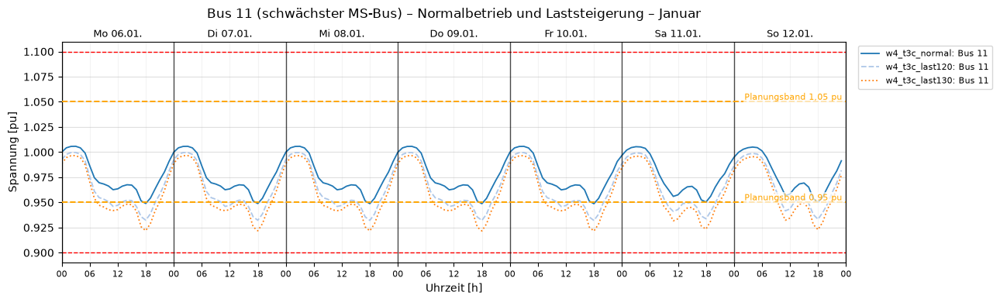

In [126]:
sim.compare([kombi["Normalbetrieb"], kombi["Last +20%"], kombi["Last +30%"]], Diagram.VOLTAGE, ["Bus 11"], months=Month.JANUARY,
            markers=PLAN_MARKER, title="Bus 11 (schwächster MS-Bus) – Normalbetrieb und Laststeigerung")

**Ergebnis Laststeigerung:**

| Kennwert | Normalbetrieb | Last +20 % | Last +30 % |
|---|---|---|---|
| Stunden MS < 0,95 pu | 8 | 197 | 409 |
| U min MS | 0,949 pu | 0,931 pu | 0,920 pu |
| Stunden NS < 0,95 pu | 0 | 0 | 3 |
| Leitung max MS | 79 % | 96 % | **106 %** (33 Stunden > 100 %) |
| Trafo 0-1 max | 83 % | **100,3 %** (1 Stunde) | **109 %** (70 Stunden > 100 %) |
| Stunden S2 + S3 geschlossen | 0 | 106 | 224 |
| Stunden S1 geschlossen | 0 | 0 | 0 |

- **Ortsnetz:** Bei +20 % halten die rONT-Regler das Ortsnetz noch vollständig im Band, mit mehr als doppelt so vielen Stufenschritten. Bei +30 % reichen die zwei Stufen in 3 Stunden nicht mehr aus (niedrigster Wert 0,945 pu); der Stellbereich ist erschöpft.
- **MS-Netz:** Stufe 1 des Backup-Plans (S2 + S3) wird in 106 bzw. 224 Stunden ausgelöst, vor allem abends im Winter. Stufe 2 (S1) wird nie ausgelöst, weil die MS-Spannung nicht unter 0,92 pu fällt (niedrigster Wert genau 0,920 pu). Die Arbeitsgrenze 0,90 pu wird nie verletzt.
- **Neue Schwachstelle – Überlastung:** Bei +30 % sind Trafo 0-1 in 70 Stunden und die höchstbelastete MS-Leitung (Line 2-3) in 33 Stunden über 100 % ausgelastet. Der Backup-Plan reagiert nur auf die Spannung, nicht auf die Auslastung. Der statische Test in 6.5 zeigt, dass S1 die Leitungsauslastung deutlich senken würde (von 108 % auf 59 %), den Trafo aber kaum entlastet.
- **Folgerung:** Bis etwa +20 % Last reichen rONT-Regelung und Backup-Plan. Darüber ist Netzausbau nötig (stärkerer Trafo 0-1, Verstärkung von Abgang 1, siehe auch Teil 6 zu Line 3-8). Der Backup-Plan ließe sich um ein Auslastungskriterium erweitern (S1 schließen, wenn eine MS-Leitung über 100 % ausgelastet ist), aber auch das wäre nur eine Notmaßnahme.

## 8 Fazit

**Teil A – rONT-Regelung:**

- Drei unabhängige rONT-Regler mit Messung im eigenen Teilnetz halten das Ortsnetz in allen Schaltzuständen im Planungsband 0,95 bis 1,05 pu (vorher 450 Stunden darunter). Fast immer reicht eine Stufe; im Jahr sind etwa 400 bis 430 Stufenschritte je Trafo zu erwarten.
- Entscheidend ist die Messung an den Strangenden; an der Sammelschiene wäre keine Verletzung zu sehen gewesen.
- Eine feste Stufenstellung reicht nicht: Eine Stellung, die die Spitzenlast abdeckt, erzeugt bei Schwachlast Überspannung (bis 1,073 pu). Die Regelrichtung nach unten funktioniert (Überspannungstest).

**Teil B – Backup-Plan:**

- Nach der Literatur sind Trennstellen im MS-Netz vor allem für die Wiederversorgung nach einem Ausfall vorgesehen; im Normalbetrieb sind die Ringe offen [19, S. 521 f.]. Der Backup-Plan hat deshalb zwei Teile: Wiederversorgung (Fall A) und Spannungsstützung (Fall B).
- **Fall A:** Alle 12 Leitungsausfälle lassen sich bei Jahreshöchstlast mit genau einem Schalter vollständig wiederversorgen (S2, S3 oder S1). Für Leitungsausfälle ist das Netz damit (n-1)-sicher. Einen Ausfall eines 110/20-kV-Trafos kann S1 nicht auffangen; dafür wären eine Längskupplung im Umspannwerk und größere Trafos nötig.
- **Fall B:** Die Spannungsstützung (S2 + S3, dann S1) verhindert bei Lastspitzen von 110 % und 120 % eine Verletzung der Arbeitsgrenze. S2 und S3 wirken nur schwach, S1 stark.

**Teil C – Zusammenspiel:**

- Im Normalbetrieb greift der Backup-Plan nie ein; die Ergebnisse sind identisch mit der reinen rONT-Regelung.
- Beim Ausfall von Line 2-3 versorgt die Wiederversorgung über S1 alle Busse wieder, die rONT-Regler halten das Ortsnetz weiter im Band. Die Regler arbeiten ohne gegenseitige Störung zusammen.
- Bei einer Laststeigerung um 30 % reichen weder der Stellbereich des rONT noch der Backup-Plan; Trafo 0-1 und Line 2-3 werden überlastet. Ab hier ist Netzausbau nötig.

**Grenzen der Untersuchung:** Stundenwerte, symmetrischer Lastfluss, keine Schutztechnik und keine Schaltzeiten; die Wiederversorgung ist idealisiert (sofort nach dem Ausfall). Erzeugung und Leistungsflussumkehr werden erst mit den Szenarien in Teil 4 geprüft.

<a id="teil-5"></a>

---

# Task 4 – Teil 4a: Erneuerbare Energien – Anschluss von Windpark und PV-Anlage

**Ausgangspunkt:** das geregelte Netz aus Teil 3b (CIGRE-MV ohne DER, CIGRE-LV-Ortsnetz an Bus 12 mit Standardtrafos, rONT-Regler je Teilnetz und Backup-Plan für das MV-Netz). Voraussetzung: `Task4-3_Ortsnetz_Auslegung.ipynb` und `Task4-3b_Regelung.ipynb` wurden ausgeführt.

**Szenarien des Arbeitsauftrags:**

1. **Windpark:** 15 WEA vom Typ Vestas V90-2.0 MW, zusammen **30 MW**, an einem 20-kV-Bus
2. **Ortsnetz mit PV-Haushalten:** Haushalte mit PV-Anlage und Batteriespeicher im Wohngebiet (Teil 4b)
3. **Großflächen-PV:** Freiflächenanlage mit **10 MWp** an einem 20-kV-Bus

**Vorgehen:**

1. Windpark und PV-Anlage werden **einzeln an jeden 20-kV-Bus** (Bus 1 bis Bus 14) angeschlossen und über 12 typische Wochen simuliert.
2. Ausgeschlossen wird jeder Bus, an dem eine Spannung unter 0,90 pu bzw. über 1,10 pu oder eine Auslastung über 100 % auftritt (wie in Teil 2, für Erzeugung um die Obergrenze ergänzt).
3. Alle **Kombinationen** der verbleibenden Busse für Windpark und PV-Anlage werden gemeinsam simuliert und im Normalbetrieb bewertet.
4. Für jede Kombination wird das **(n-1)-Kriterium** geprüft (Ausfall einer Leitung oder eines 110/20-kV-Trafos mit Wiederversorgung nach dem Plan aus Teil 3b). Die Entscheidung fällt nach Normalbetrieb und (n-1)-Kriterium zusammen, mit Relevanzschwellen, damit sehr kleine Unterschiede nicht den Ausschlag geben.
5. Für die gewählte Kombination folgt am Ende eine ausführliche (n-1)-Auswertung (Abschnitt 5).

Dieses Notebook klärt, **wo** Windpark und PV-Anlage angeschlossen werden. Alle Rechnungen laufen deshalb im Normalbetrieb (alle Trennschalter offen) mit der Regelung aus Teil 3b. Das Ortsnetz-Szenario, die Szenarien einzeln und kombiniert in allen Schalterstellungen, hohe und niedrige Situationen und das Blindleistungsverhalten folgen in `Task4-4b_Szenarien.ipynb`.

## Importe

In [127]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import copy

import numpy as np
import pandas as pd
import pandapower as pp
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import regelung as rg
import bewertung as bw
import plots
import netplan
import auswertung as aw
from auswertung import PLAN_MARKER
from elements import Diagram, Profile, Generator
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

sim.ONLY_RUN_IF_CHANGED = True

ausgelegt = sim.loadSimulation("w4_t3_ausgelegt")        # Teil 3: ausgelegtes Netz, alle Trennschalter offen
normal = sim.loadSimulation("w4_t3_geregelt")            # Teil 3b: Normalbetrieb mit Regelung (Referenz)
MV_BUSES = [f"Bus {i}" for i in range(1, 15)]

Modul `bewertung.py`: Kennwerte, Ausschluss und Rangfolge von Anschlussvarianten nach einheitlichen Kriterien. `regelung.standard_regler(net)` liefert die Regler aus Teil 3b (drei rONT-Regler, Backup-Plan) für jedes Netz mit Ortsnetz.

## 1 Erzeugungsanlagen

| Anlage | Modell im Netz | Leistung | Profil | Leistungsfaktor |
|---|---|---|---|---|
| Windpark | ein Erzeuger `Windpark` (sgen) für 15 gleiche Anlagen | 15 × 2,0 MW = 30 MW | Kennlinie Vestas V90-2.0 MW aus Wind auf Nabenhöhe 105 m (`Profile.WIND`, Datengrundlage 1.2) | cos φ = 1 |
| PV-Freiflächenanlage | ein Erzeuger `PV-Freifläche` (sgen) | 10 MWp | Wetter, Modul Trina Vertex S+ (`Profile.PV`, Datengrundlage 1.3) | cos φ = 1 |

- **Windpark:** Der Arbeitsauftrag gibt 15 WEA vor; Anlagentyp und Kennlinie sind in der Datengrundlage beschrieben. Alle 15 Anlagen erhalten dieselbe Windgeschwindigkeit und werden deshalb als ein Erzeuger mit 30 MW abgebildet (gleichzeitige Einspeisung, keine Abschattung im Park; eher ungünstig für das Netz).
- **PV-Anlage:** PV-Freiflächenanlagen sind Anlagen ab 1 MWp; die 18 Zuschläge der Innovationsausschreibung im April 2021 hatten zusammen 258 MW PV-Leistung, also im Mittel rund 14 MWp [22]. 10 MWp sind damit eine typische Größe.
- **Blindleistung:** zunächst cos φ = 1 (reine Wirkleistungseinspeisung). Den Vergleich mit Blindleistungsbereitstellung (cos φ = 0,95 untererregt nach VDE-AR-N 4110 [31]) enthält Teil 4b, Abschnitt 5.
- **Vorzeichen:** Erzeuger speisen mit `p_mw > 0` ein (Erzeugerzählpfeilsystem in pandapower).

In [128]:
def windpark(bus):
    return Generator("Windpark", bus=bus, profile=Profile.WIND, p_mw=30.0)

def pv_anlage(bus):
    return Generator("PV-Freifläche", bus=bus, profile=Profile.PV, kwp=10_000)

def mit_erzeugern(name, erzeuger):
    """Kopie des ausgelegten Netzes mit den angegebenen Erzeugern, gerechnet mit der Regelung aus Teil 3b."""
    s = ausgelegt.copy(name, overwrite=True)
    for e in erzeuger:
        s.createElement(e)
    s.runSimulation(controllers=rg.standard_regler(s.net))
    return s

def auswertung(sims, titel):
    werte, orte = bw.kennwerte(sims)
    tab, kandidaten, immer = bw.ausschluss(werte)
    print(f"{titel}: verbleibend {kandidaten or 'keine'}")
    if immer:
        print("Bei allen Varianten verletzt (für die Auswahl ausgeklammert):", immer)
    return werte, orte, tab, kandidaten

## 2 Windpark: Anschluss an jeden 20-kV-Bus

In [129]:
wind = {b: mit_erzeugern(f"w4_wind_{b.replace(' ', '')}", [windpark(b)]) for b in MV_BUSES}

Simulation 'w4_wind_Bus1': unverändert seit dem Lauf vom 2026-11-08T21:12:16 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus2': unverändert seit dem Lauf vom 2026-11-08T21:13:24 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus3': unverändert seit dem Lauf vom 2026-11-08T21:14:32 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus4': unverändert seit dem Lauf vom 2026-11-08T21:15:41 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus5': unverändert seit dem Lauf vom 2026-11-08T21:16:58 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus6': unverändert seit dem Lauf vom 2026-11-08T21:18:07 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_wind_Bus7': unverändert seit dem Lauf vom 2026-11-08T21:19:17 – gespeiche

In [130]:
w_werte, w_orte, w_tab, w_kand = auswertung(wind, "Windpark")
cols = ["U max gesamt [pu]", "U max MS [pu]", "U max NS [pu]", "U min gesamt [pu]", "Leitung max MS [%]",
        "Leitung max NS [%]", "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]", "Stunden Rückspeisung 110 kV",
        "max. Rückspeisung 110 kV [MW]"]
display(plots.table(w_werte[cols].astype(float), decimals=3))
display(w_orte[["U max gesamt [pu]", "Leitung max MS [%]", "Trafo max HS/MS [%]"]])
w_tab

Windpark: verbleibend ['Bus 1', 'Bus 12']


,U max gesamt [pu],U max MS [pu],U max NS [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
Bus 1,1.027,1.025,1.027,0.950,78.491,71.073,88.512,66.838,233.000,16.100
Bus 2,1.086,1.086,1.027,0.950,523.723,71.073,82.403,66.838,203.000,13.732
Bus 3,1.151,1.151,1.027,0.950,494.651,71.073,78.948,66.838,174.000,10.679
Bus 4,1.156,1.156,1.027,0.950,511.322,71.073,78.948,66.838,170.000,10.253
Bus 5,1.160,1.160,1.027,0.950,513.831,71.073,79.070,66.838,166.000,9.855
Bus 6,1.170,1.170,1.027,0.950,519.750,71.073,80.088,66.838,157.000,8.845
Bus 7,1.172,1.172,1.027,0.950,526.357,71.073,80.364,66.838,155.000,8.699
Bus 8,1.161,1.161,1.027,0.950,503.422,71.073,79.101,66.838,166.000,9.772
Bus 9,1.164,1.164,1.027,0.950,507.966,71.073,79.240,66.838,165.000,9.542
Bus 10,1.169,1.169,1.027,0.950,515.789,71.073,79.754,66.838,159.000,9.042


,U max gesamt [pu],Leitung max MS [%],Trafo max HS/MS [%]
Bus 1,LV Bus R1,Line 2-3,Trafo 0-1
Bus 2,Bus 2,Line 1-2,Trafo 0-1
Bus 3,Bus 3,Line 2-3,Trafo 0-1
Bus 4,Bus 4,Line 3-4,Trafo 0-1
Bus 5,Bus 5,Line 4-5,Trafo 0-1
Bus 6,Bus 6,Line 5-6,Trafo 0-1
Bus 7,Bus 7,Line 7-8,Trafo 0-1
Bus 8,Bus 7,Line 3-8,Trafo 0-1
Bus 9,Bus 9,Line 8-9,Trafo 0-1
Bus 10,Bus 10,Line 9-10,Trafo 0-1


,"U < 0,90 pu (MS)","U < 0,90 pu (NS)","U > 1,10 pu (MS)","U > 1,10 pu (NS)",Leitung MS > 100 %,Leitung NS > 100 %,Trafo HS/MS > 100 %,Ortsnetztrafo > 100 %,ausgeschlossen wegen,Ergebnis
Bus 1,0,0,0,0,0,0,0,0,–,bleibt
Bus 2,0,0,0,0,875,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 3,0,0,457,0,863,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 4,0,0,496,0,955,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 5,0,0,532,0,972,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 6,0,0,612,0,1001,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 7,0,0,628,0,1026,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 8,0,0,539,0,947,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 9,0,0,551,0,972,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen
Bus 10,0,0,592,0,988,0,0,0,"U > 1,10 pu (MS), Leitung MS > 100 %",ausgeschlossen


In [131]:
w_rang, w_best = bw.rangfolge(w_werte, w_kand)
display(w_rang)
print("Bester Einzelanschluss Windpark:", w_best)

,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Rang U max gesamt,Rang U min gesamt,Rang Leitung max MS,Rang Leitung max NS,Rang Trafo max HS/MS,Rang Ortsnetztrafo max,Rangsumme,Verluste [MWh]
Bus 1,1.027,0.950,78.5,71.1,88.5,66.8,1,1,1,2,1,2,8,154.9
Bus 12,1.028,0.949,78.6,71.0,92.3,66.7,2,2,2,1,2,1,10,158.6


Bester Einzelanschluss Windpark: Bus 1


## 3 PV-Freiflächenanlage: Anschluss an jeden 20-kV-Bus

In [132]:
pv = {b: mit_erzeugern(f"w4_pv_{b.replace(' ', '')}", [pv_anlage(b)]) for b in MV_BUSES}

Simulation 'w4_pv_Bus1': unverändert seit dem Lauf vom 2026-11-08T21:28:42 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus2': unverändert seit dem Lauf vom 2026-11-08T21:29:52 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus3': unverändert seit dem Lauf vom 2026-11-08T21:31:01 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus4': unverändert seit dem Lauf vom 2026-11-08T21:32:09 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus5': unverändert seit dem Lauf vom 2026-11-08T21:33:20 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus6': unverändert seit dem Lauf vom 2026-11-08T21:34:30 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_pv_Bus7': unverändert seit dem Lauf vom 2026-11-08T21:35:39 – gespeicherte Ergebnisse

In [133]:
p_werte, p_orte, p_tab, p_kand = auswertung(pv, "PV-Anlage")
display(plots.table(p_werte[cols].astype(float), decimals=3))
display(p_orte[["U max gesamt [pu]", "Leitung max MS [%]", "Trafo max HS/MS [%]"]])
p_tab

PV-Anlage: verbleibend ['Bus 1', 'Bus 12']


,U max gesamt [pu],U max MS [pu],U max NS [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
Bus 1,1.027,1.024,1.027,0.949,78.638,71.073,82.694,66.838,0.000,0.000
Bus 2,1.033,1.033,1.027,0.949,119.314,71.073,82.694,66.838,0.000,0.000
Bus 3,1.056,1.056,1.027,0.949,117.165,71.073,82.694,66.838,0.000,0.000
Bus 4,1.060,1.060,1.027,0.949,142.781,71.073,82.694,66.838,0.000,0.000
Bus 5,1.064,1.064,1.027,0.949,145.802,71.073,82.694,66.838,0.000,0.000
Bus 6,1.075,1.075,1.027,0.949,150.284,71.073,82.694,66.838,0.000,0.000
Bus 7,1.075,1.075,1.027,0.949,153.560,71.073,82.694,66.838,0.000,0.000
Bus 8,1.064,1.064,1.027,0.949,135.265,71.073,82.694,66.838,0.000,0.000
Bus 9,1.066,1.066,1.027,0.949,140.799,71.073,82.694,66.838,0.000,0.000
Bus 10,1.071,1.071,1.027,0.949,147.768,71.073,82.694,66.838,0.000,0.000


,U max gesamt [pu],Leitung max MS [%],Trafo max HS/MS [%]
Bus 1,LV Bus R1,Line 2-3,Trafo 0-1
Bus 2,Bus 2,Line 1-2,Trafo 0-1
Bus 3,Bus 3,Line 2-3,Trafo 0-1
Bus 4,Bus 4,Line 3-4,Trafo 0-1
Bus 5,Bus 5,Line 4-5,Trafo 0-1
Bus 6,Bus 6,Line 5-6,Trafo 0-1
Bus 7,Bus 7,Line 7-8,Trafo 0-1
Bus 8,Bus 8,Line 3-8,Trafo 0-1
Bus 9,Bus 9,Line 8-9,Trafo 0-1
Bus 10,Bus 10,Line 9-10,Trafo 0-1


,"U < 0,90 pu (MS)","U < 0,90 pu (NS)","U > 1,10 pu (MS)","U > 1,10 pu (NS)",Leitung MS > 100 %,Leitung NS > 100 %,Trafo HS/MS > 100 %,Ortsnetztrafo > 100 %,ausgeschlossen wegen,Ergebnis
Bus 1,0,0,0,0,0,0,0,0,–,bleibt
Bus 2,0,0,0,0,30,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 3,0,0,0,0,28,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 4,0,0,0,0,127,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 5,0,0,0,0,136,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 6,0,0,0,0,178,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 7,0,0,0,0,195,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 8,0,0,0,0,106,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 9,0,0,0,0,122,0,0,0,Leitung MS > 100 %,ausgeschlossen
Bus 10,0,0,0,0,154,0,0,0,Leitung MS > 100 %,ausgeschlossen


In [134]:
p_rang, p_best = bw.rangfolge(p_werte, p_kand)
display(p_rang)
print("Bester Einzelanschluss PV-Anlage:", p_best)

,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Rang U max gesamt,Rang U min gesamt,Rang Leitung max MS,Rang Leitung max NS,Rang Trafo max HS/MS,Rang Ortsnetztrafo max,Rangsumme,Verluste [MWh]
Bus 1,1.027,0.949,78.6,71.1,82.7,66.8,1,1,1,1,1,1,6,158.8
Bus 12,1.027,0.949,78.6,71.1,82.7,66.8,1,1,1,1,1,1,6,159.5


Bester Einzelanschluss PV-Anlage: Bus 1


**Ergebnis der Einzeltests:**

- **Windpark (30 MW):** Nur an den beiden Trafo-Sammelschienen **Bus 1 und Bus 12** ist ein Anschluss möglich. An allen anderen Bussen werden die Kabel bzw. Freileitungen in 848 bis 1026 der 2016 Stunden über 100 % ausgelastet (ein CIGRE-Kabel trägt nur etwa 5 MVA); ab Bus 3 steigt die Spannung zusätzlich in 446 bis 689 Stunden über 1,10 pu. An Bus 2 wird nur die Leitung überlastet, weil Bus 2 noch nahe an der Sammelschiene liegt.
- **PV-Anlage (10 MWp):** Ebenfalls nur **Bus 1 und Bus 12**. An allen anderen Bussen sind die Leitungen in 24 bis 195 Stunden überlastet (Sommermittage); die Spannung bleibt unter 1,10 pu, weil die PV-Spitze mit einer mittleren Last zusammenfällt.
- **Bus 1 oder Bus 12:** An den Sammelschienen wirkt der Erzeuger nur auf den jeweiligen 110/20-kV-Trafo; Leitungen und Spannungen im Netz ändern sich kaum. Beim Windpark ist **Bus 1** besser: Trafo 0-1 erreicht höchstens 88,5 %, Trafo 0-12 bei Anschluss an Bus 12 dagegen 92,3 %, weil dort zusätzlich das Ortsnetz hängt und die Last kleiner ist. Bei der PV-Anlage sind beide Busse nach allen Kriterien gleich (die Höchstwerte treten am Winterabend auf, wenn die PV nicht einspeist); den Ausschlag geben die geringeren Verluste an **Bus 1** (158,8 statt 159,5 MWh in 12 Wochen).
- **Rückspeisung:** Der Windpark speist in 233 der 2016 Stunden mehr ein, als im Netz verbraucht wird; bis zu 16,1 MW fließen dann ins 110-kV-Netz zurück. Die PV-Anlage allein führt nie zu Rückspeisung, weil die Last tagsüber immer über 10 MW liegt.

## 4 Kombinationen von Windpark und PV-Anlage

### 4.1 Simulation und Bewertung im Normalbetrieb

Alle Kombinationen der in Abschnitt 2 und 3 verbleibenden Busse werden mit beiden Anlagen gleichzeitig simuliert und nach denselben Kriterien wie die Einzelanschlüsse bewertet.

In [135]:
kombi = {}
for wb in w_kand:
    for pb in p_kand:
        name = f"Wind {wb} + PV {pb}"
        kombi[name] = mit_erzeugern(f"w4_kombi_W{wb.split()[1]}_P{pb.split()[1]}", [windpark(wb), pv_anlage(pb)])
print(len(kombi), "Kombinationen")

Simulation 'w4_kombi_W1_P1': unverändert seit dem Lauf vom 2026-11-08T21:45:47 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_kombi_W1_P12': unverändert seit dem Lauf vom 2026-11-08T21:47:00 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_kombi_W12_P1': unverändert seit dem Lauf vom 2026-11-08T21:48:11 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_kombi_W12_P12': unverändert seit dem Lauf vom 2026-11-08T21:49:22 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
4 Kombinationen


In [136]:
k_werte, k_orte, k_tab, k_kand = auswertung(kombi, "Kombinationen")
display(plots.table(k_werte[cols].astype(float), decimals=3))
display(k_tab)
k_rang, _ = bw.rangfolge(k_werte, k_kand)
k_rang                                   # Rangfolge nur nach dem Normalbetrieb (wie bei den Einzelanschlüssen)

Kombinationen: verbleibend ['Wind Bus 1 + PV Bus 1', 'Wind Bus 1 + PV Bus 12', 'Wind Bus 12 + PV Bus 1', 'Wind Bus 12 + PV Bus 12']


,U max gesamt [pu],U max MS [pu],U max NS [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
Wind Bus 1 + PV Bus 1,1.027,1.025,1.027,0.950,78.491,71.073,88.512,66.838,263.000,16.100
Wind Bus 1 + PV Bus 12,1.027,1.025,1.027,0.950,78.491,71.073,88.512,66.838,263.000,16.100
Wind Bus 12 + PV Bus 1,1.028,1.025,1.028,0.949,78.638,70.959,92.275,66.737,263.000,16.097
Wind Bus 12 + PV Bus 12,1.028,1.025,1.028,0.949,78.638,70.959,92.275,66.737,263.000,16.097


,"U < 0,90 pu (MS)","U < 0,90 pu (NS)","U > 1,10 pu (MS)","U > 1,10 pu (NS)",Leitung MS > 100 %,Leitung NS > 100 %,Trafo HS/MS > 100 %,Ortsnetztrafo > 100 %,ausgeschlossen wegen,Ergebnis
Wind Bus 1 + PV Bus 1,0,0,0,0,0,0,0,0,–,bleibt
Wind Bus 1 + PV Bus 12,0,0,0,0,0,0,0,0,–,bleibt
Wind Bus 12 + PV Bus 1,0,0,0,0,0,0,0,0,–,bleibt
Wind Bus 12 + PV Bus 12,0,0,0,0,0,0,0,0,–,bleibt


,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Rang U max gesamt,Rang U min gesamt,Rang Leitung max MS,Rang Leitung max NS,Rang Trafo max HS/MS,Rang Ortsnetztrafo max,Rangsumme,Verluste [MWh]
Wind Bus 1 + PV Bus 12,1.027,0.950,78.5,71.1,88.5,66.8,1,1,1,3,1,3,10,151.6
Wind Bus 1 + PV Bus 1,1.027,0.950,78.5,71.1,88.5,66.8,1,1,1,3,1,3,10,153.0
Wind Bus 12 + PV Bus 1,1.028,0.949,78.6,71.0,92.3,66.7,3,3,3,1,3,1,14,154.7
Wind Bus 12 + PV Bus 12,1.028,0.949,78.6,71.0,92.3,66.7,3,3,3,1,3,1,14,157.3


**Ergebnis im Normalbetrieb:** Alle vier Kombinationen von Bus 1 und Bus 12 erfüllen die Kriterien. Die Unterschiede sind klein, weil beide Anlagen an den Trafo-Sammelschienen hängen, deren Spannung über die starren Transformatoren direkt vom 110-kV-Netz gehalten wird:

- Der einzige deutliche Unterschied ist die Auslastung der 110/20-kV-Trafos: Mit dem Windpark an Bus 1 erreicht Trafo 0-1 höchstens 88,5 %, mit dem Windpark an Bus 12 erreicht Trafo 0-12 92,3 % (3,8 Prozentpunkte mehr).
- Alle anderen Kennwerte unterscheiden sich um höchstens 0,001 pu bzw. 0,15 Prozentpunkte.
- Zwischen PV an Bus 1 und PV an Bus 12 gibt es bei den Höchstwerten **keinen** Unterschied. Nach der bisherigen Rangfolge entscheiden deshalb allein die Verluste (151,6 gegenüber 153,0 MWh in 12 Wochen, also 0,9 %). Ein so kleiner Unterschied ist für eine Anschlussentscheidung nicht belastbar. Deshalb wird im nächsten Schritt das (n-1)-Kriterium als weiteres Entscheidungskriterium geprüft.

### 4.2 (n-1)-Kriterium

Nach dem (n-1)-Prinzip muss die Versorgung beim Ausfall eines Betriebsmittels erhalten bleiben, ohne dass ein anderes überlastet wird [19, S. 6 f.]. Geprüft wird das mit dem Backup-Plan aus Teil 3b: Nach einem Ausfall wird die vorgesehene Trennstelle geschlossen (Wiederversorgungsplan).

**Teil 1 – statische Prüfung aller Ausfälle:** Für jede Kombination werden drei kritische Stunden aus ihrer Zeitreihe gewählt:

- **Jahreshöchstlast:** größter Bezug aus dem 110-kV-Netz
- **max. Rückspeisung:** größte Rückspeisung ins 110-kV-Netz (viel Wind, wenig Last)
- **max. Erzeugung:** größte Summe von Windpark und PV-Anlage

In jeder dieser Stunden fällt nacheinander jede MS-Leitung und jeder 110/20-kV-Trafo aus, und alle Schaltoptionen werden gerechnet (wie in Teil 3b, Abschnitt 6.3). Die Stufenstellungen der rONT werden aus der Zeitreihe übernommen.

In [137]:
AUSFAELLE = [n for n in ausgelegt.net.line["name"] if n.startswith("Line") and n not in ("Line 6-7", "Line 11-4", "Line 14-8")] + ["Trafo 0-1", "Trafo 0-12"]
OPTIONEN = [(), ("S2",), ("S3",), ("S1",), ("S2", "S3"), ("S2", "S1"), ("S3", "S1"), ("S2", "S3", "S1")]
G_MS = lvnetz.bus_groups(ausgelegt.net)["MS"]

n1_statisch = {}
for name, s in kombi.items():
    for bp, h in rg.kritische_stunden(s).items():
        n1_statisch[(name, bp)] = rg.ausfall_analyse(rg.netz_zur_stunde(s, h), AUSFAELLE, OPTIONEN, G_MS)

def erzeugung_je_trafo(s):
    """Installierte Erzeugung an der Sammelschiene jedes 110/20-kV-Trafos [MW]."""
    net = s.net
    hs = net.trafo[net.trafo["name"].isin(["Trafo 0-1", "Trafo 0-12"])]
    return {t: float(net.sgen.loc[net.sgen.bus == b, "p_mw"].sum()) for t, b in zip(hs["name"], hs["lv_bus"])}

zeilen = {}
for name, s in kombi.items():
    an = pd.concat([n1_statisch[(name, bp)].assign(Betriebspunkt=bp) for bp in rg.kritische_stunden(s)])
    leitung, trafo = an[an.Ausfall.str.startswith("Line")], an[an.Ausfall.str.startswith("Trafo")]
    ok_l = leitung[leitung["zulässig"]].groupby(["Betriebspunkt", "Ausfall"]).head(1)   # gewählte Maßnahme je Fall
    zeilen[name] = {
        "Leitungsausfälle geprüft": leitung.groupby(["Betriebspunkt", "Ausfall"]).ngroups,
        "davon wiederversorgbar": len(ok_l),
        "Trafoausfälle wiederversorgbar": int(trafo.groupby(["Betriebspunkt", "Ausfall"])["zulässig"].any().sum()),
        "Trafo max HS/MS nach Wiederversorgung [%]": ok_l["Trafo max HS/MS [%]"].max(),
        "U min MS nach Wiederversorgung [pu]": ok_l["U min MS [pu]"].min(),
        "U max MS nach Wiederversorgung [pu]": ok_l["U max MS [pu]"].max(),
        "getrennte Erzeugung bei Trafoausfall, max [MW]": trafo.loc[trafo["Maßnahme"] == "keine", "getrennte Erzeugung [MW]"].max(),
        "installierte Erzeugung je Trafo, max [MW]": max(erzeugung_je_trafo(s).values()),
    }
n1_kurz = pd.DataFrame(zeilen).T
plots.table(n1_kurz.astype(float), decimals=3)

,Leitungsausfälle geprüft,davon wiederversorgbar,Trafoausfälle wiederversorgbar,Trafo max HS/MS nach Wiederversorgung [%],U min MS nach Wiederversorgung [pu],U max MS nach Wiederversorgung [pu],"getrennte Erzeugung bei Trafoausfall, max [MW]","installierte Erzeugung je Trafo, max [MW]"
Wind Bus 1 + PV Bus 1,36.000,36.000,0.000,92.952,0.928,1.023,35.955,40.000
Wind Bus 1 + PV Bus 12,36.000,36.000,0.000,92.952,0.928,1.023,29.931,30.000
Wind Bus 12 + PV Bus 1,36.000,36.000,0.000,92.096,0.929,1.023,29.931,30.000
Wind Bus 12 + PV Bus 12,36.000,36.000,0.000,92.096,0.929,1.023,35.955,40.000


**Teil 2 – Zeitreihe:** Bei den meisten Ausfällen spielt der Anschlussort keine Rolle, weil beide Anlagen direkt an den Trafo-Sammelschienen hängen. Anders ist es, wenn ein ganzer Abgang über S1 vom anderen Trafo versorgt werden muss (Ausfall von Line 1-2 bzw. Line 12-13): Dann trägt ein Trafo die Last beider Abgänge, und es kommt darauf an, an welchem Trafo der Windpark einspeist. Für diese zwei Ausfälle wird jede Kombination über 12 Wochen mit Regelung und Wiederversorgung gerechnet (die Leitung ist die ganze Zeit außer Betrieb, S1 geschlossen).

In [138]:
N1_AUSFAELLE = ["Line 1-2", "Line 12-13"]
n1_zeitreihe = {}
for name, s in kombi.items():
    kurz = s.name.replace("w4_kombi_", "")
    for leitung in N1_AUSFAELLE:
        z = s.copy(f"w4_n1_{kurz}_L{leitung.split()[1].replace('-', '_')}", overwrite=True)
        z.changeParameter(leitung, "in_service", False)
        z.runSimulation(controllers=rg.standard_regler(z.net, wiederversorgung={leitung: ["S1"]}), verbose=False)
        n1_zeitreihe[(name, leitung)] = z
z_werte, _ = bw.kennwerte(n1_zeitreihe)
z_werte.index = pd.MultiIndex.from_tuples(z_werte.index)
GRENZEN = list(bw.KRITERIEN.values())
z_werte["Stunden außerhalb der Arbeitsgrenzen"] = z_werte[GRENZEN].sum(axis=1)
zcols = ["Stunden außerhalb der Arbeitsgrenzen", "Stunden U < 0,95 MS", "U min MS [pu]", "U max MS [pu]",
         "Leitung max MS [%]", "Trafo max HS/MS [%]", "Verluste [MWh]"]
plots.table(z_werte[zcols].astype(float), decimals=3)

Hinweis: 10 Busse sind nicht versorgt (z. B. ['Bus 2', 'Bus 3', 'Bus 4', 'Bus 5', 'Bus 6']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 2 Busse sind nicht versorgt (z. B. ['Bus 13', 'Bus 14']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 10 Busse sind nicht versorgt (z. B. ['Bus 2', 'Bus 3', 'Bus 4', 'Bus 5', 'Bus 6']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 2 Busse sind nicht versorgt (z. B. ['Bus 13', 'Bus 14']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 10 Busse sind nicht versorgt (z. B. ['Bus 2', 'Bus 3', 'Bus 4', 'Bus 5', 'Bus 6']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der 

In [139]:
n1_summe = z_werte.groupby(level=0).agg({"Stunden außerhalb der Arbeitsgrenzen": "sum", "Stunden U < 0,95 MS": "sum",
                                          "U min MS [pu]": "min", "Trafo max HS/MS [%]": "max"})
n1_summe = n1_summe.add_prefix("(n-1) ")
plots.table(n1_summe.loc[list(kombi)].astype(float), decimals=3)

,(n-1) Stunden außerhalb der Arbeitsgrenzen,"(n-1) Stunden U < 0,95 MS",(n-1) U min MS [pu],(n-1) Trafo max HS/MS [%]
Wind Bus 1 + PV Bus 1,0.000,268.000,0.933,93.759
Wind Bus 1 + PV Bus 12,0.000,249.000,0.933,93.759
Wind Bus 12 + PV Bus 1,0.000,237.000,0.936,92.853
Wind Bus 12 + PV Bus 12,0.000,231.000,0.936,92.853


**Ergebnis (n-1)-Kriterium:**

- **Leitungsausfälle:** Bei allen vier Kombinationen lassen sich alle 12 Leitungsausfälle in allen drei Betriebspunkten (36 Fälle) mit dem Wiederversorgungsplan aus Teil 3b wiederversorgen, ohne eine Grenze zu verletzen. Auch über 12 Wochen mit ausgefallener Line 1-2 bzw. Line 12-13 tritt in keiner Stunde eine Verletzung der Arbeitsgrenzen auf. Für Leitungsausfälle sind alle Kombinationen (n-1)-sicher.
- **Trafoausfälle:** Bei keiner Kombination lässt sich der Ausfall eines 110/20-kV-Trafos über S1 auffangen (wie schon ohne Erzeuger in Teil 3b). Bei einem Trafoausfall wird die Erzeugung an dessen Sammelschiene vom Netz getrennt. Hier liegt der **deutliche Unterschied**: Hängen Windpark und PV-Anlage am selben Trafo, gehen bis zu 40 MW installierte Leistung auf einmal verloren (in der Stunde mit der höchsten Erzeugung 36,0 MW), bei Verteilung auf beide Trafos höchstens 30 MW (29,9 MW).
- **Zeitreihe:** Muss ein Abgang über S1 vom anderen Trafo versorgt werden, liegt die MS-Spannung öfter unter dem Planungsband. In Summe der beiden Ausfälle sind es 231 bis 268 Stunden. Die höchste Trafoauslastung liegt bei 92,9 bis 93,8 %. Diese Werte unterscheiden sich zwischen den Kombinationen nur wenig.
- **Wirkung des Anschlussorts:** Fällt Line 1-2 aus, versorgt Trafo 0-1 nur noch Bus 1. Speist dort der Windpark ein, fließt der Überschuss über Trafo 0-1 zurück (bis 93,8 %). Speist der Windpark an Bus 12, trägt Trafo 0-12 beim Ausfall von Line 12-13 die entsprechende Rückspeisung (92,9 %). Die beiden Fälle sind fast symmetrisch.

### 4.3 Entscheidung mit Relevanzschwellen

Bisher wurde nach der Rangsumme entschieden, bei der die Kennwerte auf 0,001 pu bzw. 0,1 % gerundet werden. Dadurch können Unterschiede im Bereich von Hundertsteln den Ausschlag geben, die physikalisch keine Bedeutung haben und schon bei leicht anderen Annahmen (Profil, Wetterjahr) anders ausfallen könnten. Deshalb gilt für die Entscheidung:

- **Relevanzschwelle:** Zwei Werte gelten als gleichwertig (gleicher Rang), wenn sie sich um höchstens die Schwelle unterscheiden.

| Größe | Relevanzschwelle | Begründung |
|---|---|---|
| Spannung | 0,005 pu | ein Fünftel einer rONT-Stufe (2,5 %); kleinere Unterschiede gleicht die Regelung ohnehin aus |
| Auslastung | 1 Prozentpunkt | Größenordnung der Unsicherheit von Profilen und Leitungsdaten |
| Stunden | 10 % des kleineren Werts | Zählwerte aus einem synthetischen Jahr |
| Erzeugung | 1 MW | Größenordnung einer einzelnen WEA (2 MW) |

- **Kriterien:** (n-1)-Kriterium und Normalbetrieb gleichberechtigt; die Rangsumme entscheidet, bei Gleichstand die Verluste.

| Bereich | Kriterium | besser ist |
|---|---|---|
| (n-1) | installierte Erzeugung an einem Trafo (geht bei dessen Ausfall verloren) | kleiner |
| (n-1) | Stunden außerhalb der Arbeitsgrenzen nach Wiederversorgung | kleiner |
| (n-1) | Stunden unter dem Planungsband (MS) nach Wiederversorgung | kleiner |
| (n-1) | niedrigste MS-Spannung nach Wiederversorgung | größer |
| (n-1) | höchste Trafoauslastung nach Wiederversorgung | kleiner |
| Normalbetrieb | höchste und niedrigste Spannung, höchste Auslastung von MS-Leitungen, NS-Leitungen, 110/20-kV-Trafos und Ortsnetztrafos (wie bisher) | – |

In [140]:
entscheidungswerte = pd.concat([n1_summe, k_werte[list(bw.ZIELE) + ["Verluste [MWh]"]]], axis=1).loc[k_kand]
entscheidungswerte["(n-1) Erzeugung an einem Trafo [MW]"] = n1_kurz["installierte Erzeugung je Trafo, max [MW]"]

U, A, H, P = (0.005, False), (1.0, False), (0.10, True), (1.0, False)     # (Toleranz, relativ)
KRITERIEN_ENTSCHEIDUNG = {
    "(n-1) Erzeugung an einem Trafo [MW]": (True, *P),
    "(n-1) Stunden außerhalb der Arbeitsgrenzen": (True, 0, False),
    "(n-1) Stunden U < 0,95 MS": (True, *H),
    "(n-1) U min MS [pu]": (False, *U),
    "(n-1) Trafo max HS/MS [%]": (True, *A),
    "U max gesamt [pu]": (True, *U),
    "U min gesamt [pu]": (False, *U),
    "Leitung max MS [%]": (True, *A),
    "Leitung max NS [%]": (True, *A),
    "Trafo max HS/MS [%]": (True, *A),
    "Ortsnetztrafo max [%]": (True, *A),
}
e_tab, k_best = bw.entscheidung(entscheidungswerte, KRITERIEN_ENTSCHEIDUNG, verluste="Verluste [MWh]")
display(plots.table(e_tab[list(KRITERIEN_ENTSCHEIDUNG) + ["Verluste [MWh]"]].T, decimals=3))     # Werte
display(e_tab[[c for c in e_tab if c.startswith("Rang")]].T)                                         # Ränge mit Relevanzschwelle
print("Gewählte Kombination:", k_best)

,Wind Bus 1 + PV Bus 12,Wind Bus 12 + PV Bus 1,Wind Bus 1 + PV Bus 1,Wind Bus 12 + PV Bus 12
(n-1) Erzeugung an einem Trafo [MW],30.000,30.000,40.000,40.000
(n-1) Stunden außerhalb der Arbeitsgrenzen,0.000,0.000,0.000,0.000
"(n-1) Stunden U < 0,95 MS",249.000,237.000,268.000,231.000
(n-1) U min MS [pu],0.933,0.936,0.933,0.936
(n-1) Trafo max HS/MS [%],93.759,92.853,93.759,92.853
U max gesamt [pu],1.027,1.028,1.027,1.028
U min gesamt [pu],0.950,0.949,0.950,0.949
Leitung max MS [%],78.491,78.638,78.491,78.638
Leitung max NS [%],71.073,70.959,71.073,70.959
Trafo max HS/MS [%],88.512,92.275,88.512,92.275


,Wind Bus 1 + PV Bus 12,Wind Bus 12 + PV Bus 1,Wind Bus 1 + PV Bus 1,Wind Bus 12 + PV Bus 12
Rang (n-1) Erzeugung an einem Trafo,1,1,2,2
Rang (n-1) Stunden außerhalb der Arbeitsgrenzen,1,1,1,1
"Rang (n-1) Stunden U < 0,95 MS",1,1,2,1
Rang (n-1) U min MS,1,1,1,1
Rang (n-1) Trafo max HS/MS,1,1,1,1
Rang U max gesamt,1,1,1,1
Rang U min gesamt,1,1,1,1
Rang Leitung max MS,1,1,1,1
Rang Leitung max NS,1,1,1,1
Rang Trafo max HS/MS,1,2,1,2


Gewählte Kombination: Wind Bus 1 + PV Bus 12


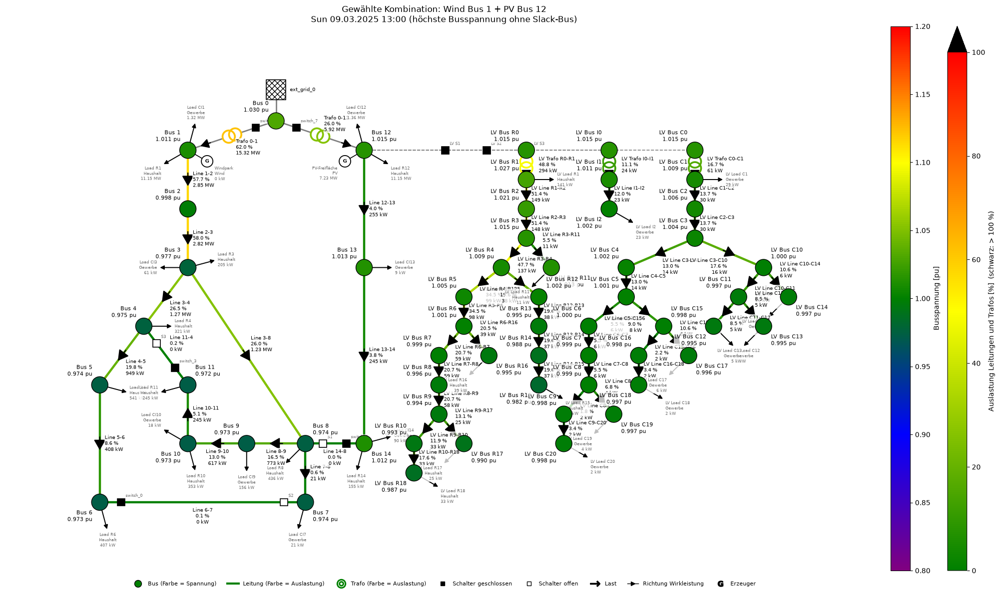

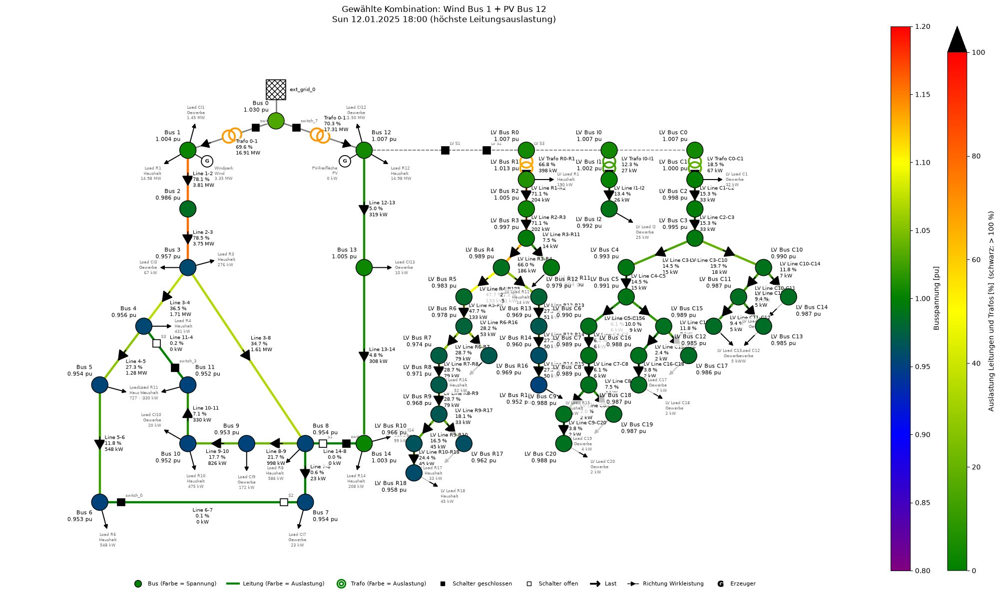

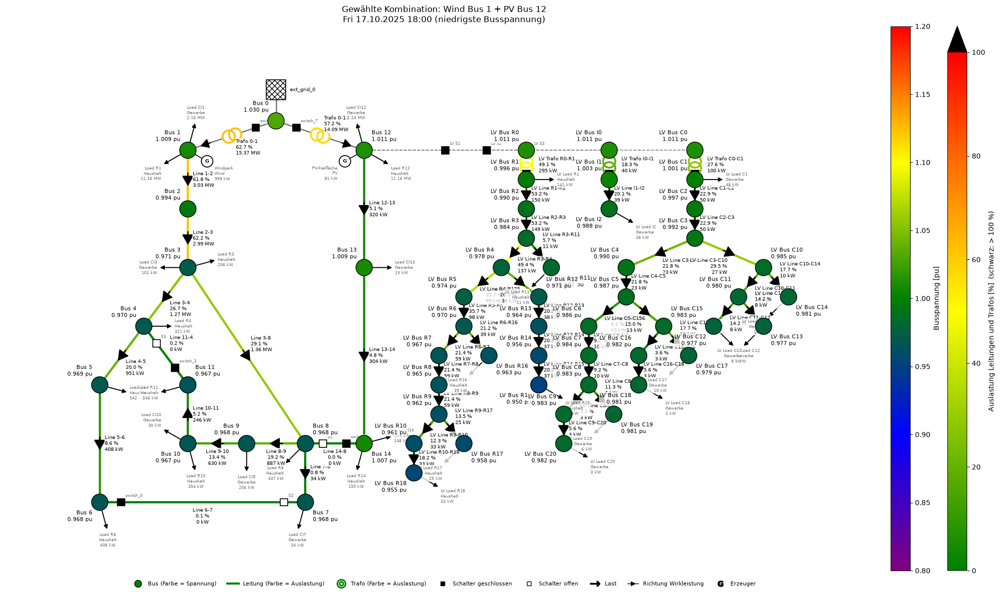

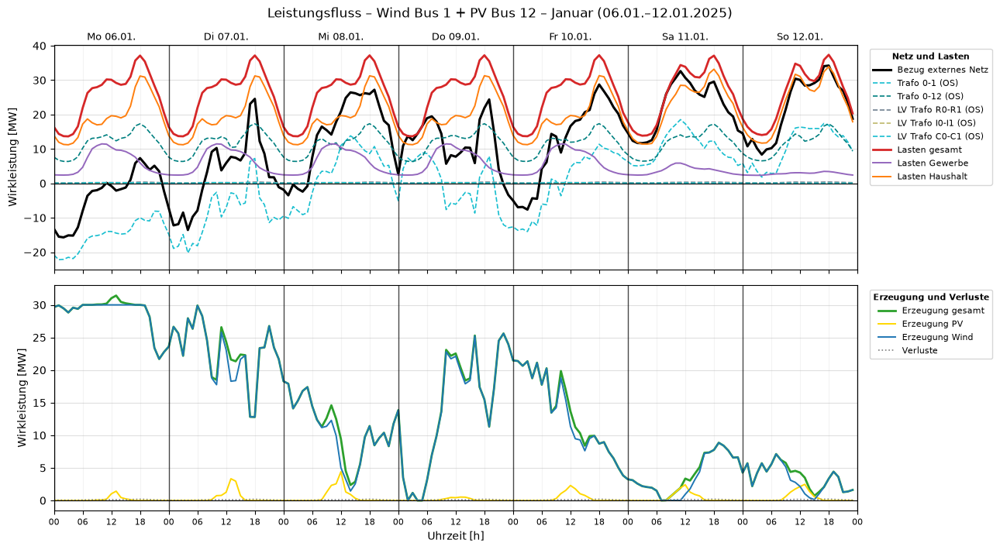

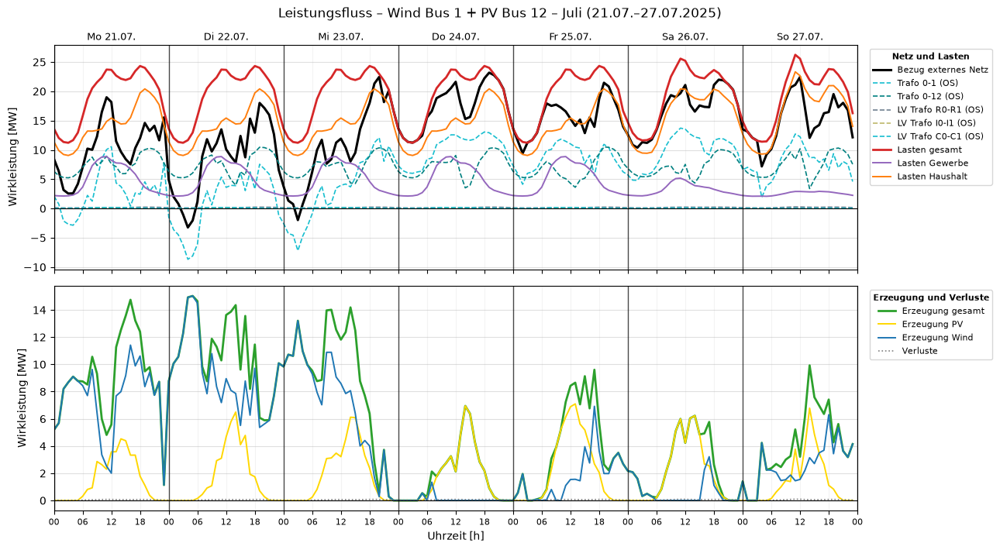

In [141]:
best = kombi[k_best]
best.createDiagram(Diagram.NETWORK, time=["max", "max_loading", "min"], title=f"Gewählte Kombination: {k_best}")
best.createDiagram(Diagram.POWER_FLOW, months=[Month.JANUARY, Month.JULY], title=f"Leistungsfluss – {k_best}")

**Entscheidung:** **Windpark an Bus 1, PV-Anlage an Bus 12** (Rangsumme 11; Wind Bus 12 + PV Bus 1: 12; die beiden Kombinationen mit beiden Anlagen am selben Bus: je 13).

Den Ausschlag geben jetzt zwei Unterschiede, die deutlich über den Relevanzschwellen liegen:

1. **(n-1): Erzeugung an einem Trafo.** Werden Windpark und PV-Anlage auf beide Trafos verteilt, gehen bei einem Trafoausfall höchstens 30 MW statt 40 MW verloren. Damit scheiden die Kombinationen mit beiden Anlagen am selben Bus aus der Spitzengruppe aus. Bisher hatten zwischen „PV an Bus 1“ und „PV an Bus 12“ nur die Verluste (0,9 %) entschieden.
2. **Normalbetrieb: Trafoauslastung.** Mit dem Windpark an Bus 1 ist der höchstbelastete 110/20-kV-Trafo um 3,8 Prozentpunkte weniger ausgelastet als mit dem Windpark an Bus 12.

Alle übrigen Unterschiede liegen unter den Relevanzschwellen und gelten als gleichwertig. Die Verluste werden nicht mehr gebraucht. Das Ergebnis ist dasselbe wie mit der bisherigen Rangfolge, aber jetzt mit einer belastbaren Begründung.

Zu beachten: Bei den Stunden unter dem Planungsband im (n-1)-Fall liegt Wind Bus 12 + PV Bus 1 mit 237 Stunden etwas besser als die gewählte Kombination mit 249 Stunden. Der Unterschied liegt mit 5 % unter der Relevanzschwelle von 10 %. Die Arbeitsgrenzen werden in beiden Fällen nie verletzt.

## 5 (n-1)-Auswertung der gewählten Kombination

Ausführliche Prüfung der in 4.3 gewählten Kombination: Gilt der Wiederversorgungsplan aus Teil 3b auch mit Windpark und PV-Anlage, was passiert beim Ausfall eines 110/20-kV-Trafos, und wie verhält sich das Netz über 12 Wochen, wenn eine Leitung ausgefallen ist?

### 5.1 Betriebspunkte

In [142]:
WIEDERVERSORGUNG_3B = {"Line 1-2": ["S1"], "Line 2-3": ["S1"], "Line 3-4": ["S2"], "Line 4-5": ["S2"], "Line 5-6": ["S2"],
                       "Line 7-8": ["S2"], "Line 8-9": ["S3"], "Line 9-10": ["S3"], "Line 10-11": ["S3"], "Line 3-8": ["S2"],
                       "Line 12-13": ["S1"], "Line 13-14": ["S1"]}      # Ergebnis von Teil 3b, Abschnitt 6.3

print("Gewählte Kombination:", k_best)
r = best.results
punkte = rg.kritische_stunden(best)
pd.DataFrame({bp: {"Zeitpunkt": f"{h:%d.%m. %H:%M}", "Windpark [MW]": r.sgen_p_mw.at[h, "Windpark"],
                   "PV-Anlage [MW]": r.sgen_p_mw.at[h, "PV-Freifläche"], "Last [MW]": r.load_p_mw.loc[h].sum(),
                   "Austausch 110 kV [MW] (− = Rückspeisung)": r.ext_grid_p_mw.squeeze()[h]}
              for bp, h in punkte.items()}).T

Gewählte Kombination: Wind Bus 1 + PV Bus 12


,Zeitpunkt,Windpark [MW],PV-Anlage [MW],Last [MW],Austausch 110 kV [MW] (− = Rückspeisung)
Jahreshöchstlast,05.02. 18:00,0.921,0.0,36.588826,35.872586
max. Rückspeisung,19.12. 02:00,29.487,0.0,13.331587,-16.099811
max. Erzeugung,08.02. 12:00,29.931,6.024,32.662988,-3.149533


### 5.2 Leitungsausfälle

Übersicht je Betriebspunkt (✔ = zulässig; sonst Zahl der nicht versorgten Busse bzw. Grund):

In [143]:
status = aw.ausfall_status

leitungen = [a for a in AUSFAELLE if a.startswith("Line")]
for bp in punkte:
    an = n1_statisch[(k_best, bp)]
    print(bp)
    display(an.assign(Status=an.apply(status, axis=1)).pivot(index="Ausfall", columns="Maßnahme", values="Status")
              .loc[leitungen, list(dict.fromkeys(an["Maßnahme"]))])

Jahreshöchstlast


Maßnahme,keine,S2 schließen,S3 schließen,S1 schließen,S2 schließen + S3 schließen,S2 schließen + S1 schließen,S3 schließen + S1 schließen,S2 schließen + S3 schließen + S1 schließen
Ausfall,,,,,,,,
Line 1-2,10 Busse unversorgt,10 Busse unversorgt,10 Busse unversorgt,✔,10 Busse unversorgt,✔,✔,✔
Line 2-3,9 Busse unversorgt,9 Busse unversorgt,9 Busse unversorgt,✔,9 Busse unversorgt,✔,✔,✔
Line 3-4,3 Busse unversorgt,✔,✔,3 Busse unversorgt,✔,✔,✔,✔
Line 4-5,2 Busse unversorgt,✔,2 Busse unversorgt,2 Busse unversorgt,✔,✔,2 Busse unversorgt,✔
Line 5-6,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 7-8,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 8-9,3 Busse unversorgt,3 Busse unversorgt,✔,3 Busse unversorgt,✔,3 Busse unversorgt,✔,✔
Line 9-10,2 Busse unversorgt,2 Busse unversorgt,✔,2 Busse unversorgt,✔,2 Busse unversorgt,✔,✔
Line 10-11,1 Bus unversorgt,1 Bus unversorgt,✔,1 Bus unversorgt,✔,1 Bus unversorgt,✔,✔


max. Rückspeisung


Maßnahme,keine,S2 schließen,S3 schließen,S1 schließen,S2 schließen + S3 schließen,S2 schließen + S1 schließen,S3 schließen + S1 schließen,S2 schließen + S3 schließen + S1 schließen
Ausfall,,,,,,,,
Line 1-2,10 Busse unversorgt,10 Busse unversorgt,10 Busse unversorgt,✔,10 Busse unversorgt,✔,✔,✔
Line 2-3,9 Busse unversorgt,9 Busse unversorgt,9 Busse unversorgt,✔,9 Busse unversorgt,✔,✔,✔
Line 3-4,3 Busse unversorgt,✔,✔,3 Busse unversorgt,✔,✔,✔,✔
Line 4-5,2 Busse unversorgt,✔,2 Busse unversorgt,2 Busse unversorgt,✔,✔,2 Busse unversorgt,✔
Line 5-6,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 7-8,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 8-9,3 Busse unversorgt,3 Busse unversorgt,✔,3 Busse unversorgt,✔,3 Busse unversorgt,✔,✔
Line 9-10,2 Busse unversorgt,2 Busse unversorgt,✔,2 Busse unversorgt,✔,2 Busse unversorgt,✔,✔
Line 10-11,1 Bus unversorgt,1 Bus unversorgt,✔,1 Bus unversorgt,✔,1 Bus unversorgt,✔,✔


max. Erzeugung


Maßnahme,keine,S2 schließen,S3 schließen,S1 schließen,S2 schließen + S3 schließen,S2 schließen + S1 schließen,S3 schließen + S1 schließen,S2 schließen + S3 schließen + S1 schließen
Ausfall,,,,,,,,
Line 1-2,10 Busse unversorgt,10 Busse unversorgt,10 Busse unversorgt,✔,10 Busse unversorgt,✔,✔,✔
Line 2-3,9 Busse unversorgt,9 Busse unversorgt,9 Busse unversorgt,✔,9 Busse unversorgt,✔,✔,✔
Line 3-4,3 Busse unversorgt,✔,✔,3 Busse unversorgt,✔,✔,✔,✔
Line 4-5,2 Busse unversorgt,✔,2 Busse unversorgt,2 Busse unversorgt,✔,✔,2 Busse unversorgt,✔
Line 5-6,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 7-8,1 Bus unversorgt,✔,1 Bus unversorgt,1 Bus unversorgt,✔,✔,1 Bus unversorgt,✔
Line 8-9,3 Busse unversorgt,3 Busse unversorgt,✔,3 Busse unversorgt,✔,3 Busse unversorgt,✔,✔
Line 9-10,2 Busse unversorgt,2 Busse unversorgt,✔,2 Busse unversorgt,✔,2 Busse unversorgt,✔,✔
Line 10-11,1 Bus unversorgt,1 Bus unversorgt,✔,1 Bus unversorgt,✔,1 Bus unversorgt,✔,✔


Wiederversorgungsplan je Betriebspunkt im Vergleich mit dem Plan aus Teil 3b (ohne Erzeuger):

In [144]:
plaene = {bp: rg.wiederversorgungsplan(n1_statisch[(k_best, bp)]) for bp in punkte}
vergleich_plan = pd.DataFrame({bp: p.loc[leitungen, "Maßnahme"] for bp, p in plaene.items()})
vergleich_plan["Teil 3b"] = [" + ".join(f"{x} schließen" for x in WIEDERVERSORGUNG_3B[a]) for a in leitungen]
vergleich_plan["gleich"] = vergleich_plan.nunique(axis=1).eq(1).map({True: "✔", False: "✘"})
display(vergleich_plan)

zustand = pd.concat({bp: p.loc[leitungen, ["U min MS [pu]", "U max MS [pu]", "Leitung max MS [%]", "am stärksten belastet",
                                           "Trafo max HS/MS [%]"]] for bp, p in plaene.items()}, axis=1)
plots.table(zustand, decimals=3)

,Jahreshöchstlast,max. Rückspeisung,max. Erzeugung,Teil 3b,gleich
Ausfall,,,,,
Line 1-2,S1 schließen,S1 schließen,S1 schließen,S1 schließen,✔
Line 2-3,S1 schließen,S1 schließen,S1 schließen,S1 schließen,✔
Line 3-4,S2 schließen,S2 schließen,S2 schließen,S2 schließen,✔
Line 4-5,S2 schließen,S2 schließen,S2 schließen,S2 schließen,✔
Line 5-6,S2 schließen,S2 schließen,S2 schließen,S2 schließen,✔
Line 7-8,S2 schließen,S2 schließen,S2 schließen,S2 schließen,✔
Line 8-9,S3 schließen,S3 schließen,S3 schließen,S3 schließen,✔
Line 9-10,S3 schließen,S3 schließen,S3 schließen,S3 schließen,✔
Line 10-11,S3 schließen,S3 schließen,S3 schließen,S3 schließen,✔


**Ergebnis Leitungsausfälle:**

- Der Wiederversorgungsplan aus Teil 3b gilt **unverändert** auch mit Windpark und PV-Anlage: In allen drei Betriebspunkten wird für jede Leitung dieselbe Trennstelle gewählt (S2 für Line 3-4 bis 7-8 und 3-8, S3 für Line 8-9 bis 10-11, S1 für Line 1-2, 2-3, 12-13 und 13-14).
- **Jahreshöchstlast:** Der Windpark speist fast nichts ein (0,9 MW). Der Zustand entspricht deshalb dem Netz ohne Erzeuger: niedrigste MS-Spannung 0,928 pu (Ausfall Line 2-3), höchste Trafoauslastung 85,7 %.
- **Max. Rückspeisung** (29,5 MW Wind, 13,3 MW Last): Die Spannungen liegen hoch (bis 1,023 pu), aber im Band. Die höchste Trafoauslastung tritt beim Ausfall von Line 1-2 oder 2-3 auf (93,0 %): Trafo 0-1 versorgt dann nur noch Bus 1 (und Bus 2), und fast die ganze Windleistung fließt über ihn ins 110-kV-Netz zurück.
- **Max. Erzeugung** (29,9 MW Wind + 6,0 MW PV, 32,7 MW Last): Dieser Betriebspunkt ist unkritisch, weil Erzeugung und Last sich fast ausgleichen.

### 5.3 Ausfall eines 110/20-kV-Transformators

In [145]:
trafo_faelle = pd.concat([n1_statisch[(k_best, bp)].assign(Betriebspunkt=bp) for bp in punkte])
trafo_faelle = trafo_faelle[trafo_faelle.Ausfall.str.startswith("Trafo") & trafo_faelle["Maßnahme"].isin(["keine", "S1 schließen"])]
plots.table(trafo_faelle.set_index(["Betriebspunkt", "Ausfall", "Maßnahme"])[
    ["nicht versorgte Busse", "getrennte Erzeugung [MW]", "U min MS [pu]", "U max MS [pu]", "Leitung max MS [%]",
     "am stärksten belastet", "Trafo max HS/MS [%]", "Bemerkung"]], decimals=2)

**Vergleich mit einer Längskupplung im Umspannwerk (hypothetisch):** Wie in Teil 3b, Abschnitt 6.4, wird geprüft, in wie vielen Stunden ein einzelner Trafo (25 MVA) den Leistungsaustausch mit dem 110-kV-Netz allein tragen könnte, wenn die beiden 20-kV-Sammelschienen direkt gekuppelt wären. Mit Erzeugern ändert sich der Austausch: Tagsüber und bei Wind sinkt der Bezug, bei starkem Wind fließt Leistung zurück.

In [146]:
def stunden_ein_trafo(s, sn=25.0):
    rr = s.results
    S = np.hypot(rr.ext_grid_p_mw.squeeze(), rr.ext_grid_q_mvar.squeeze())
    return {"max. Scheinleistung 110 kV [MVA]": S.max(), "Stunden ≤ 25 MVA": int((S <= sn).sum()),
            "Anteil": f"{(S <= sn).mean():.0%}", "Stunden > 25 MVA bei Bezug": int(((S > sn) & (rr.ext_grid_p_mw.squeeze() > 0)).sum()),
            "Stunden > 25 MVA bei Rückspeisung": int(((S > sn) & (rr.ext_grid_p_mw.squeeze() < 0)).sum())}

pd.DataFrame({"ohne Erzeuger (Teil 3b)": stunden_ein_trafo(normal), k_best: stunden_ein_trafo(best)}).T

,max. Scheinleistung 110 kV [MVA],Stunden ≤ 25 MVA,Anteil,Stunden > 25 MVA bei Bezug,Stunden > 25 MVA bei Rückspeisung
ohne Erzeuger (Teil 3b),39.405322,1181,59%,835,0
Wind Bus 1 + PV Bus 12,37.758213,1818,90%,198,0


**Ergebnis Trafoausfall:**

- **Ohne Maßnahme** ist der Abgang des ausgefallenen Trafos ohne Versorgung, und die Erzeugung an seiner Sammelschiene wird vom Netz getrennt: beim Ausfall von Trafo 0-1 der Windpark (bis 29,9 MW), beim Ausfall von Trafo 0-12 die PV-Anlage (bis 6,0 MW in den untersuchten Stunden, installiert 10 MWp).
- **Mit S1** ist eine Wiederversorgung in keinem Betriebspunkt zulässig. Bei Jahreshöchstlast konvergiert der Lastfluss nicht (wie in Teil 3b). Bei Rückspeisung ist es noch ungünstiger: Fällt Trafo 0-1 aus und S1 wird geschlossen, muss die Windleistung von Bus 1 durch den ganzen Abgang 1, über S1 und Abgang 2 zu Trafo 0-12 fließen. Die Leitungen wären dann mit bis zu 378 % ausgelastet, und die Spannung stiege auf 1,25 pu. S1 darf in diesem Fall nicht geschlossen werden, solange der Windpark einspeist.
- **Längskupplung im Umspannwerk (hypothetisch):** Mit den Erzeugern könnte ein einzelner Trafo den Austausch mit dem 110-kV-Netz in 90 % der Stunden allein tragen (ohne Erzeuger nur in 59 %), weil Wind und PV einen Teil der Last vor Ort decken. Die höchste Rückspeisung (16,1 MW) liegt unter der Bemessungsleistung eines Trafos. Kritisch bleiben 198 Stunden mit hohem Bezug bei wenig Erzeugung (Winterabende).
- **Folgerung:** Der Ausfall eines 110/20-kV-Trafos ist weiterhin nicht (n-1)-sicher. Der Backup-Plan muss für diesen Fall ergänzt werden: Bei einem Trafoausfall wird der Windpark bzw. die PV-Anlage an der betroffenen Sammelschiene abgeschaltet, **bevor** S1 geschlossen werden darf. Eine dauerhafte Lösung wäre eine Längskupplung im Umspannwerk; die Erzeuger verbessern dann sogar die Reserve.

### 5.4 Zeitreihen mit ausgefallener Leitung

Für die Leitungen, deren Ausfall die meisten Busse betrifft oder einen Abgang über S1 umschaltet, wird die gewählte Kombination über 12 Wochen gerechnet: Die Leitung ist die ganze Zeit außer Betrieb, die Wiederversorgung schließt die Trennstelle nach dem Plan, rONT-Regler und Spannungsstützung arbeiten wie gewohnt.

In [147]:
N1_DETAIL = ["Line 1-2", "Line 2-3", "Line 3-4", "Line 3-8", "Line 8-9", "Line 12-13", "Line 13-14"]
kurz = best.name.replace("w4_kombi_", "")
detail = {"ohne Ausfall": best}
for leitung in N1_DETAIL:
    if (k_best, leitung) in n1_zeitreihe:
        detail[leitung] = n1_zeitreihe[(k_best, leitung)]
        continue
    z = best.copy(f"w4_n1_{kurz}_L{leitung.split()[1].replace('-', '_')}", overwrite=True)
    z.changeParameter(leitung, "in_service", False)
    z.runSimulation(controllers=rg.standard_regler(z.net, wiederversorgung={leitung: WIEDERVERSORGUNG_3B[leitung]}), verbose=False)
    detail[leitung] = z
d_werte, d_orte = bw.kennwerte(detail)
d_werte["Stunden außerhalb der Arbeitsgrenzen"] = d_werte[GRENZEN].sum(axis=1)
for sw in ("S1", "S2", "S3"):
    d_werte[f"Schaltungen {sw}"] = [rg.schaltvorgaenge(s).get(f"Schaltungen {sw}", 0) for s in detail.values()]
d_werte["Stufenschritte rONT gesamt"] = [int(rg.schaltvorgaenge(s).filter(like="Stufen").sum()) for s in detail.values()]
plots.table(d_werte[zcols + ["Stunden Rückspeisung 110 kV", "max. Rückspeisung 110 kV [MW]", "Schaltungen S1", "Schaltungen S2",
                     "Schaltungen S3", "Stufenschritte rONT gesamt"]].astype(float).T, decimals=3)

Hinweis: 9 Busse sind nicht versorgt (z. B. ['Bus 3', 'Bus 4', 'Bus 5', 'Bus 6', 'Bus 7']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 3 Busse sind nicht versorgt (z. B. ['Bus 4', 'Bus 5', 'Bus 6']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 5 Busse sind nicht versorgt (z. B. ['Bus 7', 'Bus 8', 'Bus 9', 'Bus 10', 'Bus 11']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 3 Busse sind nicht versorgt (z. B. ['Bus 9', 'Bus 10', 'Bus 11']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Hinweis: 1 Bus ist nicht versorgt (z. B. ['Bus 14']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.


,ohne Ausfall,Line 1-2,Line 2-3,Line 3-4,Line 3-8,Line 8-9,Line 12-13,Line 13-14
Stunden außerhalb der Arbeitsgrenzen,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"Stunden U < 0,95 MS",0.000,202.000,238.000,77.000,105.000,0.000,47.000,40.000
U min MS [pu],0.951,0.933,0.932,0.940,0.936,0.951,0.942,0.942
U max MS [pu],1.025,1.025,1.026,1.025,1.025,1.025,1.025,1.025
Leitung max MS [%],78.491,65.083,65.468,79.147,78.782,78.509,86.929,86.492
Trafo max HS/MS [%],88.512,93.759,93.722,88.513,88.520,88.517,87.928,87.960
Verluste [MWh],151.602,225.771,228.721,166.621,172.199,151.390,181.535,179.602
Stunden Rückspeisung 110 kV,263.000,262.000,262.000,263.000,263.000,263.000,263.000,263.000
max. Rückspeisung 110 kV [MW],16.100,16.085,16.084,16.097,16.097,16.100,16.096,16.096
Schaltungen S1,0.000,1.000,1.000,0.000,0.000,0.000,1.000,1.000


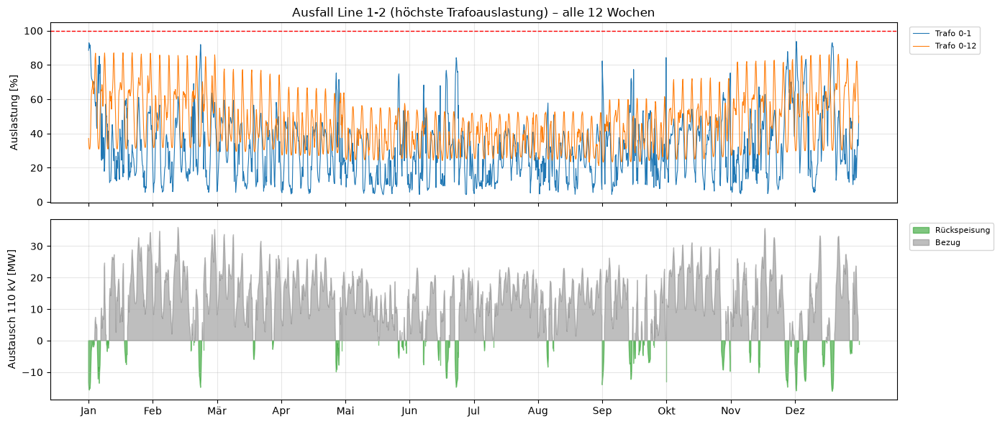

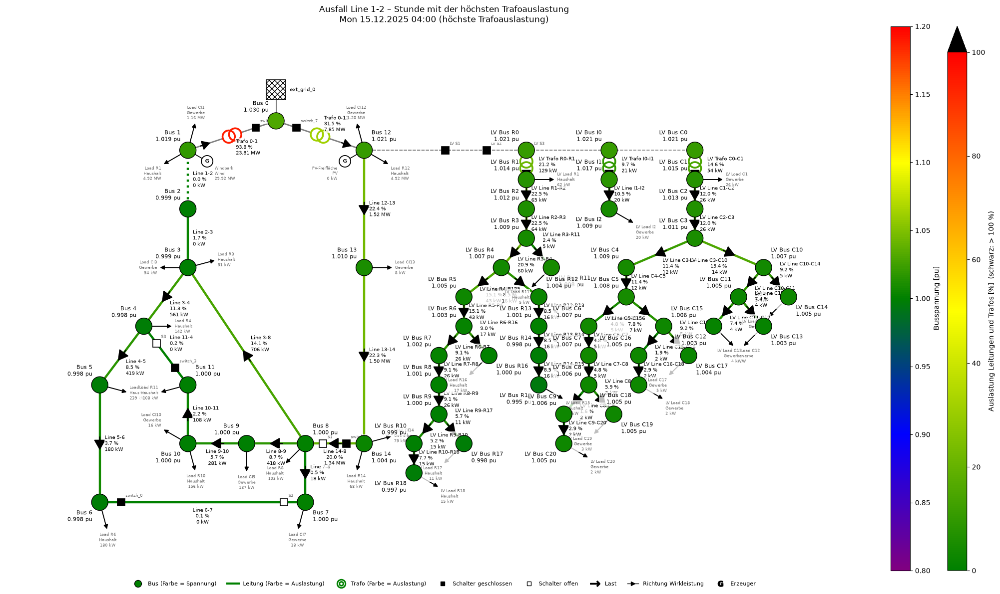

In [148]:
schlimmster = d_werte.drop(index="ohne Ausfall")["Trafo max HS/MS [%]"].astype(float).idxmax()
s = detail[schlimmster]
tl = s.results.trafo_loading[["Trafo 0-1", "Trafo 0-12"]]
p_ex = s.results.ext_grid_p_mw.squeeze()
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
x = np.arange(len(tl))
for c, farbe in zip(tl.columns, ("tab:blue", "tab:orange")):
    axes[0].plot(x, tl[c], color=farbe, lw=0.8, label=c)
axes[0].axhline(100, color="red", ls="--", lw=1)
axes[0].set_ylabel("Auslastung [%]")
axes[0].set_title(f"Ausfall {schlimmster} (höchste Trafoauslastung) – alle 12 Wochen")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[1].fill_between(x, p_ex, 0, where=p_ex < 0, color="tab:green", alpha=0.6, label="Rückspeisung")
axes[1].fill_between(x, p_ex, 0, where=p_ex >= 0, color="tab:gray", alpha=0.5, label="Bezug")
axes[1].set_ylabel("Austausch 110 kV [MW]")
monate = s.results.info["month"].to_numpy()
starts = [i for i in range(len(monate)) if i == 0 or monate[i] != monate[i - 1]]
axes[1].set_xticks(starts, [Month[m].label[:3] for m in monate[starts]])
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
s.createDiagram(Diagram.NETWORK, time=["max_trafo"], title=f"Ausfall {schlimmster} – Stunde mit der höchsten Trafoauslastung")

**Ergebnis Zeitreihen mit ausgefallener Leitung:**

- In **keiner** der sieben Zeitreihen wird eine Arbeitsgrenze verletzt; das Ortsnetz bleibt durch die rONT-Regelung immer im Planungsband. Die gewählte Kombination ist für Leitungsausfälle über das ganze Jahr (n-1)-sicher, nicht nur in den drei geprüften Stunden.
- **Ausfälle mit S1 (Line 1-2, 2-3):** Abgang 1 wird über den langen Weg aus Trafo 0-12 versorgt. Die MS-Spannung liegt in 202 bzw. 238 Stunden unter dem Planungsband (niedrigster Wert 0,932 pu), die Spannungsstützung schließt S2 und S3 zeitweise (66 bzw. 74 Schaltungen). Die Verluste steigen um rund 50 %. Die höchste Trafoauslastung (93,8 %) tritt bei **Rückspeisung** auf: Trafo 0-1 führt dann fast nur noch die Windleistung zurück ins 110-kV-Netz (Abbildung).
- **Ausfälle in Abgang 2 (Line 12-13, 13-14):** Bus 13 und 14 werden über S1 aus Abgang 1 versorgt; die höchste Leitungsauslastung steigt auf 86,9 %, die Spannung bleibt in höchstens 47 Stunden knapp unter 0,95 pu.
- **Ausfälle mit S2 oder S3:** Diese Ausfälle sind unkritisch (höchstens 105 Stunden unter dem Planungsband bei Line 3-8, gleiche Trafoauslastung wie ohne Ausfall).
- **Rückspeisung:** Die Zahl der Stunden mit Rückspeisung (262 bis 263) und die höchste Rückspeisung (16,1 MW) ändern sich durch die Ausfälle nicht, weil beide Anlagen direkt an den Sammelschienen einspeisen.

## 6 Ergebnis

- **Anschluss:** Windpark (30 MW) und PV-Freiflächenanlage (10 MWp) lassen sich im CIGRE-MV-Netz nur an den Sammelschienen der 110/20-kV-Transformatoren anschließen (Bus 1 oder Bus 12). In den Abgängen überlasten sie die Leitungen, die nur für etwa 5 MVA ausgelegt sind. In der Praxis werden Anlagen dieser Größe ebenfalls über ein eigenes Kabel direkt an die Sammelschiene des Umspannwerks angeschlossen.
- **Entscheidung:** Windpark an **Bus 1**, PV-Anlage an **Bus 12**. Die Entscheidung beruht jetzt auf zwei deutlichen Unterschieden statt auf Hundertsteln: Bei einem Trafoausfall gehen höchstens 30 statt 40 MW Erzeugung verloren (n-1), und Trafo 0-1 ist im Normalbetrieb um 3,8 Prozentpunkte weniger ausgelastet. Unterschiede unter den Relevanzschwellen (0,005 pu, 1 Prozentpunkt, 10 % der Stunden, 1 MW) gelten als gleichwertig.
- **(n-1):** Für Leitungsausfälle ist das Netz mit der gewählten Kombination über das ganze Jahr (n-1)-sicher; der Wiederversorgungsplan aus Teil 3b gilt unverändert. Der Ausfall eines 110/20-kV-Trafos ist nicht (n-1)-sicher. Bei Rückspeisung darf S1 nach einem Trafoausfall erst geschlossen werden, wenn die Erzeugung an der betroffenen Sammelschiene abgeschaltet ist.
- **Nächster Schritt:** Mit diesen Anschlussbussen untersucht Teil 4b die drei Szenarien einzeln und kombiniert in allen Schalterstellungen, mit hohen und niedrigen Einspeise- und Lastsituationen und dem Blindleistungsverhalten.

<a id="teil-6"></a>

---

# Task 4 – Teil 4b: Erneuerbare-Energien-Szenarien einzeln und kombiniert

### Aufgabenstellung (Abschnitt 4 des Arbeitsauftrags)

> *Betrachten Sie im folgenden immer die möglichen Schalterstellungen der Schalter S1-S3. Untersuchen Sie mindestens die folgenden Szenarien einzeln und in sinnvollen Kombinationen: 1. Windpark an der Mittelspannung […] 2. Ortsnetz mit fluktuierender Einspeisung und Nutzung: Bilden Sie im neu aufgebauten Ortsnetz zeitlich veränderliche Last und dezentrale Einspeisung ab […]. Dokumentieren Sie Zeitauflösung, Profilherkunft oder transparente synthetische Erzeugung, Skalierung und Vorzeichenkonvention. 3. Großflächen-PV […]*
>
> *Wählen Sie für jedes Szenario plausible hohe und niedrige Einspeise- und Lastsituationen. Vergleichen Sie die Resultate mit der Baseline und halten Sie fest, ob und warum sich die Ergebnisse durch Anschlussort, Dimensionierung, Blindleistungsverhalten oder gleichzeitigen Betrieb unterscheiden.*

| Anforderung | wo |
|---|---|
| Windpark und Großflächen-PV: Anschlussort, Leistung, Profil, Leistungsfaktor | Teil 4a (Anschluss), Datengrundlage 1.2, 1.3, 1.5 |
| Ortsnetz mit Last und dezentraler Einspeisung, Profile, Skalierung, Vorzeichen | Abschnitt 2, Datengrundlage 1.6 |
| Szenarien einzeln und kombiniert, alle Schalterstellungen, Vergleich mit der Baseline | Abschnitt 3 |
| hohe und niedrige Einspeise- und Lastsituationen | Abschnitt 4 |
| Blindleistungsverhalten | Abschnitt 5 |
| Anschlussort, Dimensionierung, Blindleistung, gleichzeitiger Betrieb | Abschnitt 6 |

### Szenarien

| Kurzname | Inhalt | Herkunft |
|---|---|---|
| Baseline | ausgelegtes Netz mit Ortsnetz an Bus 12 und rONT-Regelung, ohne Erzeuger | Teil 3, 3b |
| Wind | Windpark 15 × V90-2.0 MW = 30 MW an Bus 1 | Teil 4a |
| PV | PV-Freiflächenanlage 10 MWp an Bus 12 | Teil 4a |
| Ortsnetz | Haushalte mit PV und Speicher im Wohngebiet, Variante „heute“ | Abschnitt 2 |
| Wind + PV | gewählte Kombination aus Teil 4a | Teil 4a |
| Wind + PV + Ortsnetz | alle drei Szenarien gleichzeitig = Netz am Ende von Teil 4 (Grundlage für Teil 5) | Abschnitt 2 |

In jedem Vergleich bleiben Netz, Lasten, Profile, Wetter (12 typische Wochen, stündlich) und Regelung (drei rONT-Regler) gleich; verändert wird nur, welche Erzeuger angeschlossen sind und wie die Schalter S1–S3 stehen. Der Backup-Plan aus Teil 3b läuft nicht mit, weil er beim Start die Trennschalter öffnet und damit die vorgegebenen Schalterstellungen überschreiben würde.

Voraussetzung: `Task4-4a_Erzeugung_Anschluss.ipynb` wurde ausgeführt.

## Importe

In [149]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import regelung as rg
import bewertung as bw
import plots
import auswertung as aw
from auswertung import PLAN_MARKER, V_MIN, V_MAX, V_PLAN_MIN, V_PLAN_MAX
from elements import Diagram, Generator, Profile
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

sim.ONLY_RUN_IF_CHANGED = True

ausgelegt = sim.loadSimulation("w4_t3_ausgelegt")        # Teil 3: ausgelegtes Netz mit Ortsnetz an Bus 12
kombi = sim.loadSimulation(aw.KOMBI)                      # Teil 4a: Wind an Bus 1 + PV an Bus 12
LABEL = {k: sz.label(k, kurz=True) for k in sz.KEYS}

## 2 Szenario Ortsnetz: Haushalte mit PV-Anlage und Speicher

**Modell:** Alle Haushalte behalten ihren Verbrauch mit dem BDEW-Profil H25 [1], [2]. Zusätzlich erhalten die Haushalte mit PV an jedem Haushaltsbus des Wohngebiets einen Erzeuger mit dem PV-Profil aus der Datengrundlage (Abschnitt 1.3, 1.4), die Haushalte mit Speicher zusätzlich einen Batteriespeicher mit Eigenverbrauchsregelung (Datengrundlage 1.6). Die Zahl der Haushalte ergibt sich aus dem Jahresverbrauch der Last und 3000 kWh je Haushalt [32].

| Größe | Festlegung |
|---|---|
| Zeitauflösung | 1 h, 12 typische Wochen (wie alle Zeitreihen) |
| Verbrauch | H25 (dynamisiert), skaliert über die Jahreshöchstleistung der CIGRE-Last [13] |
| PV-Einspeisung | Wetterdaten Open-Meteo [4], [6], Modul Trina Vertex S+ [11], 9 kWp je Haushalt mit PV [34], [37] |
| Speicher | 8,3 kWh und 4,9 kW je Haushalt mit Speicher [33], [34], Wirkungsgrad 0,95 je Richtung [35] |
| Anteile | heute: 15 % der Haushalte mit PV, davon 6,7 % aller Haushalte mit Speicher [23]; Zukunft: 50 % mit PV, 40 % mit Speicher [24] |
| Vorzeichen (pandapower [17]) | Last > 0: Bezug; Erzeuger > 0: Einspeisung; Speicher > 0: Laden, < 0: Entladen; Ortsnetztrafo `p_hv_mw` < 0: Rückspeisung ins MS-Netz |
| Leistungsfaktor | Haushaltslast cos φ = 0,97, PV cos φ = 1 [30] |

In [150]:
ortsnetz, aufteilung = {}, {}
for variante in aw.PV_HAUSHALTE:
    s, aufteilung[variante] = aw.mit_pv_haushalten(ausgelegt, f"w4_t4b_ortsnetz_{variante}", variante)
    s.runSimulation(controllers=aw.lv_regler(s.net))
    ortsnetz[variante] = s
    print(f"Variante {variante}:")
    display(plots.table(aufteilung[variante], decimals=2))

Simulation 'w4_t4b_ortsnetz_heute': unverändert seit dem Lauf vom 2026-11-08T22:13:31 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Variante heute:


,Bus,Jahresverbrauch [MWh],Haushalte,davon nur PV,davon PV + Speicher,PV [kWp],Speicher [kWh],Speicherleistung [kW]
Last,,,,,,,,
LV Load R1,LV Bus R1,838.34,279.45,23.19,18.72,377.25,155.40,91.69
LV Load R11,LV Bus R11,62.88,20.96,1.74,1.40,28.29,11.65,6.88
LV Load R15,LV Bus R15,217.97,72.66,6.03,4.87,98.09,40.40,23.84
LV Load R16,LV Bus R16,230.54,76.85,6.38,5.15,103.74,42.73,25.21
LV Load R17,LV Bus R17,146.71,48.90,4.06,3.28,66.02,27.19,16.04
LV Load R18,LV Bus R18,197.01,65.67,5.45,4.40,88.65,36.52,21.55
Summe,,1693.44,564.48,46.85,37.82,762.05,313.91,185.21


Simulation 'w4_t4b_ortsnetz_Zukunft': unverändert seit dem Lauf vom 2026-11-08T22:14:53 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Variante Zukunft:


,Bus,Jahresverbrauch [MWh],Haushalte,davon nur PV,davon PV + Speicher,PV [kWp],Speicher [kWh],Speicherleistung [kW]
Last,,,,,,,,
LV Load R1,LV Bus R1,838.34,279.45,27.94,111.78,1257.50,927.76,547.38
LV Load R11,LV Bus R11,62.88,20.96,2.10,8.38,94.31,69.58,41.05
LV Load R15,LV Bus R15,217.97,72.66,7.27,29.06,326.95,241.22,142.32
LV Load R16,LV Bus R16,230.54,76.85,7.68,30.74,345.81,255.13,150.53
LV Load R17,LV Bus R17,146.71,48.90,4.89,19.56,220.06,162.36,95.79
LV Load R18,LV Bus R18,197.01,65.67,6.57,26.27,295.51,218.02,128.63
Summe,,1693.44,564.48,56.45,225.79,2540.16,1874.07,1105.70


In [151]:
basis_t3 = ausgelegt.copy("w4_t4b_baseline", overwrite=True)        # Baseline mit derselben Regelung (nur rONT)
basis_t3.runSimulation(controllers=aw.lv_regler(basis_t3.net))
vergleich = {"Baseline": basis_t3, **{f"Ortsnetz {k}": s for k, s in ortsnetz.items()}}

def ortsnetz_kennwerte(s):
    r = s.results
    t = r.trafo_p_mw["LV Trafo R0-R1"]
    pv = r.sgen_p_mw[[c for c in r.sgen_p_mw if c.startswith("LV PV")]].sum(axis=1) if len(r.sgen_p_mw.columns) else 0 * t
    return {"PV-Erzeugung Wohngebiet [MWh]": float(pv.sum()),
            "Bezug Ortsnetztrafo R [MWh]": float(t.clip(lower=0).sum()),
            "Rückspeisung Ortsnetztrafo R [MWh]": float((-t).clip(lower=0).sum()),
            "Stunden Rückspeisung Trafo R": int((t < -0.001).sum()),
            "max. Rückspeisung Trafo R [MW]": float(max(0.0, -t.min())),
            "Auslastung Trafo R max [%]": float(r.trafo_loading["LV Trafo R0-R1"].max()),
            "U max NS [pu]": float(r.vm_pu[[c for c in r.vm_pu if c.startswith("LV Bus")]].max().max()),
            "U min NS [pu]": float(r.vm_pu[[c for c in r.vm_pu if c.startswith("LV Bus")]].min().min()),
            "Stufenschritte rONT R": int(rg.schaltvorgaenge(s).get("Stufenschritte LV Trafo R0-R1", 0)),
            "Stunden Stufe +1/+2 (senken) R": int((r.tap_pos["LV Trafo R0-R1"] > 0).sum()),
            "Stunden Stufe −1/−2 (anheben) R": int((r.tap_pos["LV Trafo R0-R1"] < 0).sum())}

plots.table(pd.DataFrame({k: ortsnetz_kennwerte(s) for k, s in vergleich.items()}), decimals=3)

Simulation 'w4_t4b_baseline': unverändert seit dem Lauf vom 2026-11-08T22:16:07 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


,Baseline,Ortsnetz heute,Ortsnetz Zukunft
PV-Erzeugung Wohngebiet [MWh],0.000,214.418,714.726
Bezug Ortsnetztrafo R [MWh],400.589,264.469,162.906
Rückspeisung Ortsnetztrafo R [MWh],0.000,75.834,424.953
Stunden Rückspeisung Trafo R,0.000,390.000,574.000
max. Rückspeisung Trafo R [MW],0.000,0.450,1.727
Auslastung Trafo R max [%],66.838,75.449,293.251
U max NS [pu],1.027,1.050,1.202
U min NS [pu],0.950,0.950,0.951
Stufenschritte rONT R,92.000,150.000,278.000
Stunden Stufe +1/+2 (senken) R,0.000,131.000,443.000


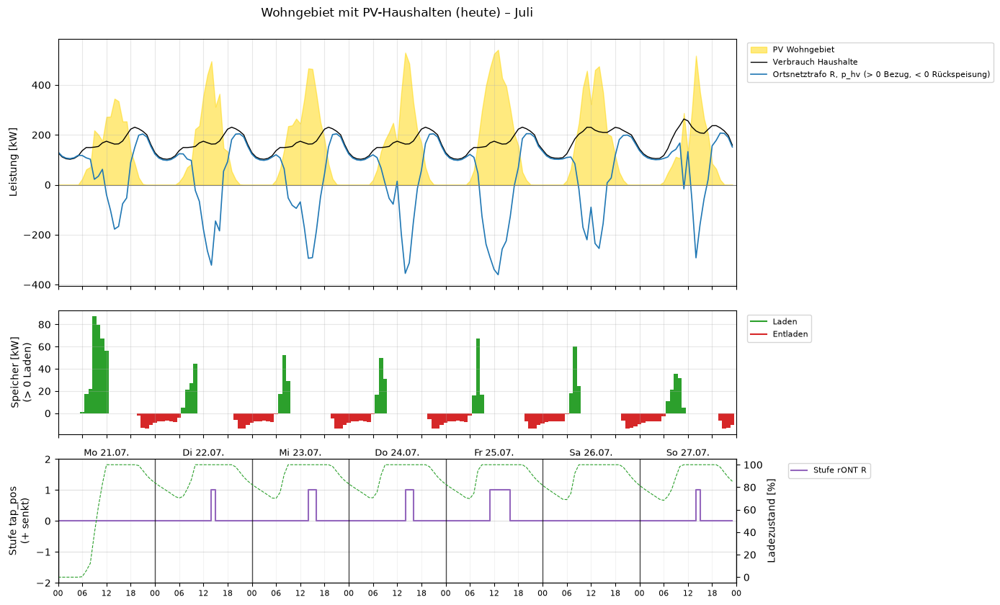

In [152]:
s = ortsnetz["heute"]
r = s.results
idx = r.info.index[r.info["month"] == "JULY"]
pv = r.sgen_p_mw.loc[idx, [c for c in r.sgen_p_mw if c.startswith("LV PV")]].sum(axis=1) * 1000
last = r.load_p_mw.loc[idx, [c for c in r.load_p_mw if c.startswith("LV Load R")]].sum(axis=1) * 1000
speicher = r.storage_p_mw.loc[idx].sum(axis=1) * 1000
trafo = r.trafo_p_mw.loc[idx, "LV Trafo R0-R1"] * 1000
soc = (r.storage_soc_percent.loc[idx] * s.net.storage.set_index("name")["max_e_mwh"]).sum(axis=1) / s.net.storage["max_e_mwh"].sum()
fig, axes = plt.subplots(3, 1, figsize=(14, 8.5), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
x = idx
axes[0].fill_between(x, pv, color="gold", alpha=0.5, label="PV Wohngebiet")
axes[0].plot(x, last, color="black", lw=1, label="Verbrauch Haushalte")
axes[0].plot(x, trafo, color="tab:blue", lw=1.2, label="Ortsnetztrafo R, p_hv (> 0 Bezug, < 0 Rückspeisung)")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Leistung [kW]")
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[0].set_title("Wohngebiet mit PV-Haushalten (heute) – Juli", pad=22)
axes[1].bar(x, speicher, color=np.where(speicher >= 0, "tab:green", "tab:red"), width=1 / 24)   # 1 Stunde (x-Achse in Tagen)
axes[1].set_ylabel("Speicher [kW]\n(> 0 Laden)")
axes[1].plot([], [], color="tab:green", label="Laden"); axes[1].plot([], [], color="tab:red", label="Entladen")
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[2].step(x, r.tap_pos.loc[idx, "LV Trafo R0-R1"], where="post", color="tab:purple", label="Stufe rONT R")
axes[2].set_ylabel("Stufe tap_pos\n(+ senkt)")
axes[2].set_yticks(range(-2, 3))
ax2 = axes[2].twinx()
ax2.plot(x, soc, color="tab:green", lw=0.8, ls="--", label="Ladezustand (Mittel)")
ax2.set_ylabel("Ladezustand [%]")
axes[2].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.07, 1))
for ax in axes:
    ax.grid(alpha=0.3)
plots.week_axis(axes[2], idx)
plt.tight_layout()
plt.show()

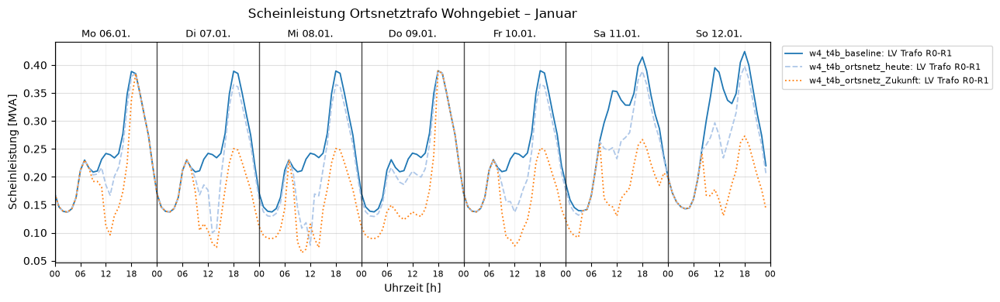

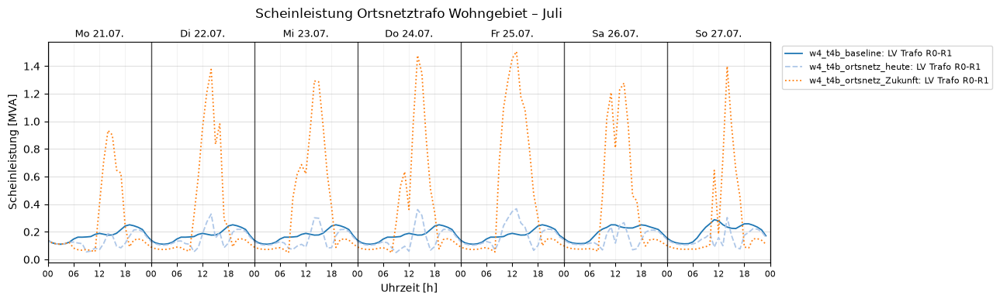

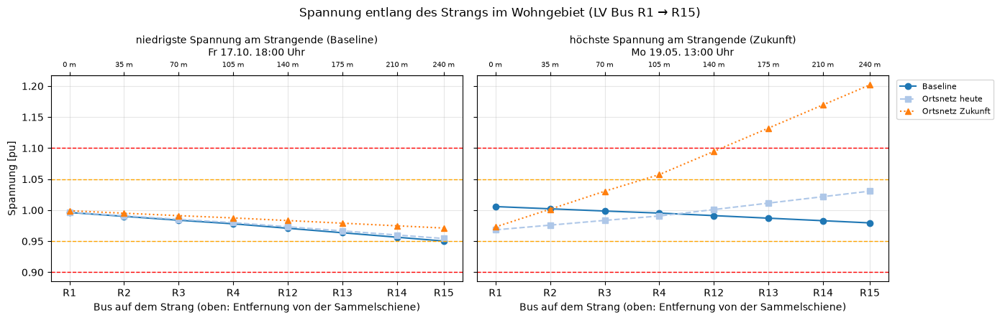

In [153]:
sim.compare(list(vergleich.values()), Diagram.APPARENT_POWER, ["LV Trafo R0-R1"], months=[Month.JANUARY, Month.JULY],
            title="Scheinleistung Ortsnetztrafo Wohngebiet")
ref = basis_t3.results.vm_pu["LV Bus R15"]
pv_max = ortsnetz["Zukunft"].results.vm_pu["LV Bus R15"].idxmax()
aw.spannungsprofil(vergleich, "LV Bus R1", "LV Bus R15",
                   {"niedrigste Spannung am Strangende (Baseline)": ref.idxmin(),
                    "höchste Spannung am Strangende (Zukunft)": pv_max},
                   titel="Spannung entlang des Strangs im Wohngebiet (LV Bus R1 → R15)")

**Befund Ortsnetz (Wohngebiet, rONT-Regelung aktiv, S1–S3 offen):**

- **Heute** (15 % der 564 Haushalte mit zusammen 762 kWp PV, davon 38 Haushalte mit zusammen 314 kWh Speicher): Die PV-Anlagen erzeugen in den 12 Wochen 214 MWh, der Bezug über Ortsnetztrafo R sinkt von 401 auf 264 MWh. In **390 Stunden** fließt Leistung ins MS-Netz zurück, zusammen 76 MWh, höchstens **0,45 MW**. Der Lastfluss kehrt sich also an sonnigen Mittagen tatsächlich um. Das konnten die Bezugsprofile P25/S25 vorher nicht abbilden.
- **Wirkung auf die Spannung:** Die höchste NS-Spannung steigt von 1,027 auf 1,050 pu, also genau an die obere Grenze des Planungsbands. Der rONT regelt in 131 Stunden nach unten (Stufe +1 oder +2) und hält die Spannung damit im Band; die Zahl der Stufenschritte steigt von 92 auf 150. Ortsnetztrafo R ist mit höchstens 75 % ausgelastet, die niedrigste Spannung (0,950 pu zur Abendspitze) ändert sich nicht, weil die PV dann nichts erzeugt.
- **Zukunft** (50 % der Haushalte mit PV, 40 % mit Speicher, 2,5 MWp): Die Rückspeisung erreicht **1,73 MW** in 574 Stunden. Ortsnetztrafo R (0,63 MVA) ist in 328 Stunden überlastet, bis 293 %; das erste Kabel (Line R1-R2) bis 287 %. Selbst mit der höchsten Stufe +2 steigt die Spannung am Strangende R15 auf **1,20 pu**, in 220 Stunden über die Arbeitsgrenze 1,10 pu. Die Stufen ±2 × 2,5 % reichen nicht aus.
- **Erklärung:** Die Spannungsanhebung am Strangende folgt ΔU ≈ (R·P + X·Q)/U mit negativem P (Rückspeisung). In den Kabeln des Wohngebiets ist R groß gegenüber X, deshalb wirkt vor allem die Wirkleistung. Die Speicher helfen nur am Vormittag: Sie laden mit dem ersten Überschuss und sind zur Mittagsspitze voll (Datengrundlage, Abschnitt 1.6).
- **Einordnung:** Im CIGRE-Netz hängen an Ortsnetztrafo R alle 564 Haushalte des Wohngebiets (Load R1 bündelt weitere Stränge). Für die Variante Zukunft wären ein größerer Trafo, verstärkte Kabel oder eine Begrenzung der Einspeisung nötig, z. B. eine netzdienliche Steuerung der Speicher (Teil 9). Weiter verwendet wird die Variante **heute**, die das Netz mit Regelung zulässig betreiben kann.

## 3 Szenarien einzeln und kombiniert in allen Schalterstellungen

Jedes Szenario wird in allen acht Schaltzuständen über 12 Wochen gerechnet (rONT-Regelung aktiv). Die Baseline sind die Zeitreihen aller Schalterstellungen mit rONT-Regelung aus Teil 3b (`w4_t3r_…`). Das Szenario „Wind + PV + Ortsnetz“ ist das Netz am Ende von Teil 4; seine Zeitreihen werden in Teil 5 weiter ausgewertet.

In [154]:
def mit_erzeugern(name, erzeuger):
    s = ausgelegt.copy(name, overwrite=True)
    for e in erzeuger:
        s.createElement(e)
    s.save(results=False)
    return s

WIND = Generator("Windpark", bus="Bus 1", profile=Profile.WIND, p_mw=30.0)
PV = Generator("PV-Freifläche", bus="Bus 12", profile=Profile.PV, kwp=10_000)
basen = {
    "Wind": mit_erzeugern("w4_t4b_wind", [WIND]),
    "PV": mit_erzeugern("w4_t4b_pv", [PV]),
    "Ortsnetz": aw.mit_pv_haushalten(ausgelegt, "w4_t4b_on", "heute")[0],
    "Wind + PV": mit_erzeugern("w4_t4b_wp", [WIND, PV]),
}
ende_t4, _ = aw.netz_ende_teil4()                           # Wind + PV + Ortsnetz (gleiches Netz wie in Teil 5)

szen = {"Baseline": {k: sim.loadSimulation(f"w4_t3r_{k}") for k in sz.KEYS}}
prefix = {"Wind": "w4_t4b_wind", "PV": "w4_t4b_pv", "Ortsnetz": "w4_t4b_on", "Wind + PV": "w4_t4b_wp"}
for name, b in basen.items():
    szen[name] = sz.zeitreihe_alle(b, prefix=prefix[name], controllers=aw.lv_regler(b.net))
szen["Wind + PV + Ortsnetz"] = sz.zeitreihe_alle(ende_t4, prefix="w4_t5", controllers=aw.lv_regler(ende_t4.net))
print({k: len(v) for k, v in szen.items()})

Simulation 'w4_t4b_wind_000': unverändert seit dem Lauf vom 2026-11-08T22:18:29 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_001': unverändert seit dem Lauf vom 2026-11-08T22:19:54 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_010': unverändert seit dem Lauf vom 2026-11-08T22:21:09 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_011': unverändert seit dem Lauf vom 2026-11-08T22:22:18 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_100': unverändert seit dem Lauf vom 2026-11-08T22:23:28 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_101': unverändert seit dem Lauf vom 2026-11-08T22:24:42 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_110': unverändert seit dem Lauf vom 2026-11-08

In [155]:
KENN = ["U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]", "Leitung max MS [%]", "Leitung max NS [%]",
        "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]", "Stunden Rückspeisung 110 kV", "max. Rückspeisung 110 kV [MW]",
        "Verluste [MWh]"]
werte = {}
for name, sims in szen.items():
    w, _ = bw.kennwerte({LABEL[k]: s for k, s in sims.items()})
    werte[name] = w
gesamt = pd.concat(werte, names=["Szenario", "Schaltzustand"])
gesamt["Stunden außerhalb der Arbeitsgrenzen"] = gesamt[list(bw.KRITERIEN.values())].sum(axis=1)
gesamt["Stunden Planungsband verletzt"] = gesamt[["Stunden U < 0,95 MS", "Stunden U < 0,95 NS"] +
                                                 [c for c in ("Stunden U > 1,05 MS", "Stunden U > 1,05 NS") if c in gesamt]].sum(axis=1)
print("Normalschaltzustand (alle offen), alle Szenarien:")
display(plots.table(gesamt.xs(LABEL["000"], level=1)[KENN + ["Stunden außerhalb der Arbeitsgrenzen", "Stunden Planungsband verletzt"]].astype(float).T, decimals=3))

Normalschaltzustand (alle offen), alle Szenarien:


Szenario,Baseline,Wind,PV,Ortsnetz,Wind + PV,Wind + PV + Ortsnetz
U min MS [pu],0.949,0.951,0.949,0.949,0.951,0.951
U max MS [pu],1.024,1.025,1.024,1.024,1.025,1.025
U min NS [pu],0.950,0.950,0.950,0.950,0.950,0.950
U max NS [pu],1.027,1.027,1.027,1.050,1.027,1.050
Leitung max MS [%],78.638,78.491,78.638,78.638,78.491,78.491
Leitung max NS [%],71.073,71.073,71.073,78.615,71.073,78.498
Trafo max HS/MS [%],82.694,88.512,82.694,82.694,88.512,88.512
Ortsnetztrafo max [%],66.838,66.838,66.838,75.449,66.838,75.331
Stunden Rückspeisung 110 kV,0.000,233.000,0.000,0.000,263.000,266.000
max. Rückspeisung 110 kV [MW],0.000,16.100,0.000,0.000,16.100,16.108


**Alle Szenarien und Schaltzustände** – je Kennwert eine Tabelle (Zeilen: Szenarien, Spalten: Schaltzustände):

In [156]:
for k, (cmap, lo, hi) in {"U min MS [pu]": ("RdYlGn", 0.93, 0.98), "U max MS [pu]": ("RdYlGn_r", 1.02, 1.06),
                          "U max NS [pu]": ("RdYlGn_r", 1.02, 1.06), "Leitung max MS [%]": ("YlOrRd", 40, 100),
                          "Trafo max HS/MS [%]": ("YlOrRd", 40, 100), "Stunden Rückspeisung 110 kV": ("Greens", 0, 300),
                          "Verluste [MWh]": ("YlOrRd", 100, 250), "Stunden Planungsband verletzt": ("Reds", 0, 50)}.items():
    print(k)
    tab = gesamt[k].unstack().reindex(index=list(szen), columns=[LABEL[s] for s in sz.KEYS]).astype(float)
    display(plots.table(tab, decimals=3 if "pu" in k else 1, cmap=cmap, vmin=lo, vmax=hi))

U min MS [pu]


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,0.949,0.950,0.949,0.951,0.973,0.973,0.974,0.975
Wind,0.951,0.952,0.951,0.953,0.974,0.974,0.976,0.976
PV,0.949,0.950,0.949,0.951,0.973,0.973,0.974,0.975
Ortsnetz,0.949,0.950,0.949,0.951,0.973,0.973,0.974,0.975
Wind + PV,0.951,0.952,0.951,0.953,0.974,0.974,0.976,0.976
Wind + PV + Ortsnetz,0.951,0.952,0.951,0.953,0.974,0.974,0.976,0.976


U max MS [pu]


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Wind,1.025,1.025,1.025,1.025,1.030,1.030,1.030,1.030
PV,1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Ortsnetz,1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Wind + PV,1.025,1.025,1.025,1.025,1.030,1.030,1.030,1.030
Wind + PV + Ortsnetz,1.025,1.025,1.025,1.025,1.030,1.030,1.030,1.030


U max NS [pu]


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,1.027,1.027,1.027,1.027,1.039,1.039,1.039,1.039
Wind,1.027,1.027,1.027,1.027,1.041,1.041,1.041,1.041
PV,1.027,1.027,1.027,1.027,1.039,1.039,1.039,1.039
Ortsnetz,1.050,1.050,1.050,1.050,1.050,1.050,1.050,1.050
Wind + PV,1.027,1.027,1.027,1.027,1.041,1.041,1.041,1.041
Wind + PV + Ortsnetz,1.050,1.050,1.050,1.050,1.050,1.050,1.050,1.050


... (6 outputs left out)

Verluste [MWh]


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,162.8,161.0,162.7,160.7,128.6,128.5,128.2,127.7
Wind,154.9,153.1,154.8,152.8,190.1,191.6,190.7,191.1
PV,159.5,157.8,159.5,157.5,132.3,132.4,131.9,131.6
Ortsnetz,161.3,159.5,161.2,159.2,127.4,127.3,126.9,126.4
Wind + PV,151.6,149.8,151.5,149.6,184.4,185.8,184.9,185.3
Wind + PV + Ortsnetz,150.2,148.5,150.2,148.2,183.1,184.5,183.6,184.0


Stunden Planungsband verletzt


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,8.0,3.0,9.0,0.0,0.0,0.0,0.0,0.0
Wind,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PV,8.0,3.0,9.0,0.0,0.0,0.0,0.0,0.0
Ortsnetz,8.0,3.0,9.0,0.0,0.0,0.0,0.0,0.0
Wind + PV,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wind + PV + Ortsnetz,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Änderung gegenüber der Baseline** im jeweils gleichen Schaltzustand:

In [157]:
delta = {}
for name in szen:
    if name == "Baseline":
        continue
    d = gesamt.loc[name, KENN].astype(float) - gesamt.loc["Baseline", KENN].astype(float)
    delta[name] = d.loc[LABEL["000"]]
print("Normalschaltzustand: Szenario − Baseline")
display(plots.table(pd.DataFrame(delta), decimals=3, cmap="RdBu_r", vmin=-30, vmax=30))
for k in ("U max MS [pu]", "Trafo max HS/MS [%]", "Verluste [MWh]"):
    tab = (gesamt[k].unstack() - gesamt.loc["Baseline", k]).drop(index="Baseline").reindex(columns=[LABEL[s] for s in sz.KEYS])
    print(f"{k}: Szenario − Baseline je Schaltzustand")
    display(plots.table(tab.astype(float), decimals=3, cmap="RdBu_r", vmin=-abs(tab.values).max(), vmax=abs(tab.values).max()))

Normalschaltzustand: Szenario − Baseline


,Wind,PV,Ortsnetz,Wind + PV,Wind + PV + Ortsnetz
U min MS [pu],0.002,0.000,0.000,0.002,0.002
U max MS [pu],0.001,0.000,0.000,0.001,0.001
U min NS [pu],-0.000,0.000,-0.000,0.000,-0.000
U max NS [pu],0.000,0.000,0.023,0.000,0.023
Leitung max MS [%],-0.147,0.000,-0.000,-0.147,-0.147
Leitung max NS [%],-0.000,0.000,7.542,0.000,7.425
Trafo max HS/MS [%],5.819,0.000,-0.000,5.819,5.819
Ortsnetztrafo max [%],-0.000,0.000,8.611,-0.000,8.493
Stunden Rückspeisung 110 kV,233.000,0.000,0.000,263.000,266.000
max. Rückspeisung 110 kV [MW],16.100,0.000,0.000,16.100,16.108


U max MS [pu]: Szenario − Baseline je Schaltzustand


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Wind,0.001,0.001,0.001,0.001,0.006,0.006,0.006,0.006
PV,0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,0.000
Ortsnetz,0.000,-0.000,0.000,-0.000,0.000,0.000,-0.000,-0.000
Wind + PV,0.001,0.001,0.001,0.001,0.006,0.006,0.006,0.006
Wind + PV + Ortsnetz,0.001,0.001,0.001,0.001,0.006,0.006,0.006,0.006


Trafo max HS/MS [%]: Szenario − Baseline je Schaltzustand


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Wind,5.819,5.831,5.819,5.835,0.780,0.498,0.522,0.398
PV,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Ortsnetz,-0.000,0.000,0.000,-0.000,-0.048,-0.048,-0.048,-0.048
Wind + PV,5.819,5.831,5.819,5.835,0.780,0.498,0.522,0.398
Wind + PV + Ortsnetz,5.819,5.831,5.819,5.835,0.780,0.498,0.522,0.398


Verluste [MWh]: Szenario − Baseline je Schaltzustand


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Wind,-7.913,-7.903,-7.912,-7.902,61.491,63.078,62.569,63.437
PV,-3.282,-3.282,-3.282,-3.282,3.663,3.844,3.769,3.872
Ortsnetz,-1.505,-1.505,-1.505,-1.505,-1.256,-1.248,-1.252,-1.248
Wind + PV,-11.195,-11.185,-11.194,-11.184,55.726,57.266,56.763,57.609
Wind + PV + Ortsnetz,-12.573,-12.564,-12.573,-12.563,54.441,55.986,55.481,56.329


**Befund Szenarien in allen Schalterstellungen (rONT-Regelung aktiv):**

- **Konvergenz:** Alle 6 Szenarien × 8 Schaltzustände × 2016 Stunden konvergieren.
- **Arbeitsgrenzen:** In keinem Szenario und keinem Schaltzustand wird 0,90 … 1,10 pu verletzt oder ein Betriebsmittel über 100 % belastet. Das Planungsband wird nur in Baseline, PV und Ortsnetz in 3 bis 9 Stunden unterschritten (Bus 11 am Ende von Abgang 1 zur Abendspitze, U min 0,949 pu). Der Windpark hebt die MS-Spannung so weit an, dass diese Stunden verschwinden.
- **Windpark (Bus 1):** Er bestimmt das Netz. Bei offenem S1 fließt seine Einspeisung über Trafo 0-1 ins 110-kV-Netz (233 Stunden Rückspeisung, bis 16,1 MW). Trafo 0-1 ist dann mit 88,5 % höher ausgelastet als bei Höchstlast ohne Windpark (82,7 %). Die Leitungen in Abgang 1 entlastet er dagegen leicht. **Mit geschlossenem S1** teilt sich die Einspeisung auf beide Trafos auf: Ein Teil fließt durch Abgang 1 und über Line 14-8 zum Trafo 0-12. Die höchste MS-Leitungsauslastung steigt dann von 42 % (Baseline mit S1) auf **98 bis 99,6 %**, und die Verluste steigen um 61 bis 63 MWh. Mit Windpark sollte S1 im Normalbetrieb offen bleiben.
- **PV-Anlage (Bus 12):** Mit höchstens 8,4 MW speist sie nie mehr ein, als das ganze Netz gleichzeitig verbraucht; deshalb gibt es keine Rückspeisung ins 110-kV-Netz; selbst Trafo 0-12 bezieht immer mindestens 2,6 MW, und Spannungen und Auslastungen ändern sich kaum. Die Verluste sinken bei offenem S1 um 3,3 MWh, mit S1 steigen sie um 3,7 MWh, weil Leistung durch die Masche fließt.
- **Ortsnetz:** Es wirkt nur im Wohngebiet (U max NS 1,050 pu, Ortsnetztrafo 75 %) und ist im MS-Netz kaum zu sehen. Mit S1 bleibt die höchste NS-Spannung bei 1,050 pu, weil der rONT nachregelt.
- **Kombination:** Die Wirkungen addieren sich fast genau. Wind + PV + Ortsnetz hat 266 Stunden Rückspeisung ins 110-kV-Netz (Wind allein 233) und die geringsten Verluste bei offenem S1 (150 MWh, −12,6 MWh gegenüber der Baseline). Die Schalter S2 und S3 ändern wie in den vorigen Teilen fast nichts.

## 4 Hohe und niedrige Einspeise- und Lastsituationen

Aus den Zeitreihen im Normalschaltzustand werden je Szenario typische Extremsituationen herausgegriffen:

| Situation | Auswahl |
|---|---|
| Höchstlast | Stunde mit der größten Summe aller Lasten (in allen Szenarien derselbe Zeitpunkt) |
| hohe Einspeisung, niedrige Last | Stunde mit dem größten Verhältnis Erzeugung/Last (nur Szenarien mit Erzeugern) |
| höchste Einspeisung | Stunde mit der größten Summe aller Erzeuger des Szenarios |
| Schwachlast ohne Einspeisung | Stunde mit der kleinsten Last bei Einspeisung unter 5 % der installierten Leistung |

Für jede Situation werden die Spannungen an **allen** MS- und NS-Bussen sowie die Auslastungen ausgewertet.

In [158]:
def situationen(s):
    r = s.results
    p = r.ext_grid_p_mw.squeeze()
    erz = r.sgen_p_mw.sum(axis=1) if len(r.sgen_p_mw.columns) else pd.Series(0.0, index=p.index)
    last = r.load_p_mw.sum(axis=1)
    out = {"Höchstlast": last.idxmax()}                   # höchste Last (bei allen Szenarien derselbe Zeitpunkt)
    if erz.max() > 0:
        out["hohe Einspeisung, niedrige Last"] = (erz / last).idxmax()   # größtes Verhältnis Erzeugung/Last
        out["höchste Einspeisung"] = erz.idxmax()
        ruhig = erz < 0.05 * erz.max()
        out["Schwachlast ohne Einspeisung"] = last[ruhig].idxmin()
    else:
        out["Schwachlast ohne Einspeisung"] = last.idxmin()
    return out

zeilen, spannungen = {}, {}
for name, sims in szen.items():
    s = sims["000"]
    r = s.results
    for sit, h in situationen(s).items():
        vm = r.vm_pu.loc[h]
        ms, ns = vm[aw.MS_BUSSE], vm[[c for c in vm.index if c.startswith("LV Bus")]]
        zeilen[(name, sit)] = {"Zeitpunkt": f"{h:%d.%m. %H:%M}", "Last [MW]": r.load_p_mw.loc[h].sum(),
                               "Erzeugung [MW]": r.sgen_p_mw.loc[h].sum() if len(r.sgen_p_mw.columns) else 0.0,
                               "Austausch 110 kV [MW]": r.ext_grid_p_mw.squeeze()[h],
                               "U min MS [pu]": ms.min(), "U max MS [pu]": ms.max(), "U min NS [pu]": ns.min(), "U max NS [pu]": ns.max(),
                               "Leitung max [%]": r.line_loading.loc[h].max(), "Trafo max [%]": r.trafo_loading.loc[h].max()}
        spannungen[(name, sit)] = vm
sit_tab = pd.DataFrame(zeilen).T
display(plots.table(sit_tab, decimals=3))

**Spannungen an allen Bussen** in diesen Situationen (Zeilen: Busse; Spalten: Szenario und Situation):

In [159]:
u_alle = pd.DataFrame(spannungen)
u_alle = u_alle.loc[[b for b in u_alle.index if b != "Bus 0"]]
plots.table(u_alle, decimals=3, cmap="RdYlGn_r", vmin=0.94, vmax=1.06)

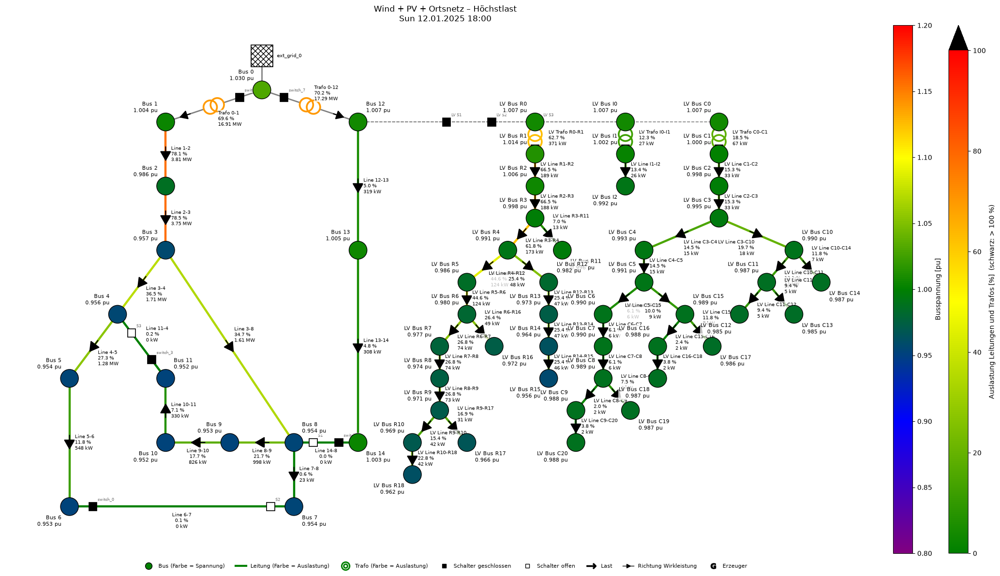

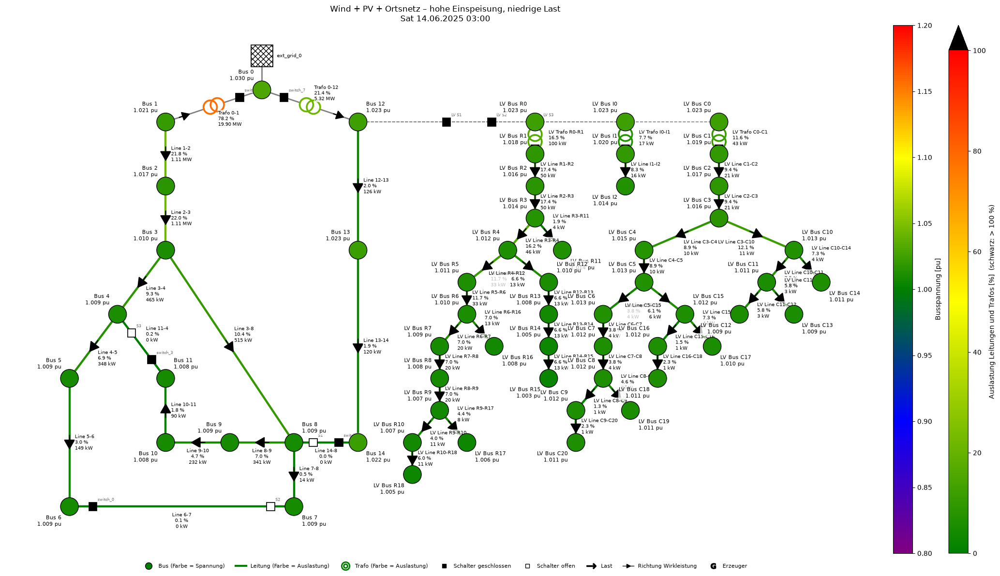

In [160]:
for sit in ("Höchstlast", "hohe Einspeisung, niedrige Last"):
    h = situationen(szen["Wind + PV + Ortsnetz"]["000"])[sit]
    szen["Wind + PV + Ortsnetz"]["000"].createDiagram(Diagram.NETWORK, time=[h], elements=False,
                                                     title=f"Wind + PV + Ortsnetz – {sit}")

**Befund hohe und niedrige Situationen (S1–S3 offen):**

- **Höchstlast** (12.01., 18:00, 37,4 MW Last): Ohne Erzeuger liegt die niedrigste Spannung bei 0,950 pu (Bus 10/11, Planungsband gerade eingehalten). PV und Ortsnetz speisen um diese Zeit nichts ein und ändern nichts. Der Windpark liefert in dieser Stunde 3,3 MW und entlastet Trafo 0-1 von 82,7 auf 70,3 %, die Spannung ändert sich kaum. Die Höchstlast bestimmt in allen Szenarien die niedrigste Spannung.
- **Hohe Einspeisung, niedrige Last:** Beim Windpark ist das eine Nacht im Juni (14.06., 3 Uhr: 26 MW Wind, 11,4 MW Last). Es fließen 14,6 MW ins 110-kV-Netz zurück, Trafo 0-1 ist mit 78 % fast so hoch ausgelastet wie bei Höchstlast. Die Spannung steigt an allen MS-Bussen auf über 1,008 pu, höchstens 1,024 pu. Bei PV und Ortsnetz liegt dieser Zeitpunkt mittags (19.05., 13 Uhr): Die PV-Anlage senkt den Bezug, die Spannungen bleiben zwischen 0,96 und 1,03 pu.
- **Höchste Einspeisung:** Voller Wind (30 MW, 06.01., 6 Uhr) bei mittlerer Last führt zu 8 MW Rückspeisung. Mit Wind und PV zusammen (08.02., 12 Uhr, 36 MW) gleichen sich Einspeisung und Last fast aus (3,1 bis 3,4 MW Rückspeisung), die Trafos sind dann nur halb ausgelastet.
- **Schwachlast ohne Einspeisung** (Nacht im September, 10,3 MW): Die höchsten Spannungen im Netz (1,024 pu an Bus 1, 1,024 pu im Ortsnetz) entstehen hier durch die feste Slack-Spannung von 1,03 pu und den geringen Spannungsfall, nicht durch die Erzeuger.
- **Alle Busse:** Die Tabelle zeigt, dass in keiner Situation ein MS- oder NS-Bus das Planungsband 0,95 … 1,05 pu verlässt. Die Spannungsspanne über alle Situationen ist ohne und mit Erzeugern fast gleich: Die Erzeuger hängen an den Trafo-Sammelschienen und verschieben die Spannung in den Abgängen nur wenig. Größer ist der Unterschied zwischen Höchst- und Schwachlast (bis 6 Prozentpunkte an Bus 11).

## 5 Blindleistungsverhalten

Bisher speisen Windpark und PV-Anlage mit cos φ = 1. Nach der TAR Mittelspannung müssen Erzeugungsanlagen am MS-Netz Blindleistung nach Vorgabe des Netzbetreibers bereitstellen können, z. B. als fester Verschiebungsfaktor oder spannungsabhängig, im Bereich von etwa cos φ = 0,95 untererregt bis 0,95 übererregt [31]. Verglichen wird:

- **cos φ = 1:** reine Wirkleistung (bisher)
- **cos φ = 0,95 untererregt:** Die Anlagen nehmen Blindleistung auf (q = −0,33 · p). Das senkt die Spannung am Anschlusspunkt, erhöht aber den Strom.

Gerechnet für Wind, PV und Wind + PV + Ortsnetz im Normalschaltzustand. Die Spannungsänderung lässt sich mit ΔU ≈ (R · P + X · Q) / U abschätzen [19]: Ein negativer Q-Beitrag kompensiert einen Teil des Spannungsanstiegs durch P, und zwar umso stärker, je größer X/R ist.

In [161]:
def mit_cosphi(s, name, cosphi):
    q = s.copy(name, overwrite=True)
    for g in ("Windpark", "PV-Freifläche"):
        if g in set(q.net.sgen["name"]):
            q.changeParameter(g, "cos_phi", cosphi)
    q.save(results=False)
    return q

blind = {}
for name, s in (("Wind", szen["Wind"]["000"]), ("PV", szen["PV"]["000"]), ("Wind + PV + Ortsnetz", szen["Wind + PV + Ortsnetz"]["000"])):
    q = mit_cosphi(s, f"w4_t4b_q_{name.replace(' + ', '_').replace(' ', '_').lower()}", -0.95)
    q.runSimulation(controllers=aw.lv_regler(q.net))
    blind[(name, "cos φ = 1")] = s
    blind[(name, "cos φ = 0,95 untererregt")] = q

def q_kennwerte(s):
    r = s.results
    w, _ = bw.kennwerte({"x": s})
    w = w.iloc[0]
    erz = [c for c in ("Windpark", "PV-Freifläche") if c in r.sgen_q_mvar]
    return {"U max MS [pu]": w["U max MS [pu]"], "U min MS [pu]": w["U min MS [pu]"], "U max NS [pu]": w["U max NS [pu]"],
            "Leitung max MS [%]": w["Leitung max MS [%]"], "Trafo max HS/MS [%]": w["Trafo max HS/MS [%]"],
            "Verluste [MWh]": w["Verluste [MWh]"],
            "Q der Anlagen min [Mvar]": float(r.sgen_q_mvar[erz].sum(axis=1).min()) if erz else 0.0,
            "Q-Bezug 110 kV max [Mvar]": float(r.ext_grid_q_mvar.squeeze().max()),
            "Q-Bezug 110 kV Mittel [Mvar]": float(r.ext_grid_q_mvar.squeeze().mean()),
            "Stufenschritte rONT gesamt": int(rg.schaltvorgaenge(s).filter(like="Stufen").sum())}

q_tab = pd.DataFrame({k: q_kennwerte(s) for k, s in blind.items()})
plots.table(q_tab, decimals=3)

Simulation 'w4_t4b_q_wind': unverändert seit dem Lauf vom 2026-11-08T23:26:09 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_q_pv': unverändert seit dem Lauf vom 2026-11-08T23:27:15 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_q_wind_pv_ortsnetz': unverändert seit dem Lauf vom 2026-11-08T23:28:26 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


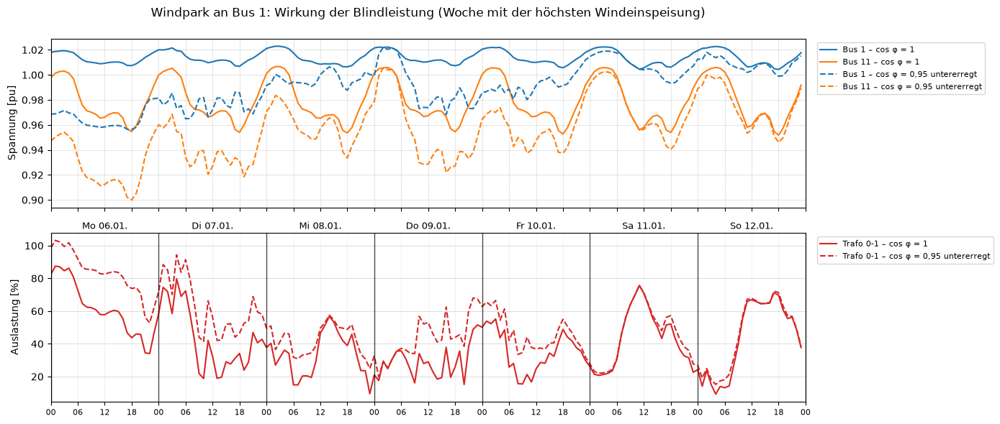

In [162]:
s1, s2 = blind[("Wind", "cos φ = 1")], blind[("Wind", "cos φ = 0,95 untererregt")]
h = s1.results.sgen_p_mw["Windpark"].idxmax()
idx = s1.results.info.index[s1.results.info["month"] == s1.results.info.at[h, "month"]]
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
x = idx
for s, ls, lab in ((s1, "-", "cos φ = 1"), (s2, "--", "cos φ = 0,95 untererregt")):
    axes[0].plot(x, s.results.vm_pu.loc[idx, "Bus 1"], ls, color="tab:blue", label=f"Bus 1 – {lab}")
    axes[0].plot(x, s.results.vm_pu.loc[idx, "Bus 11"], ls, color="tab:orange", label=f"Bus 11 – {lab}")
    axes[1].plot(x, s.results.trafo_loading.loc[idx, "Trafo 0-1"], ls, color="tab:red", label=f"Trafo 0-1 – {lab}")
axes[0].set_ylabel("Spannung [pu]")
axes[1].set_ylabel("Auslastung [%]")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[0].set_title("Windpark an Bus 1: Wirkung der Blindleistung (Woche mit der höchsten Windeinspeisung)", pad=22)
plots.week_axis(axes[1], idx)
plt.tight_layout()
plt.show()

**Befund Blindleistung:**

- **PV-Anlage:** Mit cos φ = 0,95 untererregt nimmt sie bis 2,7 Mvar auf. Spannungen und Auslastungen bleiben praktisch gleich, die Verluste steigen um 0,5 MWh. An Bus 12 gibt es kein Spannungsproblem, das die Blindleistung lösen müsste.
- **Windpark:** Mit cos φ = 0,95 untererregt nimmt er bis 9,9 Mvar auf. Das senkt die Spannung in Abgang 1 deutlich: Bei Höchstlast und vollem Wind (06.01., 18:00) fällt Bus 11 auf **0,900 pu**, genau auf die Arbeitsgrenze. In 291 Stunden liegt ein MS-Bus unter 0,95 pu (mit cos φ = 1: 0). Trafo 0-1 muss Wirk- und Blindleistung zugleich übertragen und wird in 11 Stunden überlastet (bis 104 %). Die Verluste steigen um 8 MWh, der Blindleistungsbezug aus dem 110-kV-Netz verdoppelt sich fast (Höchstwert 11,8 → 21,7 Mvar).
- **Erklärung:** Untererregter Betrieb ist dafür gedacht, die Spannungsanhebung durch Einspeisung zu begrenzen. Im CIGRE-Netz liegt die MS-Spannung aber auch bei voller Einspeisung höchstens bei 1,025 pu. Der Windpark hängt direkt an der Trafo-Sammelschiene, deshalb wirkt seine Blindleistung über die Reaktanz von Trafo 0-1 auf den ganzen Abgang 1, auch zur Abendspitze, wenn die Spannung ohnehin niedrig ist.
- **Folgerung:** Für dieses Netz ist cos φ = 1 die bessere Vorgabe. Sinnvoll wäre höchstens eine spannungsabhängige Kennlinie Q(U), die erst bei hoher Spannung Blindleistung aufnimmt, wie sie die TAR Mittelspannung als Verfahren vorsieht [31].

## 6 Ergebnis: Anschlussort, Dimensionierung, Blindleistung und gleichzeitiger Betrieb

**Ergebnis Teil 4:**

- **Anschlussort:** Windpark (30 MW) und PV-Freiflächenanlage (10 MWp) sind nur an den Sammelschienen der 110/20-kV-Trafos anschließbar (Teil 4a). Dort ändern sie die Spannungen in den Abgängen kaum (höchstens +0,2 Prozentpunkte), sondern vor allem die Trafoauslastung und den Austausch mit dem 110-kV-Netz. Die PV-Haushalte speisen dagegen mitten im Ortsnetz ein und heben dort die Spannung bis an das Planungsband.
- **Dimensionierung:** Der Windpark ist so groß, dass er in 233 Stunden mehr erzeugt, als das ganze Netz verbraucht (bis 16,1 MW Rückspeisung). Die PV-Anlage bleibt immer unter der Last. Im Ortsnetz ist die Variante „heute“ mit dem rONT beherrschbar, die Variante „Zukunft“ nicht (Trafo bis 293 %, Spannung bis 1,20 pu).
- **Blindleistung:** Untererregter Betrieb mit cos φ = 0,95 schadet in diesem Netz: Beim Windpark sinkt die Spannung in Abgang 1 bis auf die Arbeitsgrenze 0,90 pu, Trafo 0-1 wird überlastet. cos φ = 1 bleibt die Vorgabe; sinnvoll wäre höchstens Q(U).
- **Gleichzeitiger Betrieb:** Die Wirkungen der Szenarien addieren sich fast genau, weil sie an verschiedenen Stellen einspeisen (Bus 1, Bus 12, Wohngebiet). Zusammen senken sie die Verluste um 12,6 MWh (−8 %) bei offenem S1.
- **Schalterstellungen:** Mit Windpark sollte S1 offen bleiben: Geschlossen steigen die MS-Leitungsauslastung auf bis 99,6 % und die Verluste um rund 55 MWh. S2 und S3 ändern wie bisher fast nichts.
- **Weiter verwendet** wird das Netz „Wind + PV + Ortsnetz (heute)“ (`w4_t5_…`); Teil 5 untersucht darin die Lastflussumkehr.

<a id="teil-7"></a>

---

# Task 4 – Teil 5: Lastflussumkehr

**Ausgangspunkt:** das Netz am Ende von Teil 4. Es umfasst:
- CIGRE-MV ohne DER (Baseline des Arbeitsauftrags) mit dem ausgelegten Ortsnetz an Bus 12,
- rONT-Regelung und Backup-Plan aus Teil 3b,
- Windpark (30 MW) an Bus 1 und PV-Freiflächenanlage (10 MWp) an Bus 12 aus Teil 4a,
- Haushalte mit PV-Anlage und Batteriespeicher im Wohngebiet, Variante „heute“ (15 % der Haushalte mit PV, davon 6,7 % aller Haushalte mit Speicher) aus Teil 4b.

Voraussetzung: `Task4-4a_Erzeugung_Anschluss.ipynb` wurde ausgeführt (Simulation `w4_kombi_W1_P12`). Die Zeitreihen aller Schalterstellungen sind dieselben wie für das Szenario „Wind + PV + Ortsnetz“ in Teil 4b und werden bei gleichem Netz aus dem Speicher geladen.

### Anforderungen aus dem Arbeitsauftrag (Abschnitt 5)

> *Betrachten Sie im folgenden immer die möglichen Schalterstellungen der Schalter S1–S3. Werten Sie Wirkleistungsflüsse an geeigneten Leitungen, Netzkuppelstellen und Transformatoren aus. Erklären Sie anhand der verwendeten pandapower-Ergebnisfelder deren Vorzeichen und leiten Sie daraus ab, wann ein Leistungsfluss seine Richtung wechselt. Untersuchen Sie, welche Erzeugungs- und Lastbedingungen die Umkehr auslösen, wie stark und wie häufig sie auftritt und welche Folgen sich für Spannungen, Auslastungen und die Regelung des Ortsnetztransformators ergeben. Zeitreihen, Dauerlinien oder eine räumliche Darstellung der Flüsse können den Vergleich unterstützen.*

| Anforderung | wo |
|---|---|
| Wirkleistungsflüsse an Leitungen, Netzkuppelstelle (110 kV) und Trafos | Abschnitt 3 und 4 |
| Vorzeichen der pandapower-Ergebnisfelder, Kriterium für den Richtungswechsel | Abschnitt 2 |
| alle Schalterstellungen S1–S3 | Abschnitt 4 |
| auslösende Erzeugungs- und Lastbedingungen | Abschnitt 3 (Normalzustand) |
| Stärke und Häufigkeit der Umkehr | Abschnitt 3, 4 und 7 (Dauerlinien) |
| Folgen für Spannungen und Auslastungen | Abschnitt 5 |
| Folgen für die rONT-Regelung | Abschnitt 6 |
| Zeitreihen, Dauerlinien, räumliche Darstellung | Abschnitt 3, 7 und 8 |

### Aufbau

1. Netz am Ende von Teil 4 erstellen
2. Vorzeichen der Ergebnisfelder
3. Normalzustand: Wo kehrt sich der Leistungsfluss um, und welche Muster gibt es?
4. Alle Schalterstellungen: Änderung der Leistungsflüsse gegenüber dem Normalzustand
5. Folgen für Spannungen und Auslastungen
6. Folgen für die rONT-Regelung
7. Dauerlinien
8. Räumliche Darstellung der Flüsse
9. Rückspeisung im Ortsnetz
10. Zusatz: Ausfall eines 110/20-kV-Transformators
11. Ergebnis

## Importe

In [163]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import copy

import numpy as np
import pandas as pd
import pandapower as pp
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import regelung as rg
import bewertung as bw
import plots
import netplan
import auswertung as aw
from auswertung import PLAN_MARKER, V_PLAN_MIN, V_PLAN_MAX, MS_BUSSE
from elements import Diagram
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

sim.ONLY_RUN_IF_CHANGED = True
SCHWELLE = 0.001                                         # |P| unter 1 kW gilt als „kein Fluss“

kombi = sim.loadSimulation(aw.KOMBI)                     # Teil 4a: gewählte Kombination (Wind an Bus 1, PV an Bus 12)
lv_regler = aw.lv_regler

## 1 Netz am Ende von Teil 4

Kopie der gewählten Kombination aus Teil 4a; zusätzlich erhalten die Haushalte im Wohngebiet PV-Anlagen und Batteriespeicher wie in Teil 4b, Variante „heute“ (`auswertung.netz_ende_teil4`, Daten in der Datengrundlage, Abschnitt 1.6).

**Regelung:** Für alle Rechnungen in diesem Notebook laufen nur die drei rONT-Regler. Der Backup-Plan (`SchaltPlan`) öffnet beim Start alle Trennschalter und würde damit die vorgegebenen Schalterstellungen in Abschnitt 4 überschreiben. Im Normalzustand löst er ohnehin nie aus (Teil 3b, Teil 4a).

In [164]:
basis, aufteilung = aw.netz_ende_teil4()
display(plots.table(aufteilung, decimals=2))
print("Erzeuger:")
display(basis.net.sgen[["name", "p_mw"]].assign(Bus=basis.net.bus.loc[basis.net.sgen.bus, "name"].to_numpy()))
print("Lasten je Profil:")
basis.net.load.groupby("profile").agg(Anzahl=("name", "size"), Hoechstleistung_MW=("p_mw", "sum"))

,Bus,Jahresverbrauch [MWh],Haushalte,davon nur PV,davon PV + Speicher,PV [kWp],Speicher [kWh],Speicherleistung [kW]
Last,,,,,,,,
LV Load R1,LV Bus R1,838.34,279.45,23.19,18.72,377.25,155.40,91.69
LV Load R11,LV Bus R11,62.88,20.96,1.74,1.40,28.29,11.65,6.88
LV Load R15,LV Bus R15,217.97,72.66,6.03,4.87,98.09,40.40,23.84
LV Load R16,LV Bus R16,230.54,76.85,6.38,5.15,103.74,42.73,25.21
LV Load R17,LV Bus R17,146.71,48.90,4.06,3.28,66.02,27.19,16.04
LV Load R18,LV Bus R18,197.01,65.67,5.45,4.40,88.65,36.52,21.55
Summe,,1693.44,564.48,46.85,37.82,762.05,313.91,185.21


Erzeuger:


,name,p_mw,Bus
0,Windpark,30.000000,Bus 1
1,PV-Freifläche,10.000000,Bus 12
2,LV PV R1,0.208746,LV Bus R1
3,LV PV Speicher R1,0.168505,LV Bus R1
4,LV PV R11,0.015656,LV Bus R11
5,LV PV Speicher R11,0.012638,LV Bus R11
6,LV PV R15,0.054274,LV Bus R15
7,LV PV Speicher R15,0.043811,LV Bus R15
8,LV PV R16,0.057405,LV Bus R16
9,LV PV Speicher R16,0.046339,LV Bus R16


Lasten je Profil:


,Anzahl,Hoechstleistung_MW
profile,,
GEWERBE,17,11.47280
HAUSHALT,16,33.95595


In [165]:
normal = sz.zeitreihe_alle(basis, prefix="w4_t5", keys=["000"], controllers=lv_regler(basis.net))["000"]
werte, _ = bw.kennwerte({"Teil 4a: Kombination": kombi, "Teil 4b: Ortsnetz heute": sim.loadSimulation("w4_t4b_ortsnetz_heute"),
                         "Netz am Ende von Teil 4": normal})
plots.table(werte[["U max gesamt [pu]", "U min gesamt [pu]", "Leitung max MS [%]", "Leitung max NS [%]", "Trafo max HS/MS [%]",
                   "Ortsnetztrafo max [%]", "Stunden Rückspeisung 110 kV", "max. Rückspeisung 110 kV [MW]", "Verluste [MWh]"]].astype(float),
            decimals=3)

Simulation 'w4_t5_000': unverändert seit dem Lauf vom 2026-11-08T23:06:34 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW],Verluste [MWh]
Teil 4a: Kombination,1.027,0.950,78.491,71.073,88.512,66.838,263.000,16.100,151.602
Teil 4b: Ortsnetz heute,1.050,0.949,78.638,78.615,82.694,75.449,0.000,0.000,161.292
Netz am Ende von Teil 4,1.050,0.950,78.491,78.498,88.512,75.331,266.000,16.108,150.223


**Das neue Netz** enthält alle drei Szenarien aus Teil 4 gleichzeitig: Windpark an Bus 1, PV-Anlage an Bus 12 und im Wohngebiet 85 Haushalte mit PV-Anlage (zusammen 762 kWp), davon 38 mit Heimspeicher (314 kWh), Variante „heute“ aus Teil 4b.

- **MS-Netz:** Gegenüber der Kombination aus Teil 4a ändert sich fast nichts. Die Rückspeisung ins 110-kV-Netz steigt von 263 auf 266 Stunden, die Verluste sinken von 151 auf 150 MWh.
- **Ortsnetz:** Die höchste NS-Spannung steigt von 1,027 auf 1,050 pu, die höchste NS-Leitungsauslastung von 71 auf 78 % und die Auslastung von Ortsnetztrafo R von 67 auf 75 %. Ursache ist die Rückspeisung der PV-Haushalte an sonnigen Mittagen (Abschnitt 9).
- Alle Spannungen bleiben im Planungsband (0,950 bis 1,050 pu).

## 2 Vorzeichen der Ergebnisfelder

pandapower verwendet für Lasten das Verbraucherzählpfeilsystem und für Erzeuger das Erzeugerzählpfeilsystem. Für Leitungen und Trafos gibt das Vorzeichen die Richtung bezogen auf die Anschlussseite an:

| Element | Ergebnisfeld (gespeichert als) | positiv | negativ |
|---|---|---|---|
| Leitung | `res_line.p_from_mw` (`results.line_p_mw`) | Wirkleistung fließt von `from_bus` in die Leitung, also von `from_bus` zu `to_bus` | Fluss von `to_bus` zu `from_bus` |
| Trafo | `res_trafo.p_hv_mw` (`results.trafo_p_mw`) | Fluss von der Oberspannungs- zur Unterspannungsseite (Bezug aus dem überlagerten Netz) | Fluss von US nach OS (**Rückspeisung**) |
| Netzkuppelstelle (110 kV) | `res_ext_grid.p_mw` (`results.ext_grid_p_mw`) | Bezug aus dem 110-kV-Netz | Rückspeisung ins 110-kV-Netz |
| Last | `res_load.p_mw` | Verbrauch | – |
| Erzeuger | `res_sgen.p_mw` | Einspeisung | – |

**Richtungswechsel:** Ein Leistungsfluss wechselt seine Richtung, wenn das Vorzeichen des Ergebnisfelds wechselt. Als Hauptrichtung eines Elements gilt das Vorzeichen, das in den meisten Stunden auftritt. Jede Stunde mit dem anderen Vorzeichen zählt als Umkehr. Werte mit |P| < 1 kW gelten als „kein Fluss“, damit Rechenrauschen an offenen Leitungen nicht als Umkehr zählt.

Die Leitungsnamen geben die Richtung von `from_bus` zu `to_bus` an: Bei „Line 1-2“ heißt positiv also Fluss von Bus 1 zu Bus 2. Beispiel für eine Stunde mit Rückspeisung:

In [166]:
r = normal.results
h_rueck = r.ext_grid_p_mw.squeeze().idxmin()
beispiel = pd.Series({
    "Windpark (sgen) [MW]": r.sgen_p_mw.at[h_rueck, "Windpark"],
    "PV-Freifläche (sgen) [MW]": r.sgen_p_mw.at[h_rueck, "PV-Freifläche"],
    "Summe Lasten [MW]": r.load_p_mw.loc[h_rueck].sum(),
    "Trafo 0-1, p_hv_mw [MW]": r.trafo_p_mw.at[h_rueck, "Trafo 0-1"],
    "Trafo 0-12, p_hv_mw [MW]": r.trafo_p_mw.at[h_rueck, "Trafo 0-12"],
    "Line 1-2, p_from_mw [MW]": r.line_p_mw.at[h_rueck, "Line 1-2"],
    "110-kV-Netz, ext_grid p_mw [MW]": r.ext_grid_p_mw.squeeze()[h_rueck],
}, name=f"{h_rueck:%d.%m. %H:%M}")
beispiel.to_frame()

,19.12. 02:00
Windpark (sgen) [MW],29.487000
PV-Freifläche (sgen) [MW],0.000000
Summe Lasten [MW],13.331587
"Trafo 0-1, p_hv_mw [MW]",-22.318591
"Trafo 0-12, p_hv_mw [MW]",6.210418
"Line 1-2, p_from_mw [MW]",1.298714
"110-kV-Netz, ext_grid p_mw [MW]",-16.108173


**Beispiel (19.12., 2 Uhr, stärkste Rückspeisung):** Der Windpark speist 29,5 MW ein, alle Lasten zusammen brauchen 13,3 MW.

- `Trafo 0-1` hat `p_hv_mw = −22,3 MW`: Leistung fließt von der 20-kV- zur 110-kV-Seite, der Trafo speist zurück.
- `Trafo 0-12` hat `+6,2 MW`: Abgang 2 bezieht weiter aus dem 110-kV-Netz.
- Die Netzkuppelstelle zeigt `−16,1 MW`: Rückspeisung ins 110-kV-Netz, die Differenz der beiden Trafos abzüglich der Verluste.
- `Line 1-2` bleibt positiv (+1,3 MW): Auch bei Rückspeisung fließt auf der Leitung weiter Leistung von Bus 1 in den Abgang, nur jetzt aus dem Windpark statt aus dem Trafo.

## 3 Normalzustand: Wo kehrt sich der Leistungsfluss um?

Für jede Leitung, jeden Trafo und die Netzkuppelstelle: Hauptrichtung, Stunden in Gegenrichtung und größter Fluss in Gegenrichtung (12 Wochen, 2016 Stunden).

In [167]:
def fluesse(s):
    """Wirkleistungsflüsse aller Leitungen, Trafos und der Netzkuppelstelle [MW] (Spalten = Elemente)."""
    rr = s.results
    return pd.concat([rr.line_p_mw, rr.trafo_p_mw, rr.ext_grid_p_mw.rename(columns={"ext_grid_p_mw": "110-kV-Netz"})], axis=1)

def richtungen(P):
    """Je Element: Stunden mit positivem / negativem Fluss, Hauptrichtung, Stunden in Gegenrichtung."""
    pos, neg = (P > SCHWELLE).sum(), (P < -SCHWELLE).sum()
    haupt = np.where(pos >= neg, 1, -1)
    gegen = np.where(haupt > 0, neg, pos)
    max_gegen = [(-P[c]).clip(lower=0).max() if h > 0 else P[c].clip(lower=0).max() for c, h in zip(P.columns, haupt)]
    return pd.DataFrame({"Stunden P > 0": pos, "Stunden P < 0": neg, "Hauptrichtung": np.where(haupt > 0, "+", "−"),
                         "Stunden Gegenrichtung": gegen, "max. Fluss Gegenrichtung [MW]": max_gegen}, index=P.columns)

P0 = fluesse(normal)
mv = [c for c in P0 if c.startswith(("Line", "Trafo")) or c == "110-kV-Netz"]
ortsnetz = [c for c in P0 if c.startswith("LV")]
rt = richtungen(P0)
print("MS-Netz, Trafos und Netzkuppelstelle:")
display(rt.loc[mv])
print(f"Ortsnetz: {len(ortsnetz)} Leitungen und Trafos, davon mit Gegenrichtung:",
      list(rt.loc[ortsnetz].query("`Stunden Gegenrichtung` > 0").index) or "keine")

MS-Netz, Trafos und Netzkuppelstelle:


,Stunden P > 0,Stunden P < 0,Hauptrichtung,Stunden Gegenrichtung,max. Fluss Gegenrichtung [MW]
Line 1-2,2016,0,+,0,0.000000
Line 2-3,2016,0,+,0,0.000000
Line 3-4,2016,0,+,0,0.000000
Line 4-5,2016,0,+,0,0.000000
Line 5-6,2016,0,+,0,0.000000
Line 7-8,0,2016,−,0,0.000000
Line 8-9,2016,0,+,0,0.000000
Line 9-10,2016,0,+,0,0.000000
Line 10-11,2016,0,+,0,0.000000
Line 3-8,2016,0,+,0,0.000000


Ortsnetz: 40 Leitungen und Trafos, davon mit Gegenrichtung: ['LV Line R1-R2', 'LV Line R2-R3', 'LV Line R3-R4', 'LV Line R4-R5', 'LV Line R5-R6', 'LV Line R6-R7', 'LV Line R7-R8', 'LV Line R8-R9', 'LV Line R9-R10', 'LV Line R3-R11', 'LV Line R4-R12', 'LV Line R12-R13', 'LV Line R13-R14', 'LV Line R14-R15', 'LV Line R6-R16', 'LV Line R9-R17', 'LV Line R10-R18', 'LV Trafo R0-R1']


**Muster:** Wann tritt die Umkehr an Trafo 0-1 und an der Netzkuppelstelle auf? Verteilung der Stunden mit Rückspeisung nach Uhrzeit und Monat:

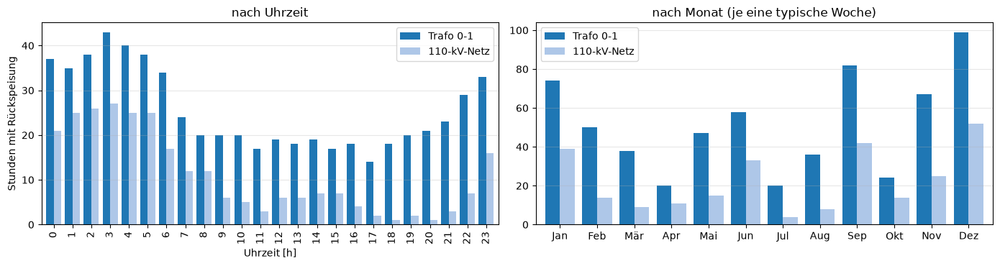

In [168]:
info = r.info
rueck = pd.DataFrame({"Trafo 0-1": P0["Trafo 0-1"] < -SCHWELLE, "110-kV-Netz": P0["110-kV-Netz"] < -SCHWELLE})
monate = list(dict.fromkeys(info["month"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
rueck.groupby(rueck.index.hour).sum().plot.bar(ax=axes[0], width=0.8)
axes[0].set_xlabel("Uhrzeit [h]")
axes[0].set_ylabel("Stunden mit Rückspeisung")
axes[0].set_title("nach Uhrzeit")
rueck.groupby(info["month"].to_numpy()).sum().reindex(monate).plot.bar(ax=axes[1], width=0.8)
axes[1].set_xticklabels([Month[m].label[:3] for m in monate], rotation=0)
axes[1].set_xlabel("")
axes[1].set_title("nach Monat (je eine typische Woche)")
for ax in axes:
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

**Auslösende Bedingungen:** Trafo 0-1 kehrt sich um, wenn der Windpark mehr einspeist, als Abgang 1 (Bus 1 bis Bus 11) verbraucht. Die Netzkuppelstelle kehrt sich um, wenn Windpark und PV-Anlage zusammen mehr einspeisen, als das ganze Netz verbraucht. Die gestrichelte Linie markiert Erzeugung = Last; jeder Punkt ist eine Stunde.

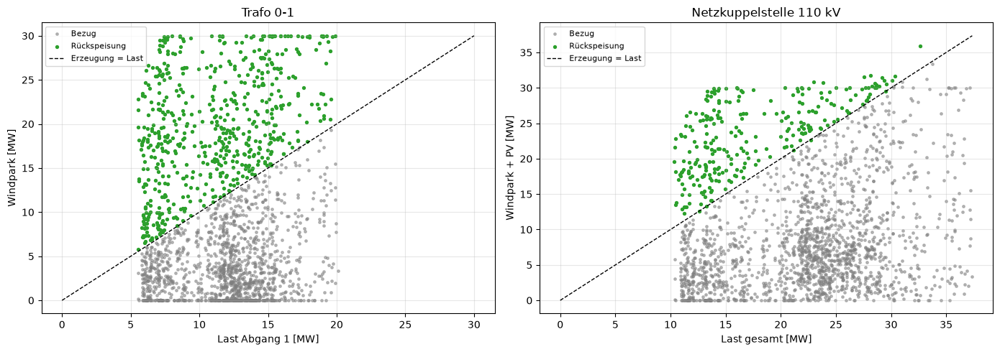

,Stunden,Wind im Mittel [MW],PV im Mittel [MW],Last gesamt im Mittel [MW],Anteil nachts (22–6 Uhr),Anteil Wochenende
Rückspeisung Trafo 0-1,615.00,19.41,0.71,20.57,0.48,0.31
Rückspeisung 110 kV,266.00,22.72,0.62,17.40,0.65,0.36
alle Stunden,2016.00,8.62,1.40,22.01,0.33,0.29


In [169]:
bus_der_last = basis.net.load.set_index("name")["bus"].map(basis.net.bus["name"])
abgang1 = [l for l, b in bus_der_last.items() if b in [f"Bus {i}" for i in range(1, 12)]]
last_abgang1 = r.load_p_mw[abgang1].sum(axis=1)
last_gesamt = r.load_p_mw.sum(axis=1)
wind, pv = r.sgen_p_mw["Windpark"], r.sgen_p_mw["PV-Freifläche"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, y, umkehr, titel, xl, yl in (
        (axes[0], last_abgang1, wind, rueck["Trafo 0-1"], "Trafo 0-1", "Last Abgang 1 [MW]", "Windpark [MW]"),
        (axes[1], last_gesamt, wind + pv, rueck["110-kV-Netz"], "Netzkuppelstelle 110 kV", "Last gesamt [MW]", "Windpark + PV [MW]")):
    ax.scatter(x[~umkehr], y[~umkehr], s=6, color="tab:gray", alpha=0.5, label="Bezug")
    ax.scatter(x[umkehr], y[umkehr], s=8, color="tab:green", label="Rückspeisung")
    m = max(x.max(), y.max())
    ax.plot([0, m], [0, m], "k--", lw=1, label="Erzeugung = Last")
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_title(titel)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

bedingungen = pd.DataFrame({
    titel: {"Stunden": int(u.sum()), "Wind im Mittel [MW]": wind[u].mean(), "PV im Mittel [MW]": pv[u].mean(),
            "Last gesamt im Mittel [MW]": last_gesamt[u].mean(), "Anteil nachts (22–6 Uhr)": (u & ((u.index.hour >= 22) | (u.index.hour < 6))).sum() / max(u.sum(), 1),
            "Anteil Wochenende": (u & (u.index.dayofweek >= 5)).sum() / max(u.sum(), 1)}
    for titel, u in (("Rückspeisung Trafo 0-1", rueck["Trafo 0-1"]), ("Rückspeisung 110 kV", rueck["110-kV-Netz"]),
                     ("alle Stunden", pd.Series(True, index=rueck.index)))})
plots.table(bedingungen.T, decimals=2)

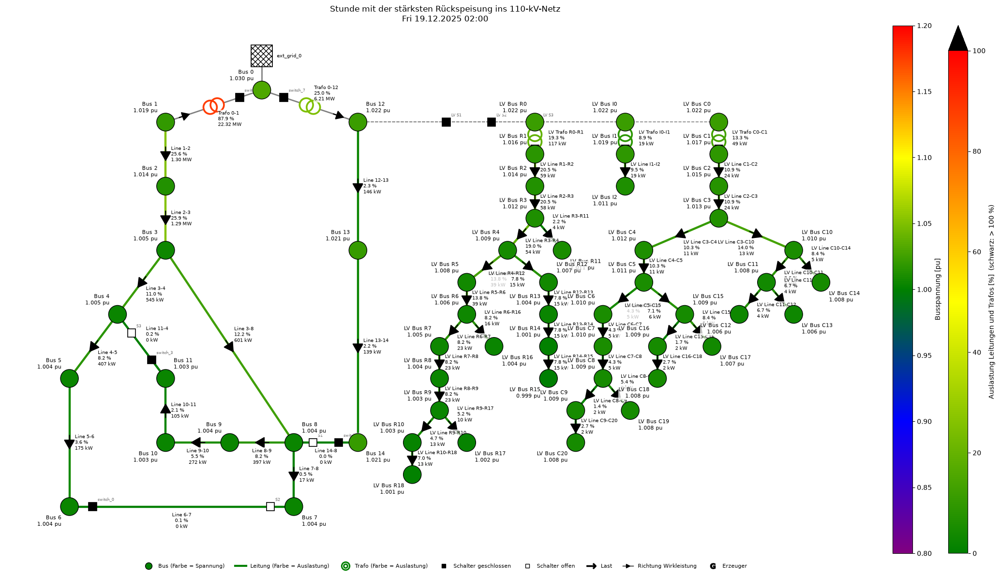

In [170]:
normal.createDiagram(Diagram.NETWORK, time=[h_rueck], elements=False, title="Stunde mit der stärksten Rückspeisung ins 110-kV-Netz")

**Ergebnis Normalzustand:**

- **Wo:** Im MS-Netz kehrt sich der Leistungsfluss nur an zwei Stellen um: an **Trafo 0-1** (615 von 2016 Stunden, bis 22,5 MW) und an der **Netzkuppelstelle zum 110-kV-Netz** (266 Stunden, bis 16,1 MW). Alle MS-Leitungen und Trafo 0-12 behalten immer ihre Richtung. **Im Ortsnetz** kehren sich Ortsnetztrafo R und alle Leitungen des Wohngebiets um, in 362 bis 391 Stunden (Abschnitt 9). Industrie- und Gewerbenetz haben keine Erzeuger und beziehen immer.
- **Warum dort:** Windpark und PV-Anlage speisen direkt an den Trafo-Sammelschienen ein. Ein Überschuss fließt sofort über den Trafo ab und läuft nie durch die Abgänge. Die PV-Haushalte speisen dagegen an jedem Bus des Wohngebiets ein; ihr Überschuss fließt durch alle Leitungen zurück zur Sammelschiene und über Ortsnetztrafo R ins MS-Netz.
- **Auslöser im MS-Netz:** Die Umkehr wird praktisch nur durch **Wind** ausgelöst. In den Stunden mit Rückspeisung speist der Windpark im Mittel 19 MW (Trafo 0-1) bzw. 23 MW (110 kV) ein, sonst im Mittel knapp 9 MW. Die PV-Anlage liegt in diesen Stunden sogar unter ihrem Mittelwert (0,6 bis 0,7 MW gegenüber 1,4 MW). Die Regel lässt sich direkt im Streudiagramm ablesen:
  - Trafo 0-1 speist zurück, sobald der Windpark mehr einspeist, als Abgang 1 verbraucht.
  - Das 110-kV-Netz bekommt Leistung zurück, sobald Wind und PV zusammen mehr liefern, als das ganze Netz verbraucht.
- **Wann:** Rückspeisung ins 110-kV-Netz tritt vor allem **nachts** auf (65 % der Stunden zwischen 22 und 6 Uhr), wenn die Last niedrig ist, und häufiger am Wochenende. Nach Monaten ist sie in den windreichen Wochen am häufigsten (Dezember, September, Januar) und im Juli und April am seltensten. Weil je Monat nur eine typische Woche gerechnet wird, spiegelt das eher das Wetter dieser einzelnen Woche als eine Jahreszeit. Die Rückspeisung aus dem Wohngebiet liegt dagegen **mittags** (9 bis 17 Uhr) und von März bis September.
- **Die PV-Freiflächenanlage allein reicht nie:** 10 MWp an Bus 12 liegen mittags immer unter der Last von Abgang 2 und des Netzes, deshalb kehrt sich Trafo 0-12 nie um.

## 4 Alle Schalterstellungen: Änderung der Leistungsflüsse

Die acht Schaltzustände (S1, S2, S3 jeweils offen oder geschlossen) werden als feste Betriebszustände über 12 Wochen gerechnet, wie in Teil 1 und Teil 3b.

In [171]:
alle = sz.zeitreihe_alle(basis, prefix="w4_t5", controllers=lv_regler(basis.net))
P = {k: fluesse(s) for k, s in alle.items()}
spalten = {k: sz.label(k, kurz=True) for k in alle}
elemente = [c for c in P["000"] if c.startswith(("Line", "Trafo", "LV Trafo")) or c == "110-kV-Netz"]
print(len(alle), "Schaltzustände;", len(elemente), "Elemente (MS-Leitungen, alle Trafos, Netzkuppelstelle)")

Simulation 'w4_t5_000': unverändert seit dem Lauf vom 2026-11-08T23:06:34 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_001': unverändert seit dem Lauf vom 2026-11-08T23:08:33 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_010': unverändert seit dem Lauf vom 2026-11-08T23:18:41 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_011': unverändert seit dem Lauf vom 2026-11-08T23:20:01 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_100': unverändert seit dem Lauf vom 2026-11-08T23:21:14 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_101': unverändert seit dem Lauf vom 2026-11-08T23:22:26 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_110': unverändert seit dem Lauf vom 2026-11-08T23:23:37 – gespeicherte Ergebnisse gelade

**Mittlere Änderung des Wirkleistungsflusses gegenüber dem Normalzustand (alle Schalter offen)** in MW, gemittelt über alle 2016 Stunden. Das Vorzeichen bezieht sich auf die Richtung des Ergebnisfelds (Abschnitt 2): Ein positiver Wert heißt, der Fluss in Richtung `from_bus` → `to_bus` bzw. OS → US nimmt zu. Die Leitungen mit S1–S3 (Line 14-8, 6-7, 11-4) führen im Normalzustand keine Leistung; bei ihnen ist die Änderung der Fluss selbst.

In [172]:
delta_mittel = pd.DataFrame({spalten[k]: (P[k][elemente] - P["000"][elemente]).mean() for k in alle if k != "000"})
plots.table(delta_mittel, decimals=3, cmap="RdBu_r", vmin=-1.5, vmax=1.5)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.001,-0.000,-0.001,-0.299,-0.279,-0.303,-0.285
Line 2-3,-0.001,-0.000,-0.001,-0.296,-0.277,-0.300,-0.283
Line 3-4,0.365,0.010,0.301,-0.000,0.272,-0.056,0.187
Line 4-5,0.000,0.010,-0.129,-0.000,-0.000,-0.056,-0.166
Line 5-6,0.000,0.010,-0.129,-0.000,-0.000,-0.055,-0.166
Line 7-8,-0.000,0.010,-0.129,-0.000,-0.000,-0.056,-0.166
Line 8-9,-0.365,-0.000,-0.430,-0.000,-0.272,-0.000,-0.353
Line 9-10,-0.365,-0.000,-0.429,-0.000,-0.272,-0.000,-0.353
Line 10-11,-0.365,-0.000,-0.429,-0.000,-0.272,-0.000,-0.353
Line 3-8,-0.366,-0.010,-0.302,-0.292,-0.546,-0.240,-0.467


**Größte Änderung in einer einzelnen Stunde** (Betrag, MW):

In [173]:
delta_max = pd.DataFrame({spalten[k]: (P[k][elemente] - P["000"][elemente]).abs().max() for k in alle if k != "000"})
plots.table(delta_max, decimals=3, cmap="Reds", vmin=0, vmax=5)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,0.002,0.000,0.003,2.333,2.372,2.373,2.380
Line 2-3,0.002,0.000,0.003,2.299,2.322,2.340,2.340
Line 3-4,0.597,0.119,0.519,0.000,1.118,0.570,1.192
Line 4-5,0.000,0.119,0.309,0.000,0.000,0.569,0.567
Line 5-6,0.000,0.119,0.308,0.000,0.000,0.569,0.566
Line 7-8,0.000,0.118,0.307,0.000,0.000,0.568,0.566
Line 8-9,0.595,0.000,0.717,0.000,1.113,0.000,1.047
Line 9-10,0.595,0.000,0.716,0.000,1.113,0.000,1.046
Line 10-11,0.594,0.000,0.715,0.000,1.114,0.000,1.047
Line 3-8,0.599,0.119,0.521,2.247,1.982,1.728,1.712


**Stunden mit anderer Flussrichtung als im Normalzustand** (beide Werte |P| ≥ 1 kW, Vorzeichen verschieden). Die drei Leitungen mit S1–S3 fehlen hier, weil sie im Normalzustand keine Leistung führen:

In [174]:
def richtungswechsel(Pk, P0):
    beide = (Pk.abs() >= SCHWELLE) & (P0.abs() >= SCHWELLE)
    return (beide & (np.sign(Pk) != np.sign(P0))).sum()

fuehrend = [c for c in elemente if (P["000"][c].abs() >= SCHWELLE).any()]
wechsel = pd.DataFrame({spalten[k]: richtungswechsel(P[k][fuehrend], P["000"][fuehrend]) for k in alle if k != "000"})
plots.table(wechsel.astype(float), decimals=0, cmap="Oranges", vmin=0, vmax=2016)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,0,0,0,0,0,0,0
Line 2-3,0,0,0,0,0,0,0
Line 3-4,0,0,0,0,0,0,0
Line 4-5,0,0,0,0,0,0,0
Line 5-6,0,0,0,0,0,130,226
Line 7-8,0,498,0,0,0,581,212
Line 8-9,0,0,0,0,286,0,298
Line 9-10,465,0,640,0,548,0,638
Line 10-11,2016,0,2016,0,1099,0,1511
Line 3-8,0,0,0,376,438,152,205


**Stunden in Gegenrichtung je Schaltzustand** (bezogen auf die Hauptrichtung im jeweiligen Zustand, wie in Abschnitt 3), dazu die Rückspeisung ins 110-kV-Netz:

In [175]:
gegen = pd.DataFrame({spalten[k]: richtungen(P[k][elemente])["Stunden Gegenrichtung"] for k in alle})
gegen = gegen.loc[(gegen > 0).any(axis=1)]
display(plots.table(gegen.astype(float), decimals=0, cmap="Oranges", vmin=0, vmax=1008))
rueck_alle = pd.DataFrame({spalten[k]: {"Stunden Rückspeisung 110 kV": int((P[k]["110-kV-Netz"] < -SCHWELLE).sum()),
                                         "max. Rückspeisung 110 kV [MW]": float(-P[k]["110-kV-Netz"].min()),
                                         "Stunden Rückspeisung Trafo 0-1": int((P[k]["Trafo 0-1"] < -SCHWELLE).sum()),
                                         "Stunden Rückspeisung Trafo 0-12": int((P[k]["Trafo 0-12"] < -SCHWELLE).sum())}
                           for k in alle})
plots.table(rueck_alle.astype(float), decimals=2)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 5-6,0,0,0,0,0,0,130,226
Line 7-8,0,0,498,0,0,0,581,212
Line 8-9,0,0,0,0,0,286,0,298
Line 9-10,0,465,0,640,0,548,0,638
Line 10-11,0,0,0,0,0,914,0,496
Line 3-8,0,0,0,0,376,438,152,205
Line 12-13,0,0,0,0,515,534,516,530
Line 13-14,0,0,0,0,523,543,528,541
Line 6-7,0,0,776,0,0,0,659,267
Line 11-4,0,0,0,0,0,280,0,26


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Stunden Rückspeisung 110 kV,266.00,266.00,266.00,266.00,263.00,263.00,263.00,263.00
max. Rückspeisung 110 kV [MW],16.11,16.11,16.11,16.11,15.88,15.88,15.88,15.88
Stunden Rückspeisung Trafo 0-1,615.00,615.00,615.00,615.00,613.00,612.00,613.00,612.00
Stunden Rückspeisung Trafo 0-12,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


**Ergebnis aller Schalterstellungen:**

- **Ortsnetz:** In keinem Schaltzustand ändert sich der Fluss an den Ortsnetztrafos (Änderung höchstens 1 kW). Die Rückspeisung aus dem Wohngebiet ist in allen Zuständen gleich (390 Stunden). Die Schalter wirken nur im MS-Netz.
- **S2 und S3 (Maschen in Abgang 1):** Sie verteilen nur die Last innerhalb von Abgang 1 um (im Mittel 0,1 bis 0,4 MW je Leitung). Auf den Trafos und an der Netzkuppelstelle bleibt alles gleich. Die Leitungen am Ende der Stränge erhalten dabei eine neue Richtung:
  - Mit geschlossenem S3 wird Bus 11 über Line 11-4 versorgt, und Line 10-11 läuft in allen 2016 Stunden andersherum (von Bus 11 zu Bus 10).
  - Line 9-10 dreht in 465 Stunden.
  - Mit S2 dreht Line 7-8 in 498 Stunden.
- **S1 (Kupplung der Abgänge) erzeugt Lastflussumkehr auf MS-Leitungen.** Über S1 wird im Mittel etwa 0,3 MW von Trafo 0-1 auf Trafo 0-12 verlagert, in einzelnen Stunden bis 2,3 MW. Die Richtung auf der Kupplung Line 14-8 hängt vom Wind ab:
  - **wenig Wind:** Abgang 2 stützt Abgang 1, die Leistung fließt von Bus 14 zu Bus 8.
  - **viel Wind** (in rund 665 Stunden, im Mittel 18,5 MW Wind): Der Windpark drückt Leistung über Abgang 1 und S1 in Abgang 2. Line 14-8, Line 13-14 und Line 12-13 kehren sich dann um (515 bis 543 Stunden). In fast allen dieser Stunden speist auch Trafo 0-1 zurück.
  - **mittags mit PV und wenig Wind:** Ein zweites Muster betrifft Line 3-8 (376 Stunden, im Mittel 3,9 MW PV und unter 1 MW Wind). Ohne Wind muss Trafo 0-1 ganz Abgang 1 versorgen, während Abgang 2 durch die PV-Anlage entlastet ist. Über S1 übernimmt Abgang 2 dann Bus 8 bis 11 und zusätzlich einen Teil von Bus 3: Line 3-8 läuft von Bus 8 zu Bus 3.
- **Netzkuppelstelle:** Mit S1 sinken die Rückspeisestunden leicht (266 → 263), weil Abgang 2 einen Teil des Windstroms abnimmt. Die Verluste steigen.
- **Erste Folge für die Auslastung:** Mit geschlossenem S1 steigt die höchste MS-Leitungsauslastung auf 98 bis 99,6 % (Line 1-2, 6. Januar, 18 Uhr, 30 MW Wind). Ein Teil des Windstroms läuft über Line 1-2 und S1 in Abgang 2. In der Untersuchung der Folgen ist das genauer anzusehen.

## 5 Folgen für Spannungen und Auslastungen

Alle Werte als **Differenz gegenüber dem Normalzustand** (alle Schalter offen), jeweils für die niedrigste, die mittlere und die höchste Spannung bzw. Auslastung über 12 Wochen. Spannungen in Prozentpunkten (0,01 pu = 1 Prozentpunkt), Auslastungen in Prozentpunkten der Bemessungsgröße.

Zuerst die wichtigsten Kennwerte je Schaltzustand als absolute Werte:

In [176]:
k_werte, _ = bw.kennwerte({spalten[k]: s for k, s in alle.items()})
plots.table(k_werte[["U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]", "Stunden U < 0,95 MS", "Leitung max MS [%]",
                     "Leitung max NS [%]", "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]", "Verluste [MWh]"]].astype(float).T, decimals=3)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
U min MS [pu],0.951,0.952,0.951,0.953,0.974,0.974,0.976,0.976
U max MS [pu],1.025,1.025,1.025,1.025,1.030,1.030,1.030,1.030
U min NS [pu],0.950,0.950,0.950,0.950,0.950,0.950,0.950,0.950
U max NS [pu],1.050,1.050,1.050,1.050,1.050,1.050,1.050,1.050
"Stunden U < 0,95 MS",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Leitung max MS [%],78.491,78.436,78.489,78.416,98.078,99.596,98.508,99.568
Leitung max NS [%],78.498,78.498,78.498,78.498,78.376,78.368,78.372,78.368
Trafo max HS/MS [%],88.512,88.513,88.512,88.513,78.542,78.247,78.394,78.214
Ortsnetztrafo max [%],75.331,75.331,75.331,75.331,75.208,75.200,75.204,75.199
Verluste [MWh],150.223,148.470,150.162,148.179,183.087,184.506,183.633,184.023


### 5.1 Spannungen an allen Bussen

Alle MS-Busse und alle NS-Busse des Ortsnetzes:

In [177]:
g = lvnetz.bus_groups(basis.net)
ALLE_BUSSE = MS_BUSSE + list(g["NS"])
U = {k: s.results.vm_pu[ALLE_BUSSE] for k, s in alle.items()}

def differenz(werte, statistik, faktor=1.0):
    """Differenz der Statistik (min/mean/max über die Zeit) gegenüber dem Normalzustand, mal faktor."""
    ref = getattr(werte["000"], statistik)()
    return pd.DataFrame({spalten[k]: (getattr(werte[k], statistik)() - ref) * faktor for k in alle if k != "000"})

for stat, titel in (("min", "niedrigste Spannung"), ("mean", "mittlere Spannung"), ("max", "höchste Spannung")):
    print(f"Änderung der {titel} gegenüber dem Normalzustand [Prozentpunkte]")
    display(plots.table(differenz(U, stat, 100), decimals=2, cmap="RdBu", vmin=-3, vmax=3))

Änderung der niedrigste Spannung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus 1,0.00,0.00,0.00,0.26,0.25,0.26,0.26
Bus 2,0.00,0.00,0.01,1.02,1.01,1.03,1.02
Bus 3,0.01,0.00,0.01,2.18,2.16,2.21,2.18
Bus 4,-0.06,-0.00,-0.04,2.18,2.15,2.24,2.20
Bus 5,-0.06,-0.00,-0.02,2.18,2.15,2.28,2.24
Bus 6,-0.06,-0.00,0.04,2.19,2.16,2.36,2.35
Bus 7,0.15,0.00,0.06,2.50,2.52,2.38,2.37
Bus 8,0.15,0.00,0.13,2.50,2.52,2.47,2.49
Bus 9,0.19,0.00,0.17,2.50,2.53,2.47,2.51
Bus 10,0.27,0.00,0.27,2.51,2.55,2.47,2.56


Änderung der mittlere Spannung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus 1,0.00,0.00,0.00,0.28,0.28,0.28,0.28
Bus 2,0.00,0.00,0.00,0.65,0.65,0.66,0.65
Bus 3,0.00,0.00,0.00,1.25,1.24,1.26,1.25
Bus 4,-0.04,-0.00,-0.03,1.25,1.23,1.28,1.25
Bus 5,-0.04,-0.01,-0.02,1.25,1.23,1.29,1.27
Bus 6,-0.04,-0.01,0.01,1.25,1.23,1.33,1.33
Bus 7,0.09,0.02,0.05,1.42,1.44,1.37,1.37
Bus 8,0.09,0.01,0.08,1.42,1.44,1.41,1.43
Bus 9,0.11,0.01,0.10,1.42,1.45,1.41,1.44
Bus 10,0.16,0.01,0.16,1.42,1.46,1.41,1.47


Änderung der höchste Spannung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus 1,0.00,0.00,0.00,0.49,0.51,0.50,0.51
Bus 2,0.00,0.00,0.00,0.58,0.59,0.59,0.60
Bus 3,0.00,0.00,0.00,0.78,0.79,0.79,0.80
Bus 4,-0.02,-0.00,-0.01,0.78,0.78,0.80,0.80
Bus 5,-0.02,-0.00,-0.01,0.78,0.78,0.81,0.81
Bus 6,-0.02,-0.00,0.01,0.78,0.78,0.82,0.83
Bus 7,0.04,0.00,0.01,0.85,0.87,0.83,0.84
Bus 8,0.04,0.00,0.03,0.85,0.87,0.85,0.87
Bus 9,0.04,0.00,0.04,0.85,0.87,0.85,0.87
Bus 10,0.07,0.00,0.06,0.85,0.88,0.85,0.89


**Ergebnis Spannungen:**

- **S2 und S3** ändern die Spannungen um höchstens 0,3 Prozentpunkte:
  - S3 hebt Bus 7 bis 11 leicht an (an Bus 11 bis +0,31 Prozentpunkte bei der niedrigsten Spannung) und senkt Bus 4 bis 6 minimal.
  - S2 wirkt praktisch nicht.
  - Abgang 2 und das Ortsnetz bleiben unverändert.
- **S1** verschiebt die Spannung zwischen den Abgängen:
  - **Abgang 1 steigt:** Die niedrigste Spannung an Bus 3 bis 11 steigt um 2,2 bis 2,6 Prozentpunkte, die mittlere um 1,2 bis 1,5. Die niedrigste MS-Spannung im ganzen Netz steigt von 0,951 auf 0,974 bis 0,976 pu.
  - **Abgang 2 sinkt:** Bus 12 fällt bei der niedrigsten Spannung um 1,0 Prozentpunkte, Bus 14 um 1,9. Abgang 2 versorgt über S1 einen Teil von Abgang 1 mit.
  - **Höchstwert:** Die höchste MS-Spannung steigt leicht (1,025 → 1,030 pu), weil der Windpark bei Rückspeisung über S1 auch Abgang 2 anhebt.
- **Ortsnetz:** Die Sammelschienen folgen Bus 12 und liegen mit S1 im Mittel 0,2 bis 0,3 Prozentpunkte tiefer, in einzelnen Stunden bis 0,7. An den Strangenden ändert sich die niedrigste Spannung trotzdem kaum, weil die rONT den Unterschied ausgleichen (Abschnitt 6). Die höchste Spannung an den Sammelschienen R1 und C1 steigt um 0,7 bis 0,8 Prozentpunkte; das passiert in Stunden, in denen der rONT nach oben stuft. Die höchste NS-Spannung bleibt in allen Zuständen bei 1,050 pu (Strangende im Wohngebiet bei Rückspeisung), das Planungsband wird nicht verletzt.

### 5.2 Auslastung aller Leitungen und Trafos

Alle MS- und NS-Leitungen und alle Trafos:

In [178]:
ALLE_LEITUNGEN = list(normal.results.line_loading.columns)
TRAFOS = list(normal.results.trafo_loading.columns)
A = {k: pd.concat([s.results.line_loading[ALLE_LEITUNGEN], s.results.trafo_loading[TRAFOS]], axis=1) for k, s in alle.items()}
for stat, titel in (("mean", "mittlere Auslastung"), ("max", "höchste Auslastung")):
    print(f"Änderung der {titel} gegenüber dem Normalzustand [Prozentpunkte]")
    display(plots.table(differenz(A, stat), decimals=1, cmap="RdBu_r", vmin=-20, vmax=20))

Änderung der mittlere Auslastung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.0,-0.0,-0.0,-5.4,-4.9,-5.4,-5.0
Line 2-3,-0.0,-0.0,-0.0,-5.5,-5.1,-5.6,-5.2
Line 3-4,7.7,0.3,6.4,-0.3,5.4,-1.3,3.9
Line 4-5,0.0,0.3,-2.6,-0.2,-0.2,-1.2,-3.5
Line 5-6,0.0,0.3,-2.6,-0.1,-0.1,-0.4,-2.8
Line 7-8,-0.0,0.2,2.5,-0.0,-0.0,4.3,4.4
Line 8-9,-7.7,-0.0,-9.0,-0.2,-2.1,-0.2,-4.3
Line 9-10,-7.0,-0.0,-7.8,-0.1,-0.8,-0.1,-3.0
Line 10-11,1.0,-0.0,2.2,-0.1,2.7,-0.1,2.0
Line 3-8,-7.8,-0.3,-6.5,-1.8,-8.3,-3.0,-7.9


Änderung der höchste Auslastung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.1,-0.0,-0.1,20.0,21.5,20.4,21.5
Line 2-3,-0.1,-0.0,-0.1,19.4,20.9,19.8,20.9
Line 3-4,11.9,-1.7,8.6,-0.9,15.3,-0.1,14.4
Line 4-5,0.0,-1.7,-6.6,-0.6,-0.6,1.0,-5.5
Line 5-6,0.0,-1.4,-6.4,-0.3,-0.3,4.7,-2.2
Line 7-8,-0.0,0.3,5.2,-0.0,-0.0,10.9,10.0
Line 8-9,-12.7,-0.0,-13.5,-0.6,-1.1,-0.6,-4.6
Line 9-10,-12.0,0.0,-14.6,-0.5,2.7,-0.5,-1.5
Line 10-11,1.8,0.0,2.6,-0.2,14.7,-0.2,12.3
Line 3-8,-13.0,0.3,-10.3,31.8,9.2,20.9,6.8


**Höchste Auslastung je Schaltzustand** (absolute Werte in %):

In [179]:
plots.table(pd.DataFrame({spalten[k]: A[k].max() for k in alle}), decimals=1, cmap="YlOrRd", vmin=0, vmax=100)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,78.1,78.0,78.1,78.0,98.1,99.6,98.5,99.6
Line 2-3,78.5,78.4,78.5,78.4,97.9,99.4,98.3,99.4
Line 3-4,36.5,48.4,34.8,45.1,35.6,51.8,36.4,50.9
Line 4-5,27.3,27.3,25.6,20.7,26.6,26.6,28.3,21.8
Line 5-6,11.8,11.8,10.4,5.3,11.5,11.5,16.5,9.6
Line 7-8,1.8,1.8,2.2,7.1,1.8,1.8,12.7,11.9
Line 8-9,24.6,11.8,24.6,11.0,23.9,23.5,24.0,20.0
Line 9-10,17.7,5.8,17.8,3.1,17.3,20.4,17.3,16.3
Line 10-11,7.1,8.8,7.1,9.6,6.9,21.8,6.9,19.4
Line 3-8,36.3,23.2,36.5,26.0,68.1,45.4,57.1,43.0


**Ergebnis Auslastungen:**

- **S3** verteilt die Last in Abgang 1 um: Line 8-9 und 9-10 werden um 12 bis 15 Prozentpunkte entlastet (höchste Auslastung), Line 3-4 und die Masche Line 11-4 übernehmen entsprechend mehr. **S2** ändert nur wenig (höchstens 3 Prozentpunkte). Beide senken die Verluste leicht (bis −1,4 %).
- **S1** ist der einzige Zustand mit großen Änderungen:
  - **110/20-kV-Trafos:** Die höchste Auslastung von Trafo 0-1 sinkt um 10 Prozentpunkte (88,5 → 78,5 %), Trafo 0-12 steigt um 5,7 Prozentpunkte. Die beiden Trafos teilen sich die Last gleichmäßiger.
  - **Kupplung und Abgang 2:** Line 14-8 trägt jetzt bis zu 44 %. Line 12-13 und 13-14 steigen um rund 35 Prozentpunkte (von 8 auf über 40 %) und im Mittel um 15 Prozentpunkte, weil über sie Leistung in beide Richtungen fließt (Abschnitt 4).
  - **Line 1-2 und 2-3:** Im Mittel werden sie entlastet (−5 Prozentpunkte), in einzelnen Stunden aber deutlich stärker belastet (+20 Prozentpunkte, bis 99,6 %). Das passiert bei viel Wind: Der Windstrom läuft dann über Line 1-2 durch Abgang 1 und über S1 in Abgang 2. Damit wird Line 1-2 mit S1 bei Starkwind zum Engpass.
  - **Line 3-8:** Mit S1 allein steigt sie um 32 Prozentpunkte (36 → 68 %). Schließt man zusätzlich S3, sind es nur 9 Prozentpunkte, weil sich die Leistung auf die Masche verteilt.
  - **Verluste:** Sie steigen mit S1 um 22 % (150,2 → 183 bis 185 MWh), weil Leistung über längere Wege fließt.
- **Ortsnetz:** Die Auslastung der Ortsnetztrafos und NS-Leitungen ändert sich in keinem Zustand um mehr als 0,2 Prozentpunkte.

## 6 Folgen für die rONT-Regelung

### 6.1 Stufenstellungen je Schaltzustand

Stunden, in denen jeder Ortsnetztrafo in der jeweiligen Stufe steht (`tap_pos`; −1 bzw. −2 heben die NS-Spannung um eine bzw. zwei Stufen an, +1 bzw. +2 senken sie), und die Zahl der Stufenschritte in 12 Wochen:

In [180]:
ONT = {"R": "LV Trafo R0-R1", "I": "LV Trafo I0-I1", "C": "LV Trafo C0-C1"}
TAP = {k: s.results.tap_pos[list(ONT.values())] for k, s in alle.items()}

zeilen = {}
for k in alle:
    for x, t in ONT.items():
        for stufe in range(-2, 3):
            zeilen.setdefault((t, f"Stufe {stufe:+d}" if stufe else "Stufe 0"), {})[spalten[k]] = int((TAP[k][t] == stufe).sum())
        zeilen.setdefault((t, "Stufenschritte"), {})[spalten[k]] = int(TAP[k][t].diff().abs().sum())
stufen_tab = pd.DataFrame(zeilen).T
stufen_tab = stufen_tab.loc[(stufen_tab > 0).any(axis=1)]
plots.table(stufen_tab.astype(float), decimals=0)

### 6.2 Beispieltag

Der Tag, an dem sich die Stufenstellungen der Schaltzustände am stärksten vom Normalzustand unterscheiden. Je Ortsnetztrafo eine Zeile pro Schaltzustand; die Farbe zeigt die Stufe, die Zahl im Feld ebenfalls (leer = Neutralstellung).

Beispieltag: Montag, 06.01. (Tag, an dem sich die Stufenstellungen der Schaltzustände am stärksten unterscheiden)


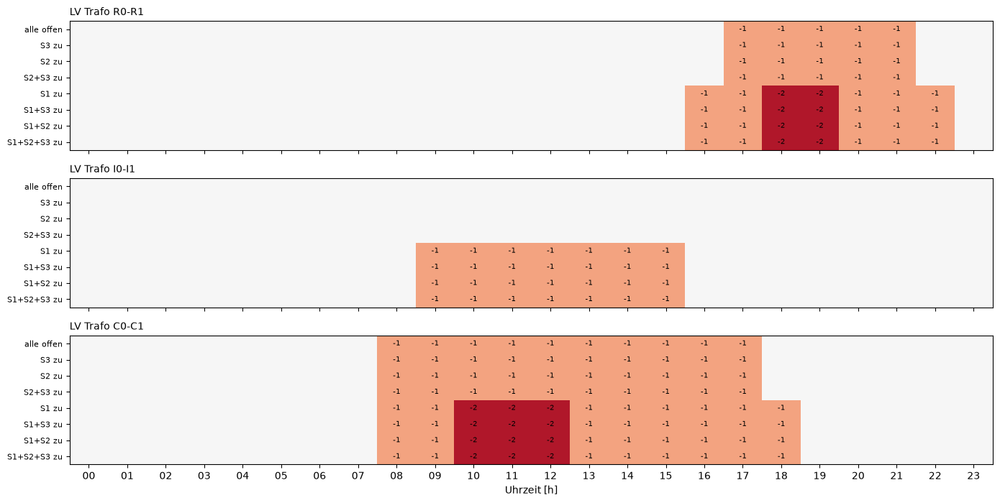

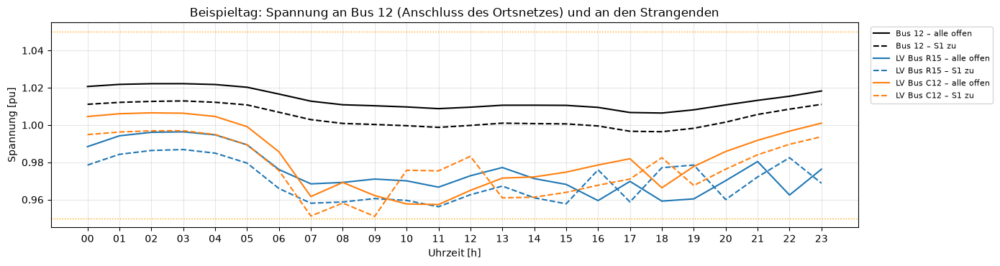

In [181]:
unterschied = sum((TAP[k] - TAP["000"]).abs().sum(axis=1) for k in alle)          # Abweichung aller Zustände vom Normalzustand
tag = unterschied.groupby(unterschied.index.date).sum().idxmax()
stunden = TAP["000"].index[TAP["000"].index.date == tag]
WOCHENTAGE = ["Montag", "Dienstag", "Mittwoch", "Donnerstag", "Freitag", "Samstag", "Sonntag"]
print(f"Beispieltag: {WOCHENTAGE[pd.Timestamp(tag).weekday()]}, {pd.Timestamp(tag):%d.%m.} "
      f"(Tag, an dem sich die Stufenstellungen der Schaltzustände am stärksten unterscheiden)")

fig, axes = plt.subplots(len(ONT), 1, figsize=(14, 2.1 * len(ONT) + 0.8), sharex=True)
for ax, (x, t) in zip(axes, ONT.items()):
    daten = pd.DataFrame({spalten[k]: TAP[k].loc[stunden, t].to_numpy() for k in alle}).T
    ax.imshow(daten, aspect="auto", cmap="RdBu", vmin=-2.5, vmax=2.5)
    for i in range(daten.shape[0]):
        for j in range(daten.shape[1]):
            if daten.iat[i, j] != 0:
                ax.text(j, i, f"{int(daten.iat[i, j]):+d}", ha="center", va="center", fontsize=7)
    ax.set_yticks(range(len(daten)), daten.index, fontsize=8)
    ax.set_title(t, fontsize=10, loc="left")
axes[-1].set_xticks(range(len(stunden)), [f"{h:%H}" for h in stunden])
axes[-1].set_xlabel("Uhrzeit [h]")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 3.8))
for bus, farbe in (("Bus 12", "black"), ("LV Bus R15", "tab:blue"), ("LV Bus C12", "tab:orange")):
    for k, ls in (("000", "-"), ("100", "--")):
        ax.plot(range(len(stunden)), alle[k].results.vm_pu.loc[stunden, bus], ls, color=farbe, label=f"{bus} – {spalten[k]}")
for v in (V_PLAN_MIN, V_PLAN_MAX):
    ax.axhline(v, color="orange", ls=":", lw=1)
ax.set_xticks(range(len(stunden)), [f"{h:%H}" for h in stunden])
ax.set_xlabel("Uhrzeit [h]")
ax.set_ylabel("Spannung [pu]")
ax.set_title("Beispieltag: Spannung an Bus 12 (Anschluss des Ortsnetzes) und an den Strangenden")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3 Schalten die rONT in allen Schaltzuständen zur gleichen Zeit?

Für jeden Ortsnetztrafo und Schaltzustand wird mit dem Normalzustand verglichen:

- **Stunden mit anderer Stufe:** In wie vielen Stunden steht der Trafo in einer anderen Stufe als im Normalzustand?
- **Schaltzeitpunkte gleich:** Anteil der Stufenschritte, die in derselben Stunde auch im Normalzustand stattfinden (bzw. höchstens eine Stunde früher oder später).
- **zusätzliche Stufenschritte:** Stufenschritte ohne Gegenstück im Normalzustand innerhalb von ±1 h (der rONT schaltet, obwohl er im Normalzustand nicht schalten würde).
- **fehlende Stufenschritte:** Stufenschritte des Normalzustands ohne Gegenstück innerhalb von ±1 h.

In [182]:
def schaltzeitpunkte(tap):
    return tap.index[tap.diff().fillna(0) != 0]

zeilen = {}
for x, t in ONT.items():
    ref = schaltzeitpunkte(TAP["000"][t])
    for k in alle:
        if k == "000":
            continue
        z = schaltzeitpunkte(TAP[k][t])
        abstand = np.array([np.abs((ref - h) / pd.Timedelta(hours=1)).min() for h in z]) if len(ref) else np.full(len(z), np.inf)
        rueck = np.array([np.abs((z - h) / pd.Timedelta(hours=1)).min() for h in ref]) if len(z) else np.full(len(ref), np.inf)
        zeilen[(t, spalten[k])] = {
            "Stufenschritte": int(TAP[k][t].diff().abs().sum()),
            "Stufenschritte Normalzustand": int(TAP["000"][t].diff().abs().sum()),
            "Stunden mit anderer Stufe": int((TAP[k][t] != TAP["000"][t]).sum()),
            "Schaltzeitpunkte gleich [%]": 100 * (abstand == 0).mean() if len(abstand) else np.nan,
            "Schaltzeitpunkte ±1 h [%]": 100 * (abstand <= 1).mean() if len(abstand) else np.nan,
            "zusätzliche Stufenschritte": int((abstand > 1).sum()),
            "fehlende Stufenschritte": int((rueck > 1).sum()),
        }
gleichzeitig = pd.DataFrame(zeilen).T
plots.table(gleichzeitig.astype(float), decimals=1)

**Zu welcher Uhrzeit schalten die rONT?** Stufenschritte nach Uhrzeit, Normalzustand und alle Zustände mit S1 zusammen (je Zustand gemittelt):

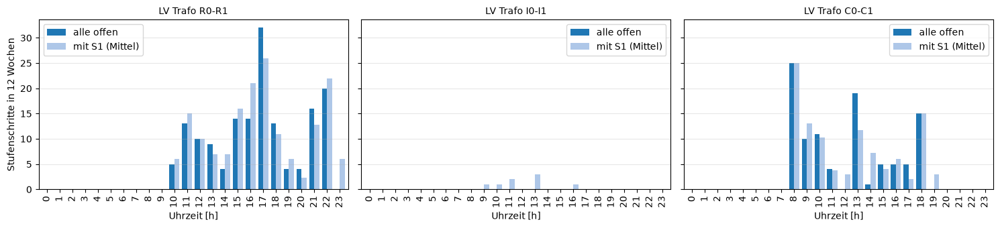

In [183]:
fig, axes = plt.subplots(1, len(ONT), figsize=(15, 3.5), sharey=True)
mit_s1 = [k for k in alle if sz.zustand(k)["S1"]]
for ax, (x, t) in zip(axes, ONT.items()):
    n0 = TAP["000"][t].diff().abs().groupby(TAP["000"].index.hour).sum()
    n1 = sum(TAP[k][t].diff().abs().groupby(TAP[k].index.hour).sum() for k in mit_s1) / len(mit_s1)
    pd.DataFrame({"alle offen": n0, "mit S1 (Mittel)": n1}).plot.bar(ax=ax, width=0.8)
    ax.set_title(t, fontsize=10)
    ax.set_xlabel("Uhrzeit [h]")
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Stufenschritte in 12 Wochen")
plt.tight_layout()
plt.show()

**Ergebnis rONT-Regelung:**

- **S2 und S3:** Die rONT schalten genau wie im Normalzustand, mit denselben Stufen zu denselben Zeitpunkten (100 %). Die Maschen in Abgang 1 wirken nicht bis ins Ortsnetz.
- **Wohngebiet-rONT regelt in beide Richtungen:** Er hebt zur Abendspitze an (Stufe −1 in 161 Stunden) und senkt mittags bei Rückspeisung ab (Stufe +1 in 131, +2 in 9 Stunden). Das ist die Folge der Lastflussumkehr im Wohngebiet (Abschnitt 9).
- **S1:** Alle drei rONT müssen mehr anheben, weil Bus 12 tiefer liegt (Abschnitt 5.1):

| Trafo | alle offen | mit S1 |
|---|---|---|
| R (Wohngebiet) | 158 Stufenschritte; 161 h Stufe −1, 140 h Stufe +1/+2 | 168 Stufenschritte (+6 %); 196 h Stufe −1, 2 h Stufe −2, 135 h Stufe +1/+2 |
| I (Industrie) | schaltet nie | 8 Stufenschritte, 14 Stunden auf −1 |
| C (Gewerbe) | 100 Stufenschritte, 327 h Stufe −1 | 104 Stufenschritte, in 7 Stunden Stufe −2 |

- **Schalten sie zur gleichen Zeit?**
  - **Wohngebiet-rONT:** 71 % der Stufenschritte in derselben Stunde wie im Normalzustand, 93 % innerhalb von ±1 h, 12 zusätzliche Schritte. Die Absenkung am Mittag ist fast unverändert, weil sie vom PV-Überschuss im Wohngebiet abhängt und nicht vom MS-Netz. Die Abweichungen liegen am Abend: Mit S1 schaltet er früher auf −1 und später zurück.
  - **Gewerbe-rONT:** 72 % in derselben Stunde, 89 % innerhalb von ±1 h.
  - **Industrie-rONT:** Er schaltet nur mit S1, und zwar tagsüber.
- **Die rONT untereinander:** Sie schalten zu verschiedenen Zeiten, weil sie den Lastgängen ihrer Teilnetze folgen. Der Gewerbe-rONT hebt an Werktagen tagsüber an. Der Wohngebiet-rONT senkt mittags ab und hebt abends an. Daran ändert S1 nichts, es verlängert nur die Zeiten mit angehobener Stufe.
- **Beispieltag (Montag, 06.01.):** Im Januar speisen die PV-Haushalte kaum zurück. Mit S1 liegt Bus 12 den ganzen Tag etwa 1 Prozentpunkt tiefer, die rONT halten ihre angehobene Stufe länger. Die Strangenden bleiben in beiden Fällen im Planungsband.
- **Bezug zur Lastflussumkehr:** Die Umkehr im MS-Netz (Wind über S1 in Abgang 2) wirkt auf die rONT nur über die Spannung an Bus 12. Die Umkehr im Wohngebiet wirkt direkt: In allen 140 Stunden mit Stufe +1/+2 speist das Wohngebiet zurück.

## 7 Dauerlinien

Wie stark und wie häufig kehrt sich der Fluss um? Die Dauerlinie sortiert die 2016 Stundenwerte des Wirkleistungsflusses absteigend. Der Teil unter der Nulllinie ist die Gegenrichtung; ihre Breite ist die Zahl der Stunden, die Fläche die Energie in Gegenrichtung. Dargestellt sind die Elemente, an denen eine Umkehr auftritt, für vier typische Schaltzustände.

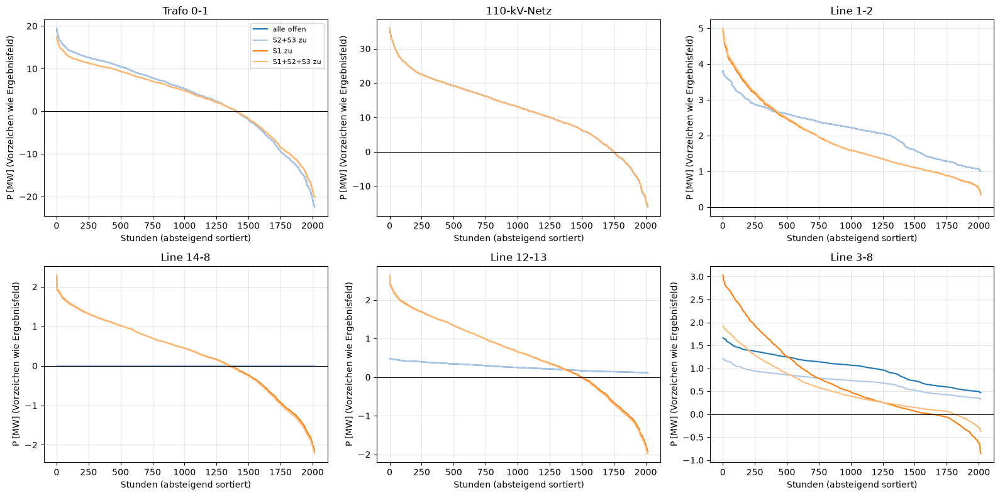

Stunden in Gegenrichtung


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Trafo 0-1,615,615,615,615,613,612,613,612
110-kV-Netz,266,266,266,266,263,263,263,263
Line 1-2,0,0,0,0,0,0,0,0
Line 14-8,0,0,0,0,664,676,663,673
Line 12-13,0,0,0,0,515,534,516,530
Line 3-8,0,0,0,0,376,438,152,205


Energie in Gegenrichtung [MWh]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Trafo 0-1,5154.1,5154.5,5154.1,5154.6,4608.0,4579.6,4599.2,4579.7
110-kV-Netz,1578.8,1578.9,1578.8,1579.0,1546.7,1545.9,1546.2,1545.8
Line 1-2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Line 14-8,0.0,0.0,0.0,0.0,521.6,550.9,530.3,550.7
Line 12-13,0.0,0.0,0.0,0.0,371.1,395.2,378.8,395.3
Line 3-8,0.0,0.0,0.0,0.0,90.3,72.1,23.0,28.7


größter Fluss in Gegenrichtung [MW]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Trafo 0-1,22.46,22.46,22.46,22.46,20.17,20.09,20.13,20.09
110-kV-Netz,16.11,16.11,16.11,16.11,15.88,15.88,15.88,15.88
Line 1-2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Line 14-8,0.00,0.00,0.00,0.00,2.14,2.21,2.18,2.22
Line 12-13,0.00,0.00,0.00,0.00,1.90,1.97,1.94,1.98
Line 3-8,0.00,0.00,0.00,0.00,0.86,0.58,0.42,0.37


In [184]:
DL_ELEMENTE = ["Trafo 0-1", "110-kV-Netz", "Line 1-2", "Line 14-8", "Line 12-13", "Line 3-8"]
DL_ZUSTAENDE = ["000", "011", "100", "111"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, el in zip(axes.flat, DL_ELEMENTE):
    for k in DL_ZUSTAENDE:
        werte = np.sort(P[k][el].to_numpy())[::-1]
        ax.plot(np.arange(1, len(werte) + 1), werte, label=spalten[k])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(el)
    ax.set_xlabel("Stunden (absteigend sortiert)")
    ax.set_ylabel("P [MW] (Vorzeichen wie Ergebnisfeld)")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

zeilen = {}
for el in DL_ELEMENTE:
    for k in alle:
        x = P[k][el]
        haupt = 1 if (x > SCHWELLE).sum() >= (x < -SCHWELLE).sum() else -1
        gegen = x[np.sign(x) == -haupt]
        gegen = gegen[gegen.abs() >= SCHWELLE]
        zeilen.setdefault(el, {})[spalten[k]] = (len(gegen), gegen.abs().sum(), gegen.abs().max() if len(gegen) else 0.0)
for titel, i, nachkomma in (("Stunden in Gegenrichtung", 0, 0), ("Energie in Gegenrichtung [MWh]", 1, 1),
                            ("größter Fluss in Gegenrichtung [MW]", 2, 2)):
    print(titel)
    display(plots.table(pd.DataFrame({el: {z: v[i] for z, v in d.items()} for el, d in zeilen.items()}).T.astype(float), decimals=nachkomma))

**Ergebnis Dauerlinien:**

| Element | Gegenrichtung ohne S1 | Gegenrichtung mit S1 |
|---|---|---|
| Trafo 0-1 | 615 h, 5154 MWh, bis 22,5 MW | 612–613 h, 4580–4608 MWh, bis 20,2 MW |
| 110-kV-Netz | 266 h, 1579 MWh, bis 16,1 MW | 263 h, rund 1546 MWh, bis 15,9 MW |
| Line 14-8 (Kupplung) | – (offen) | 663–676 h, 522–551 MWh, bis 2,2 MW |
| Line 12-13 | keine | 515–534 h, 371–395 MWh, bis 2,0 MW |
| Line 3-8 | keine | 152–438 h, 23–90 MWh, bis 0,9 MW |
| Line 1-2 | keine | keine |
| Ortsnetztrafo R | 390 h, 76 MWh, bis 0,45 MW | unverändert |

- **Häufigkeit:** Trafo 0-1 speist in fast einem Drittel der Stunden zurück, das 110-kV-Netz in 13 %, das Wohngebiet in 19 %. Die Dauerlinien laufen zur Rückspeisung hin steil nach unten: Wenige Stunden mit Starkwind bringen sehr hohe Rückspeisung.
- **Energie:** In 12 Wochen fließen über Trafo 0-1 rund 5,2 GWh zurück, ins 110-kV-Netz 1,6 GWh. Hochgerechnet auf ein Jahr (Faktor 8760 / 2016 ≈ 4,3) sind das etwa 22 bzw. 7 GWh.
- **Wirkung von S1:** S1 senkt die Rückspeisung über Trafo 0-1 um etwa 11 %, weil Abgang 2 einen Teil des Windstroms aufnimmt. Dafür kehren sich die Kupplung und Abgang 2 in etwa einem Viertel bis einem Drittel der Stunden um. Die Flüsse dort sind mit höchstens 2,2 MW klein.
- **Line 1-2** kehrt sich nie um, auch mit S1 nicht. Mit S1 wird ihre Dauerlinie aber steiler: Bei Starkwind trägt sie bis 5 MW (fast 100 %), bei wenig Wind weniger als ohne S1.
- **Line 3-8** kehrt sich mit S1 allein am häufigsten um. Mit S2 kaum noch, weil die Masche über Line 6-7 einen zweiten Weg anbietet.

## 8 Räumliche Darstellung der Flüsse

Netzplan mit Flusspfeilen in zwei Stunden, in denen sich mit geschlossenem S1 Leitungen umkehren, jeweils links ohne und rechts mit S1:

- **viel Wind:** Stunde mit der stärksten Rückspeisung ins 110-kV-Netz
- **viel PV, wenig Wind:** Stunde mit dem stärksten Fluss in Gegenrichtung auf Line 3-8 (mit S1)

viel Wind: 19.12. 02:00 – Wind 29.5 MW, PV 0.0 MW, Last 13.3 MW


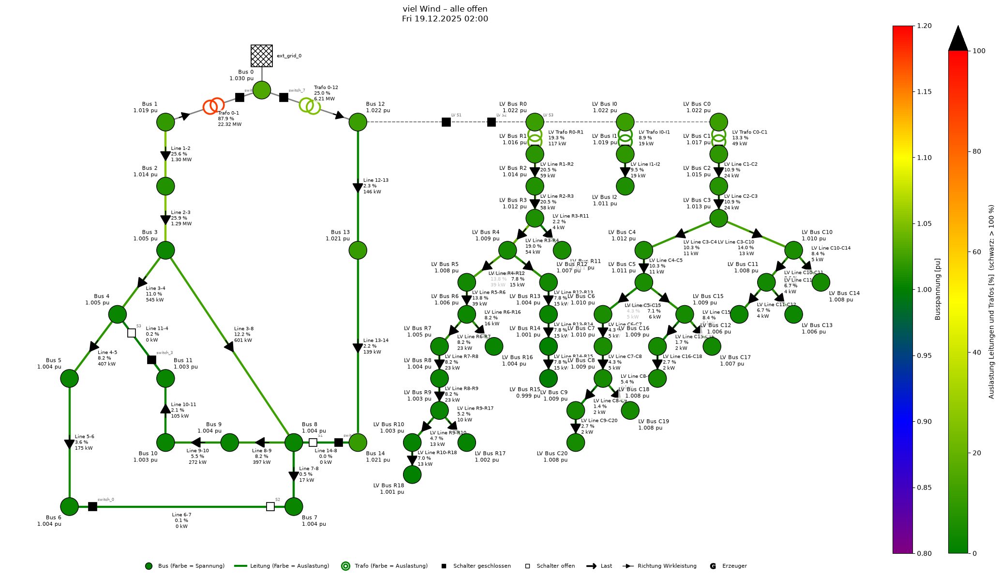

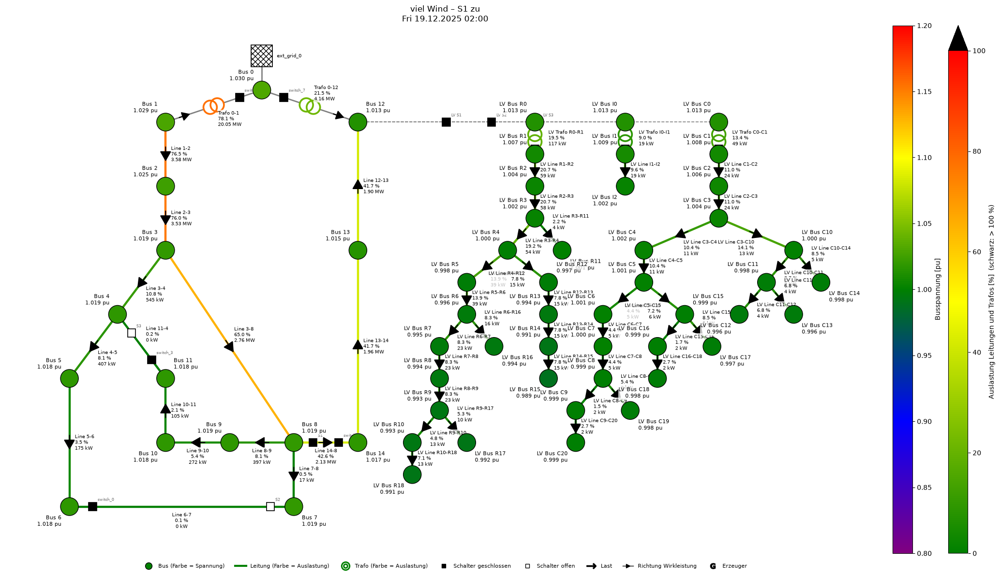

viel PV, wenig Wind: 09.03. 12:00 – Wind 0.0 MW, PV 7.4 MW, Last 31.2 MW


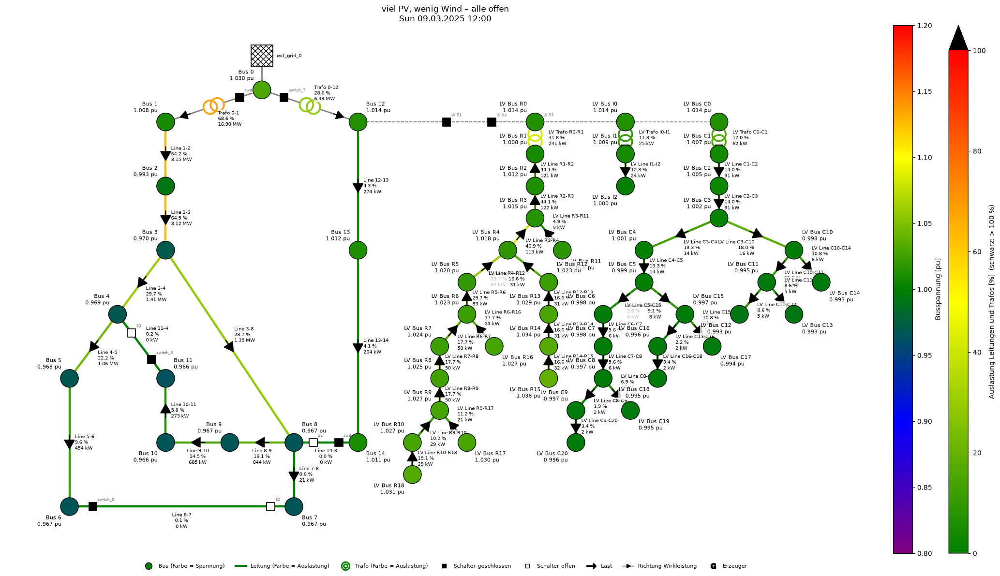

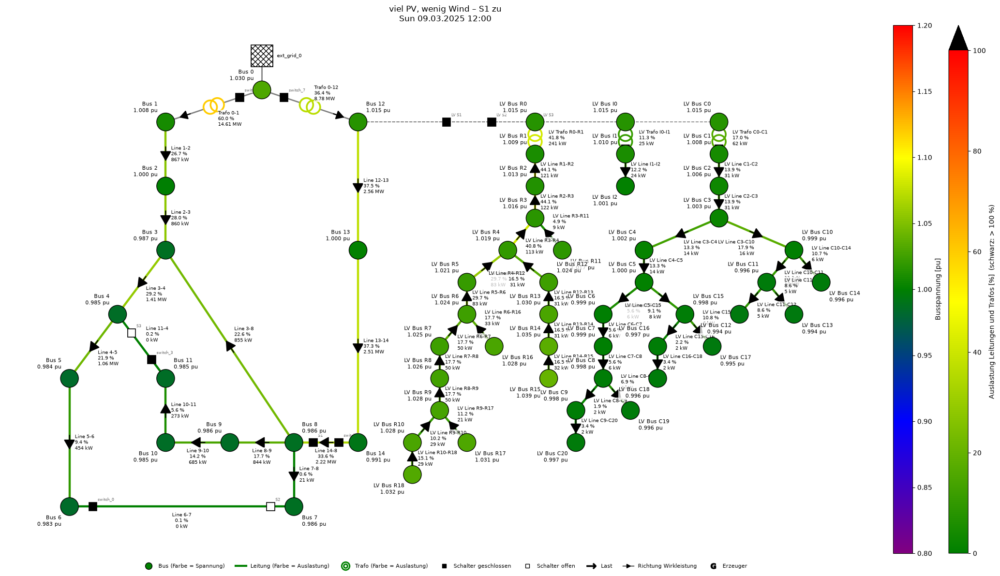

In [185]:
h_wind = P["100"]["110-kV-Netz"].idxmin()
h_pv = P["100"]["Line 3-8"].idxmin()
for titel, h in (("viel Wind", h_wind), ("viel PV, wenig Wind", h_pv)):
    r1 = alle["100"].results
    print(f"{titel}: {h:%d.%m. %H:%M} – Wind {r1.sgen_p_mw.at[h, 'Windpark']:.1f} MW, PV {r1.sgen_p_mw.at[h, 'PV-Freifläche']:.1f} MW, "
          f"Last {r1.load_p_mw.loc[h].sum():.1f} MW")
    for k in ("000", "100"):
        alle[k].createDiagram(Diagram.NETWORK, time=[h], elements=False, title=f"{titel} – {spalten[k]}")

**Was die Netzpläne zeigen:**

- **Viel Wind** (19.12., 2 Uhr, 29,5 MW Wind, 13,3 MW Last):
  - **ohne S1:** Der Windpark versorgt Abgang 1, der Überschuss fließt über Trafo 0-1 zurück ins 110-kV-Netz (Pfeil am Trafo nach oben). Alle Leitungen behalten ihre Richtung.
  - **mit S1:** Ein Teil des Windstroms fließt durch Abgang 1 bis Bus 8 und über S1 weiter in Abgang 2. Die Pfeile auf Line 14-8, 13-14 und 12-13 zeigen jetzt zu Bus 12, Trafo 0-12 wird entlastet.
- **Viel PV, wenig Wind** (09.03., 12 Uhr, 7,4 MW PV, kein Wind, 31,2 MW Last):
  - **ohne S1:** Beide Abgänge werden von ihrem Trafo versorgt.
  - **mit S1:** Abgang 2, durch die PV entlastet, versorgt über S1 Bus 8 bis 11 und über Line 3-8 auch Bus 3 mit. Der Pfeil auf Line 3-8 zeigt zu Bus 3 (0,8 MW). Trafo 0-1 trägt deutlich weniger (60 %), Trafo 0-12 mehr.
- **Folge:** Mit S1 hängt die Flussrichtung im MS-Netz davon ab, an welchem Ende gerade mehr erzeugt wird.

## 9 Rückspeisung im Ortsnetz

Die Haushalte mit PV-Anlage speisen an sonnigen Mittagen mehr ein, als das Wohngebiet verbraucht; der Überschuss fließt über den Ortsnetztrafo ins MS-Netz zurück (`p_hv_mw` < 0). Je Ortsnetztrafo und Schaltzustand: Stunden mit Rückspeisung, größte Rückspeisung und die Stunden, in denen der rONT die Spannung absenkt (Stufe +1 oder +2):

In [186]:
zeilen = {}
for k in alle:
    for x, t in ONT.items():
        p = P[k][t]
        zeilen[(t, spalten[k])] = {"Stunden Rückspeisung": int((p < -SCHWELLE).sum()),
                                   "Energie Rückspeisung [MWh]": float((-p).clip(lower=0).sum()),
                                   "max. Rückspeisung [kW]": float(max(0.0, -p.min()) * 1000),
                                   "Stunden Stufe +1/+2 (senken)": int((TAP[k][t] > 0).sum()),
                                   "Stunden Stufe −1/−2 (anheben)": int((TAP[k][t] < 0).sum())}
plots.table(pd.DataFrame(zeilen).T, decimals=1)

,,Stunden Rückspeisung,Energie Rückspeisung [MWh],max. Rückspeisung [kW],Stunden Stufe +1/+2 (senken),Stunden Stufe −1/−2 (anheben)
LV Trafo R0-R1,alle offen,390.0,75.8,450.5,140.0,161.0
LV Trafo I0-I1,alle offen,0.0,0.0,0.0,0.0,0.0
LV Trafo C0-C1,alle offen,0.0,0.0,0.0,0.0,327.0
LV Trafo R0-R1,S3 zu,390.0,75.8,450.5,140.0,161.0
LV Trafo I0-I1,S3 zu,0.0,0.0,0.0,0.0,0.0
LV Trafo C0-C1,S3 zu,0.0,0.0,0.0,0.0,327.0
LV Trafo R0-R1,S2 zu,390.0,75.8,450.5,140.0,161.0
LV Trafo I0-I1,S2 zu,0.0,0.0,0.0,0.0,0.0
LV Trafo C0-C1,S2 zu,0.0,0.0,0.0,0.0,327.0
LV Trafo R0-R1,S2+S3 zu,390.0,75.8,450.5,140.0,161.0


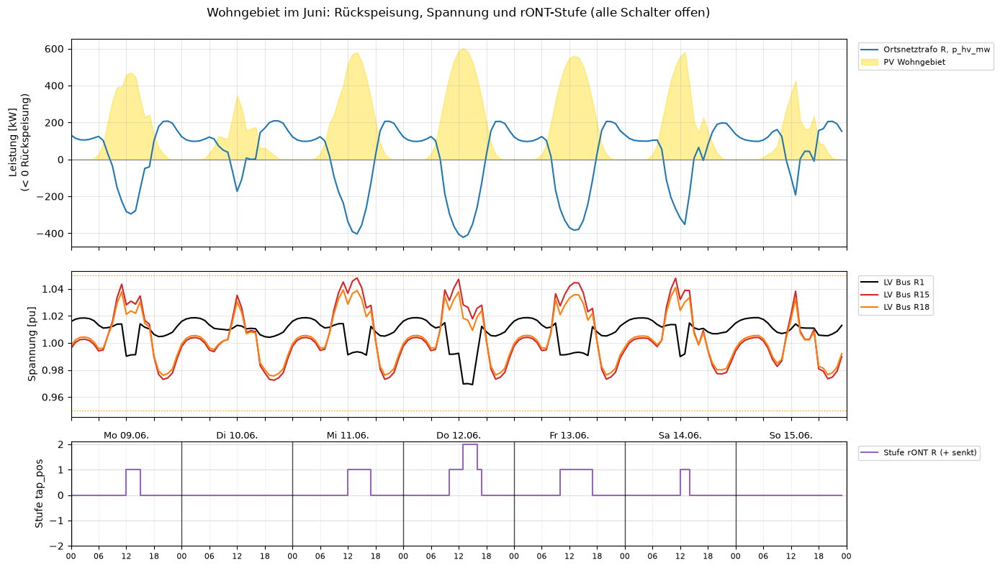

In [187]:
r0 = alle["000"].results
idx = r0.info.index[r0.info["month"] == "JUNE"]
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1.4, 1]})
x = idx
axes[0].plot(x, r0.trafo_p_mw.loc[idx, "LV Trafo R0-R1"] * 1000, color="tab:blue", label="Ortsnetztrafo R, p_hv_mw")
axes[0].fill_between(x, r0.sgen_p_mw.loc[idx, [c for c in r0.sgen_p_mw if c.startswith("LV PV")]].sum(axis=1) * 1000,
                     color="gold", alpha=0.4, label="PV Wohngebiet")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Leistung [kW]\n(< 0 Rückspeisung)")
for bus, farbe in (("LV Bus R1", "black"), ("LV Bus R15", "tab:red"), ("LV Bus R18", "tab:orange")):
    axes[1].plot(x, r0.vm_pu.loc[idx, bus], color=farbe, label=bus)
for v in (V_PLAN_MIN, V_PLAN_MAX):
    axes[1].axhline(v, color="orange", ls=":", lw=1)
axes[1].set_ylabel("Spannung [pu]")
axes[2].step(x, TAP["000"].loc[idx, ONT["R"]], where="post", color="tab:purple", label="Stufe rONT R (+ senkt)")
axes[2].set_yticks(range(-2, 3))
axes[2].set_ylabel("Stufe tap_pos")
axes[0].set_title("Wohngebiet im Juni: Rückspeisung, Spannung und rONT-Stufe (alle Schalter offen)", pad=22)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plots.week_axis(axes[2], idx)
plt.tight_layout()
plt.show()

**Befund Rückspeisung im Ortsnetz:**

- **Wohngebiet:** Ortsnetztrafo R speist in **390 Stunden** ins MS-Netz zurück, zusammen 76 MWh, höchstens **0,45 MW** (72 % der Bemessungsleistung 0,63 MVA). Die Rückspeisung liegt zwischen 9 und 17 Uhr und von März bis September; im Mittel erzeugen die PV-Anlagen dann 0,40 MW bei 0,19 MW Verbrauch. Alle Leitungen des Wohngebiets kehren sich mit um (362 bis 391 Stunden), vom Strangende zur Sammelschiene.
- **Speicher:** In 98 % der Rückspeisestunden sind die Heimspeicher voll (mittlerer Ladezustand 99 %). Sie laden mit dem ersten Überschuss am Vormittag und können die Mittagsspitze nicht mehr aufnehmen.
- **Spannung und rONT:** Bei Rückspeisung steigt die Spannung zum Strangende hin. Der rONT stuft in genau diesen Stunden nach unten (140 Stunden auf +1/+2) und begrenzt die höchste NS-Spannung auf 1,050 pu. Außerhalb der Rückspeisung liegt sie höchstens bei 1,026 pu. Der rONT regelt damit jetzt in beide Richtungen: mittags gegen Überspannung, abends gegen Unterspannung.
- **Schalterstellungen:** Die Rückspeisung aus dem Wohngebiet ist in allen acht Zuständen gleich. Mit S1 liegt Bus 12 etwas tiefer, deshalb braucht der rONT mittags 5 Stunden weniger Absenkung und abends mehr Anhebung.
- **Industrie und Gewerbe:** Ohne eigene Erzeuger beziehen sie immer; der Gewerbe-rONT hebt nur an.

## 10 Zusatz: Ausfall eines 110/20-kV-Transformators

Nicht Teil des Arbeitsauftrags. Was passiert, wenn Trafo 0-1 oder Trafo 0-12 für die ganzen 12 Wochen ausfällt? Drei Varianten je Trafo:

- **S1 offen:** Der Abgang des ausgefallenen Trafos ist vom Netz getrennt. Die Erzeugung an seiner Sammelschiene ist mit abgetrennt und kann nicht einspeisen (Inselbetrieb ist nicht vorgesehen).
- **S1 zu:** Der Abgang wird über S1 aus dem anderen Trafo versorgt. Windpark bzw. PV-Anlage speisen weiter ein, sitzen jetzt aber am **Ende** eines langen Wegs.
- **S1 zu, Erzeuger aus:** wie vorher, aber der Windpark bzw. die PV-Anlage ist abgeschaltet (so sieht es der Backup-Plan aus Teil 4a vor).

In Stunden, in denen der Lastfluss nicht konvergiert, kann das Netz den Betriebspunkt physikalisch nicht halten (Spannungskollaps). Diese Stunden werden gezählt und fehlen in den übrigen Kennwerten.

In [188]:
AUSFALL = {
    "Trafo 0-1 aus · S1 offen": ("Trafo 0-1", False, None),
    "Trafo 0-1 aus · S1 zu": ("Trafo 0-1", True, None),
    "Trafo 0-1 aus · S1 zu · Windpark aus": ("Trafo 0-1", True, "Windpark"),
    "Trafo 0-12 aus · S1 offen": ("Trafo 0-12", False, None),
    "Trafo 0-12 aus · S1 zu": ("Trafo 0-12", True, None),
    "Trafo 0-12 aus · S1 zu · PV aus": ("Trafo 0-12", True, "PV-Freifläche"),
}
ausfall = {}
for i, (titel, (trafo, s1, erzeuger)) in enumerate(AUSFALL.items(), 1):
    s = basis.copy(f"w4_t5_trafoausfall_{i}", overwrite=True)
    s.changeParameter(trafo, "in_service", False)
    if s1:
        s.changeParameter("S1", "closed", True)
    if erzeuger:
        s.changeParameter(erzeuger, "in_service", False)
    s.runSimulation(controllers=lv_regler(s.net))
    ausfall[titel] = s

Hinweis: 11 Busse sind nicht versorgt (z. B. ['Bus 1', 'Bus 2', 'Bus 3', 'Bus 4', 'Bus 5']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Simulation 'w4_t5_trafoausfall_1': unverändert seit dem Lauf vom 2026-11-08T23:30:20 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_trafoausfall_2': unverändert seit dem Lauf vom 2026-11-08T23:31:43 – gespeicherte Ergebnisse geladen (1312 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_trafoausfall_3': unverändert seit dem Lauf vom 2026-11-08T23:33:00 – gespeicherte Ergebnisse geladen (505 von 2016 Lastflüssen konvergiert).
Hinweis: 46 Busse sind nicht versorgt (z. B. ['Bus 12', 'Bus 13', 'Bus 14', 'LV Bus R14', 'LV Bus R15']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Simulation 'w4_t5_trafoausfall_4': unverändert seit dem Lauf vom 2026-11-08T23:33:

In [189]:
def ausfall_kennwerte(s):
    rr = s.results
    ok = rr.converged.astype(bool) if hasattr(rr, "converged") else rr.vm_pu.notna().any(axis=1)
    vm = rr.vm_pu.loc[ok]
    ms = vm[MS_BUSSE]
    ll = rr.line_loading.loc[ok, [c for c in rr.line_loading if c.startswith("Line")]]
    tl = rr.trafo_loading.loc[ok, ["Trafo 0-1", "Trafo 0-12"]]
    return {"Stunden konvergiert": int(ok.sum()),
            "Stunden nicht konvergiert": int((~ok).sum()),
            "Stunden mit nicht versorgten MS-Bussen": int(ms.isna().any(axis=1).sum()),
            "U min MS [pu]": ms.min().min(), "U max MS [pu]": ms.max().max(),
            "Stunden U MS > 1,10 pu": int((ms.max(axis=1) > 1.10).sum()),
            "Stunden U MS < 0,90 pu": int((ms.min(axis=1) < 0.90).sum()),
            "U min NS [pu]": vm[g["NS"]].min().min(), "U max NS [pu]": vm[g["NS"]].max().max(),
            "Leitung max MS [%]": ll.max().max(), "am stärksten belastet": ll.max().idxmax() if ll.size else "",
            "Stunden Leitung MS > 100 %": int((ll.max(axis=1) > 100).sum()),
            "Trafo max HS/MS [%]": tl.max().max(), "Stunden Trafo > 100 %": int((tl.max(axis=1) > 100).sum()),
            "Stunden Rückspeisung 110 kV": int((rr.ext_grid_p_mw.squeeze().loc[ok] < -SCHWELLE).sum())}

a_tab = pd.DataFrame({"Normalzustand": ausfall_kennwerte(normal), **{t: ausfall_kennwerte(s) for t, s in ausfall.items()}})
plots.table(a_tab, decimals=3)

,Normalzustand,Trafo 0-1 aus · S1 offen,Trafo 0-1 aus · S1 zu,Trafo 0-1 aus · S1 zu · Windpark aus,Trafo 0-12 aus · S1 offen,Trafo 0-12 aus · S1 zu,Trafo 0-12 aus · S1 zu · PV aus
Stunden konvergiert,2016,2016,1312,505,2016,691,472
Stunden nicht konvergiert,0,0,704,1511,0,1325,1544
Stunden mit nicht versorgten MS-Bussen,0,2016,0,0,2016,0,0
U min MS [pu],0.950828,1.000900,0.518607,0.541910,0.950828,0.515504,0.551675
U max MS [pu],1.025020,1.024076,1.247369,1.012895,1.025020,1.014231,1.014231
"Stunden U MS > 1,10 pu",0,0,272,0,0,0,0
"Stunden U MS < 0,90 pu",0,0,518,505,0,691,472
U min NS [pu],0.950224,0.950224,0.931828,0.950891,nan,0.396118,0.529499
U max NS [pu],1.049688,1.049688,1.047582,1.009688,nan,0.945068,0.866280
Leitung max MS [%],78.490899,7.952743,382.168622,286.911761,78.490899,316.959053,305.154496


**Trafo 0-1 aus, S1 zu:** Spannung entlang des Wegs vom verbleibenden Trafo bis zum Windpark (Bus 12 → 13 → 14 → 8 → 3 → 2 → 1) und Windleistung in der Woche mit der höchsten Windeinspeisung:

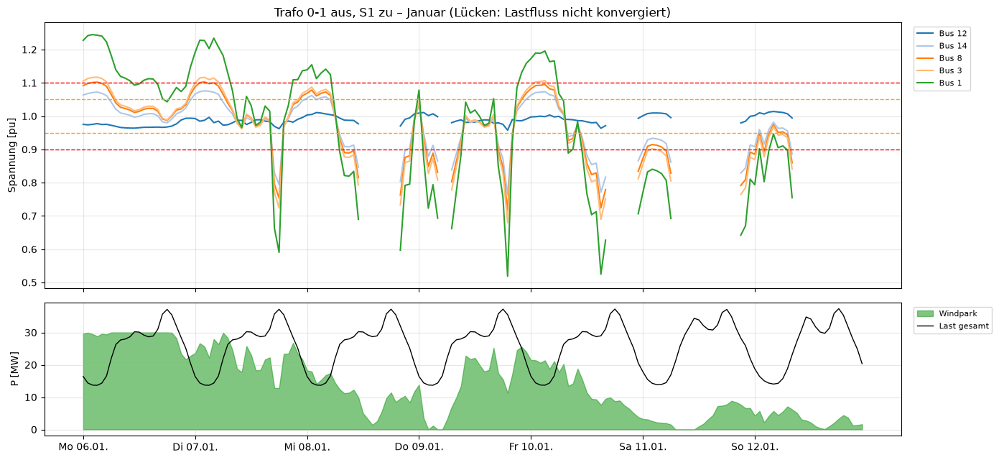

In [190]:
s = ausfall["Trafo 0-1 aus · S1 zu"]
rr = s.results
woche = rr.info["month"].to_numpy()
m = woche[np.argmax(rr.sgen_p_mw["Windpark"].fillna(0).to_numpy())]
idx = rr.info.index[rr.info["month"] == m]
WEG = ["Bus 12", "Bus 14", "Bus 8", "Bus 3", "Bus 1"]
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.arange(len(idx))
for bus in WEG:
    axes[0].plot(x, rr.vm_pu.loc[idx, bus], label=bus)
for v, farbe in ((0.90, "red"), (0.95, "orange"), (1.05, "orange"), (1.10, "red")):
    axes[0].axhline(v, color=farbe, ls="--", lw=1)
axes[0].set_ylabel("Spannung [pu]")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[0].set_title(f"Trafo 0-1 aus, S1 zu – {Month[m].label} (Lücken: Lastfluss nicht konvergiert)")
axes[1].fill_between(x, rr.sgen_p_mw.loc[idx, "Windpark"], color="tab:green", alpha=0.6, label="Windpark")
axes[1].plot(x, rr.load_p_mw.loc[idx].sum(axis=1), color="black", lw=1, label="Last gesamt")
axes[1].set_ylabel("P [MW]")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
tage = [i for i in range(0, len(idx), 24)]
axes[1].set_xticks(tage, [f"{aw.TAGE[idx[i].weekday()]} {idx[i]:%d.%m.}" for i in tage])
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

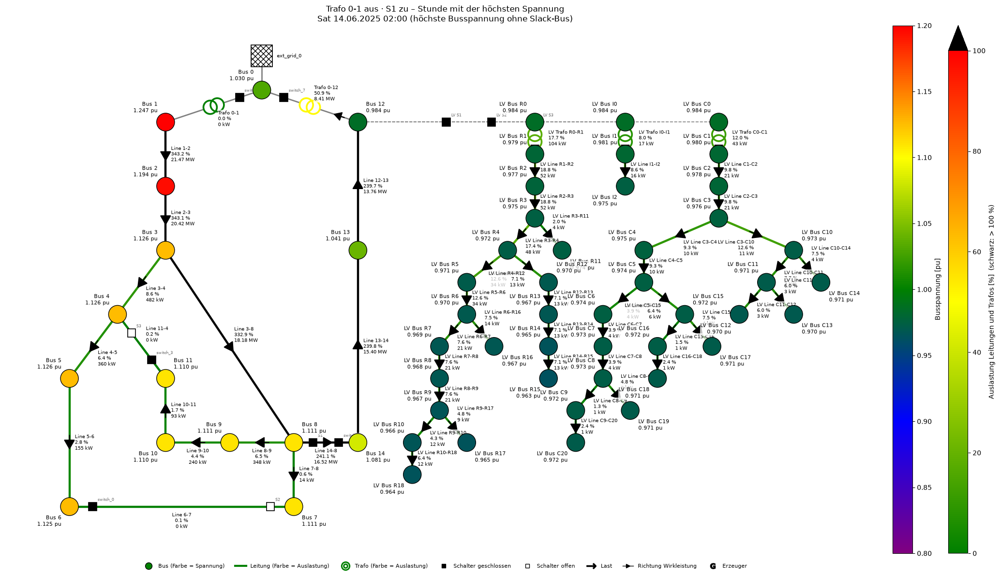

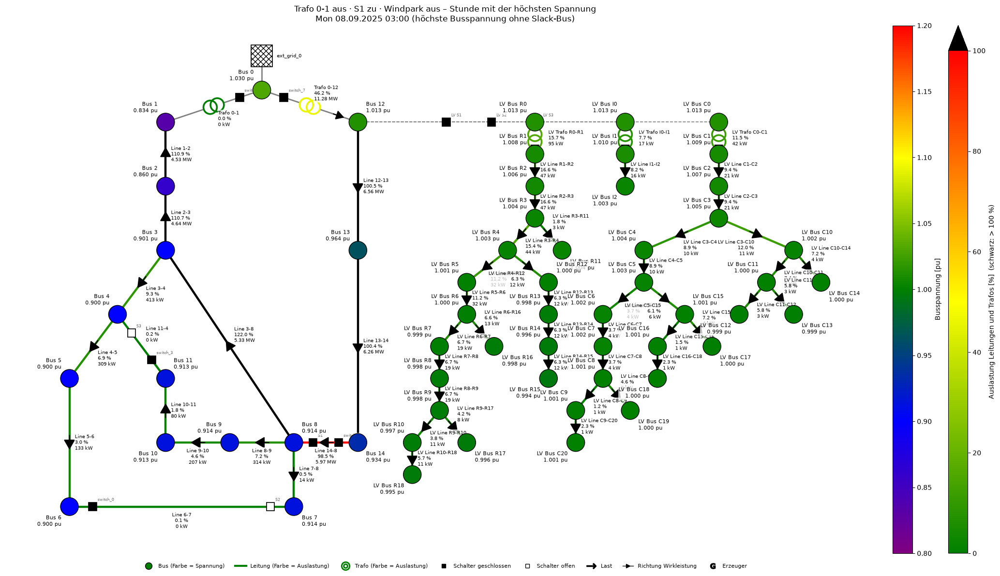

In [191]:
for titel in ("Trafo 0-1 aus · S1 zu", "Trafo 0-1 aus · S1 zu · Windpark aus"):
    ausfall[titel].createDiagram(Diagram.NETWORK, time=["max"], elements=False, title=f"{titel} – Stunde mit der höchsten Spannung")

**Ergebnis Trafoausfall:**

- **S1 offen:** Der Abgang des ausgefallenen Trafos ist in allen Stunden ohne Versorgung (Trafo 0-1: Bus 1 bis 11; Trafo 0-12: Bus 12 bis 14 und das ganze Ortsnetz). Der übrige Teil läuft normal weiter. Fällt Trafo 0-12 aus, fließt der Windüberschuss nicht mehr teilweise in Abgang 2, sondern vollständig ins 110-kV-Netz: Rückspeisung in 615 statt 266 Stunden.
- **Trafo 0-1 aus, S1 zu, Windpark speist weiter:** Der Windpark sitzt jetzt am Ende eines langen Wegs (Bus 12 → 13 → 14 → 8 → 3 → 2 → 1), hebt dort die Spannung an und kehrt die Flüsse um. Das passiert weit über die Grenzen hinaus:
  - In 272 Stunden liegt die Spannung über 1,10 pu, an Bus 1 bis 1,25 pu. Line 1-2 wird mit bis zu 382 % ausgelastet, Trafo 0-12 mit bis zu 130 %. In 201 Stunden fließt Windstrom über den ganzen Weg und Trafo 0-12 ins 110-kV-Netz.
  - Bei wenig Wind und hoher Last kehrt sich das Bild um: Die Spannung bricht bis 0,52 pu ein, und in 704 Stunden konvergiert der Lastfluss gar nicht (Lücken im Diagramm).
  - Nur in 297 von 2016 Stunden (15 %) liegen alle Spannungen zwischen 0,90 und 1,10 pu und alle Auslastungen unter 100 %. Das sind die Stunden, in denen Wind und Last von Abgang 1 etwa gleich groß sind und kaum Leistung über den langen Weg fließen muss.
- **Trafo 0-1 aus, S1 zu, Windpark aus:** Ohne Windpark muss die ganze Last von Abgang 1 über den langen Weg fließen. Das ist noch schlechter: In 1511 Stunden konvergiert der Lastfluss nicht, in allen übrigen liegt die Spannung unter 0,90 pu und Leitungen sind überlastet.
- **Trafo 0-12 aus, S1 zu:** Abgang 2 und das Ortsnetz werden über Abgang 1 versorgt. In 1325 Stunden (mit PV) bzw. 1544 Stunden (ohne PV) konvergiert der Lastfluss nicht. In den übrigen Stunden fällt die NS-Spannung auf 0,40 bis 0,95 pu; das können die rONT mit zwei Stufen nicht ausgleichen.
- **Folgerung:** Der Ausfall eines 110/20-kV-Trafos lässt sich über S1 in keiner Variante beherrschen. Den Grund haben schon Teil 3b und 4a gezeigt: Die Kupplung am Ende der Abgänge kann nicht die Leistung eines ganzen Abgangs übertragen. Das Abschalten des Erzeugers verhindert zwar die Überspannung, aber nicht den Spannungseinbruch. Abhilfe wäre eine Kupplung direkt im Umspannwerk (Teil 4a, 5.3).

## 11 Ergebnis Lastflussumkehr

**Wann und wo tritt Lastflussumkehr auf?**

- **MS-Netz:** nur an Trafo 0-1 (615 h) und an der 110-kV-Netzkuppelstelle (266 h), weil Windpark und PV-Anlage direkt an den Trafo-Sammelschienen einspeisen. Auslöser ist Wind: Trafo 0-1 kehrt sich um, sobald der Windpark mehr erzeugt, als Abgang 1 verbraucht; das 110-kV-Netz, sobald Wind und PV die gesamte Last übersteigen. Das tritt vor allem nachts und am Wochenende auf. Stärke: bis 22,5 MW über Trafo 0-1 und 16,1 MW ins 110-kV-Netz; in 12 Wochen 5,2 bzw. 1,6 GWh.
- **Ortsnetz:** im Wohngebiet an Ortsnetztrafo R und allen Leitungen (390 h, bis 0,45 MW), ausgelöst durch die PV-Haushalte an sonnigen Mittagen von März bis September, wenn die Heimspeicher voll sind.

**Einfluss der Schalterstellungen:**

- **S2 und S3** verteilen nur die Last innerhalb von Abgang 1 um. Die Leitungen am Ende der Stränge drehen ihre Richtung (Line 10-11 mit S3 dauerhaft), Spannungen und Auslastungen ändern sich um wenige Prozentpunkte, die rONT bleiben unbeeinflusst.
- **S1** führt zu Lastflussumkehr auf MS-Leitungen: auf der Kupplung und in Abgang 2 bei viel Wind, auf Line 3-8 bei PV ohne Wind. Abgang 1 wird um bis 2,6 Prozentpunkte angehoben, Abgang 2 um bis 1,9 Prozentpunkte abgesenkt. Trafo 0-1 wird um 10 Prozentpunkte entlastet, aber Line 1-2 erreicht bei Starkwind 99,6 %, und die Verluste steigen um 22 %. Auf die Rückspeisung im Ortsnetz hat S1 keinen Einfluss.

**Folgen für Spannungen, Auslastungen und rONT-Regelung:**

- Alle Spannungen bleiben in allen Schaltzuständen im Planungsband. Die einzige kritische Auslastung ist Line 1-2 mit S1 bei Starkwind.
- Der Wohngebiet-rONT regelt jetzt in beide Richtungen: mittags senkt er bei Rückspeisung ab (140 h Stufe +1/+2), abends hebt er an. Ohne ihn läge die Spannung am Strangende bei Rückspeisung über dem Planungsband.
- S1 senkt die Spannung an Bus 12, deshalb müssen alle rONT abends mehr anheben (Wohngebiet +6 % Stufenschritte, teilweise Stufe −2); der Industrie-rONT schaltet nur mit S1.

**Empfehlung für den Betrieb:** S1 im Normalbetrieb offen lassen (wie im Backup-Plan vorgesehen). Wenn S1 geschlossen wird, die Auslastung von Line 1-2 bei Starkwind überwachen. Beim Ausfall eines 110/20-kV-Trafos hilft S1 nicht. Bei mehr PV-Haushalten (Variante Zukunft in Teil 4b) reicht der rONT nicht mehr aus.

<a id="teil-8"></a>

---

# Task 4 – Teil 6: Line 3-8 – Engpass und Kapazitätserhöhung

### Aufgabenstellung (Abschnitt 6 des Arbeitsauftrags)

> *Untersuchen Sie gezielt, unter welchen Einspeise- und Lastbedingungen diese Leitung zum thermischen Engpass wird. Falls Sie diese spezifische Leitung durch gezielte Laständerung nicht überlasten können, begründen Sie und wählen eine Alternative.*
> - *Entwickeln Sie vor jeder Kapazitätserhöhung durch kontrollierte Variation von Einspeiseort, Erzeugungsleistung und Last ein nachvollziehbares Szenario, in dem Line 3-8 als erste Leitung ihre thermische Nennstromgrenze erreicht (100 % Auslastung), während die übrigen Leitungen noch darunter liegen. Bestimmen und dokumentieren Sie den Grenzbetriebspunkt sowie die tatsächlichen Ströme, die verwendete Stromgrenze und die prozentuale Belastung aller Leitungen. […]*
> - *Begründen Sie die Leitungsauslegung und `max_i_ka` mit plausiblen Quellen. […] Wenn Sie alternative Nennstromgrenzen als Sensitivität betrachten, kennzeichnen und begründen Sie diese separat.*
> - *Erhöhen Sie anschließend die Übertragungskapazität mit mindestens einer technisch begründeten Maßnahme […]. Belegen Sie die geänderten Parameter und vergleichen Sie Vorher und Nachher unter identischen Randbedingungen.*
> - *Bewerten Sie […] die Auswirkungen Ihrer Maßnahme auf Lastflussverteilung, Spannungen an allen Bussen, Verluste und mögliche neue Engpässe. Erklären Sie, ob die Maßnahme den Engpass tatsächlich entschärft oder lediglich verlagert.*
>
> *Betrachten Sie im folgenden immer die möglichen Schalterstellungen der Schalter S1–S3.*

| Anforderung | wo |
|---|---|
| Überlastung durch Laständerung? Begründung und Alternative | Abschnitt 2 |
| Szenario durch Variation von Einspeiseort, Leistung und Last (Sweep) | Abschnitt 3 |
| Grenzbetriebspunkt mit Strömen, Stromgrenze und Auslastung aller Leitungen | Abschnitt 3.3 |
| alle Schalterstellungen S1–S3 | Abschnitte 2, 4, 6 und 7 |
| Begründung von Leitungsauslegung und `max_i_ka` | Abschnitt 1.2 |
| Sensitivität der Stromgrenze (getrennt gekennzeichnet) | Abschnitt 5 |
| Kapazitätserhöhung mit belegten Parametern, Vorher/Nachher | Abschnitt 6 |
| Lastflussverteilung, Spannungen, Verluste, neue Engpässe; entschärft oder verlagert? | Abschnitte 6 und 7 |

### Vorgehen

- **Netz:** CIGRE-MV-Referenznetz ohne DER (`create_cigre_network_mv(with_der=False)`), statische Bemessungslasten. Es geht nur um die Grenzen von Line 3-8; Profile, eigene Anlagen und die Ortsnetz-Erweiterung aus Teil 2 bis 5 werden bewusst nicht verwendet.
- **Statische Lastflüsse:** Last und Einspeisung werden **linear in kleinen Schritten** erhöht (Last in Schritten von 2 %, Einspeisung in Schritten von 0,1 MW). So werden nichtlineare Zusammenhänge sichtbar, etwa der Nulldurchgang des Stroms bei Lastflussumkehr oder der überproportionale Anstieg von Verlusten und Spannung.

### Aufbau

1. Referenznetz und Line 3-8
2. Laständerung allein
3. Einspeisung an der Leitung und Grenzbetriebspunkt
4. Alle Schalterstellungen
5. Sensitivität der Stromgrenze
6. Kapazitätserhöhung
7. Entschärft oder verlagert?
8. Fazit

## Importe und Hilfsfunktionen

In [192]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import copy

import numpy as np
import pandas as pd
import pandapower as pp
import pandapower.networks as pn
import matplotlib.pyplot as plt

import plots
import netplan
import szenarien as sz

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

BASIS = pn.create_cigre_network_mv(with_der=False)
LEITUNG = "Line 3-8"
LEITUNGEN = list(BASIS.line["name"])
MS_BUSSE = [b for b in BASIS.bus["name"] if b != "Bus 0"]
KEYS = sz.KEYS                                            # "000" … "111" = S1, S2, S3 offen/geschlossen
LABEL = {k: sz.label(k, kurz=True) for k in KEYS}
P_MAX, DP = 15.0, 0.1                                     # Einspeisung 0 … 15 MW in Schritten von 0,1 MW
LF_HAUPT = 0.6                                            # Hauptszenario: 60 % der Bemessungslast

In [193]:
def netz(lf=1.0, key="000", leitung=None):
    """Referenznetz mit Lastfaktor lf, Schaltzustand key und optional geänderter Line 3-8 (Funktion net → None)."""
    n = copy.deepcopy(BASIS)
    n.load[["p_mw", "q_mvar"]] *= lf
    for s, c in zip(("S1", "S2", "S3"), key):
        n.switch.loc[n.switch["name"] == s, "closed"] = c == "1"
    if leitung is not None:
        leitung(n)
    return n

def einspeisung(n, bus, p_mw, cosphi=1.0):
    """Erzeuger 'G' an bus setzen (anlegen oder ändern); cos φ < 1: untererregt (Blindleistungsbezug)."""
    q = -p_mw * np.tan(np.arccos(cosphi))
    idx = n.sgen.index[n.sgen["name"] == "G"]
    b = int(n.bus.index[n.bus["name"] == bus][0])
    if len(idx):
        n.sgen.loc[idx, ["bus", "p_mw", "q_mvar"]] = [b, p_mw, q]
    else:
        pp.create_sgen(n, b, p_mw=p_mw, q_mvar=q, name="G")

def ergebnis(n):
    """Lastfluss rechnen; Rückgabe: Auslastungen aller Leitungen [%], Spannungen [pu], Verluste [MW] oder None."""
    try:
        pp.runpp(n, init="results" if len(n.res_bus) else "auto")
    except pp.LoadflowNotConverged:
        try:
            pp.runpp(n, init="flat")
        except pp.LoadflowNotConverged:
            return None
    return (pd.Series(n.res_line.loading_percent.to_numpy(), index=n.line["name"]),
            pd.Series(n.res_bus.vm_pu.to_numpy(), index=n.bus["name"]),
            float(n.res_line.pl_mw.sum() + n.res_trafo.pl_mw.sum()))

def sweep_last(key="000", lf_werte=np.arange(0, 2.0001, 0.02)):
    """Lastfaktor linear erhöhen; Rückgabe: DataFrame (Index lf) mit Auslastung aller Leitungen."""
    zeilen = {}
    for lf in lf_werte:
        e = ergebnis(netz(lf, key))
        if e:
            zeilen[round(lf, 3)] = e[0]
    return pd.DataFrame(zeilen).T

def sweep_einspeisung(bus, lf=LF_HAUPT, key="000", cosphi=1.0, leitung=None, p_werte=None):
    """Einspeisung an bus linear erhöhen; Rückgabe: DataFrame (Index P) mit Auslastungen, U min/max MS und Verlusten."""
    p_werte = np.arange(0, P_MAX + 1e-9, DP) if p_werte is None else p_werte
    n = netz(lf, key, leitung)
    zeilen = {}
    for p in p_werte:
        einspeisung(n, bus, p, cosphi)
        e = ergebnis(n)
        if e is None:
            break
        l, u, v = e
        zeilen[round(p, 3)] = pd.concat([l, pd.Series({"U min MS [pu]": u[MS_BUSSE].min(), "U max MS [pu]": u[MS_BUSSE].max(),
                                                     "Verluste [MW]": v})])
    return pd.DataFrame(zeilen).T

def grenze(df):
    """Erster Schnittpunkt einer Leitung mit 100 % (linear zwischen den Stützstellen interpoliert)."""
    l = df[LEITUNGEN]
    ueber = l.max(axis=1) >= 100
    if not ueber.any():
        return {"Grenzleistung [MW]": np.nan, "erste Leitung": "keine (bis 15 MW)", "zweite Leitung": "", "Auslastung zweite Leitung [%]": np.nan}
    i = int(np.argmax(ueber.to_numpy()))
    erste = l.iloc[i].idxmax()
    if i == 0:
        p = l.index[0]
    else:
        p0, p1 = l.index[i - 1], l.index[i]
        y0, y1 = l[erste].iloc[i - 1], l[erste].iloc[i]
        p = p0 + (100 - y0) / (y1 - y0) * (p1 - p0)
    zweite = l.iloc[i].drop(erste).idxmax()
    return {"Grenzleistung [MW]": p, "erste Leitung": erste, "zweite Leitung": zweite,
            "Auslastung zweite Leitung [%]": l.iloc[i][zweite]}

def grenzbetrieb(bus, p, lf=LF_HAUPT, key="000", cosphi=1.0, leitung=None):
    """Netz im Grenzbetriebspunkt (gerechnet)."""
    n = netz(lf, key, leitung)
    einspeisung(n, bus, p, cosphi)
    pp.runpp(n)
    return n

def leitungstabelle(n):
    """Strom, Stromgrenze und Auslastung aller Leitungen."""
    return pd.DataFrame({"Typ": n.line["std_type"].to_numpy(), "Länge [km]": n.line["length_km"].to_numpy(),
                         "parallel": n.line["parallel"].to_numpy(),
                         "I [A]": n.res_line.i_ka.to_numpy() * 1000,
                         "I_max [A]": (n.line.max_i_ka * n.line.df * n.line.parallel).to_numpy() * 1000,
                         "Auslastung [%]": n.res_line.loading_percent.to_numpy(),
                         "P von from_bus [MW]": n.res_line.p_from_mw.to_numpy()},
                        index=n.line["name"]).sort_values("Auslastung [%]", ascending=False)

def lastfluss_plot(ax, df, hervor=(LEITUNG, "Line 2-3", "Line 1-2"), x_label="Einspeisung an Bus 8 [MW]", linear=True):
    """Auslastung aller Leitungen über dem Sweep-Parameter; hervorgehobene Leitungen farbig, die übrigen grau."""
    for c in LEITUNGEN:
        if c not in hervor:
            ax.plot(df.index, df[c], color="lightgray", lw=0.8)
    for c, farbe in zip(hervor, ("tab:red", "tab:blue", "tab:green")):
        ax.plot(df.index, df[c], color=farbe, lw=2, label=c)
        if linear and len(df) > 3:                       # lineare Fortsetzung der ersten Stützstellen (gestrichelt)
            x0, x1 = df.index[1], df.index[3]
            m = (df[c].iloc[3] - df[c].iloc[1]) / (x1 - x0)
            ax.plot(df.index, df[c].iloc[1] + m * (df.index - x0), color=farbe, lw=0.8, ls=":")
    ax.axhline(100, color="black", ls="--", lw=1)
    ax.set_xlabel(x_label)
    ax.set_ylabel("Auslastung [%]")
    ax.grid(alpha=0.3)

## 1 Referenznetz und Line 3-8

### 1.1 Netz und Lasten

CIGRE-MV ohne DER mit den Bemessungslasten (Wohnen und Gewerbe je Bus):

In [194]:
lasten = BASIS.load.assign(Bus=BASIS.bus.loc[BASIS.load.bus, "name"].to_numpy()).groupby("Bus", sort=False)[["p_mw", "q_mvar"]].sum()
lasten.loc["Summe"] = lasten.sum()
display(lasten.round(3).T)
print("Line 3-8:")
BASIS.line.loc[BASIS.line["name"] == LEITUNG, ["name", "std_type", "from_bus", "to_bus", "length_km", "r_ohm_per_km", "x_ohm_per_km",
                                               "c_nf_per_km", "max_i_ka", "parallel"]]

Bus,Bus 1,Bus 3,Bus 4,Bus 5,Bus 6,Bus 8,Bus 10,Bus 11,Bus 12,Bus 14,Bus 7,Bus 9,Bus 13,Summe
p_mw,19.839,0.502,0.432,0.728,0.548,0.587,0.543,0.330,20.010,0.540,0.076,0.574,0.034,44.742
q_mvar,4.637,0.209,0.108,0.182,0.137,0.147,0.161,0.083,4.693,0.258,0.047,0.356,0.021,11.040


Line 3-8:


,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,max_i_ka,parallel
9,Line 3-8,CABLE_CIGRE_MV,3,8,1.3,0.501,0.716,151.1749,0.145,1


,Typ,Länge [km],parallel,I [A],I_max [A],Auslastung [%],P von from_bus [MW]
name,,,,,,,
Line 2-3,CABLE_CIGRE_MV,4.4,1.0,140.6,145.0,97.0,4.5
Line 1-2,CABLE_CIGRE_MV,2.8,1.0,139.9,145.0,96.5,4.5
Line 3-8,CABLE_CIGRE_MV,1.3,1.0,69.8,145.0,48.1,2.1
Line 3-4,CABLE_CIGRE_MV,0.6,1.0,54.5,145.0,37.6,1.7
Line 8-9,CABLE_CIGRE_MV,0.3,1.0,48.6,145.0,33.6,1.4
Line 4-5,CABLE_CIGRE_MV,0.6,1.0,40.7,145.0,28.1,1.3
Line 9-10,CABLE_CIGRE_MV,0.8,1.0,28.2,145.0,19.5,0.9
Line 5-6,CABLE_CIGRE_MV,1.5,1.0,17.6,145.0,12.1,0.5
Line 12-13,OHL_CIGRE_MV,4.9,1.0,18.5,195.0,9.5,0.6


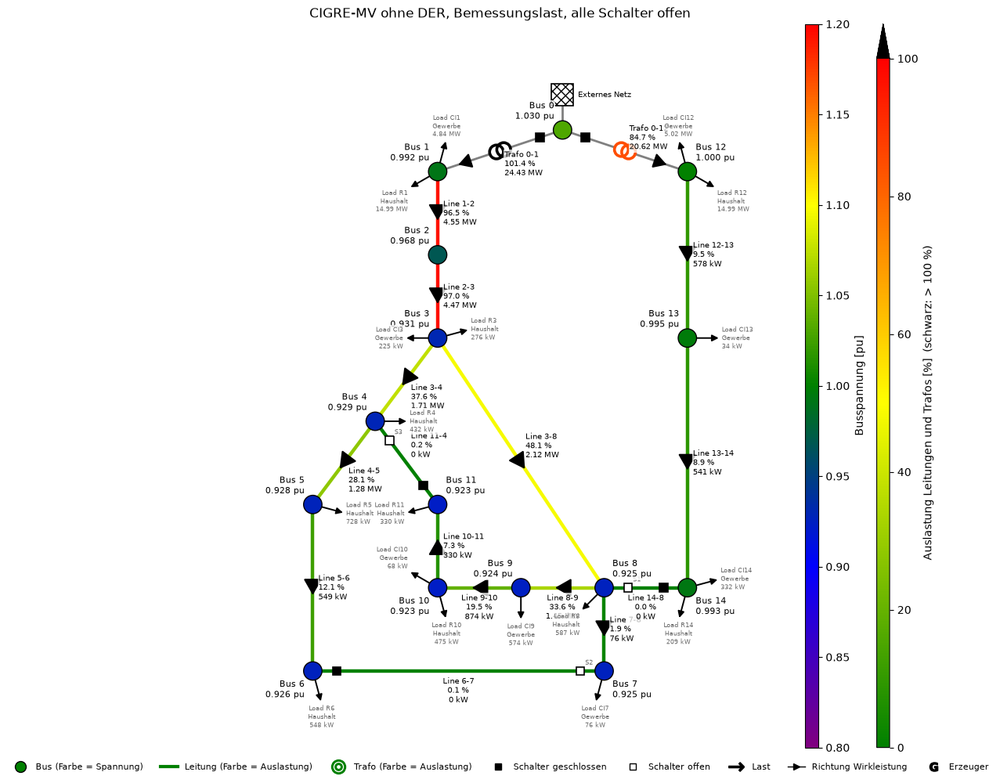

In [195]:
n0 = netz(1.0)
pp.runpp(n0)
display(plots.table(leitungstabelle(n0), decimals=1))
_ = netplan.plot_static(n0, title="CIGRE-MV ohne DER, Bemessungslast, alle Schalter offen")

**Ausgangslage bei Bemessungslast:**

- Die großen Lasten sitzen an den Trafo-Sammelschienen: Bus 1 mit 19,8 MW und Bus 12 mit 20,0 MW. Das sind zusammengefasste Wohn- und Gewerbegebiete. An den Bussen 3 bis 11 hängen nur kleine Lasten von 0,1 bis 0,7 MW.
- Abgang 1 (Bus 1 bis 11) ist verkabelt (`CABLE_CIGRE_MV`, 145 A). Abgang 2 (Bus 12 bis 14) und die Kupplung Line 14-8 sind Freileitungen (`OHL_CIGRE_MV`, 195 A).
- Am stärksten ausgelastet sind die vorgelagerten Kabel Line 2-3 und Line 1-2 (97 bzw. 96,5 %, etwa 140 A). Line 3-8 führt nur 70 A (48 %).

### 1.2 Leitungsauslegung und Stromgrenze `max_i_ka`

Line 3-8 ist im Referenznetz als Kabel des Typs `CABLE_CIGRE_MV` modelliert. Die Leitungsdaten stammen aus dem CIGRE-Benchmark für Mittelspannungsnetze [13] und sind in pandapower als Standardtyp hinterlegt [25]:

| Größe | `CABLE_CIGRE_MV` | NA2XS2Y 1×50 12/20 kV [26] | NA2XS2Y 1×70 12/20 kV [26] |
|---|---|---|---|
| Leiterwiderstand R′ | 0,501 Ω/km | 0,641 Ω/km | 0,443 Ω/km |
| Strombelastbarkeit in Erde | **145 A** (`max_i_ka = 0,145`) | 172 A | 210 A |
| thermische Grenzleistung √3 · 20 kV · I | 5,0 MVA | 6,0 MVA | 7,3 MVA |

Die Strombelastbarkeit in Erde gilt nach dem Datenblatt für Dreiecksbündelung, 20 °C Erdbodentemperatur und Belastungsgrad 0,7 (Bezugsbedingungen nach DIN VDE 0276-620 [27]).

**Begründung:**

- Nach dem Leiterwiderstand entspricht das CIGRE-Kabel einem Aluminiumleiter zwischen 50 und 70 mm². Ein VPE-Kabel dieser Größe ist nach Datenblatt in Erde mit 172 bis 210 A belastbar. Die 145 A des Referenznetzes liegen bei 70 bis 85 % davon, sind also eher vorsichtig angesetzt. Das ist plausibel, weil reale Verlegebedingungen (Häufung mehrerer Kabel, wärmerer oder trockener Boden) die Belastbarkeit gegenüber den Bezugsbedingungen senken [28].
- Bei Kabeln bestimmt die thermische Grenzleistung die Übertragungsfähigkeit; sie liegt unter der natürlichen Leistung [19, S. 461 f.]. Kabel lassen sich kaum kurzzeitig überlasten, weil ihre Isolierung zugleich als Wärmedämmung wirkt [19, S. 439]. Die Stromgrenze ist deshalb eine harte Grenze.
- Querschnitte und Dauerstrombelastbarkeit sind genormt; ein berechneter Querschnitt wird auf den nächsthöheren genormten Querschnitt aufgerundet [19, S. 799 f.].
- **`max_i_ka = 0,145 kA` wird in allen Abschnitten außer der Sensitivität (Abschnitt 5) unverändert verwendet.**
- Auffällig ist der hohe Leitungsbelag X′ = 0,716 Ω/km des CIGRE-Kabels; ein typisches Einleiterkabel liegt bei etwa 0,11 bis 0,13 Ω/km (pandapower-Standardtypen [25]). Für die Stromgrenze spielt das keine Rolle, wohl aber für die Stromaufteilung in Maschen (Abschnitte 4 und 6).

## 2 Laständerung allein

Alle Lasten werden gemeinsam linear von 0 bis 200 % der Bemessungslast in Schritten von 2 % erhöht, in allen acht Schaltzuständen. Für jede Leitung wird die Auslastung aufgezeichnet.

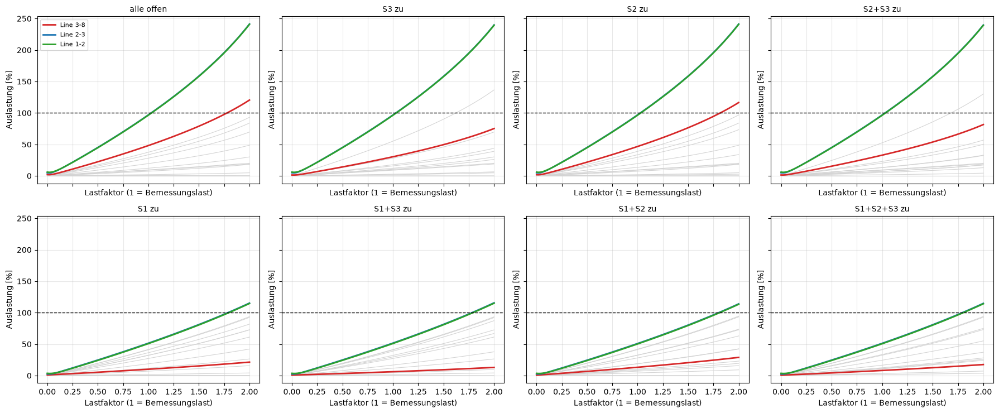

,Lastfaktor bei erster Überlastung,erste Leitung,Line 3-8 dann [%],Line 3-8 bei Bemessungslast [%]
alle offen,1.040000,Line 2-3,50.384280,48.143637
S3 zu,1.040000,Line 2-3,31.743250,30.338819
S2 zu,1.040000,Line 2-3,48.851666,46.684368
S2+S3 zu,1.040000,Line 2-3,34.415987,32.894599
S1 zu,1.800000,Line 2-3,18.845895,10.058203
S1+S3 zu,1.800000,Line 2-3,11.432746,6.141118
S1+S2 zu,1.820000,Line 2-3,25.713069,13.207405
S1+S2+S3 zu,1.800000,Line 2-3,15.401955,8.127911


In [196]:
last = {k: sweep_last(k) for k in KEYS}

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharex=True, sharey=True)
for ax, k in zip(axes.flat, KEYS):
    lastfluss_plot(ax, last[k], x_label="Lastfaktor (1 = Bemessungslast)", linear=False)
    ax.set_title(LABEL[k], fontsize=10)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

zeilen = {}
for k in KEYS:
    df = last[k][LEITUNGEN]
    ueber = df.max(axis=1) >= 100
    i = int(np.argmax(ueber.to_numpy()))
    zeilen[LABEL[k]] = {"Lastfaktor bei erster Überlastung": df.index[i], "erste Leitung": df.iloc[i].idxmax(),
                        "Line 3-8 dann [%]": df.iloc[i][LEITUNG], "Line 3-8 bei Bemessungslast [%]": df.loc[1.0, LEITUNG]}
plots.table(pd.DataFrame(zeilen).T, decimals=2)

**Ergebnis Laständerung:**

- In **keinem** Schaltzustand erreicht Line 3-8 als erste Leitung 100 %. Immer ist Line 2-3 zuerst überlastet:
  - S1 offen: schon bei 104 % der Bemessungslast; Line 3-8 liegt dann bei 32 bis 50 %.
  - S1 zu: erst bei 180 %, weil Abgang 2 über S1 einen Teil der Last von Abgang 1 übernimmt; Line 3-8 liegt dann bei 11 bis 26 %.
- **Begründung:** In einem Strahlennetz fließt im ersten Abschnitt einer mehrfach belasteten Leitung die Summe aller Abnehmerströme dahinter [19, S. 803 ff.]. Über Line 2-3 laufen die Lasten von Bus 3 bis 11, über Line 3-8 nur die von Bus 7 bis 11. Jede Lasterhöhung hinter Line 3-8 erhöht Line 2-3 mindestens genauso stark. Da Line 2-3 schon bei Bemessungslast fast an der Grenze liegt, kann Line 3-8 durch Laständerung nie zuerst an die Grenze kommen.
- Die Kurven verlaufen nahezu linear, mit leicht überproportionalem Anstieg bei hoher Last (Spannungsfall und Verluste wachsen mit).
- **Alternative:** Eine Einspeisung kehrt die Flussrichtung um. Wird sie am Ende von Line 3-8 angeschlossen, fließt ihre Leistung zuerst über Line 3-8, und die Lasten in Abgang 1 entlasten die vorgelagerten Leitungen.

## 3 Einspeisung an der Leitung und Grenzbetriebspunkt

### 3.1 Einspeiseort

Ein Erzeuger (cos φ = 1) wird nacheinander an jeden Bus von Abgang 1 gesetzt und seine Leistung linear von 0 bis 15 MW in Schritten von 0,1 MW erhöht (60 % Last, alle Schalter offen). Je Ort: welche Leitung erreicht zuerst 100 %, bei welcher Leistung, und wie hoch ist dann die am zweitstärksten ausgelastete Leitung?

In [197]:
ORTE = [f"Bus {i}" for i in range(2, 12)]
ort = {b: sweep_einspeisung(b) for b in ORTE}
ort_tab = pd.DataFrame({b: grenze(df) for b, df in ort.items()}).T
plots.table(ort_tab, decimals=2)

,Grenzleistung [MW],erste Leitung,zweite Leitung,Auslastung zweite Leitung [%]
Bus 2,7.744851,Line 1-2,Line 2-3,53.259134
Bus 3,7.805799,Line 2-3,Line 1-2,101.460400
Bus 4,6.233062,Line 3-4,Line 2-3,72.297186
Bus 5,5.978720,Line 4-5,Line 3-4,95.455537
Bus 6,5.563370,Line 5-6,Line 4-5,92.318899
Bus 7,5.269646,Line 7-8,Line 3-8,77.495429
Bus 8,6.488459,Line 3-8,Line 2-3,75.733687
Bus 9,6.084807,Line 8-9,Line 3-8,92.781379
Bus 10,5.752199,Line 9-10,Line 8-9,94.467010
Bus 11,5.419029,Line 10-11,Line 9-10,95.253877


**Ergebnis Einspeiseort:**

- Überlastet wird immer zuerst die Leitung, über die der Erzeuger angeschlossen ist. Nur bei Einspeisung an **Bus 8** ist das Line 3-8 (bei 6,49 MW, nächste Leitung Line 2-3 mit 76 %).
- **Bus 7:** Line 7-8 kommt zuerst (5,27 MW).
- **Bus 9:** Line 8-9 kommt zuerst (6,08 MW), Line 3-8 liegt dann schon bei 93 %. Die Leistung fließt über Line 8-9 und Line 3-8 nacheinander, deshalb sind beide fast gleich ausgelastet.
- **Bus 2 und Bus 3:** Line 1-2 bzw. Line 2-3 kommt zuerst.
- Bus 8 ist der Kabelverteiler, an dem Line 3-8, 7-8, 8-9 und die Kupplung 14-8 zusammenkommen. Eine Erzeugungsanlage mit eigenem Anschlusskabel dorthin ist eine realistische Annahme.

### 3.2 Leistung und Last am Einspeiseort Bus 8

Bus 8 ist das Ende von Line 3-8. Die Einspeisung wird linear erhöht, für drei Lastfälle (30 %, 60 %, 100 % der Bemessungslast). Rot: Line 3-8, blau und grün: die vorgelagerten Leitungen 2-3 und 1-2, grau: alle übrigen. Die gepunkteten Linien setzen den Anfang jeder Kurve linear fort; der Abstand zur tatsächlichen Kurve zeigt, wo der Zusammenhang nichtlinear wird.

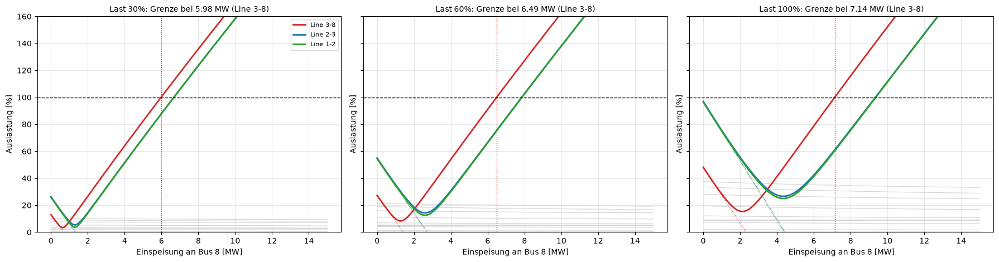

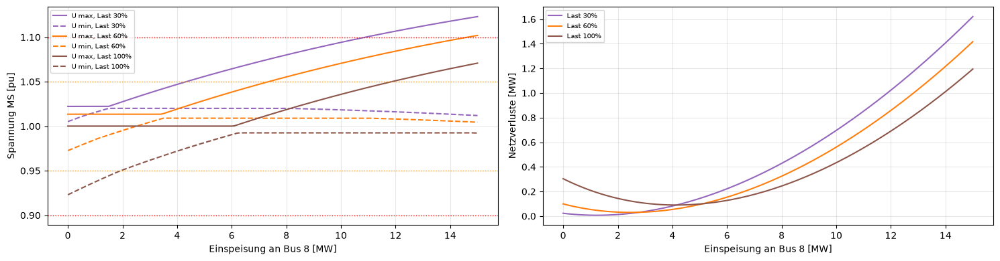

In [198]:
LASTFAELLE = [0.3, 0.6, 1.0]
bus8 = {lf: sweep_einspeisung("Bus 8", lf) for lf in LASTFAELLE}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, lf in zip(axes, LASTFAELLE):
    lastfluss_plot(ax, bus8[lf])
    g = grenze(bus8[lf])
    ax.axvline(g["Grenzleistung [MW]"], color="tab:red", ls=":", lw=1)
    ax.set_title(f"Last {lf:.0%}: Grenze bei {g['Grenzleistung [MW]']:.2f} MW ({g['erste Leitung']})", fontsize=10)
    ax.set_ylim(0, 160)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for lf, farbe in zip(LASTFAELLE, ("tab:purple", "tab:orange", "tab:brown")):
    axes[0].plot(bus8[lf].index, bus8[lf]["U max MS [pu]"], color=farbe, label=f"U max, Last {lf:.0%}")
    axes[0].plot(bus8[lf].index, bus8[lf]["U min MS [pu]"], color=farbe, ls="--", label=f"U min, Last {lf:.0%}")
    axes[1].plot(bus8[lf].index, bus8[lf]["Verluste [MW]"], color=farbe, label=f"Last {lf:.0%}")
for v, c in ((0.90, "red"), (0.95, "orange"), (1.05, "orange"), (1.10, "red")):
    axes[0].axhline(v, color=c, ls=":", lw=1)
axes[0].set_ylabel("Spannung MS [pu]")
axes[1].set_ylabel("Netzverluste [MW]")
for ax in axes:
    ax.set_xlabel("Einspeisung an Bus 8 [MW]")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

zeilen = {}
for lf in LASTFAELLE:
    for cosphi in (1.0, 0.95):
        df = bus8[lf] if cosphi == 1.0 else sweep_einspeisung("Bus 8", lf, cosphi=cosphi)
        g = grenze(df)
        p = g["Grenzleistung [MW]"]
        zeilen[(f"{lf:.0%}", f"cos φ = {cosphi}" + (" untererregt" if cosphi < 1 else ""))] = {
            **g, "U max MS im Grenzpunkt [pu]": np.interp(p, df.index, df["U max MS [pu]"])}
plots.table(pd.DataFrame(zeilen).T, decimals=3)

**Ergebnis Leistungs-Sweep an Bus 8:**

- **Nichtlinearer Verlauf am Anfang:** Die Auslastung von Line 3-8 sinkt zunächst, erreicht ein Minimum und steigt dann wieder. Am Minimum deckt der Erzeuger gerade die Lasten von Bus 7 bis 11; danach kehrt sich der Fluss auf Line 3-8 um (von Bus 8 zu Bus 3). Je nach Last liegt der Nulldurchgang bei etwa 0,6, 1,2 bzw. 2,2 MW. Dasselbe passiert später auf Line 2-3 und 1-2, sobald der Erzeuger die ganze Last von Abgang 1 hinter Bus 2 deckt. Der Strom wird nie ganz null, weil Blindleistung weiter fließt. Die gepunktete lineare Fortsetzung zeigt, wie stark die Kurven an dieser Stelle abknicken.
- **Nach der Umkehr** steigen alle drei Kurven fast linear mit rund 19 Prozentpunkten je MW.
- **Netzverluste:** Sie wachsen quadratisch mit dem Strom, sichtbar an der Parabel. Ihr Minimum liegt dort, wo Einspeisung und Last sich ausgleichen.
- **Spannung:** Die höchste Spannung steigt mit der Einspeisung. Die Knicke entstehen, wenn ein anderer Bus zum Maximum bzw. Minimum wird.
- **Grenzleistung:** Bei 30 / 60 / 100 % Last erreicht Line 3-8 die 100 % bei 5,98 / 6,49 / 7,14 MW. Die nächste Leitung (Line 2-3) liegt dann bei 88 / 76 / 62 %. Je höher die Last, desto mehr Einspeisung nehmen die Lasten in Abgang 1 auf und desto größer ist der Abstand.
- **Spannung im Grenzpunkt:** Bei 30 % Last liegt sie mit 1,064 pu über dem Planungsband 1,05 pu, aber unter der Grenze 1,10 pu. Bei 60 % und 100 % Last liegt sie im Band.
- **cos φ = 0,95 untererregt:** Die Blindleistung senkt die Spannung (um 2 bis 4 Prozentpunkte im Grenzpunkt), erhöht aber den Strom. Line 3-8 erreicht die Grenze deshalb schon bei 5,39 bis 6,06 MW. Die Spannungshaltung über Blindleistung geht also auf Kosten der thermischen Reserve.

### 3.3 Grenzbetriebspunkt (Hauptszenario)

**Szenario:** 60 % der Bemessungslast (etwa ein Werktag zur Mittagszeit), alle Schalter offen, eine neue Erzeugungsanlage am Kabelverteiler Bus 8 mit cos φ = 1, z. B. ein PV-Park mit etwa 7 MWp oder drei Windenergieanlagen. Die Leistung wird so weit erhöht, bis Line 3-8 genau 100 % erreicht. Dokumentiert werden Strom, Stromgrenze und Auslastung aller Leitungen sowie die Spannungen an allen Bussen.

Grenzbetriebspunkt: 6.49 MW an Bus 8, Last 60%, alle Schalter offen


,Typ,Länge [km],parallel,I [A],I_max [A],Auslastung [%],P von from_bus [MW]
name,,,,,,,
Line 3-8,CABLE_CIGRE_MV,1.3,1.0,145.0,145.0,100.0,-5.2
Line 2-3,CABLE_CIGRE_MV,4.4,1.0,109.6,145.0,75.6,-3.8
Line 1-2,CABLE_CIGRE_MV,2.8,1.0,109.1,145.0,75.2,-3.7
Line 3-4,CABLE_CIGRE_MV,0.6,1.0,29.2,145.0,20.1,1.0
Line 8-9,CABLE_CIGRE_MV,0.3,1.0,25.7,145.0,17.7,0.9
Line 4-5,CABLE_CIGRE_MV,0.6,1.0,21.8,145.0,15.0,0.8
Line 9-10,CABLE_CIGRE_MV,0.8,1.0,15.0,145.0,10.3,0.5
Line 5-6,CABLE_CIGRE_MV,1.5,1.0,9.4,145.0,6.5,0.3
Line 12-13,OHL_CIGRE_MV,4.9,1.0,10.9,195.0,5.6,0.3


name,Bus 0,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5,Bus 6,Bus 7,Bus 8,Bus 9,Bus 10,Bus 11,Bus 12,Bus 13,Bus 14
U [pu],1.03,1.0118,1.0209,1.0355,1.0345,1.0338,1.0331,1.0426,1.0427,1.0422,1.0415,1.0414,1.0135,1.0107,1.0090
Winkel [°],0.00,-32.1460,-30.9404,-29.0723,-29.1238,-29.1593,-29.2015,-28.3995,-28.3935,-28.4129,-28.4448,-28.4502,-33.2454,-33.2767,-33.2943


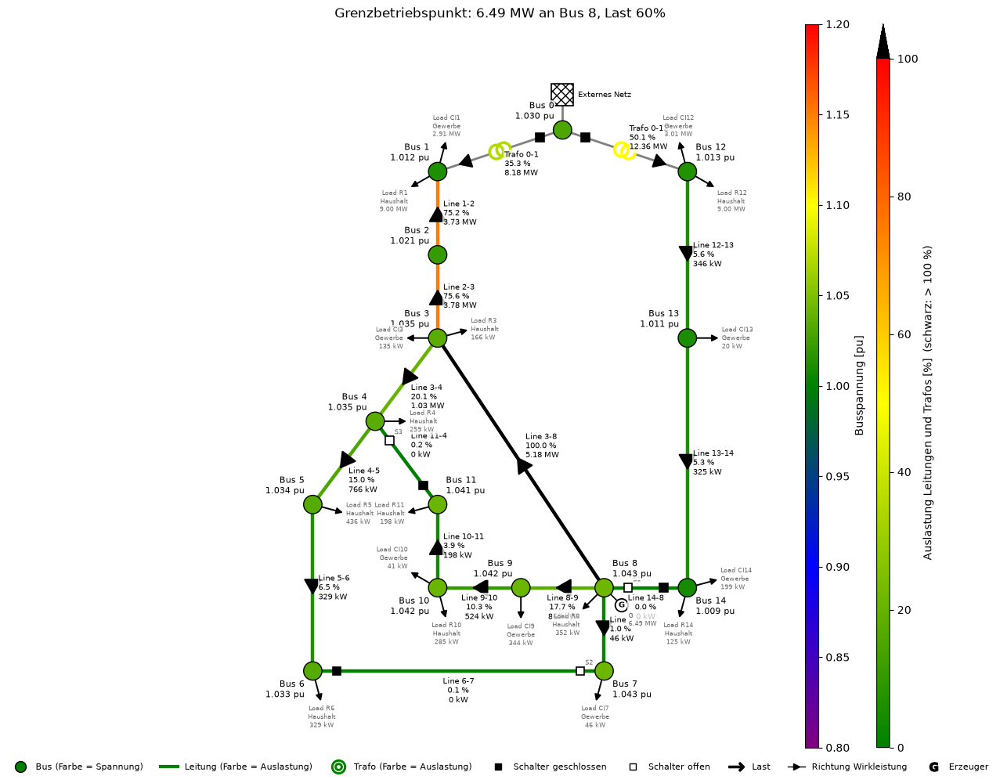

In [199]:
G_HAUPT = grenze(bus8[LF_HAUPT])
P_GRENZ = round(G_HAUPT["Grenzleistung [MW]"], 2)
n_grenz = grenzbetrieb("Bus 8", P_GRENZ)
print(f"Grenzbetriebspunkt: {P_GRENZ:.2f} MW an Bus 8, Last {LF_HAUPT:.0%}, alle Schalter offen")
display(plots.table(leitungstabelle(n_grenz), decimals=1))
spannungen = pd.DataFrame({"U [pu]": n_grenz.res_bus.vm_pu.to_numpy(), "Winkel [°]": n_grenz.res_bus.va_degree.to_numpy()},
                          index=n_grenz.bus["name"])
display(spannungen.T.round(4))
_ = netplan.plot_static(n_grenz, title=f"Grenzbetriebspunkt: {P_GRENZ:.2f} MW an Bus 8, Last {LF_HAUPT:.0%}")

**Grenzbetriebspunkt (Hauptszenario):**

| Größe | Wert |
|---|---|
| Einspeisung an Bus 8 | **6,49 MW**, cos φ = 1 |
| Last | 60 % der Bemessungslast (26,8 MW) |
| Line 3-8 | **145,0 A von 145 A = 100,0 %**, 5,2 MW von Bus 8 zu Bus 3 |
| Line 2-3 / Line 1-2 | 109,6 A / 109,1 A von 145 A = 75,6 % / 75,2 % |
| alle übrigen Leitungen | höchstens 20 % (Line 3-4) |
| Spannungen MS | 1,009 bis 1,043 pu (im Planungsband) |

- Line 3-8 erreicht als erste und einzige Leitung 100 %. Die nächste Leitung hat mit rund 25 Prozentpunkten deutlich Abstand. Damit ist die Forderung der Aufgabe erfüllt.
- Die Stromgrenze ist der unveränderte Wert des Referenznetzes (145 A).
- Die Leistung fließt von Bus 8 über Line 3-8 und weiter über Line 2-3 und 1-2 zu Bus 1. Dort nimmt die große Last (11,9 MW bei 60 %) sie vollständig auf; Trafo 0-1 führt weiter Leistung in Bezugsrichtung (35 %).

## 4 Alle Schalterstellungen

Dasselbe Vorgehen wie in 3.2 (Einspeisung an Bus 8, 60 % Last) für alle acht Schaltzustände. Für Zustände, in denen Line 3-8 nicht zuerst an die Grenze kommt, wird zusätzlich geprüft, ob ein anderer Einspeiseort (Bus 2 bis Bus 14) das ändert.

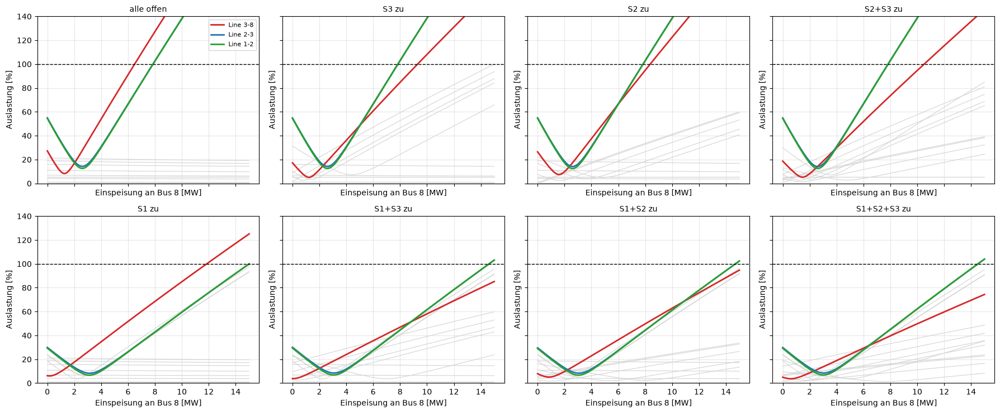

,Grenzleistung [MW],erste Leitung,zweite Leitung,Auslastung zweite Leitung [%],Line 3-8 im Grenzpunkt [%]
alle offen,6.488459,Line 3-8,Line 2-3,75.733687,100.00
S3 zu,7.832455,Line 2-3,Line 1-2,100.946617,82.72
S2 zu,7.833734,Line 2-3,Line 1-2,100.921581,92.47
S2+S3 zu,7.827429,Line 2-3,Line 1-2,101.042366,71.66
S1 zu,11.847162,Line 3-8,Line 1-2,75.061306,100.00
S1+S3 zu,14.617704,Line 1-2,Line 2-3,100.646753,83.13
S1+S2 zu,14.704533,Line 1-2,Line 2-3,100.746340,92.84
S1+S2+S3 zu,14.514219,Line 1-2,Line 2-3,100.677859,71.98


In [200]:
schalter = {k: sweep_einspeisung("Bus 8", key=k) for k in KEYS}
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharex=True, sharey=True)
for ax, k in zip(axes.flat, KEYS):
    lastfluss_plot(ax, schalter[k], linear=False)
    ax.set_title(LABEL[k], fontsize=10)
    ax.set_ylim(0, 140)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

s_tab = pd.DataFrame({LABEL[k]: grenze(schalter[k]) for k in KEYS}).T
s_tab["Line 3-8 im Grenzpunkt [%]"] = [np.interp(g, schalter[k].index, schalter[k][LEITUNG]) if not np.isnan(g) else np.nan
                                       for k, g in zip(KEYS, s_tab["Grenzleistung [MW]"].astype(float))]
plots.table(s_tab, decimals=2)

In [201]:
ALLE_ORTE = [f"Bus {i}" for i in range(2, 15)]
zeilen = {}
for k in KEYS:
    if s_tab.loc[LABEL[k], "erste Leitung"] == LEITUNG:
        continue
    for b in ALLE_ORTE:
        g = grenze(sweep_einspeisung(b, key=k))
        if g["erste Leitung"] == LEITUNG:
            zeilen[(LABEL[k], b)] = g
alternativ = pd.DataFrame(zeilen).T
if len(alternativ):
    display(plots.table(alternativ, decimals=2))
else:
    print("In keinem dieser Schaltzustände erreicht Line 3-8 bei Einspeisung an einem anderen Bus zuerst 100 %.")

In keinem dieser Schaltzustände erreicht Line 3-8 bei Einspeisung an einem anderen Bus zuerst 100 %.


**Ergebnis Schalterstellungen:**

| Zustand | erste Leitung bei 100 % | Grenzleistung | Line 3-8 dann |
|---|---|---|---|
| alle offen | **Line 3-8** | 6,49 MW | 100 % |
| S1 zu | **Line 3-8** | 11,85 MW | 100 % |
| S2 und/oder S3 zu | Line 2-3 | 7,83 MW | 72 bis 92 % |
| S1 mit S2 und/oder S3 zu | Line 1-2 | 14,5 bis 14,7 MW | 72 bis 93 % |

- **S1 zu:** Die Einspeisung teilt sich an Bus 8 auf: Ein Teil fließt über Line 3-8 in Abgang 1, ein Teil über die Kupplung und Abgang 2 zur großen Last an Bus 12. Line 3-8 bleibt der Engpass, aber erst bei fast doppelter Leistung.
- **S2 oder S3 zu:** Die Masche schafft einen zweiten Weg von Bus 8 zu Bus 3 (über Bus 7–6–5–4 bzw. Bus 9–10–11–4). Die Leistung teilt sich nach den Impedanzen auf [19, S. 437 f., 806 f.], Line 3-8 wird entlastet. Den ganzen Rückfluss trägt dann Line 2-3, die bei 7,83 MW als erste überlastet ist.
- **S1 mit S2 oder S3:** Beide Effekte zusammen; zuerst wird Line 1-2 überlastet.
- In den Zuständen mit S2 oder S3 erreicht Line 3-8 auch mit einem anderen Einspeiseort (Bus 2 bis 14) nie zuerst 100 %. **Begründung:** Line 3-8 liegt dann in einer Masche, und jede Einspeisung teilt sich auf beide Wege auf. Die Summe beider Wege muss aber über Line 2-3 bzw. 1-2 abfließen, und diese Leitungen erreichen ihre Grenze zuerst. Das Hauptszenario und die Kapazitätserhöhung beziehen sich deshalb auf den Normalschaltzustand (alle offen); die übrigen Zustände werden in Abschnitt 6 und 7 mitgerechnet.

## 5 Sensitivität der Stromgrenze (gesondert gekennzeichnet)

**Achtung:** Dieser Abschnitt ist eine Sensitivität und kein Nachweis eines Engpasses. Eine andere Stromgrenze ändert den Strom auf der Leitung nicht, nur die Bewertung in Prozent. Untersucht wird, wie sich die Grenzleistung im Hauptszenario verschiebt, wenn die Stromgrenze von Line 3-8 linear zwischen 100 und 250 A variiert wird. Markiert sind:

- **145 A:** Wert des Referenznetzes (verwendet in allen anderen Abschnitten)
- **172 A / 210 A:** Datenblattwerte NA2XS2Y 1×50 bzw. 1×70 in Erde unter Bezugsbedingungen [26]
- **ca. 120 A:** Beispiel für ungünstige Verlegebedingungen (Häufung, warmer Boden); die Umrechnungsfaktoren nach DIN VDE 0276-1000 [28] liegen dann unter 1

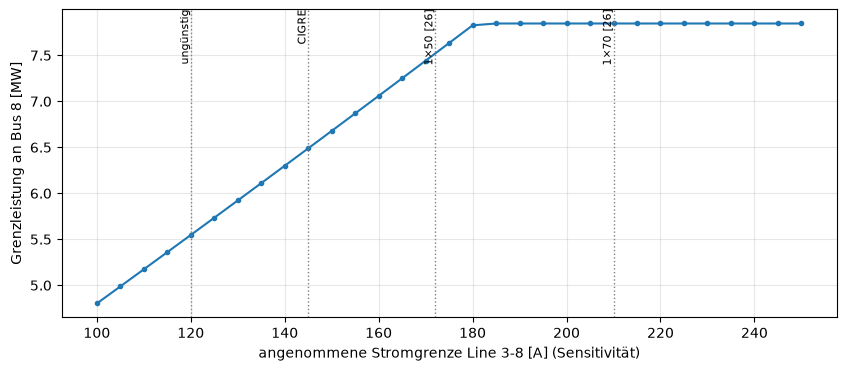

,Grenzleistung [MW],erste Leitung,zweite Leitung,Auslastung zweite Leitung [%]
120,5.546775,Line 3-8,Line 2-3,59.395472
145,6.488459,Line 3-8,Line 2-3,75.733687
170,7.441835,Line 3-8,Line 2-3,93.786636
210,7.846177,Line 2-3,Line 1-2,100.685285
250,7.846177,Line 2-3,Line 1-2,100.685285


In [202]:
i_werte = np.arange(0.100, 0.2501, 0.005)
sens = {}
for i_max in i_werte:
    df = bus8[LF_HAUPT].copy()
    df[LEITUNG] = df[LEITUNG] * 0.145 / i_max                # gleicher Strom, andere Bezugsgröße
    sens[round(i_max * 1000)] = grenze(df)
sens = pd.DataFrame(sens).T
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sens.index, sens["Grenzleistung [MW]"].astype(float), "o-", ms=3)
for i, txt in ((120, "ungünstig"), (145, "CIGRE"), (172, "1×50 [26]"), (210, "1×70 [26]")):
    ax.axvline(i, color="gray", ls=":", lw=1)
    ax.text(i, ax.get_ylim()[1], txt, rotation=90, va="top", ha="right", fontsize=8)
ax.set_xlabel("angenommene Stromgrenze Line 3-8 [A] (Sensitivität)")
ax.set_ylabel("Grenzleistung an Bus 8 [MW]")
ax.grid(alpha=0.3)
plt.show()
plots.table(sens.loc[[120, 145, 170, 210, 250]], decimals=2)

**Ergebnis Sensitivität (nur Bewertung, nicht der Strom ändert sich):**

| angenommene Stromgrenze | Grenzleistung | erste Leitung |
|---|---|---|
| 120 A (ungünstige Verlegung) | 5,55 MW | Line 3-8 |
| **145 A (Referenznetz)** | **6,49 MW** | **Line 3-8** |
| 170 A (≈ 1×50 nach Datenblatt) | 7,44 MW | Line 3-8 |
| ab etwa 180 A (z. B. 210 A ≈ 1×70) | 7,85 MW | Line 2-3 |

- Die Grenzleistung steigt bis etwa 180 A linear mit der Stromgrenze, weil der Strom auf Line 3-8 nach der Umkehr fast linear mit der Einspeisung wächst.
- Ab etwa 180 A bestimmt nicht mehr Line 3-8 die Grenze, sondern Line 2-3. Eine höhere Stromgrenze bringt dann nichts mehr. Das zeigt schon vor jeder Maßnahme, wo der Engpass sich hin verlagern wird.
- Der Engpass auf Line 3-8 hängt also davon ab, mit welcher Belastbarkeit gerechnet wird. Mit den Datenblattwerten für 70 mm² unter Bezugsbedingungen wäre Line 3-8 kein Engpass. Deshalb wird im Weiteren bewusst der Wert des Referenznetzes verwendet.

## 6 Kapazitätserhöhung

### 6.1 Auswahl der Maßnahme

Zwei technische Maßnahmen werden verglichen:

- **Maßnahme A – Leitungsersatz:** Line 3-8 wird durch ein NA2XS2Y-Einleiterkabel 12/20 kV mit größerem Querschnitt ersetzt (pandapower-Standardtypen [25], Datenblattwerte [26]).
- **Maßnahme B – Parallelkabel:** Ein zweites Kabel `CABLE_CIGRE_MV` wird parallel verlegt (`parallel = 2`): doppelte Stromgrenze, halbe Impedanz.

Für jeden Querschnitt wird die Einspeisung an Bus 8 wieder linear erhöht (Hauptszenario). Gesucht ist der kleinste Querschnitt, ab dem nicht mehr Line 3-8 die Grenzleistung bestimmt; ein größerer Querschnitt bringt dann keinen Gewinn mehr, weil eine andere Leitung zuerst überlastet wird [19, S. 799 f.].

In [203]:
TYPEN = ["NA2XS2Y 1x70 RM/25 12/20 kV", "NA2XS2Y 1x95 RM/25 12/20 kV", "NA2XS2Y 1x120 RM/25 12/20 kV",
         "NA2XS2Y 1x150 RM/25 12/20 kV", "NA2XS2Y 1x185 RM/25 12/20 kV", "NA2XS2Y 1x240 RM/25 12/20 kV"]
idx38 = int(BASIS.line.index[BASIS.line["name"] == LEITUNG][0])

def ersatz(typ):
    return lambda n: pp.change_std_type(n, idx38, typ, element="line")

def parallel(n):
    n.line.at[idx38, "parallel"] = 2

varianten = {"vorher (CABLE_CIGRE_MV)": None, **{t.split(" RM")[0]: ersatz(t) for t in TYPEN}, "Parallelkabel (2 × CABLE_CIGRE_MV)": parallel}
st = pp.available_std_types(BASIS, "line")
auswahl = {}
for name, mod in varianten.items():
    n = netz(LF_HAUPT, leitung=mod)
    l = n.line.loc[idx38]
    auswahl[name] = {"R′ [Ω/km]": l.r_ohm_per_km, "X′ [Ω/km]": l.x_ohm_per_km, "C′ [nF/km]": l.c_nf_per_km,
                     "I_max [A]": l.max_i_ka * l.parallel * 1000,
                     "Z Line 3-8 [Ω]": abs(complex(l.r_ohm_per_km, l.x_ohm_per_km)) * l.length_km / l.parallel,
                     **grenze(sweep_einspeisung("Bus 8", leitung=mod))}
auswahl = pd.DataFrame(auswahl).T
plots.table(auswahl, decimals=3)

,R′ [Ω/km],X′ [Ω/km],C′ [nF/km],I_max [A],Z Line 3-8 [Ω],Grenzleistung [MW],erste Leitung,zweite Leitung,Auslastung zweite Leitung [%]
vorher (CABLE_CIGRE_MV),0.501000,0.716000,151.174900,145.000000,1.136037,6.488459,Line 3-8,Line 2-3,75.733687
NA2XS2Y 1x70,0.443000,0.132000,190.000000,220.000000,0.600922,7.858588,Line 2-3,Line 1-2,100.488212
NA2XS2Y 1x95,0.313000,0.132000,216.000000,252.000000,0.441604,7.843038,Line 2-3,Line 1-2,100.772864
NA2XS2Y 1x120,0.253000,0.119000,230.000000,283.000000,0.363466,7.836327,Line 2-3,Line 1-2,100.897316
NA2XS2Y 1x150,0.206000,0.116000,250.000000,319.000000,0.307339,7.831230,Line 2-3,Line 1-2,100.992575
NA2XS2Y 1x185,0.161000,0.117000,273.000000,362.000000,0.258729,7.826391,Line 2-3,Line 1-2,101.083448
NA2XS2Y 1x240,0.122000,0.112000,304.000000,421.000000,0.215298,7.822822,Line 2-3,Line 1-2,101.151997
Parallelkabel (2 × CABLE_CIGRE_MV),0.501000,0.716000,151.174900,290.000000,0.568019,7.831909,Line 2-3,Line 1-2,100.973347


In [204]:
MASSNAHME_A = next(name for name in auswahl.index[1:-1] if auswahl.loc[name, "erste Leitung"] != LEITUNG)
MASSNAHMEN = {"vorher": None, f"A: {MASSNAHME_A}": varianten[MASSNAHME_A], "B: Parallelkabel": parallel}
print("Maßnahme A (kleinster Querschnitt, ab dem Line 3-8 nicht mehr begrenzt):", MASSNAHME_A)

Maßnahme A (kleinster Querschnitt, ab dem Line 3-8 nicht mehr begrenzt): NA2XS2Y 1x70


**Auswahl der Maßnahme:**

- Schon das kleinste untersuchte Kabel, **NA2XS2Y 1×70 12/20 kV** (220 A [25]; nach Datenblatt in Erde 210 A [26]), hebt den Engpass auf Line 3-8 auf. Die Grenzleistung steigt von 6,49 auf 7,86 MW, danach ist Line 2-3 zuerst überlastet.
- Größere Querschnitte bringen **keinen** weiteren Gewinn (7,82 bis 7,86 MW), weil Line 2-3 die Grenze bestimmt. Nach dem Grundsatz, den kleinsten ausreichenden genormten Querschnitt zu wählen [19, S. 799 f.], ist das 1×70-Kabel die Maßnahme A.
- **Parallelkabel (Maßnahme B):** doppelte Stromgrenze (290 A) und halbe Impedanz. Es erreicht dieselbe Grenzleistung (7,83 MW).
- Beide Maßnahmen halbieren die Impedanz von Line 3-8 etwa (1,14 → 0,60 bzw. 0,57 Ω). Beim 1×70-Kabel liegt das nicht am Widerstand (R′ fast gleich), sondern an der viel kleineren Reaktanz (X′ 0,132 statt 0,716 Ω/km).

### 6.2 Vorher und Nachher unter identischen Randbedingungen

Gleiche Einspeisung (Grenzleistung aus 3.3) an Bus 8, gleiche Last (60 %), für alle acht Schaltzustände. Alle Werte als Differenz **nachher − vorher**.

In [205]:
def zustand(mod, key):
    n = grenzbetrieb("Bus 8", P_GRENZ, key=key, leitung=mod)
    return {"I": pd.Series(n.res_line.i_ka.to_numpy() * 1000, index=n.line["name"]),
            "A": pd.Series(n.res_line.loading_percent.to_numpy(), index=n.line["name"]),
            "P": pd.Series(n.res_line.p_from_mw.to_numpy(), index=n.line["name"]),
            "U": pd.Series(n.res_bus.vm_pu.to_numpy(), index=n.bus["name"]),
            "T": pd.Series(n.res_trafo.loading_percent.to_numpy(), index=n.trafo["name"]),
            "V": float(n.res_line.pl_mw.sum() + n.res_trafo.pl_mw.sum()),
            "Ptr": pd.Series(n.res_trafo.p_hv_mw.to_numpy(), index=n.trafo["name"])}

vergleich = {m: {k: zustand(mod, k) for k in KEYS} for m, mod in MASSNAHMEN.items()}
NACH = [m for m in MASSNAHMEN if m != "vorher"]

def diff(groesse, m, faktor=1.0):
    return pd.DataFrame({LABEL[k]: (vergleich[m][k][groesse] - vergleich["vorher"][k][groesse]) * faktor for k in KEYS})

for m in NACH:
    print(f"{m}: Änderung der Auslastung aller Leitungen [Prozentpunkte]")
    display(plots.table(diff("A", m), decimals=1, cmap="RdBu_r", vmin=-40, vmax=40))

A: NA2XS2Y 1x70: Änderung der Auslastung aller Leitungen [Prozentpunkte]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Line 1-2,-0.2,-0.2,-0.2,-0.1,2.5,1.3,1.5,1.0
Line 2-3,-0.2,-0.2,-0.2,-0.2,2.5,1.3,1.5,1.0
Line 3-4,-0.0,-9.9,-4.4,-12.9,-0.0,6.0,4.3,-1.9
Line 4-5,-0.0,-0.0,-7.6,-3.1,-0.0,0.0,0.6,2.2
Line 5-6,-0.0,-0.0,-8.0,-3.9,-0.0,0.0,-4.0,-2.0
Line 7-8,-0.0,-0.0,-8.0,-3.8,0.0,0.0,-4.3,-2.2
Line 8-9,-0.0,-11.0,-0.0,-7.5,0.0,-6.3,0.0,-4.2
Line 9-10,-0.0,-11.9,-0.0,-8.3,0.0,-6.8,0.0,-4.6
Line 10-11,-0.0,-12.1,-0.0,-8.6,0.0,-6.9,0.0,-4.7


B: Parallelkabel: Änderung der Auslastung aller Leitungen [Prozentpunkte]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Line 1-2,0.1,0.0,0.0,-0.0,2.0,1.1,1.2,0.8
Line 2-3,0.1,-0.0,0.0,-0.0,1.9,1.0,1.2,0.8
Line 3-4,-0.0,-9.4,-4.2,-13.9,-0.0,5.6,4.1,-2.8
Line 4-5,-0.0,-0.0,-8.4,-2.8,-0.0,-0.0,-0.2,2.2
Line 5-6,-0.0,-0.0,-9.0,-4.7,-0.0,-0.0,-4.7,-2.5
Line 7-8,0.0,0.0,-9.0,-4.6,0.0,0.0,-4.7,-2.5
Line 8-9,0.0,-13.5,0.0,-9.7,0.0,-7.6,0.0,-5.3
Line 9-10,0.0,-13.6,0.0,-9.8,0.0,-7.6,0.0,-5.3
Line 10-11,0.0,-13.6,0.0,-9.9,0.0,-7.6,0.0,-5.3


In [206]:
print("Auslastung aller Leitungen vorher und nachher [%]")
absolut = pd.concat({m: pd.DataFrame({LABEL[k]: vergleich[m][k]["A"] for k in KEYS}) for m in MASSNAHMEN}, axis=1)
plots.table(absolut, decimals=1, cmap="YlOrRd", vmin=0, vmax=110)

Auslastung aller Leitungen vorher und nachher [%]


In [207]:
for m in NACH:
    print(f"{m}: Änderung des Wirkleistungsflusses p_from_mw [MW] (Lastflussverteilung)")
    display(plots.table(diff("P", m), decimals=3, cmap="RdBu_r", vmin=-2, vmax=2))

A: NA2XS2Y 1x70: Änderung des Wirkleistungsflusses p_from_mw [MW] (Lastflussverteilung)


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Line 1-2,-0.005,0.000,-0.001,0.001,-0.120,-0.061,-0.071,-0.046
Line 2-3,-0.005,0.001,-0.001,0.001,-0.121,-0.062,-0.072,-0.047
Line 3-4,-0.000,0.736,0.497,0.753,-0.000,0.442,0.277,0.443
Line 4-5,-0.000,-0.000,0.497,0.243,-0.000,0.000,0.277,0.143
Line 5-6,-0.000,-0.000,0.498,0.243,-0.000,0.000,0.277,0.143
Line 7-8,0.000,0.000,0.499,0.244,0.000,-0.000,0.278,0.143
Line 8-9,-0.000,-0.742,-0.000,-0.514,0.000,-0.444,0.000,-0.301
Line 9-10,-0.000,-0.741,-0.000,-0.513,0.000,-0.444,0.000,-0.301
Line 10-11,-0.000,-0.738,-0.000,-0.512,0.000,-0.443,0.000,-0.300


B: Parallelkabel: Änderung des Wirkleistungsflusses p_from_mw [MW] (Lastflussverteilung)


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Line 1-2,-0.020,-0.011,-0.012,-0.008,-0.103,-0.056,-0.063,-0.043
Line 2-3,-0.020,-0.011,-0.012,-0.008,-0.104,-0.056,-0.064,-0.044
Line 3-4,-0.000,0.707,0.468,0.753,-0.000,0.394,0.244,0.407
Line 4-5,-0.000,-0.000,0.468,0.243,-0.000,-0.000,0.244,0.131
Line 5-6,-0.000,-0.000,0.468,0.243,-0.000,-0.000,0.244,0.131
Line 7-8,-0.000,-0.000,0.470,0.244,-0.000,-0.000,0.245,0.132
Line 8-9,0.000,-0.713,0.000,-0.514,0.000,-0.396,0.000,-0.277
Line 9-10,0.000,-0.712,0.000,-0.513,0.000,-0.395,0.000,-0.277
Line 10-11,0.000,-0.710,0.000,-0.512,0.000,-0.394,0.000,-0.276


In [208]:
for m in NACH:
    print(f"{m}: Änderung der Spannung an allen Bussen [Prozentpunkte]")
    display(plots.table(diff("U", m, 100), decimals=2, cmap="RdBu", vmin=-1.5, vmax=1.5))

A: NA2XS2Y 1x70: Änderung der Spannung an allen Bussen [Prozentpunkte]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,0.03,0.02,0.02,0.01,-0.02,-0.02,-0.02,-0.01
Bus 2,0.06,0.03,0.04,0.03,-0.01,-0.01,-0.01,-0.01
Bus 3,0.10,0.06,0.07,0.05,0.01,-0.01,-0.01,-0.01
Bus 4,0.10,0.07,0.07,0.07,0.01,-0.01,-0.01,-0.01
Bus 5,0.10,0.07,0.08,0.08,0.01,-0.01,-0.01,-0.01
Bus 6,0.10,0.07,0.10,0.09,0.01,-0.01,-0.01,-0.00
Bus 7,0.08,0.12,0.10,0.10,-0.04,-0.01,-0.01,-0.00
Bus 8,0.08,0.12,0.12,0.11,-0.04,-0.01,-0.01,0.00


B: Parallelkabel: Änderung der Spannung an allen Bussen [Prozentpunkte]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,0.03,0.02,0.02,0.02,0.01,0.01,0.01,0.01
Bus 2,0.06,0.05,0.05,0.04,0.06,0.04,0.04,0.03
Bus 3,0.11,0.08,0.09,0.07,0.13,0.08,0.09,0.07
Bus 4,0.11,0.04,0.06,0.03,0.13,0.05,0.07,0.04
Bus 5,0.11,0.04,0.03,0.01,0.13,0.05,0.05,0.03
Bus 6,0.11,0.04,-0.04,-0.03,0.13,0.05,0.00,0.00
Bus 7,-0.24,-0.11,-0.05,-0.03,-0.10,-0.05,-0.00,-0.00
Bus 8,-0.24,-0.11,-0.14,-0.08,-0.10,-0.05,-0.05,-0.03


In [209]:
zeilen = {}
for m in MASSNAHMEN:
    for k in KEYS:
        v = vergleich[m][k]
        zeilen[(m, LABEL[k])] = {"Verluste [kW]": v["V"] * 1000, "Line 3-8 [%]": v["A"][LEITUNG],
                                 "höchstbelastete Leitung": v["A"].idxmax(), "Auslastung [%]": v["A"].max(),
                                 "U max MS [pu]": v["U"][MS_BUSSE].max(), "U min MS [pu]": v["U"][MS_BUSSE].min(),
                                 "Trafo 0-1 [%]": v["T"]["Trafo 0-1"], "Trafo 0-12 [%]": v["T"]["Trafo 0-12"]}
uebersicht = pd.DataFrame(zeilen).T
display(plots.table(uebersicht, decimals=3))
verl = pd.DataFrame({m: [vergleich[m][k]["V"] * 1000 - vergleich["vorher"][k]["V"] * 1000 for k in KEYS] for m in NACH},
                    index=[LABEL[k] for k in KEYS])
print("Änderung der Verluste [kW]")
verl.round(1).T

Änderung der Verluste [kW]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
A: NA2XS2Y 1x70,-5.4,0.4,-1.1,0.9,-3.8,-1.1,-1.7,-0.7
B: Parallelkabel,-20.1,-11.0,-12.3,-8.5,-8.0,-4.6,-4.7,-3.4


**Vorher und Nachher bei gleicher Einspeisung (6,49 MW, 60 % Last):**

- **Line 3-8:** Im Normalzustand sinkt die Auslastung von 100 % auf 66 % (A) bzw. 50 % (B). In den anderen Zuständen sinkt sie ebenfalls (um 4 bis 50 Prozentpunkte).
- **Lastflussverteilung im Normalzustand:** Sie bleibt unverändert. Im Strahlennetz bestimmen Einspeisung und Lasten die Flüsse, die Impedanz einer Leitung ändert nur deren Strom-Bezugsgröße und Verluste.
- **Lastflussverteilung in vermaschten Zuständen:** Die Maßnahme verschiebt Leistung, weil Line 3-8 jetzt eine niedrigere Impedanz hat und mehr Leistung an sich zieht [19, S. 437 f.].
  - **S2 und S3:** Die Leitungen der Maschen werden um 4 bis 14 Prozentpunkte entlastet.
  - **S1:** Mehr Einspeisung fließt über Line 3-8 nach Abgang 1 statt über die Kupplung nach Abgang 2. Line 1-2 und 2-3 steigen um 1 bis 2,5 Prozentpunkte, Abgang 2 sinkt um 1 bis 2 Prozentpunkte.
- **Spannungen:** Sie ändern sich an allen Bussen um höchstens 0,25 Prozentpunkte. Mit dem Parallelkabel sinkt die Spannung an Bus 7 bis 11 leicht (bis −0,24 Prozentpunkte), weil der Spannungsanstieg über Line 3-8 kleiner wird.
- **Verluste:** Im Normalzustand sinken sie um 5 kW (A, −3 %) bzw. 20 kW (B, −11 %). In den anderen Zuständen ist die Änderung kleiner; mit A steigen sie bei geschlossenem S3 sogar minimal.
- **Neue Engpässe:** Bei dieser Einspeisung gibt es keine. Line 2-3 und 1-2 bleiben bei 75 %.

## 7 Entschärft oder verlagert?

Mit Maßnahme wird die Einspeisung an Bus 8 erneut linear erhöht, bis die nächste Leitung 100 % erreicht, in allen Schaltzuständen. So zeigt sich, wie viel zusätzliche Leistung die Maßnahme ermöglicht und welche Leitung danach den Engpass bildet.

In [210]:
nachher = {m: {k: sweep_einspeisung("Bus 8", key=k, leitung=mod) for k in KEYS} for m, mod in MASSNAHMEN.items()}
zeilen = {}
for k in KEYS:
    for m in MASSNAHMEN:
        g = grenze(nachher[m][k])
        zeilen[(LABEL[k], m)] = {**g}
    zeilen[(LABEL[k], "vorher")]["Gewinn [MW]"] = 0.0
    for m in NACH:
        zeilen[(LABEL[k], m)]["Gewinn [MW]"] = zeilen[(LABEL[k], m)]["Grenzleistung [MW]"] - zeilen[(LABEL[k], "vorher")]["Grenzleistung [MW]"]
verlagerung = pd.DataFrame(zeilen).T
plots.table(verlagerung, decimals=2)

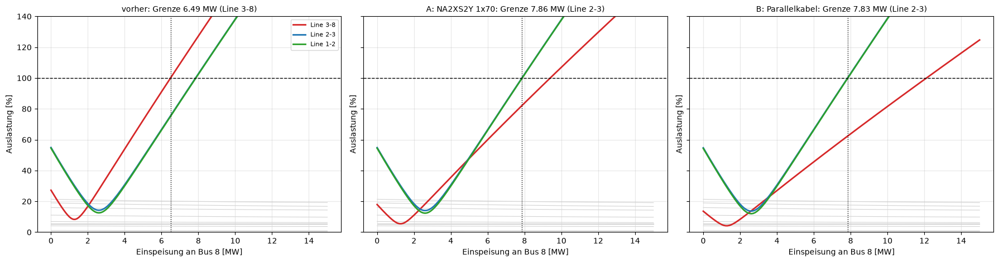

In [211]:
fig, axes = plt.subplots(1, len(MASSNAHMEN), figsize=(18, 4.8), sharey=True)
for ax, m in zip(axes, MASSNAHMEN):
    lastfluss_plot(ax, nachher[m]["000"], linear=False)
    g = grenze(nachher[m]["000"])
    ax.axvline(g["Grenzleistung [MW]"], color="black", ls=":", lw=1)
    ax.set_title(f"{m}: Grenze {g['Grenzleistung [MW]']:.2f} MW ({g['erste Leitung']})", fontsize=10)
    ax.set_ylim(0, 140)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Neuer Grenzbetriebspunkt mit A: NA2XS2Y 1x70: 7.86 MW, erste Leitung Line 2-3


,Typ,Länge [km],parallel,I [A],I_max [A],Auslastung [%],P von from_bus [MW]
name,,,,,,,
Line 2-3,CABLE_CIGRE_MV,4.4,1.0,145.0,145.0,100.0,-5.1
Line 1-2,CABLE_CIGRE_MV,2.8,1.0,144.7,145.0,99.8,-5.0
Line 3-8,NA2XS2Y 1x70 RM/25 12/20 kV,1.3,1.0,180.7,220.0,82.1,-6.5
Line 3-4,CABLE_CIGRE_MV,0.6,1.0,28.9,145.0,19.9,1.0
Line 8-9,CABLE_CIGRE_MV,0.3,1.0,25.4,145.0,17.5,0.9
Line 4-5,CABLE_CIGRE_MV,0.6,1.0,21.6,145.0,14.9,0.8
Line 9-10,CABLE_CIGRE_MV,0.8,1.0,14.8,145.0,10.2,0.5
Line 5-6,CABLE_CIGRE_MV,1.5,1.0,9.3,145.0,6.4,0.3
Line 12-13,OHL_CIGRE_MV,4.9,1.0,10.9,195.0,5.6,0.3


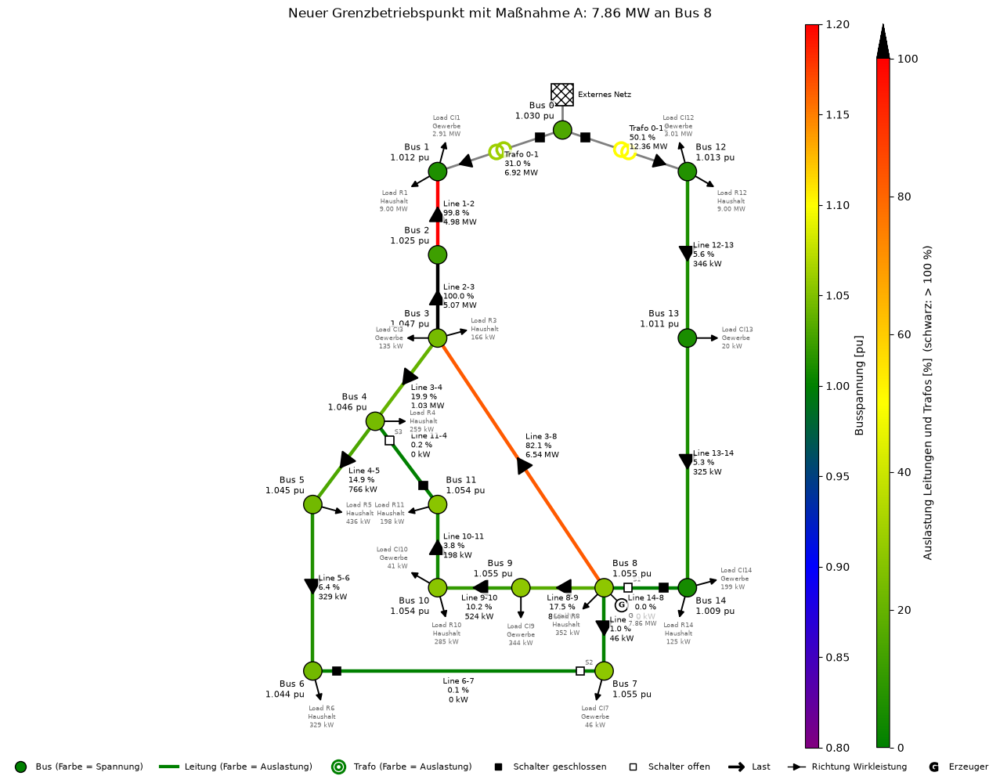

In [212]:
m_a = f"A: {MASSNAHME_A}"
g = grenze(nachher[m_a]["000"])
n_neu = grenzbetrieb("Bus 8", round(g["Grenzleistung [MW]"], 2), leitung=MASSNAHMEN[m_a])
print(f"Neuer Grenzbetriebspunkt mit {m_a}: {g['Grenzleistung [MW]']:.2f} MW, erste Leitung {g['erste Leitung']}")
display(plots.table(leitungstabelle(n_neu), decimals=1))
_ = netplan.plot_static(n_neu, title=f"Neuer Grenzbetriebspunkt mit Maßnahme A: {g['Grenzleistung [MW]']:.2f} MW an Bus 8")

**Entschärft oder verlagert?**

| Zustand | vorher | A: NA2XS2Y 1×70 | B: Parallelkabel | Engpass danach |
|---|---|---|---|---|
| alle offen | 6,49 MW (Line 3-8) | 7,86 MW (+1,37) | 7,83 MW (+1,34) | Line 2-3 |
| S1 zu | 11,85 MW (Line 3-8) | 14,36 MW (+2,51) | 14,43 MW (+2,59) | Line 1-2 |
| S2 und/oder S3 zu | 7,83 MW (Line 2-3) | ±0,01 MW | ±0,01 MW | Line 2-3 |
| S1 mit S2/S3 zu | 14,5–14,7 MW (Line 1-2) | −0,25 bis −0,40 MW | −0,24 bis −0,37 MW | Line 1-2 |

- **Der Engpass wird verlagert, nicht beseitigt.** Im Normalzustand steigt die aufnehmbare Leistung um rund 1,4 MW (+21 %). Danach erreicht Line 2-3 die Grenze, Line 1-2 liegt mit 99,8 % gleichauf. Line 3-8 ist im neuen Grenzpunkt nur noch zu 82 % ausgelastet.
- **In den Maschenzuständen** bringt die Maßnahme nichts, weil Line 3-8 dort ohnehin nicht der Engpass war.
- **Mit S1 und einer Masche** sinkt die Grenzleistung sogar leicht. Die niedrigere Impedanz von Line 3-8 zieht mehr Einspeisung in Richtung Abgang 1 und damit auf Line 1-2, statt sie über die Kupplung nach Abgang 2 zu leiten. Das ist der in [19, S. 437 f.] beschriebene Effekt, dass Leitungen niedriger Impedanz in Maschen zusätzlich belastet werden.
- **Konsequenz:** Für mehr Einspeisung an Bus 8 müssten auch Line 2-3 und 1-2 verstärkt werden, zusammen 7,2 km Kabel statt 1,3 km. Alternativ lässt sich die Grenze ohne Leitungsbau verschieben: durch Spitzenkappung (Abregelung von höchstens 3 % der Jahresenergie, EnWG § 11 Abs. 2 [39]) oder durch einen Anschluss großer Anlagen direkt an der Umspannwerks-Sammelschiene, wie in Teil 4.

## 8 Fazit

- **Laständerung allein** kann Line 3-8 nicht zuerst überlasten: Die vorgelagerten Kabel Line 2-3 und 1-2 tragen die Summe aller Lasten dahinter und erreichen ihre Grenze immer zuerst.
- **Einspeisung am Ende von Line 3-8 (Bus 8)** macht die Leitung zum Engpass, weil die Einspeisung zuerst über Line 3-8 zurückfließt. Grenzbetriebspunkt bei 60 % Last und alle Schalter offen: **6,49 MW**. Line 3-8 führt dann 145 A von 145 A, Line 2-3 und 1-2 rund 110 A (76 %), alle anderen Leitungen höchstens 20 %.
- **Schalterstellungen:** Mit S1 bleibt Line 3-8 der Engpass, aber erst bei 11,85 MW. Mit S2 oder S3 liegt Line 3-8 in einer Masche und kann nie zuerst überlastet werden.
- **Stromgrenze:** 145 A sind für ein Al-Kabel mit 50 bis 70 mm² vorsichtig angesetzt (Datenblatt in Erde 172 bis 210 A). Mit mehr als etwa 180 A wäre Line 3-8 kein Engpass mehr.
- **Kapazitätserhöhung:** Ein NA2XS2Y 1×70 oder ein Parallelkabel hebt den Engpass auf Line 3-8 auf und erhöht die aufnehmbare Leistung um etwa 1,4 MW (+21 %). Größere Querschnitte bringen nichts mehr. Spannungen ändern sich kaum, die Verluste sinken leicht.
- **Bewertung:** Der Engpass wird auf Line 2-3 und 1-2 **verlagert**. In vermaschten Zuständen zieht die stärkere Leitung zusätzlich Leistung an und kann die Grenze sogar leicht senken. Eine echte Entlastung bräuchte die Verstärkung des ganzen Wegs bis Bus 1 oder Maßnahmen ohne Leitungsbau (Blindleistung, Spitzenkappung), die in Teil 9 aufgegriffen werden.

<a id="teil-9"></a>

---

# Task 4 – Teil 7: Methodik, Darstellung und Interpretation

Dieses Notebook fasst die Methodik aller Teile zusammen: wie die Kenngrößen definiert sind, welche Größen in welcher Teilstudie verändert wurden, wie Beobachtungen physikalisch erklärt werden und wo die Modellgrenzen liegen. Außerdem werden für **alle** Zeitreihen die Spannungen an sämtlichen MV- und LV-Bussen und die Konvergenz vollständig ausgewertet.

## Aufgabenstellung

> *Untersuchen Sie zunächst einzelne Einflussgrößen in kontrollierten Teilstudien und danach ausgewählte Kombinationen. Definieren Sie, wie Sie Spannungsbandverletzungen, Leitungsengpässe, Verluste und Leistungsflussumkehr quantifizieren. Trennen Sie Beobachtung und physikalische Erklärung: Begründen Sie die Ergebnisse mit Leistungsfluss, Netzimpedanzen, Wirk- und Blindleistung, Transformatorübersetzung und Betriebsmittelgrenzen. Dokumentieren Sie Annahmen, Quellen, verwendete Profil- und Anlagendaten, Konvergenz sowie Modellgrenzen. Erfassen und berichten Sie bei **jedem** konvergierten Lastfluss die Spannungsbeträge (und, wo sinnvoll, Winkel) an sämtlichen MV- und LV-Bussen; einzelne Busse dürfen für Detaildiagramme hervorgehoben werden, ersetzen aber nicht die vollständige Auswertung.*

| Anforderung | Umsetzung |
|---|---|
| erst einzelne Einflussgrößen, dann Kombinationen | Abschnitt 1 (Übersicht der Teilstudien) |
| Definition der Kenngrößen | Abschnitt 2 |
| Konvergenz aller Lastflüsse | Abschnitt 3 |
| Spannungsbetrag und Winkel an allen MV- und LV-Bussen für jeden konvergierten Lastfluss | Abschnitt 4, vollständige Tabellen als CSV im Ordner `ergebnisse/` |
| Leistungsbilanz und Verluste | Abschnitt 5 |
| Beobachtung und physikalische Erklärung getrennt | Abschnitt 6 |
| Annahmen, Quellen, Profil- und Anlagendaten | Abschnitt 7 und `Task4-Datengrundlage.ipynb` |
| Modellgrenzen | Abschnitt 8 |

Voraussetzung: Die Notebooks Teil 1 bis Teil 5 wurden ausgeführt. Hier wird nichts neu gerechnet; alle Zeitreihen werden aus dem Ordner `simulations/` geladen.

## Importe

In [213]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import plots
import bewertung as bw
import auswertung as aw
from auswertung import V_MIN, V_MAX, V_PLAN_MIN, V_PLAN_MAX

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

ERGEBNISSE = Path("..") / "ergebnisse"
ERGEBNISSE.mkdir(exist_ok=True)

## 1 Teilstudien und Kombinationen

Jede Untersuchung startet von einer Kopie eines festen Ausgangsnetzes (`Simulation.copy`), sodass Vergleiche unter denselben Randbedingungen laufen. Die Tabelle zeigt, was in welchem Schritt verändert wurde und was konstant blieb:

| Teil | Ausgangsnetz | verändert | konstant | Simulationen |
|---|---|---|---|---|
| 1 Baseline | CIGRE-MV `with_der=False` | Schalterstellung S1–S3 | Lasten (BDEW-Profile), Netz | `w4_baseline_…` |
| 2 Ortsnetz | Baseline, S1–S3 offen | Anschlussbus des CIGRE-LV-Netzes (Bus 1 … 14) | MV-Netz, Lasten | `w4_lv_Bus…` |
| 3 Auslegung | Ortsnetz an Bus 12 | Ortsnetztrafos und Leitungen C1-C3; danach Schalterstellung | Lasten | `w4_t3_…` |
| 3b Regelung | ausgelegtes Netz | rONT-Regelung, Backup-Plan, Schalterstellung, Ausfall, Laststeigerung | Netz, Lasten | `w4_t3r_…`, `w4_t3c_…` |
| 4a Erzeuger | ausgelegtes Netz mit Regelung | Anschlussbus Windpark bzw. PV (einzeln), dann Kombination; (n-1)-Fälle | Lasten, Regelung | `w4_wind_…`, `w4_pv_…`, `w4_kombi_…`, `w4_n1_…` |
| 4b Szenarien | ausgelegtes Netz mit Regelung | PV-Haushalte (heute/Zukunft); jedes Szenario in allen Schalterstellungen; cos φ | Lasten, Regelung | `w4_t4b_…`, `w4_t5_…` |
| 5 Umkehr | Netz am Ende von Teil 4 | Schalterstellung, Trafoausfall | Erzeuger, Lasten, Regelung | `w4_t5_…` |
| 6 Line 3-8 | CIGRE-MV `with_der=False` (statisch) | Last, Einspeiseort, Einspeiseleistung; Kabeltyp | Netz sonst unverändert | statische Lastflüsse |

## 2 Definition der Kenngrößen

Alle Kenngrößen werden aus den stündlichen Ergebnissen der 12 typischen Wochen (2016 Stunden) berechnet; nicht konvergierte Stunden werden nicht mitgezählt (`results.converged`). Umgesetzt sind sie in `bewertung.kennwerte`, `auswertung.band_stunden` und `szenarien.kennzahlen`.

| Größe | Definition | Einheit | pandapower-Feld |
|---|---|---|---|
| **Spannungsbandverletzung** | Zahl der Stunden, in denen mindestens ein Bus der Ebene (MS oder NS) unter der Grenze bzw. darüber liegt; getrennt für das Planungsband 0,95 … 1,05 pu und die Arbeitsgrenzen 0,90 … 1,10 pu; zusätzlich U min und U max über alle Stunden | h, pu | `res_bus.vm_pu` |
| **Leitungsengpass** | Stunden, in denen eine Leitung über 100 % ausgelastet ist; höchste Auslastung und betroffene Leitung | h, % | `res_line.loading_percent` = I / (`max_i_ka` · `df` · `parallel`) |
| **Trafoengpass** | wie oben für Transformatoren (Bezug: Bemessungsscheinleistung) | h, % | `res_trafo.loading_percent` |
| **Verluste** | Summe der Wirkverluste aller Leitungen und Trafos über alle Stunden; in Teil 6 die Verluste im statischen Lastfluss | MWh, kW | `res_line.pl_mw`, `res_trafo.pl_mw` |
| **Leistungsflussumkehr** | Vorzeichenwechsel des Wirkleistungsflusses gegenüber dem Normalbezug; gezählt werden Stunden mit umgekehrtem Fluss (Schwelle 1 kW), die rückgespeiste Energie und die größte Rückspeiseleistung | h, MWh, MW | `res_ext_grid.p_mw` < 0, `res_trafo.p_hv_mw` < 0, `res_line.p_from_mw` |
| **Regelaufwand** | Stufenschritte der rONT-Regler und Schalthandlungen S1–S3 | Anzahl | `trafo.tap_pos`, `switch.closed` |
| **Relevanz** | Unterschiede zwischen Varianten zählen erst ab 0,005 pu, 1 Prozentpunkt, 10 % der Stunden bzw. 1 MWh (Teil 4a, Abschnitt 4) | – | – |

**Vorzeichen (Verbraucherzählpfeilsystem, [17]):** Lasten und Speicher beim Laden haben p > 0, Erzeuger (`sgen`) speisen mit p > 0 ein. `res_ext_grid.p_mw` > 0 heißt Bezug aus dem 110-kV-Netz. `res_line.p_from_mw` > 0 heißt Fluss vom from-Bus zum to-Bus, `res_trafo.p_hv_mw` > 0 Fluss von der Ober- zur Unterspannungsseite. Ausführlich in Teil 1, Abschnitt 2, und Teil 5, Abschnitt 2.

## 3 Konvergenz aller Zeitreihen

Für jede gespeicherte Zeitreihe von Task 4: Zahl der Stunden, davon konvergiert, und welche Stunden nicht konvergiert sind. Nicht konvergierte Stunden werden in keiner Auswertung als Ergebnis verwendet (Teil 1, Abschnitt 2).

In [214]:
GRUPPEN = [("Teil 1", "w4_baseline_"), ("Teil 2", "w4_lv_"), ("Teil 3", "w4_t3_"), ("Teil 3b", "w4_t3r_"), ("Teil 3b", "w4_t3c_"),
           ("Teil 4a", "w4_wind_"), ("Teil 4a", "w4_pv_"), ("Teil 4a", "w4_kombi_"), ("Teil 4a", "w4_n1_"),
           ("Teil 4b", "w4_t4b_"), ("Teil 5", "w4_t5_")]

def teil(name):
    for t, p in GRUPPEN:
        if name.startswith(p):
            return t
    return None

HAUPT = {"Teil 1: Baseline": "w4_baseline_000", "Teil 3: ausgelegt, ungeregelt": "w4_t3_000", "Teil 3b: rONT-Regelung": "w4_t3r_000",
         "Teil 4b: Wind": "w4_t4b_wind_000", "Teil 4b: PV": "w4_t4b_pv_000", "Teil 4b: Ortsnetz": "w4_t4b_on_000",
         "Teil 4b: Wind + PV": "w4_t4b_wp_000", "Teil 4/5: Wind + PV + Ortsnetz": "w4_t5_000"}

def bus_statistik(s):
    r = s.results
    ok = r.converged.astype(bool)
    vm, va = r.vm_pu[ok], r.va_degree[ok]
    gruppen = lvnetz.bus_groups(s.net)
    ebene = {b: ("NS" if b in gruppen["NS"] else "HS" if b == "Bus 0" else "MS") for b in vm.columns}
    return pd.DataFrame({"Ebene": pd.Series(ebene), "U min [pu]": vm.min(), "U mittel [pu]": vm.mean(), "U max [pu]": vm.max(),
                         "Winkel min [°]": va.min(), "Winkel max [°]": va.max(),
                         "Stunden < 0,95": (vm < V_PLAN_MIN).sum(), "Stunden > 1,05": (vm > V_PLAN_MAX).sum(),
                         "Stunden < 0,90": (vm < V_MIN).sum(), "Stunden > 1,10": (vm > V_MAX).sum()})

# Jede Zeitreihe wird einmal geladen; behalten werden nur Konvergenz und Busstatistik (Speicherbedarf)
konv, stat, haupt = {}, {}, {}
for name in sim.listSimulations().index:
    if teil(name) is None:
        continue
    s = sim.loadSimulation(name)
    if s.results is None or not len(s.results.info):
        continue
    konv[name] = {"Teil": teil(name), "Stunden": len(s.results.info), "konvergiert": int(s.results.converged.sum())}
    stat[name] = bus_statistik(s)
    if name in HAUPT.values():
        haupt[name] = s
konv = pd.DataFrame(konv).T
stat = pd.concat(stat, names=["Simulation", "Bus"])
konv["nicht konvergiert"] = konv["Stunden"] - konv["konvergiert"]
print(f"{len(konv)} Zeitreihen, {int(konv['Stunden'].sum())} Lastflüsse, davon {int(konv['nicht konvergiert'].sum())} nicht konvergiert")
display(konv.groupby("Teil", sort=False)[["Stunden", "konvergiert", "nicht konvergiert"]].sum().assign(
    Zeitreihen=konv.groupby("Teil", sort=False).size()))
konv[konv["nicht konvergiert"] > 0]

141 Zeitreihen, 284256 Lastflüsse, davon 5084 nicht konvergiert


,Stunden,konvergiert,nicht konvergiert,Zeitreihen
Teil,,,,
Teil 1,16128,16128,0,8
Teil 4a,90720,90720,0,45
Teil 2,28224,28224,0,14
Teil 3,20160,20160,0,10
Teil 3b,24192,24192,0,12
Teil 4b,76608,76608,0,38
Teil 5,28224,23140,5084,14


,Teil,Stunden,konvergiert,nicht konvergiert
w4_t5_trafoausfall_2,Teil 5,2016,1312,704
w4_t5_trafoausfall_3,Teil 5,2016,505,1511
w4_t5_trafoausfall_5,Teil 5,2016,691,1325
w4_t5_trafoausfall_6,Teil 5,2016,472,1544


**Befund Konvergenz:** Von 141 Zeitreihen mit zusammen rund 284 000 Lastflüssen sind nur vier nicht vollständig konvergiert. Alle vier sind Ausfälle eines 110/20-kV-Trafos mit geschlossenem S1 (Teil 5, Abschnitt 10): Dort muss ein ganzer Abgang über die Kupplung am Ende des anderen Abgangs versorgt werden, und der Lastfluss findet in 704 bis 1544 Stunden keine Lösung. Das ist kein numerisches Problem, sondern zeigt, dass es für diesen Netzzustand keinen stationären Betriebspunkt mit zulässiger Spannung gibt (Spannungseinbruch). Diese Stunden sind in Teil 5 als nicht konvergiert ausgewiesen und gehen in keine Kennzahl ein. Alle Zeitreihen des Normalbetriebs, aller Schalterstellungen und aller Szenarien konvergieren in jeder Stunde.

## 4 Spannungen an allen MV- und LV-Bussen

Für jede Zeitreihe werden je Bus über alle konvergierten Stunden der kleinste, mittlere und größte Spannungsbetrag sowie der kleinste und größte Spannungswinkel bestimmt. Die vollständige Tabelle (alle Zeitreihen × alle Busse) wird als CSV gespeichert; die stündlichen Werte jeder Zeitreihe liegen in `simulations/<Name>/` (Tabellen `vm_pu` und `va_degree`).

Unten die Hauptszenarien im Normalschaltzustand (S1–S3 offen) als Heatmap: links der niedrigste, rechts der höchste Spannungsbetrag je Bus.

In [215]:
stat.to_csv(ERGEBNISSE / "spannungen_alle_busse.csv", float_format="%.5f")
print(f"gespeichert: {ERGEBNISSE / 'spannungen_alle_busse.csv'} ({len(stat)} Zeilen: {len(konv)} Zeitreihen × Busse)")
verletzt = stat[(stat["Stunden < 0,90"] > 0) | (stat["Stunden > 1,10"] > 0)]
print("Zeitreihen mit Verletzung der Arbeitsgrenzen 0,90 … 1,10 pu (Zahl der betroffenen Busse, niedrigste und höchste Spannung):")
verletzt.groupby(level="Simulation").agg(**{"betroffene Busse": ("Ebene", "size"), "U min [pu]": ("U min [pu]", "min"),
                                            "U max [pu]": ("U max [pu]", "max"), "Stunden < 0,90 (max. je Bus)": ("Stunden < 0,90", "max"),
                                            "Stunden > 1,10 (max. je Bus)": ("Stunden > 1,10", "max")}).assign(
    Teil=lambda d: [teil(n) for n in d.index])

gespeichert: ..\ergebnisse\spannungen_alle_busse.csv (7834 Zeilen: 141 Zeitreihen × Busse)
Zeitreihen mit Verletzung der Arbeitsgrenzen 0,90 … 1,10 pu (Zahl der betroffenen Busse, niedrigste und höchste Spannung):


,betroffene Busse,U min [pu],U max [pu],"Stunden < 0,90 (max. je Bus)","Stunden > 1,10 (max. je Bus)",Teil
Simulation,,,,,,
w4_lv_Bus10,35,0.847957,1.001374,352,0,Teil 2
w4_lv_Bus11,35,0.847346,1.001238,352,0,Teil 2
w4_lv_Bus2,3,0.895092,1.004804,9,0,Teil 2
w4_lv_Bus3,32,0.857181,1.001956,280,0,Teil 2
w4_lv_Bus4,32,0.854356,1.001393,292,0,Teil 2
w4_lv_Bus5,33,0.852248,1.001960,315,0,Teil 2
w4_lv_Bus6,35,0.848718,1.001751,330,0,Teil 2
w4_lv_Bus7,35,0.849240,1.001620,348,0,Teil 2
w4_lv_Bus8,34,0.851261,1.001681,330,0,Teil 2


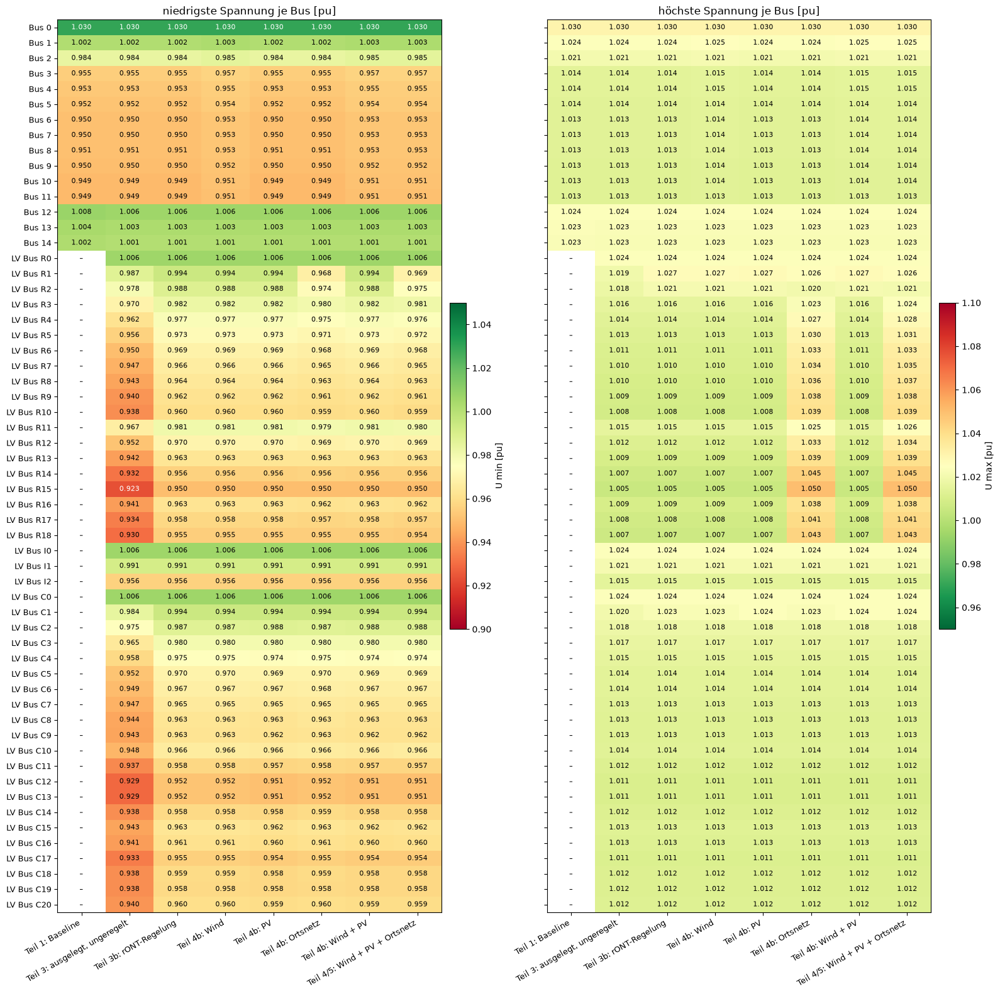

In [216]:
HAUPT = {k: v for k, v in HAUPT.items() if v in haupt}
busse = list(haupt[HAUPT["Teil 4/5: Wind + PV + Ortsnetz"]].results.vm_pu.columns)
umin = pd.DataFrame({k: stat.loc[v]["U min [pu]"] for k, v in HAUPT.items()}).reindex(busse)
umax = pd.DataFrame({k: stat.loc[v]["U max [pu]"] for k, v in HAUPT.items()}).reindex(busse)
fig, axes = plt.subplots(1, 2, figsize=(16, 0.24 * len(busse) + 2), sharey=True)
sz.heatmap(umin, "niedrigste Spannung je Bus [pu]", "U min [pu]", cmap="RdYlGn", vmin=0.90, vmax=1.05, ax=axes[0], fmt="{:.3f}")
sz.heatmap(umax, "höchste Spannung je Bus [pu]", "U max [pu]", cmap="RdYlGn_r", vmin=0.95, vmax=1.10, ax=axes[1], fmt="{:.3f}")
plt.tight_layout()
plt.show()

Spannungswinkel je Bus (größter Betrag über alle Stunden, Bezug: Slack an Bus 0 mit 0°):

In [217]:
wink = pd.DataFrame({k: stat.loc[v][["Winkel min [°]", "Winkel max [°]"]].abs().max(axis=1) for k, v in HAUPT.items()}).reindex(busse)
plots.table(wink.T, decimals=2)

Bus,Bus 0,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5,Bus 6,Bus 7,Bus 8,Bus 9,Bus 10,Bus 11,Bus 12,Bus 13,Bus 14,LV Bus R0,LV Bus R1,LV Bus R2,LV Bus R3,LV Bus R4,LV Bus R5,LV Bus R6,LV Bus R7,LV Bus R8,LV Bus R9,LV Bus R10,LV Bus R11,LV Bus R12,LV Bus R13,LV Bus R14,LV Bus R15,LV Bus R16,LV Bus R17,LV Bus R18,LV Bus I0,LV Bus I1,LV Bus I2,LV Bus C0,LV Bus C1,LV Bus C2,LV Bus C3,LV Bus C4,LV Bus C5,LV Bus C6,LV Bus C7,LV Bus C8,LV Bus C9,LV Bus C10,LV Bus C11,LV Bus C12,LV Bus C13,LV Bus C14,LV Bus C15,LV Bus C16,LV Bus C17,LV Bus C18,LV Bus C19,LV Bus C20
Teil 1: Baseline,0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.44,34.48,34.51,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
"Teil 3: ausgelegt, ungeregelt",0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.59,34.63,34.65,34.59,178.29,178.28,178.26,178.24,178.23,178.22,178.21,178.21,178.20,178.20,178.27,178.27,178.30,178.32,178.35,178.24,178.21,178.22,34.59,178.57,178.66,34.59,178.45,178.42,178.39,178.39,178.38,178.38,178.38,178.38,178.38,178.43,178.45,178.47,178.47,178.46,178.40,178.41,178.43,178.41,178.40,178.39
Teil 3b: rONT-Regelung,0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.59,34.63,34.65,34.59,178.29,178.28,178.26,178.24,178.23,178.22,178.21,178.21,178.20,178.20,178.27,178.27,178.30,178.32,178.35,178.24,178.21,178.22,34.59,178.57,178.66,34.59,178.45,178.42,178.39,178.39,178.38,178.38,178.38,178.38,178.38,178.43,178.45,178.47,178.47,178.46,178.40,178.41,178.43,178.41,178.40,178.39
Teil 4b: Wind,0.00,35.14,36.01,37.42,37.51,37.58,37.66,37.61,37.60,37.63,37.69,37.70,34.59,34.63,34.65,34.59,178.29,178.28,178.26,178.24,178.23,178.22,178.21,178.21,178.20,178.20,178.27,178.27,178.30,178.32,178.35,178.24,178.21,178.22,34.59,178.57,178.66,34.59,178.45,178.42,178.39,178.39,178.38,178.38,178.38,178.38,178.38,178.43,178.45,178.47,178.47,178.46,178.40,178.41,178.43,178.41,178.40,178.39
Teil 4b: PV,0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.59,34.63,34.65,34.59,178.49,178.46,178.43,178.40,178.38,178.36,178.34,178.33,178.32,178.31,178.44,178.45,178.50,178.55,178.59,178.40,178.35,178.35,34.59,179.06,179.18,34.59,178.91,178.87,178.82,178.82,178.81,178.81,178.81,178.80,178.80,178.87,178.90,178.93,178.93,178.91,178.84,178.84,178.87,178.85,178.83,178.81
Teil 4b: Ortsnetz,0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.59,34.63,34.65,34.59,179.96,179.99,179.99,180.00,180.00,179.99,180.00,179.99,180.00,180.00,180.00,180.00,179.99,180.00,180.00,180.00,179.99,179.99,34.59,178.57,178.66,34.59,178.45,178.42,178.39,178.39,178.38,178.38,178.38,178.38,178.38,178.43,178.45,178.47,178.47,178.46,178.40,178.41,178.43,178.41,178.40,178.39
Teil 4b: Wind + PV,0.00,35.14,36.01,37.42,37.51,37.58,37.66,37.61,37.60,37.63,37.69,37.70,34.59,34.63,34.65,34.59,178.49,178.46,178.43,178.40,178.38,178.36,178.34,178.33,178.32,178.31,178.44,178.45,178.50,178.55,178.59,178.40,178.35,178.35,34.59,179.06,179.18,34.59,178.91,178.87,178.82,178.82,178.81,178.81,178.81,178.80,178.80,178.87,178.90,178.93,178.93,178.91,178.84,178.84,178.87,178.85,178.83,178.81
Teil 4/5: Wind + PV + Ortsnetz,0.00,35.14,36.01,37.42,37.51,37.58,37.66,37.61,37.60,37.63,37.69,37.70,34.59,34.63,34.65,34.59,180.00,180.00,180.00,179.98,179.99,180.00,180.00,179.98,179.98,180.00,179.99,179.99,180.00,180.00,179.98,180.00,180.00,180.00,34.59,179.19,179.31,34.59,179.04,179.00,178.96,178.95,178.95,178.94,178.94,178.94,178.94,179.01,179.04,179.07,179.07,179.04,178.97,178.98,179.01,178.99,178.96,178.95


Alle Schalterstellungen: niedrigste und höchste Spannung je Ebene (MS, NS) für jede Zeitreihengruppe in allen acht Schaltzuständen:

In [218]:
zeilen = {}
for titel, prefix in (("Teil 1: Baseline", "w4_baseline_"), ("Teil 3: ungeregelt", "w4_t3_"), ("Teil 3b: geregelt", "w4_t3r_"),
                      ("Teil 4b: Wind", "w4_t4b_wind_"), ("Teil 4b: PV", "w4_t4b_pv_"), ("Teil 4b: Ortsnetz", "w4_t4b_on_"),
                      ("Teil 4b: Wind + PV", "w4_t4b_wp_"), ("Teil 4/5: W + PV + O", "w4_t5_")):
    for k in sz.KEYS:
        n = prefix + k
        if n not in konv.index:
            continue
        st = stat.loc[n]
        for eb in ("MS", "NS"):
            e = st[st["Ebene"] == eb]
            if len(e):
                zeilen[(titel, sz.label(k, kurz=True))] = zeilen.get((titel, sz.label(k, kurz=True)), {}) | {
                    f"U min {eb}": e["U min [pu]"].min(), f"U max {eb}": e["U max [pu]"].max()}
ebenen = pd.DataFrame(zeilen).T
plots.table(ebenen, decimals=3)

**Befund Spannungen an allen Bussen:**

- **Normalbetrieb:** In allen Hauptszenarien und allen acht Schaltzuständen bleiben alle 54 MS- und NS-Busse in jeder Stunde innerhalb der Arbeitsgrenzen. Mit rONT-Regelung liegt die NS-Spannung zwischen 0,950 und 1,050 pu. Die MS-Spannung sinkt bei offenem S1 an Bus 11 bis 0,949 pu (8 Stunden unter dem Planungsband); mit Windpark oder geschlossenem S1 bleibt sie über 0,95 pu.
- **Verletzungen der Arbeitsgrenzen** gibt es nur in Varianten, die bewusst verworfen oder als Grenzfall untersucht wurden: Ortsnetz an Bus 2 bis 11 (Teil 2, bis 0,85 pu), Windpark in den Abgängen (Teil 4a, bis 1,23 pu), PV-Haushalte Variante Zukunft (Teil 4b, bis 1,20 pu), Windpark mit cos φ = 0,95 untererregt (Teil 4b, 0,89999 pu in einer Stunde) und Trafoausfall mit S1 (Teil 5, 0,40 bis 1,25 pu).
- **Winkel:** Im MS-Netz liegen die Winkel zwischen −31° und −38°, weil die Trafos 110/20 kV der CIGRE-Daten eine Phasendrehung von 30° haben (`shift_degree`, Schaltgruppe). Dazu kommt der Lastwinkel: 1 bis 5° an Bus 1, bis 8° am Ende von Abgang 1. Die NS-Busse liegen um rund 150° weiter gedreht (Schaltgruppe der Ortsnetztrafos, Dyn5). Die Änderung durch Last und Einspeisung beträgt nur einige Zehntel bis wenige Grad: Der Windpark verringert die Winkel in Abgang 1 um etwa 0,3°, weil er dort Wirkleistung einspeist.
- **Vollständige Werte:** Die Tabelle `ergebnisse/spannungen_alle_busse.csv` enthält für jede der 141 Zeitreihen und jeden Bus U min, U mittel, U max, die Winkel und die Stunden außerhalb der Bänder.

## 5 Leistungsbilanz und Verluste

Für jede Stunde muss gelten: Bezug aus dem 110-kV-Netz = Last + Speicherladung − Einspeisung + Verluste. Die Abweichung zeigt, ob die Ergebnisse vollständig erfasst sind (Prüfung für die Hauptszenarien, Normalschaltzustand):

In [219]:
def bilanz(s):
    r = s.results
    ok = r.converged.astype(bool)
    last = r.load_p_mw[ok].sum(axis=1)
    sto = r.storage_p_mw[ok].sum(axis=1) if r.storage_p_mw.shape[1] else 0 * last
    erz = r.sgen_p_mw[ok].sum(axis=1)
    verl = r.line_pl_mw[ok].sum(axis=1) + r.trafo_pl_mw[ok].sum(axis=1)
    ext = r.ext_grid_p_mw[ok].sum(axis=1)
    rest = ext - (last + sto - erz + verl)
    return {"Last [MWh]": last.sum(), "Speicher netto [MWh]": sto.sum(), "Einspeisung [MWh]": erz.sum(),
            "Verluste [MWh]": verl.sum(), "Verluste [% der Last]": 100 * verl.sum() / last.sum(),
            "Bezug 110 kV netto [MWh]": ext.sum(), "Rückspeisung 110 kV [MWh]": (-ext).clip(lower=0).sum(),
            "größte Abweichung der Bilanz [kW]": 1000 * rest.abs().max()}

plots.table(pd.DataFrame({k: bilanz(haupt[v]) for k, v in HAUPT.items()}).T, decimals=2)

,Last [MWh],Speicher netto [MWh],Einspeisung [MWh],Verluste [MWh],Verluste [% der Last],Bezug 110 kV netto [MWh],Rückspeisung 110 kV [MWh],größte Abweichung der Bilanz [kW]
Teil 1: Baseline,43721.95,0.00,0.00,140.88,0.32,43862.83,0.00,0.00
"Teil 3: ausgelegt, ungeregelt",44372.58,0.00,0.00,162.98,0.37,44535.56,0.00,0.00
Teil 3b: rONT-Regelung,44372.58,0.00,0.00,162.80,0.37,44535.38,0.00,0.00
Teil 4b: Wind,44372.58,0.00,17370.78,154.88,0.35,27156.69,1471.63,0.00
Teil 4b: PV,44372.58,0.00,2813.71,159.51,0.36,41718.39,0.00,0.00
Teil 4b: Ortsnetz,44372.58,3.66,214.42,161.29,0.36,44323.12,0.00,0.00
Teil 4b: Wind + PV,44372.58,0.00,20184.49,151.60,0.34,24339.70,1566.11,0.00
Teil 4/5: Wind + PV + Ortsnetz,44372.58,3.66,20398.91,150.22,0.34,24127.56,1578.80,0.00


**Befund Leistungsbilanz:** Die Bilanz aus Bezug, Last, Speicher, Einspeisung und Verlusten geht in jeder Stunde auf (Abweichung 0,0 kW); die Ergebnistabellen sind also vollständig. Die Verluste liegen bei 0,32 % der Last ohne Ortsnetz und 0,37 % mit Ortsnetz. Mit Erzeugern sinken sie auf 0,34 %, weil weniger Leistung über die Leitungen transportiert werden muss: Windpark und PV-Anlage speisen an den Sammelschienen ein, und ihr Überschuss fließt nur über die Trafos. Der Windpark erzeugt in den 12 Wochen 17,4 GWh, das sind 39 % der Last; davon fließen 1,5 GWh ins 110-kV-Netz zurück.

## 6 Beobachtung und physikalische Erklärung

Die wichtigsten Beobachtungen aus Teil 1 bis 6 und ihre Erklärung. Grundlage ist der Spannungsfall längs einer Leitung mit Resistanz R und Reaktanz X, die die Wirkleistung P und die Blindleistung Q überträgt [19]:

$$\Delta U \approx \frac{R \cdot P + X \cdot Q}{U}$$

Fließt Leistung zum Verbraucher, sinkt die Spannung entlang der Leitung; kehrt sich der Fluss um (Einspeisung größer als Last), steigt sie. In Kabelnetzen der Mittel- und Niederspannung ist R/X groß, deshalb wirkt dort vor allem die Wirkleistung; Blindleistung wirkt umso stärker, je größer X ist (Freileitungen, Transformatoren).

| Beobachtung (Teil) | physikalische Erklärung |
|---|---|
| Die Spannung sinkt in Abgang 1 ab Bus 3 auf 0,95 pu, Abgang 2 bleibt über 1,00 pu (Teil 1, 2) | Abgang 1 trägt den größten Teil der Last über lange Kabel (Line 1-2, 2-3 mit zusammen 7,2 km). Der Spannungsfall R·P + X·Q wächst mit Leistung und Länge. Abgang 2 ist schwach belastet. |
| Das Ortsnetz verliert bei 0,4 kV prozentual mehr Spannung und Leistung als das MV-Netz (Teil 2) | Für dieselbe Leistung fließt bei 0,4 kV der 50-fache Strom. Die Verluste wachsen mit I², der Spannungsfall mit I·Z. Hinzu kommt der Spannungsfall im Ortsnetztrafo (Kurzschlussspannung). |
| Das Schließen von S1 entlastet Abgang 1 und senkt die Verluste um etwa 21 % (Teil 1, 3) | In der Masche über beide Transformatoren teilt sich der Fluss umgekehrt proportional zu den Impedanzen auf [19, S. 437 f.]. Ein Teil der Last von Abgang 1 wird über Trafo 0-12 und Abgang 2 versorgt, der Strom auf Line 1-2/2-3 sinkt, die Verluste sinken mit I². |
| Der rONT hebt mit einer Stufe alle Busse seines Teilnetzes um etwa 2,5 % an, hat aber keine Wirkung auf das MV-Netz und die anderen Teilnetze (Teil 3b) | Die Stufe ändert die Übersetzung des Trafos: Die Unterspannung wird bei gleicher Oberspannung um 2,5 % verschoben. Die Leistung des Teilnetzes ändert sich dabei kaum, deshalb bleibt der Fluss im MV-Netz fast gleich. |
| Windpark und PV-Anlage überlasten die Abgänge, an den Trafo-Sammelschienen nicht (Teil 4a) | Die Kabel der Abgänge sind für etwa 5 MVA ausgelegt. An der Sammelschiene fließt die Einspeisung direkt über den 110/20-kV-Trafo ab und belastet keine MS-Leitung. |
| Bei starkem Wind fließt Leistung ins 110-kV-Netz zurück; die Trafoauslastung steigt dann wieder (Teil 4, 5) | Die Auslastung hängt vom Betrag des Stroms ab, nicht von der Richtung. Übersteigt die Einspeisung die Last hinter dem Trafo, kehrt sich p_hv_mw um und der Strom wächst mit dem Überschuss. |
| Im Wohngebiet speisen die PV-Haushalte mittags über den Ortsnetztrafo zurück, die Spannung an den Strangenden steigt und der rONT regelt nach unten (Teil 4b, 5) | Mit umgekehrtem Fluss wird R·P negativ: Die Spannung steigt zum Strangende hin. Der Speicher nimmt nur einen Teil des Überschusses auf, weil er nach einigen Stunden voll ist. |
| Blindleistungsbezug der Erzeuger (cos φ = 0,95 untererregt) senkt die Spannung nur wenig (Teil 4b) | Der Beitrag X·Q ist in Kabelnetzen mit großem R/X klein. Die Erzeuger hängen an den Trafo-Sammelschienen, deshalb wirkt Q vor allem über die Reaktanz der Transformatoren. |
| Line 3-8 wird nur durch Einspeisung an Bus 8 zuerst überlastet, nicht durch Last (Teil 6) | Im Strahlennetz trägt jede Leitung die Summe der Leistungen dahinter. Line 2-3 und 1-2 liegen vor Line 3-8 und tragen bei Last immer mehr. Eine Einspeisung an Bus 8 fließt dagegen zuerst über Line 3-8 zurück. |
| Ein stärkeres Kabel auf Line 3-8 verlagert den Engpass auf Line 2-3 (Teil 6) | Die Leistung muss weiter über Line 2-3 und 1-2 zum Umspannwerk fließen. In vermaschten Zuständen zieht die Leitung mit kleinerer Impedanz zusätzlich Leistung an. |

## 7 Annahmen und Daten

| Bereich | Annahme | Quelle bzw. Ort der Begründung |
|---|---|---|
| Netz | CIGRE-MV-Benchmarknetz `with_der=False`, CIGRE-LV-Netz als Ortsnetz an Bus 12 | [13], [14]; Teil 1 und 2 |
| Zeitauflösung | 12 typische Wochen (eine je Monat), Stundenwerte, 2016 Lastflüsse je Zeitreihe | Datengrundlage, Abschnitt 1 |
| Lasten | BDEW-Standardlastprofile H25, G25, L25, skaliert auf die CIGRE-Bemessungsleistung; cos φ der CIGRE-Lasten | [1]; Datengrundlage |
| Ortsnetzprofil aus W2 | nicht verwendet, weil in W2 kein Ortsnetzprofil erstellt wurde; stattdessen Standardlastprofile und PV-Haushalte | – |
| Wetter | Wind- und Strahlungsdaten 2025 (stündlich), dieselben Wochen wie die Lastprofile | Datengrundlage, Abschnitt 1 |
| Windpark | 15 WEA Vestas V90-2.0 MW, zusammen 30 MW, ein Erzeuger mit gemeinsamer Windgeschwindigkeit, cos φ = 1 (Variante 0,95 untererregt in Teil 4b) | Datengrundlage 1.2; Teil 4a; [31] |
| PV-Freifläche | 10 MWp, Einspeiseprofil aus der Globalstrahlung, cos φ = 1 (Variante 0,95 in Teil 4b) | [22]; Teil 4a; [31] |
| PV-Haushalte | 3000 kWh/a je Haushalt, 9 kWp, Speicher 8,3 kWh und 4,9 kW, Wirkungsgrad 0,95 je Richtung; heute 15 % der Haushalte mit PV (6,7 % mit Speicher), Zukunft 50 % (40 %) | [23], [24], [32] bis [38]; Datengrundlage, Abschnitt 1.6 |
| Spannungsband | Arbeitsgrenzen 0,90 … 1,10 pu, Planungsband 0,95 … 1,05 pu | [15]; Teil 3, Abschnitt 1 |
| rONT | Stufenschalter auf der Oberspannungsseite, ±2 Stufen à 2,5 %, Messung im eigenen Teilnetz | [20], [21]; Teil 3b |
| Leitungsgrenzen | `max_i_ka` aus den Standardtypen bzw. Datenblättern | [18], [25], [26]; Teil 2 und 6 |

Das vollständige Quellenverzeichnis steht im Notebook `Task4-Datengrundlage.ipynb`, Abschnitt 3.

## 8 Modellgrenzen

- **Stationär und symmetrisch:** Es werden nur symmetrische AC-Lastflüsse berechnet. Unsymmetrie durch einphasig angeschlossene PV-Anlagen und Lasten im Ortsnetz, Oberschwingungen, Flicker und Kurzschlussströme sind nicht abgebildet.
- **Stundenwerte und Standardprofile:** Kurzzeitige Spitzen einzelner Kunden und schnelle Wolkenzüge mitteln sich heraus. Standardlastprofile beschreiben viele Haushalte im Mittel, nicht den einzelnen Anschluss. Echte Spitzen sind höher, die Spannungsbandverletzungen deshalb eher unterschätzt.
- **Typische Wochen:** 12 Wochen stehen für ein Jahr. Seltene Extremsituationen (Windflaute bei Kälte, Starkwind bei Schwachlast) können fehlen. Absolute Jahreswerte (Energie, Schalthandlungen) sind Hochrechnungen.
- **Regelung idealisiert:** Der Stufenschalter reagiert innerhalb derselben Stunde, ohne Totzeit und ohne Verschleiß. Die Wiederversorgung schaltet sofort und ohne Schutztechnik.
- **Speicher:** Fester Eigenverbrauchsfahrplan ohne Prognose und ohne netzdienliche Steuerung. Der Ladezustand startet in jeder typischen Woche bei 0 %. Alterung und Standby-Verluste sind nicht berücksichtigt.
- **Netzrand:** Das 110-kV-Netz ist ein starres Netz (Slack mit 1,03 pu). Rückwirkungen auf das überlagerte Netz sind nicht abgebildet.
- **Leitungsgrenzen:** Die thermische Grenze ist ein fester Dauerstrom. Kurzzeitige Überlastbarkeit und Witterungsabhängigkeit (Freileitungsmonitoring) sind nicht berücksichtigt.
- **CIGRE-Parameter:** Einige Werte des Benchmarknetzes weichen von realen Betriebsmitteln ab, z. B. der hohe Leitungsbelag X′ der MS-Kabel (Teil 6). Die Ergebnisse gelten für dieses Referenznetz und sind nicht direkt auf reale Netze übertragbar.

<a id="teil-10"></a>

---

# Task 4 – Teil 8 und 9: Leitfragen, Ausblick und Fazit

## Aufgabenstellung

> **8. Leitfragen:** *Unter welchen Bedingungen und an welchen MV- oder LV-Bussen wird das Arbeits-Spannungsband von 0,90 bis 1,10 p.u. verletzt? Kann der regelbare Ortsnetztransformator die Spannungen mit diskreten Stufen zuverlässig begrenzen? – Wann und wo tritt eine Lastflussumkehr auf? Wie verändern sich dabei Spannungen, Betriebsmittelauslastungen und Anforderungen an die Regelung? – Durch welche Parametrierung wird Leitung 3-8 gezielt zuerst zum Engpass? Wie verändert eine begründete Kapazitätserhöhung die Belastung des Gesamtnetzes? – Wie wirken der 15-WEA-Windpark, das Ortsnetz mit fluktuierender Einspeisung und Last sowie die Großflächen-PV-Anlage jeweils einzeln und gemeinsam auf Spannungen, Lastflüsse, Engpässe und Verluste?*

> **9. Ausblick:** *Entwickeln Sie ein konzeptionelles Szenario, in dem die möglichst genaue Kenntnis des Netzzustands genutzt wird, um Speicher, Erzeuger und flexible Lasten so einzusetzen, dass ein Leistungs- und über einen festgelegten Zeitraum ein Energiegleichgewicht im betrachteten Netzgebiet unterstützt wird. […] Ein Regelalgorithmus, eine Optimierung oder ein zusätzlicher Simulationsnachweis wird in diesem Arbeitsauftrag nicht erwartet.*

> **Fazit:** *Fassen Sie im Fazit die wichtigsten Spannungs- und Lastflusseffekte, die Wirkung des Ortsnetztransformators, den Engpass an Line 3-8, die Kapazitätserhöhung und die Grenzen Ihrer Modellierung zusammen.*

| Anforderung | Umsetzung |
|---|---|
| Leitfrage Spannungsband und rONT | Abschnitt 1.1 |
| Leitfrage Lastflussumkehr | Abschnitt 1.2 |
| Leitfrage Line 3-8 | Abschnitt 1.3 |
| Leitfrage Szenarien einzeln und gemeinsam | Abschnitt 1.4 |
| Ausblick: Netzgebiet, Zeitraum, Zustandsgrößen | Abschnitt 2.1 |
| Ausblick: Zusammenwirken von Speicher, Erzeugern und Lasten | Abschnitt 2.2 |
| Ausblick: Leistungs- und Energiebilanz, Speicher, Austausch | Abschnitt 2.3 |
| Ausblick: Ziele, Randbedingungen, Zielkonflikte | Abschnitt 2.4 |
| Ausblick: Messungen, Prognosen, Zustandsschätzung | Abschnitt 2.5 |
| Fazit | Abschnitt 3 |

Die Zahlen in den Tabellen werden direkt aus den gespeicherten Zeitreihen von Teil 3 bis 5 berechnet (keine neuen Simulationen). Verglichen wird immer im **Normalzustand** (S1–S3 offen), damit die Szenarien unter gleichen Randbedingungen stehen. Nur in 1.1 wird zusätzlich die ungünstigste Schalterstellung gezeigt, weil die Frage nach den Bedingungen einer Verletzung fragt. Die Wirkung der Schalterstellungen im Einzelnen steht in Teil 4b, Abschnitt 3, und Teil 5. Voraussetzung: Die Notebooks Teil 1 bis 5 wurden ausgeführt.

## Importe

In [220]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import regelung as rg
import bewertung as bw
import plots
import auswertung as aw
from auswertung import V_MIN, V_MAX, V_PLAN_MIN, V_PLAN_MAX
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Alle Vergleiche im Normalzustand (S1–S3 offen, Schlüssel "000"); nur Abschnitt 1.1 betrachtet zusätzlich
# die ungünstigste Schalterstellung, weil die Frage nach den Bedingungen einer Verletzung fragt.
NORMAL = {"Teil 3: ausgelegt, ungeregelt": "w4_t3_000", "Teil 3b: mit rONT-Regelung": "w4_t3r_000",
          "Teil 4b: Wind": "w4_t4b_wind_000", "Teil 4b: PV": "w4_t4b_pv_000", "Teil 4b: Ortsnetz (PV-Haushalte)": "w4_t4b_on_000",
          "Teil 4b: Wind + PV": "w4_t4b_wp_000", "Teil 4/5: Wind + PV + Ortsnetz": "w4_t5_000"}
SIMS = {g: sim.loadSimulation(n) for g, n in NORMAL.items()}
ONT = {"R": "LV Trafo R0-R1", "I": "LV Trafo I0-I1", "C": "LV Trafo C0-C1"}

## 1 Leitfragen

### 1.1 Spannungsband und regelbarer Ortsnetztransformator

*Unter welchen Bedingungen und an welchen MV- oder LV-Bussen wird das Arbeits-Spannungsband von 0,90 bis 1,10 p.u. verletzt? Kann der regelbare Ortsnetztransformator die Spannungen mit diskreten Stufen zuverlässig begrenzen?*

Verglichen werden drei Stände des Netzes: ausgelegt ohne Regelung (Teil 3), mit rONT-Regelung (Teil 3b) und mit allen Erzeugern (Ende Teil 4). Die erste Tabelle zeigt den **Normalzustand** (S1–S3 offen): Stunden außerhalb des Planungsbands 0,95 … 1,05 pu und der Arbeitsgrenzen 0,90 … 1,10 pu (von 2016 Stunden), getrennt nach MS- und NS-Netz, dazu der Bus mit der niedrigsten bzw. höchsten Spannung.

In [221]:
STAENDE = {"ungeregelt (Teil 3)": "w4_t3_", "mit rONT (Teil 3b)": "w4_t3r_", "mit Erzeugern (Teil 4/5)": "w4_t5_"}

def spannungsband(s):
    """Stunden außerhalb der Bänder, U min/max mit Bus, getrennt nach MS und NS, und rONT-Stufenschritte."""
    import lvnetz
    g = lvnetz.bus_groups(s.net)
    vm = s.results.vm_pu[s.results.converged.astype(bool)]
    z = {}
    for eb in ("MS", "NS"):
        v = vm[g[eb]]
        lo, hi = v.min(axis=1), v.max(axis=1)
        z |= {(eb, "Stunden < 0,95"): int((lo < V_PLAN_MIN).sum()), (eb, "Stunden > 1,05"): int((hi > V_PLAN_MAX).sum()),
              (eb, "Stunden < 0,90"): int((lo < V_MIN).sum()), (eb, "Stunden > 1,10"): int((hi > V_MAX).sum()),
              (eb, "U min [pu]"): f"{v.min().min():.3f} ({v.min().idxmin().replace('LV Bus ', '')})",
              (eb, "U max [pu]"): f"{v.max().max():.3f} ({v.max().idxmax().replace('LV Bus ', '')})"}
    z[("rONT", "Stufenschritte")] = int(rg.schaltvorgaenge(s).filter(like="Stufen").sum())
    return z

alle_stellungen = {st: {k: spannungsband(sim.loadSimulation(p + k)) for k in sz.KEYS} for st, p in STAENDE.items()}
normal = pd.DataFrame({st: d["000"] for st, d in alle_stellungen.items()}).T
normal.columns = pd.MultiIndex.from_tuples(normal.columns)
normal

MS                                                                                         NS                                                            \
                         Stunden < 0,95 Stunden > 1,05 Stunden < 0,90 Stunden > 1,10      U min [pu]     U max [pu] Stunden < 0,95 Stunden > 1,05 Stunden < 0,90 Stunden > 1,10   U min [pu]   
ungeregelt (Teil 3)                   8              0              0              0  0.949 (Bus 11)  1.024 (Bus 1)            450              0              0              0  0.923 (R15)   
mit rONT (Teil 3b)                    8              0              0              0  0.949 (Bus 11)  1.024 (Bus 1)              0              0              0              0  0.950 (R15)   
mit Erzeugern (Teil 4/5)              0              0              0              0  0.951 (Bus 11)  1.025 (Bus 1)              0              0              0              0  0.950 (R15)   

                                                rONT  
                           U max [pu] Stufenschritte  
ungeregelt (Teil 3)        1.021 (I1)              0  
mit rONT (Teil 3b)         1.027 (R1)            192  
mit Erzeugern (Teil 4/5)  1.050 (R15)            258

**Ungünstigste Schalterstellung:** Für jede Kennzahl der größte Wert über alle acht Schalterstellungen und in Klammern, in welcher Stellung er auftritt (Werte im Normalzustand siehe oben):

In [222]:
def ungunst(d, spalte, groesste=True):
    werte = {k: z[spalte] for k, z in d.items()}
    zahl = {k: float(str(v).split()[0]) for k, v in werte.items()}
    if len(set(zahl.values())) == 1:
        return f"{werte['000']} – in allen Stellungen gleich"
    k = max(zahl, key=zahl.get) if groesste else min(zahl, key=zahl.get)
    return f"{werte[k]} – {sz.label(k, kurz=True)}"

KENNZ = [(("MS", "Stunden < 0,95"), True), (("MS", "U min [pu]"), False), (("NS", "Stunden < 0,95"), True),
         (("NS", "U min [pu]"), False), (("NS", "Stunden > 1,05"), True), (("NS", "U max [pu]"), True),
         (("rONT", "Stufenschritte"), True)]
schlecht = pd.DataFrame({st: {" ".join(sp): ungunst(d, sp, gr) for sp, gr in KENNZ} for st, d in alle_stellungen.items()}).T
schlecht

,"MS Stunden < 0,95",MS U min [pu],"NS Stunden < 0,95",NS U min [pu],"NS Stunden > 1,05",NS U max [pu],rONT Stufenschritte
ungeregelt (Teil 3),9 – S2 zu,0.949 (Bus 11) – alle offen,473 – S1 zu,0.921 (R15) – S1 zu,0 – in allen Stellungen gleich,1.021 (I1) – in allen Stellungen gleich,0 – in allen Stellungen gleich
mit rONT (Teil 3b),9 – S2 zu,0.949 (Bus 11) – alle offen,0 – in allen Stellungen gleich,0.950 (R15) – in allen Stellungen gleich,0 – in allen Stellungen gleich,1.039 (R1) – S1 zu,196 – S1 zu
mit Erzeugern (Teil 4/5),0 – in allen Stellungen gleich,0.951 (Bus 11) – alle offen,0 – in allen Stellungen gleich,0.950 (R15) – in allen Stellungen gleich,0 – in allen Stellungen gleich,1.050 (R15) – in allen Stellungen gleich,280 – S1 zu


**Antwort:**

- **Arbeitsgrenzen 0,90 … 1,10 pu:** In allen drei Ständen und allen acht Schalterstellungen bleibt jeder MS- und NS-Bus in jeder Stunde innerhalb der Arbeitsgrenzen (Spalten „< 0,90“ und „> 1,10“ überall 0). Die vollständige Auswertung aller Busse und aller Zeitreihen steht in Teil 7, Abschnitt 4.
- **Planungsband 0,95 … 1,05 pu – wo und wann es eng wird:**
  - **NS-Netz ohne Regelung:** Am Ende des Wohngebiets (Bus R15) liegt die Spannung im Normalzustand in **450 Stunden** unter 0,95 pu, am niedrigsten bei 0,923 pu. Das passiert zur Abendspitze im Winter, wenn die Haushaltslast am größten ist. Mit geschlossenem S1 sind es 473 Stunden (0,921 pu), weil S1 die Spannung an Bus 12 und damit am ganzen Ortsnetz senkt.
  - **MS-Netz:** An Bus 11 am Ende von Abgang 1 liegt die Spannung bei Höchstlast in 8 Stunden knapp unter 0,95 pu (0,949 pu), mit geschlossenem S2 in 9 Stunden. Mit S1 oder S2+S3 verschwinden diese Stunden, weil Abgang 1 dann über die Masche mitversorgt wird. Mit dem Windpark verschwinden sie ebenfalls (0,951 pu).
  - **NS-Netz mit Erzeugern:** Die PV-Haushalte heben die Spannung an Bus R15 bei Rückspeisung bis genau an die obere Grenze 1,050 pu.
- **Verletzungen der Arbeitsgrenzen** gibt es nur in Varianten, die verworfen oder als Grenzfall untersucht wurden (Teil 7, Abschnitt 4): Ortsnetz hinter Line 1-2 (bis 0,85 pu, Teil 2), Windpark in den Abgängen (bis 1,23 pu, Teil 4a), viele PV-Haushalte (Variante Zukunft, bis 1,20 pu, Teil 4b), Windpark mit untererregter Blindleistung (0,90 pu, Teil 4b), Trafoausfall mit Kupplung über S1 (0,40 bis 1,25 pu, Teil 5).
- **Kann der rONT die Spannung zuverlässig begrenzen?** Ja, im betrachteten Bereich:
  - Mit Regelung fällt die Zahl der Stunden unter 0,95 pu im NS-Netz von 450 auf **0**, in jeder Schalterstellung. Die niedrigste NS-Spannung liegt immer bei 0,950 pu.
  - Mit Erzeugern regelt er auch nach unten und hält die höchste NS-Spannung bei 1,050 pu.
  - Dafür braucht er 192 Stufenschritte in 12 Wochen ohne Erzeuger und 258 mit Erzeugern, mit S1 bis 280. Meist reicht eine Stufe.
- **Grenzen des rONT:**
  - Er wirkt nur in seinem eigenen Teilnetz und verschiebt dort alle Busse gleich. Den Spannungsunterschied zwischen Sammelschiene und Strangende kann er nicht verkleinern; mit S1 steigt deshalb die Sammelschiene R1 beim Anheben auf 1,039 pu.
  - Bei großer Rückspeisung (Variante Zukunft, Teil 4b) reicht auch Stufe +2 nicht.
  - Auf das MS-Netz hat er keinen Einfluss.

### 1.2 Lastflussumkehr

*Wann und wo tritt eine Lastflussumkehr auf? Wie verändern sich dabei Spannungen, Betriebsmittelauslastungen und Anforderungen an die Regelung?*

Grundlage ist das Netz am Ende von Teil 4 mit allen Erzeugern (Windpark, PV-Anlage, PV-Haushalte) im Normalzustand. Für jede Stelle, an der sich der Wirkleistungsfluss umkehren kann: Stunden mit umgekehrtem Fluss (Schwelle 1 kW), zurückgespeiste Energie, größte Rückspeiseleistung und der Anteil der Stunden nachts bzw. tagsüber. Die Wirkung der Schalterstellungen steht in Teil 5, Abschnitt 5.

In [223]:
s = SIMS["Teil 4/5: Wind + PV + Ortsnetz"]
r = s.results
ok = r.converged.astype(bool)
STELLEN = {"Netzkuppelstelle 110 kV": r.ext_grid_p_mw[ok].sum(axis=1), "Trafo 0-1 (Abgang 1)": r.trafo_p_mw[ok]["Trafo 0-1"],
           "Trafo 0-12 (Abgang 2)": r.trafo_p_mw[ok]["Trafo 0-12"],
           "Ortsnetztrafo R (Wohngebiet)": r.trafo_p_mw[ok][ONT["R"]], "Ortsnetztrafo I (Industrie)": r.trafo_p_mw[ok][ONT["I"]],
           "Ortsnetztrafo C (Gewerbe)": r.trafo_p_mw[ok][ONT["C"]]}
zeilen = {}
for ort, p in STELLEN.items():
    rueck = p < -0.001
    zeilen[ort] = {"Stunden": int(rueck.sum()), "Energie [MWh]": float((-p[rueck]).sum()),
                   "max. Rückspeisung [MW]": float(max(0.0, -p.min())),
                   "Anteil nachts 22–6 Uhr [%]": float(100 * ((p.index[rueck].hour >= 22) | (p.index[rueck].hour < 6)).mean()) if rueck.any() else np.nan,
                   "Anteil tagsüber 9–17 Uhr [%]": float(100 * ((p.index[rueck].hour >= 9) & (p.index[rueck].hour <= 17)).mean()) if rueck.any() else np.nan}
umk = pd.DataFrame(zeilen).T
plots.table(umk, decimals=2)

,Stunden,Energie [MWh],max. Rückspeisung [MW],Anteil nachts 22–6 Uhr [%],Anteil tagsüber 9–17 Uhr [%]
Netzkuppelstelle 110 kV,266.00,1578.80,16.11,64.66,17.29
Trafo 0-1 (Abgang 1),615.00,5154.07,22.46,47.64,26.34
Trafo 0-12 (Abgang 2),0.00,0.00,0.00,nan,nan
Ortsnetztrafo R (Wohngebiet),390.00,75.83,0.45,0.00,100.00
Ortsnetztrafo I (Industrie),0.00,0.00,0.00,nan,nan
Ortsnetztrafo C (Gewerbe),0.00,0.00,0.00,nan,nan


**Antwort:**

- **Wo:**
  - **Netzkuppelstelle 110 kV** (266 Stunden, bis 16,1 MW) und **Trafo 0-1** (615 Stunden, bis 22,5 MW). Auslöser ist der Windpark an Bus 1: Trafo 0-1 kehrt sich um, sobald der Wind mehr liefert, als Abgang 1 verbraucht; die Netzkuppelstelle, sobald alle Erzeuger zusammen mehr liefern, als das ganze Netz verbraucht.
  - **Ortsnetztrafo R** und alle Leitungen des Wohngebiets (390 Stunden, bis 0,45 MW), ausgelöst durch die PV-Haushalte.
  - **Keine Umkehr** an Trafo 0-12 (die PV-Freiflächenanlage bleibt immer unter der Last), auf den MS-Leitungen im Normalzustand und an den Ortsnetztrafos von Industrie und Gewerbe (keine Erzeuger).
- **Wann:**
  - Die Rückspeisung ins 110-kV-Netz liegt zu 65 % **nachts** (22 bis 6 Uhr): Starkwind trifft dann auf die niedrigste Last.
  - Die Rückspeisung aus dem Wohngebiet liegt zu 100 % **tagsüber** (9 bis 17 Uhr), von März bis September, wenn die Heimspeicher voll sind.
- **Folgen für die Spannung:** Mit der Umkehr steigt die Spannung zum Einspeisepunkt hin, statt zu fallen. Im MS-Netz bleibt das klein (höchstens 1,025 pu), weil die Erzeuger an den Sammelschienen hängen und ihre Leistung nicht durch die Abgänge fließt. Im Wohngebiet speisen die Haushalte mitten im Strang ein, deshalb steigt die Spannung am Strangende bis an 1,05 pu.
- **Folgen für die Auslastung:** Die Auslastung hängt vom Betrag des Stroms ab, nicht von der Richtung. Bei Starkwind ist Trafo 0-1 mit 88,5 % höher ausgelastet als bei Höchstlast ohne Erzeuger (82,7 %). Ortsnetztrafo R steigt durch die Rückspeisung von 67 auf 75 %.
- **Folgen für die Regelung:** Der Wohngebiet-rONT muss jetzt in beide Richtungen regeln: mittags gegen Überspannung, abends gegen Unterspannung (Teil 5, Abschnitt 9). Ein Regler, der nur gegen Unterspannung anhebt, würde nicht mehr reichen. Im MS-Netz gibt es keinen Stufenschalter; die Umkehr verlangt dort vor allem, S1 offen zu lassen, weil sonst der Windstrom durch die Abgänge fließt (Teil 5, Abschnitt 5).

### 1.3 Line 3-8: Engpass und Kapazitätserhöhung

*Durch welche Parametrierung wird Leitung 3-8 gezielt zuerst zum Engpass? Wie verändert eine begründete Kapazitätserhöhung die Belastung des Gesamtnetzes?*

**Antwort (Teil 6):**

- **Parametrierung:** Eine Laststeigerung allein macht Line 3-8 nie zum ersten Engpass, weil die vorgelagerten Kabel Line 1-2 und 2-3 immer die Summe aller Lasten dahinter tragen. Line 3-8 wird erst durch eine **Einspeisung an Bus 8** zum Engpass, weil diese Leistung zuerst über Line 3-8 zurückfließt. Im Referenznetz (`with_der=False`, 60 % Last, alle Schalter offen) erreicht Line 3-8 bei **6,49 MW** Einspeisung an Bus 8 ihre Grenze von 145 A (100 %), während Line 2-3 und 1-2 bei etwa 76 % und alle anderen Leitungen unter 20 % liegen. Die Einspeisung wurde linear gesteigert, die Stromgrenze nicht verändert.
- **Kapazitätserhöhung:** Ein Ersatz durch ein NA2XS2Y 1×70 12/20 kV (oder ein Parallelkabel) hebt die aufnehmbare Leistung um etwa 1,4 MW (+21 %). Größere Querschnitte bringen nichts mehr, weil dann **Line 2-3 und 1-2 zum Engpass werden**. Die Spannungen ändern sich kaum, die Verluste sinken leicht.
- **Wirkung auf das Gesamtnetz:** Der Engpass wird nicht beseitigt, sondern verlagert. In vermaschten Schaltzuständen zieht die stärkere Leitung zusätzlich Leistung an. Für mehr Einspeisung an Bus 8 müsste der ganze Weg bis Bus 1 verstärkt werden (7,2 km statt 1,3 km Kabel), oder die Einspeisung müsste begrenzt bzw. direkt an der Umspannwerks-Sammelschiene angeschlossen werden.

### 1.4 Windpark, Ortsnetz und PV-Anlage einzeln und gemeinsam

*Wie wirken der 15-WEA-Windpark, das Ortsnetz mit fluktuierender Einspeisung und Last sowie die Großflächen-PV-Anlage jeweils einzeln und gemeinsam auf Spannungen, Lastflüsse, Engpässe und Verluste?*

Kennwerte im Normalzustand (S1–S3 offen, 12 Wochen, rONT-Regelung aktiv). Bezug ist das ausgelegte Netz mit rONT-Regelung ohne Erzeuger (Teil 3b). Jedes Szenario wird einzeln zu diesem Netz hinzugefügt, danach alle zusammen. Die zweite Tabelle zeigt die Änderung gegenüber dem Bezug:

In [224]:
auswahl = {"ohne Erzeuger (Teil 3b)": SIMS["Teil 3b: mit rONT-Regelung"]} | {
    g.split(": ")[1]: s for g, s in SIMS.items() if g.startswith("Teil 4")}
werte, orte = bw.kennwerte(auswahl)
spalten = [c for c in ["U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]", "Leitung max MS [%]", "Leitung max NS [%]",
                       "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]", "Verluste [MWh]", "Stunden Rückspeisung 110 kV",
                       "max. Rückspeisung 110 kV [MW]"] if c in werte.columns]
display(plots.table(werte[spalten].astype(float), decimals=3))
delta = werte[spalten].astype(float) - werte[spalten].astype(float).iloc[0]
print("Änderung gegenüber dem Netz ohne Erzeuger:")
plots.table(delta.iloc[1:], decimals=3)

,U min MS [pu],U max MS [pu],U min NS [pu],U max NS [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Verluste [MWh],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
ohne Erzeuger (Teil 3b),0.949,1.024,0.950,1.027,78.638,71.073,82.694,66.838,162.797,0.000,0.000
Wind,0.951,1.025,0.950,1.027,78.491,71.073,88.512,66.838,154.884,233.000,16.100
PV,0.949,1.024,0.950,1.027,78.638,71.073,82.694,66.838,159.514,0.000,0.000
Ortsnetz (PV-Haushalte),0.949,1.024,0.950,1.050,78.638,78.615,82.694,75.449,161.292,0.000,0.000
Wind + PV,0.951,1.025,0.950,1.027,78.491,71.073,88.512,66.838,151.602,263.000,16.100
Wind + PV + Ortsnetz,0.951,1.025,0.950,1.050,78.491,78.498,88.512,75.331,150.223,266.000,16.108


Änderung gegenüber dem Netz ohne Erzeuger:


,U min MS [pu],U max MS [pu],U min NS [pu],U max NS [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Verluste [MWh],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW]
Wind,0.002,0.001,-0.000,0.000,-0.147,-0.000,5.819,-0.000,-7.913,233.000,16.100
PV,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-3.282,0.000,0.000
Ortsnetz (PV-Haushalte),0.000,0.000,-0.000,0.023,-0.000,7.542,-0.000,8.611,-1.505,0.000,0.000
Wind + PV,0.002,0.001,0.000,0.000,-0.147,0.000,5.819,-0.000,-11.195,263.000,16.100
Wind + PV + Ortsnetz,0.002,0.001,-0.000,0.023,-0.147,7.425,5.819,8.493,-12.573,266.000,16.108


**Antwort:**

- **Windpark (Bus 1):** Er ändert vor allem den Austausch mit dem 110-kV-Netz: 233 Stunden Rückspeisung, bis 16,1 MW. Trafo 0-1 wird um 5,8 Prozentpunkte höher ausgelastet (82,7 → 88,5 %), weil bei Starkwind mehr Strom zurückfließt, als bei Höchstlast bezogen wird. Die MS-Spannung steigt nur um 0,2 Prozentpunkte, die Leitungen werden kaum entlastet (−0,1 Prozentpunkte). Die Verluste sinken um 7,9 MWh, weil weniger Leistung von außen durch das Netz transportiert werden muss.
- **PV-Anlage (Bus 12):** Spannungen und Auslastungen ändern sich nicht messbar. Es gibt keine Rückspeisung. Die Verluste sinken um 3,3 MWh.
- **Ortsnetz mit PV-Haushalten:** Es wirkt nur im NS-Netz. Die höchste NS-Spannung steigt um 2,3 Prozentpunkte auf 1,050 pu, die NS-Leitungen um 7,5 und Ortsnetztrafo R um 8,6 Prozentpunkte, alles durch Rückspeisung am Mittag. Im MS-Netz ändert sich nichts. Die Verluste sinken um 1,5 MWh.
- **Engpässe:** Kein Szenario führt einzeln oder gemeinsam zu einer Überlastung. Am nächsten an der Grenze sind Trafo 0-1 (88,5 %) und die MS-Leitungen (78,6 %, unabhängig von den Erzeugern).
- **Gemeinsam:** Die Wirkungen addieren sich fast genau, weil die drei Szenarien an verschiedenen Stellen einspeisen und unterschiedliche Teile des Netzes beeinflussen: der Windpark Trafo 0-1 und die Netzkuppelstelle, die PV-Haushalte das Wohngebiet, die PV-Anlage fast nichts. Die Verluste sinken zusammen um 12,6 MWh (−8 %), etwa die Summe der Einzelwerte (−12,7 MWh). Nur die Rückspeisung ins 110-kV-Netz wächst stärker als die Summe (233 → 263 → 266 Stunden): Tagsüber reicht die PV zusammen mit dem Wind häufiger, um die Last zu übersteigen.
- **Hinweis:** Alle Werte gelten für den Normalzustand. Wie sich die Szenarien mit geschlossenen Trennschaltern verhalten, zeigt Teil 4b, Abschnitt 3. Mit geschlossenem S1 kehrt sich beim Windpark das Bild um: Die Verluste steigen, und die MS-Leitungen werden fast voll ausgelastet.

## 2 Ausblick: Smart-Grid-Anwendung für das Wohngebiet

Das Konzept wird für das Wohngebiet (Teilnetz R des Ortsnetzes) entwickelt, weil dort mit den PV-Haushalten und Heimspeichern alle drei Arten von Flexibilität schon vorhanden sind und die Rückspeisung in Teil 4b und 5 auftritt. Als Datengrundlage dient die Zeitreihe am Ende von Teil 4 (`w4_t5_000`, S1–S3 offen) als idealisierte, vollständige Kenntnis des Netzzustands.

### 2.1 Netzgebiet, Zeitraum und Zustandsgrößen

- **Netzgebiet:** das Wohngebiet am Ortsnetztrafo R (Teilnetz R des CIGRE-LV-Netzes, Bus R0 bis R18) mit den Haushaltslasten, den PV-Anlagen der Haushalte und den Heimspeichern. Die Grenze des Gebiets ist der Ortsnetztrafo R; über ihn wird Leistung mit dem MS-Netz ausgetauscht.
- **Zeitraum:** Leistungsbilanz in jeder Stunde (Auflösung der Simulation); Energiebilanz über einen Tag, weil sich PV-Überschuss am Mittag und Bedarf am Abend und in der Nacht im Tagesrhythmus abwechseln und ein Heimspeicher etwa einen Tag überbrücken kann. Zur Einordnung zusätzlich je typische Woche und über alle 12 Wochen.
- **Relevante Zustandsgrößen:**

| Größe | wofür | in der Simulation |
|---|---|---|
| Spannung an den Strangenden (R11, R15 bis R18) und an der Sammelschiene R1 | Spannungsband 0,95 … 1,05 pu; Überspannung bei Rückspeisung, Unterspannung bei Abendspitze | `vm_pu` |
| Wirkleistung am Ortsnetztrafo R (`p_hv_mw`) | Austausch mit dem MS-Netz, Richtung des Flusses, Auslastung des Trafos | `trafo_p_mw`, `trafo_loading` |
| Auslastung der LV-Kabel (vor allem der ersten Abschnitte R1-R2, R2-R3) | thermische Engpässe | `line_loading` |
| PV-Erzeugung und Verbrauch je Bus | lokaler Überschuss oder Bedarf | `sgen_p_mw`, `load_p_mw` |
| Ladezustand und Leistung der Speicher | verfügbare Flexibilität | `storage_soc_percent`, `storage_p_mw` |
| Netzverluste | Teil der Leistungsbilanz | `line_pl_mw`, `trafo_pl_mw` |
| Stufenstellung des rONT | Reserve der Spannungsregelung | `tap_pos` |

**Heutiger Zustand ohne Koordination:** Leistungsbilanz des Wohngebiets in einer Juniwoche. Der Speicher arbeitet nur für den Eigenverbrauch seines Haushalts (Teil 4b); der Ortsnetztrafo zeigt den Austausch mit dem MS-Netz.

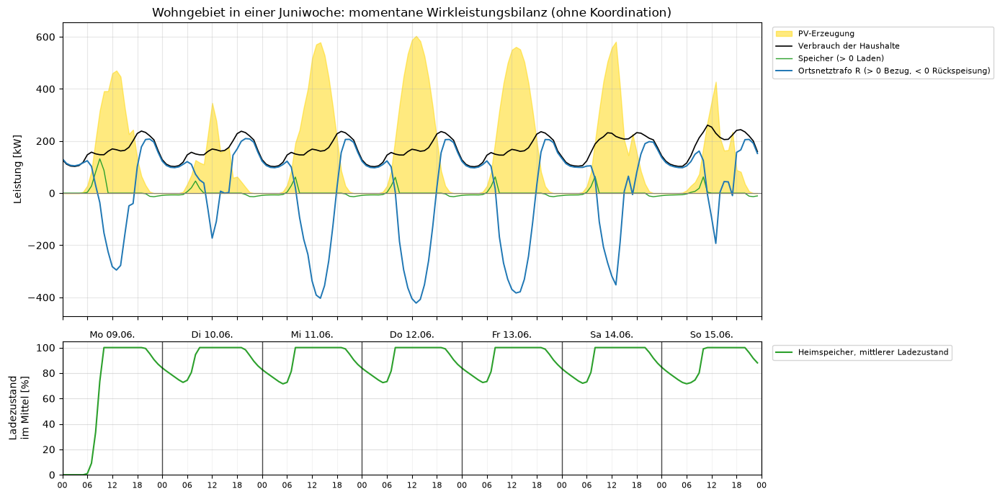

In [225]:
s = SIMS["Teil 4/5: Wind + PV + Ortsnetz"]
r = s.results
def spalten_mit(df, prefix):
    return [c for c in df.columns if c.startswith(prefix)]

def wohngebiet(r):
    ok = r.converged.astype(bool)
    last = r.load_p_mw[ok][spalten_mit(r.load_p_mw, "LV Load R")].sum(axis=1)
    pv = r.sgen_p_mw[ok][spalten_mit(r.sgen_p_mw, "LV PV")].sum(axis=1)
    sto = r.storage_p_mw[ok][spalten_mit(r.storage_p_mw, "LV Speicher R")].sum(axis=1)
    verl = r.line_pl_mw[ok][spalten_mit(r.line_pl_mw, "LV Line R")].sum(axis=1) + r.trafo_pl_mw[ok][ONT["R"]]
    trafo = r.trafo_p_mw[ok][ONT["R"]]
    soc = r.storage_soc_percent[ok][spalten_mit(r.storage_soc_percent, "LV Speicher R")].mean(axis=1)
    return pd.DataFrame({"Last": last, "PV": pv, "Speicher": sto, "Verluste": verl, "Trafo": trafo, "SOC": soc})

wg = wohngebiet(r)
idx = r.info.index[r.info["month"] == "JUNE"]
w = wg.loc[wg.index.intersection(idx)] * [1000, 1000, 1000, 1000, 1000, 1]
x = w.index
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
axes[0].fill_between(x, w["PV"], color="gold", alpha=0.5, label="PV-Erzeugung")
axes[0].plot(x, w["Last"], color="black", lw=1.2, label="Verbrauch der Haushalte")
axes[0].plot(x, w["Speicher"], color="tab:green", lw=1, label="Speicher (> 0 Laden)")
axes[0].plot(x, w["Trafo"], color="tab:blue", lw=1.4, label="Ortsnetztrafo R (> 0 Bezug, < 0 Rückspeisung)")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Leistung [kW]")
axes[0].set_title("Wohngebiet in einer Juniwoche: momentane Wirkleistungsbilanz (ohne Koordination)")
axes[1].plot(x, w["SOC"], color="tab:green", label="Heimspeicher, mittlerer Ladezustand")
axes[1].set_ylabel("Ladezustand\nim Mittel [%]")
axes[1].set_ylim(0, 105)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plots.week_axis(axes[1], w.index)
plt.tight_layout()
plt.show()

**Bilanzprüfung:** Für jede Stunde gilt im Wohngebiet `Trafo = Last + Speicher − PV + Verluste` (Verbraucherzählpfeilsystem). Über einen Zeitraum wird daraus die Energiebilanz; beim Speicher kommen die Wandlungsverluste hinzu (η = 0,95 je Richtung):

In [226]:
rest = wg["Trafo"] - (wg["Last"] + wg["Speicher"] - wg["PV"] + wg["Verluste"])
print(f"größte Abweichung der momentanen Bilanz: {1e3 * rest.abs().max():.3f} kW")

def energiebilanz(df):
    return {"Verbrauch [MWh]": df["Last"].sum(), "PV-Erzeugung [MWh]": df["PV"].sum(),
            "Speicher geladen [MWh]": df["Speicher"].clip(lower=0).sum(), "Speicher entladen [MWh]": -df["Speicher"].clip(upper=0).sum(),
            "Netzverluste Wohngebiet [MWh]": df["Verluste"].sum(),
            "Bezug aus MS-Netz [MWh]": df["Trafo"].clip(lower=0).sum(), "Rückspeisung ins MS-Netz [MWh]": -df["Trafo"].clip(upper=0).sum(),
            "Stunden Rückspeisung": int((df["Trafo"] < -0.001).sum()),
            "Eigenversorgung [%]": 100 * (1 - df["Trafo"].clip(lower=0).sum() / df["Last"].sum())}

monat = r.info.loc[wg.index, "month"]
eb = pd.DataFrame({Month[m].label: energiebilanz(wg[monat == m]) for m in dict.fromkeys(monat)}).T
eb.loc["12 Wochen"] = energiebilanz(wg)
plots.table(eb, decimals=2, int_cols=["Stunden Rückspeisung"])

größte Abweichung der momentanen Bilanz: 0.000 kW


,Verbrauch [MWh],PV-Erzeugung [MWh],Speicher geladen [MWh],Speicher entladen [MWh],Netzverluste Wohngebiet [MWh],Bezug aus MS-Netz [MWh],Rückspeisung ins MS-Netz [MWh],Stunden Rückspeisung,Eigenversorgung [%]
Januar,38.47,4.46,1.21,1.07,0.98,35.13,-0.00,0,8.68
Februar,37.76,10.25,1.70,1.38,0.88,30.12,1.41,10,20.23
März,34.67,26.91,1.48,1.14,0.90,20.43,11.43,51,41.07
April,32.71,28.37,1.21,0.86,0.91,18.52,12.93,54,43.37
Mai,28.70,23.96,0.95,0.60,0.72,15.77,9.96,49,45.06
Juni,28.29,26.56,0.88,0.53,0.73,14.21,11.39,50,49.77
Juli,28.20,22.46,0.93,0.59,0.62,14.65,7.94,50,48.07
August,27.55,25.93,0.98,0.63,0.72,14.18,11.49,57,48.54
September,28.32,17.42,1.16,0.82,0.64,17.97,6.10,36,36.54
Oktober,31.77,11.14,1.46,1.11,0.66,22.88,1.24,14,27.99


**Befund (ohne Koordination):**

- Die momentane Bilanz geht in jeder Stunde auf. Über die 12 Wochen erzeugen die PV-Anlagen 214 MWh, das Wohngebiet verbraucht 390 MWh. Es bezieht 264 MWh aus dem MS-Netz und speist 76 MWh zurück. Nur 32 % des Verbrauchs werden im Gebiet selbst gedeckt.
- Die Speicher laden 15,1 MWh und geben 11,4 MWh ab; die Differenz (3,7 MWh, etwa 24 %) sind Wandlungsverluste und der Ladezustand am Wochenende. Die Speicher werden damit kaum genutzt: 314 kWh Kapazität werden im Mittel nicht einmal einmal am Tag voll durchgeladen.
- **Sommer und Winter unterscheiden sich stark:** Im Juni deckt das Gebiet die Hälfte seines Verbrauchs selbst und speist trotzdem 11 MWh zurück. Im Januar erzeugen die PV-Anlagen nur 12 % des Verbrauchs, und es gibt keine Rückspeisung. Ein Energiegleichgewicht über eine Woche ist im Sommer fast erreicht (Juni: 26,6 MWh PV gegenüber 28,3 MWh Verbrauch), im Winter nicht.
- **Folgerung für die Koordination:** Im Sommer liegt das Problem in der Verteilung über den Tag: mittags zu viel, abends zu wenig. Das lässt sich mit Speichern und verschiebbaren Lasten ausgleichen. Im Winter fehlt Energie; dort kann die Koordination nur die Abendspitze glätten.

### 2.2 Zusammenwirken von Speicher, Erzeugern und flexiblen Lasten

Das Konzept ist eine Koordinationsfunktion beim Netzbetreiber oder einem Energiemanager für das Wohngebiet. Sie bekommt jede Viertelstunde den Netzzustand und gibt den Anlagen Sollwerte vor. Die Reihenfolge der Maßnahmen folgt der Idee, zuerst das zu nutzen, was nichts kostet und keine Energie verschwendet. Abregelung und Eingriffe beim Kunden kommen zuletzt [40], [41]:

1. **Speicher netzdienlich laden.** Heute laden die Heimspeicher morgens, sobald PV-Überschuss da ist, und sind zur Mittagsspitze schon voll (Abbildung oben). Mit Prognose laden sie erst, wenn die Rückspeisung am Ortsnetztrafo eine Schwelle überschreitet, und nehmen so die Spitze auf statt der Morgenstunden. Der Eigenverbrauch des Haushalts bleibt fast gleich, die Rückspeisespitze sinkt.
2. **Flexible Lasten verschieben.** Wärmepumpen (mit Wärmespeicher) und Ladepunkte für Elektroautos verschieben ihren Bezug in die Stunden mit PV-Überschuss. Abends, wenn die Spannung an den Strangenden am niedrigsten ist, beziehen sie weniger. In Deutschland ist dafür § 14a EnWG der Rahmen: Der Netzbetreiber darf steuerbare Verbrauchseinrichtungen bei drohender Überlastung auf eine Mindestleistung dimmen [42].
3. **Speicher entladen in der Abendspitze.** Der Speicher deckt den Abendbedarf und senkt so den Bezug über den Ortsnetztrafo und den Spannungsfall an den Strangenden.
4. **Blindleistung der Wechselrichter.** PV-Wechselrichter können bei hoher Spannung Blindleistung beziehen (cos φ(P)- oder Q(U)-Kennlinie nach VDE-AR-N 4105 [30]). Im Kabelnetz mit großem R/X ist die Wirkung klein (Teil 4b, Abschnitt 5), aber ohne Energieverlust für den Kunden.
5. **rONT.** Der Stufenschalter verschiebt die Spannung des ganzen Teilnetzes und bleibt die Grundregelung (Teil 3b). Die Koordination sorgt dafür, dass er nicht dauernd an der Stellgrenze steht.
6. **Abregelung als letztes Mittel.** Erst wenn Speicher voll und Lasten ausgeschöpft sind und die Spannung trotzdem über 1,05 pu steigt, wird die PV-Einspeisung begrenzt (Spitzenkappung, höchstens 3 % der Jahresenergie nach EnWG § 11 Abs. 2 [39]).

### 2.3 Leistungsbilanz und Energiegleichgewicht

- **Momentane Wirkleistungsbilanz** (jede Stunde): P_Trafo = P_Last + P_Speicher − P_PV + P_Verluste. P_Trafo ist der Austausch mit dem MS-Netz (> 0 Bezug, < 0 Rückspeisung), P_Speicher ist > 0 beim Laden. Die Bilanz geht in der Simulation in jeder Stunde auf (Prüfung oben). Ziel der Koordination ist nicht P_Trafo = 0 in jeder Stunde, sondern ein Austausch innerhalb fester Grenzen (z. B. Trafoauslastung, Rückspeisegrenze).
- **Energiebilanz über den Zeitraum** (Tag, Woche): Σ Bezug − Σ Rückspeisung = Σ Verbrauch + Σ Verluste − Σ PV + Σ Speicherverluste + (Ladezustand am Ende − Ladezustand am Anfang). Ein Energiegleichgewicht im Gebiet heißt: Über den Tag deckt die PV-Erzeugung den Verbrauch einschließlich der Verluste. Dann ist der Nettoaustausch null, auch wenn stundenweise Leistung fließt.
- **Speicher:** Ladezustand zwischen 0 und 100 %, Lade- und Entladeleistung begrenzt (hier 0,59 kW je kWh), Wirkungsgrad 0,95 je Richtung, also etwa 90 % über einen Zyklus. Jede gespeicherte kWh kostet etwa 0,1 kWh Verluste. Ein voller Speicher kann keinen Überschuss mehr aufnehmen, ein leerer keinen Bedarf decken.
- **Wann der Austausch mit dem MS-Netz bleibt:** Im Winter erzeugen die PV-Anlagen viel weniger, als das Wohngebiet verbraucht. Der Bezug lässt sich durch Speicher nur zeitlich verschieben, nicht vermeiden (Tabelle oben). Im Sommer übersteigt die Erzeugung an sonnigen Tagen den Tagesverbrauch, und der Überschuss muss ins MS-Netz fließen, wenn er nicht abgeregelt werden soll. Ein Ausgleich über Wochen oder Jahreszeiten ist mit Heimspeichern nicht möglich.

### 2.4 Ziele, Randbedingungen und Zielkonflikte

| Ziel | Messgröße | Randbedingung |
|---|---|---|
| keine Spannungsbandverletzung | Stunden außerhalb 0,95 … 1,05 pu (Planungsband) an allen Bussen | 0,90 … 1,10 pu darf nie verletzt werden |
| keine thermischen Engpässe | Auslastung Ortsnetztrafo und LV-Kabel | höchstens 100 % |
| begrenzter Austausch mit dem MS-Netz | größte Rückspeisung und größter Bezug am Ortsnetztrafo, Stunden mit Rückspeisung | z. B. Rückspeisung höchstens so groß wie der Bezug zur Abendspitze |
| geringe Abregelung | abgeregelte Energie | höchstens 3 % der Jahresenergie [39] |
| geringe Speicherbeanspruchung | Vollzyklen je Jahr, Zeit bei 100 % Ladezustand | Lebensdauer, Garantiebedingungen |
| Kundennutzen | Eigenverbrauch, Stromkosten | Kunde muss zustimmen (Anreiz, § 14a EnWG [42]) |

**Zielkonflikte:**

- **Eigenverbrauch gegen Netzentlastung:** Der Kunde will den Speicher so früh wie möglich füllen. Das Netz braucht den leeren Speicher zur Mittagsspitze. Bleibt die Sonne aus, ist der Speicher abends nicht voll.
- **Abregelung gegen Speicherverluste:** Eine kWh einzuspeichern kostet etwa 10 % Verluste, eine kWh abzuregeln kostet 100 %. Kurze Spitzen sind deshalb oft günstiger abzuregeln als einen zusätzlichen Speicher zu bauen.
- **Lokales Gleichgewicht gegen Gesamtnetz:** Ein Wohngebiet, das seine Rückspeisung selbst aufnimmt, entlastet sein Ortsnetz. Für das MS-Netz kann dieselbe Energie aber gerade dann nützlich sein, wenn an anderer Stelle Last anliegt. Die Koordination muss über die Ebenen hinweg abgestimmt werden.
- **Speicherbeanspruchung gegen Regelgüte:** Häufiges Umschalten zwischen Laden und Entladen glättet den Austausch, erhöht aber die Zyklenzahl.

### 2.5 Messungen, Prognosen und Zustandsschätzung

Die Simulation kennt Spannung und Fluss an jedem Bus in jeder Stunde. Im realen Ortsnetz ist das nicht so: Gemessen wird oft nur am Ortsnetztrafo, und Hausanschlüsse liefern Zählerstände, aber keine Spannungen in Echtzeit. Für eine Umsetzung wären nötig:

- **Messungen:** Strom und Spannung an der NS-Sammelschiene des Ortsnetztrafos; Spannungsmessung an den Strangenden (wo die Grenzen zuerst erreicht werden, Teil 3b); Messwerte von intelligenten Messsystemen (Smart-Meter-Gateway) der Haushalte mit PV, Speicher, Wärmepumpe oder Ladepunkt.
- **Kommunikation:** Sollwerte an Speicher, Wechselrichter und steuerbare Verbrauchseinrichtungen. Nach § 14a EnWG läuft die Steuerung über das Smart-Meter-Gateway [42].
- **Netzzustandsschätzung:** Aus wenigen Messungen, Netzmodell (Impedanzen aus der Netzdokumentation) und Ersatzwerten (Standardlastprofile, PV-Erzeugung aus Wetterdaten) werden die Spannungen und Flüsse an allen Bussen geschätzt. Genau dafür lassen sich die Lastflussmodelle aus diesem Arbeitsauftrag nutzen.
- **Prognosen:** PV-Erzeugung aus der Wetterprognose und Verbrauch aus Lastprofil und Vortageswerten für die nächsten Stunden. Nur mit Prognose kann ein Speicher bis zur Mittagsspitze leer bleiben.

Die Koordination selbst (Regelalgorithmus, Optimierung) ist nicht Teil dieses Arbeitsauftrags und wird im finalen Arbeitsauftrag als eigene Funktion für das hier aufgebaute Netz ergänzt.

## 3 Fazit

**Spannungs- und Lastflusseffekte:**

- Das CIGRE-MV-Netz ist im Normalbetrieb mit offenen Trennschaltern spannungsstabil: Alle Busse bleiben in allen Szenarien innerhalb von 0,90 … 1,10 pu. Kritisch ist Abgang 1 mit langen Kabeln (U min 0,949 pu an Bus 11 bei Höchstlast) und Trafo 0-1 (bis 88,5 %).
- Das CIGRE-LV-Ortsnetz musste ausgelegt werden (größere Ortsnetztrafos, stärkere Gewerbe-Freileitung) und wurde an Bus 12 angeschlossen, die Sammelschiene mit der größten Reserve (Teil 2, 3).
- Windpark (30 MW) und PV-Anlage (10 MWp) sind nur an den Trafo-Sammelschienen anschließbar. Dort ändern sie die Spannung kaum, kehren aber den Fluss an Trafo 0-1 (615 h) und ins 110-kV-Netz (266 h, bis 16 MW) um. PV-Haushalte kehren den Fluss im Wohngebiet um (390 h) und heben die Spannung dort bis an das Planungsband.
- S1 entlastet ohne Erzeuger Abgang 1 und senkt die Verluste um 21 %. Mit Windpark führt S1 zu Lastflussumkehr auf der Kupplung, bis 99,6 % Leitungsauslastung und höheren Verlusten. S2 und S3 ändern fast nichts.

**Wirkung des Ortsnetztransformators:** Drei unabhängige rONT (±2 × 2,5 %, Messung an den Strangenden) halten das Ortsnetz in allen Schaltzuständen und Szenarien im Planungsband 0,95 … 1,05 pu. Ohne Regelung lag es in 450 Stunden darunter. Mit PV-Haushalten regelt der Wohngebiet-rONT in beide Richtungen. Bei viel mehr PV (Variante Zukunft) reicht der Stellbereich nicht mehr: Trafo und Kabel werden überlastet, die Spannung steigt bis 1,20 pu.

**Engpass an Line 3-8 und Kapazitätserhöhung:** Line 3-8 wird nur durch eine Einspeisung an Bus 8 zum ersten Engpass (6,49 MW bei 60 % Last). Ein stärkeres Kabel erhöht die aufnehmbare Leistung um 21 %, verlagert den Engpass aber auf Line 2-3 und 1-2.

**(n-1):** Leitungsausfälle lassen sich mit genau einem Trennschalter vollständig wiederversorgen, auch mit Erzeugern. Den Ausfall eines 110/20-kV-Trafos kann S1 nicht auffangen.

**Grenzen der Modellierung:** symmetrischer, stationärer Lastfluss in Stundenwerten; 12 typische Wochen statt eines Jahres; Standardlastprofile ohne Spitzen einzelner Kunden; idealisierte Regelung ohne Totzeit; starres 110-kV-Netz; Heimspeicher mit festem Eigenverbrauchsfahrplan; CIGRE-Parameter, die teils von realen Betriebsmitteln abweichen; kein Ortsnetzprofil aus W2 (Teil 7, Abschnitt 8).

**Ausblick:** Die Netzzustandsgrößen aus dieser Arbeit reichen aus, um Speicher, flexible Lasten und Wechselrichter netzdienlich zu koordinieren (Abschnitt 2). Der größte Hebel im Wohngebiet ist, die Heimspeicher erst zur Mittagsspitze zu laden. Das wird im finalen Arbeitsauftrag als eigene Funktion umgesetzt.

<a id="quellen"></a>

---

# Quellenverzeichnis

Zentrales Verzeichnis für alle Notebooks von Task 4. Die Notebooks verwenden dieselben Nummern und führen am Ende jeweils die von ihnen zitierten Quellen auf.

**Lastprofile und Verbrauch**

[1] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Hinweise zu den aktualisierten Standardlastprofilen Strom“, Anwendungshilfe, Berlin, 17.03.2025. Online: https://bdew.de/media/documents/2025-03-17_AWH_Aktualisierte_SLP_Strom_2025_Ver%C3%B6ffentlichung.pdf

[2] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Repräsentative Profile BDEW H25, G25, L25, P25, S25 – Veröffentlichung“, Datensatz (CSV), Berlin, 2025.

[3] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Anwendung der Repräsentativen VDEW-Lastprofile step-by-step“, Berlin, 2000, S. 18 f. Online: https://www.bdew.de/media/documents/2000131_Anwendung-repraesentativen_Lastprofile-Step-by-step.pdf

[32] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Stromverbrauch vergleichen und Sparpotenzial nutzen“, Presseinformation, 21.04.2016. Online: https://www.bdew.de/presse/presseinformationen/stromverbrauch-vergleichen-und-sparpotenzial-nutzen/

**Wetter, Wind- und PV-Anlagen**

[4] P. Zippenfenig, „Open-Meteo.com Weather API“, Zenodo, 2023, doi: 10.5281/ZENODO.7970649.

[5] H. Hersbach et al., „The ERA5 global reanalysis“, Quarterly Journal of the Royal Meteorological Society, Bd. 146, Nr. 730, S. 1999–2049, 2020, doi: 10.1002/qj.3803.

[6] Open-Meteo, „Historical Weather API – Documentation“. Online: https://open-meteo.com/en/docs/historical-weather-api (Abruf: 14.10.2026).

[7] wind-turbine-models.com, „Vestas V90“. Online: https://www.wind-turbine-models.com/turbines/16-vestas-v90 (Abruf: 14.10.2026).

[8] windpowerlib, Version 0.2.2, Turbinendatenbank der Open Energy Database (Datei `oedb/power_curves.csv`, Eintrag „V90/2000“). Online: https://github.com/wind-python/windpowerlib

[9] E. Hau, *Windkraftanlagen: Grundlagen, Technik, Einsatz, Wirtschaftlichkeit*, 6. Aufl. Berlin, Heidelberg: Springer Vieweg, 2016.

[10] Trina Solar, „Vertex S+ NEG9RC.27“, Produktseite. Online: https://www.trinasolar.com/de/NEG9RC.27/ (Abruf: 14.10.2026).

[11] Trina Solar, „Vertex S+ – Bifaziales Doppelglas N-Typ i-TOPCon Modul, TSM-NEG9RC.27“, Datenblatt, Version TSM_DE_2024_B, 2024. Online: https://www-cdn.trinasolar.com/wwwstorage/sites/8/250227_Datasheet_VertexS_NEG9RC.27_DE_2024_B_web.pdf

[12] J. A. Duffie und W. A. Beckman, *Solar Engineering of Thermal Processes*, 4. Aufl. Hoboken, NJ: Wiley, 2013.

[22] C. Kost et al., „Stromgestehungskosten Erneuerbare Energien“, Fraunhofer ISE, Freiburg, Juni 2021, Tabelle 3, S. 14. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/DE2021_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf

[24] Fraunhofer ISE, „Photovoltaics Report“, Freiburg. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/Photovoltaics-Report.pdf

**Haushalte mit PV und Speicher**

[23] KfW Research, „Fast 13 Millionen Haushalte nutzen Energiewendetechnologien“, Pressemitteilung, 12.09.2024 (KfW-Energiewendebarometer). Online: https://www.kfw.de/%C3%9Cber-die-KfW/Newsroom/Aktuelles/Pressemitteilungen-Details_821696.html

[33] RWTH Aachen, Institut für Stromrichtertechnik und Elektrische Antriebe (ISEA), „Battery Charts“, Auswertung des Marktstammdatenregisters, Methodik. Online: https://battery-charts.de/de/battery-charts-de/; Quartalswerte Q1 2026 nach pv magazine, 08.05.2026. Online: https://www.pv-magazine.de/2026/05/08/starkes-wachstum-im-grossspeichermarkt-fuehrt-zu-batterie-rekordzubau-von-ueber-2-gigawattstunden-im-1-quartal-2026/

[34] Meissner et al. (HTW Berlin), „Feldmessdaten von 110 PV-Speichersystemen“, 2024. Online: https://solar.htw-berlin.de/wp-content/uploads/MEISSNER-2024-Feldmessdaten-von-110-PV-Speichersystemen.pdf

[35] HTW Berlin, „Stromspeicher-Inspektion 2025“, Berlin, 2025. Online: https://solar.htw-berlin.de/wp-content/uploads/HTW-Stromspeicher-Inspektion-2025.pdf; Zusammenfassung: Solarserver, 07.02.2025. Online: https://www.solarserver.de/2025/02/07/stromspeicher-inspektion-2025-neue-wirkungsgradrekorde-von-kostal-und-sax-power/

[36] Fraunhofer ISE, Presseinformation zur Kurzstudie über den Zuwachs von Batteriespeichern und Balkon-PV in Deutschland, Freiburg, 2024. Online: https://www.ise.fraunhofer.de/de/presse-und-medien/presseinformationen/2024/kurzstudie-zuwachs-von-batteriespeichern-und-balkon-pv-in-deutschland.html

[37] RWTH Aachen und LUBW, „Speichermonitoring BW 2.0“, Karlsruhe. Online: https://pudi.lubw.de/detailseite/-/publication/10501-Speichermonitoring_BW_2.0.pdf

**Netzmodelle und Software**

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[14] L. Thurner et al., „pandapower – An Open-Source Python Tool for Convenient Modeling, Analysis, and Optimization of Electric Power Systems“, IEEE Transactions on Power Systems, Bd. 33, Nr. 6, S. 6510–6521, Nov. 2018, doi: 10.1109/TPWRS.2018.2829021.

[17] pandapower, „Datastructure and Elements“, Dokumentation der Elemente und Ergebnistabellen (res_bus, res_line, res_trafo, res_ext_grid, res_storage). Online: https://pandapower.readthedocs.io/en/latest/elements.html

[18] *Smart Energy Management for Smart Grid*, Basel: MDPI Books, Tabelle der Leitungstypen des CIGRE-LV-Netzes (Querschnitt, R und L von Phasen- und Neutralleiter, Bemessungsstrom). Online: https://mdpi-res.com/bookfiles/book/7980/Smart_Energy_Management_for_Smart_Grid.pdf

[25] pandapower, „Standard Type Libraries“ und `create_cigre_network_mv`, Dokumentation, Version 3.x. Online: https://pandapower.readthedocs.io

**Normen, Regelwerke und Gesetze**

[15] DIN EN 50160, „Merkmale der Spannung in öffentlichen Elektrizitätsversorgungsnetzen“ (EN 50160:2010 mit Änderungen), Berlin: Beuth.

[26] Zuhmann, „Mittelspannungskabel NA2XS2Y nach VDE 0276-620“, Datenblatt (Ausgabe 13.07.2016). Online: https://www.zuhmann.info/media/daten/019.pdf

[27] DIN VDE 0276-620 (VDE 0276-620), „Starkstromkabel – Energieverteilungskabel mit extrudierter Isolierung für Nennspannungen von 3,6/6 (7,2) kV bis einschließlich 20,8/36 (42) kV“, Berlin: VDE Verlag.

[28] DIN VDE 0276-1000 (VDE 0276-1000), „Starkstromkabel – Strombelastbarkeit, Allgemeines, Umrechnungsfaktoren“, Berlin: VDE Verlag.

[29] DIN IEC 60076-7 (VDE 0532-76-7), „Leistungstransformatoren – Teil 7: Belastungsrichtlinie für ölgefüllte Leistungstransformatoren“, Berlin: VDE Verlag.

[30] VDE-AR-N 4105, „Erzeugungsanlagen am Niederspannungsnetz – Technische Mindestanforderungen für Anschluss und Parallelbetrieb von Erzeugungsanlagen am Niederspannungsnetz“, Berlin: VDE Verlag, 2018.

[31] VDE-AR-N 4110, „Technische Regeln für den Anschluss von Kundenanlagen an das Mittelspannungsnetz und deren Betrieb (TAR Mittelspannung)“, Berlin: VDE Verlag, 2023.

[39] Gesetz über die Elektrizitäts- und Gasversorgung (Energiewirtschaftsgesetz – EnWG), § 11 Abs. 2 (Spitzenkappung). Online: https://www.gesetze-im-internet.de/enwg_2005/__11.html

[42] Gesetz über die Elektrizitäts- und Gasversorgung (Energiewirtschaftsgesetz – EnWG), § 14a (netzorientierte Steuerung von steuerbaren Verbrauchseinrichtungen und steuerbaren Netzanschlüssen). Online: https://www.gesetze-im-internet.de/enwg_2005/__14a.html

**Lehrbücher**

[16] K. Heuck, K.-D. Dettmann und D. Schulz, *Elektrische Energieversorgung: Erzeugung, Übertragung und Verteilung elektrischer Energie für Studium und Praxis*, 9. Aufl. Wiesbaden: Springer Vieweg, 2013.

[19] A. J. Schwab, *Elektroenergiesysteme: Erzeugung, Transport, Übertragung und Verteilung elektrischer Energie*, 3. Aufl. Berlin, Heidelberg: Springer, 2012, doi: 10.1007/978-3-642-21958-0.

**Betriebsmittel**

[20] Maschinenfabrik Reinhausen, „Regelbarer Ortsnetztransformator“, Vortrag, Lehrstuhl für Elektrische Energiesysteme, FAU Erlangen-Nürnberg. Online: https://www.ees.tf.fau.de/files/2017/12/MR_Regelbarer_Ortsnetztrafo.pdf

[21] Maschinenfabrik Reinhausen, „ECOTAP VPD (24 kV)“, Produktinformation. Online: https://www.reinhausen.com/fileadmin/downloadcenter/products/oltc/ecotap_vpd/flyer/ecotap_vpd_24kv_de.pdf

[38] HTW Berlin, „Stromspeicher-Inspektion 2021“, Berlin, 2021. Online: https://solar.htw-berlin.de/wp-content/uploads/HTW-Stromspeicher-Inspektion-2021.pdf

**Aktive Verteilnetze und Smart Grid**

[40] V. Ilea, C. Bovo, D. Falabretti, M. Merlo, C. Arrigoni, R. Bonera und M. Rodolfi, „Voltage Control Methodologies in Active Distribution Networks“, *Energies*, Bd. 13, Nr. 12, Art. 3293, 2020, doi: 10.3390/en13123293.

[41] S. Huang, Q. Wu, Z. Liu und A. H. Nielsen, „Review of Congestion Management Methods for Distribution Networks with High Penetration of Distributed Energy Resources“, in *Proc. IEEE PES ISGT Europe*, Istanbul, 2014, S. 1–6, doi: 10.1109/ISGTEurope.2014.7028811.
